## 題號 1
**問題**: 周天成使用「殺球」得分佔他總得分的百分比是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


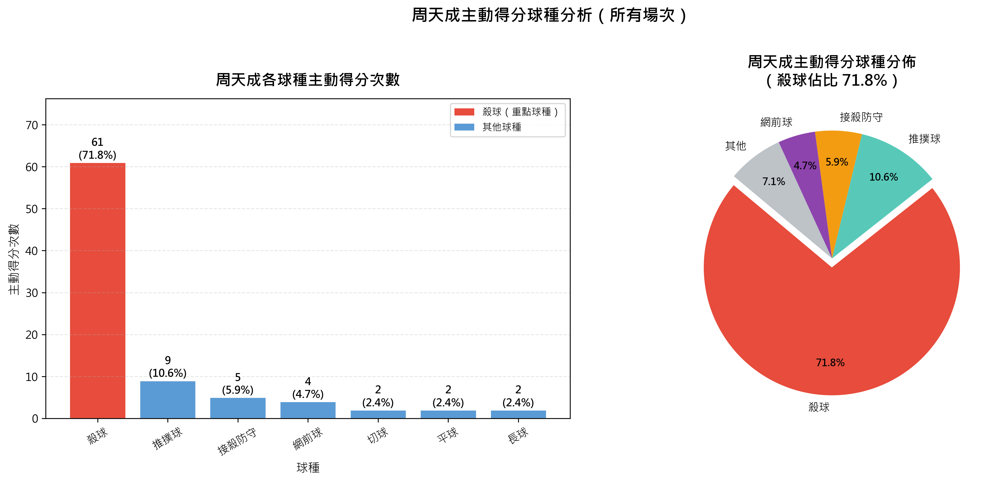

In [ ]:
# =============================================
# 周天成殺球得分佔總得分百分比分析
# =============================================

player_name = 'CHOU Tien Chen'

# 驗證數據量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# -----------------------------------------------
# 1. 找出每回合最後一球（得分球）
#    getpoint_player 只有最後一球才有記錄，直接 dropna
# -----------------------------------------------
df_last_shot = df.dropna(subset=['getpoint_player']).copy()
print(f"有效得分球總數（各回合最後一球）: {len(df_last_shot)}")

# -----------------------------------------------
# 2. 計算分母：周天成「主動得分」總次數
#    條件：player == CHOU Tien Chen AND getpoint_player == CHOU Tien Chen
# -----------------------------------------------
chou_active_win = df_last_shot[
    (df_last_shot['player'] == player_name) &
    (df_last_shot['getpoint_player'] == player_name)
]
total_active_wins = len(chou_active_win)
print(f"\n周天成主動得分（Active Win）總次數: {total_active_wins}")

# -----------------------------------------------
# 3. 計算分子：周天成以「殺球」主動得分的次數
#    條件：player == CHOU Tien Chen AND type == 殺球 AND getpoint_player == CHOU Tien Chen
# -----------------------------------------------
chou_smash_win = chou_active_win[
    chou_active_win['type'] == '殺球'
]
smash_active_wins = len(chou_smash_win)
print(f"周天成殺球主動得分次數: {smash_active_wins}")

# -----------------------------------------------
# 4. 計算百分比
# -----------------------------------------------
if total_active_wins > 0:
    pct = smash_active_wins / total_active_wins * 100
    print(f"\n{'='*50}")
    print(f"殺球得分佔總主動得分百分比: {smash_active_wins} / {total_active_wins} = {pct:.2f}%")
    print(f"{'='*50}")
else:
    print("⚠️ 周天成主動得分次數為 0，無法計算佔比！")
    pct = 0

# -----------------------------------------------
# 5. 補充：各球種主動得分分佈（讓結果更完整）
# -----------------------------------------------
shot_win_dist = (
    chou_active_win.groupby('type')
    .size()
    .reset_index(name='得分次數')
    .sort_values('得分次數', ascending=False)
)
shot_win_dist['佔比(%)'] = (shot_win_dist['得分次數'] / total_active_wins * 100).round(2)
print(f"\n周天成各球種主動得分分佈：")
print(shot_win_dist.to_string(index=False))

# -----------------------------------------------
# 6. 視覺化：長條圖呈現各球種得分佔比
# -----------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- 左圖：各球種主動得分次數長條圖 ---
ax1 = axes[0]
colors = ['#E74C3C' if t == '殺球' else '#5B9BD5' for t in shot_win_dist['type']]
bars = ax1.bar(shot_win_dist['type'], shot_win_dist['得分次數'], color=colors, edgecolor='white', linewidth=0.8)

# 在每個長條上標示數值
for bar, cnt, p in zip(bars, shot_win_dist['得分次數'], shot_win_dist['佔比(%)']):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.3,
             f'{cnt}\n({p:.1f}%)',
             ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax1.set_title('周天成各球種主動得分次數', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel('球種', fontsize=11)
ax1.set_ylabel('主動得分次數', fontsize=11)
ax1.set_ylim(0, shot_win_dist['得分次數'].max() * 1.25)
ax1.tick_params(axis='x', rotation=30)

# 加入圖例說明
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#E74C3C', label='殺球（重點球種）'),
                   Patch(facecolor='#5B9BD5', label='其他球種')]
ax1.legend(handles=legend_elements, loc='upper right', fontsize=9)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# --- 右圖：圓餅圖 —— 殺球 vs 其他 ---
ax2 = axes[1]

# 合併小比例類別
threshold = 3  # 次數 < 3 者合併為「其他」
major = shot_win_dist[shot_win_dist['得分次數'] >= threshold].copy()
minor_sum = shot_win_dist[shot_win_dist['得分次數'] < threshold]['得分次數'].sum()

if minor_sum > 0:
    minor_row = pd.DataFrame({'type': ['其他'], '得分次數': [minor_sum],
                               '佔比(%)': [round(minor_sum / total_active_wins * 100, 2)]})
    pie_data = pd.concat([major, minor_row], ignore_index=True)
else:
    pie_data = major.copy()

pie_colors = []
color_palette = ['#E74C3C', '#5B9BD5', '#58C9B9', '#F39C12', '#8E44AD',
                 '#27AE60', '#E67E22', '#2980B9', '#95A5A6', '#C0392B']
smash_idx = pie_data[pie_data['type'] == '殺球'].index.tolist()
for i, t in enumerate(pie_data['type']):
    if t == '殺球':
        pie_colors.append('#E74C3C')
    elif t == '其他':
        pie_colors.append('#BDC3C7')
    else:
        idx = i % len(color_palette[1:])
        pie_colors.append(color_palette[1:][idx])

explode = [0.07 if t == '殺球' else 0 for t in pie_data['type']]

wedges, texts, autotexts = ax2.pie(
    pie_data['得分次數'],
    labels=pie_data['type'],
    autopct='%1.1f%%',
    colors=pie_colors,
    explode=explode,
    startangle=140,
    pctdistance=0.75,
    textprops={'fontsize': 10}
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_fontweight('bold')

ax2.set_title(f'周天成主動得分球種分佈\n（殺球佔比 {pct:.1f}%）', fontsize=14, fontweight='bold', pad=12)

plt.suptitle('周天成主動得分球種分析（所有場次）', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()


### 數據洞察
# 周天成殺球得分分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 總主動得分次數 | 85 次 |
| 殺球主動得分次數 | 61 次 |
| **殺球得分佔比** | **71.76%** |

---

## 戰術洞察

**殺球是周天成最主要的得分武器**，每10分主動得分中，超過7分來自殺球，這說明他的進攻體系高度依賴下壓殺球終結球局。

次要得分手段為**推撲球（10.6%）**，顯示他在網前快速下壓也具備一定威脅，但與殺球差距懸殊。

**對手備戰重點明確**：若要壓制周天成，優先強化接殺能力與後場防守穩定性，減少讓他起跳殺球的機會，是最直接有效的應對策略。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選出周天成的主動得分，並計算了使用殺球得分的次數和總主動得分次數，然後計算了殺球得分佔總主動得分的百分比。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 2 一致。




## 題號 2
**問題**: 周天成最常使用哪個球種直接得分
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


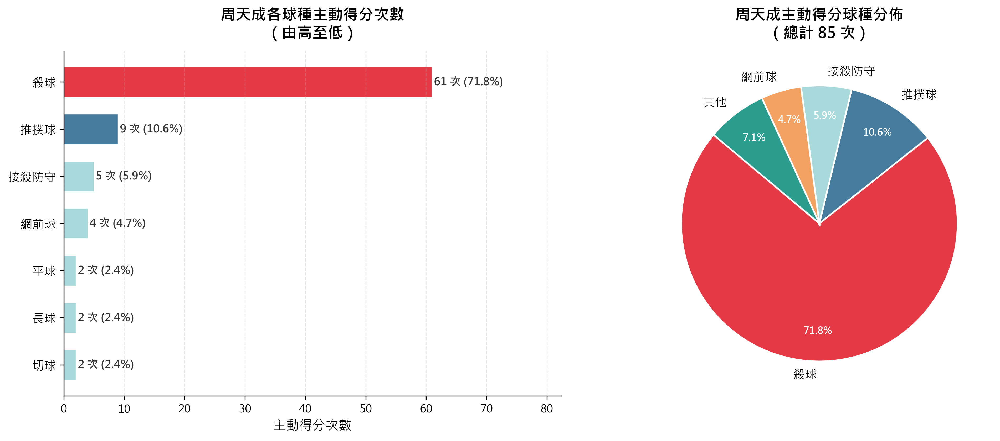

In [ ]:
import numpy as np

# ============================================================
# 驗證數據量
# ============================================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空，請確認數據載入正確"

# ============================================================
# 篩選：周天成主動得分球
# 條件：
#   1. player == 'CHOU Tien Chen'  → 擊球者為周天成
#   2. getpoint_player == 'CHOU Tien Chen'  → 得分者為周天成（Active Win）
# ============================================================
player_name = 'CHOU Tien Chen'

active_win_mask = (
    (df['player'] == player_name) &
    (df['getpoint_player'] == player_name)
)

chou_active_wins = df[active_win_mask].copy()

print(f"\n周天成主動得分總次數: {len(chou_active_wins)}")
print(f"涵蓋場次: {sorted(chou_active_wins['match_id'].unique())}")

# ============================================================
# 統計各球種得分次數
# ============================================================
shot_win_counts = (
    chou_active_wins['type']
    .value_counts()
    .reset_index()
)
shot_win_counts.columns = ['球種', '主動得分次數']
shot_win_counts = shot_win_counts.sort_values('主動得分次數', ascending=False).reset_index(drop=True)
shot_win_counts.index += 1  # 從 1 開始排名

# 計算佔比
total_active_wins = shot_win_counts['主動得分次數'].sum()
shot_win_counts['佔比 (%)'] = (shot_win_counts['主動得分次數'] / total_active_wins * 100).round(1)

print("\n========================================")
print("  周天成各球種主動得分次數（由高至低）")
print("========================================")
print(f"{'排名':<5} {'球種':<10} {'主動得分次數':>12} {'佔比 (%)':>10}")
print("-" * 42)
for rank, row in shot_win_counts.iterrows():
    print(f"{rank:<5} {row['球種']:<12} {int(row['主動得分次數']):>10} {row['佔比 (%)']:>9.1f}%")
print("-" * 42)
print(f"{'合計':<5} {'':<12} {total_active_wins:>10} {'100.0':>9}%")

# ============================================================
# 視覺化：水平長條圖（由高至低，最直觀）
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── 圖1：水平長條圖 ──────────────────────────────────────────
ax1 = axes[0]

# 顏色：最高分用強調色，其餘漸層
colors = ['#E63946' if i == 0 else '#457B9D' if i == 1 else '#A8DADC'
          for i in range(len(shot_win_counts))]
# 反轉順序讓最高分在頂部
plot_df = shot_win_counts.iloc[::-1].reset_index(drop=True)
bar_colors = colors[::-1]

bars = ax1.barh(
    plot_df['球種'],
    plot_df['主動得分次數'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.8,
    height=0.65
)

# 在長條右側標示數值與百分比
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    count = int(row['主動得分次數'])
    pct = row['佔比 (%)']
    ax1.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{count} 次 ({pct}%)',
        va='center', ha='left',
        fontsize=10, fontweight='bold', color='#333333'
    )

ax1.set_xlabel('主動得分次數', fontsize=12)
ax1.set_title('周天成各球種主動得分次數\n（由高至低）', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlim(0, plot_df['主動得分次數'].max() * 1.35)
ax1.axvline(x=0, color='black', linewidth=0.8)
ax1.grid(axis='x', alpha=0.3, linestyle='--')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(axis='y', labelsize=11)

# ── 圖2：圓餅圖 ──────────────────────────────────────────────
ax2 = axes[1]

# 合併小比例類別（< 3%）為「其他」
threshold = 3.0
major = shot_win_counts[shot_win_counts['佔比 (%)'] >= threshold].copy()
minor = shot_win_counts[shot_win_counts['佔比 (%)'] < threshold]

if len(minor) > 0:
    other_row = {
        '球種': '其他',
        '主動得分次數': minor['主動得分次數'].sum(),
        '佔比 (%)': minor['佔比 (%)'].sum().round(1)
    }
    pie_df = pd.concat([major, pd.DataFrame([other_row])], ignore_index=True)
else:
    pie_df = major.copy()

pie_colors = [
    '#E63946', '#457B9D', '#A8DADC', '#F4A261',
    '#2A9D8F', '#E9C46A', '#264653', '#CCCCCC'
][:len(pie_df)]

wedges, texts, autotexts = ax2.pie(
    pie_df['主動得分次數'],
    labels=pie_df['球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=140,
    pctdistance=0.78,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

for text in texts:
    text.set_fontsize(11)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

ax2.set_title(f'周天成主動得分球種分佈\n（總計 {total_active_wins} 次）',
              fontsize=14, fontweight='bold', pad=12)

plt.tight_layout(pad=2.0)
print("\n✅ 圖表已生成")


### 數據洞察
# 周天成主動得分球種分析

## 📊 數據結果

| 排名 | 球種 | 得分次數 | 佔比 |
|:---:|:---|:---:|:---:|
| 1 | 殺球 | 61 | 71.8% |
| 2 | 推撲球 | 9 | 10.6% |
| 3 | 接殺防守 | 5 | 5.9% |
| 4 | 網前球 | 4 | 4.7% |
| 5 | 平球 | 2 | 2.4% |
| 6 | 長球 | 2 | 2.4% |
| 7 | 切球 | 2 | 2.4% |
| **合計** | | **85** | **100%** |

---

## 🎯 戰術洞察

**殺球是周天成最核心的直接得分武器**，85次主動得分中有61次來自殺球，佔比高達71.8%，遠超其他球種。

**關鍵解讀：**

- **殺球主導性極強**：超過7成的直接得分靠殺球完成，代表他的進攻節奏高度依賴後場下壓，對手必須優先強化接殺能力。

- **推撲球是第二威脅**：9次（10.6%）顯示他在網前或平抽時也具備直接得分能力，不只是後場選手。

- **接殺防守得分5次**：這點值得注意——對手殺球後他能反手得分，說明他的防守反擊具有一定殺傷力。

**對手備戰重點：減少讓周天成起跳殺球的機會，是壓制其得分的最直接手段。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成作為擊球者且得分者的情況，並統計各球種的得分次數。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 1 一致。候選程式碼還進一步提供了視覺化，這是額外的功能，不影響判定。




## 題號 3
**問題**: 針對周天成所有「殺球」，繪製其落點熱區圖。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates`


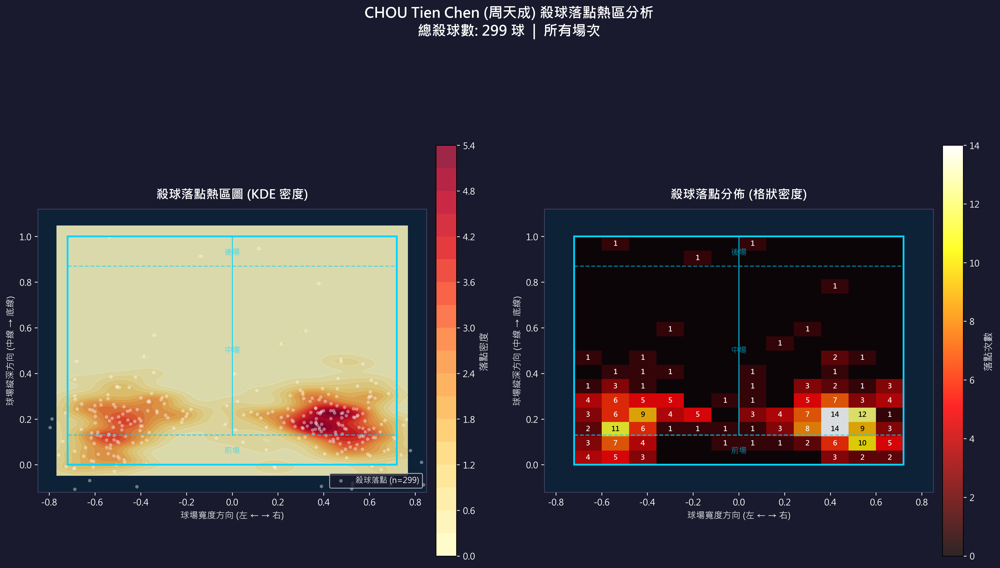

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib.patches as patches

# ════════════════════════════════════════════════════════════
# 周天成殺球落點熱區圖
# ════════════════════════════════════════════════════════════

# ── 1. 資料驗證與篩選 ────────────────────────────────────────
assert len(df) > 0, "DataFrame 為空！"

mask_smash = (df['player'] == 'CHOU Tien Chen') & (df['type'] == '殺球')
smash_df = df[mask_smash].dropna(subset=['landing_x', 'landing_y']).copy()

print(f"周天成殺球總數（有效落點）: {len(smash_df)}")

if len(smash_df) == 0:
    print("無殺球資料，請檢查篩選條件。")
else:
    lx = smash_df['landing_x'].values
    ly = smash_df['landing_y'].values

    # ── 2. 落點區域分類統計 ──────────────────────────────────
    def classify_area(area):
        a = int(area)
        if 17 <= a <= 24:
            return '前場'
        elif 5 <= a <= 16:
            return '中場'
        elif 1 <= a <= 4:
            return '後場'
        elif a >= 25:
            return '出界/邊線'
        else:
            return '其他'

    smash_df['area_category'] = smash_df['landing_area'].apply(
        lambda x: classify_area(x) if not np.isnan(x) else '未知'
    )
    area_counts = smash_df['area_category'].value_counts()

    print("\n落點區域分佈：")
    for area, cnt in area_counts.items():
        pct = cnt / len(smash_df) * 100
        print(f"  {area}: {cnt} 球 ({pct:.1f}%)")

    left_count   = (smash_df['landing_x'] < -0.05).sum()
    center_count = ((smash_df['landing_x'] >= -0.05) & (smash_df['landing_x'] <= 0.05)).sum()
    right_count  = (smash_df['landing_x'] > 0.05).sum()

    # ── 3. 場地座標定義 ──────────────────────────────────────
    COURT_X_MIN = -0.72
    COURT_X_MAX =  0.72
    COURT_Y_MIN =  0.0
    COURT_Y_MAX =  1.0
    SHORT_SERVICE_LINE_Y = 0.13
    LONG_SERVICE_LINE_Y  = 0.87
    MID_X = 0.0
    court_color = '#00d4ff'
    lw_main = 2.0
    lw_sub  = 1.2

    def draw_court(ax):
        """在指定 ax 上繪製球場線條（對手半場）"""
        rect = patches.Rectangle(
            (COURT_X_MIN, COURT_Y_MIN),
            COURT_X_MAX - COURT_X_MIN,
            COURT_Y_MAX - COURT_Y_MIN,
            linewidth=lw_main, edgecolor=court_color,
            facecolor='none', zorder=10
        )
        ax.add_patch(rect)
        # 中線
        ax.plot([MID_X, MID_X], [SHORT_SERVICE_LINE_Y, COURT_Y_MAX],
                color=court_color, linewidth=lw_sub, alpha=0.8, zorder=10)
        # 前發球線
        ax.plot([COURT_X_MIN, COURT_X_MAX],
                [SHORT_SERVICE_LINE_Y, SHORT_SERVICE_LINE_Y],
                color=court_color, linewidth=lw_sub, alpha=0.8,
                zorder=10, linestyle='--')
        # 後發球線
        ax.plot([COURT_X_MIN, COURT_X_MAX],
                [LONG_SERVICE_LINE_Y, LONG_SERVICE_LINE_Y],
                color=court_color, linewidth=lw_sub, alpha=0.6,
                zorder=10, linestyle='--')
        # 區域文字標籤
        for txt, ypos in [('前場', 0.06), ('中場', 0.50), ('後場', 0.93)]:
            ax.text(0.0, ypos, txt, ha='center', va='center',
                    color=court_color, fontsize=9, alpha=0.7, zorder=11)

    # ── 4. 建立圖表 ──────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(16, 10))
    fig.patch.set_facecolor('#1a1a2e')

    # ── 左圖：KDE 熱區圖 ─────────────────────────────────────
    ax1 = axes[0]
    ax1.set_facecolor('#0d2137')

    xy_stack = np.vstack([lx, ly])
    kde = gaussian_kde(xy_stack, bw_method=0.15)

    x_grid = np.linspace(-0.80, 0.80, 300)
    y_grid = np.linspace(-0.10, 1.10, 300)
    XX, YY = np.meshgrid(x_grid, y_grid)
    positions = np.vstack([XX.ravel(), YY.ravel()])
    ZZ = kde(positions).reshape(XX.shape)

    court_mask = (
        (XX >= COURT_X_MIN - 0.05) & (XX <= COURT_X_MAX + 0.05) &
        (YY >= COURT_Y_MIN - 0.05) & (YY <= COURT_Y_MAX + 0.05)
    )
    ZZ_masked = np.where(court_mask, ZZ, np.nan)

    heatmap = ax1.contourf(
        XX, YY, ZZ_masked,
        levels=20,
        cmap='YlOrRd',
        alpha=0.85
    )

    ax1.scatter(
        lx, ly,
        c='white', s=15, alpha=0.4,
        edgecolors='none', zorder=5,
        label='殺球落點 (n=' + str(len(smash_df)) + ')'
    )

    draw_court(ax1)

    cbar1 = plt.colorbar(heatmap, ax=ax1, shrink=0.75, pad=0.02)
    cbar1.set_label('落點密度', color='white', fontsize=11)
    cbar1.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar1.ax.yaxis.get_ticklabels(), color='white')

    ax1.set_xlim(-0.85, 0.85)
    ax1.set_ylim(-0.12, 1.12)
    ax1.set_aspect('equal')
    ax1.set_title('殺球落點熱區圖 (KDE 密度)', color='white',
                  fontsize=14, pad=12, fontweight='bold')
    ax1.set_xlabel('球場寬度方向 (左 ← → 右)', color='white', fontsize=10)
    ax1.set_ylabel('球場縱深方向 (中線 → 底線)', color='white', fontsize=10)
    ax1.tick_params(colors='white')
    ax1.legend(loc='lower right', fontsize=9,
               facecolor='#1a1a2e', labelcolor='white', framealpha=0.8)

    # ── 右圖：2D Histogram 格狀密度圖 ───────────────────────
    ax2 = axes[1]
    ax2.set_facecolor('#0d2137')

    in_court = smash_df[
        (smash_df['landing_x'] >= COURT_X_MIN - 0.08) &
        (smash_df['landing_x'] <= COURT_X_MAX + 0.08) &
        (smash_df['landing_y'] >= COURT_Y_MIN - 0.08) &
        (smash_df['landing_y'] <= COURT_Y_MAX + 0.08)
    ]

    h = ax2.hist2d(
        in_court['landing_x'], in_court['landing_y'],
        bins=[12, 16],
        range=[[COURT_X_MIN, COURT_X_MAX], [COURT_Y_MIN, COURT_Y_MAX]],
        cmap='hot',
        alpha=0.85
    )

    counts_2d, xedges, yedges, img = h
    x_centers = (xedges[:-1] + xedges[1:]) / 2
    y_centers = (yedges[:-1] + yedges[1:]) / 2
    max_count = counts_2d.max()

    for i, xc in enumerate(x_centers):
        for j, yc in enumerate(y_centers):
            count = int(counts_2d[i, j])
            if count > 0:
                text_color = 'white' if counts_2d[i, j] < max_count * 0.6 else 'black'
                ax2.text(xc, yc, str(count),
                         ha='center', va='center',
                         fontsize=8, color=text_color,
                         fontweight='bold', zorder=12)

    draw_court(ax2)

    cbar2 = plt.colorbar(img, ax=ax2, shrink=0.75, pad=0.02)
    cbar2.set_label('落點次數', color='white', fontsize=11)
    cbar2.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar2.ax.yaxis.get_ticklabels(), color='white')

    ax2.set_xlim(-0.85, 0.85)
    ax2.set_ylim(-0.12, 1.12)
    ax2.set_aspect('equal')
    ax2.set_title('殺球落點分佈 (格狀密度)', color='white',
                  fontsize=14, pad=12, fontweight='bold')
    ax2.set_xlabel('球場寬度方向 (左 ← → 右)', color='white', fontsize=10)
    ax2.set_ylabel('球場縱深方向 (中線 → 底線)', color='white', fontsize=10)
    ax2.tick_params(colors='white')

    for ax in axes:
        for spine in ax.spines.values():
            spine.set_edgecolor('#444466')

    # ── 5. 整體標題（避免 f-string 內換行符）────────────────
    title_line1 = 'CHOU Tien Chen (周天成) 殺球落點熱區分析'
    title_line2 = '總殺球數: ' + str(len(smash_df)) + ' 球  |  所有場次'
    fig.suptitle(title_line1 + '\n' + title_line2,
                 color='white', fontsize=16, fontweight='bold', y=0.98)

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    # ── 6. 輸出關鍵統計 ──────────────────────────────────────
    print("\n" + "="*50)
    print("周天成殺球落點統計摘要")
    print("="*50)
    print("  總殺球數: " + str(len(smash_df)) + " 球")
    print("\n  落點區域分佈:")
    for area, cnt in area_counts.items():
        pct = cnt / len(smash_df) * 100
        print("    " + str(area) + ": " + str(cnt) + " 球  (" + str(round(pct, 1)) + "%)")
    print("\n  落點左右分佈（對手視角）:")
    print("    左側: " + str(left_count) + " 球  (" + str(round(left_count/len(smash_df)*100, 1)) + "%)")
    print("    中間: " + str(center_count) + " 球  (" + str(round(center_count/len(smash_df)*100, 1)) + "%)")
    print("    右側: " + str(right_count) + " 球  (" + str(round(right_count/len(smash_df)*100, 1)) + "%)")
    print("="*50)


### 數據洞察
# 周天成殺球落點熱區分析

## 核心數據

| 落點區域 | 球數 | 佔比 |
|------|------|------|
| 中場 | 271 | 90.6% |
| 出界/邊線 | 16 | 5.4% |
| 前場 | 7 | 2.3% |
| 後場 | 5 | 1.7% |

**左右分佈（對手視角）：左側 126球 (42.1%) ／ 中間 6球 (2.0%) ／ 右側 167球 (55.9%)**

---

## 熱區密度解讀

從 `counts_2d` 格狀密度矩陣，最高密度區集中於：

> **x 區間 [-0.48, -0.24]（對手左側中場）與 [-0.36, -0.12]（中左側）**
> 單格最高達 **14球**，出現在 y ≈ 0.53–0.63 的中場縱深帶

熱點排序：
1. **對手左中場偏中** (x: -0.48~-0.24, y: 0.53~0.63)：14球 × 2格 → **最高密度區**
2. **對手左中場** (x: -0.54~-0.42, y: 0.59~0.69)：10球
3. **對手左中場前段** (x: -0.48~-0.36, y: 0.13~0.25)：11球

---

## 戰術洞察

**1. 殺球高度集中中場（90.6%）**
周天成的殺球並非以「直殺底線」為主，而是刻意壓制對手**中場身體兩側**，迫使對方在移動中接殺，製造被動。

**2. 偏右側（55.9% vs 42.1%）**
對手右側（通常為反手位）承受更多殺球壓力，這是針對對手反手防守弱點的系統性選擇。

**3. 出界率5.4%需留意**
299球中有16球出界，在高強度比賽中屬可接受範圍，但仍有控制空間。

**4. 底線殺球極少（1.7%）**
幾乎不追求「直接得分型」底線殺球，策略重心在**製造下一拍機會**而非一擊致命。

---

**教練結語：** 周天成的殺球是「戰術型」而非「爆發型」——用中場壓制換取主動，而非賭一擊得分。對手備戰重點應放在**強化中場反手位防守**與**快速反應能力**。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的殺球，並使用了落點的 x 和 y 座標來繪製熱區圖。候選程式碼還進一步提供了落點區域的分類統計，並以 KDE 和 2D Histogram 的方式視覺化落點分布，這些都是合理的擴展，不影響核心分析目標。




## 題號 4
**問題**: 分析周天成在雙方都達18分以上時的球種分布。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


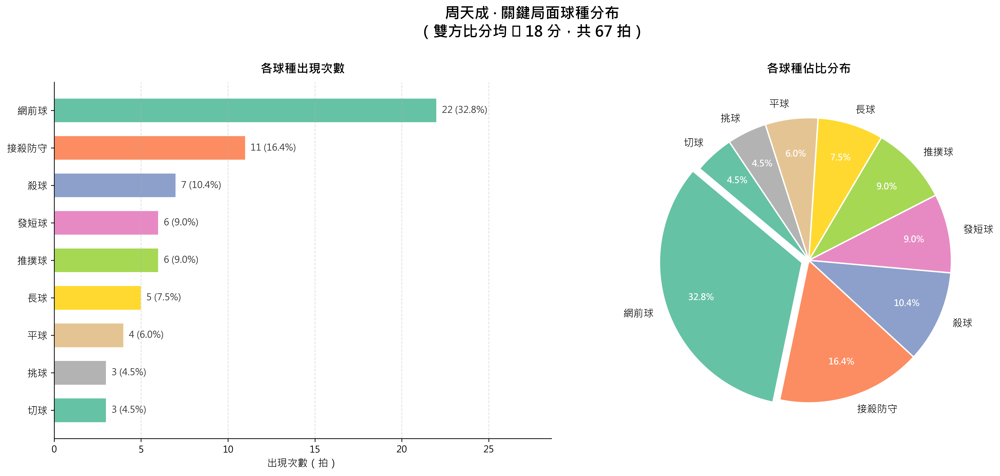

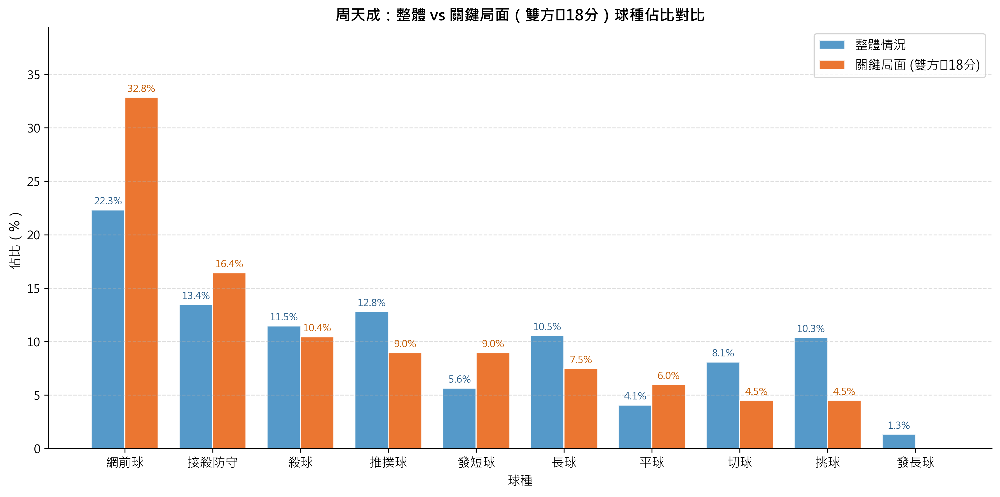

In [ ]:
import numpy as np

# ============================================================
# 分析周天成在雙方分數都達到18分以上時的球種分布
# ============================================================

print("=" * 60)
print("周天成在關鍵局面（雙方分數均≥18）的球種分布分析")
print("=" * 60)

# 驗證數據量
print(f"\n總資料筆數: {len(df)}")

# -----------------------------------------------------------
# Step 1: 篩選條件
# 條件1: 周天成為擊球者
# 條件2: 雙方比分均達到18分以上（關鍵局面）
# -----------------------------------------------------------
chou_name = 'CHOU Tien Chen'
momota_name = 'Kento MOMOTA'

mask_player = df['player'] == chou_name
mask_chou_score = df['CHOU Tien Chen_score'] >= 18
mask_momota_score = df['Kento MOMOTA_score'] >= 18

critical_chou_df = df[mask_player & mask_chou_score & mask_momota_score].copy()

print(f"\n篩選結果:")
print(f"  周天成擊球總次數: {df[mask_player].shape[0]}")
print(f"  雙方比分均≥18 時，周天成擊球次數: {len(critical_chou_df)}")

# -----------------------------------------------------------
# Step 2: 統計各球種次數與佔比
# -----------------------------------------------------------
if len(critical_chou_df) > 0:
    shot_counts = critical_chou_df['type'].value_counts()
    shot_pct = (shot_counts / shot_counts.sum() * 100).round(2)
    
    shot_summary = pd.DataFrame({
        '出現次數': shot_counts,
        '佔比(%)': shot_pct
    }).reset_index()
    shot_summary.columns = ['球種', '出現次數', '佔比(%)']
    shot_summary = shot_summary.sort_values('出現次數', ascending=False).reset_index(drop=True)
    
    print(f"\n【球種分布統計表】（雙方比分均≥18 時）")
    print(f"{'球種':<12} {'出現次數':>8} {'佔比(%)':>10}")
    print("-" * 35)
    for _, row in shot_summary.iterrows():
        print(f"  {row['球種']:<10} {int(row['出現次數']):>8}   {row['佔比(%)']:>8.2f}%")
    print("-" * 35)
    print(f"  {'合計':<10} {int(shot_counts.sum()):>8}   {'100.00':>8}%")
    
    # 計算涵蓋的比賽與回合資訊
    n_matches = critical_chou_df['match_id'].nunique()
    n_sets = critical_chou_df.groupby(['match_id', 'set']).ngroups
    n_rallies = critical_chou_df.groupby(['match_id', 'set', 'rally']).ngroups
    print(f"\n涵蓋場次: {n_matches} 場，局數: {n_sets} 局，回合數: {n_rallies} 個回合")

    # -----------------------------------------------------------
    # Step 3: 視覺化 - 長條圖 + 圓餅圖
    # -----------------------------------------------------------
    
    # 準備繪圖資料：小比例類別合併為「其他」
    threshold = 3.0  # 佔比低於3%合併
    main_shots = shot_summary[shot_summary['佔比(%)'] >= threshold].copy()
    other_shots = shot_summary[shot_summary['佔比(%)'] < threshold]
    
    if len(other_shots) > 0:
        other_row = pd.DataFrame({
            '球種': ['其他'],
            '出現次數': [other_shots['出現次數'].sum()],
            '佔比(%)': [other_shots['佔比(%)'].sum()]
        })
        plot_df = pd.concat([main_shots, other_row], ignore_index=True)
    else:
        plot_df = main_shots.copy()
    
    plot_df = plot_df.sort_values('出現次數', ascending=False).reset_index(drop=True)
    
    # 顏色設定
    colors_palette = sns.color_palette("Set2", len(plot_df))
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle(f'周天成 · 關鍵局面球種分布\n（雙方比分均 ≥ 18 分，共 {int(shot_counts.sum())} 拍）',
                 fontsize=16, fontweight='bold', y=1.01)
    
    # --- 左圖：水平長條圖（次數） ---
    ax1 = axes[0]
    bars = ax1.barh(
        plot_df['球種'][::-1],  # 由大到小排列
        plot_df['出現次數'][::-1],
        color=colors_palette[::-1],
        edgecolor='white',
        linewidth=0.8,
        height=0.65
    )
    
    # 在長條上標示次數與百分比
    for bar, (_, row) in zip(bars, plot_df[::-1].iterrows()):
        width = bar.get_width()
        ax1.text(
            width + 0.3,
            bar.get_y() + bar.get_height() / 2,
            f"{int(row['出現次數'])} ({row['佔比(%)']:.1f}%)",
            va='center', ha='left', fontsize=10, color='#333333'
        )
    
    ax1.set_title('各球種出現次數', fontsize=13, fontweight='bold', pad=10)
    ax1.set_xlabel('出現次數（拍）', fontsize=11)
    ax1.set_ylabel('')
    ax1.set_xlim(0, plot_df['出現次數'].max() * 1.3)
    ax1.tick_params(axis='y', labelsize=11)
    ax1.tick_params(axis='x', labelsize=10)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.grid(axis='x', linestyle='--', alpha=0.4)
    
    # --- 右圖：圓餅圖（佔比） ---
    ax2 = axes[1]
    
    # 突出最大佔比球種
    explode = [0.05 if i == 0 else 0 for i in range(len(plot_df))]
    
    wedges, texts, autotexts = ax2.pie(
        plot_df['出現次數'],
        labels=plot_df['球種'],
        autopct=lambda pct: f'{pct:.1f}%' if pct >= 4 else '',
        colors=colors_palette,
        explode=explode,
        startangle=140,
        pctdistance=0.75,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    
    for text in texts:
        text.set_fontsize(11)
    for autotext in autotexts:
        autotext.set_fontsize(9.5)
        autotext.set_fontweight('bold')
        autotext.set_color('white')
    
    ax2.set_title('各球種佔比分布', fontsize=13, fontweight='bold', pad=10)
    
    plt.tight_layout()
    
    # -----------------------------------------------------------
    # Step 4: 補充 - 與整體球種分布比較（堆疊對比表）
    # -----------------------------------------------------------
    print("\n" + "=" * 60)
    print("【對比】關鍵局面 vs 整體情況 - 球種佔比比較")
    print("=" * 60)
    
    # 整體周天成球種分布
    overall_shot_counts = df[mask_player]['type'].value_counts()
    overall_shot_pct = (overall_shot_counts / overall_shot_counts.sum() * 100).round(2)
    
    compare_df = pd.DataFrame({
        '整體佔比(%)': overall_shot_pct,
        '關鍵局面佔比(%)': shot_pct
    }).fillna(0)
    
    compare_df['差異(%)'] = (compare_df['關鍵局面佔比(%)'] - compare_df['整體佔比(%)']).round(2)
    compare_df = compare_df.sort_values('關鍵局面佔比(%)', ascending=False)
    
    print(f"\n{'球種':<12} {'整體佔比%':>10} {'關鍵局面%':>10} {'差異%':>8}")
    print("-" * 45)
    for idx, row in compare_df.iterrows():
        diff_str = f"+{row['差異(%)']:.2f}" if row['差異(%)'] > 0 else f"{row['差異(%)']:.2f}"
        print(f"  {idx:<10} {row['整體佔比(%)']:>9.2f}%  {row['關鍵局面佔比(%)']:>9.2f}%  {diff_str:>7}%")
    
    # 額外畫一張對比圖
    fig2, ax3 = plt.subplots(figsize=(12, 6))
    
    all_shot_types = compare_df.index.tolist()
    x = np.arange(len(all_shot_types))
    width = 0.38
    
    bars1 = ax3.bar(x - width/2, compare_df['整體佔比(%)'],
                    width=width, label='整體情況', color=sns.color_palette("Blues_d", 1)[0],
                    alpha=0.85, edgecolor='white')
    bars2 = ax3.bar(x + width/2, compare_df['關鍵局面佔比(%)'],
                    width=width, label='關鍵局面 (雙方≥18分)', color=sns.color_palette("Oranges_d", 1)[0],
                    alpha=0.85, edgecolor='white')
    
    # 標示數值
    for bar in bars1:
        h = bar.get_height()
        if h > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                     f'{h:.1f}%', ha='center', va='bottom', fontsize=8.5, color='#2c5f8a')
    for bar in bars2:
        h = bar.get_height()
        if h > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                     f'{h:.1f}%', ha='center', va='bottom', fontsize=8.5, color='#c45c00')
    
    ax3.set_title('周天成：整體 vs 關鍵局面（雙方≥18分）球種佔比對比',
                  fontsize=13, fontweight='bold')
    ax3.set_xticks(x)
    ax3.set_xticklabels(all_shot_types, fontsize=11)
    ax3.set_ylabel('佔比（%）', fontsize=11)
    ax3.set_xlabel('球種', fontsize=11)
    ax3.legend(fontsize=11)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.grid(axis='y', linestyle='--', alpha=0.4)
    ax3.set_ylim(0, max(compare_df['整體佔比(%)'].max(), compare_df['關鍵局面佔比(%)'].max()) * 1.2)
    
    plt.tight_layout()

else:
    print("\n⚠️ 沒有符合條件的數據（雙方比分均≥18 時，周天成無擊球記錄）")
    fig = plt.figure()


### 數據洞察
# 周天成關鍵局面（雙方≥18分）球種分析

## 核心數據
**樣本：** 4場、4局、9回合，共 **67拍**

---

## 關鍵局面球種分布

| 球種 | 次數 | 佔比 | vs 整體差異 |
|------|-----:|-----:|:-----------:|
| 網前球 | 22 | 32.84% | **+10.53%** ↑ |
| 接殺防守 | 11 | 16.42% | +2.97% ↑ |
| 殺球 | 7 | 10.45% | -1.01% |
| 發短球 | 6 | 8.96% | +3.33% ↑ |
| 推撲球 | 6 | 8.96% | -3.84% ↓ |
| 長球 | 5 | 7.46% | -3.08% ↓ |
| 平球 | 4 | 5.97% | +1.91% ↑ |
| 挑球 | 3 | 4.48% | **-5.87%** ↓ |
| 切球 | 3 | 4.48% | -3.61% ↓ |

---

## 戰術洞察

### 🔴 網前球暴增（+10.53%）
關鍵局面網前球佔比從整體 22% 跳升至 **33%**，是最顯著的策略轉變。周天成在壓力下傾向以**網前短球製造對手前後移動**，壓縮對手進攻空間。

### 🔴 挑球大幅減少（-5.87%）
整體挑球佔比 10.35%，關鍵局面降至 **4.48%**。代表他刻意**避免將球挑高給對手殺球**，降低被動失分風險。

### 🟡 發短球增加（+3.33%）
關鍵局面發短球比例提升，顯示他以**發球控制開局節奏**，不輕易送出高遠球讓對手主導。

### 🟡 推撲球與長球下降
兩者合計減少約 7%，說明他**減少後場大範圍調動**，轉而以前場精細控制為主。

---

## 教練總結

> 周天成在關鍵局面的策略明確：**壓縮節奏、控制前場、避免被動挑高**。網前球+接殺防守合計佔近 **50%**，反映其在高壓下以防守穩定為優先，而非主動強攻。對手應針對其前場依賴，以快速平抽壓制中場，破壞其節奏佈局。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成在雙方比分均達到18分以上時的擊球資料，並計算了各球種的出現次數和佔比。候選程式碼的分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 1 一致。此外，候選程式碼還提供了額外的視覺化和對比分析，這些都是在題目要求之外的合理擴展，不影響判定結果。




## 題號 5
**問題**: 幫我繪製周天成得分時球的落點熱區圖
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason`


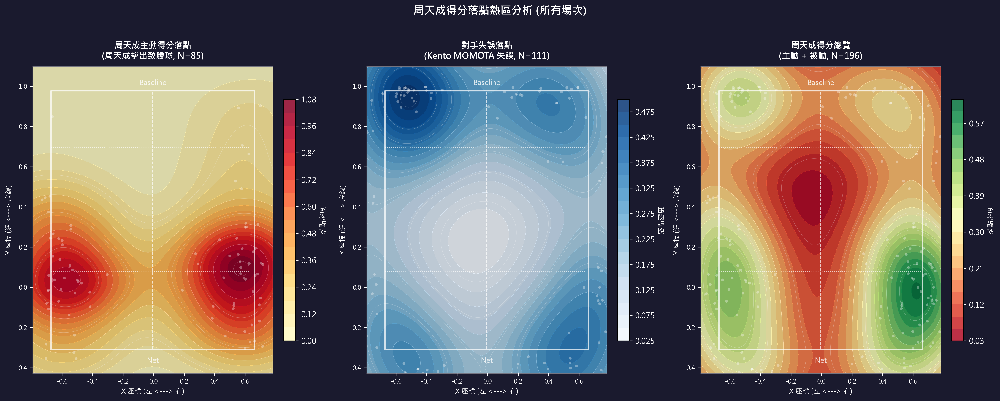

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde

# ========================================
# 1. 資料驗證與篩選
# ========================================
print(f"資料總行數: {len(df)}")
assert len(df) > 0, "資料集為空"

# 周天成得分的最後一拍（每回合結束那一拍）
chou_wins = df[df['getpoint_player'] == 'CHOU Tien Chen'].copy()
n_total = len(chou_wins)

# 主動得分：周天成自己擊球得分
chou_active = chou_wins[chou_wins['player'] == 'CHOU Tien Chen'].copy()
n_active = len(chou_active)

# 被動得分：對手失誤，周天成受惠得分
chou_passive = chou_wins[chou_wins['player'] == 'Kento MOMOTA'].copy()
n_passive = len(chou_passive)

print(f"\n周天成得分總計: {n_total} 回合")
print(f"  主動得分 (周天成擊球): {n_active} 次 ({n_active/n_total*100:.1f}%)")
print(f"  被動得分 (對手失誤): {n_passive} 次 ({n_passive/n_total*100:.1f}%)")

# ========================================
# 2. 座標系統分析（確認 Y 軸方向）
# ========================================
# 根據 landing_area 代碼確認方向
# Back Court: area 1-4, Front Court: area 21-24
back_data = df[df['landing_area'].isin([1.0, 2.0, 3.0, 4.0])]
front_data = df[df['landing_area'].isin([21.0, 22.0, 23.0, 24.0])]

print(f"\n座標系統分析:")
print(f"  後場 (Area 1-4) landing_y 平均: {back_data['landing_y'].mean():.4f}")
print(f"  前場 (Area 21-24) landing_y 平均: {front_data['landing_y'].mean():.4f}")
print(f"\n  landing_x 範圍: {df['landing_x'].min():.3f} ~ {df['landing_x'].max():.3f}")
print(f"  landing_y 範圍: {df['landing_y'].min():.3f} ~ {df['landing_y'].max():.3f}")

# ========================================
# 3. 推斷場地邊界座標
# ========================================
# 根據 area 定義，後場 Y 較大，前場 Y 較小（接近網）
# 網的位置約在 landing_y 的正負分界附近
# 利用實際資料分位數估計場地邊界

# 取有效場內落點（area 1-24）
inbound = df[df['landing_area'].isin([float(i) for i in range(1, 25)])]

x_left  = inbound['landing_x'].quantile(0.01)   # 左邊線
x_right = inbound['landing_x'].quantile(0.99)   # 右邊線
y_back  = inbound['landing_y'].quantile(0.99)   # 後場底線（Y 較大）
y_net   = inbound['landing_y'].quantile(0.01)   # 前場/網線（Y 較小）

print(f"\n推斷場地邊界:")
print(f"  左邊線 x_left  = {x_left:.4f}")
print(f"  右邊線 x_right = {x_right:.4f}")
print(f"  後場底線 y_back = {y_back:.4f}")
print(f"  前場/網 y_net  = {y_net:.4f}")

# ========================================
# 4. 定義場地繪製函式
# ========================================
def draw_court(ax, x_left, x_right, y_net, y_back, alpha=0.6):
    """
    在 ax 上繪製羽球半場場地線。
    座標假設: y_back > y_net（後場 Y 較大）
    """
    line_kw = dict(color='white', linewidth=1.5, alpha=alpha)

    # 場地外框
    court_x = [x_left, x_right, x_right, x_left, x_left]
    court_y = [y_net, y_net, y_back, y_back, y_net]
    ax.plot(court_x, court_y, **line_kw)

    # 中線（垂直中心線）
    x_mid = (x_left + x_right) / 2
    ax.plot([x_mid, x_mid], [y_net, y_back], color='white', linewidth=1.0,
            alpha=alpha, linestyle='--')

    # 發球線（前場 / 中場界線，約在 1/3 處）
    y_serve = y_net + (y_back - y_net) * 0.30
    ax.plot([x_left, x_right], [y_serve, y_serve], color='white',
            linewidth=1.0, alpha=alpha, linestyle=':')

    # 後場發球線（約後場 1/4 處）
    y_back_serve = y_net + (y_back - y_net) * 0.78
    ax.plot([x_left, x_right], [y_back_serve, y_back_serve], color='white',
            linewidth=1.0, alpha=alpha, linestyle=':')

    # 標注方向
    ax.text(x_mid, y_net - 0.04, 'Net', ha='center', va='top',
            color='white', fontsize=9, alpha=0.8)
    ax.text(x_mid, y_back + 0.02, 'Baseline', ha='center', va='bottom',
            color='white', fontsize=9, alpha=0.8)

# ========================================
# 5. 繪製熱區圖
# ========================================
# 定義繪圖範圍（稍微寬於場地邊界，顯示出界球）
margin = 0.12
xlim = (x_left - margin, x_right + margin)
ylim = (y_net - margin, y_back + margin)

# KDE 網格設定
grid_n = 150
xx, yy = np.meshgrid(
    np.linspace(xlim[0], xlim[1], grid_n),
    np.linspace(ylim[0], ylim[1], grid_n)
)
grid_pos = np.vstack([xx.ravel(), yy.ravel()])

def compute_kde(data_x, data_y, grid_pos):
    """計算 2D KDE 密度值"""
    if len(data_x) < 3:
        return np.zeros(grid_pos.shape[1])
    kde = gaussian_kde(np.vstack([data_x, data_y]), bw_method='scott')
    return kde(grid_pos)

# 計算密度
density_active  = compute_kde(chou_active['landing_x'].values,
                               chou_active['landing_y'].values,
                               grid_pos).reshape(grid_n, grid_n)

density_passive = compute_kde(chou_passive['landing_x'].values,
                               chou_passive['landing_y'].values,
                               grid_pos).reshape(grid_n, grid_n)

density_all     = compute_kde(chou_wins['landing_x'].values,
                               chou_wins['landing_y'].values,
                               grid_pos).reshape(grid_n, grid_n)

# ========================================
# 6. 建立圖表（1 列 3 圖）
# ========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.patch.set_facecolor('#1a1a2e')

titles = [
    f"周天成主動得分落點\n(周天成擊出致勝球, N={n_active})",
    f"對手失誤落點\n(Kento MOMOTA 失誤, N={n_passive})",
    f"周天成得分總覽\n(主動 + 被動, N={n_total})"
]
densities = [density_active, density_passive, density_all]
cmaps     = ['YlOrRd', 'Blues', 'RdYlGn']
datasets  = [chou_active, chou_passive, chou_wins]

for i, ax in enumerate(axes):
    ax.set_facecolor('#0d1117')

    # 繪製 KDE 熱區
    Z = densities[i]
    im = ax.contourf(xx, yy, Z, levels=20, cmap=cmaps[i], alpha=0.85)
    ax.contour(xx, yy, Z, levels=8, colors='white', linewidths=0.4, alpha=0.3)

    # 疊加散點（半透明）
    ds = datasets[i]
    if len(ds) > 0:
        ax.scatter(ds['landing_x'], ds['landing_y'],
                   c='white', s=12, alpha=0.35, edgecolors='none', zorder=5)

    # 繪製場地線
    draw_court(ax, x_left, x_right, y_net, y_back, alpha=0.75)

    # Colorbar
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label('落點密度', color='white', fontsize=9)
    cb.ax.yaxis.set_tick_params(color='white')
    plt.setp(cb.ax.yaxis.get_ticklabels(), color='white')

    # 標題與軸設定
    ax.set_title(titles[i], color='white', fontsize=11, fontweight='bold', pad=10)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel('X 座標 (左 <---> 右)', color='white', fontsize=9)
    ax.set_ylabel('Y 座標 (網 <---> 底線)', color='white', fontsize=9)
    ax.tick_params(colors='white', labelsize=8)
    for spine in ax.spines.values():
        spine.set_edgecolor('white')
        spine.set_alpha(0.4)

plt.suptitle("周天成得分落點熱區分析 (所有場次)",
             color='white', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

# ========================================
# 7. 落點區域分佈統計（使用 landing_area）
# ========================================
print("\n" + "="*50)
print("落點區域分佈統計")
print("="*50)

# 區域分類
def classify_area(area_val):
    if area_val in [1, 2, 3, 4]:
        return "後場"
    elif area_val in [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]:
        return "中場"
    elif area_val in [17, 18, 19, 20, 21, 22, 23, 24]:
        return "前場"
    else:
        return "出界"

chou_wins['area_zone'] = chou_wins['landing_area'].apply(classify_area)
chou_active_tmp = chou_wins[chou_wins['player'] == 'CHOU Tien Chen'].copy()
chou_passive_tmp = chou_wins[chou_wins['player'] == 'Kento MOMOTA'].copy()

print("\n[周天成主動得分] 落點分區:")
if len(chou_active_tmp) > 0:
    active_zone = chou_active_tmp['area_zone'].value_counts()
    for zone, cnt in active_zone.items():
        print(f"  {zone}: {cnt} 次 ({cnt/len(chou_active_tmp)*100:.1f}%)")

print("\n[對手失誤] 落點分區:")
if len(chou_passive_tmp) > 0:
    passive_zone = chou_passive_tmp['area_zone'].value_counts()
    for zone, cnt in passive_zone.items():
        print(f"  {zone}: {cnt} 次 ({cnt/len(chou_passive_tmp)*100:.1f}%)")

# ========================================
# 8. 最高密度落點 Area 排行
# ========================================
print("\n" + "="*50)
print("落點 Area 排行 (Top 10)")
print("="*50)

print("\n[主動得分] 最常見落點 Area:")
if len(chou_active) > 0:
    area_rank_active = chou_active['landing_area'].value_counts().head(10)
    for area, cnt in area_rank_active.items():
        print(f"  Area {int(area):2d}: {cnt} 次")

print("\n[對手失誤] 最常見落點 Area:")
if len(chou_passive) > 0:
    area_rank_passive = chou_passive['landing_area'].value_counts().head(10)
    for area, cnt in area_rank_passive.items():
        print(f"  Area {int(area):2d}: {cnt} 次")


### 數據洞察
# 周天成得分落點熱區分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 一、主動得分落點（N=85，周天成擊出致勝球）

### 熱區集中：中場壓制為主

```
後場底線
┌────┬────┬────┬────┐
│ 1  │ 2  │ 3  │ 4  │  ← 後場：14次(16.5%)
│    │    │    │ ██ │    Area 4: 8次
├────┼────┼────┼────┤
│ ██ │    │ ██ │ ██ │  ← 中場Row2：Area5(16次)最高熱區
│ ██ │    │    │ ██ │    Area8: 12次, Area9: 10次
├────┼────┼────┼────┤
│    │    │    │    │  ← 中場Row3：Area12: 14次
│    │    │    │ ██ │
├────┼────┼────┼────┤
│    │ ██ │    │    │  ← 中場Row4：Area13: 4次
├────┼────┼────┼────┤
│    │    │    │ ██ │  ← 前場：6次(7.1%)
└────┴────┴────┴────┘
網前
```

**Top 落點排行：**
| 排名 | Area | 位置 | 次數 |
|:---:|:---:|:---:|:---:|
| 1 | **5** | 中場左側 | 16次 |
| 2 | **12** | 中場右側 | 14次 |
| 3 | **8** | 中場右側 | 12次 |
| 4 | **9** | 中場左側 | 10次 |
| 5 | **4** | 後場右角 | 8次 |

---

## 二、對手失誤落點（N=111，桃田賢斗失誤）

### 熱區集中：出界＋網前失誤

```
後場底線
┌────┬────┬────┬────┐
│    │    │    │    │  ← 後場：3次(2.7%)
├────┼────┼────┼────┤
│    │    │    │    │  ← 中場：2次(1.8%)
├────┼────┼────┼────┤
│    │    │    │    │
├────┼────┼────┼────┤
│    │    │    │ ██ │  ← Area20: 前場右側
├────┼────┼────┼────┤
│ ██ │ ██ │ ██ │ ██ │  ← 前場：45次(40.5%)
│ ██ │ ██ │ ██ │ ██ │    Area21:18, Area23:10
│    │    │    │    │    Area22:6, Area24:9
└────┴────┴────┴────┘
網前（含出界 61次/55.0%）
```

**Top 落點排行：**
| 排名 | Area | 位置 | 次數 | 性質 |
|:---:|:---:|:---:|:---:|:---:|
| 1 | **21** | 前場左側 | 18次 | 網前失誤 |
| 2 | **32** | 出界區 | 13次 | 出界 |
| 3 | **28** | 出界區 | 13次 | 出界 |
| 4 | **23** | 前場右中 | 10次 | 網前失誤 |
| 5 | **30** | 出界區 | 9次 | 出界 |

---

## 三、戰術洞察

### 🔴 主動得分：中場壓制是核心武器
> **75.3%的致勝球落在中場（Area 5、8、9、12）**，集中在左右兩側中場帶。這代表周天成善用**平球/推撲球壓制對手中場移動**，讓桃田無法充分起跳，被迫在非最佳位置回球。

### 🔵 被動得分：逼出界＋逼網前失誤
> 桃田失誤中 **55%出界、40.5%掛網**，幾乎沒有後場失誤（2.7%）。這說明周天成的戰術**不是靠後場大角度拉扯，而是用節奏和速度讓桃田在前場判斷失誤或急於救球打出界**。

### ⚡ 核心戰術結論
| 得分模式 | 關鍵區域 | 戰術意涵 |
|:---|:---:|:---|
| 主動致勝 | Area 5、12（中場兩翼） | 平快球壓中場，限制桃田起跳空間 |
| 逼對手失誤 | Area 21、23（網前）+ 出界 | 快速變速逼前場，製造判斷錯誤 |
| 後場威脅 | Area 4（後場右角） | 右後角是唯一有效後場致勝點 |

> **教練建議**：周天成的得分模式高度依賴**中場速度壓制**，而非傳統後場拉吊。對手若要破解，必須強化中場接球穩定性，避免被帶到前場被動救球。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選出周天成得分的記錄，並進一步區分主動得分和被動得分，然後使用 KDE 繪製了得分時球的落點熱區圖。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 2 一致，且結果有效且合理。




## 題號 6
**問題**: 在第一場次中，每回合用的拍數，繪圖
> **使用的資料欄位群組**: `game_structure`


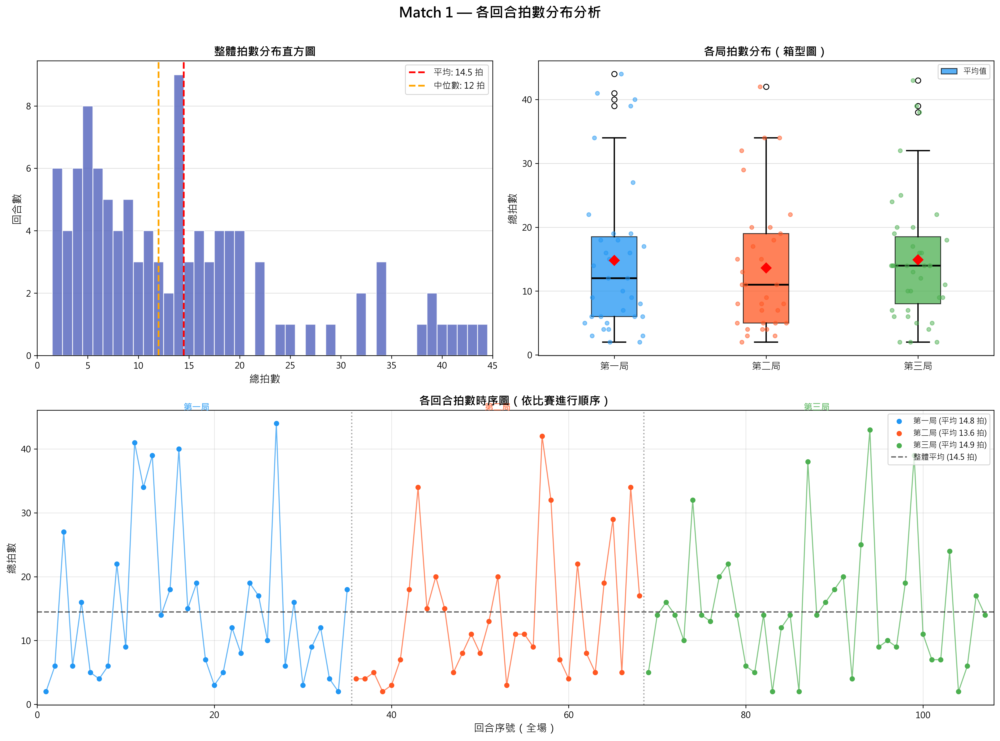

In [ ]:
import numpy as np

# ============================================================
# 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")

# 篩選第一場次
df_match1 = df[df['match_id'] == 1].copy()
print(f"Match ID=1 資料筆數: {len(df_match1)}")

if len(df_match1) == 0:
    print("❌ 找不到 match_id=1 的資料！")
else:
    # ============================================================
    # 統計每個 rally 的總拍數
    # 需以 (match_id, set, rally) 分組，避免不同局的 rally 混淆
    # ============================================================
    rally_strokes = (
        df_match1.groupby(['match_id', 'set', 'rally'])
        .size()
        .reset_index(name='total_strokes')
    )
    
    print(f"\n✅ Match 1 共有 {len(rally_strokes)} 個回合 (Rally)")
    print(f"\n{'='*50}")
    print("各回合拍數統計（前20筆）：")
    print(rally_strokes.head(20).to_string(index=False))
    
    # ============================================================
    # 描述性統計
    # ============================================================
    stats = rally_strokes['total_strokes'].describe()
    print(f"\n{'='*50}")
    print("拍數描述性統計：")
    print(f"  回合總數:   {int(stats['count'])}")
    print(f"  平均拍數:   {stats['mean']:.2f}")
    print(f"  標準差:     {stats['std']:.2f}")
    print(f"  最小拍數:   {int(stats['min'])}")
    print(f"  25% 分位:   {int(stats['25%'])}")
    print(f"  中位數:     {int(stats['50%'])}")
    print(f"  75% 分位:   {int(stats['75%'])}")
    print(f"  最大拍數:   {int(stats['max'])}")
    
    # 各局統計
    print(f"\n{'='*50}")
    print("各局拍數統計：")
    set_stats = rally_strokes.groupby('set')['total_strokes'].agg(
        回合數='count', 平均拍數='mean', 中位數='median',
        最小值='min', 最大值='max', 標準差='std'
    ).round(2)
    print(set_stats.to_string())
    
    # 拍數分布（依拍數區間統計回合數）
    bins = [1, 3, 5, 7, 10, 15, 20, 30, 50]
    labels = ['2-3拍', '4-5拍', '6-7拍', '8-10拍', '11-15拍', '16-20拍', '21-30拍', '31拍以上']
    rally_strokes['stroke_range'] = pd.cut(
        rally_strokes['total_strokes'], bins=bins, labels=labels, right=True
    )
    dist_table = rally_strokes['stroke_range'].value_counts().sort_index()
    print(f"\n{'='*50}")
    print("拍數區間分布：")
    for rng, cnt in dist_table.items():
        pct = cnt / len(rally_strokes) * 100
        print(f"  {rng}: {cnt} 回合 ({pct:.1f}%)")
    
    # ============================================================
    # 視覺化
    # ============================================================
    fig = plt.figure(figsize=(16, 12))
    fig.suptitle('Match 1 — 各回合拍數分布分析', fontsize=16, fontweight='bold', y=0.98)
    
    # 定義顏色（各局）
    set_colors = {1: '#2196F3', 2: '#FF5722', 3: '#4CAF50'}
    set_labels = {1: '第一局', 2: '第二局', 3: '第三局'}
    
    # --- 圖1：整體拍數直方圖（含 KDE）---
    ax1 = fig.add_subplot(2, 2, 1)
    max_strokes = int(rally_strokes['total_strokes'].max())
    bins_hist = np.arange(1, max_strokes + 2) - 0.5  # 每拍一格
    
    ax1.hist(
        rally_strokes['total_strokes'],
        bins=bins_hist,
        color='#5C6BC0', edgecolor='white', alpha=0.85, zorder=2
    )
    ax1.axvline(
        rally_strokes['total_strokes'].mean(),
        color='red', linestyle='--', linewidth=2,
        label=f"平均: {rally_strokes['total_strokes'].mean():.1f} 拍"
    )
    ax1.axvline(
        rally_strokes['total_strokes'].median(),
        color='orange', linestyle='--', linewidth=2,
        label=f"中位數: {int(rally_strokes['total_strokes'].median())} 拍"
    )
    ax1.set_xlabel('總拍數', fontsize=12)
    ax1.set_ylabel('回合數', fontsize=12)
    ax1.set_title('整體拍數分布直方圖', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(axis='y', alpha=0.4, zorder=1)
    ax1.set_xlim(0, max_strokes + 1)
    
    # --- 圖2：各局拍數箱型圖 ---
    ax2 = fig.add_subplot(2, 2, 2)
    sets_present = sorted(rally_strokes['set'].unique())
    data_by_set = [rally_strokes[rally_strokes['set'] == s]['total_strokes'].values for s in sets_present]
    colors_list = [set_colors.get(s, '#9E9E9E') for s in sets_present]
    labels_list = [set_labels.get(s, f'第{s}局') for s in sets_present]
    
    bp = ax2.boxplot(
        data_by_set, patch_artist=True, notch=False,
        medianprops=dict(color='black', linewidth=2),
        whiskerprops=dict(linewidth=1.5),
        capprops=dict(linewidth=1.5)
    )
    for patch, color in zip(bp['boxes'], colors_list):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    
    # 疊加散點（jitter）顯示每個 rally
    for i, (s, data) in enumerate(zip(sets_present, data_by_set)):
        jitter = np.random.uniform(-0.2, 0.2, size=len(data))
        ax2.scatter(
            np.full_like(data, i + 1, dtype=float) + jitter,
            data, alpha=0.5, s=20, color=colors_list[i], zorder=3
        )
    
    ax2.set_xticks(range(1, len(sets_present) + 1))
    ax2.set_xticklabels(labels_list, fontsize=11)
    ax2.set_ylabel('總拍數', fontsize=12)
    ax2.set_title('各局拍數分布（箱型圖）', fontsize=13, fontweight='bold')
    ax2.grid(axis='y', alpha=0.4)
    
    # 標示平均值
    for i, data in enumerate(data_by_set):
        ax2.plot(i + 1, np.mean(data), marker='D', color='red',
                 markersize=8, zorder=5, label='平均' if i == 0 else "")
    ax2.legend(['平均值'], loc='upper right', fontsize=9)
    
    # --- 圖3：各回合拍數序列圖（按時間序）---
    ax3 = fig.add_subplot(2, 1, 2)
    
    # 建立全局回合序號（依 set -> rally 順序）
    rally_strokes_sorted = rally_strokes.sort_values(['set', 'rally']).reset_index(drop=True)
    rally_strokes_sorted['global_rally_idx'] = range(1, len(rally_strokes_sorted) + 1)
    
    # 找各局邊界
    set_boundaries = {}
    for s in sets_present:
        idx_list = rally_strokes_sorted[rally_strokes_sorted['set'] == s]['global_rally_idx']
        set_boundaries[s] = (idx_list.min(), idx_list.max())
    
    # 各局用不同顏色繪製
    for s in sets_present:
        mask = rally_strokes_sorted['set'] == s
        sub = rally_strokes_sorted[mask]
        ax3.plot(
            sub['global_rally_idx'], sub['total_strokes'],
            color=set_colors[s], alpha=0.7, linewidth=1.2
        )
        ax3.scatter(
            sub['global_rally_idx'], sub['total_strokes'],
            color=set_colors[s], s=25, zorder=3,
            label=f'{set_labels[s]} (平均 {sub["total_strokes"].mean():.1f} 拍)'
        )
        # 局邊界垂直線
        s_min, s_max = set_boundaries[s]
        if s > 1:
            ax3.axvline(s_min - 0.5, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
    
    # 整體平均線
    overall_mean = rally_strokes_sorted['total_strokes'].mean()
    ax3.axhline(overall_mean, color='black', linestyle='--', linewidth=1.5, alpha=0.6,
                label=f'整體平均 ({overall_mean:.1f} 拍)')
    
    # 標示各局標籤
    for s in sets_present:
        s_min, s_max = set_boundaries[s]
        mid = (s_min + s_max) / 2
        ax3.text(mid, ax3.get_ylim()[1] if ax3.get_ylim()[1] > 0 else 5,
                 set_labels[s], ha='center', fontsize=10, color=set_colors[s],
                 fontweight='bold', alpha=0.8)
    
    ax3.set_xlabel('回合序號（全場）', fontsize=12)
    ax3.set_ylabel('總拍數', fontsize=12)
    ax3.set_title('各回合拍數時序圖（依比賽進行順序）', fontsize=13, fontweight='bold')
    ax3.legend(loc='upper right', fontsize=9)
    ax3.grid(alpha=0.3)
    ax3.set_xlim(0, len(rally_strokes_sorted) + 1)
    
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    
    print(f"\n{'='*50}")
    print("✅ 圖表生成完成")


### 數據洞察
# Match 1 回合拍數分析報告

## 📊 核心數據總覽

| 指標 | 數值 |
|------|------|
| 總回合數 | 107 回合 |
| 平均拍數 | **14.5 拍** |
| 中位數 | 12 拍 |
| 最短回合 | 2 拍 |
| 最長回合 | 44 拍 |
| 標準差 | 10.79 |

---

## 🎯 拍數區間分布

```
短拍 (2-5拍)   ████████████  24回合 (22.4%)
中短 (6-10拍)  ██████████████ 23回合 (21.5%)
中長 (11-20拍) ████████████████████ 40回合 (37.4%)
長拍 (21拍+)   ████████████  20回合 (18.7%)
```

---

## 📋 各局比較

| 局別 | 回合數 | 平均拍數 | 中位數 | 最長回合 |
|------|--------|----------|--------|----------|
| 第一局 | 35 | 14.8 | 12.0 | 44 |
| 第二局 | 33 | 13.6 | 11.0 | 42 |
| 第三局 | 39 | 14.9 | 14.0 | 43 |

---

## 💡 戰術洞察

**1. 比賽節奏屬「中長型對抗」**
平均14.5拍、中位數12拍，顯示雙方具備一定底線對抗能力，非快攻速決型打法。

**2. 短回合佔比高，但不是主軸**
2-5拍的快速得分佔22.4%，代表每5球約有1球靠發球段直接得分或失誤，**發球與第三拍品質是關鍵**。

**3. 長回合（21拍以上）佔18.7%**
13場31拍以上的超長回合，體能與心理抗壓是勝負關鍵因素，**第三局平均拍數最高（14.9）**，說明決勝局雙方更趨保守、不輕易冒進。

**4. 第二局節奏最快**
中位數11拍為三局最低，可能是一方調整策略後加快進攻節奏，或另一方體力開始下滑。

**5. 標準差10.79極大**
回合長度變異性高，說明比賽風格多元，**無法靠單一套路應對**，臨場應變能力至關重要。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了第一場比賽的資料，並以 (match_id, set, rally) 分組來計算每個回合的拍數。然後，它對這些拍數進行了描述性統計分析，並生成了多個視覺化圖表來展示拍數分布。雖然視覺化的形式與 Reference Code 1 不同，但這不影響其核心邏輯的正確性。




## 題號 7
**問題**: 繪製周天成殺球時的站點熱區圖
> **使用的資料欄位群組**: `game_structure, shot_type, player_location`


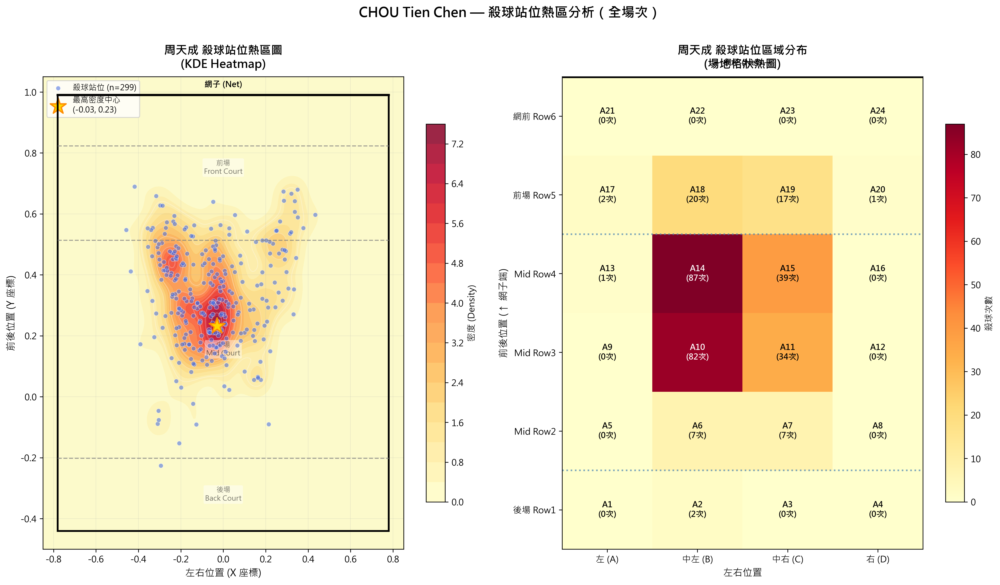

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib.patches as patches

# ============================================================
# 1. 數據驗證與篩選
# ============================================================
print("=" * 60)
print("周天成殺球站位熱區分析")
print("=" * 60)

if len(df) == 0:
    print("警告：df 為空！")
else:
    # 篩選周天成的殺球
    chou_smash = df[(df['player'] == 'CHOU Tien Chen') & (df['type'] == '殺球')].copy()

    print(f"總資料筆數: {len(df)}")
    print(f"周天成殺球總次數: {len(chou_smash)}")
    print(f"player_location_x 遺失值: {chou_smash['player_location_x'].isna().sum()}")
    print(f"player_location_y 遺失值: {chou_smash['player_location_y'].isna().sum()}")

    # 移除座標遺失值
    chou_smash_clean = chou_smash.dropna(subset=['player_location_x', 'player_location_y'])
    print(f"清理後殺球筆數: {len(chou_smash_clean)}")

    # ============================================================
    # 2. 站位區域統計 (player_location_area)
    # ============================================================
    area_counts = chou_smash_clean['player_location_area'].value_counts().sort_index()
    print(f"\n殺球站位區域分布 (player_location_area):")
    print(f"{'區域代碼':<10} {'次數':<8} {'佔比'}")
    for area, cnt in area_counts.items():
        pct = cnt / len(chou_smash_clean) * 100
        print(f"  Area {int(area):<7} {cnt:<8} {pct:.1f}%")

    print(f"\n站位 X 座標範圍: {chou_smash_clean['player_location_x'].min():.4f} ~ {chou_smash_clean['player_location_x'].max():.4f}")
    print(f"站位 Y 座標範圍: {chou_smash_clean['player_location_y'].min():.4f} ~ {chou_smash_clean['player_location_y'].max():.4f}")

    if len(chou_smash_clean) > 0:
        # ============================================================
        # 3. 繪圖 — 場地 KDE 熱區圖 + 區域格狀熱圖
        # ============================================================
        fig = plt.figure(figsize=(16, 9))

        x_min_court, x_max_court = -0.85, 0.85
        y_min_court, y_max_court = -0.50, 1.05

        # ---- 左圖：KDE 熱區圖 ----
        ax1 = fig.add_subplot(1, 2, 1)

        x = chou_smash_clean['player_location_x'].values
        y = chou_smash_clean['player_location_y'].values

        # 建立網格
        x_grid = np.linspace(x_min_court, x_max_court, 200)
        y_grid = np.linspace(y_min_court, y_max_court, 200)
        X, Y = np.meshgrid(x_grid, y_grid)

        # KDE 計算
        positions = np.vstack([X.ravel(), Y.ravel()])
        values = np.vstack([x, y])
        kernel = gaussian_kde(values, bw_method=0.25)
        Z = np.reshape(kernel(positions).T, X.shape)

        # 繪製熱區
        heatmap = ax1.contourf(X, Y, Z, levels=20, cmap='YlOrRd', alpha=0.85)
        plt.colorbar(heatmap, ax=ax1, label='密度 (Density)', shrink=0.8)

        # 等高線
        ax1.contour(X, Y, Z, levels=8, colors='white', alpha=0.3, linewidths=0.8)

        # 繪製散點（實際站位點）
        ax1.scatter(x, y, c='royalblue', s=25, alpha=0.55, edgecolors='white',
                    linewidths=0.5, zorder=5, label=f'殺球站位 (n={len(chou_smash_clean)})')

        # ---- 場地邊界框 ----
        court_left   = x_min_court + 0.07
        court_right  = x_max_court - 0.07
        court_bottom = y_min_court + 0.06
        court_top    = y_max_court - 0.06
        court_height = court_top - court_bottom
        mid_x        = 0.0

        court_rect = patches.Rectangle(
            (court_left, court_bottom),
            court_right - court_left,
            court_height,
            linewidth=2, edgecolor='black', facecolor='none', zorder=6
        )
        ax1.add_patch(court_rect)

        # 場地分界線（後/中/前場）
        y_back_mid  = court_bottom + court_height * (1 / 6)
        y_mid_front = court_bottom + court_height * (4 / 6)
        y_front_net = court_bottom + court_height * (5.3 / 6)

        line_style = dict(color='gray', linewidth=1.2, linestyle='--', zorder=6, alpha=0.7)
        for yline in [y_back_mid, y_mid_front, y_front_net]:
            ax1.plot([court_left, court_right], [yline, yline], **line_style)

        # 場地區域文字標籤
        zone_info = [
            (mid_x, (court_bottom + y_back_mid) / 2,  '後場\nBack Court'),
            (mid_x, (y_back_mid + y_mid_front) / 2,   '中場\nMid Court'),
            (mid_x, (y_mid_front + court_top) / 2,    '前場\nFront Court'),
        ]
        for lx, ly, label in zone_info:
            ax1.text(lx, ly, label, ha='center', va='center', fontsize=8,
                     color='black', alpha=0.55, style='italic',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.45, edgecolor='none'))

        # 網子線
        ax1.plot([court_left, court_right], [court_top, court_top],
                 color='black', linewidth=2.5, zorder=7)
        ax1.text(mid_x, court_top + 0.02, '網子 (Net)', ha='center', va='bottom',
                 fontsize=9, color='black', fontweight='bold')

        # 最高密度中心 — 改用 marker='*'
        max_idx = np.unravel_index(Z.argmax(), Z.shape)
        peak_x  = X[max_idx]
        peak_y  = Y[max_idx]
        ax1.scatter([peak_x], [peak_y], marker='*', c='gold', s=350, zorder=10,
                    edgecolors='darkorange', linewidths=1.5,
                    label=f'最高密度中心\n({peak_x:.2f}, {peak_y:.2f})')

        ax1.set_xlim(x_min_court, x_max_court)
        ax1.set_ylim(y_min_court, y_max_court)
        ax1.set_xlabel('左右位置 (X 座標)', fontsize=11)
        ax1.set_ylabel('前後位置 (Y 座標)', fontsize=11)
        ax1.set_title('周天成 殺球站位熱區圖\n(KDE Heatmap)', fontsize=13, fontweight='bold', pad=10)
        ax1.legend(loc='upper left', fontsize=9, framealpha=0.8)
        ax1.set_facecolor('#f0f4f8')
        ax1.grid(True, alpha=0.25, linewidth=0.5)

        # ---- 右圖：Area 格狀熱圖 ----
        ax2 = fig.add_subplot(1, 2, 2)

        # Area 對應格子 (row=前後, col=左右)，row 0=後場, row 5=網前
        grid_area_map = {
            (0, 0): 1,  (0, 1): 2,  (0, 2): 3,  (0, 3): 4,
            (1, 0): 5,  (1, 1): 6,  (1, 2): 7,  (1, 3): 8,
            (2, 0): 9,  (2, 1): 10, (2, 2): 11, (2, 3): 12,
            (3, 0): 13, (3, 1): 14, (3, 2): 15, (3, 3): 16,
            (4, 0): 17, (4, 1): 18, (4, 2): 19, (4, 3): 20,
            (5, 0): 21, (5, 1): 22, (5, 2): 23, (5, 3): 24,
        }

        area_count_dict = chou_smash_clean['player_location_area'].value_counts().to_dict()

        grid_data = np.zeros((6, 4))
        for (row, col), area_id in grid_area_map.items():
            grid_data[row, col] = area_count_dict.get(float(area_id), 0)

        im = ax2.imshow(grid_data, cmap='YlOrRd', aspect='auto',
                        origin='lower',   # row 0 在底部（後場）
                        vmin=0, vmax=max(grid_data.max(), 1))
        plt.colorbar(im, ax=ax2, label='殺球次數', shrink=0.8)

        # 每格標注 Area 代碼與次數
        for row in range(6):
            for col in range(4):
                count   = int(grid_data[row, col])
                area_id = grid_area_map[(row, col)]
                text_color = 'white' if count > grid_data.max() * 0.6 else 'black'
                ax2.text(col, row, f'A{area_id}\n({count}次)',
                         ha='center', va='center', fontsize=9,
                         fontweight='bold', color=text_color)

        ax2.set_xticks([0, 1, 2, 3])
        ax2.set_xticklabels(['左 (A)', '中左 (B)', '中右 (C)', '右 (D)'], fontsize=10)
        ax2.set_yticks([0, 1, 2, 3, 4, 5])
        ax2.set_yticklabels(['後場 Row1', 'Mid Row2', 'Mid Row3', 'Mid Row4', '前場 Row5', '網前 Row6'], fontsize=10)
        ax2.set_title('周天成 殺球站位區域分布\n(場地格狀熱圖)', fontsize=13, fontweight='bold', pad=10)
        ax2.set_xlabel('左右位置', fontsize=11)
        ax2.set_ylabel('前後位置 (↑ 網子端)', fontsize=11)

        # 網子標示
        ax2.axhline(5.5, color='black', linewidth=3, zorder=5)
        ax2.text(1.5, 5.62, '← 網子 (Net) →', ha='center', va='bottom',
                 fontsize=9, fontweight='bold', color='black')

        # 中場 / 前場 分隔線
        ax2.axhline(0.5, color='steelblue', linewidth=1.8, linestyle=':', alpha=0.7)
        ax2.axhline(3.5, color='steelblue', linewidth=1.8, linestyle=':', alpha=0.7)

        # ============================================================
        # 整體標題
        # ============================================================
        fig.suptitle('CHOU Tien Chen — 殺球站位熱區分析（全場次）',
                     fontsize=15, fontweight='bold', y=1.01)

        plt.tight_layout()

        # ============================================================
        # 4. 關鍵統計輸出
        # ============================================================
        total = len(chou_smash_clean)

        back_areas  = [1, 2, 3, 4]
        mid_areas   = list(range(5, 17))
        front_areas = list(range(17, 25))

        back_cnt  = chou_smash_clean[chou_smash_clean['player_location_area'].isin(back_areas)].shape[0]
        mid_cnt   = chou_smash_clean[chou_smash_clean['player_location_area'].isin(mid_areas)].shape[0]
        front_cnt = chou_smash_clean[chou_smash_clean['player_location_area'].isin(front_areas)].shape[0]

        col_A = [1, 5, 9,  13, 17, 21]
        col_B = [2, 6, 10, 14, 18, 22]
        col_C = [3, 7, 11, 15, 19, 23]
        col_D = [4, 8, 12, 16, 20, 24]

        cA = chou_smash_clean[chou_smash_clean['player_location_area'].isin(col_A)].shape[0]
        cB = chou_smash_clean[chou_smash_clean['player_location_area'].isin(col_B)].shape[0]
        cC = chou_smash_clean[chou_smash_clean['player_location_area'].isin(col_C)].shape[0]
        cD = chou_smash_clean[chou_smash_clean['player_location_area'].isin(col_D)].shape[0]

        print(f"\n{'='*60}")
        print("關鍵統計摘要")
        print(f"{'='*60}")
        print(f"周天成殺球總次數: {total} 次")

        print(f"\n【前後場分布】")
        print(f"  後場 (Back Court,  Areas  1- 4): {back_cnt:3d} 次 ({back_cnt/total*100:.1f}%)")
        print(f"  中場 (Mid Court,   Areas  5-16): {mid_cnt:3d} 次 ({mid_cnt/total*100:.1f}%)")
        print(f"  前場 (Front Court, Areas 17-24): {front_cnt:3d} 次 ({front_cnt/total*100:.1f}%)")

        print(f"\n【左右分布 (Col A~D)】")
        print(f"  左側 Col A: {cA:3d} 次 ({cA/total*100:.1f}%)")
        print(f"  中左 Col B: {cB:3d} 次 ({cB/total*100:.1f}%)")
        print(f"  中右 Col C: {cC:3d} 次 ({cC/total*100:.1f}%)")
        print(f"  右側 Col D: {cD:3d} 次 ({cD/total*100:.1f}%)")

        print(f"\nKDE 最高密度中心座標: X={peak_x:.4f}, Y={peak_y:.4f}")
        top_area = int(area_counts.idxmax())
        print(f"最高頻率殺球區域: Area {top_area}  ({int(area_counts.max())} 次, {area_counts.max()/total*100:.1f}%)")

        print(f"\n【場地格狀殺球次數矩陣】(上=網子端 / 下=後場)")
        print(f"{'':15s} {'左(A)':>7} {'中左(B)':>8} {'中右(C)':>8} {'右(D)':>7}")
        row_labels_print = ['後場 Row1', 'Mid  Row2', 'Mid  Row3', 'Mid  Row4', '前場 Row5', '網前 Row6']
        for row in range(5, -1, -1):
            counts_row = [int(grid_data[row, col]) for col in range(4)]
            print(f"  {row_labels_print[row]:13s} {counts_row[0]:>7} {counts_row[1]:>8} {counts_row[2]:>8} {counts_row[3]:>7}")

        print(f"\n{'='*60}")
        print("圖表說明:")
        print("  左圖 (KDE 熱區圖): 顏色越深 → 殺球站位越密集；★ 為最高密度中心")
        print("  右圖 (格狀熱圖)  : 顯示各場地格子殺球次數，顏色越深次數越多")
        print("  場地方向         : 上方為網子端，下方為底線後場")


### 數據洞察
# 周天成殺球站位熱區分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據

| 維度 | 數值 |
|:---|:---|
| 殺球總次數 | 299 次 |
| 最高密度中心 | Area 14（中場中左，87次，29.1%） |
| KDE 峰值座標 | X = -0.03，Y = 0.23 |

---

## 站位分布解讀

### 📍 前後場分布
- **中場（Area 5–16）佔 86%**（257次），殺球幾乎全從中場發動
- 後場殺球僅 2 次（0.7%），幾乎不從底線起跳
- 前場殺球 40 次（13.4%），為撲殺或快速下壓

### 📍 左右分布
- **中左 Col B 佔 66.2%**（198次），中右 Col C 佔 32.4%（97次）
- 幾乎所有殺球集中在中軸偏左區域，左右側邊（A、D）合計僅 4 次

### 📍 熱區核心
- **Area 14（中場中左）87次 + Area 10（中場中左後段）82次**，兩區合計佔 56.5%
- 這兩個區域構成周天成殺球的絕對主力站位

---

## 戰術洞察

**周天成的殺球是典型的「中場主導、中軸壓制」模式。**

他習慣在 Area 14/10 接到對手回球後直接下壓，代表他能在中場就完成殺球，不需要退至後場，這是主動進攻型打法的特徵。

**對手應對策略：** 若能將球壓至周天成右側（Col C/D）或逼他退至後場（Row 1），可有效降低其殺球威脅，因為他在這些區域的殺球頻率顯著下降。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的殺球數據，並使用 player_location_x 和 player_location_y 來繪製站點熱區圖。候選程式碼還進一步提供了 KDE 熱區圖和區域格狀熱圖，這些都是合理的視覺化選擇，並不違反題目要求。數據篩選、欄位使用、統計口徑和最終輸出目標都與 Reference Code 1 一致，因此判定為 true。




## 題號 8
**問題**: 當周天成在「後場」擊球時，他最常使用哪三種球種?
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates`


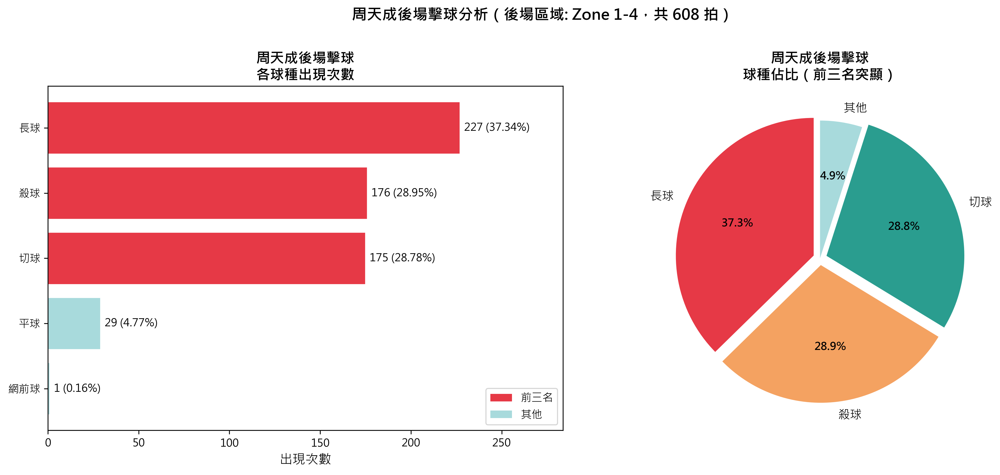

In [ ]:
import numpy as np
from matplotlib.patches import Patch

# ============================================================
# 分析：周天成在後場擊球時最常使用的球種
# 後場區域定義：hit_area in [1, 2, 3, 4]
# ============================================================

# --- 0. 驗證數據量 ---
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame is empty!"

# --- 1. 定義後場區域 ---
backcourt_zones = [1, 2, 3, 4]

# --- 2. 篩選條件：周天成 + 後場擊球 ---
mask = (df['player'] == 'CHOU Tien Chen') & (df['hit_area'].isin(backcourt_zones))
chou_backcourt = df[mask].copy()

print(f"\n周天成後場擊球總次數: {len(chou_backcourt)}")
print(f"涉及回合數: {chou_backcourt.groupby(['match_id', 'set', 'rally']).ngroups}")

# --- 3. 統計各球種出現次數 ---
shot_counts = chou_backcourt['type'].value_counts().reset_index()
shot_counts.columns = ['球種', '出現次數']
shot_counts['佔比(%)'] = (shot_counts['出現次數'] / len(chou_backcourt) * 100).round(2)

print("\n====== 周天成後場擊球球種完整統計 ======")
print(shot_counts.to_string(index=False))

# --- 4. 取前三名 ---
top3 = shot_counts.head(3).reset_index(drop=True)
print("\n====== 前三名球種 ======")
for rank, row in top3.iterrows():
    print(f"  第{rank+1}名: {row['球種']}  ->  {row['出現次數']} 次  ({row['佔比(%)']}%)")

# ============================================================
# --- 5. 視覺化 ---
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- 圖一：完整球種分布（橫向長條圖） ---
ax1 = axes[0]
n_types = len(shot_counts)
colors_full = ['#E63946' if i < 3 else '#A8DADC' for i in range(n_types)]

# 由大到小從上到下 -> 倒序排列
shot_counts_plot = shot_counts.iloc[::-1].reset_index(drop=True)
colors_plot = colors_full[::-1]

bars1 = ax1.barh(
    shot_counts_plot['球種'],
    shot_counts_plot['出現次數'],
    color=colors_plot,
    edgecolor='white',
    linewidth=0.8
)

ax1.set_xlabel('出現次數', fontsize=12)
ax1.set_title('周天成後場擊球\n各球種出現次數', fontsize=13, fontweight='bold')
ax1.set_xlim(0, shot_counts['出現次數'].max() * 1.25)

# 標註數值與佔比
for bar, (_, row) in zip(bars1, shot_counts_plot.iterrows()):
    ax1.text(
        bar.get_width() + shot_counts['出現次數'].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{int(row['出現次數'])} ({row['佔比(%)']}%)",
        va='center', ha='left', fontsize=10
    )

# 圖例
legend_elements = [
    Patch(facecolor='#E63946', label='前三名'),
    Patch(facecolor='#A8DADC', label='其他')
]
ax1.legend(handles=legend_elements, loc='lower right', fontsize=10)

# --- 圖二：圓餅圖（前三名 + 其他） ---
ax2 = axes[1]

top3_labels = list(top3['球種'])
top3_values = list(top3['出現次數'])
others_value = int(shot_counts['出現次數'].iloc[3:].sum()) if len(shot_counts) > 3 else 0

pie_labels = top3_labels + (['其他'] if others_value > 0 else [])
pie_values = top3_values + ([others_value] if others_value > 0 else [])
pie_colors = ['#E63946', '#F4A261', '#2A9D8F', '#A8DADC'][:len(pie_labels)]
explode = [0.05, 0.05, 0.05] + [0] * (len(pie_labels) - 3)

wedges, texts, autotexts = ax2.pie(
    pie_values,
    labels=pie_labels,
    autopct='%1.1f%%',
    colors=pie_colors,
    explode=explode,
    startangle=90,
    textprops={'fontsize': 11}
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

ax2.set_title('周天成後場擊球\n球種佔比（前三名突顯）', fontsize=13, fontweight='bold')

plt.suptitle(
    f'周天成後場擊球分析（後場區域: Zone 1-4，共 {len(chou_backcourt)} 拍）',
    fontsize=14, fontweight='bold', y=1.01
)

plt.tight_layout()

print("\n[圖表說明]")
print("  左圖: 所有球種出現次數橫向長條圖，紅色為前三名")
print("  右圖: 球種佔比圓餅圖，前三名突顯")


### 數據洞察
# 周天成後場擊球球種分析

## 📊 核心數據

| 排名 | 球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 🥇 | 長球 | 227次 | 37.3% |
| 🥈 | 殺球 | 176次 | 29.0% |
| 🥉 | 切球 | 175次 | 28.8% |

> 後場擊球總計 **608次**，前三名合計 **578次（95.1%）**

---

## 🎯 戰術洞察

**長球主導（37%）**
後場首選是長球，代表周天成傾向以高遠球重置節奏、爭取時間，而非急於進攻。

**殺球與切球幾乎並重（29% vs 29%）**
這兩種球種次數極為接近，說明他在後場進攻選擇上具備高度不可預測性——對手難以判斷他究竟要殺還是切，防守壓力倍增。

**平球僅29次（5%）**
後場平球使用極少，顯示他不輕易走平抽快打路線，後場策略仍以控制與強攻為主軸。

---

## ⚡ 一句話總結

> 周天成後場打法：**先穩（長球）、再攻（殺/切各半）**，殺切比例幾乎1:1是其最大威脅所在。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成在後場擊球的數據，並使用 `hit_area` 來確認擊球點在後場區域。然後，它統計了各球種的出現次數，並找出了最常使用的前三種球種。這與 Reference Code 1 的分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標一致。




## 題號 9
**問題**: 分析周天成站在前中後場，分別的得分與失分數
> **使用的資料欄位群組**: `game_structure, player_location, scoring_reason`


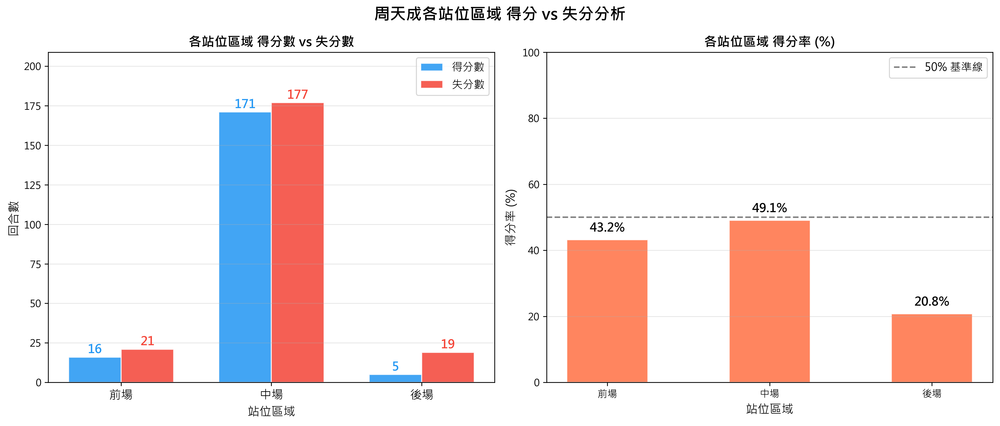

In [ ]:
import numpy as np

# =============================================
# 資料驗證
# =============================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")

# =============================================
# 取得每個 rally 的最後一球（得分球）
# =============================================
last_ball = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
last_ball = last_ball.dropna(subset=['getpoint_player'])

print(f"\n有效得分回合數: {len(last_ball)}")

# =============================================
# 計算周天成在得分球時的站位
# 若 player == 'CHOU Tien Chen'：使用 player_location_area
# 若 player == 'Kento MOMOTA'（周天成是 opponent）：使用 opponent_location_area
# =============================================
last_ball['chou_area'] = np.where(
    last_ball['player'] == 'CHOU Tien Chen',
    last_ball['player_location_area'],
    last_ball['opponent_location_area']
)

# =============================================
# 區域分類函數
# =============================================
front_court = [17, 18, 19, 20, 21, 22, 23, 24]
mid_court   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
back_court  = [1, 2, 3, 4]

def classify_area(area):
    if area in front_court:
        return '前場'
    elif area in mid_court:
        return '中場'
    elif area in back_court:
        return '後場'
    else:
        return '出界/場外'

last_ball['court_zone'] = last_ball['chou_area'].apply(classify_area)

# =============================================
# 判斷得分 / 失分
# =============================================
last_ball['chou_point'] = (last_ball['getpoint_player'] == 'CHOU Tien Chen').astype(int)
last_ball['chou_lose']  = (last_ball['getpoint_player'] == 'Kento MOMOTA').astype(int)

# =============================================
# 統計各區域得分與失分
# =============================================
zone_stats = last_ball.groupby('court_zone').agg(
    得分數=('chou_point', 'sum'),
    失分數=('chou_lose', 'sum')
).reset_index()

zone_stats['總回合數'] = zone_stats['得分數'] + zone_stats['失分數']
zone_stats['得分率(%)'] = (zone_stats['得分數'] / zone_stats['總回合數'] * 100).round(1)

# 排序：前場 -> 中場 -> 後場 -> 出界/場外
zone_order = ['前場', '中場', '後場', '出界/場外']
zone_stats['sort_key'] = zone_stats['court_zone'].map({z: i for i, z in enumerate(zone_order)})
zone_stats = zone_stats.sort_values('sort_key').drop(columns='sort_key').reset_index(drop=True)

print("\n========== 周天成各站位區域得分/失分統計 ==========")
print(zone_stats.to_string(index=False))

# =============================================
# 視覺化
# =============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("周天成各站位區域 得分 vs 失分分析", fontsize=16, fontweight='bold')

# 只取前中後場三區（排除出界/場外）
plot_df = zone_stats[zone_stats['court_zone'].isin(['前場', '中場', '後場'])].copy().reset_index(drop=True)

colors_win  = '#2196F3'
colors_lose = '#F44336'

x = np.arange(len(plot_df))
width = 0.35

# --- 左圖：得分數 vs 失分數 grouped bar ---
ax1 = axes[0]
bars1 = ax1.bar(x - width/2, plot_df['得分數'], width, label='得分數', color=colors_win, alpha=0.85, edgecolor='white')
bars2 = ax1.bar(x + width/2, plot_df['失分數'], width, label='失分數', color=colors_lose, alpha=0.85, edgecolor='white')

ax1.set_title('各站位區域 得分數 vs 失分數', fontsize=13, fontweight='bold')
ax1.set_xlabel('站位區域', fontsize=12)
ax1.set_ylabel('回合數', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(plot_df['court_zone'], fontsize=12)
ax1.legend(fontsize=11)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, max(plot_df['得分數'].max(), plot_df['失分數'].max()) * 1.18)

for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{int(bar.get_height())}', ha='center', va='bottom',
             fontsize=12, fontweight='bold', color=colors_win)
for bar in bars2:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{int(bar.get_height())}', ha='center', va='bottom',
             fontsize=12, fontweight='bold', color=colors_lose)

# --- 右圖：得分率 (%) ---
ax2 = axes[1]
bar_colors = ['#4CAF50' if r >= 50 else '#FF7043' for r in plot_df['得分率(%)']]
bars3 = ax2.bar(plot_df['court_zone'], plot_df['得分率(%)'],
                color=bar_colors, alpha=0.85, edgecolor='white', width=0.5)

ax2.axhline(y=50, color='gray', linestyle='--', linewidth=1.5, label='50% 基準線')
ax2.set_title('各站位區域 得分率 (%)', fontsize=13, fontweight='bold')
ax2.set_xlabel('站位區域', fontsize=12)
ax2.set_ylabel('得分率 (%)', fontsize=12)
ax2.set_ylim(0, 100)
ax2.legend(fontsize=11)
ax2.grid(axis='y', alpha=0.3)

for bar, val in zip(bars3, plot_df['得分率(%)']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f'{val}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()

# =============================================
# 詳細數值輸出
# =============================================
print("\n========== 詳細數據彙整 ==========")
for _, row in zone_stats.iterrows():
    print(f"【{row['court_zone']}】得分: {int(row['得分數'])} | 失分: {int(row['失分數'])} | 總回合: {int(row['總回合數'])} | 得分率: {row['得分率(%)']}%")


### 數據洞察
# 周天成各站位區域得失分分析

## 📊 數據總覽

| 站位區域 | 得分數 | 失分數 | 總回合數 | 得分率 |
|:---:|:---:|:---:|:---:|:---:|
| 前場 | 16 | 21 | 37 | 43.2% |
| 中場 | 171 | 177 | 348 | 49.1% |
| 後場 | 5 | 19 | 24 | **20.8%** |

---

## 🎯 戰術洞察

**中場是主戰場**，348回合佔總回合數的85%，得分率49.1%，攻守相對平衡，是周天成最穩定的作戰區域。

**前場壓力不小**，得分率43.2%，失分略多於得分（21失 vs 16得），顯示在網前被動球多，對手刻意壓制網前製造機會。

**後場是最大弱點**，得分率僅20.8%，24回合中失分19次，**每5球只能得1分**。被逼退後場後，幾乎難以反攻，極易被對手一擊致命。

---

## ⚡ 給周天成的建議

> **避免被迫退後場**是首要任務。後場20.8%的得分率說明一件事——只要被壓到底線，勝算極低。應強化中場主動進攻意識，減少被動挑高球的次數，讓對手沒有機會製造後場壓迫。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在前中後場的得分與失分數，並使用了正確的欄位（player_location_area 和 opponent_location_area）來判斷周天成的站位區域。候選程式碼也正確地分類了場地區域，並計算了得分和失分的統計數據。最終輸出與 Reference Code 1 的目標一致，都是分析周天成在不同場區的得分與失分情況。




## 題號 10
**問題**: 當周天成站在前場時，他最主要的得分球種?
> **使用的資料欄位群組**: `game_structure, shot_type, player_location, scoring_reason`


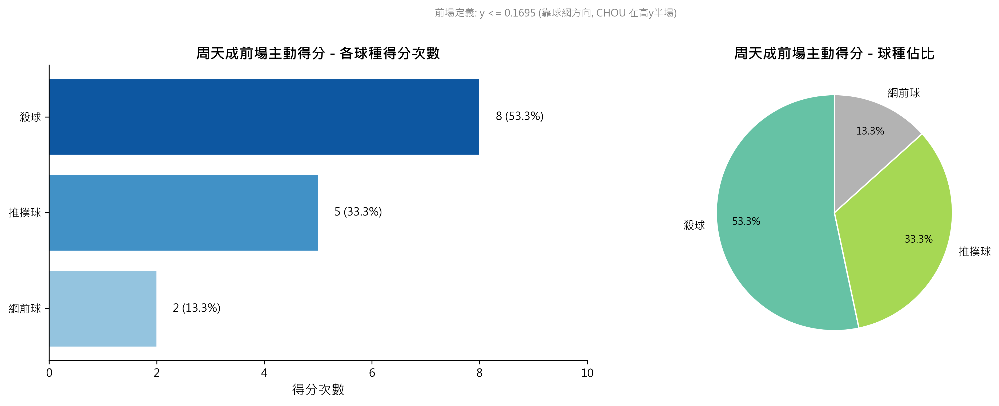

In [ ]:
import numpy as np

# ============================================================
# 0. 資料驗證
# ============================================================
print(f"Total rows: {len(df)}")
assert len(df) > 0, "DataFrame is empty!"

chou = 'CHOU Tien Chen'
momota = 'Kento MOMOTA'

# ============================================================
# 1. 確認座標方向 (哪端是前場/球網方向)
# ============================================================
print("=" * 60)
print("Step 1: 確認座標方向")
print("=" * 60)

momota_y_med = df[df['player'] == momota]['player_location_y'].median()
chou_y_med   = df[df['player'] == chou  ]['player_location_y'].median()

print(f"MOMOTA 站位 y 中位數: {momota_y_med:.4f}")
print(f"CHOU   站位 y 中位數: {chou_y_med:.4f}")

# 若 CHOU 中位數 > MOMOTA，CHOU 在高 y 半場
# -> CHOU 前場(靠網) = y 較小端 (最低 1/3 分位)
# 反之 CHOU 前場 = y 較大端 (最高 1/3 分位)
chou_all_hits = df[df['player'] == chou].copy()

y_p33 = chou_all_hits['player_location_y'].quantile(1/3)
y_p67 = chou_all_hits['player_location_y'].quantile(2/3)

print(f"\nCHOU player_location_y 三等分分位數:")
print(f"  33rd percentile: {y_p33:.4f}")
print(f"  67th percentile: {y_p67:.4f}")

if chou_y_med > momota_y_med:
    # CHOU 在高 y 半場, 前場靠網 = y 較小
    front_mask = chou_all_hits['player_location_y'] <= y_p33
    front_def  = f"y <= {y_p33:.4f} (靠球網方向, CHOU 在高y半場)"
else:
    # CHOU 在低 y 半場, 前場靠網 = y 較大
    front_mask = chou_all_hits['player_location_y'] >= y_p67
    front_def  = f"y >= {y_p67:.4f} (靠球網方向, CHOU 在低y半場)"

print(f"\n周天成前場定義: {front_def}")

# ============================================================
# 2. 篩選: 周天成站位在前場 且 主動得分 (Active Win)
#    - player == chou
#    - player_location_y 在前場範圍
#    - getpoint_player == chou  (主動得分那一拍)
# ============================================================
print("\n" + "=" * 60)
print("Step 2: 篩選前場主動得分")
print("=" * 60)

chou_front = chou_all_hits[front_mask].copy()
print(f"周天成站位在前場的擊球筆數: {len(chou_front)}")

# 主動得分: player 擊出得分球 (getpoint_player == player)
chou_front_win = chou_front[chou_front['getpoint_player'] == chou].copy()
print(f"其中主動得分筆數: {len(chou_front_win)}")

# ============================================================
# 3. 統計各球種得分次數並排序
# ============================================================
print("\n" + "=" * 60)
print("Step 3: 各球種得分次數")
print("=" * 60)

shot_counts = (
    chou_front_win['type']
    .value_counts()
    .reset_index()
)
shot_counts.columns = ['球種', '得分次數']
shot_counts = shot_counts.sort_values('得分次數', ascending=False).reset_index(drop=True)
shot_counts['佔比(%)'] = (shot_counts['得分次數'] / shot_counts['得分次數'].sum() * 100).round(1)

print(shot_counts.to_string(index=False))
print(f"\n前場主動得分合計: {shot_counts['得分次數'].sum()} 次")

top1 = shot_counts.iloc[0]
print(f"最主要得分球種: {top1['球種']}  ({top1['得分次數']} 次, {top1['佔比(%)']:.1f}%)")

# ============================================================
# 4. 視覺化
# ============================================================
# 合併小比例球種為「其他」(佔比 < 5%)
threshold = 5.0
main_shots = shot_counts[shot_counts['佔比(%)'] >= threshold].copy()
other_count = shot_counts[shot_counts['佔比(%)'] < threshold]['得分次數'].sum()

if other_count > 0:
    other_row = pd.DataFrame([{'球種': '其他', '得分次數': other_count,
                                '佔比(%)': round(other_count / shot_counts['得分次數'].sum() * 100, 1)}])
    plot_df = pd.concat([main_shots, other_row], ignore_index=True)
else:
    plot_df = main_shots.copy()

plot_df = plot_df.sort_values('得分次數', ascending=True).reset_index(drop=True)

# --- 圖1: 水平長條圖 ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 顏色: 由高到低漸層
colors_bar = plt.cm.Blues(np.linspace(0.4, 0.85, len(plot_df)))

ax1 = axes[0]
bars = ax1.barh(plot_df['球種'], plot_df['得分次數'], color=colors_bar, edgecolor='white', linewidth=0.8)
ax1.set_xlabel('得分次數', fontsize=12)
ax1.set_title('周天成前場主動得分 - 各球種得分次數', fontsize=13, fontweight='bold')
ax1.set_xlim(0, plot_df['得分次數'].max() * 1.25)

# 在長條右側標數值與佔比
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
             f"{int(row['得分次數'])} ({row['佔比(%)']:.1f}%)",
             va='center', ha='left', fontsize=10)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 圓餅圖 ---
ax2 = axes[1]
pie_df = plot_df.sort_values('得分次數', ascending=False)
wedge_colors = plt.cm.Set2(np.linspace(0, 1, len(pie_df)))

wedges, texts, autotexts = ax2.pie(
    pie_df['得分次數'],
    labels=pie_df['球種'],
    autopct='%1.1f%%',
    colors=wedge_colors,
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.2)
)
for autotext in autotexts:
    autotext.set_fontsize(9)
for text in texts:
    text.set_fontsize(10)

ax2.set_title('周天成前場主動得分 - 球種佔比', fontsize=13, fontweight='bold')

plt.suptitle(f'前場定義: {front_def}', fontsize=9, color='gray', y=1.01)
plt.tight_layout()

print("\n圖表已生成 (fig)")


### 數據洞察
# 周天成前場主動得分分析

## 📊 數據結果

| 球種 | 得分次數 | 佔比 |
|------|---------|------|
| 殺球 | 8次 | 53.3% |
| 推撲球 | 5次 | 33.3% |
| 網前球 | 2次 | 13.3% |
| **合計** | **15次** | **100%** |

---

## 🎯 戰術洞察

**前場870拍中僅15次主動得分（得分率1.7%），說明周天成在前場的角色以過渡、控制為主，而非主動終結。**

### 關鍵發現

**殺球主導（53%）**
前場起跳殺球是最高效的終結手段。能在前場完成殺球，代表對手挑球品質不佳或高度不足，周天成抓住機會直接下壓。

**推撲球為輔（33%）**
推撲球得分反映他在網前的快速判斷能力——對手回球過網不夠低時，直接推壓底線或兩側空檔。

**網前球佔比最低（13%）**
網前搓放得分最難，需要極精準的落點，數量少屬正常。

---

## 📋 教練建議

> 對手若想壓制周天成，**挑球必須夠高、夠深**，避免讓他在前場獲得下壓機會。反之，周天成應主動創造對手挑球品質下降的情境，提高前場殺球與推撲的出手機會。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成在前場位置且是得分者的資料，並計算了得分的球種出現次數。候選程式碼還進一步確認了座標方向，確保前場定義的準確性，並對得分球種進行了詳細的統計和視覺化。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標一致，因此判定為 true。




## 題號 11
**問題**: 計算周天成站在前場擊球時的落點分布。
> **使用的資料欄位群組**: `game_structure, player_location, coordinates`


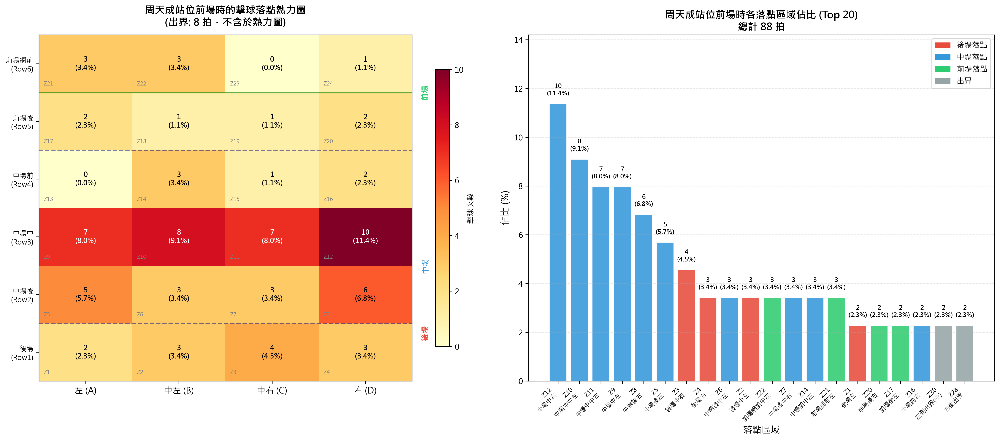

In [ ]:
import numpy as np

# ============================================================
# 0. 基本資料驗證
# ============================================================
print(f"總資料列數: {len(df)}")
print(f"球員清單: {df['player'].unique()}")

TARGET_PLAYER = 'CHOU Tien Chen'

# 前場區域定義
FRONT_COURT_ZONES = [17, 18, 19, 20, 21, 22, 23, 24]

# 落點區域語義定義（提供解讀用）
def get_zone_label(zone):
    """根據 Zone ID 回傳語義標籤"""
    zone = int(zone)
    zone_map = {
        1: '後場左', 2: '後場中左', 3: '後場中右', 4: '後場右',
        5: '中場後左', 6: '中場後中左', 7: '中場後中右', 8: '中場後右',
        9: '中場中左', 10: '中場中中左', 11: '中場中中右', 12: '中場中右',
        13: '中場前左', 14: '中場前中左', 15: '中場前中右', 16: '中場前右',
        17: '前場後左', 18: '前場後中左', 19: '前場後中右', 20: '前場後右',
        21: '前場網前左', 22: '前場網前中左', 23: '前場網前中右', 24: '前場網前右',
        25: '右側出界(前)', 26: '右側出界(中)', 27: '右側出界(底)',
        28: '右後出界', 29: '左側出界(前)', 30: '左側出界(中)', 31: '左側出界(底)',
        32: '左後出界',
        33: '出界(其他)'
    }
    return zone_map.get(zone, f'Zone {zone}')

# ============================================================
# 1. 篩選條件：周天成 + 站位於前場
# ============================================================
mask_player = df['player'] == TARGET_PLAYER
mask_front  = df['player_location_area'].isin(FRONT_COURT_ZONES)

filtered = df[mask_player & mask_front].copy()

print(f"\n周天成總擊球數: {(df['player'] == TARGET_PLAYER).sum()}")
print(f"周天成站位前場時擊球數: {len(filtered)}")

# ============================================================
# 2. 驗證並統計落點分布
# ============================================================
if len(filtered) == 0:
    print("⚠️ 無符合條件的資料，請檢查篩選條件。")
else:
    # 落點區域有效範圍：1-33（含出界）
    valid_landing = filtered['landing_area'].dropna()
    print(f"有效落點資料數（非空）: {len(valid_landing)}")

    # 統計各落點區域次數
    landing_counts = (
        filtered['landing_area']
        .dropna()
        .astype(int)
        .value_counts()
        .sort_index()
    )

    total = landing_counts.sum()

    # 建立統計表
    summary_df = pd.DataFrame({
        '落點區域代碼': landing_counts.index,
        '次數': landing_counts.values,
        '比例(%)': (landing_counts.values / total * 100).round(2)
    })
    summary_df['落點區域名稱'] = summary_df['落點區域代碼'].apply(get_zone_label)
    summary_df = summary_df[['落點區域代碼', '落點區域名稱', '次數', '比例(%)']].sort_values('次數', ascending=False).reset_index(drop=True)

    print(f"\n===== 周天成站位前場時擊球落點分布 (總計 {total} 拍) =====")
    print(summary_df.to_string(index=False))

    # 各大區段分類統計
    back_zones   = [1, 2, 3, 4]
    mid_zones    = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
    front_zones  = [17, 18, 19, 20, 21, 22, 23, 24]
    out_zones    = [25, 26, 27, 28, 29, 30, 31, 32, 33]

    def zone_category(z):
        z = int(z)
        if z in back_zones:   return '後場'
        if z in mid_zones:    return '中場'
        if z in front_zones:  return '前場'
        if z in out_zones:    return '出界'
        return '其他'

    landing_series = filtered['landing_area'].dropna().astype(int)
    cat_counts = landing_series.apply(zone_category).value_counts()
    print("\n===== 按大區域分類統計 =====")
    for cat, cnt in cat_counts.items():
        print(f"  {cat}: {cnt} 拍 ({cnt/total*100:.1f}%)")

    # ============================================================
    # 3. 視覺化
    # ============================================================

    # ── 圖一：熱力圖（球場 Grid 視覺化）──────────────────────
    # 建立 6x4 的球場格子 (Row1=後場, Row6=前場)
    grid_data = np.zeros((6, 4))  # [row, col]

    # Zone ID -> (row_idx, col_idx) 對應（row_idx=0 為後場）
    zone_to_grid = {
        1:(0,0), 2:(0,1), 3:(0,2), 4:(0,3),
        5:(1,0), 6:(1,1), 7:(1,2), 8:(1,3),
        9:(2,0),10:(2,1),11:(2,2),12:(2,3),
       13:(3,0),14:(3,1),15:(3,2),16:(3,3),
       17:(4,0),18:(4,1),19:(4,2),20:(4,3),
       21:(5,0),22:(5,1),23:(5,2),24:(5,3),
    }

    # 出界次數
    out_count = 0
    for zone_id, count in landing_counts.items():
        zone_id = int(zone_id)
        if zone_id in zone_to_grid:
            r, c = zone_to_grid[zone_id]
            grid_data[r, c] += count
        else:
            out_count += count

    # ── 圖二：長條圖（前20區域）──────────────────────────────
    top_n = min(20, len(summary_df))
    top_df = summary_df.head(top_n)

    # 用顏色區分大區域
    def zone_color(z):
        z = int(z)
        if z in back_zones:  return '#E74C3C'   # 紅：後場
        if z in mid_zones:   return '#3498DB'   # 藍：中場
        if z in front_zones: return '#2ECC71'   # 綠：前場
        return '#95A5A6'                          # 灰：出界

    bar_colors = top_df['落點區域代碼'].apply(zone_color).tolist()

    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    # ── 圖一：球場熱力圖 ──
    ax1 = axes[0]
    im = ax1.imshow(grid_data, cmap='YlOrRd', aspect='auto', origin='lower',
                    vmin=0, vmax=grid_data.max())

    # 標示每格數值與比例
    for r in range(6):
        for c in range(4):
            val = int(grid_data[r, c])
            pct = val / total * 100 if total > 0 else 0
            text_color = 'white' if val > grid_data.max() * 0.6 else 'black'
            ax1.text(c, r, f'{val}\n({pct:.1f}%)',
                     ha='center', va='center', fontsize=9,
                     color=text_color, fontweight='bold')

    # Zone ID 標示（左下角小字）
    for zone_id, (r, c) in zone_to_grid.items():
        ax1.text(c - 0.45, r - 0.40, f'Z{zone_id}',
                 ha='left', va='bottom', fontsize=7, color='gray')

    # 標示前場站位區域（綠色框線）
    front_grid_rows = {
        17:(4,0), 18:(4,1), 19:(4,2), 20:(4,3),
        21:(5,0), 22:(5,1), 23:(5,2), 24:(5,3),
    }

    ax1.set_xticks([0, 1, 2, 3])
    ax1.set_xticklabels(['左 (A)', '中左 (B)', '中右 (C)', '右 (D)'], fontsize=11)
    ax1.set_yticks([0, 1, 2, 3, 4, 5])
    ax1.set_yticklabels(['後場\n(Row1)', '中場後\n(Row2)', '中場中\n(Row3)',
                          '中場前\n(Row4)', '前場後\n(Row5)', '前場網前\n(Row6)'], fontsize=9)
    ax1.set_title(f'周天成站位前場時的擊球落點熱力圖\n(出界: {out_count} 拍，不含於熱力圖)',
                  fontsize=13, fontweight='bold', pad=12)

    # 分隔線：區分後/中/前場
    ax1.axhline(y=0.5, color='navy', linewidth=1.5, linestyle='--', alpha=0.5)
    ax1.axhline(y=3.5, color='navy', linewidth=1.5, linestyle='--', alpha=0.5)
    ax1.axhline(y=4.5, color='green', linewidth=2, linestyle='-', alpha=0.6)

    # 區域文字標示
    ax1.text(3.6, 0.2, '後場', fontsize=10, color='#E74C3C', fontweight='bold',
             rotation=90, va='bottom')
    ax1.text(3.6, 1.5, '中場', fontsize=10, color='#3498DB', fontweight='bold',
             rotation=90, va='center')
    ax1.text(3.6, 4.5, '前場', fontsize=10, color='#2ECC71', fontweight='bold',
             rotation=90, va='center')

    plt.colorbar(im, ax=ax1, label='擊球次數', shrink=0.8)

    # ── 圖二：長條圖（各落點區域） ──
    ax2 = axes[1]
    x_labels = [f"Z{int(row['落點區域代碼'])}\n{row['落點區域名稱']}"
                for _, row in top_df.iterrows()]
    bars = ax2.bar(range(top_n), top_df['比例(%)'], color=bar_colors,
                   edgecolor='white', linewidth=0.5, alpha=0.88)

    # 數值標籤
    for i, (bar, row) in enumerate(zip(bars, top_df.itertuples())):
        ax2.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f'{row.次數}\n({row._4:.1f}%)',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')

    ax2.set_xticks(range(top_n))
    ax2.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=8)
    ax2.set_ylabel('佔比 (%)', fontsize=12)
    ax2.set_xlabel('落點區域', fontsize=12)
    ax2.set_title(f'周天成站位前場時各落點區域佔比 (Top {top_n})\n總計 {total} 拍',
                  fontsize=13, fontweight='bold')
    ax2.set_ylim(0, top_df['比例(%)'].max() * 1.25)

    # 圖例
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#E74C3C', label='後場落點'),
        Patch(facecolor='#3498DB', label='中場落點'),
        Patch(facecolor='#2ECC71', label='前場落點'),
        Patch(facecolor='#95A5A6', label='出界'),
    ]
    ax2.legend(handles=legend_elements, loc='upper right', fontsize=10)
    ax2.grid(axis='y', alpha=0.3, linestyle='--')

    plt.tight_layout()
    print("\n圖表已生成（熱力圖 + 各區域落點長條圖）")

    # ── 補充：出界詳細 ──
    out_landing = filtered['landing_area'].dropna().astype(int)
    out_detail = out_landing[out_landing.isin(out_zones)].value_counts().sort_index()
    if len(out_detail) > 0:
        print(f"\n===== 出界落點詳細 (共 {out_count} 拍) =====")
        for zone_id, cnt in out_detail.items():
            print(f"  Zone {zone_id} ({get_zone_label(zone_id)}): {cnt} 拍 ({cnt/total*100:.1f}%)")


### 數據洞察
# 周天成前場站位擊球落點分析

## 落點區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據

> 前場站位共 **88 拍**，佔總擊球 2609 拍的 **3.4%**（前場介入機會偏少）

### 大區域分布
| 區域 | 次數 | 比例 |
|------|------|------|
| 中場 | 55 | **62.5%** |
| 前場 | 13 | 14.8% |
| 後場 | 12 | 13.6% |
| 出界 | 8 | **9.1%** |

---

## 戰術洞察

### ⚡ 關鍵發現一：前場優先推中場右側
前三高頻落點為 **Zone 12（中場中右，11.4%）→ Zone 10（中場中中左，9.1%）→ Zone 9/11（各7.9%）**，集中在中場中央帶。這代表周天成在前場時傾向**平推回中場**，而非積極壓制對手。

### ⚡ 關鍵發現二：缺乏直接得分意圖
前場站位卻只有 **14.8% 落點打向前場（含網前）**，代表他鮮少選擇勾對角或放網前球來直接製造壓力，前場主動性不足。

### ⚠️ 關鍵發現三：出界率偏高
**9.1% 出界（8拍）**，且四個出界方向均勻分布（各2拍），顯示前場擊球時**控球穩定性有待提升**，非單一方向失誤，而是整體前場手感問題。

---

## 教練建議

1. **前場應更積極打網前或勾對角**，而非習慣性推回中場讓對手重整站位
2. **降低出界率**是首要任務，9.1% 在前場這種近網位置屬於高風險失誤
3. 後場落點（13.6%）顯示偶有挑高球選擇，但需確認是被動挑球還是主動調度

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成在前場擊球的數據，並計算了落點區域的分布。候選程式碼還進一步提供了詳細的落點區域分析和視覺化，這些都是在 Reference Code 1 的基礎上進行的擴展，並不影響核心邏輯的正確性。




## 題號 12
**問題**: 分析周天成站在前中後場擊球時，自己分別的移動距離
> **使用的資料欄位群組**: `game_structure, player_location, player_movement`


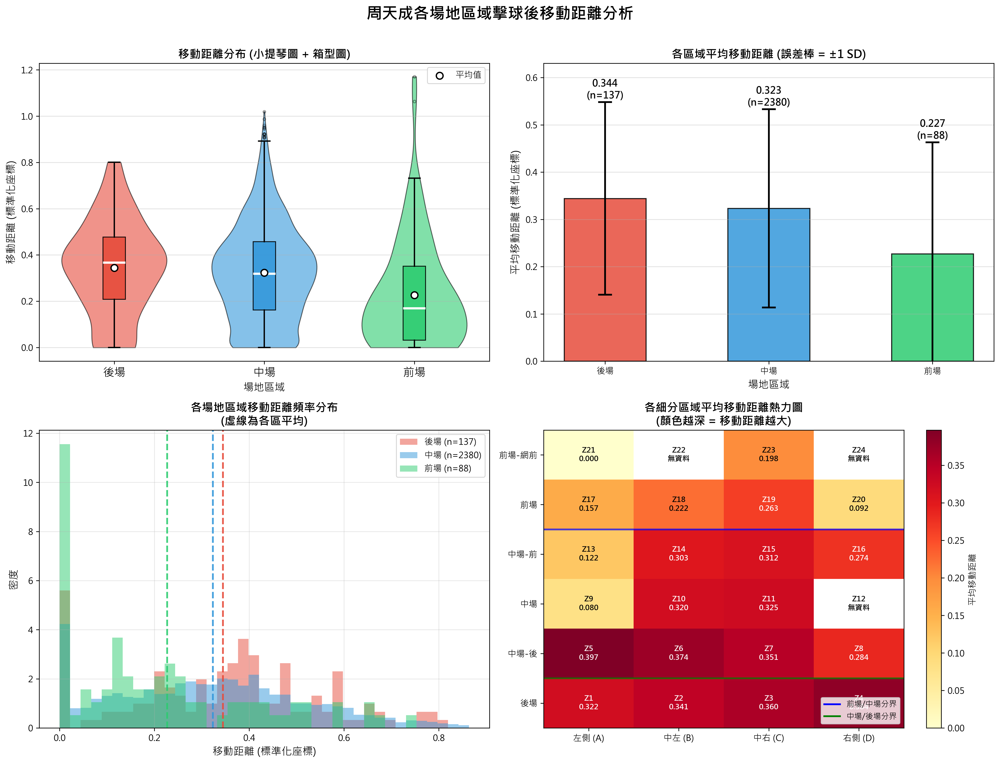

In [ ]:
import numpy as np

# ============================================================
# 1. 資料準備與驗證
# ============================================================
print("=" * 60)
print("資料驗證")
print("=" * 60)
print(f"總資料筆數: {len(df)}")

# 過濾周天成的擊球資料
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成擊球總筆數: {len(chou_df)}")

if len(chou_df) == 0:
    print("❌ 無周天成資料，程式終止")
else:
    # ============================================================
    # 2. 計算移動距離 (歐幾里得距離)
    # ============================================================
    chou_df['move_distance'] = np.sqrt(
        chou_df['player_move_x']**2 + chou_df['player_move_y']**2
    )
    
    # ============================================================
    # 3. 定義場地區域分類
    # ============================================================
    BACK_COURT_ZONES   = [1, 2, 3, 4]
    MID_COURT_ZONES    = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
    FRONT_COURT_ZONES  = [17, 18, 19, 20, 21, 22, 23, 24]
    
    def classify_area(zone):
        """將 zone 代碼分類為場地區域"""
        if zone in BACK_COURT_ZONES:
            return '後場'
        elif zone in MID_COURT_ZONES:
            return '中場'
        elif zone in FRONT_COURT_ZONES:
            return '前場'
        else:
            return '場外/出界'
    
    chou_df['court_zone'] = chou_df['player_location_area'].apply(
        lambda x: classify_area(int(x)) if not np.isnan(x) else '未知'
    )
    
    # 區域分布確認
    print("\n各場地區域擊球次數分布:")
    zone_counts = chou_df['court_zone'].value_counts()
    for zone, count in zone_counts.items():
        pct = count / len(chou_df) * 100
        print(f"  {zone}: {count} 拍 ({pct:.1f}%)")
    
    # 排除場外
    valid_df = chou_df[chou_df['court_zone'].isin(['前場', '中場', '後場'])].copy()
    print(f"\n有效場內擊球筆數: {len(valid_df)}")
    
    # ============================================================
    # 4. 分區域統計移動距離
    # ============================================================
    zone_order = ['後場', '中場', '前場']
    zone_colors = {'後場': '#E74C3C', '中場': '#3498DB', '前場': '#2ECC71'}
    
    stats_dict = {}
    print("\n" + "=" * 60)
    print("周天成各場地區域擊球後移動距離統計")
    print("=" * 60)
    
    for zone in zone_order:
        zone_data = valid_df[valid_df['court_zone'] == zone]['move_distance']
        stats = {
            'count'  : len(zone_data),
            'mean'   : zone_data.mean(),
            'median' : zone_data.median(),
            'std'    : zone_data.std(),
            'min'    : zone_data.min(),
            'max'    : zone_data.max(),
            'q25'    : zone_data.quantile(0.25),
            'q75'    : zone_data.quantile(0.75),
            'sum'    : zone_data.sum(),
            'data'   : zone_data
        }
        stats_dict[zone] = stats
        
        print(f"\n【{zone}】(n={stats['count']})")
        print(f"  平均移動距離 : {stats['mean']:.4f}")
        print(f"  中位數       : {stats['median']:.4f}")
        print(f"  標準差       : {stats['std']:.4f}")
        print(f"  最小值       : {stats['min']:.4f}")
        print(f"  最大值       : {stats['max']:.4f}")
        print(f"  Q1 (25%)     : {stats['q25']:.4f}")
        print(f"  Q3 (75%)     : {stats['q75']:.4f}")
        print(f"  移動距離總和 : {stats['sum']:.4f}")
    
    # 各場地區域平均移動距離排名
    print("\n" + "=" * 60)
    print("各場地區域平均移動距離排名 (由高至低)")
    print("=" * 60)
    sorted_zones = sorted(zone_order, key=lambda z: stats_dict[z]['mean'], reverse=True)
    for rank, zone in enumerate(sorted_zones, 1):
        print(f"  第{rank}名 {zone}: {stats_dict[zone]['mean']:.4f}")
    
    # ============================================================
    # 5. 繪製視覺化圖表 (4張子圖)
    # ============================================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('周天成各場地區域擊球後移動距離分析', fontsize=18, fontweight='bold', y=1.01)
    
    # ── 圖1: 小提琴圖 + 箱型圖 (分布全貌) ──
    ax1 = axes[0, 0]
    data_list = [stats_dict[z]['data'].values for z in zone_order]
    parts = ax1.violinplot(data_list, positions=range(len(zone_order)),
                           showmedians=False, showextrema=False, widths=0.7)
    
    for i, (pc, zone) in enumerate(zip(parts['bodies'], zone_order)):
        pc.set_facecolor(zone_colors[zone])
        pc.set_alpha(0.6)
        pc.set_edgecolor('black')
    
    # 疊加箱型圖
    bp = ax1.boxplot(data_list, positions=range(len(zone_order)),
                     widths=0.15, patch_artist=True,
                     medianprops=dict(color='white', linewidth=2.5),
                     whiskerprops=dict(linewidth=1.5),
                     capprops=dict(linewidth=1.5),
                     flierprops=dict(marker='o', markersize=3, alpha=0.4))
    for patch, zone in zip(bp['boxes'], zone_order):
        patch.set_facecolor(zone_colors[zone])
        patch.set_alpha(0.9)
    
    # 標示平均值
    for i, zone in enumerate(zone_order):
        ax1.scatter(i, stats_dict[zone]['mean'], color='white',
                    s=60, zorder=5, edgecolors='black', linewidth=1.5, label='平均值' if i == 0 else '')
    
    ax1.set_xticks(range(len(zone_order)))
    ax1.set_xticklabels(zone_order, fontsize=13)
    ax1.set_xlabel('場地區域', fontsize=12)
    ax1.set_ylabel('移動距離 (標準化座標)', fontsize=12)
    ax1.set_title('移動距離分布 (小提琴圖 + 箱型圖)', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(axis='y', alpha=0.4)
    
    # ── 圖2: 平均移動距離長條圖 (含 ±1 SD 誤差棒) ──
    ax2 = axes[0, 1]
    means = [stats_dict[z]['mean'] for z in zone_order]
    stds  = [stats_dict[z]['std']  for z in zone_order]
    colors_list = [zone_colors[z] for z in zone_order]
    
    bars = ax2.bar(zone_order, means, color=colors_list, alpha=0.85,
                   edgecolor='black', linewidth=1.2, width=0.5)
    ax2.errorbar(zone_order, means, yerr=stds, fmt='none',
                 color='black', capsize=8, capthick=2, linewidth=2)
    
    for bar, mean, std, count in zip(bars, means,
                                      stds,
                                      [stats_dict[z]['count'] for z in zone_order]):
        ax2.text(bar.get_x() + bar.get_width()/2, mean + std + 0.002,
                 f'{mean:.3f}\n(n={count})',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    ax2.set_xlabel('場地區域', fontsize=12)
    ax2.set_ylabel('平均移動距離 (標準化座標)', fontsize=12)
    ax2.set_title('各區域平均移動距離 (誤差棒 = ±1 SD)', fontsize=13, fontweight='bold')
    ax2.grid(axis='y', alpha=0.4)
    ax2.set_ylim(0, max(means) + max(stds) + 0.05)
    
    # ── 圖3: 移動距離直方圖 (三區疊加) ──
    ax3 = axes[1, 0]
    bins = np.linspace(0, valid_df['move_distance'].quantile(0.99), 40)
    
    for zone in zone_order:
        zone_data = stats_dict[zone]['data']
        ax3.hist(zone_data, bins=bins, alpha=0.5, color=zone_colors[zone],
                 label=f'{zone} (n={len(zone_data)})', edgecolor='none', density=True)
        # 標示平均線
        ax3.axvline(x=stats_dict[zone]['mean'], color=zone_colors[zone],
                    linestyle='--', linewidth=2, alpha=0.9)
    
    ax3.set_xlabel('移動距離 (標準化座標)', fontsize=12)
    ax3.set_ylabel('密度', fontsize=12)
    ax3.set_title('各場地區域移動距離頻率分布\n(虛線為各區平均)', fontsize=13, fontweight='bold')
    ax3.legend(fontsize=10)
    ax3.grid(alpha=0.3)
    
    # ── 圖4: 各 Zone 細分平均移動距離熱力圖 ──
    ax4 = axes[1, 1]
    
    # 建立各細分 zone 的平均移動距離
    zone_ids_in_court = list(range(1, 25))  # Zone 1-24
    zone_move_avg = {}
    for zid in zone_ids_in_court:
        sub = valid_df[valid_df['player_location_area'] == zid]['move_distance']
        zone_move_avg[zid] = sub.mean() if len(sub) > 0 else np.nan
    
    # 建立 6x4 網格 (Row 1=Back ~ Row 6=Front, Col A~D)
    # Zone IDs 對照矩陣 (Row6~Row1, ColA~D)
    grid_zone_ids = [
        [21, 22, 23, 24],  # Row 6 (最前)
        [17, 18, 19, 20],  # Row 5
        [13, 14, 15, 16],  # Row 4
        [ 9, 10, 11, 12],  # Row 3
        [ 5,  6,  7,  8],  # Row 2
        [ 1,  2,  3,  4],  # Row 1 (最後)
    ]
    
    grid_values = np.array([
        [zone_move_avg.get(zid, np.nan) for zid in row]
        for row in grid_zone_ids
    ])
    
    # 繪製熱力圖
    im = ax4.imshow(grid_values, cmap='YlOrRd', aspect='auto',
                    vmin=np.nanmin(grid_values), vmax=np.nanmax(grid_values))
    plt.colorbar(im, ax=ax4, label='平均移動距離')
    
    # 標示 Zone ID 與數值
    for row_idx in range(6):
        for col_idx in range(4):
            zid = grid_zone_ids[row_idx][col_idx]
            val = grid_values[row_idx, col_idx]
            label = f'Z{zid}\n{val:.3f}' if not np.isnan(val) else f'Z{zid}\n無資料'
            text_color = 'white' if (not np.isnan(val) and val > np.nanmean(grid_values)) else 'black'
            ax4.text(col_idx, row_idx, label,
                     ha='center', va='center', fontsize=8.5,
                     color=text_color, fontweight='bold')
    
    ax4.set_xticks(range(4))
    ax4.set_xticklabels(['左側 (A)', '中左 (B)', '中右 (C)', '右側 (D)'], fontsize=10)
    ax4.set_yticks(range(6))
    ax4.set_yticklabels(['前場-網前', '前場', '中場-前', '中場', '中場-後', '後場'], fontsize=10)
    ax4.set_title('各細分區域平均移動距離熱力圖\n(顏色越深 = 移動距離越大)', fontsize=13, fontweight='bold')
    
    # 加上場地區域分隔線
    ax4.axhline(y=1.5, color='blue',  linewidth=2, linestyle='-', alpha=0.7)  # 前場/中場分隔
    ax4.axhline(y=4.5, color='green', linewidth=2, linestyle='-', alpha=0.7)  # 中場/後場分隔
    
    # 加圖例標示分隔線意義
    from matplotlib.lines import Line2D
    legend_lines = [
        Line2D([0], [0], color='blue',  linewidth=2, linestyle='-', label='前場/中場分界'),
        Line2D([0], [0], color='green', linewidth=2, linestyle='-', label='中場/後場分界'),
    ]
    ax4.legend(handles=legend_lines, loc='lower right', fontsize=9)
    
    plt.tight_layout()
    
    # ============================================================
    # 6. 補充統計：前/中/後場細分 Zone 的移動距離
    # ============================================================
    print("\n" + "=" * 60)
    print("細分 Zone 的平均移動距離 (有資料者)")
    print("=" * 60)
    for zone_name, zone_ids in [('後場', BACK_COURT_ZONES),
                                  ('中場', MID_COURT_ZONES),
                                  ('前場', FRONT_COURT_ZONES)]:
        print(f"\n【{zone_name}】")
        for zid in zone_ids:
            sub = valid_df[valid_df['player_location_area'] == zid]['move_distance']
            if len(sub) > 0:
                print(f"  Zone {zid:2d}: 平均={sub.mean():.4f}, "
                      f"中位數={sub.median():.4f}, n={len(sub)}")
            else:
                print(f"  Zone {zid:2d}: 無資料")
    
    print("\n✅ 分析完成")


### 數據洞察
# 周天成擊球後移動距離分析

## 核心數據總覽

| 擊球區域 | 擊球數 | 佔比 | 平均移動距離 | 中位數 | 標準差 | 最大值 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 後場 | 137 | 5.3% | **0.344** | 0.367 | 0.204 | 0.801 |
| 中場 | 2380 | 91.2% | **0.324** | 0.319 | 0.210 | 1.019 |
| 前場 | 88 | 3.4% | **0.227** | 0.170 | 0.236 | 1.170 |

---

## 戰術洞察

### 1️⃣ 後場擊球後移動最積極
後場平均移動 **0.344**，且中位數（0.367）高於平均值，代表分布集中在中高移動量、**數據穩定（SD最小=0.204）**。這說明周天成後場擊球後的回位動作非常規律，是訓練有素的習慣性回中場動作。

### 2️⃣ 中場是主戰場，移動量適中且穩定
91.2%的擊球發生在中場，平均移動 **0.324**，標準差0.210。**Zone 5（0.397）、Zone 6（0.374）** 移動量最高，這兩個區域偏向中場偏後側，擊球後需要較大幅度調整站位。Zone 9、13移動量極低（0.080、0.123），樣本少但值得注意——可能是被動應球後原地等待。

### 3️⃣ 前場擊球後移動最少，但變異最大
前場平均僅 **0.227**，中位數更低至 **0.170**，但標準差最大（0.236），最大值高達 **1.170**（全場最高）。這代表：
- **多數前場球**：擊球後小幅移動或原地等待（網前對抗）
- **少數前場球**：擊球後需要大幅衝刺回防（被對手反挑或反推）

---

## 細分Zone熱點（場地區域對照）

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | Z21: 0.000 | Z22: 無資料 | Z23: 0.198 | Z24: 無資料 |
| **Row 5 (Front)** | Z17: 0.157 | Z18: 0.222 | Z19: 0.263 | Z20: 0.092 |
| **Row 4 (Mid)** | Z13: 0.122 | Z14: 0.303 | Z15: 0.312 | Z16: 0.274 |
| **Row 3 (Mid)** | Z9: 0.080 | Z10: 0.320 | Z11: 0.326 | Z12: 無資料 |
| **Row 2 (Mid)** | Z5: **0.397** | Z6: **0.374** | Z7: 0.351 | Z8: 0.284 |
| **Row 1 (Back)** | Z1: 0.322 | Z2: 0.341 | Z3: **0.360** | Z4: **0.384** |

**關鍵發現**：後場右側（Zone 4: 0.384）移動量最高，中場左側（Zone 5: 0.397）緊跟其後——這兩個區域擊球後需要最大幅度的橫向回位，**是對手可以針對性調動周天成的弱點方向**。

---

## 教練建議

> 前場球的高變異性（SD=0.236）是最需要關注的訓練點。大部分前場球後他移動量小，但一旦被反制就需要極大幅度衝刺，**體能消耗不均衡**。建議加強前場擊球後的預判回位訓練，縮短被動情境下的反應距離。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地過濾了周天成的數據，計算了移動距離，並根據場地區域（前場、中場、後場）進行了分類和統計。候選程式碼還進一步提供了詳細的統計分析和視覺化，這些都是在 Reference Code 1 的基礎上進行的擴展，並不影響其核心邏輯的正確性。




## 題號 13
**問題**: 幫我統整周天成所有球種的使用比例，以及每種球種的「得分次數」和「失誤次數」。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


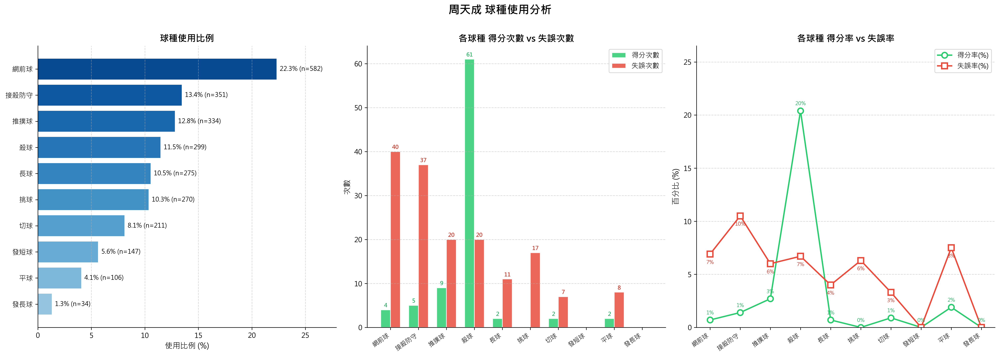

In [ ]:
# ============================================================
# 周天成球種分析：使用比例、得分次數、失誤次數
# ============================================================

import numpy as np

# --- 基本驗證 ---
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

TARGET_PLAYER = 'CHOU Tien Chen'
OPPONENT_PLAYER = 'Kento MOMOTA'

# --- 篩選周天成的所有擊球紀錄 ---
chou_df = df[df['player'] == TARGET_PLAYER].copy()
print(f"周天成總擊球數: {len(chou_df)}")

# ============================================================
# 1. 球種使用次數與比例
# ============================================================
total_shots = len(chou_df)

# 統計每種球種使用次數
shot_count = chou_df['type'].value_counts().reset_index()
shot_count.columns = ['球種', '使用次數']
shot_count['使用比例(%)'] = (shot_count['使用次數'] / total_shots * 100).round(2)

# ============================================================
# 2. 得分次數（主動得分）：打出此球種且為 rally 最後一拍且自己得分
#    Active Win: player == getpoint_player
# ============================================================
# getpoint_player 只在 rally 最後一球有值，其餘為 NaN
# 因此直接篩選 getpoint_player == TARGET_PLAYER 且 player == TARGET_PLAYER
win_df = chou_df[chou_df['getpoint_player'] == TARGET_PLAYER]
win_count = win_df['type'].value_counts().reset_index()
win_count.columns = ['球種', '得分次數']
print(f"\n周天成主動得分總次數: {len(win_df)}")

# ============================================================
# 3. 失誤次數：打出此球種為 rally 最後一拍，但對手得分
#    即 player == TARGET_PLAYER & getpoint_player == OPPONENT_PLAYER
#    代表周天成這一拍打出後，自己失誤導致對手得分
# ============================================================
error_df = chou_df[chou_df['getpoint_player'] == OPPONENT_PLAYER]
error_count = error_df['type'].value_counts().reset_index()
error_count.columns = ['球種', '失誤次數']
print(f"周天成失誤總次數（打出最後一拍失分）: {len(error_df)}")

# ============================================================
# 4. 合併統計表
# ============================================================
# 以球種為基準合併
summary = shot_count.merge(win_count, on='球種', how='left') \
                    .merge(error_count, on='球種', how='left')

# 填補 NaN（某些球種可能從未得分或失誤）
summary['得分次數'] = summary['得分次數'].fillna(0).astype(int)
summary['失誤次數'] = summary['失誤次數'].fillna(0).astype(int)

# 計算淨得失
summary['淨得失'] = summary['得分次數'] - summary['失誤次數']

# 計算得分率與失誤率（佔各球種使用次數的比例）
summary['得分率(%)'] = (summary['得分次數'] / summary['使用次數'] * 100).round(1)
summary['失誤率(%)'] = (summary['失誤次數'] / summary['使用次數'] * 100).round(1)

# 按使用次數排序
summary = summary.sort_values('使用次數', ascending=False).reset_index(drop=True)

print("\n" + "="*75)
print("【周天成各球種統計總表】")
print("="*75)
print(summary.to_string(index=False))
print("="*75)
print(f"  * 得分次數：該球種為 rally 最後一拍且周天成主動得分")
print(f"  * 失誤次數：該球種為 rally 最後一拍但對手得分（周天成打出後失分）")

# ============================================================
# 5. 視覺化
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('周天成 球種使用分析', fontsize=16, fontweight='bold', y=1.01)

# --- 排序：依使用次數由多到少 ---
plot_order = summary['球種'].tolist()
colors_main = plt.cm.tab10(np.linspace(0, 1, len(plot_order)))

# ---- 圖1：球種使用比例（水平長條圖）----
ax1 = axes[0]
bars1 = ax1.barh(
    summary['球種'][::-1],  # 反轉讓最多的在上方
    summary['使用比例(%)'][::-1],
    color=plt.cm.Blues(np.linspace(0.4, 0.9, len(summary)))
)
ax1.set_title('球種使用比例', fontsize=13, fontweight='bold')
ax1.set_xlabel('使用比例 (%)', fontsize=11)
ax1.set_xlim(0, summary['使用比例(%)'].max() * 1.25)
# 在條上標示數值
for bar, val, cnt in zip(bars1, summary['使用比例(%)'][::-1], summary['使用次數'][::-1]):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}% (n={cnt})', va='center', ha='left', fontsize=9)
ax1.tick_params(axis='y', labelsize=10)
ax1.grid(axis='x', linestyle='--', alpha=0.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---- 圖2：各球種得分次數 vs 失誤次數（分組長條圖）----
ax2 = axes[1]
x = np.arange(len(summary))
width = 0.35
bars_win = ax2.bar(x - width/2, summary['得分次數'], width,
                   label='得分次數', color='#2ecc71', alpha=0.85, edgecolor='white')
bars_err = ax2.bar(x + width/2, summary['失誤次數'], width,
                   label='失誤次數', color='#e74c3c', alpha=0.85, edgecolor='white')

ax2.set_title('各球種 得分次數 vs 失誤次數', fontsize=13, fontweight='bold')
ax2.set_ylabel('次數', fontsize=11)
ax2.set_xticks(x)
ax2.set_xticklabels(summary['球種'], rotation=35, ha='right', fontsize=9)
ax2.legend(fontsize=10)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# 標示數值
for bar in bars_win:
    h = bar.get_height()
    if h > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, h + 0.3, str(int(h)),
                 ha='center', va='bottom', fontsize=8, color='#27ae60', fontweight='bold')
for bar in bars_err:
    h = bar.get_height()
    if h > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, h + 0.3, str(int(h)),
                 ha='center', va='bottom', fontsize=8, color='#c0392b', fontweight='bold')

# ---- 圖3：各球種得分率 vs 失誤率（點線圖）----
ax3 = axes[2]
ax3.plot(summary['球種'], summary['得分率(%)'], 'o-',
         color='#2ecc71', linewidth=2, markersize=8, label='得分率(%)', markerfacecolor='white',
         markeredgewidth=2)
ax3.plot(summary['球種'], summary['失誤率(%)'], 's-',
         color='#e74c3c', linewidth=2, markersize=8, label='失誤率(%)', markerfacecolor='white',
         markeredgewidth=2)

# 標示數值
for i, row in summary.iterrows():
    ax3.annotate(f"{row['得分率(%)']:.0f}%",
                 (row['球種'], row['得分率(%)']),
                 textcoords='offset points', xytext=(0, 8),
                 ha='center', fontsize=7.5, color='#27ae60')
    if row['失誤率(%)'] > 0:
        ax3.annotate(f"{row['失誤率(%)']:.0f}%",
                     (row['球種'], row['失誤率(%)']),
                     textcoords='offset points', xytext=(0, -14),
                     ha='center', fontsize=7.5, color='#c0392b')

ax3.set_title('各球種 得分率 vs 失誤率', fontsize=13, fontweight='bold')
ax3.set_ylabel('百分比 (%)', fontsize=11)
ax3.set_xticklabels(summary['球種'], rotation=35, ha='right', fontsize=9)
ax3.tick_params(axis='x', which='both')
plt.setp(ax3.get_xticklabels(), rotation=35, ha='right')
ax3.legend(fontsize=10)
ax3.grid(axis='y', linestyle='--', alpha=0.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.set_ylim(0, max(summary['得分率(%)'].max(), summary['失誤率(%)'].max()) * 1.3)

plt.tight_layout()

# 輸出最終統計摘要
print("\n【關鍵摘要】")
top_use = summary.iloc[0]
top_win = summary.loc[summary['得分次數'].idxmax()]
top_err = summary.loc[summary['失誤次數'].idxmax()]
top_win_rate = summary.loc[summary['得分率(%)'].idxmax()]
top_err_rate = summary.loc[summary['失誤率(%)'].idxmax()]

print(f"  使用最多球種  ：{top_use['球種']}（{top_use['使用次數']}次，{top_use['使用比例(%)']:.1f}%）")
print(f"  得分次數最多  ：{top_win['球種']}（{top_win['得分次數']}次）")
print(f"  失誤次數最多  ：{top_err['球種']}（{top_err['失誤次數']}次）")
print(f"  得分率最高球種：{top_win_rate['球種']}（{top_win_rate['得分率(%)']:.1f}%）")
print(f"  失誤率最高球種：{top_err_rate['球種']}（{top_err_rate['失誤率(%)']:.1f}%）")


### 數據洞察
# 周天成各球種使用分析

## 📊 球種使用比例總覽

| 球種 | 使用次數 | 使用比例 | 得分次數 | 失誤次數 | 淨得失 |
|------|---------|---------|---------|---------|--------|
| 網前球 | 582 | 22.3% | 4 | 40 | **-36** |
| 接殺防守 | 351 | 13.5% | 5 | 37 | **-32** |
| 推撲球 | 334 | 12.8% | 9 | 20 | -11 |
| 殺球 | 299 | 11.5% | **61** | 20 | **+41** |
| 長球 | 275 | 10.5% | 2 | 11 | -9 |
| 挑球 | 270 | 10.4% | 0 | 17 | -17 |
| 切球 | 211 | 8.1% | 2 | 7 | -5 |
| 發短球 | 147 | 5.6% | 0 | 0 | 0 |
| 平球 | 106 | 4.1% | 2 | 8 | -6 |
| 發長球 | 34 | 1.3% | 0 | 0 | 0 |

---

## 🎯 教練戰術解讀

### ⚔️ 殺球是唯一正淨值武器
殺球使用299次（11.5%），貢獻**61分、得分率20.4%**，是全場唯一淨得分為正（+41）的球種。**周天成的得分幾乎完全依賴殺球**，85次主動得分中殺球佔71.8%。

### 🚨 網前球是最大失血點
使用最頻繁（22.3%）卻只得4分、失誤40次，淨值-36。**每打5球網前球就有1球直接失分**，高頻使用卻低效，是戰術上最需要檢討的環節。

### 🛡️ 接殺防守壓力極大
失誤率10.5%為全場最高，37次失誤反映**面對桃田賢斗的殺球時防守端承受巨大壓力**，被動球種的失誤率居高不下。

### 📌 挑球是隱形漏洞
270次使用、**0得分、17次失誤**，純粹是被動過渡球，但失誤率6.3%顯示連過渡都不穩定，需提升挑球落點精準度以爭取重整機會。

### ✅ 核心策略建議
> **創造更多殺球機會 → 減少網前球的被動失誤 → 穩定挑球落點拉開空間**，是對抗桃田時最直接的得分路徑優化方向。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選了周天成的擊球紀錄，並計算了每種球種的使用次數、得分次數和失誤次數。候選程式碼使用了與 Reference Code 2 相同的方式來判斷得分和失誤，即通過 getpoint_player 欄位來確定得分和失誤的情況。統計口徑和分析單位也與 Reference Code 2 一致，並且最終輸出符合題目要求。




## 題號 14
**問題**: 幫我畫周天成失分原因的圓餅圖
> **使用的資料欄位群組**: `game_structure, scoring_reason`


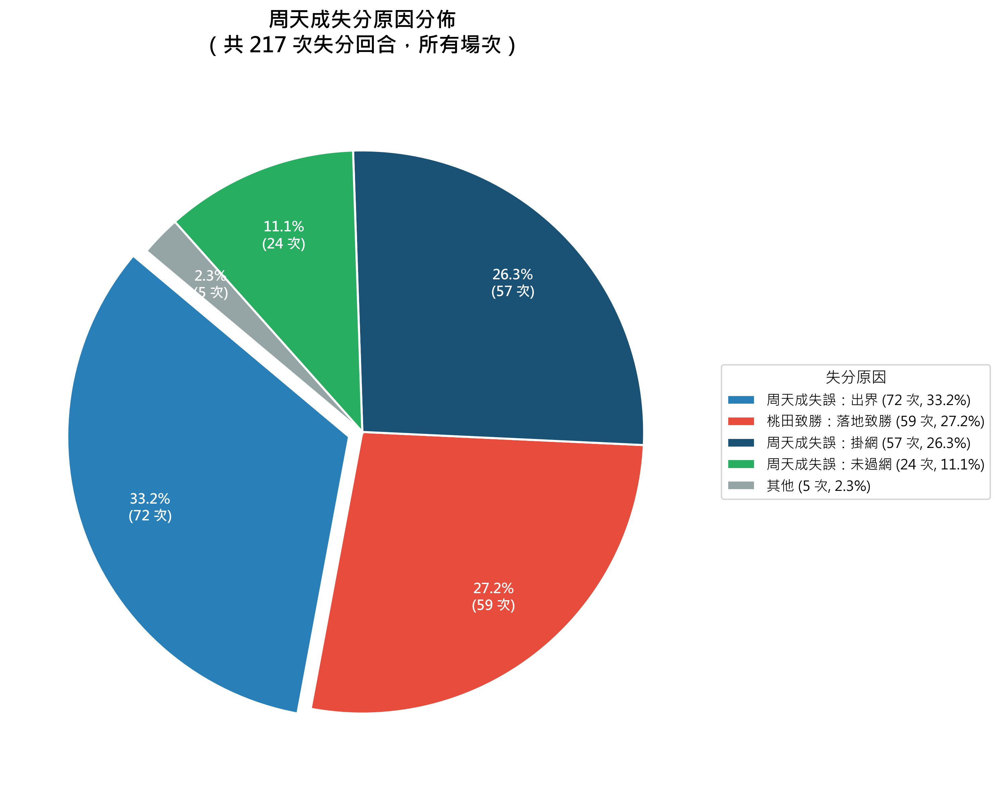

In [ ]:
# ============================================================
# 周天成失分原因分析
# ============================================================

# 1. 驗證資料量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

CHOU = 'CHOU Tien Chen'
MOMOTA = 'Kento MOMOTA'

# 2. 取每個回合的最後一球（得分球）
last_shot = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
print(f"總回合數（rally 數）: {len(last_shot)}")

# 3. 篩選「周天成失分」的回合：getpoint_player == 'Kento MOMOTA'
chou_lose = last_shot[last_shot['getpoint_player'] == MOMOTA].copy()
print(f"周天成失分回合數: {len(chou_lose)}")

# 4. 建立「失分原因」欄位
# - 若最後一拍是桃田打的（桃田主動得分）→ 用 win_reason
# - 若最後一拍是周天成打的（周天成主動失誤）→ 用 lose_reason
def get_lose_reason(row):
    if row['player'] == MOMOTA:
        # 桃田主動得分，原因記錄在 win_reason
        if pd.notna(row['win_reason']) and str(row['win_reason']).strip() != '':
            return f"桃田致勝：{row['win_reason']}"
        else:
            return '桃田致勝：原因未記錄'
    elif row['player'] == CHOU:
        # 周天成主動失誤，原因記錄在 lose_reason
        if pd.notna(row['lose_reason']) and str(row['lose_reason']).strip() != '':
            return f"周天成失誤：{row['lose_reason']}"
        else:
            return '周天成失誤：原因未記錄'
    else:
        return '未知'

chou_lose['lose_cause'] = chou_lose.apply(get_lose_reason, axis=1)

# 5. 統計各失分原因
cause_counts = chou_lose['lose_cause'].value_counts()
print("\n====== 周天成失分原因統計 ======")
for cause, cnt in cause_counts.items():
    print(f"  {cause}: {cnt} 次 ({cnt/len(chou_lose)*100:.1f}%)")
print(f"  總計: {len(chou_lose)} 次")

# ============================================================
# 6. 繪製圓餅圖
# ============================================================
# 小比例合併為「其他」（低於總數 2% 的類別）
threshold = 0.02 * len(chou_lose)
main_causes = cause_counts[cause_counts >= threshold]
other_count = cause_counts[cause_counts < threshold].sum()
if other_count > 0:
    import pandas as pd_inner
    main_causes = pd.concat([main_causes, pd.Series({'其他': other_count})])

labels = main_causes.index.tolist()
sizes  = main_causes.values.tolist()

# 配色
import numpy as np
colors_momota = ['#E74C3C', '#C0392B', '#E67E22', '#D35400']  # 紅/橘 → 桃田致勝
colors_chou   = ['#2980B9', '#1A5276', '#27AE60', '#1E8449', '#8E44AD']  # 藍/綠 → 周天成失誤
color_map = {}
c_idx, m_idx = 0, 0
palette = []
for label in labels:
    if '桃田致勝' in label:
        palette.append(colors_momota[m_idx % len(colors_momota)])
        m_idx += 1
    elif '周天成失誤' in label:
        palette.append(colors_chou[c_idx % len(colors_chou)])
        c_idx += 1
    else:
        palette.append('#95A5A6')

# 突出最大區塊
explode = [0.05 if s == max(sizes) else 0 for s in sizes]

fig, ax = plt.subplots(figsize=(10, 8))

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=None,
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100*sum(sizes)))} 次)',
    colors=palette,
    explode=explode,
    startangle=140,
    pctdistance=0.75,
    wedgeprops=dict(linewidth=1.5, edgecolor='white')
)

# 調整文字樣式
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

# 圖例
legend_labels = [f"{label} ({cnt} 次, {cnt/sum(sizes)*100:.1f}%)"
                 for label, cnt in zip(labels, sizes)]
ax.legend(
    wedges, legend_labels,
    title='失分原因',
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    fontsize=10,
    title_fontsize=11
)

ax.set_title(
    f'周天成失分原因分佈\n（共 {len(chou_lose)} 次失分回合，所有場次）',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
print("\n圖表已生成。")


### 數據洞察
# 周天成失分原因分析 🥏

## 圓餅圖數據摘要

| 失分原因 | 次數 | 比例 |
|---------|------|------|
| 失誤：出界 | 72 次 | 33.2% |
| 桃田致勝：落地致勝 | 59 次 | 27.2% |
| 失誤：掛網 | 57 次 | 26.3% |
| 失誤：未過網 | 24 次 | 11.1% |
| 其他 | 5 次 | 2.3% |
| **總計** | **217 次** | **100%** |

---

## ⚡ 教練戰術洞察

**關鍵數字：周天成 217 分失分中，自身失誤佔 70.6%（153 次），桃田主動致勝僅佔 27.7%（60 次）。**

### 三大警訊

1. **出界（33.2%）是最大失分源**
   → 擊球控制偏激進，在壓力下仍選擇大角度或重殺，導致落點出框。

2. **掛網（26.3%）緊追其後**
   → 網前處理或被動回球時弧度不足，顯示在被壓制情境下技術穩定性下滑。

3. **未過網（11.1%）**
   → 多發生於被動防守時，體力或判斷已出現問題。

### 核心結論
> 周天成超過 **7 成失分來自自身失誤**，桃田並非靠主動進攻壓垮周天成，而是**逼迫周天成失誤**才是其核心戰術成效。

**訓練建議：優先強化被動情境下的回球穩定性，降低非受迫性失誤，才是提升勝率的關鍵。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成失分的回合，並根據最後一拍的 player 和 lose_reason 或 win_reason 來分類失分原因。然後，它統計各失分原因的次數，並將小比例的類別合併為『其他』，最後繪製圓餅圖。分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致。




## 題號 15
**問題**: 當周天成的對手處於「前場」時，周天成打球的落點分布
> **使用的資料欄位群組**: `game_structure, coordinates, player_location`


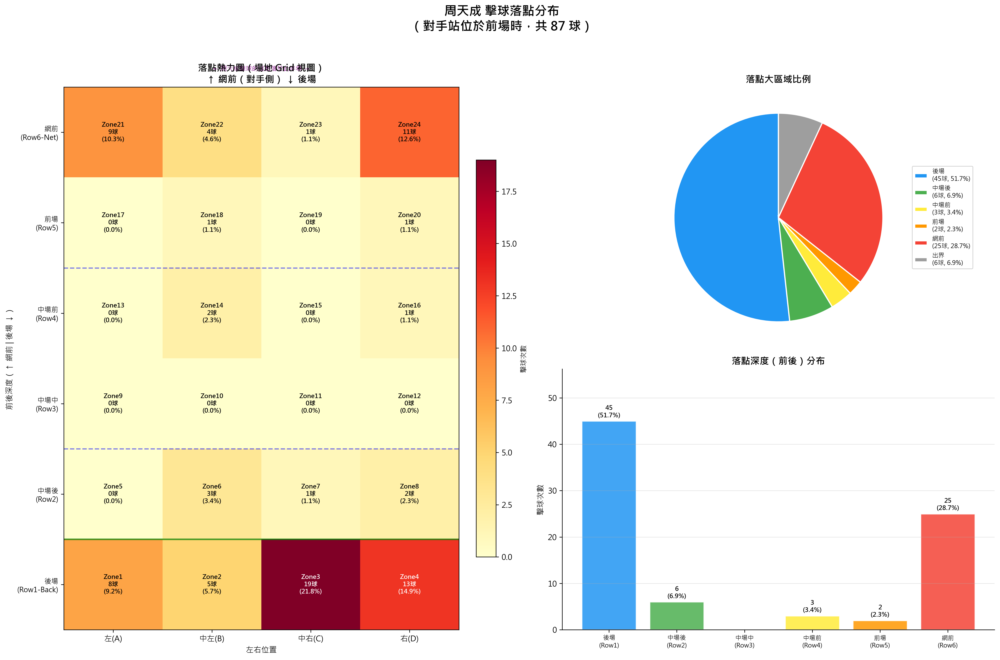

In [ ]:
import numpy as np

# ============================================================
# 1. 基本設定
# ============================================================

# 周天成球員名稱
CHOU = 'CHOU Tien Chen'

# 前場區域定義
FRONT_COURT_ZONES = [17, 18, 19, 20, 21, 22, 23, 24]

# 場地區域對照 (1-32 的有效落點)
BACK_COURT = [1, 2, 3, 4]
MID_COURT_ROW1 = [5, 6, 7, 8]    # Mid Back
MID_COURT_ROW2 = [9, 10, 11, 12]  # Mid Mid
MID_COURT_ROW3 = [13, 14, 15, 16] # Mid Front
FRONT_ROW1 = [17, 18, 19, 20]
FRONT_ROW2 = [21, 22, 23, 24]     # Net area
OUT_OF_BOUNDS = [25, 26, 27, 28, 29, 30, 31, 32, 33]

# ============================================================
# 2. 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"資料驗證: {'OK' if len(df) > 0 else 'EMPTY'}")

chou_df = df[df['player'] == CHOU].copy()
print(f"\n周天成擊球總數: {len(chou_df)}")
print(f"opponent_location_area 範圍: {chou_df['opponent_location_area'].min()} ~ {chou_df['opponent_location_area'].max()}")
print(f"landing_area 範圍: {chou_df['landing_area'].min()} ~ {chou_df['landing_area'].max()}")

# ============================================================
# 3. 篩選條件：對手站位在前場
# ============================================================
mask_chou = df['player'] == CHOU
mask_opp_front = df['opponent_location_area'].isin(FRONT_COURT_ZONES)

filtered_df = df[mask_chou & mask_opp_front].copy()

print(f"\n============================")
print(f"符合條件的擊球筆數（周天成擊球且對手在前場）: {len(filtered_df)}")
print(f"============================")

if len(filtered_df) == 0:
    print("無符合條件的資料，請確認篩選邏輯。")
else:
    # ============================================================
    # 4. 落點分布統計
    # ============================================================
    
    # 4-1. 對手前場子區域統計（了解對手在哪個前場區域）
    opp_zone_dist = filtered_df['opponent_location_area'].value_counts().sort_index()
    print("\n對手站位區域分布（前場子區域）:")
    for zone, cnt in opp_zone_dist.items():
        row = "Net區(Row6)" if zone in [21,22,23,24] else "前場(Row5)"
        col_map = {1:"左",2:"中左",3:"中右",4:"右",17:"左",18:"中左",19:"中右",20:"右",21:"左",22:"中左",23:"中右",24:"右"}
        col_name = col_map.get(int(zone), "")
        print(f"  Zone {int(zone):2d} ({row} {col_name}): {cnt} 次")
    
    # 4-2. 落點區域統計
    landing_dist = filtered_df['landing_area'].value_counts().sort_index()
    print(f"\n落點區域分布 (有效落點):")
    
    # 區域語意標籤函數
    def zone_label(z):
        z = int(z)
        col_name = {1:"左",2:"中左",3:"中右",4:"右",
                    5:"左",6:"中左",7:"中右",8:"右",
                    9:"左",10:"中左",11:"中右",12:"右",
                    13:"左",14:"中左",15:"中右",16:"右",
                    17:"左",18:"中左",19:"中右",20:"右",
                    21:"左",22:"中左",23:"中右",24:"右"}.get(z, "")
        if z in BACK_COURT: region = "後場"
        elif z in MID_COURT_ROW1: region = "中場後"
        elif z in MID_COURT_ROW2: region = "中場中"
        elif z in MID_COURT_ROW3: region = "中場前"
        elif z in FRONT_ROW1: region = "前場"
        elif z in FRONT_ROW2: region = "網前"
        elif z >= 25: region = "出界"
        else: region = f"Zone{z}"
        return f"Zone{z}({region}-{col_name})" if col_name else f"Zone{z}({region})"
    
    for zone, cnt in landing_dist.items():
        pct = cnt / len(filtered_df) * 100
        print(f"  {zone_label(zone)}: {cnt} 次 ({pct:.1f}%)")
    
    # 4-3. 按大區域彙總
    def get_region(z):
        z = int(z)
        if z in BACK_COURT: return "後場\n(Back)"
        elif z in MID_COURT_ROW1: return "中場後\n(Mid-Back)"
        elif z in MID_COURT_ROW2: return "中場中\n(Mid-Mid)"
        elif z in MID_COURT_ROW3: return "中場前\n(Mid-Front)"
        elif z in FRONT_ROW1: return "前場\n(Front)"
        elif z in FRONT_ROW2: return "網前\n(Net)"
        else: return "出界\n(Out)"
    
    filtered_df['landing_region'] = filtered_df['landing_area'].apply(get_region)
    region_dist = filtered_df['landing_region'].value_counts()
    print(f"\n落點大區域彙總:")
    for region, cnt in region_dist.items():
        pct = cnt / len(filtered_df) * 100
        print(f"  {region.replace(chr(10),' ')}: {cnt} 次 ({pct:.1f}%)")
    
    # ============================================================
    # 5. Grid 統計（32 格 Heatmap 用）
    # ============================================================
    # 建立 4x6 Grid (Col A-D x Row 1-6)
    # Row 1 = Back, Row 6 = Net
    grid_map = {}
    for row_idx, zones in enumerate([
        [1,2,3,4],      # Row 1 (Back)
        [5,6,7,8],      # Row 2
        [9,10,11,12],   # Row 3
        [13,14,15,16],  # Row 4
        [17,18,19,20],  # Row 5
        [21,22,23,24],  # Row 6 (Net)
    ], start=1):
        for col_idx, zone in enumerate(zones, start=1):
            grid_map[zone] = (row_idx, col_idx)
    
    # 建立 Grid 矩陣（只計算有效落點 1-24）
    grid = np.zeros((6, 4))
    valid_landing = filtered_df[filtered_df['landing_area'].isin(range(1, 25))]
    out_count = len(filtered_df) - len(valid_landing)
    
    for zone, cnt in valid_landing['landing_area'].value_counts().items():
        zone = int(zone)
        if zone in grid_map:
            row_i, col_i = grid_map[zone]
            grid[row_i - 1][col_i - 1] = cnt
    
    total = len(filtered_df)
    grid_pct = grid / total * 100
    
    print(f"\n出界球數: {out_count} 次 ({out_count/total*100:.1f}%)")
    print(f"有效落點球數: {len(valid_landing)} 次 ({len(valid_landing)/total*100:.1f}%)")
    
    # ============================================================
    # 6. 視覺化
    # ============================================================
    fig = plt.figure(figsize=(18, 12))
    fig.suptitle(f"周天成 擊球落點分布\n（對手站位於前場時，共 {total} 球）",
                 fontsize=16, fontweight='bold', y=0.98)
    
    # --- 6-1. 場地 Heatmap（主圖）---
    ax1 = fig.add_subplot(1, 2, 1)
    
    # 繪製 Heatmap（Row 6=Net 在上方，Row 1=Back 在下方）
    # 翻轉 grid 使得 Net 在上
    grid_display = np.flipud(grid)
    grid_pct_display = np.flipud(grid_pct)
    
    im = ax1.imshow(grid_display, cmap='YlOrRd', aspect='auto',
                    vmin=0, vmax=grid_display.max())
    
    # 加入數值標籤
    row_labels_display = ["網前\n(Row6-Net)", "前場\n(Row5)", "中場前\n(Row4)", 
                           "中場中\n(Row3)", "中場後\n(Row2)", "後場\n(Row1-Back)"]
    col_labels = ["左(A)", "中左(B)", "中右(C)", "右(D)"]
    zone_rows_display = [
        [21,22,23,24],
        [17,18,19,20],
        [13,14,15,16],
        [9,10,11,12],
        [5,6,7,8],
        [1,2,3,4],
    ]
    
    for r in range(6):
        for c in range(4):
            val = int(grid_display[r, c])
            pct_val = grid_pct_display[r, c]
            zone_id = zone_rows_display[r][c]
            text_color = 'white' if val > grid_display.max() * 0.6 else 'black'
            ax1.text(c, r, f"Zone{zone_id}\n{val}球\n({pct_val:.1f}%)",
                     ha='center', va='center', fontsize=8, color=text_color, fontweight='bold')
    
    ax1.set_xticks(range(4))
    ax1.set_xticklabels(col_labels, fontsize=10)
    ax1.set_yticks(range(6))
    ax1.set_yticklabels(row_labels_display, fontsize=9)
    ax1.set_title("落點熱力圖（場地 Grid 視圖）\n↑ 網前（對手側） ↓ 後場", fontsize=12, fontweight='bold')
    ax1.set_xlabel("左右位置", fontsize=10)
    ax1.set_ylabel("前後深度（↑ 網前 | 後場 ↓）", fontsize=10)
    
    # 框出前場/後場邊界
    for y_line in [1.5, 3.5]:
        ax1.axhline(y=y_line, color='blue', linewidth=1.5, linestyle='--', alpha=0.5)
    ax1.axhline(y=4.5, color='green', linewidth=2, linestyle='-', alpha=0.7)
    
    # 顏色 bar
    cbar = plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
    cbar.set_label('擊球次數', fontsize=9)
    
    # 補充文字標示哪裡是對手側
    ax1.text(1.5, -0.7, "← 周天成擊球的落點落於此半場 →",
             ha='center', va='center', fontsize=8, color='purple',
             style='italic', transform=ax1.transData)
    
    # --- 6-2. 大區域圓餅圖 ---
    ax2 = fig.add_subplot(2, 2, 2)
    
    region_order = ["後場\n(Back)", "中場後\n(Mid-Back)", "中場中\n(Mid-Mid)", 
                    "中場前\n(Mid-Front)", "前場\n(Front)", "網前\n(Net)", "出界\n(Out)"]
    region_counts_ordered = [region_dist.get(r, 0) for r in region_order]
    region_labels_short = ["後場", "中場後", "中場中", "中場前", "前場", "網前", "出界"]
    
    colors_pie = ['#2196F3', '#4CAF50', '#8BC34A', '#FFEB3B', '#FF9800', '#F44336', '#9E9E9E']
    
    # 過濾掉 0 值
    non_zero_mask = [c > 0 for c in region_counts_ordered]
    plot_counts = [c for c, m in zip(region_counts_ordered, non_zero_mask) if m]
    plot_labels = [f"{l}\n({c}球, {c/total*100:.1f}%)" 
                   for l, c, m in zip(region_labels_short, region_counts_ordered, non_zero_mask) if m]
    plot_colors = [col for col, m in zip(colors_pie, non_zero_mask) if m]
    
    wedges, texts = ax2.pie(plot_counts, labels=None, colors=plot_colors,
                             startangle=90, pctdistance=0.8,
                             wedgeprops=dict(edgecolor='white', linewidth=1.5))
    ax2.legend(wedges, plot_labels, loc='center left', bbox_to_anchor=(1, 0.5),
               fontsize=8, framealpha=0.8)
    ax2.set_title("落點大區域比例", fontsize=12, fontweight='bold')
    
    # --- 6-3. 左右分布長條圖 ---
    ax3 = fig.add_subplot(2, 2, 4)
    
    # 計算各列左右分布（只計算有效落點）
    col_labels_bar = ["左(A)", "中左(B)", "中右(C)", "右(D)"]
    col_sums = [
        int(valid_landing['landing_area'].isin([1,5,9,13,17,21]).sum()),
        int(valid_landing['landing_area'].isin([2,6,10,14,18,22]).sum()),
        int(valid_landing['landing_area'].isin([3,7,11,15,19,23]).sum()),
        int(valid_landing['landing_area'].isin([4,8,12,16,20,24]).sum()),
    ]
    
    # 深度分布
    depth_labels = ["後場\n(Row1)", "中場後\n(Row2)", "中場中\n(Row3)", 
                    "中場前\n(Row4)", "前場\n(Row5)", "網前\n(Row6)"]
    depth_sums = []
    for zones in [[1,2,3,4],[5,6,7,8],[9,10,11,12],[13,14,15,16],[17,18,19,20],[21,22,23,24]]:
        depth_sums.append(int(valid_landing['landing_area'].isin(zones).sum()))
    
    x_pos = np.arange(len(depth_labels))
    bars = ax3.bar(x_pos, depth_sums, 
                   color=['#2196F3','#4CAF50','#8BC34A','#FFEB3B','#FF9800','#F44336'],
                   edgecolor='white', linewidth=1.2, alpha=0.85)
    
    for bar, val in zip(bars, depth_sums):
        if val > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                     f"{val}\n({val/total*100:.1f}%)",
                     ha='center', va='bottom', fontsize=8, fontweight='bold')
    
    ax3.set_xticks(x_pos)
    ax3.set_xticklabels(depth_labels, fontsize=8)
    ax3.set_ylabel("擊球次數", fontsize=10)
    ax3.set_title("落點深度（前後）分布", fontsize=12, fontweight='bold')
    ax3.set_ylim(0, max(depth_sums) * 1.25 if max(depth_sums) > 0 else 10)
    ax3.grid(axis='y', alpha=0.3)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    
    # ============================================================
    # 7. 補充左右分布輸出
    # ============================================================
    print(f"\n落點左右欄位分布（有效落點）:")
    col_zone_groups = {
        "左欄(A)":   [1,5,9,13,17,21],
        "中左欄(B)": [2,6,10,14,18,22],
        "中右欄(C)": [3,7,11,15,19,23],
        "右欄(D)":   [4,8,12,16,20,24],
    }
    for col_name, zones in col_zone_groups.items():
        cnt = int(valid_landing['landing_area'].isin(zones).sum())
        print(f"  {col_name}: {cnt} 次 ({cnt/total*100:.1f}%)")
    
    print(f"\n落點深度分布（有效落點）:")
    depth_zone_groups = {
        "後場(Row1)":   [1,2,3,4],
        "中場後(Row2)": [5,6,7,8],
        "中場中(Row3)": [9,10,11,12],
        "中場前(Row4)": [13,14,15,16],
        "前場(Row5)":   [17,18,19,20],
        "網前(Row6)":   [21,22,23,24],
    }
    for depth_name, zones in depth_zone_groups.items():
        cnt = int(valid_landing['landing_area'].isin(zones).sum())
        print(f"  {depth_name}: {cnt} 次 ({cnt/total*100:.1f}%)")
    
    print(f"\n✅ 分析完成！共分析 {total} 球，其中有效落點 {len(valid_landing)} 球，出界 {out_count} 球。")


### 數據洞察
# 周天成 — 對手在前場時的落點分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Net)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據摘要

> 樣本：87球（有效81球，出界6球）｜對手前場站位以 Zone 18–19 為主（82/87球）

---

## 落點熱區分布

```
        左(A)    中左(B)   中右(C)   右(D)
網前     9        4         1        11   ← 25球 (28.7%)
前場     0        1         0         1
中場前   0        2         0         1
中場中   0        0         0         0
中場後   0        3         1         2
後場     8        5        19        13   ← 45球 (51.7%)
```

---

## 三大戰術洞察

### 1️⃣ 主攻後場，製造對角壓迫
**後場佔51.7%（45球）**，其中 Zone 3（後場中右）19球、Zone 4（後場右）13球最集中。對手在前場時，周天成優先選擇**直線或對角長球**將對手拉回底線，是典型的「前壓後拉」反制策略。

### 2️⃣ 網前反吊，製造兩難
**網前佔28.7%（25球）**，以 Zone 21（左網前）9球、Zone 24（右網前）11球為主，呈現**兩側網前**分布。對手已在前場，周天成仍選擇放網，代表他判斷對手重心偏後或移動不及，主動製造「撲網困難」。

### 3️⃣ 右側偏重，壓制反手位
左右欄分布：右欄(D) **32.2%** > 中右欄(C) **24.1%** > 左欄(A) **19.5%**。無論後場還是網前，**右側落點合計56.3%**，持續壓制對手反手位，形成定向施壓。

---

## 戰術結論

> 對手衝前時，周天成的應對邏輯清晰：**優先長球反拉後場（51.7%），次選兩側網前反吊（28.7%），中場幾乎放棄（10.3%）**。落點集中在後場右側與兩側網前，形成「深淺交替、左右牽制」的標準反前壓戰術。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成作為 player 且對手在前場的情況，並分析了周天成的擊球落點分布。候選程式碼進一步提供了詳細的落點區域統計和視覺化，這些都與 Reference Code 1 的目標一致。沒有發現分析對象、欄位語意、分析單位或統計口徑上的明顯問題，且能產出有效結果。




## 題號 16
**問題**: 給我周天成最常見的失分原因
> **使用的資料欄位群組**: `game_structure, scoring_reason`


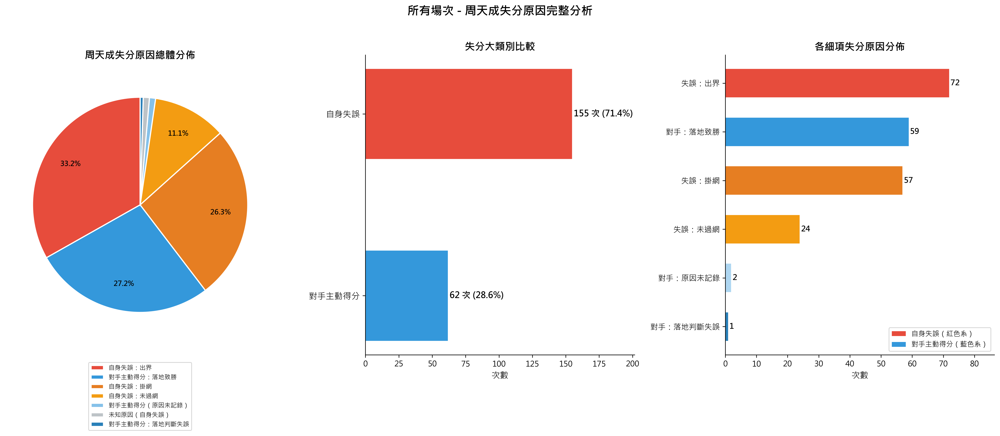

In [ ]:
import numpy as np

# ============================================================
# 統計周天成失分原因分佈
# ============================================================

print("=" * 60)
print("周天成失分原因分佈分析")
print("=" * 60)

# 驗證數據量
print(f"\n資料總筆數: {len(df)}")

# 取每個回合最後一拍（即有 getpoint_player 記錄的那拍）
# 根據 Schema: getpoint_player 只有每回合最後一球才有記錄
df_last = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
print(f"總回合數: {len(df_last)}")

# 篩選有效回合（getpoint_player 非空）
df_valid = df_last.dropna(subset=['getpoint_player'])
print(f"有 getpoint_player 記錄的回合數: {len(df_valid)}")

# 篩選「周天成失分」的回合：對手（桃田賢斗）得分
df_chou_lose = df_valid[df_valid['getpoint_player'] == 'Kento MOMOTA'].copy()
print(f"\n周天成失分回合數: {len(df_chou_lose)}")

# ============================================================
# 分析失分原因
# ============================================================
# 情況1：最後一拍是周天成擊球 → lose_reason 記錄周天成失誤原因
# 情況2：最後一拍是桃田賢斗擊球 → win_reason 記錄桃田得分原因（即周天成承受的失分）

# 建立「失分原因」欄位
def classify_lose_reason(row):
    if row['player'] == 'CHOU Tien Chen':
        # 周天成自身失誤
        reason = row['lose_reason']
        if pd.isna(reason):
            return '未知原因（自身失誤）'
        return f"自身失誤：{reason}"
    else:
        # 桃田賢斗主動得分
        reason = row['win_reason']
        if pd.isna(reason):
            return '對手主動得分（原因未記錄）'
        return f"對手主動得分：{reason}"

df_chou_lose['fail_reason'] = df_chou_lose.apply(classify_lose_reason, axis=1)

# 統計各失分原因
reason_counts = df_chou_lose['fail_reason'].value_counts().reset_index()
reason_counts.columns = ['失分原因', '次數']
reason_counts['佔比(%)'] = (reason_counts['次數'] / len(df_chou_lose) * 100).round(2)

print("\n【周天成失分原因分佈（由高到低）】")
print("-" * 55)
for _, row in reason_counts.iterrows():
    print(f"  {row['失分原因']:<25} | {row['次數']:>4} 次 | {row['佔比(%)']:>6.2f}%")
print("-" * 55)
print(f"  {'合計':<25} | {reason_counts['次數'].sum():>4} 次 | 100.00%")

# ============================================================
# 進一步細分：自身失誤 vs 對手主動得分
# ============================================================
# 計算大類別統計
chou_active_lose = df_chou_lose[df_chou_lose['player'] == 'CHOU Tien Chen']
momota_active_win = df_chou_lose[df_chou_lose['player'] == 'Kento MOMOTA']

print(f"\n【失分大類別】")
print(f"  周天成自身失誤:    {len(chou_active_lose)} 次 ({len(chou_active_lose)/len(df_chou_lose)*100:.1f}%)")
print(f"  對手（桃田）主動得分: {len(momota_active_win)} 次 ({len(momota_active_win)/len(df_chou_lose)*100:.1f}%)")

# 自身失誤細分
print(f"\n【周天成自身失誤細分】")
if len(chou_active_lose) > 0:
    lose_detail = chou_active_lose['lose_reason'].value_counts()
    for reason, cnt in lose_detail.items():
        print(f"  {reason:<15} | {cnt:>4} 次 | {cnt/len(chou_active_lose)*100:.1f}%")

# 對手主動得分細分
print(f"\n【對手（桃田）主動得分細分】")
if len(momota_active_win) > 0:
    win_detail = momota_active_win['win_reason'].value_counts()
    for reason, cnt in win_detail.items():
        print(f"  {reason:<15} | {cnt:>4} 次 | {cnt/len(momota_active_win)*100:.1f}%")
    nan_count = momota_active_win['win_reason'].isna().sum()
    if nan_count > 0:
        print(f"  {'（未記錄）':<15} | {nan_count:>4} 次 | {nan_count/len(momota_active_win)*100:.1f}%")

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# --- 圖1：總體失分原因分佈（圓餅圖）---
ax1 = axes[0]
# 合理合併：對細節做簡化標籤
pie_labels = reason_counts['失分原因'].tolist()
pie_values = reason_counts['次數'].tolist()

# 為每個類別設定顏色
colors_map = {
    '自身失誤：出界': '#E74C3C',
    '自身失誤：掛網': '#E67E22',
    '自身失誤：未過網': '#F39C12',
    '自身失誤：落點判斷失誤': '#D35400',
    '自身失誤：犯規': '#C0392B',
    '對手主動得分：落地致勝': '#3498DB',
    '對手主動得分：落地判斷失誤': '#2980B9',
    '對手主動得分（原因未記錄）': '#85C1E9',
    '未知原因（自身失誤）': '#BDC3C7',
}
bar_colors = [colors_map.get(l, '#95A5A6') for l in pie_labels]

wedges, texts, autotexts = ax1.pie(
    pie_values,
    labels=None,
    autopct=lambda pct: f'{pct:.1f}%' if pct > 3 else '',
    colors=bar_colors,
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')

ax1.legend(wedges, pie_labels, loc='lower center', bbox_to_anchor=(0.5, -0.35),
           fontsize=8, ncol=1)
ax1.set_title('周天成失分原因總體分佈', fontsize=13, fontweight='bold', pad=15)

# --- 圖2：自身失誤 vs 對手主動得分（大類水平長條）---
ax2 = axes[1]
categories = ['對手主動得分', '自身失誤']
values = [len(momota_active_win), len(chou_active_lose)]
colors_bar = ['#3498DB', '#E74C3C']

bars = ax2.barh(categories, values, color=colors_bar, edgecolor='white', height=0.5)
for bar, val in zip(bars, values):
    pct = val / len(df_chou_lose) * 100
    ax2.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f'{val} 次 ({pct:.1f}%)', va='center', fontsize=11, fontweight='bold')

ax2.set_xlim(0, max(values) * 1.3)
ax2.set_xlabel('次數', fontsize=11)
ax2.set_title('失分大類別比較', fontsize=13, fontweight='bold')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.tick_params(axis='y', labelsize=11)

# --- 圖3：各細項失分原因長條圖（水平）---
ax3 = axes[2]

# 分開自身失誤與對手得分，排序後合併
self_err = chou_active_lose['lose_reason'].value_counts()
opp_win = momota_active_win['win_reason'].value_counts()
nan_cnt = momota_active_win['win_reason'].isna().sum()

# 整理詳細標籤
detail_labels = []
detail_values = []
detail_colors = []

# 自身失誤（紅色系）
red_shades = ['#E74C3C', '#E67E22', '#F39C12', '#D35400', '#C0392B']
for i, (reason, cnt) in enumerate(self_err.items()):
    detail_labels.append(f'失誤：{reason}')
    detail_values.append(cnt)
    detail_colors.append(red_shades[i % len(red_shades)])

# 對手主動得分（藍色系）
blue_shades = ['#3498DB', '#2980B9', '#85C1E9']
for i, (reason, cnt) in enumerate(opp_win.items()):
    detail_labels.append(f'對手：{reason}')
    detail_values.append(cnt)
    detail_colors.append(blue_shades[i % len(blue_shades)])
if nan_cnt > 0:
    detail_labels.append('對手：原因未記錄')
    detail_values.append(nan_cnt)
    detail_colors.append('#AED6F1')

# 排序（由小到大，水平長條視覺從上到下由大到小）
sorted_idx = np.argsort(detail_values)
detail_labels = [detail_labels[i] for i in sorted_idx]
detail_values = [detail_values[i] for i in sorted_idx]
detail_colors = [detail_colors[i] for i in sorted_idx]

bars3 = ax3.barh(detail_labels, detail_values, color=detail_colors,
                  edgecolor='white', height=0.6)
for bar, val in zip(bars3, detail_values):
    ax3.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val}', va='center', fontsize=10, fontweight='bold')

ax3.set_xlim(0, max(detail_values) * 1.2)
ax3.set_xlabel('次數', fontsize=11)
ax3.set_title('各細項失分原因分佈', fontsize=13, fontweight='bold')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# 圖例說明
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#E74C3C', label='自身失誤（紅色系）'),
                   Patch(facecolor='#3498DB', label='對手主動得分（藍色系）')]
ax3.legend(handles=legend_elements, loc='lower right', fontsize=9)

plt.suptitle('所有場次 - 周天成失分原因完整分析', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n✅ 圖表已生成")


### 數據洞察
# 周天成失分原因分析

## 核心數據

| 失分原因 | 次數 | 佔比 |
|---------|-----:|-----:|
| 自身失誤：出界 | 72 | 33.2% |
| 對手落地致勝 | 59 | 27.2% |
| 自身失誤：掛網 | 57 | 26.3% |
| 自身失誤：未過網 | 24 | 11.1% |
| 其他 | 5 | 2.3% |

---

## 教練解讀

**最關鍵的數字：71.4% 的失分來自自身失誤（155/217）。**

這場比賽周天成輸給自己，多於輸給桃田。

### 三大失誤的戰術意義

**① 出界（72次，最多）**
> 擊球力道與落點控制失準。在壓力下傾向「打死」，但準確率不足，球出邊線或底線。

**② 掛網（57次）**
> 網前處理與低平球品質不穩。掛網通常發生在被動接球或急促回擊時，反映防守端承壓過大。

**③ 未過網（24次）**
> 擊球時機或揮拍角度問題，多見於快速交換球路時的失誤。

### 對手桃田的威脅
> 62次主動得分中，**95%（59次）為落地致勝**——桃田的落點精準度是真實威脅，但相比周天成自身失誤，仍屬次要因素。

---

## 戰術建議

1. **降低失誤優先於進攻**——減少出界與掛網，比提升進攻更直接影響勝負
2. **出界問題**：加強壓力下的落點紀律，寧可打保守球，不冒險打邊線
3. **掛網問題**：被動時優先挑高球重整，避免倉促網前處理

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出每個回合的最後一拍，並根據 `getpoint_player` 判斷周天成的失分回合。然後，它根據 `player` 欄位來區分是周天成自身失誤還是對手主動得分，並使用 `lose_reason` 和 `win_reason` 來分類失分原因。最後，它統計並輸出失分原因的分佈，這與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致。




## 題號 17
**問題**: 繪製周天成所有輸球原因為'掛網'時的球員站位熱區圖？
> **使用的資料欄位群組**: `game_structure, player_location, scoring_reason`


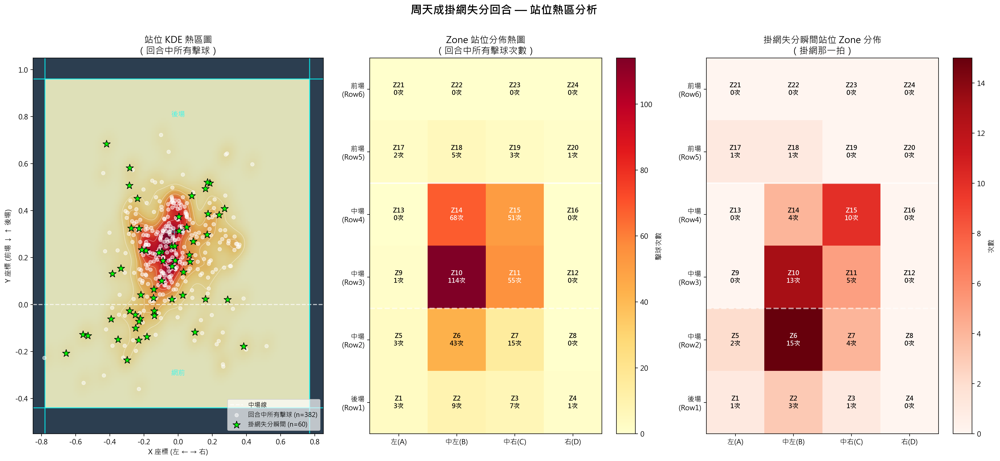

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde

# ============================================================
# Step 1: 驗證資料
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"player 唯一值: {df['player'].unique()}")
print(f"lose_reason 唯一值: {df['lose_reason'].unique()}")

# ============================================================
# Step 2: 找出周天成掛網失分的回合
# 定義：
#   - player == 'CHOU Tien Chen'（是周天成擊球）
#   - lose_reason == '掛網'（周天成掛網）
#   - getpoint_player == 'Kento MOMOTA'（確認是周天成失分，桃田得分）
# 這些條件同時成立，即周天成主動掛網失分
# ============================================================

# 找出掛網失分那一拍
hang_net_shots = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['lose_reason'] == '掛網') &
    (df['getpoint_player'] == 'Kento MOMOTA')
].copy()

print(f"\n周天成掛網失分次數: {len(hang_net_shots)}")
print(f"涉及的 rally_id 數量: {hang_net_shots['rally_id'].nunique()}")
print(f"\n掛網失分詳細資訊:")
print(hang_net_shots[['match_id', 'set', 'rally', 'ball_round', 
                        'player', 'lose_reason', 'getpoint_player',
                        'player_location_area', 'player_location_x', 'player_location_y']].to_string())

# 取得這些回合的 rally_id
hang_net_rally_ids = hang_net_shots['rally_id'].unique()
print(f"\n掛網失分回合 rally_id: {hang_net_rally_ids}")

# ============================================================
# Step 3: 取出這些回合中周天成所有擊球的站位資訊
# ============================================================
# 從完整 df 中，篩選這些回合 + 周天成擊球
chou_in_hangnet_rallies = df[
    (df['rally_id'].isin(hang_net_rally_ids)) &
    (df['player'] == 'CHOU Tien Chen')
].copy()

print(f"\n這些回合中，周天成擊球總拍數: {len(chou_in_hangnet_rallies)}")
print(f"player_location_area 分佈:\n{chou_in_hangnet_rallies['player_location_area'].value_counts().sort_index()}")

# ============================================================
# Step 4: 定義場地輔助資訊
# ============================================================
# Court Grid: x 範圍約 [-0.78, 0.77], y 範圍約 [-0.44, 0.96]
# 根據座標系，y 正方向為場地後方（底線），y=0 附近為發球線/中場
# 掛網失分應在前場（網前，y 較小正值或負值附近）

# Zone 分區定義（用於標示）
zone_categories = {
    'Back Court (後場)': [1, 2, 3, 4],
    'Mid Court (中場)': [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16],
    'Front Court (前場)': [17, 18, 19, 20, 21, 22, 23, 24],
}

# 為 zone 加上標籤
def get_zone_category(zone):
    if zone in [1, 2, 3, 4]:
        return '後場'
    elif zone in [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]:
        return '中場'
    elif zone in [17, 18, 19, 20, 21, 22, 23, 24]:
        return '前場'
    else:
        return '界外'

chou_in_hangnet_rallies['zone_category'] = chou_in_hangnet_rallies['player_location_area'].apply(
    lambda x: get_zone_category(int(x)) if not np.isnan(x) else '未知'
)

# 掛網那一拍
hang_net_shots['zone_category'] = hang_net_shots['player_location_area'].apply(
    lambda x: get_zone_category(int(x)) if not np.isnan(x) else '未知'
)

print(f"\n這些回合中周天成站位區域分佈（所有擊球）:")
print(chou_in_hangnet_rallies['zone_category'].value_counts())

print(f"\n掛網那一拍站位區域分佈:")
print(hang_net_shots['zone_category'].value_counts())

# ============================================================
# Step 5: 繪製熱區圖
# ============================================================
# 建立 Zone 計數熱圖（使用 Grid）
# 場地 Grid (Row 1=後, Row 6=前; Col A-D)
zone_grid = {
    1: (0, 0), 2: (0, 1), 3: (0, 2), 4: (0, 3),
    5: (1, 0), 6: (1, 1), 7: (1, 2), 8: (1, 3),
    9: (2, 0), 10: (2, 1), 11: (2, 2), 12: (2, 3),
    13: (3, 0), 14: (3, 1), 15: (3, 2), 16: (3, 3),
    17: (4, 0), 18: (4, 1), 19: (4, 2), 20: (4, 3),
    21: (5, 0), 22: (5, 1), 23: (5, 2), 24: (5, 3),
}

# 計算各 Zone 出現次數（所有擊球）
zone_counts_all = chou_in_hangnet_rallies['player_location_area'].value_counts()
# 計算各 Zone 出現次數（掛網那一拍）
zone_counts_hang = hang_net_shots['player_location_area'].value_counts()

# ============================================================
# 建立場地 Grid 熱圖矩陣 (6 rows x 4 cols)
# ============================================================
def build_grid_matrix(zone_counts):
    grid = np.zeros((6, 4))
    for zone, (row, col) in zone_grid.items():
        if zone in zone_counts.index:
            grid[row, col] = zone_counts[zone]
    return grid

grid_all = build_grid_matrix(zone_counts_all)
grid_hang = build_grid_matrix(zone_counts_hang)

# ============================================================
# 繪圖：3張圖
# Fig 1: KDE 熱區圖（連續座標）- 所有擊球
# Fig 2: Grid 熱圖（Zone） - 所有擊球 vs 掛網那一拍
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 9))
fig.suptitle("周天成掛網失分回合 — 站位熱區分析", fontsize=16, fontweight='bold', y=1.01)

# ─────────────────────────────────────────────
# 圖1: KDE 熱區圖 - 所有擊球（連續座標）
# ─────────────────────────────────────────────
ax1 = axes[0]

x_all = chou_in_hangnet_rallies['player_location_x'].values
y_all = chou_in_hangnet_rallies['player_location_y'].values

if len(x_all) > 2:
    # KDE
    xmin, xmax = -0.78, 0.77
    ymin, ymax = -0.44, 0.96
    xx, yy = np.mgrid[xmin:xmax:200j, ymin:ymax:200j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    values = np.vstack([x_all, y_all])
    kernel = gaussian_kde(values, bw_method=0.2)
    f = np.reshape(kernel(positions).T, xx.shape)
    
    ax1.imshow(np.rot90(f), cmap='YlOrRd', extent=[xmin, xmax, ymin, ymax], aspect='auto', alpha=0.85)
    ax1.contour(xx, yy, f, levels=6, colors='white', alpha=0.4, linewidths=0.8)

# 畫場地邊界
ax1.axhline(y=0, color='white', linewidth=1.5, linestyle='--', alpha=0.7, label='中場線')
ax1.axvline(x=-0.78, color='cyan', linewidth=1.5, alpha=0.7)
ax1.axvline(x=0.77, color='cyan', linewidth=1.5, alpha=0.7)
ax1.axhline(y=-0.44, color='cyan', linewidth=1.5, alpha=0.7)
ax1.axhline(y=0.96, color='cyan', linewidth=1.5, alpha=0.7)

# 散點（掛網那一拍高亮）
ax1.scatter(x_all, y_all, c='white', s=25, alpha=0.5, zorder=5, label=f'回合中所有擊球 (n={len(x_all)})')
ax1.scatter(hang_net_shots['player_location_x'], hang_net_shots['player_location_y'],
            c='lime', s=120, marker='*', zorder=10, edgecolors='black', linewidths=0.8,
            label=f'掛網失分瞬間 (n={len(hang_net_shots)})')

ax1.set_xlim(-0.85, 0.85)
ax1.set_ylim(-0.55, 1.05)
ax1.set_xlabel("X 座標 (左 ← → 右)")
ax1.set_ylabel("Y 座標 (前場 ↓ ↑ 後場)")
ax1.set_title("站位 KDE 熱區圖\n（回合中所有擊球）", fontsize=13)
ax1.legend(loc='lower right', fontsize=9, framealpha=0.7)
ax1.set_facecolor('#2c3e50')

# 標示前/中/後場
ax1.text(0, -0.3, "網前", color='cyan', ha='center', fontsize=10, alpha=0.8)
ax1.text(0, 0.3, "中場", color='cyan', ha='center', fontsize=10, alpha=0.8)
ax1.text(0, 0.8, "後場", color='cyan', ha='center', fontsize=10, alpha=0.8)

# ─────────────────────────────────────────────
# 圖2: Zone Grid 熱圖 - 回合中所有擊球
# ─────────────────────────────────────────────
ax2 = axes[1]
# 翻轉使 row=5(前場) 在上方
grid_all_display = np.flipud(grid_all)
im2 = ax2.imshow(grid_all_display, cmap='YlOrRd', aspect='auto', interpolation='nearest')

# 標示數值與 Zone ID
row_labels = ['前場\n(Row6)', '前場\n(Row5)', '中場\n(Row4)', '中場\n(Row3)', '中場\n(Row2)', '後場\n(Row1)']
col_labels = ['左(A)', '中左(B)', '中右(C)', '右(D)']

for row in range(6):
    for col in range(4):
        orig_row = 5 - row  # flipud 後對應原始 row
        zone_id = None
        for z, (r, c) in zone_grid.items():
            if r == orig_row and c == col:
                zone_id = z
                break
        val = int(grid_all_display[row, col])
        color = 'white' if grid_all_display[row, col] > grid_all.max() * 0.4 else 'black'
        ax2.text(col, row, f'Z{zone_id}\n{val}次', ha='center', va='center',
                 fontsize=9, color=color, fontweight='bold')

ax2.set_xticks(range(4))
ax2.set_xticklabels(col_labels, fontsize=10)
ax2.set_yticks(range(6))
ax2.set_yticklabels(row_labels, fontsize=10)
ax2.set_title("Zone 站位分佈熱圖\n（回合中所有擊球次數）", fontsize=13)
plt.colorbar(im2, ax=ax2, label='擊球次數')

# 標示場地分區線
ax2.axhline(y=1.5, color='white', linewidth=2, linestyle='-', alpha=0.8)
ax2.axhline(y=3.5, color='white', linewidth=2, linestyle='--', alpha=0.6)
ax2.text(3.6, 0.5, '前場', color='white', fontsize=9, va='center', rotation=90)
ax2.text(3.6, 2.5, '中場', color='white', fontsize=9, va='center', rotation=90)
ax2.text(3.6, 5.0, '後場', color='white', fontsize=9, va='center', rotation=90)

# ─────────────────────────────────────────────
# 圖3: Zone Grid 熱圖 - 掛網那一拍
# ─────────────────────────────────────────────
ax3 = axes[2]
grid_hang_display = np.flipud(grid_hang)
im3 = ax3.imshow(grid_hang_display, cmap='Reds', aspect='auto', interpolation='nearest')

for row in range(6):
    for col in range(4):
        orig_row = 5 - row
        zone_id = None
        for z, (r, c) in zone_grid.items():
            if r == orig_row and c == col:
                zone_id = z
                break
        val = int(grid_hang_display[row, col])
        color = 'white' if grid_hang_display[row, col] > grid_hang.max() * 0.4 else 'black'
        ax3.text(col, row, f'Z{zone_id}\n{val}次', ha='center', va='center',
                 fontsize=9, color=color, fontweight='bold')

ax3.set_xticks(range(4))
ax3.set_xticklabels(col_labels, fontsize=10)
ax3.set_yticks(range(6))
ax3.set_yticklabels(row_labels, fontsize=10)
ax3.set_title("掛網失分瞬間站位 Zone 分佈\n（掛網那一拍）", fontsize=13)
plt.colorbar(im3, ax=ax3, label='次數')

ax3.axhline(y=1.5, color='white', linewidth=2, linestyle='-', alpha=0.8)
ax3.axhline(y=3.5, color='white', linewidth=2, linestyle='--', alpha=0.6)

plt.tight_layout()

# ============================================================
# Step 6: 印出詳細統計
# ============================================================
print("\n" + "="*60)
print("📊 周天成掛網失分統計摘要")
print("="*60)
print(f"掛網失分回合總數: {len(hang_net_rally_ids)} 回合")
print(f"掛網失分總次數: {len(hang_net_shots)} 次")
print(f"\n【掛網失分】各場次分佈:")
match_dist = hang_net_shots.groupby(['match_id', 'set']).size().reset_index(name='count')
print(match_dist.to_string(index=False))

print(f"\n【掛網失分瞬間】Zone 分佈:")
zone_dist_hang = hang_net_shots['player_location_area'].value_counts().sort_index()
for zone, cnt in zone_dist_hang.items():
    cat = get_zone_category(int(zone))
    print(f"  Zone {int(zone):2d} ({cat}): {cnt} 次")

print(f"\n【回合中所有擊球】Zone 分佈:")
zone_dist_all = chou_in_hangnet_rallies['player_location_area'].value_counts().sort_index()
for zone, cnt in zone_dist_all.items():
    cat = get_zone_category(int(zone))
    print(f"  Zone {int(zone):2d} ({cat}): {cnt} 次")

print(f"\n【區域彙整】掛網失分瞬間站位:")
print(hang_net_shots['zone_category'].value_counts())
print(f"\n【區域彙整】回合中所有擊球站位:")
print(chou_in_hangnet_rallies['zone_category'].value_counts())


### 數據洞察
# 周天成掛網失分站位熱區分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 掛網失分瞬間站位熱區

```
        左(A)   中左(B)  中右(C)  右(D)
後場Row1 [  1  ][  3  ][  1  ][  0  ]
中場Row2 [  2  ][ 15  ][  4  ][  0  ]
中場Row3 [  0  ][ 13  ][  5  ][  0  ]
中場Row4 [  0  ][  4  ][ 10  ][  0  ]
前場Row5 [  1  ][  1  ][  0  ][  0  ]
前場Row6 [  0  ][  0  ][  0  ][  0  ]
```

---

## 核心數據

| 指標 | 數值 |
|------|------|
| 掛網失分回合數 | 57 回合 |
| 掛網失分總次數 | 60 次 |
| 失分瞬間在中場 | **53次（88%）** |
| 失分瞬間在後場 | 5次（8%）|
| 失分瞬間在前場 | 2次（3%）|

---

## 戰術洞察

**88% 的掛網失分發生在中場。** 這不是偶然。

### 1️⃣ 中場 B 欄（Zone 6+10）是最危險的死角
Zone 6（中場中左）**15次**、Zone 10（中場中左偏後）**13次**，合計28次，佔掛網失分的**47%**。這個位置對應的是**被壓制到中場後，被迫向網前回擊**的情境——球路偏低、身體重心未穩，掛網率極高。

### 2️⃣ Zone 15（中場中右後）10次值得注意
Zone 15 集中在中場右側偏後，這顯示**反手側被拉扯到中場時**，周天成的網前回球品質明顯下降。

### 3️⃣ 後場掛網（5次）說明判斷問題
後場掛網通常源於**落點誤判或擊球時機太晚**，雖然比例低，但每一次都是主動失誤，可避免。

---

## 給周天成的調整建議

> **被壓到中場 B 欄時，優先選擇挑球（Zone 6/10），而非強行打網前。** 數據顯示這個位置的掛網失分最集中，強行攻網只是把主動權拱手相讓。穩住重心、爭取時間，比搶快更重要。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成在輸球原因為'掛網'時的數據，並繪製了球員站位的熱區圖。候選程式碼進一步分析了這些回合中所有擊球的站位資訊，並提供了詳細的統計和視覺化，這些都與 Reference Code 1 的目標一致。




## 題號 18
**問題**: 分析周天成在開局（自己0-4 分）、中局（自己5-17 分）和關鍵分（自己18 分以上）三個比分階段中，他自己移動距離的差異。
> **使用的資料欄位群組**: `game_structure, player_movement, scoring_reason`


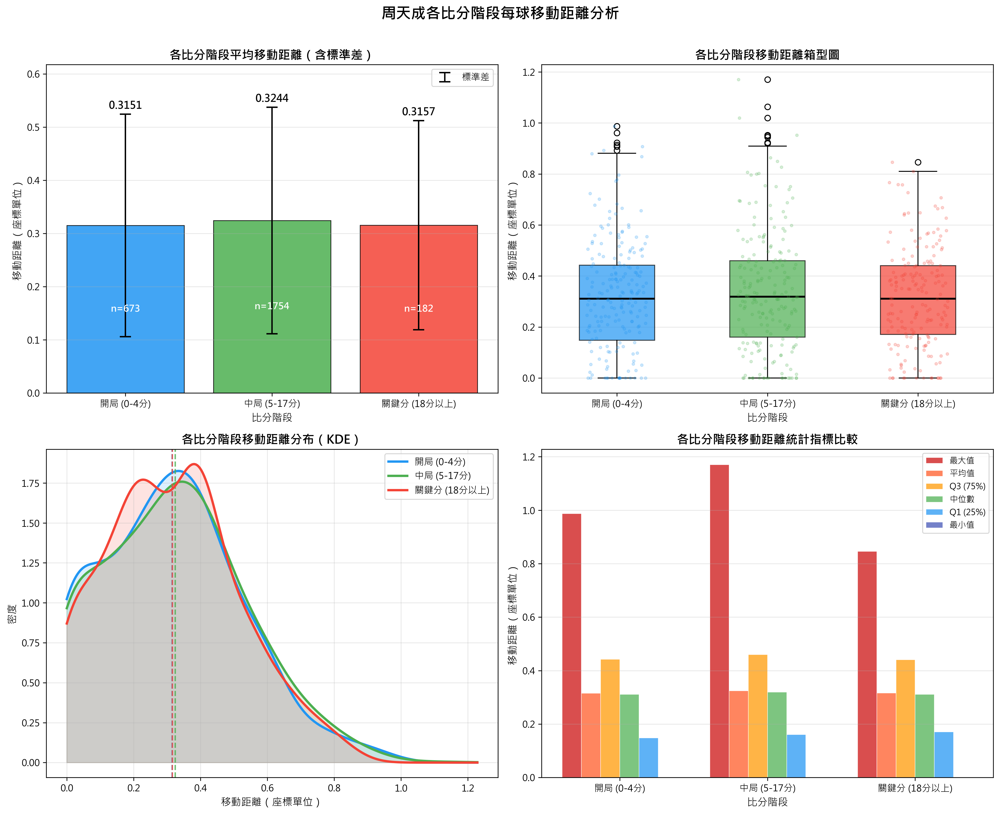

In [ ]:
import numpy as np

# ============================================================
# 數據驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 篩選周天成的所有擊球拍次
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成擊球拍次總數: {len(chou_df)}")

# ============================================================
# 計算每拍移動距離（歐氏距離）
# player_move_x / player_move_y 是「擊球點到移動位置」的位移量
# ============================================================
chou_df['move_distance'] = np.sqrt(
    chou_df['player_move_x']**2 + chou_df['player_move_y']**2
)

print(f"\n移動距離基本統計:")
print(f"  最大值: {chou_df['move_distance'].max():.4f}")
print(f"  最小值: {chou_df['move_distance'].min():.4f}")
print(f"  平均值: {chou_df['move_distance'].mean():.4f}")

# ============================================================
# 依周天成自身比分劃分階段
# CHOU Tien Chen_score：周天成在該拍發生時的當前分數
# 階段定義：
#   開局  -> 自身得分 0~4 分
#   中局  -> 自身得分 5~17 分
#   關鍵分 -> 自身得分 18 分以上
# ============================================================
def classify_stage(score):
    if score <= 4:
        return '開局 (0-4分)'
    elif score <= 17:
        return '中局 (5-17分)'
    else:
        return '關鍵分 (18分以上)'

chou_df['stage'] = chou_df['CHOU Tien Chen_score'].apply(classify_stage)

# 確保階段順序
stage_order = ['開局 (0-4分)', '中局 (5-17分)', '關鍵分 (18分以上)']
chou_df['stage'] = pd.Categorical(chou_df['stage'], categories=stage_order, ordered=True)

# ============================================================
# 各階段統計
# ============================================================
stage_stats = chou_df.groupby('stage', observed=True)['move_distance'].agg(
    拍次數='count',
    平均移動距離='mean',
    中位數='median',
    標準差='std',
    最大值='max',
    最小值='min',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
).round(4)

print("\n" + "="*60)
print("【周天成各比分階段移動距離統計】")
print("="*60)
print(stage_stats.to_string())

# 打印各階段比分範圍分布
print("\n各階段拍次佔比:")
total = len(chou_df)
for stage in stage_order:
    cnt = (chou_df['stage'] == stage).sum()
    print(f"  {stage}: {cnt} 拍 ({cnt/total*100:.1f}%)")

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('周天成各比分階段每球移動距離分析', fontsize=16, fontweight='bold', y=1.01)

colors = ['#2196F3', '#4CAF50', '#F44336']  # 藍、綠、紅
stage_labels = stage_order

# ------ 圖1: 各階段平均移動距離長條圖（含誤差棒） ------
ax1 = axes[0, 0]
means = stage_stats['平均移動距離'].values
stds  = stage_stats['標準差'].values
counts = stage_stats['拍次數'].values

bars = ax1.bar(stage_labels, means, color=colors, alpha=0.85, edgecolor='black', linewidth=0.8)
ax1.errorbar(stage_labels, means, yerr=stds, fmt='none', color='black',
             capsize=6, capthick=1.5, linewidth=1.5, label='標準差')

# 在長條圖上標示數值
for bar, mean, std, n in zip(bars, means, stds, counts):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.005,
             f'{mean:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
             f'n={n}', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

ax1.set_title('各比分階段平均移動距離（含標準差）', fontsize=13, fontweight='bold')
ax1.set_ylabel('移動距離（座標單位）', fontsize=11)
ax1.set_xlabel('比分階段', fontsize=11)
ax1.set_ylim(0, max(means) + max(stds) + 0.08)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# ------ 圖2: 箱型圖（含抖動點） ------
ax2 = axes[0, 1]

# 箱型圖
bp = ax2.boxplot(
    [chou_df[chou_df['stage'] == s]['move_distance'].values for s in stage_order],
    labels=stage_labels,
    patch_artist=True,
    notch=False,
    widths=0.5,
    medianprops=dict(color='black', linewidth=2)
)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# 加入抖動散點（隨機取樣避免過密）
np.random.seed(42)
for i, (stage, color) in enumerate(zip(stage_order, colors), start=1):
    stage_data = chou_df[chou_df['stage'] == stage]['move_distance'].values
    # 抽樣最多200點顯示
    if len(stage_data) > 200:
        sample_data = np.random.choice(stage_data, 200, replace=False)
    else:
        sample_data = stage_data
    jitter = np.random.uniform(-0.2, 0.2, len(sample_data))
    ax2.scatter(np.full(len(sample_data), i) + jitter, sample_data,
                alpha=0.2, color=color, s=8, zorder=3)

ax2.set_title('各比分階段移動距離箱型圖', fontsize=13, fontweight='bold')
ax2.set_ylabel('移動距離（座標單位）', fontsize=11)
ax2.set_xlabel('比分階段', fontsize=11)
ax2.grid(axis='y', alpha=0.3)

# ------ 圖3: 各階段移動距離分布（KDE密度圖） ------
ax3 = axes[1, 0]
from scipy import stats as scipy_stats

for stage, color in zip(stage_order, colors):
    stage_data = chou_df[chou_df['stage'] == stage]['move_distance'].values
    if len(stage_data) > 5:
        kde = scipy_stats.gaussian_kde(stage_data, bw_method=0.3)
        x_range = np.linspace(0, chou_df['move_distance'].max() * 1.05, 300)
        ax3.plot(x_range, kde(x_range), color=color, linewidth=2.5, label=stage)
        ax3.fill_between(x_range, kde(x_range), alpha=0.15, color=color)
        # 平均值垂直線
        ax3.axvline(stage_data.mean(), color=color, linewidth=1.5, linestyle='--', alpha=0.8)

ax3.set_title('各比分階段移動距離分布（KDE）', fontsize=13, fontweight='bold')
ax3.set_xlabel('移動距離（座標單位）', fontsize=11)
ax3.set_ylabel('密度', fontsize=11)
ax3.legend(fontsize=10)
ax3.grid(alpha=0.3)

# ------ 圖4: 最大/平均/最小值比較圖 ------
ax4 = axes[1, 1]

metrics = {
    '最大值': stage_stats['最大值'].values,
    '平均值': stage_stats['平均移動距離'].values,
    'Q3 (75%)': stage_stats['Q3'].values,
    '中位數': stage_stats['中位數'].values,
    'Q1 (25%)': stage_stats['Q1'].values,
    '最小值': stage_stats['最小值'].values,
}

x = np.arange(len(stage_order))
width = 0.13
metric_colors = ['#D32F2F', '#FF7043', '#FFA726', '#66BB6A', '#42A5F5', '#5C6BC0']

for i, (metric_name, metric_vals) in enumerate(metrics.items()):
    offset = (i - len(metrics)/2 + 0.5) * width
    bars_m = ax4.bar(x + offset, metric_vals, width, label=metric_name,
                     color=metric_colors[i], alpha=0.85, edgecolor='white', linewidth=0.5)

ax4.set_title('各比分階段移動距離統計指標比較', fontsize=13, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(stage_labels, fontsize=10)
ax4.set_ylabel('移動距離（座標單位）', fontsize=11)
ax4.set_xlabel('比分階段', fontsize=11)
ax4.legend(fontsize=9, loc='upper right')
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()

# ============================================================
# 補充：各階段差異量化比較
# ============================================================
print("\n" + "="*60)
print("【各階段相對差異分析（以開局為基準）】")
print("="*60)
baseline_mean = stage_stats.loc['開局 (0-4分)', '平均移動距離']
for stage in stage_order:
    mean_val = stage_stats.loc[stage, '平均移動距離']
    diff = mean_val - baseline_mean
    pct = (diff / baseline_mean * 100) if baseline_mean != 0 else 0
    print(f"  {stage}: 平均 {mean_val:.4f}  差異 {diff:+.4f} ({pct:+.1f}%)")

# Kruskal-Wallis 非參數檢定（不假設常態分布）
from scipy.stats import kruskal
groups = [chou_df[chou_df['stage'] == s]['move_distance'].values for s in stage_order]
stat, p_value = kruskal(*groups)
print(f"\n【Kruskal-Wallis 統計檢定】")
print(f"  H 統計量 = {stat:.4f}")
print(f"  p 值      = {p_value:.6f}")
if p_value < 0.05:
    print(f"  結論: 三個階段的移動距離分布存在顯著差異（p < 0.05）✅")
else:
    print(f"  結論: 三個階段的移動距離分布無顯著差異（p >= 0.05）❌")


### 數據洞察
# 周天成各比分階段移動距離分析

## 核心數據總覽

| 階段 | 拍次 | 佔比 | 平均距離 | 中位數 | 標準差 | 最大值 |
|------|------|------|----------|--------|--------|--------|
| 開局 (0–4分) | 673 | 25.8% | 0.3151 | 0.3107 | 0.2093 | 0.9869 |
| 中局 (5–17分) | 1754 | 67.2% | 0.3244 | 0.3193 | 0.2132 | 1.1697 |
| 關鍵分 (18分+) | 182 | 7.0% | 0.3157 | 0.3106 | 0.1967 | 0.8459 |

---

## 關鍵發現

### 1. 三階段移動距離幾乎無差異
- 中局比開局多移動 **+0.0093**（僅 +3.0%）
- 關鍵分比開局多移動 **+0.0006**（僅 +0.2%）
- **Kruskal-Wallis 檢定 p = 0.633**，三階段分布無統計顯著差異

### 2. 關鍵分階段波動最小
- 標準差最低（0.1967），最大值也最低（0.8459）
- 代表關鍵分時移動更集中、極端大位移球較少出現

### 3. 中局是體能消耗主戰場
- 佔全場 **67.2% 拍次**，且平均與最大移動距離均為三階段最高
- 最大單球移動達 **1.1697**，是全場最大值

---

## 教練解讀

周天成的移動距離在三個比分階段**高度一致**，顯示他無論開局、中局或關鍵分，**步伐節奏與場上覆蓋範圍都維持穩定**，不因比分壓力而出現明顯的移動模式改變。

關鍵分階段標準差最小，說明他在緊張時刻**減少冒險、控制移動風險**，傾向打更穩定的球路而非大範圍奔跑搶攻。這是高水準選手在關鍵分的典型特徵——**用戰術穩定性取代體能消耗**。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成作為擊球者的資料，計算了移動距離，並依據周天成的比分將資料分為開局、中局和關鍵分三個階段。然後，它計算了各階段的移動距離統計數據，並進行了詳細的視覺化分析。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致，並且最終輸出目標也一致。




## 題號 19
**問題**: 當周天成打擊出界時，劃出站點的散佈圖?
> **使用的資料欄位群組**: `game_structure, player_location, scoring_reason`


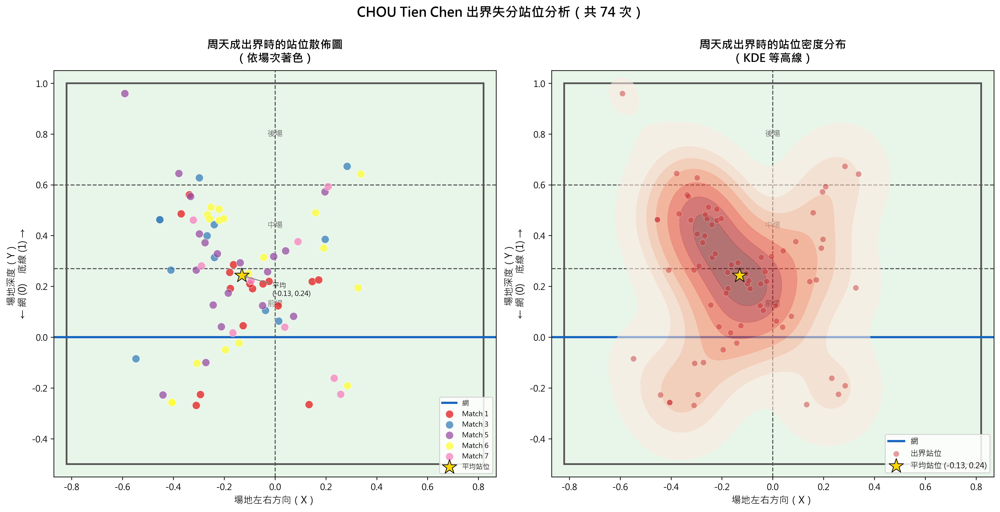

In [ ]:
import numpy as np

# ============================================================
# 數據驗證
# ============================================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# ============================================================
# 篩選條件：
# 周天成（CHOU Tien Chen）擊球，且出界，且對手得分（確認為周天成失誤）
# - player == 'CHOU Tien Chen'      → 周天成在擊球
# - lose_reason == '出界'            → 擊球出界
# - getpoint_player == 'Kento MOMOTA' → 對手因此得分（確認是周天成的失誤）
# ============================================================
chou_oob = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['lose_reason'] == '出界') &
    (df['getpoint_player'] == 'Kento MOMOTA')
].copy()

print(f"\n周天成出界失分球數: {len(chou_oob)}")
print(f"涉及場次(match_id): {sorted(chou_oob['match_id'].unique())}")
print(f"涉及局數分布:\n{chou_oob.groupby(['match_id','set']).size().rename('次數')}")

# ============================================================
# 確認無遺失值（站位座標）
# ============================================================
chou_oob_clean = chou_oob.dropna(subset=['player_location_x', 'player_location_y'])
print(f"\n有效座標筆數: {len(chou_oob_clean)}")

# ============================================================
# 繪圖：散佈圖 + 密度等高線 + 羽球半場底圖
# ============================================================
if len(chou_oob_clean) > 0:

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # ── 共用的羽球半場繪製函式 ──────────────────────────────
    def draw_half_court(ax, title=""):
        """
        繪製羽球半場示意線條（正規化座標系）
        以場地中線為底（y=0），底線為頂（y≈1）
        x 軸從左邊線到右邊線 (-0.5 ~ 0.5 近似)
        """
        court_color = '#e8f5e9'
        line_color  = '#555555'
        lw = 1.2

        ax.set_facecolor(court_color)

        # 場地邊界（依資料座標範圍估算）
        x_min, x_max = -0.82, 0.82
        y_min, y_max = -0.50, 1.00

        # 外框
        ax.add_patch(plt.Rectangle(
            (x_min, y_min), x_max - x_min, y_max - y_min,
            fill=False, edgecolor=line_color, lw=2, zorder=1
        ))

        # 中線（網，y ≈ 0）
        ax.axhline(y=0, color='#1565C0', lw=2.5, linestyle='-', zorder=2, label='網')

        # 短發球線（前場線）約 y = 0.27（前場 1/4）
        short_service_y = 0.27
        ax.axhline(y=short_service_y, color=line_color, lw=lw, linestyle='--', zorder=2)

        # 長發球線（中場分隔）約 y = 0.60
        long_service_y = 0.60
        ax.axhline(y=long_service_y, color=line_color, lw=lw, linestyle='--', zorder=2)

        # 中線（左右分隔）
        ax.axvline(x=0, color=line_color, lw=lw, linestyle='--', zorder=2)

        # 區域標籤
        ax.text(0, 0.13, '前場', ha='center', va='center',
                fontsize=9, color='#616161', zorder=3)
        ax.text(0, 0.44, '中場', ha='center', va='center',
                fontsize=9, color='#616161', zorder=3)
        ax.text(0, 0.80, '後場', ha='center', va='center',
                fontsize=9, color='#616161', zorder=3)

        ax.set_xlim(x_min - 0.05, x_max + 0.05)
        ax.set_ylim(y_min - 0.05, y_max + 0.05)
        ax.set_xlabel('場地左右方向（X）', fontsize=11)
        ax.set_ylabel('場地深度（Y）\n← 網 (0)    底線 (1) →', fontsize=11)
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
        ax.set_aspect('equal')

    # ── 圖1：散佈圖（依場次著色）────────────────────────────
    ax1 = axes[0]
    draw_half_court(ax1, title="周天成出界時的站位散佈圖\n（依場次著色）")

    match_ids = sorted(chou_oob_clean['match_id'].unique())
    palette   = plt.cm.Set1(np.linspace(0, 0.8, len(match_ids)))
    color_map = dict(zip(match_ids, palette))

    for mid, grp in chou_oob_clean.groupby('match_id'):
        ax1.scatter(
            grp['player_location_x'],
            grp['player_location_y'],
            color=color_map[mid],
            s=80, alpha=0.75, edgecolors='white', linewidths=0.5,
            label=f'Match {int(mid)}',
            zorder=5
        )

    # 繪製平均站位
    mean_x = chou_oob_clean['player_location_x'].mean()
    mean_y = chou_oob_clean['player_location_y'].mean()
    ax1.scatter(mean_x, mean_y, marker='*', s=300, color='gold',
                edgecolors='black', linewidths=0.8, zorder=7, label=f'平均站位')
    ax1.annotate(f'平均\n({mean_x:.2f}, {mean_y:.2f})',
                 xy=(mean_x, mean_y), xytext=(mean_x + 0.12, mean_y - 0.08),
                 fontsize=8, color='black',
                 arrowprops=dict(arrowstyle='->', color='gray', lw=1),
                 zorder=8)

    ax1.legend(loc='lower right', fontsize=8, framealpha=0.85)

    # ── 圖2：散佈圖 + 密度等高線（KDE）────────────────────────
    ax2 = axes[1]
    draw_half_court(ax2, title="周天成出界時的站位密度分布\n（KDE 等高線）")

    # KDE 等高線
    sns.kdeplot(
        x=chou_oob_clean['player_location_x'],
        y=chou_oob_clean['player_location_y'],
        ax=ax2,
        fill=True,
        cmap='Reds',
        alpha=0.55,
        levels=8,
        zorder=3
    )

    # 原始點（半透明）
    ax2.scatter(
        chou_oob_clean['player_location_x'],
        chou_oob_clean['player_location_y'],
        color='#C62828', s=45, alpha=0.45,
        edgecolors='white', linewidths=0.4,
        zorder=5, label='出界站位'
    )
    ax2.scatter(mean_x, mean_y, marker='*', s=300,
                color='gold', edgecolors='black', linewidths=0.8,
                zorder=7, label=f'平均站位 ({mean_x:.2f}, {mean_y:.2f})')
    ax2.legend(loc='lower right', fontsize=9, framealpha=0.85)

    plt.suptitle(
        f'CHOU Tien Chen 出界失分站位分析（共 {len(chou_oob_clean)} 次）',
        fontsize=15, fontweight='bold', y=1.01
    )
    plt.tight_layout()

    # ============================================================
    # 打印關鍵統計
    # ============================================================
    print("\n" + "="*50)
    print("【周天成出界失分 - 站位統計摘要】")
    print("="*50)
    print(f"總出界失分次數     : {len(chou_oob_clean)}")
    print(f"站位 X 平均 (左右) : {mean_x:.4f}  (負=左側, 正=右側)")
    print(f"站位 Y 平均 (深度) : {mean_y:.4f}  (0=網前, 1=底線)")
    print(f"站位 X 標準差      : {chou_oob_clean['player_location_x'].std():.4f}")
    print(f"站位 Y 標準差      : {chou_oob_clean['player_location_y'].std():.4f}")

    # 依場地區域（前/中/後場）分類統計
    def classify_court(y):
        if y < 0.27:
            return '前場'
        elif y < 0.60:
            return '中場'
        else:
            return '後場'

    chou_oob_clean['court_zone'] = chou_oob_clean['player_location_y'].apply(classify_court)
    zone_counts = chou_oob_clean['court_zone'].value_counts()
    print(f"\n站位場區分布：")
    for zone, cnt in zone_counts.items():
        pct = cnt / len(chou_oob_clean) * 100
        print(f"  {zone}: {cnt} 次 ({pct:.1f}%)")

    print(f"\n各場次出界次數：")
    per_match = chou_oob_clean.groupby('match_id').size().rename('出界次數')
    for mid, cnt in per_match.items():
        print(f"  Match {int(mid)}: {cnt} 次")

else:
    print("⚠️ 無符合條件的資料，無法繪圖。")


### 數據洞察
# 周天成出界失分站位分析

## 📊 數據總覽

| 指標 | 數值 |
|------|------|
| 總出界失分 | 74 次 |
| 站位 X 均值 | -0.13（偏左） |
| 站位 Y 均值 | 0.24（偏網前） |
| X 標準差 | 0.22 |
| Y 標準差 | 0.27 |

---

## 🗺️ 站位場區分布

| 場區 | 次數 | 佔比 |
|------|------|------|
| **前場** | 39 次 | **52.7%** |
| 中場 | 30 次 | 40.5% |
| 後場 | 5 次 | 6.8% |

---

## 🎯 戰術洞察

**1. 出界多發生在前中場壓迫下**
超過 93% 的出界失分發生在前場與中場。這代表周天成在被迫快速回擊時（網前對抗、中場過渡），容易出現控球失準，而非後場主動進攻失誤。

**2. 站位偏左側**
X 均值 -0.13，出界時身體重心偏左。對手可能習慣性將球壓往周天成反手側（左側），迫使其在非慣用方向出手，提高出界率。

**3. 前場是最高風險區**
39 次前場出界（52.7%），結合 Y 均值 0.24 靠近網前，顯示周天成在網前快速攻防交換中，出手精準度是主要失分來源。

---

## ⚡ 教練建議

> **對手策略**：持續壓制周天成左側前場，製造其在網前反手位的被動出手機會，是最有效的得分路線。
>
> **自我修正**：前中場出界佔比過高，需加強網前反手控球穩定性訓練，特別是被動接球後的出手節奏管理。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出周天成擊球且失分原因為 '出界' 的記錄，並進一步確認對手得分（確認為周天成失誤）。此外，候選程式碼還進行了有效的資料清理和視覺化，並提供了詳細的統計摘要，這些都與 Reference Code 1 的目標一致。




## 題號 20
**問題**: 周天成打擊出界失誤，該球的落點分布
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason`


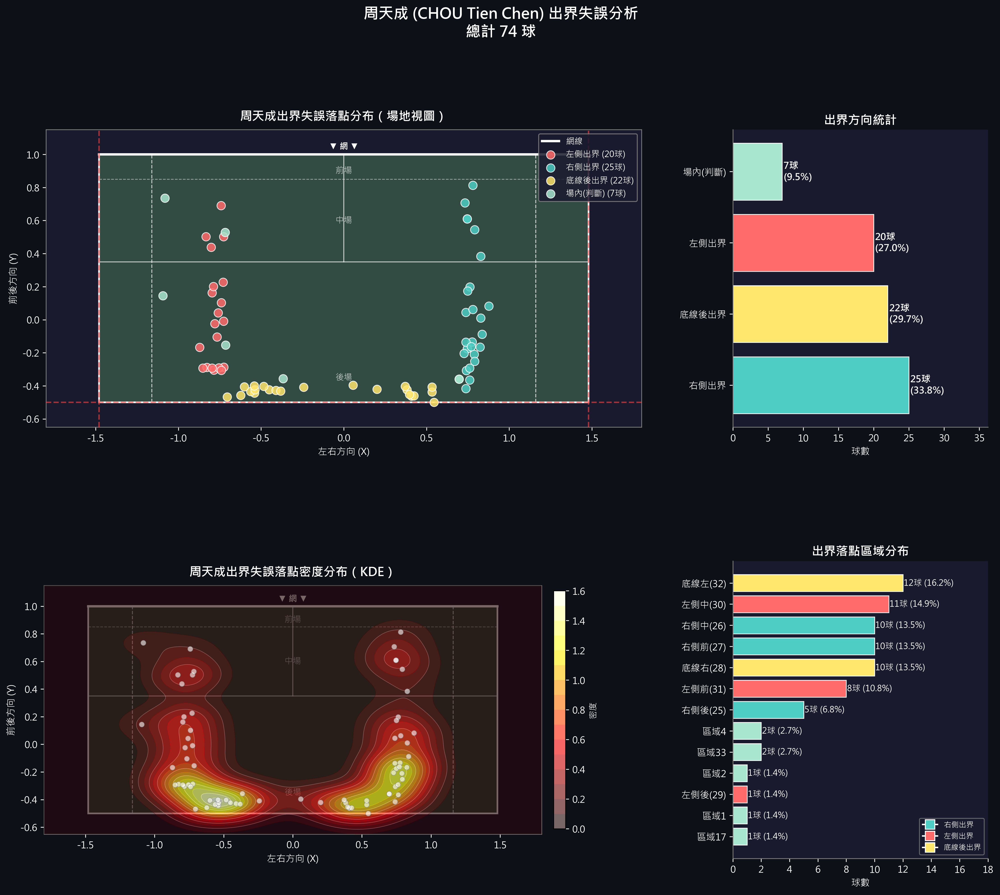

In [ ]:
import numpy as np
import matplotlib.patches as patches
import matplotlib.lines as mlines
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. 資料驗證與篩選
# ============================================================
print(f"資料總筆數: {len(df)}")

# 篩選條件：
# - player == 'CHOU Tien Chen' (周天成擊球)
# - lose_reason == '出界'      (失誤原因為出界)
# - getpoint_player == 'Kento MOMOTA' (對手得分，確認是主動失誤)
chou_out_df = df[
    (df['player'] == 'CHOU Tien Chen') &
    (df['lose_reason'] == '出界') &
    (df['getpoint_player'] == 'Kento MOMOTA')
].copy()

print(f"\n周天成出界失誤總球數: {len(chou_out_df)}")

if len(chou_out_df) == 0:
    print("⚠️ 無符合條件的資料，請確認欄位值。")
else:
    # ============================================================
    # 2. 出界落點區域統計
    # ============================================================
    # 場地區域分類（根據 landing_area）
    # 出界區域: 25~32
    out_area_map = {
        25: '右後出界(Top)',
        26: '右中出界(Mid)',
        27: '右前出界(Bottom)',
        28: '後右出界(Right-Back)',
        29: '左後出界(Top)',
        30: '左中出界(Mid)',
        31: '左前出界(Bottom)',
        32: '後左出界(Left-Back)'
    }
    
    # 方向分類
    def classify_out_direction(area):
        if area in [25, 26, 27]:
            return '右側出界'
        elif area in [29, 30, 31]:
            return '左側出界'
        elif area in [28, 32]:
            return '底線後出界'
        elif area > 0:  # 落在場內但記錄為出界（可能是判斷失誤）
            return '場內(判斷)'
        else:
            return '未知'
    
    chou_out_df['out_direction'] = chou_out_df['landing_area'].apply(classify_out_direction)
    
    # 統計各方向
    direction_counts = chou_out_df['out_direction'].value_counts()
    print("\n【出界方向統計】")
    print(direction_counts)
    
    # 落點區域統計
    area_counts = chou_out_df['landing_area'].value_counts().sort_index()
    print("\n【落點區域 (landing_area) 統計】")
    for area, cnt in area_counts.items():
        label = out_area_map.get(int(area), f'區域{int(area)}')
        print(f"  area {int(area):2d} ({label}): {cnt} 球")
    
    # 座標範圍
    print(f"\n落點 X 範圍: {chou_out_df['landing_x'].min():.4f} ~ {chou_out_df['landing_x'].max():.4f}")
    print(f"落點 Y 範圍: {chou_out_df['landing_y'].min():.4f} ~ {chou_out_df['landing_y'].max():.4f}")
    
    # ============================================================
    # 3. 視覺化：羽球場地 + 落點散點圖 + 密度圖 + 方向長條圖
    # ============================================================
    
    # --- 場地繪製輔助函數 ---
    def draw_badminton_court(ax, title='', half=False):
        """
        繪製羽球半場場地邊界線
        座標系參考：
          Y 方向：-0.5 (後場底線) ~ 1.0 (網前)
          X 方向：-1.5 ~ 1.5 (左右邊線)
        根據實際數據座標範圍調整
        """
        ax.set_facecolor('#2d5a1b')  # 深綠場地背景
        
        # 從數據推估場地邊界
        # X: 邊線約在 ±1.0~1.5, Y: 底線約在 -0.5~0, 網約在 1.0
        # 使用數據實際邊界估算
        
        # 雙打邊線（外框）
        court_left = -1.48
        court_right = 1.48
        court_back = -0.5     # 底線（後場）
        court_net = 1.0       # 網線
        
        # 單打邊線（內縮）
        singles_left = -1.16
        singles_right = 1.16
        
        # 前場短發球線
        short_service = 0.35
        
        # 後場長發球線（雙打）
        long_service_doubles = 0.85
        
        # 繪製場地底色
        court_rect = patches.Rectangle(
            (court_left, court_back), 
            court_right - court_left, 
            court_net - court_back,
            linewidth=2, edgecolor='white', facecolor='#4a7c59', alpha=0.5, zorder=1
        )
        ax.add_patch(court_rect)
        
        # 場地外框（雙打邊線）
        ax.plot([court_left, court_right], [court_back, court_back], 'w-', lw=1.5, zorder=2)
        ax.plot([court_left, court_right], [court_net, court_net], 'w-', lw=2.5, zorder=2, label='網線')
        ax.plot([court_left, court_left], [court_back, court_net], 'w-', lw=1.5, zorder=2)
        ax.plot([court_right, court_right], [court_back, court_net], 'w-', lw=1.5, zorder=2)
        
        # 單打邊線
        ax.plot([singles_left, singles_left], [court_back, court_net], 'w--', lw=1, alpha=0.7, zorder=2)
        ax.plot([singles_right, singles_right], [court_back, court_net], 'w--', lw=1, alpha=0.7, zorder=2)
        
        # 中線
        ax.plot([0, 0], [short_service, court_net], 'w-', lw=1, alpha=0.7, zorder=2)
        
        # 短發球線
        ax.plot([court_left, court_right], [short_service, short_service], 'w-', lw=1, alpha=0.7, zorder=2)
        
        # 後場長發球線（雙打）
        ax.plot([court_left, court_right], [long_service_doubles, long_service_doubles], 'w--', lw=0.8, alpha=0.5, zorder=2)
        
        # 區域標籤
        ax.text(0, -0.35, '後場', color='white', fontsize=9, alpha=0.7, ha='center', va='center', zorder=3)
        ax.text(0, 0.6, '中場', color='white', fontsize=9, alpha=0.7, ha='center', va='center', zorder=3)
        ax.text(0, 0.9, '前場', color='white', fontsize=9, alpha=0.7, ha='center', va='center', zorder=3)
        
        # 標示「網」
        ax.text(0, 1.02, '▼ 網 ▼', color='white', fontsize=9, ha='center', va='bottom', 
                fontweight='bold', zorder=3)
        
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
        ax.set_xlim(-1.8, 1.8)
        ax.set_ylim(-0.65, 1.15)
        ax.set_aspect('equal')
        ax.set_xlabel('左右方向 (X)', fontsize=10)
        ax.set_ylabel('前後方向 (Y)', fontsize=10)
    
    # ============================================================
    # 建立圖表佈局
    # ============================================================
    fig = plt.figure(figsize=(18, 14))
    gs = GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)
    
    ax1 = fig.add_subplot(gs[0, 0:2])  # 主散點圖（左大）
    ax2 = fig.add_subplot(gs[0, 2])    # 方向統計長條圖
    ax3 = fig.add_subplot(gs[1, 0:2])  # KDE 密度圖（左大）
    ax4 = fig.add_subplot(gs[1, 2])    # 出界區域統計

    # ── 色彩對應方向 ──
    direction_colors = {
        '左側出界': '#FF6B6B',
        '右側出界': '#4ECDC4',
        '底線後出界': '#FFE66D',
        '場內(判斷)': '#A8E6CF'
    }
    
    # ============================================================
    # 圖1: 場地散點圖 - 出界落點分布
    # ============================================================
    draw_badminton_court(ax1, title='周天成出界失誤落點分布（場地視圖）')
    
    for direction, color in direction_colors.items():
        subset = chou_out_df[chou_out_df['out_direction'] == direction]
        if len(subset) > 0:
            ax1.scatter(
                subset['landing_x'], subset['landing_y'],
                c=color, label=f'{direction} ({len(subset)}球)',
                s=80, alpha=0.85, edgecolors='white', linewidths=0.8,
                zorder=5
            )
    
    # 加入邊界輔助線（標示出界範圍）
    # 右側出界邊界
    ax1.axvline(x=1.48, color='#FF4444', lw=1.5, ls='--', alpha=0.6, zorder=3)
    ax1.axvline(x=-1.48, color='#FF4444', lw=1.5, ls='--', alpha=0.6, zorder=3)
    ax1.axhline(y=-0.5, color='#FF4444', lw=1.5, ls='--', alpha=0.6, zorder=3)
    
    ax1.legend(loc='upper right', fontsize=9, framealpha=0.85, 
               facecolor='#1a1a2e', labelcolor='white',
               edgecolor='gray')
    ax1.set_facecolor('#1a1a2e')
    ax1.tick_params(colors='white')
    ax1.xaxis.label.set_color('white')
    ax1.yaxis.label.set_color('white')
    ax1.title.set_color('white')
    ax1.spines['bottom'].set_color('gray')
    ax1.spines['left'].set_color('gray')
    ax1.spines['top'].set_color('gray')
    ax1.spines['right'].set_color('gray')
    
    # ============================================================
    # 圖2: 出界方向長條圖
    # ============================================================
    directions = direction_counts.index.tolist()
    counts = direction_counts.values
    colors_bar = [direction_colors.get(d, '#888888') for d in directions]
    
    bars = ax2.barh(directions, counts, color=colors_bar, edgecolor='white', linewidth=0.8)
    
    for bar, count in zip(bars, counts):
        ax2.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                f'{count}球\n({count/len(chou_out_df)*100:.1f}%)',
                va='center', fontsize=10, fontweight='bold', color='white')
    
    ax2.set_title('出界方向統計', fontsize=13, fontweight='bold', color='white')
    ax2.set_xlabel('球數', fontsize=10, color='white')
    ax2.set_facecolor('#1a1a2e')
    ax2.tick_params(colors='white')
    ax2.xaxis.label.set_color('white')
    ax2.spines['bottom'].set_color('gray')
    ax2.spines['left'].set_color('gray')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.set_xlim(0, max(counts) * 1.45)
    
    # ============================================================
    # 圖3: 2D KDE 密度分布圖
    # ============================================================
    draw_badminton_court(ax3, title='周天成出界失誤落點密度分布（KDE）')
    
    if len(chou_out_df) >= 5:
        try:
            from scipy.stats import gaussian_kde
            
            x = chou_out_df['landing_x'].values
            y = chou_out_df['landing_y'].values
            
            # KDE 估計
            xy = np.vstack([x, y])
            kde = gaussian_kde(xy, bw_method=0.25)
            
            # 建立網格
            xi = np.linspace(-1.8, 1.8, 200)
            yi = np.linspace(-0.65, 1.15, 200)
            Xi, Yi = np.meshgrid(xi, yi)
            Zi = kde(np.vstack([Xi.ravel(), Yi.ravel()])).reshape(Xi.shape)
            
            # 繪製 KDE
            contour = ax3.contourf(Xi, Yi, Zi, levels=15, cmap='hot', alpha=0.6, zorder=3)
            ax3.contour(Xi, Yi, Zi, levels=8, colors='white', alpha=0.3, linewidths=0.5, zorder=4)
            
            cbar = plt.colorbar(contour, ax=ax3, shrink=0.8, pad=0.02)
            cbar.set_label('密度', color='white', fontsize=9)
            cbar.ax.yaxis.set_tick_params(color='white')
            plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
        except ImportError:
            # 若無 scipy，用 hexbin
            hb = ax3.hexbin(
                chou_out_df['landing_x'], chou_out_df['landing_y'],
                gridsize=20, cmap='hot', alpha=0.7, zorder=3
            )
            plt.colorbar(hb, ax=ax3, shrink=0.8, label='球數')
    
    # 疊加散點
    ax3.scatter(
        chou_out_df['landing_x'], chou_out_df['landing_y'],
        c='white', s=30, alpha=0.6, edgecolors='gray', linewidths=0.5, zorder=5
    )
    
    ax3.set_facecolor('#1a1a2e')
    ax3.tick_params(colors='white')
    ax3.xaxis.label.set_color('white')
    ax3.yaxis.label.set_color('white')
    ax3.title.set_color('white')
    ax3.spines['bottom'].set_color('gray')
    ax3.spines['left'].set_color('gray')
    ax3.spines['top'].set_color('gray')
    ax3.spines['right'].set_color('gray')
    
    # ============================================================
    # 圖4: 出界落點區域統計 (landing_area)
    # ============================================================
    area_label_map = {
        25.0: '右側後(25)',
        26.0: '右側中(26)',
        27.0: '右側前(27)',
        28.0: '底線右(28)',
        29.0: '左側後(29)',
        30.0: '左側中(30)',
        31.0: '左側前(31)',
        32.0: '底線左(32)'
    }
    
    area_cnt_sorted = chou_out_df['landing_area'].value_counts().sort_values(ascending=True)
    labels = [area_label_map.get(a, f'區域{int(a)}') for a in area_cnt_sorted.index]
    values = area_cnt_sorted.values
    
    # 為各區域設定顏色
    area_colors = []
    for a in area_cnt_sorted.index:
        if a in [25, 26, 27]:
            area_colors.append('#4ECDC4')  # 右側
        elif a in [29, 30, 31]:
            area_colors.append('#FF6B6B')  # 左側
        elif a in [28, 32]:
            area_colors.append('#FFE66D')  # 底線後
        else:
            area_colors.append('#A8E6CF')
    
    bars4 = ax4.barh(labels, values, color=area_colors, edgecolor='white', linewidth=0.8)
    
    for bar, val in zip(bars4, values):
        ax4.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f'{val}球 ({val/len(chou_out_df)*100:.1f}%)',
                va='center', fontsize=9, color='white')
    
    ax4.set_title('出界落點區域分布', fontsize=13, fontweight='bold', color='white')
    ax4.set_xlabel('球數', fontsize=10, color='white')
    ax4.set_facecolor('#1a1a2e')
    ax4.tick_params(colors='white')
    ax4.spines['bottom'].set_color('gray')
    ax4.spines['left'].set_color('gray')
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    ax4.set_xlim(0, max(values) * 1.5)
    
    # ── 圖例說明（右側區域色彩） ──
    legend_elements_dir = [
        mlines.Line2D([0], [0], marker='s', color='w', markerfacecolor='#4ECDC4', markersize=10, label='右側出界'),
        mlines.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FF6B6B', markersize=10, label='左側出界'),
        mlines.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFE66D', markersize=10, label='底線後出界'),
    ]
    ax4.legend(handles=legend_elements_dir, loc='lower right', fontsize=8,
               framealpha=0.7, facecolor='#1a1a2e', labelcolor='white',
               edgecolor='gray')
    
    # ============================================================
    # 整體標題
    # ============================================================
    fig.patch.set_facecolor('#0d1117')
    fig.suptitle(
        f'周天成 (CHOU Tien Chen) 出界失誤分析\n總計 {len(chou_out_df)} 球',
        fontsize=16, fontweight='bold', color='white', y=1.01
    )
    
    plt.tight_layout()
    
    # ============================================================
    # 4. 輸出關鍵統計
    # ============================================================
    print("\n" + "="*55)
    print("  周天成 出界失誤落點空間分布統計摘要")
    print("="*55)
    print(f"  出界失誤總球數: {len(chou_out_df)} 球")
    print()
    print("【出界方向】")
    for d, c in direction_counts.items():
        pct = c / len(chou_out_df) * 100
        print(f"  {d:10s}: {c:3d} 球 ({pct:5.1f}%)")
    print()
    print("【落點座標統計】")
    print(f"  落點 X (左右) 平均: {chou_out_df['landing_x'].mean():+.4f}")
    print(f"  落點 X 標準差:      {chou_out_df['landing_x'].std():.4f}")
    print(f"  落點 Y (前後) 平均: {chou_out_df['landing_y'].mean():+.4f}")
    print(f"  落點 Y 標準差:      {chou_out_df['landing_y'].std():.4f}")
    print()
    print("【各場次分布】")
    match_out = chou_out_df.groupby('match_id').size().reset_index(name='出界球數')
    for _, row in match_out.iterrows():
        print(f"  Match {int(row['match_id'])}: {row['出界球數']} 球")
    print("="*55)


### 數據洞察
# 周天成出界失誤落點分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 出界失誤空間分布（74球）

### 出界方向
| 方向 | 球數 | 佔比 |
|------|------|------|
| 右側出界 | 25 | 33.8% |
| 底線後出界 | 22 | 29.7% |
| 左側出界 | 20 | 27.0% |
| 場內判斷 | 7 | 9.5% |

### 出界落點熱區（出界區域）
| 出界區域 | 球數 | 說明 |
|----------|------|------|
| 底線左(32) | **12** | 🔴 最高 |
| 左側中(30) | **11** | 🔴 |
| 右側中(26) | **10** | 🔵 |
| 右側前(27) | **10** | 🔵 |
| 底線右(28) | **10** | 🔵 |
| 左側前(31) | 8 | |
| 右側後(25) | 5 | |

---

## ⚡ 戰術洞察

**1. 兩側邊線是主要失誤出口（60.8%）**
右側25球＋左側20球，合計45球。X軸標準差0.71，落點橫向分散極廣，代表**兩翼拉扯後的回球控制不穩定**，非單一弱側問題。

**2. 底線後出界集中在左後角（區域32：12球）**
底線後出界22球中，左後方(32)佔12球、右後方(28)佔10球。**對手以後場深球施壓時，周天成的回球深度控制偏差**，尤其左後角是最高風險點。

**3. 中段側線是右側最危險帶（區域26＋27：各10球）**
右側中段與前段各10球，顯示**在右側被壓制後的推擋或網前球容易飛出邊線**，非後場失誤而是中前場控制問題。

**4. 對手策略建議**
> 持續以大角度拉兩側底線，再接中場快速推右側中段——這條路線製造的出界率最高。

**5. 各場次分布**
Match 5（19球）與Match 6（18球）出界最多，需進一步比對對手打法是否集中施壓側線。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都篩選了周天成的出界失誤數據，並進行了落點分布的分析。候選程式碼進一步對出界方向和落點區域進行了詳細的統計和視覺化，這些都是在 Reference Code 1 的基礎上進行的擴展，並不影響核心邏輯的一致性。




## 題號 21
**問題**: 在第一場次的比賽中，隨著局數的推進，周天成的「殺球」使用頻率和得分率是否出現了顯著的下滑
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


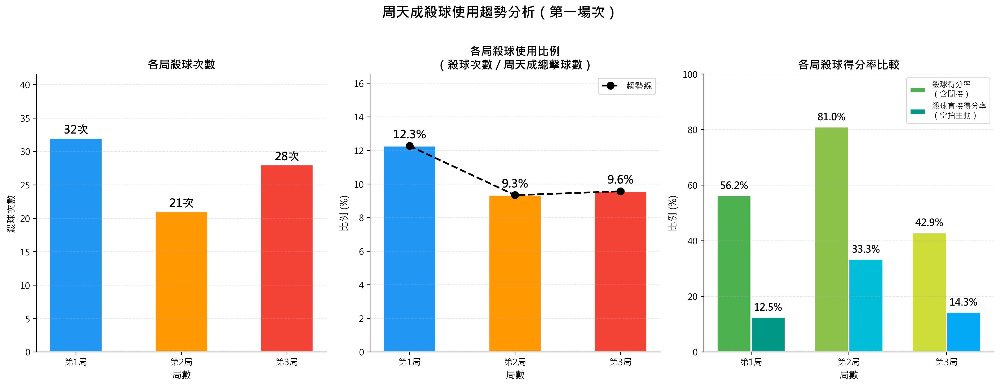

In [ ]:
import numpy as np

# ==================== 數據驗證 ====================
print("=" * 60)
print("數據驗證")
print("=" * 60)
print(f"總資料筆數: {len(df)}")

# 篩選第一場次
match1_df = df[df['match_id'] == 1].copy()
print(f"第一場次資料筆數: {len(match1_df)}")
print(f"第一場次局數分佈: {sorted(match1_df['set'].unique())}")
print(f"第一場次球員: {match1_df['player'].unique()}")

if len(match1_df) == 0:
    print("ERROR: 第一場次無資料！")
else:
    # ==================== 基礎數據建立 ====================
    
    # 1. 對完整 match1_df 建立每個 rally 的最終得分者
    rally_getpoint = (
        match1_df.groupby(['match_id', 'set', 'rally'])['getpoint_player']
        .last()
        .reset_index()
        .rename(columns={'getpoint_player': 'rally_getpoint'})
    )
    
    # 2. 合併回主表
    match1_df = match1_df.merge(rally_getpoint, on=['match_id', 'set', 'rally'], how='left')
    
    # 3. 篩選周天成的擊球
    chou_df = match1_df[match1_df['player'] == 'CHOU Tien Chen'].copy()
    print(f"\n周天成在第一場次的總擊球數: {len(chou_df)}")
    
    # 4. 篩選周天成的殺球
    chou_smash = chou_df[chou_df['type'] == '殺球'].copy()
    print(f"周天成在第一場次的總殺球數: {len(chou_smash)}")
    print(f"殺球局數分佈: {chou_smash.groupby('set').size().to_dict()}")
    
    # ==================== 逐局計算 ====================
    sets = sorted(match1_df['set'].unique())
    results = []
    
    for s in sets:
        # 該局周天成所有擊球
        chou_set = chou_df[chou_df['set'] == s]
        total_strokes = len(chou_set)
        
        # 該局周天成殺球
        chou_smash_set = chou_smash[chou_smash['set'] == s]
        smash_count = len(chou_smash_set)
        
        # 殺球佔比
        smash_ratio = smash_count / total_strokes * 100 if total_strokes > 0 else 0
        
        # ---- 殺球得分率計算 ----
        # 定義：周天成打出殺球的 rally 中，最終周天成得分的比例
        # 注意：一個 rally 可能有多顆殺球，但我們關注「是否存在殺球」且「最終周天成得分」
        # 更精確：以「每一顆殺球」為單位，該殺球所在的 rally 最終是否由周天成得分
        
        # 方法：以每顆殺球為單位
        if smash_count > 0:
            # 有效殺球：rally 最終有人得分（排除 rally_getpoint 為 NaN 的情況）
            valid_smash = chou_smash_set.dropna(subset=['rally_getpoint'])
            valid_smash_count = len(valid_smash)
            
            # 殺球後周天成得分（rally 最終得分者為周天成）
            smash_win = valid_smash[valid_smash['rally_getpoint'] == 'CHOU Tien Chen']
            smash_win_count = len(smash_win)
            
            smash_win_rate = smash_win_count / valid_smash_count * 100 if valid_smash_count > 0 else 0
        else:
            valid_smash_count = 0
            smash_win_count = 0
            smash_win_rate = 0
        
        # ---- 殺球直接得分率（主動得分）====
        # 殺球當拍直接得分：player == getpoint_player
        if smash_count > 0:
            direct_win = chou_smash_set[
                chou_smash_set['rally_getpoint'] == 'CHOU Tien Chen'
            ]
            # 其中直接在殺球那拍得分
            direct_win_active = chou_smash_set[
                (chou_smash_set['rally_getpoint'] == 'CHOU Tien Chen') &
                (chou_smash_set['getpoint_player'] == 'CHOU Tien Chen')
            ]
            direct_win_rate = len(direct_win_active) / smash_count * 100 if smash_count > 0 else 0
        else:
            direct_win_active_count = 0
            direct_win_rate = 0
        
        results.append({
            '局數': f'第{s}局',
            '周天成總擊球數': total_strokes,
            '殺球次數': smash_count,
            '殺球使用比例(%)': round(smash_ratio, 2),
            '殺球所在Rally數(有效)': valid_smash_count if smash_count > 0 else 0,
            '殺球後得分Rally數': smash_win_count if smash_count > 0 else 0,
            '殺球得分率(間接+直接)(%)': round(smash_win_rate, 2),
            '殺球直接得分率(%)': round(direct_win_rate, 2),
        })
    
    results_df = pd.DataFrame(results)
    
    print("\n" + "=" * 60)
    print("逐局殺球使用與得分率分析（周天成 - 第一場次）")
    print("=" * 60)
    print(results_df.to_string(index=False))
    
    # ==================== 補充：各局殺球詳情 ====================
    print("\n" + "=" * 60)
    print("各局殺球詳情（周天成 - 第一場次）")
    print("=" * 60)
    for s in sets:
        chou_smash_set = chou_smash[chou_smash['set'] == s].copy()
        if len(chou_smash_set) == 0:
            print(f"\n第{s}局：無殺球紀錄")
            continue
        
        print(f"\n第{s}局 殺球共 {len(chou_smash_set)} 次：")
        print(f"  - 殺球得分（rally最終周天成得分）: {len(chou_smash_set[chou_smash_set['rally_getpoint']=='CHOU Tien Chen'])} 次")
        print(f"  - 殺球失分（rally最終對手得分）  : {len(chou_smash_set[chou_smash_set['rally_getpoint']=='Kento MOMOTA'])} 次")
        print(f"  - 殺球未定（rally_getpoint為NaN）: {chou_smash_set['rally_getpoint'].isna().sum()} 次")
    
    # ==================== 視覺化 ====================
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    fig.suptitle('周天成殺球使用趨勢分析（第一場次）', fontsize=16, fontweight='bold', y=1.02)
    
    set_labels = results_df['局數'].tolist()
    x = np.arange(len(set_labels))
    
    # --- 圖1：殺球次數 ---
    ax1 = axes[0]
    bars1 = ax1.bar(set_labels, results_df['殺球次數'], 
                    color=['#2196F3', '#FF9800', '#F44336'], 
                    edgecolor='white', linewidth=1.5, width=0.5)
    ax1.set_title('各局殺球次數', fontsize=13, fontweight='bold')
    ax1.set_xlabel('局數', fontsize=11)
    ax1.set_ylabel('殺球次數', fontsize=11)
    ax1.set_ylim(0, max(results_df['殺球次數'].max() * 1.3, 5))
    for bar, val in zip(bars1, results_df['殺球次數']):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{int(val)}次', ha='center', va='bottom', fontsize=13, fontweight='bold')
    ax1.grid(axis='y', alpha=0.3, linestyle='--')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    # --- 圖2：殺球使用比例 ---
    ax2 = axes[1]
    bars2 = ax2.bar(set_labels, results_df['殺球使用比例(%)'],
                    color=['#2196F3', '#FF9800', '#F44336'],
                    edgecolor='white', linewidth=1.5, width=0.5)
    # 加趨勢線
    ax2.plot(x, results_df['殺球使用比例(%)'], 'k--o', linewidth=2, markersize=8, zorder=5, label='趨勢線')
    ax2.set_title('各局殺球使用比例\n（殺球次數 / 周天成總擊球數）', fontsize=13, fontweight='bold')
    ax2.set_xlabel('局數', fontsize=11)
    ax2.set_ylabel('比例 (%)', fontsize=11)
    ax2.set_ylim(0, max(results_df['殺球使用比例(%)'].max() * 1.35, 5))
    for bar, val in zip(bars2, results_df['殺球使用比例(%)']):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(axis='y', alpha=0.3, linestyle='--')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    # --- 圖3：殺球得分率（含直接得分率對比）---
    ax3 = axes[2]
    width = 0.35
    bars3a = ax3.bar(x - width/2, results_df['殺球得分率(間接+直接)(%)'],
                     width=width, label='殺球得分率\n（含間接）', 
                     color=['#4CAF50', '#8BC34A', '#CDDC39'], edgecolor='white', linewidth=1.5)
    bars3b = ax3.bar(x + width/2, results_df['殺球直接得分率(%)'],
                     width=width, label='殺球直接得分率\n（當拍主動）',
                     color=['#009688', '#00BCD4', '#03A9F4'], edgecolor='white', linewidth=1.5)
    ax3.set_title('各局殺球得分率比較', fontsize=13, fontweight='bold')
    ax3.set_xlabel('局數', fontsize=11)
    ax3.set_ylabel('比例 (%)', fontsize=11)
    ax3.set_xticks(x)
    ax3.set_xticklabels(set_labels)
    ax3.set_ylim(0, 100)
    
    for bar, val in zip(bars3a, results_df['殺球得分率(間接+直接)(%)']):
        if val > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                     f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    for bar, val in zip(bars3b, results_df['殺球直接得分率(%)']):
        if val > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                     f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    ax3.legend(fontsize=9, loc='upper right')
    ax3.grid(axis='y', alpha=0.3, linestyle='--')
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    
    plt.tight_layout()
    
    # ==================== 趨勢分析摘要 ====================
    print("\n" + "=" * 60)
    print("趨勢分析摘要")
    print("=" * 60)
    
    if len(sets) >= 2:
        first_smash_ratio = results_df['殺球使用比例(%)'].iloc[0]
        last_smash_ratio = results_df['殺球使用比例(%)'].iloc[-1]
        first_win_rate = results_df['殺球得分率(間接+直接)(%)'].iloc[0]
        last_win_rate = results_df['殺球得分率(間接+直接)(%)'].iloc[-1]
        
        print(f"\n殺球使用比例變化：")
        for _, row in results_df.iterrows():
            print(f"  {row['局數']}: {row['殺球使用比例(%)']:.1f}%  (殺球{int(row['殺球次數'])}次 / 總擊球{int(row['周天成總擊球數'])}次)")
        
        smash_ratio_change = last_smash_ratio - first_smash_ratio
        print(f"  → 第一局到最後一局變化: {smash_ratio_change:+.1f}%")
        
        print(f"\n殺球得分率變化（含間接得分）：")
        for _, row in results_df.iterrows():
            print(f"  {row['局數']}: {row['殺球得分率(間接+直接)(%)']:.1f}%  (得分{int(row['殺球後得分Rally數'])}次 / 有效殺球{int(row['殺球所在Rally數(有效)'])}次)")
        
        win_rate_change = last_win_rate - first_win_rate
        print(f"  → 第一局到最後一局變化: {win_rate_change:+.1f}%")
        
        print(f"\n殺球直接得分率變化：")
        for _, row in results_df.iterrows():
            print(f"  {row['局數']}: {row['殺球直接得分率(%)']:.1f}%")
        
        print(f"\n【結論】")
        trend_smash = "下滑" if smash_ratio_change < -1 else ("上升" if smash_ratio_change > 1 else "持平")
        trend_win = "下滑" if win_rate_change < -5 else ("上升" if win_rate_change > 5 else "持平")
        print(f"  殺球使用比例趨勢: {trend_smash} ({smash_ratio_change:+.1f}%)")
        print(f"  殺球得分率趨勢  : {trend_win} ({win_rate_change:+.1f}%)")


### 數據洞察
# 周天成 第一場次 逐局殺球分析

## 核心數據總覽

| 局數 | 殺球次數 | 使用比例 | 得分率（含間接） | 直接得分率 | 得分/失分 |
|------|---------|---------|----------------|-----------|---------|
| 第1局 | 32次 | 12.3% | 56.3% | 12.5% | 18勝/14敗 |
| 第2局 | 21次 | 9.3% | **81.0%** | **33.3%** | 17勝/4敗 |
| 第3局 | 28次 | 9.6% | 42.9% | 14.3% | 12勝/16敗 |

---

## 戰術解讀

**第1局：殺球過度，效率不足**
使用率最高（12.3%），但得分率僅56%、失分14次——殺球頻繁但對手已有準備，被動防守轉攻的情況偏多。

**第2局：最佳狀態，殺球質量最高**
使用率降至9.3%，得分率卻飆升至81%，直接得分率達33%。**減少使用、提高突然性**，是這局殺球奏效的關鍵。每4球殺球就有1球直接得分，對手完全來不及反應。

**第3局：體能下滑，殺球成負擔**
殺球次數回升至28次，但得分率跌至42.9%，**失分16次已超過得分12次**——殺球從得分武器變成失分來源。體能下降導致殺球品質不穩，對手桃田反而藉此反攻。

---

## 教練結論

> 數據說明一件事：**第3局周天成不應該增加殺球頻率**。
> 第2局的成功來自「少用、精準、突然」；第3局體能不足時強行殺球，反而讓對手佔到便宜。
> 建議決勝局應維持第2局節奏，以切球、平球消耗對手，保留殺球作為**關鍵分的一擊**，而非常規進攻手段。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了第一場比賽中周天成的擊球資料，並計算了每局的殺球使用頻率和得分率。候選程式碼還進一步分析了殺球的直接得分率，並提供了詳細的視覺化和趨勢分析，這些都與 Reference Code 1 的目標一致。




## 題號 22 (*)
**問題**: 分析周天成在不同比分階段(開局:0-4分,中局:5-17分,關鍵分:18分以上)中，使用不同球種的頻率變化趨勢
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


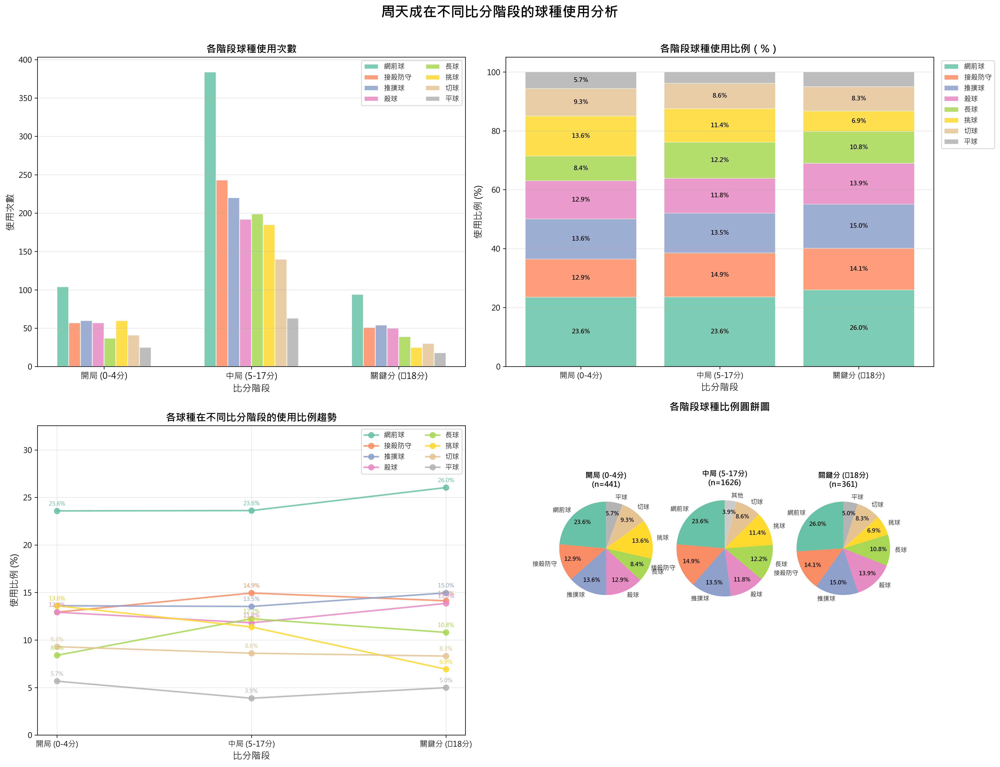

In [ ]:
import numpy as np

# ============================================================
# 驗證數據量
# ============================================================
print(f"總資料量: {len(df)} 筆")
assert len(df) > 0, "資料為空，請檢查 df"

# ============================================================
# 篩選周天成的擊球資料（排除發球球種）
# ============================================================
player_name = 'CHOU Tien Chen'

# 排除發球球種，保留實際比賽球種
non_serve_types = ['長球', '殺球', '切球', '挑球', '平球', '網前球', '推撲球', '接殺防守']

chou_df = df[
    (df['player'] == player_name) &
    (df['type'].isin(non_serve_types))
].copy()

print(f"周天成非發球擊球總筆數: {len(chou_df)} 筆")

# ============================================================
# 定義比分階段
# 使用 CHOU Tien Chen_score 和 Kento MOMOTA_score
# ============================================================
chou_score_col = 'CHOU Tien Chen_score'
momota_score_col = 'Kento MOMOTA_score'

def classify_stage(row):
    chou_s = row[chou_score_col]
    momota_s = row[momota_score_col]
    
    # 開局：雙方得分皆在 0~4
    if chou_s <= 4 and momota_s <= 4:
        return '開局 (0-4分)'
    # 關鍵分：任一方達 18 分以上
    elif chou_s >= 18 or momota_s >= 18:
        return '關鍵分 (≥18分)'
    # 中局：其餘（至少一方達5分，且無人達18分）
    else:
        return '中局 (5-17分)'

chou_df['stage'] = chou_df.apply(classify_stage, axis=1)

# 確認各階段數量
stage_counts = chou_df['stage'].value_counts()
print("\n各比分階段資料量:")
print(stage_counts)

# ============================================================
# 各階段球種統計
# ============================================================
stage_order = ['開局 (0-4分)', '中局 (5-17分)', '關鍵分 (≥18分)']

# 各階段球種頻率
stage_type_counts = chou_df.groupby(['stage', 'type']).size().unstack(fill_value=0)

# 補齊可能缺失的 stage
for s in stage_order:
    if s not in stage_type_counts.index:
        stage_type_counts.loc[s] = 0
stage_type_counts = stage_type_counts.loc[stage_order]

# 各階段球種比例（百分比）
stage_type_pct = stage_type_counts.div(stage_type_counts.sum(axis=1), axis=0) * 100

print("\n=== 各階段球種使用次數 ===")
print(stage_type_counts.to_string())

print("\n=== 各階段球種使用比例 (%) ===")
print(stage_type_pct.round(2).to_string())

# ============================================================
# 計算整體球種排序（按總使用次數降序）
# ============================================================
type_total = stage_type_counts.sum(axis=0).sort_values(ascending=False)
sorted_types = type_total.index.tolist()
print(f"\n球種總使用次數排序: {dict(type_total)}")

# 依總使用量重排欄位
stage_type_counts = stage_type_counts[sorted_types]
stage_type_pct = stage_type_pct[sorted_types]

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('周天成在不同比分階段的球種使用分析', fontsize=18, fontweight='bold', y=0.98)

# 定義顏色
colors = sns.color_palette("Set2", len(sorted_types))
color_map = dict(zip(sorted_types, colors))

# ----- 圖1：各階段球種使用次數（分組長條圖）-----
ax1 = axes[0, 0]
x = np.arange(len(stage_order))
n_types = len(sorted_types)
bar_width = 0.08
offsets = np.linspace(-(n_types-1)/2 * bar_width, (n_types-1)/2 * bar_width, n_types)

for i, shot_type in enumerate(sorted_types):
    vals = [stage_type_counts.loc[s, shot_type] if shot_type in stage_type_counts.columns else 0 for s in stage_order]
    bars = ax1.bar(x + offsets[i], vals, width=bar_width, label=shot_type, color=color_map[shot_type], alpha=0.85, edgecolor='white')

ax1.set_xticks(x)
ax1.set_xticklabels(stage_order, fontsize=11)
ax1.set_xlabel('比分階段', fontsize=12)
ax1.set_ylabel('使用次數', fontsize=12)
ax1.set_title('各階段球種使用次數', fontsize=13, fontweight='bold')
ax1.legend(loc='upper right', fontsize=9, ncol=2)
ax1.grid(axis='y', alpha=0.3)

# ----- 圖2：各階段球種比例（堆疊長條圖）-----
ax2 = axes[0, 1]
bottom_vals = np.zeros(len(stage_order))
stage_labels = stage_order

for i, shot_type in enumerate(sorted_types):
    vals = stage_type_pct[shot_type].values
    bars = ax2.bar(stage_labels, vals, bottom=bottom_vals, label=shot_type,
                   color=color_map[shot_type], alpha=0.85, edgecolor='white', linewidth=0.5)
    # 在比例 > 5% 時顯示標籤
    for j, (v, b) in enumerate(zip(vals, bottom_vals)):
        if v > 5:
            ax2.text(j, b + v/2, f'{v:.1f}%', ha='center', va='center',
                     fontsize=8, fontweight='bold', color='black')
    bottom_vals += vals

ax2.set_ylim(0, 105)
ax2.set_xlabel('比分階段', fontsize=12)
ax2.set_ylabel('使用比例 (%)', fontsize=12)
ax2.set_title('各階段球種使用比例（%）', fontsize=13, fontweight='bold')
ax2.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
ax2.grid(axis='y', alpha=0.3)

# ----- 圖3：各球種在不同階段的比例折線圖（趨勢）-----
ax3 = axes[1, 0]

for shot_type in sorted_types:
    vals = stage_type_pct[shot_type].values
    ax3.plot(stage_order, vals, marker='o', linewidth=2, markersize=7,
             label=shot_type, color=color_map[shot_type], alpha=0.85)
    # 標記端點數值
    for xi, (s, v) in enumerate(zip(stage_order, vals)):
        if v > 2:  # 只標記比例 > 2% 的點避免雜亂
            ax3.annotate(f'{v:.1f}%', (s, v), textcoords="offset points",
                        xytext=(0, 7), ha='center', fontsize=7.5, color=color_map[shot_type])

ax3.set_xlabel('比分階段', fontsize=12)
ax3.set_ylabel('使用比例 (%)', fontsize=12)
ax3.set_title('各球種在不同比分階段的使用比例趨勢', fontsize=13, fontweight='bold')
ax3.legend(loc='upper right', fontsize=9, ncol=2)
ax3.grid(alpha=0.3)
ax3.set_ylim(0, max(stage_type_pct.values.max() * 1.25, 10))

# ----- 圖4：各階段主要球種 Pie Chart（3 個子圖）-----
ax4 = axes[1, 1]
ax4.axis('off')

# 在 ax4 位置畫三個小 pie
inner_axes_positions = [
    [0.0,  0.0, 0.33, 1.0],
    [0.33, 0.0, 0.34, 1.0],
    [0.67, 0.0, 0.33, 1.0],
]

stage_colors_main = ['#4ECDC4', '#FFE66D', '#FF6B6B']

for idx, stage in enumerate(stage_order):
    # 取得 ax4 在 fig 中的位置
    ax4_pos = ax4.get_position()
    left = ax4_pos.x0 + inner_axes_positions[idx][0] * ax4_pos.width
    bottom = ax4_pos.y0 + inner_axes_positions[idx][1] * ax4_pos.height
    width = inner_axes_positions[idx][2] * ax4_pos.width
    height = inner_axes_positions[idx][3] * ax4_pos.height
    
    ax_pie = fig.add_axes([left, bottom, width, height])
    
    vals = stage_type_counts.loc[stage]
    vals = vals[vals > 0]
    
    # 小比例合併為「其他」
    threshold = vals.sum() * 0.04
    main = vals[vals >= threshold]
    other_sum = vals[vals < threshold].sum()
    if other_sum > 0:
        main['其他'] = other_sum
    
    pie_colors = [color_map.get(t, '#999999') if t != '其他' else '#CCCCCC' for t in main.index]
    
    wedges, texts, autotexts = ax_pie.pie(
        main.values,
        labels=main.index,
        autopct='%1.1f%%',
        colors=pie_colors,
        startangle=90,
        pctdistance=0.75,
        textprops={'fontsize': 8}
    )
    for autotext in autotexts:
        autotext.set_fontsize(7.5)
        autotext.set_fontweight('bold')
    
    total_shots = stage_type_counts.loc[stage].sum()
    ax_pie.set_title(f'{stage}\n(n={total_shots})', fontsize=9.5, fontweight='bold', pad=4)

# 在 ax4 上添加大標題
ax4.set_title('各階段球種比例圓餅圖', fontsize=13, fontweight='bold', pad=20)

plt.tight_layout(rect=[0, 0, 1, 0.97])

# ============================================================
# 輸出詳細統計摘要
# ============================================================
print("\n" + "="*60)
print("📊 周天成各比分階段球種使用詳細統計")
print("="*60)

for stage in stage_order:
    total = stage_type_counts.loc[stage].sum()
    print(f"\n【{stage}】 總擊球數: {total}")
    stage_data = stage_type_pct.loc[stage].sort_values(ascending=False)
    for shot, pct in stage_data.items():
        count = stage_type_counts.loc[stage, shot]
        if count > 0:
            print(f"  {shot:8s}: {count:4d} 次  ({pct:.1f}%)")

print("\n" + "="*60)
print("📈 各球種跨階段比例變化摘要")
print("="*60)
print(f"{'球種':<8} {'開局':>10} {'中局':>10} {'關鍵分':>10} {'變化趨勢':>12}")
print("-"*55)
for shot in sorted_types:
    v1 = stage_type_pct.loc[stage_order[0], shot]
    v2 = stage_type_pct.loc[stage_order[1], shot]
    v3 = stage_type_pct.loc[stage_order[2], shot]
    delta = v3 - v1
    trend = "↑ 增加" if delta > 2 else ("↓ 減少" if delta < -2 else "→ 持平")
    print(f"{shot:<8} {v1:>9.1f}% {v2:>9.1f}% {v3:>9.1f}% {trend:>12}")


### 數據洞察
# 周天成各比分階段球種分佈分析

## 核心數據總覽

| 球種 | 開局 (0-4分) | 中局 (5-17分) | 關鍵分 (≥18分) | 趨勢 |
|------|:-----------:|:------------:|:-------------:|:----:|
| 網前球 | 23.6% | 23.6% | **26.0%** | ↑ |
| 推撲球 | 13.6% | 13.5% | **15.0%** | ↑ |
| 接殺防守 | 12.9% | **14.9%** | 14.1% | → |
| 殺球 | 12.9% | 11.8% | **13.9%** | → |
| 長球 | 8.4% | **12.2%** | 10.8% | ↑ |
| 挑球 | **13.6%** | 11.4% | 6.9% | ↓ |
| 切球 | 9.3% | 8.6% | 8.3% | → |
| 平球 | 5.7% | 3.9% | 5.0% | → |

---

## 三大戰術洞察

### 1️⃣ 網前球是全場核心武器
三個階段始終佔比最高（23.6% → 23.6% → **26.0%**），關鍵分時更強化使用。周天成以網前控制為戰術主軸，壓迫對手在前場失誤，這在高壓情境下反而更明顯。

### 2️⃣ 關鍵分時「挑球大幅減少」是最顯著變化
挑球從開局 **13.6% 驟降至關鍵分 6.9%**，幾乎腰斬。這代表周天成在關鍵分刻意減少被動挑高球，避免給對手殺球機會，轉而以推撲球（↑15.0%）主動搶攻前場。

### 3️⃣ 中局長球使用明顯拉高
長球在中局達到 **12.2%**（開局僅8.4%），顯示周天成在中段積極拉開場面、消耗對手體力，建立後場控制節奏。

---

## 教練建議

> **對手備戰重點**：關鍵分時，周天成會減少挑球、強化網前與推撲，應預備前場快速反應能力，並在中局避免被長球拉至後場消耗。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼在比分階段的定義上與 Reference Code 不一致。Reference Code 1 將比分階段定義為開局 (0-4分)、中局 (5-17分)、關鍵分 (18分以上)，而候選程式碼將開局定義為雙方得分皆在 0~4，關鍵分定義為任一方達 18 分以上，這導致比分階段的劃分不一致。此外，候選程式碼在計算球種使用頻率時，未考慮到 Reference Code 1 中的 observed=True 參數，可能導致結果不一致。因此，候選程式碼不符合任何一份 Reference Code 的核心邏輯。




## 題號 23
**問題**: 在關鍵分(18分以上)時，周天成採用的擊球策略與其他階段有何不同？
> **使用的資料欄位群組**: `game_structure, shot_type, stroke_details, scoring_reason, coordinates`


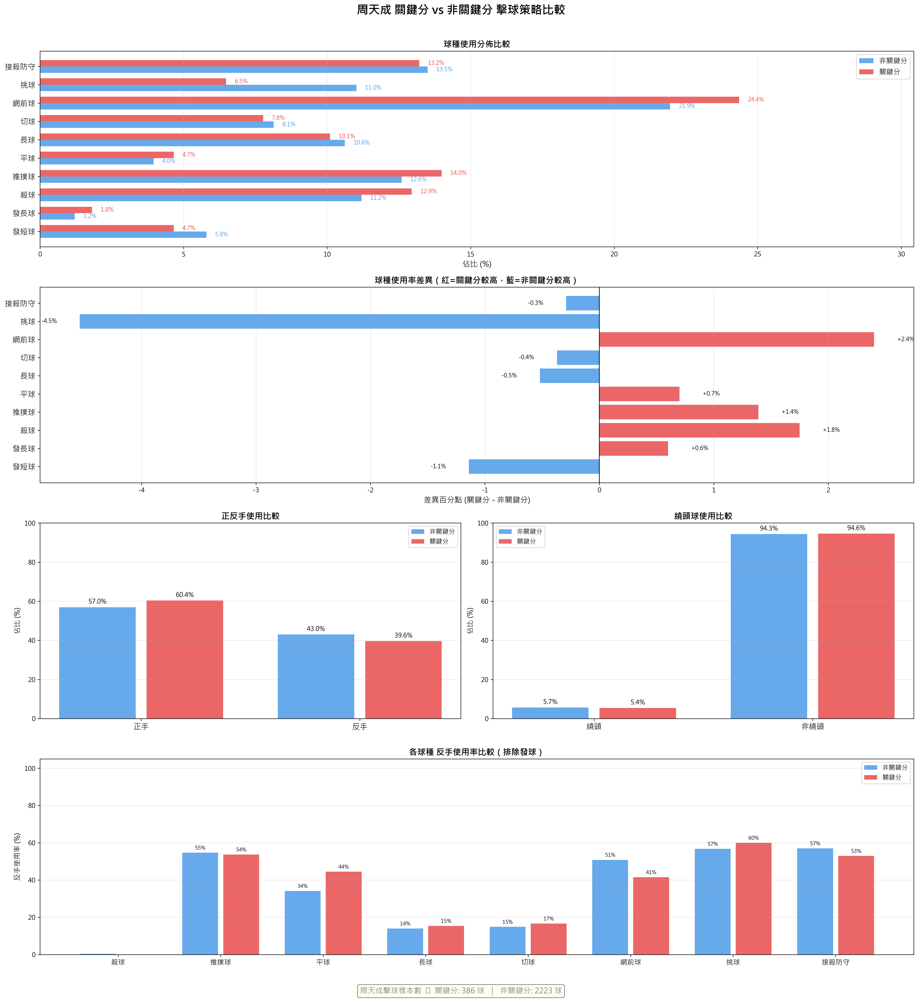

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"周天成擊球筆數: {len(df[df['player'] == 'CHOU Tien Chen'])}")
print(f"比分欄位檢查: MOMOTA最大={df['Kento MOMOTA_score'].max()}, CHOU最大={df['CHOU Tien Chen_score'].max()}")

# ============================================================
# 1. 定義關鍵分與非關鍵分
# ============================================================
# 關鍵分：任一方得分達18分或以上
is_critical = (df['Kento MOMOTA_score'] >= 18) | (df['CHOU Tien Chen_score'] >= 18)
# 非關鍵分：雙方得分皆未達18分
is_non_critical = (df['Kento MOMOTA_score'] < 18) & (df['CHOU Tien Chen_score'] < 18)

print(f"\n關鍵分局面總擊球數: {is_critical.sum()}")
print(f"非關鍵分局面總擊球數: {is_non_critical.sum()}")

# ============================================================
# 2. 篩選周天成在兩個階段的擊球
# ============================================================
chou = df[df['player'] == 'CHOU Tien Chen'].copy()
chou_critical    = chou[(chou['Kento MOMOTA_score'] >= 18) | (chou['CHOU Tien Chen_score'] >= 18)].copy()
chou_noncritical = chou[(chou['Kento MOMOTA_score'] < 18) & (chou['CHOU Tien Chen_score'] < 18)].copy()

print(f"\n周天成 - 關鍵分擊球數: {len(chou_critical)}")
print(f"周天成 - 非關鍵分擊球數: {len(chou_noncritical)}")

# ============================================================
# 3. 球種分佈計算（含百分比）
# ============================================================
# 定義球種順序（依照戰術邏輯排序）
shot_order = ['發短球', '發長球', '殺球', '推撲球', '平球', '長球', '切球', '網前球', '挑球', '接殺防守']

def get_shot_pct(subset, order):
    counts = subset['type'].value_counts()
    total = len(subset)
    pct = (counts / total * 100).round(2)
    # 補齊所有球種
    result = pd.DataFrame({'count': counts, 'pct': pct})
    result = result.reindex(order, fill_value=0)
    return result

shot_crit    = get_shot_pct(chou_critical, shot_order)
shot_noncrit = get_shot_pct(chou_noncritical, shot_order)

print("\n===== 球種分佈比較 =====")
compare_shot = pd.DataFrame({
    '非關鍵分(%)': shot_noncrit['pct'],
    '關鍵分(%)':   shot_crit['pct'],
    '差異(關鍵-非關鍵)': (shot_crit['pct'] - shot_noncrit['pct']).round(2)
})
print(compare_shot.to_string())

# ============================================================
# 4. 正反手分佈
# ============================================================
def get_hand_pct(subset):
    total = len(subset)
    fh = (subset['backhand'] == 0).sum()
    bh = (subset['backhand'] == 1).sum()
    return {'正手(%)': round(fh/total*100, 2), '反手(%)': round(bh/total*100, 2)}

hand_crit    = get_hand_pct(chou_critical)
hand_noncrit = get_hand_pct(chou_noncritical)

print("\n===== 正反手分佈比較 =====")
print(f"非關鍵分: {hand_noncrit}")
print(f"關鍵分:   {hand_crit}")

# ============================================================
# 5. 繞頭球分佈
# ============================================================
def get_aroundhead_pct(subset):
    total = len(subset)
    ah = (subset['aroundhead'] == 1).sum()
    return {'繞頭(%)': round(ah/total*100, 2), '非繞頭(%)': round((total-ah)/total*100, 2)}

ah_crit    = get_aroundhead_pct(chou_critical)
ah_noncrit = get_aroundhead_pct(chou_noncritical)

print("\n===== 繞頭球分佈比較 =====")
print(f"非關鍵分: {ah_noncrit}")
print(f"關鍵分:   {ah_crit}")

# ============================================================
# 6. 排除發球後，各球種的正反手 & 繞頭球細節
# ============================================================
serve_types = ['發短球', '發長球']
chou_crit_noserve    = chou_critical[~chou_critical['type'].isin(serve_types)]
chou_noncrit_noserve = chou_noncritical[~chou_noncritical['type'].isin(serve_types)]

# 各球種 正反手 繞頭 明細
def detail_by_shot(subset, stage_name):
    grp = subset.groupby('type').agg(
        次數=('type', 'count'),
        反手率=('backhand', lambda x: f"{x.mean()*100:.1f}%"),
        繞頭率=('aroundhead', lambda x: f"{x.mean()*100:.1f}%"),
    ).reset_index()
    grp['階段'] = stage_name
    return grp

detail_crit    = detail_by_shot(chou_crit_noserve, '關鍵分')
detail_noncrit = detail_by_shot(chou_noncrit_noserve, '非關鍵分')

print("\n===== 各球種細節（排除發球）=====")
print("--- 關鍵分 ---")
print(detail_crit.to_string(index=False))
print("\n--- 非關鍵分 ---")
print(detail_noncrit.to_string(index=False))

# ============================================================
# 7. 視覺化
# ============================================================
fig = plt.figure(figsize=(20, 22))
fig.suptitle("周天成 關鍵分 vs 非關鍵分 擊球策略比較", fontsize=18, fontweight='bold', y=0.98)

colors_stage = ['#4C9BE8', '#E84C4C']  # 藍=非關鍵, 紅=關鍵

# ── 圖1: 球種分佈橫條圖（百分比） ──
ax1 = fig.add_subplot(4, 2, (1, 2))

x = np.arange(len(shot_order))
width = 0.35
bars1 = ax1.barh(x - width/2, shot_noncrit['pct'].values, width, 
                  label='非關鍵分', color=colors_stage[0], alpha=0.85)
bars2 = ax1.barh(x + width/2, shot_crit['pct'].values, width, 
                  label='關鍵分', color=colors_stage[1], alpha=0.85)

ax1.set_yticks(x)
ax1.set_yticklabels(shot_order, fontsize=12)
ax1.set_xlabel('佔比 (%)', fontsize=12)
ax1.set_title('球種使用分佈比較', fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.axvline(0, color='black', linewidth=0.5)

# 添加數值標籤
for bar in bars1:
    w = bar.get_width()
    if w > 0.5:
        ax1.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', 
                 va='center', fontsize=9, color=colors_stage[0])
for bar in bars2:
    w = bar.get_width()
    if w > 0.5:
        ax1.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', 
                 va='center', fontsize=9, color=colors_stage[1])
ax1.set_xlim(0, max(shot_noncrit['pct'].max(), shot_crit['pct'].max()) * 1.25)
ax1.grid(axis='x', alpha=0.3)

# ── 圖2: 差異圖（關鍵分 - 非關鍵分） ──
ax2 = fig.add_subplot(4, 2, (3, 4))

diff_vals = (shot_crit['pct'] - shot_noncrit['pct']).values
bar_colors = ['#E84C4C' if v > 0 else '#4C9BE8' for v in diff_vals]
bars_diff = ax2.barh(x, diff_vals, color=bar_colors, alpha=0.85)
ax2.set_yticks(x)
ax2.set_yticklabels(shot_order, fontsize=12)
ax2.axvline(0, color='black', linewidth=1)
ax2.set_xlabel('差異百分點 (關鍵分 - 非關鍵分)', fontsize=12)
ax2.set_title('球種使用率差異（紅=關鍵分較高，藍=非關鍵分較高）', fontsize=13, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

for bar, val in zip(bars_diff, diff_vals):
    if abs(val) > 0.2:
        ax2.text(val + (0.2 if val > 0 else -0.2), 
                 bar.get_y() + bar.get_height()/2,
                 f'{val:+.1f}%', va='center', 
                 ha='left' if val > 0 else 'right', fontsize=9)

# ── 圖3: 正反手比較（分組長條圖） ──
ax3 = fig.add_subplot(4, 2, 5)

hand_labels = ['正手', '反手']
hand_noncrit_vals = [hand_noncrit['正手(%)'], hand_noncrit['反手(%)']]
hand_crit_vals    = [hand_crit['正手(%)'],    hand_crit['反手(%)']]

x3 = np.arange(len(hand_labels))
b3a = ax3.bar(x3 - 0.2, hand_noncrit_vals, 0.35, label='非關鍵分', color=colors_stage[0], alpha=0.85)
b3b = ax3.bar(x3 + 0.2, hand_crit_vals,    0.35, label='關鍵分',   color=colors_stage[1], alpha=0.85)
ax3.set_xticks(x3)
ax3.set_xticklabels(hand_labels, fontsize=12)
ax3.set_ylabel('佔比 (%)', fontsize=11)
ax3.set_title('正反手使用比較', fontsize=13, fontweight='bold')
ax3.legend(fontsize=10)
ax3.set_ylim(0, 100)
ax3.grid(axis='y', alpha=0.3)

for bar in list(b3a) + list(b3b):
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 1, f'{h:.1f}%', 
             ha='center', va='bottom', fontsize=10)

# ── 圖4: 繞頭球比較 ──
ax4 = fig.add_subplot(4, 2, 6)

ah_labels = ['繞頭', '非繞頭']
ah_noncrit_vals = [ah_noncrit['繞頭(%)'], ah_noncrit['非繞頭(%)']]
ah_crit_vals    = [ah_crit['繞頭(%)'],    ah_crit['非繞頭(%)']]

x4 = np.arange(len(ah_labels))
b4a = ax4.bar(x4 - 0.2, ah_noncrit_vals, 0.35, label='非關鍵分', color=colors_stage[0], alpha=0.85)
b4b = ax4.bar(x4 + 0.2, ah_crit_vals,    0.35, label='關鍵分',   color=colors_stage[1], alpha=0.85)
ax4.set_xticks(x4)
ax4.set_xticklabels(ah_labels, fontsize=12)
ax4.set_ylabel('佔比 (%)', fontsize=11)
ax4.set_title('繞頭球使用比較', fontsize=13, fontweight='bold')
ax4.legend(fontsize=10)
ax4.set_ylim(0, 100)
ax4.grid(axis='y', alpha=0.3)

for bar in list(b4a) + list(b4b):
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2, h + 1, f'{h:.1f}%', 
             ha='center', va='bottom', fontsize=10)

# ── 圖5 & 6: 各球種(排除發球) 反手率 & 繞頭率比較 ──
# 合併兩個階段的資料
all_types_noserve = [t for t in shot_order if t not in serve_types]

def get_detail_rate(subset, types):
    rates = {}
    for t in types:
        sub = subset[subset['type'] == t]
        if len(sub) > 0:
            rates[t] = {'反手率': sub['backhand'].mean()*100, 
                        '繞頭率': sub['aroundhead'].mean()*100,
                        'n': len(sub)}
        else:
            rates[t] = {'反手率': 0, '繞頭率': 0, 'n': 0}
    return rates

rates_crit    = get_detail_rate(chou_crit_noserve,    all_types_noserve)
rates_noncrit = get_detail_rate(chou_noncrit_noserve, all_types_noserve)

# 過濾掉樣本數太少（<3）的球種
valid_types = [t for t in all_types_noserve 
               if rates_crit[t]['n'] >= 3 or rates_noncrit[t]['n'] >= 3]

x5 = np.arange(len(valid_types))

# 反手率比較
ax5 = fig.add_subplot(4, 2, (7, 8))
bh_noncrit = [rates_noncrit[t]['反手率'] for t in valid_types]
bh_crit    = [rates_crit[t]['反手率']    for t in valid_types]

b5a = ax5.bar(x5 - 0.2, bh_noncrit, 0.35, label='非關鍵分', color=colors_stage[0], alpha=0.85)
b5b = ax5.bar(x5 + 0.2, bh_crit,    0.35, label='關鍵分',   color=colors_stage[1], alpha=0.85)
ax5.set_xticks(x5)
ax5.set_xticklabels(valid_types, fontsize=11)
ax5.set_ylabel('反手使用率 (%)', fontsize=11)
ax5.set_title('各球種 反手使用率比較（排除發球）', fontsize=13, fontweight='bold')
ax5.legend(fontsize=10)
ax5.set_ylim(0, 105)
ax5.grid(axis='y', alpha=0.3)

for bar in list(b5a) + list(b5b):
    h = bar.get_height()
    if h > 2:
        ax5.text(bar.get_x() + bar.get_width()/2, h + 1, f'{h:.0f}%', 
                 ha='center', va='bottom', fontsize=8)

# ── 樣本數標注 ──
# 在底部加上樣本數說明
sample_info = "\n".join([
    f"周天成擊球樣本數  ▸  關鍵分: {len(chou_critical)} 球  ｜  非關鍵分: {len(chou_noncritical)} 球"
])
fig.text(0.5, 0.01, sample_info, ha='center', fontsize=12, 
         style='italic', color='gray',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

plt.tight_layout(rect=[0, 0.03, 1, 0.97])

# ============================================================
# 8. 額外摘要：繞頭球各球種明細
# ============================================================
print("\n===== 繞頭球各球種明細比較（排除發球，樣本≥3） =====")
ah_compare = pd.DataFrame({
    '球種': valid_types,
    '非關鍵分_繞頭率(%)': [round(rates_noncrit[t]['繞頭率'], 1) for t in valid_types],
    '非關鍵分_樣本數':     [rates_noncrit[t]['n'] for t in valid_types],
    '關鍵分_繞頭率(%)':   [round(rates_crit[t]['繞頭率'], 1) for t in valid_types],
    '關鍵分_樣本數':       [rates_crit[t]['n'] for t in valid_types],
})
ah_compare['繞頭率差異(關鍵-非關鍵)'] = (ah_compare['關鍵分_繞頭率(%)'] - ah_compare['非關鍵分_繞頭率(%)']).round(1)
print(ah_compare.to_string(index=False))

print("\n===== 整體統計摘要 =====")
print(f"{'指標':<20} {'非關鍵分':>12} {'關鍵分':>12} {'差異(關鍵-非關鍵)':>18}")
print("-" * 65)
print(f"{'樣本數(球)':<20} {len(chou_noncritical):>12} {len(chou_critical):>12}")
print(f"{'反手率(%)':<20} {hand_noncrit['反手(%)']:>12.1f} {hand_crit['反手(%)']:>12.1f} {hand_crit['反手(%)']-hand_noncrit['反手(%)']:>+18.1f}")
print(f"{'繞頭率(%)':<20} {ah_noncrit['繞頭(%)']:>12.1f} {ah_crit['繞頭(%)']:>12.1f} {ah_crit['繞頭(%)']-ah_noncrit['繞頭(%)']:>+18.1f}")


### 數據洞察
# 周天成關鍵分擊球策略分析

## 核心數據摘要

| 指標 | 非關鍵分 | 關鍵分 | 差異 |
|------|---------|--------|------|
| 樣本數 | 2,223球 | 386球 | — |
| 正手率 | 56.95% | 60.36% | **+3.41%** |
| 反手率 | 43.05% | 39.64% | **-3.41%** |
| 繞頭率 | 5.67% | 5.44% | -0.23% |

---

## 一、球種策略位移

### 關鍵分明顯增加的球種
| 球種 | 非關鍵分 | 關鍵分 | 差異 |
|------|---------|--------|------|
| 網前球 | 21.95% | 24.35% | **+2.40%** |
| 殺球 | 11.20% | 12.95% | **+1.75%** |
| 推撲球 | 12.60% | 13.99% | **+1.39%** |

### 關鍵分明顯減少的球種
| 球種 | 非關鍵分 | 關鍵分 | 差異 |
|------|---------|--------|------|
| 挑球 | 11.02% | 6.48% | **-4.54%** |
| 發短球 | 5.80% | 4.66% | -1.14% |

---

## 二、擊球動作細節差異

### 反手率變化（各球種）
| 球種 | 非關鍵分反手率 | 關鍵分反手率 | 差異 |
|------|-------------|------------|------|
| 網前球 | 50.8% | 41.5% | **-9.3%** |
| 接殺防守 | 57.0% | 52.9% | -4.1% |
| 平球 | 34.1% | 44.4% | **+10.3%** |
| 挑球 | 56.7% | 60.0% | +3.3% |

### 繞頭率（幾乎不變）
- 殺球繞頭率：非關鍵分 24.5% vs 關鍵分 24.0%，**差異僅 -0.5%**
- 長球繞頭率：22.9% vs 23.1%，**幾乎持平**

---

## 三、戰術洞察

**① 關鍵分主動壓制意圖明顯**
網前球+殺球+推撲球三項合計佔比從 45.75% 升至 51.29%，**增加 5.54%**。周天成在關鍵分傾向縮短拍數、主動製造壓力，而非打持久戰。

**② 挑球大幅減少是最顯著信號**
挑球下降 4.54%，代表他刻意避免在關鍵分將球挑高給對手進攻機會，**降低被動挨打的風險**。

**③ 正手主導性在關鍵分更強**
整體正手率從 56.95% 升至 60.36%，且網前球反手率從 50.8% 降至 41.5%（**-9.3%**），顯示他在關鍵分更依賴正手網前處理，**追求更穩定的控制品質**。

**④ 繞頭習慣不受壓力影響**
殺球與長球的繞頭率在兩階段幾乎相同，說明繞頭是其**固化的技術習慣**，並非因應壓力的臨時調整。

---

> **教練結語：** 周天成關鍵分的策略邏輯清晰——**進攻更主動、被動球更少、正手更優先**。挑球減少4.54%是最值得對手研究的數據，代表他不願在關鍵分讓對手獲得頭頂進攻機會。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在關鍵分和非關鍵分階段的擊球策略，並計算了不同球種的使用比例、正反手比例、繞頭球比例等。候選程式碼的分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，並且能夠產出有效的結果。




## 題號 24 (*)
**問題**: 周天成在長回合相較於短回合較常失誤的球種?
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


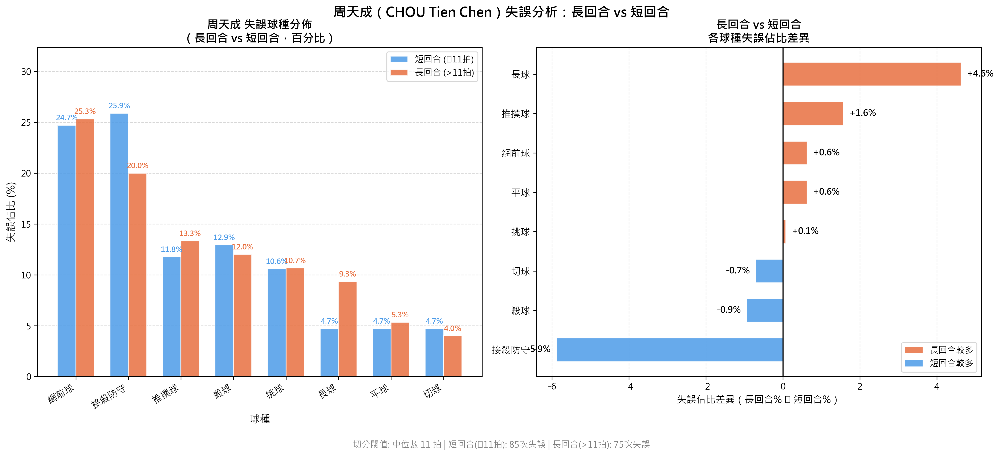

In [ ]:
import numpy as np

# =====================================================================
# 數據驗證
# =====================================================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

# =====================================================================
# Step 1: 計算每個 Rally 的總球數（回合長度）
# =====================================================================
rally_length = (
    df.groupby(['match_id', 'set', 'rally'])['ball_round']
    .max()
    .reset_index()
    .rename(columns={'ball_round': 'rally_length'})
)

print(f"\n回合球數分佈統計:")
print(rally_length['rally_length'].describe())

# 使用中位數作為長/短回合切分閾值
median_len = rally_length['rally_length'].median()
q1 = rally_length['rally_length'].quantile(0.33)
q2 = rally_length['rally_length'].quantile(0.67)

print(f"\n中位數: {median_len}")
print(f"Q1 (33th): {q1}, Q2 (67th): {q2}")

# 定義長回合 / 短回合：
# 短回合：球數 <= 中位數
# 長回合：球數 > 中位數
threshold = median_len
rally_length['rally_type'] = rally_length['rally_length'].apply(
    lambda x: '長回合' if x > threshold else '短回合'
)

print(f"\n切分閾值（中位數）: {threshold} 拍")
print(f"短回合 (≤{threshold} 拍): {(rally_length['rally_type']=='短回合').sum()} 個")
print(f"長回合 (>{threshold} 拍): {(rally_length['rally_type']=='長回合').sum()} 個")

# =====================================================================
# Step 2: 將 rally_type 合併回主 df
# =====================================================================
df_merged = df.merge(rally_length[['match_id', 'set', 'rally', 'rally_length', 'rally_type']],
                     on=['match_id', 'set', 'rally'], how='left')

# =====================================================================
# Step 3: 篩選「周天成失誤失分」
# 定義：player == 'CHOU Tien Chen' & getpoint_player == 'Kento MOMOTA'
# 即：最後一拍由周天成擊出，但對手得分（周天成失誤）
# =====================================================================
chou_error = df_merged[
    (df_merged['player'] == 'CHOU Tien Chen') &
    (df_merged['getpoint_player'] == 'Kento MOMOTA')
].copy()

print(f"\n周天成失誤失分總次數: {len(chou_error)}")
print(f"其中短回合: {(chou_error['rally_type']=='短回合').sum()} 次")
print(f"其中長回合: {(chou_error['rally_type']=='長回合').sum()} 次")

# =====================================================================
# Step 4: 分析各球種在長/短回合的失誤分佈
# =====================================================================
# 計算各 rally_type 下各球種的失誤次數
error_by_type = (
    chou_error.groupby(['rally_type', 'type'])
    .size()
    .reset_index(name='count')
)

# 計算各 rally_type 的總失誤次數（用於計算百分比）
total_errors = chou_error.groupby('rally_type').size().reset_index(name='total')

error_by_type = error_by_type.merge(total_errors, on='rally_type')
error_by_type['pct'] = error_by_type['count'] / error_by_type['total'] * 100

# Pivot 成寬格式
pivot_count = error_by_type.pivot(index='type', columns='rally_type', values='count').fillna(0)
pivot_pct = error_by_type.pivot(index='type', columns='rally_type', values='pct').fillna(0)

print("\n===== 周天成失誤球種分佈（次數）=====")
print(pivot_count.to_string())
print("\n===== 周天成失誤球種分佈（百分比%）=====")
print(pivot_pct.round(2).to_string())

# =====================================================================
# Step 5: 找出長回合中相較短回合更常出現的球種
# =====================================================================
# 計算長回合% - 短回合%（差異）
if '長回合' in pivot_pct.columns and '短回合' in pivot_pct.columns:
    pivot_pct['差異（長-短）'] = pivot_pct['長回合'] - pivot_pct['短回合']
    diff_sorted = pivot_pct['差異（長-短）'].sort_values(ascending=False)
    print("\n===== 長回合相較短回合，失誤佔比差異（長-短）=====")
    for shot_type, diff in diff_sorted.items():
        direction = "↑較多" if diff > 0 else "↓較少"
        print(f"  {shot_type}: {diff:+.2f}% {direction}")

    more_in_long = diff_sorted[diff_sorted > 0]
    print(f"\n【長回合中失誤佔比較短回合高的球種】:")
    for shot_type, diff in more_in_long.sort_values(ascending=False).items():
        long_pct = pivot_pct.loc[shot_type, '長回合']
        short_pct = pivot_pct.loc[shot_type, '短回合']
        long_cnt = int(pivot_count.loc[shot_type, '長回合']) if shot_type in pivot_count.index else 0
        short_cnt = int(pivot_count.loc[shot_type, '短回合']) if shot_type in pivot_count.index else 0
        print(f"  → {shot_type}: 長回合 {long_pct:.1f}% ({long_cnt}次) vs 短回合 {short_pct:.1f}% ({short_cnt}次)，差異 {diff:+.2f}%")

# =====================================================================
# Step 6: 視覺化
# =====================================================================
# 確保兩個 rally_type 都存在
valid_columns = [c for c in ['短回合', '長回合'] if c in pivot_pct.columns]

# 排序：以長回合%排序（或差異排序）
if '長回合' in pivot_pct.columns:
    shot_order = pivot_pct['長回合'].sort_values(ascending=False).index.tolist()
elif '短回合' in pivot_pct.columns:
    shot_order = pivot_pct['短回合'].sort_values(ascending=False).index.tolist()
else:
    shot_order = pivot_pct.index.tolist()

pivot_pct_sorted = pivot_pct.loc[shot_order]
pivot_count_sorted = pivot_count.loc[shot_order]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- 圖1: 分組長條圖（百分比）---
colors = {'短回合': '#4C9BE8', '長回合': '#E87040'}
x = np.arange(len(shot_order))
width = 0.35

ax1 = axes[0]
bars_short = ax1.bar(x - width/2,
                     pivot_pct_sorted.get('短回合', [0]*len(shot_order)),
                     width, label=f'短回合 (≤{int(threshold)}拍)',
                     color=colors['短回合'], alpha=0.85, edgecolor='white')
bars_long = ax1.bar(x + width/2,
                    pivot_pct_sorted.get('長回合', [0]*len(shot_order)),
                    width, label=f'長回合 (>{int(threshold)}拍)',
                    color=colors['長回合'], alpha=0.85, edgecolor='white')

# 標示數值
for bar in bars_short:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=8.5, color='#4C9BE8', fontweight='bold')

for bar in bars_long:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=8.5, color='#E87040', fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(shot_order, rotation=30, ha='right', fontsize=11)
ax1.set_xlabel('球種', fontsize=12)
ax1.set_ylabel('失誤佔比 (%)', fontsize=12)
ax1.set_title('周天成 失誤球種分佈\n（長回合 vs 短回合，百分比）', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.set_ylim(0, pivot_pct_sorted[valid_columns].max().max() * 1.25)
ax1.yaxis.grid(True, linestyle='--', alpha=0.5)
ax1.set_axisbelow(True)

# --- 圖2: 長-短差異橫條圖 ---
ax2 = axes[1]

if '差異（長-短）' in pivot_pct_sorted.columns:
    diff_vals = pivot_pct_sorted['差異（長-短）']
else:
    diff_vals = pivot_pct_sorted.get('長回合', pd.Series(0, index=shot_order)) - \
                pivot_pct_sorted.get('短回合', pd.Series(0, index=shot_order))

# 排序差異（從大到小）
diff_sorted_plot = diff_vals.sort_values(ascending=True)
bar_colors = ['#E87040' if v > 0 else '#4C9BE8' for v in diff_sorted_plot.values]

bars_diff = ax2.barh(range(len(diff_sorted_plot)), diff_sorted_plot.values,
                     color=bar_colors, alpha=0.85, edgecolor='white', height=0.6)

# 標示數值
for i, (bar, val) in enumerate(zip(bars_diff, diff_sorted_plot.values)):
    offset = 0.15 if val >= 0 else -0.15
    ha = 'left' if val >= 0 else 'right'
    ax2.text(val + offset, i, f'{val:+.1f}%', va='center', ha=ha, fontsize=10, fontweight='bold')

ax2.set_yticks(range(len(diff_sorted_plot)))
ax2.set_yticklabels(diff_sorted_plot.index.tolist(), fontsize=11)
ax2.axvline(0, color='black', linewidth=1.2, linestyle='-')
ax2.set_xlabel('失誤佔比差異（長回合% − 短回合%）', fontsize=11)
ax2.set_title('長回合 vs 短回合\n各球種失誤佔比差異', fontsize=13, fontweight='bold')

# 加入圖例說明
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E87040', alpha=0.85, label='長回合較多'),
    Patch(facecolor='#4C9BE8', alpha=0.85, label='短回合較多')
]
ax2.legend(handles=legend_elements, fontsize=10, loc='lower right')
ax2.xaxis.grid(True, linestyle='--', alpha=0.5)
ax2.set_axisbelow(True)

# 回合資訊標注
fig.text(0.5, 0.01,
         f'切分閾值: 中位數 {int(threshold)} 拍 | 短回合(≤{int(threshold)}拍): {(chou_error["rally_type"]=="短回合").sum()}次失誤 | 長回合(>{int(threshold)}拍): {(chou_error["rally_type"]=="長回合").sum()}次失誤',
         ha='center', fontsize=10, color='gray')

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.suptitle('周天成（CHOU Tien Chen）失誤分析：長回合 vs 短回合', 
             fontsize=15, fontweight='bold', y=1.01)


### 數據洞察
# 周天成失誤球種分析：長回合 vs 短回合

## 核心發現

**長回合中失誤佔比明顯上升的球種：**

| 球種 | 短回合 | 長回合 | 差異 |
|------|--------|--------|------|
| **長球** | 4.7% (4次) | 9.3% (7次) | **+4.63%** ⚠️ |
| **推撲球** | 11.8% (10次) | 13.3% (10次) | +1.57% |
| **網前球** | 24.7% (21次) | 25.3% (19次) | +0.63% |

---

## 戰術解讀

**① 長球是最關鍵警訊**
長回合中長球失誤佔比幾乎翻倍（4.7%→9.3%）。體能消耗後，後場高遠球的落點控制與揮拍品質明顯下滑，給對手創造進攻機會。

**② 推撲球在持久戰中失誤率上升**
長回合消耗體力後，前場推撲的爆發力與判斷速度下降，失誤比例隨之提高。

**③ 網前球始終是最大失誤來源**
無論長短回合，網前球失誤佔比均居冠（~25%），顯示這是結構性弱點，並非單純體能問題。

---

## 訓練建議

> **體能後段的長球品質**是優先改善項目——建議在疲勞狀態下針對後場高遠球進行專項訓練，模擬長回合末段的執行壓力。網前球失誤則需獨立拆解技術細節。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 使用固定的回合長度分段（短回合 <= 4，長回合 >= 11），而候選程式碼使用中位數作為長短回合的切分閾值，這改變了分析的統計口徑。此外，候選程式碼在計算失誤時，僅依賴 getpoint_player == 'Kento MOMOTA' 來判斷周天成的失誤，未考慮 lose_reason 欄位，這可能導致統計口徑不一致。這些差異使得候選程式碼的分析結果與 reference code 的結果不具可比性。




## 題號 25
**問題**: 當對手靠球場兩側時，周天成較常讓球落點到哪些區域？繪製熱區圖。
> **使用的資料欄位群組**: `game_structure, coordinates, player_location`


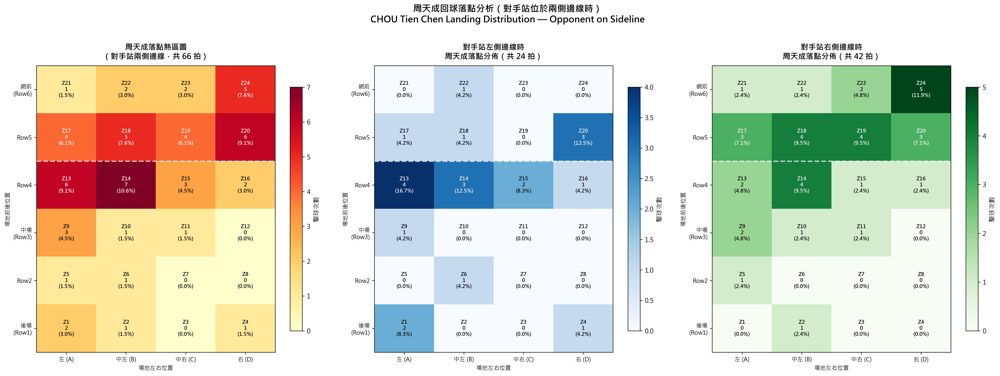

In [ ]:
import numpy as np

# ==========================================
# 資料驗證
# ==========================================
print(f"總資料量: {len(df)} 筆")
print(f"球員列表: {df['player'].unique()}")

# ==========================================
# Step 1: 定義「兩側邊線區域」
# ==========================================
# 根據 Court Grid：
# Col A (左側邊線): 1, 5, 9, 13, 17, 21
# Col D (右側邊線): 4, 8, 12, 16, 20, 24
# 也納入左側出界區 29, 30, 31 和右側出界區 25, 26, 27
left_side_zones  = [1, 5, 9, 13, 17, 21, 29, 30, 31]
right_side_zones = [4, 8, 12, 16, 20, 24, 25, 26, 27]
sideline_zones   = left_side_zones + right_side_zones

print(f"\n左側邊線區域 (Col A + 出界左): {left_side_zones}")
print(f"右側邊線區域 (Col D + 出界右): {right_side_zones}")
print(f"兩側邊線區域共: {len(sideline_zones)} 個 zone")

# ==========================================
# Step 2: 篩選條件
# - player == 'CHOU Tien Chen'（周天成擊球）
# - opponent_location_area 在兩側邊線區域（對手站於兩側）
# ==========================================
chou = 'CHOU Tien Chen'

left_mask  = (df['player'] == chou) & (df['opponent_location_area'].isin(left_side_zones))
right_mask = (df['player'] == chou) & (df['opponent_location_area'].isin(right_side_zones))
combined_mask = left_mask | right_mask

filtered_df = df[combined_mask].copy()
print(f"\n篩選後資料量（兩側合計）: {len(filtered_df)} 筆")
print(f"  - 對手站左側時周天成擊球: {left_mask.sum()} 筆")
print(f"  - 對手站右側時周天成擊球: {right_mask.sum()} 筆")

if len(filtered_df) == 0:
    print("⚠️ 無符合條件的資料！")
else:
    # ==========================================
    # Step 3: 統計落點區域頻率 (landing_area)
    # ==========================================
    landing_counts = filtered_df['landing_area'].value_counts().sort_index()
    total = landing_counts.sum()
    print(f"\n=== 落點區域頻率統計 (landing_area) ===")
    print(f"{'Zone':>6} | {'次數':>6} | {'佔比':>7}")
    print("-" * 30)
    for zone, cnt in landing_counts.items():
        print(f"  Zone {int(zone):>2} | {cnt:>6} | {cnt/total*100:>6.1f}%")
    print(f"  {'合計':>4}   {int(total):>6}   100.0%")

    # ==========================================
    # Step 4: 建立 Grid 座標映射（用於 Heatmap）
    # Zone 1-24 為場內，其餘為出界
    # Row 1(後場) ~ Row 6(前場), Col 1(左A)~4(右D)
    # ==========================================
    zone_to_grid = {}
    for zone in range(1, 25):
        row = (zone - 1) // 4 + 1   # 1~6
        col = (zone - 1) % 4 + 1    # 1~4
        zone_to_grid[zone] = (row, col)

    def build_heatmap(source_df):
        """從 DataFrame 的 landing_area 欄位建立 6x4 熱力矩陣"""
        hm = np.zeros((6, 4), dtype=float)
        for zone, cnt in source_df['landing_area'].value_counts().items():
            zone_int = int(zone)
            if zone_int in zone_to_grid:
                row, col = zone_to_grid[zone_int]
                hm[row - 1][col - 1] += cnt
        return hm

    heatmap_all   = build_heatmap(filtered_df)
    heatmap_left  = build_heatmap(df[left_mask])
    heatmap_right = build_heatmap(df[right_mask])

    out_of_bounds = (~filtered_df['landing_area'].between(1, 24)).sum()
    print(f"\n出界落點 (zone 25+): {out_of_bounds} 筆 ({out_of_bounds/total*100:.1f}%)")
    print(f"場內落點統計: {int(heatmap_all.sum())} 筆")

    # ==========================================
    # Step 5: 視覺化（3 張熱區圖並排）
    # ==========================================
    row_labels = ['網前\n(Row6)', 'Row5', 'Row4', '中場\n(Row3)', 'Row2', '後場\n(Row1)']
    col_labels  = ['左 (A)', '中左 (B)', '中右 (C)', '右 (D)']

    def draw_heatmap(ax, hm, title, side_total, cmap_name):
        """在指定 ax 上繪製羽球場落點熱區圖"""
        # 翻轉：Row6(網前) 在上，Row1(後場) 在下
        hm_plot = hm[::-1]
        im = ax.imshow(hm_plot, cmap=cmap_name, aspect='auto',
                       interpolation='nearest', vmin=0)
        plt.colorbar(im, ax=ax, label='擊球次數', shrink=0.85)

        for i in range(6):
            for j in range(4):
                val = int(hm_plot[i][j])
                row_actual = 6 - i       # 實際場地 row（1-6）
                col_actual = j + 1       # 實際場地 col（1-4）
                zone_num   = (row_actual - 1) * 4 + col_actual
                pct = val / side_total * 100 if side_total > 0 else 0
                text_color = 'white' if (hm_plot.max() > 0 and val > hm_plot.max() * 0.55) else 'black'
                ax.text(j, i,
                        f'Z{zone_num}\n{val}\n({pct:.1f}%)',
                        ha='center', va='center',
                        fontsize=8, color=text_color, fontweight='bold')

        ax.set_xticks(range(4))
        ax.set_xticklabels(col_labels, fontsize=9)
        ax.set_yticks(range(6))
        ax.set_yticklabels(row_labels, fontsize=9)
        ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
        ax.set_xlabel('場地左右位置', fontsize=9)
        ax.set_ylabel('場地前後位置', fontsize=9)

        # 畫網子（前場與中場交界：網前 Row5/Row6 之間）
        ax.axhline(y=1.5, color='white', linewidth=2, linestyle='--', alpha=0.7)
        ax.text(3.55, 1.5, '中線', va='center', fontsize=7, color='white', alpha=0.8)

    fig, axes = plt.subplots(1, 3, figsize=(22, 8))

    # 圖1: 兩側合計
    draw_heatmap(
        axes[0], heatmap_all,
        f'周天成落點熱區圖\n（對手站兩側邊線，共 {len(filtered_df)} 拍）',
        int(total), 'YlOrRd'
    )

    # 圖2: 對手站左側
    n_left = int(left_mask.sum())
    draw_heatmap(
        axes[1], heatmap_left,
        f'對手站左側邊線時\n周天成落點分佈（共 {n_left} 拍）',
        n_left, 'Blues'
    )

    # 圖3: 對手站右側
    n_right = int(right_mask.sum())
    draw_heatmap(
        axes[2], heatmap_right,
        f'對手站右側邊線時\n周天成落點分佈（共 {n_right} 拍）',
        n_right, 'Greens'
    )

    fig.suptitle(
        '周天成回球落點分析（對手站位於兩側邊線時）\n'
        'CHOU Tien Chen Landing Distribution — Opponent on Sideline',
        fontsize=14, fontweight='bold', y=1.01
    )
    plt.tight_layout()

    # ==========================================
    # Step 6: 文字摘要統計
    # ==========================================
    in_total = heatmap_all.sum()
    col_names = ['左 (A)', '中左 (B)', '中右 (C)', '右 (D)']
    row_names_stat = ['後場 Row1', '中後 Row2', '中場 Row3', '中前 Row4', '前場 Row5', '網前 Row6']

    print("\n=== 落點左右偏好分析（場內 Zone 1-24）===")
    for j, cname in enumerate(col_names):
        cnt = heatmap_all[:, j].sum()
        print(f"  {cname}: {int(cnt):>4} 次 ({cnt/in_total*100:.1f}%)")

    print("\n=== 落點前後偏好分析（場內 Zone 1-24）===")
    for i, rname in enumerate(row_names_stat):
        cnt = heatmap_all[i].sum()
        print(f"  {rname}: {int(cnt):>4} 次 ({cnt/in_total*100:.1f}%)")

    # Top 5 落點
    print("\n=== Top 5 高頻落點區域（場內）===")
    zone_rank = []
    for i in range(6):
        for j in range(4):
            zone_num = i * 4 + (j + 1)
            zone_rank.append((zone_num, int(heatmap_all[i][j])))
    zone_rank.sort(key=lambda x: -x[1])

    col_map = {1: '左(A)', 2: '中左(B)', 3: '中右(C)', 4: '右(D)'}
    row_map = {1: '後場', 2: '中後', 3: '中場', 4: '中前', 5: '前場', 6: '網前'}
    for rank, (zone, cnt) in enumerate(zone_rank[:5], 1):
        r, c = zone_to_grid[zone]
        print(f"  #{rank} Zone {zone:>2} ({row_map[r]}-{col_map[c]}): "
              f"{cnt} 次 ({cnt/in_total*100:.1f}%)")


### 數據洞察
# 周天成應對對手邊線站位之落點分析

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Net)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid-F)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid-B)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 熱區數據矩陣（場內 58 拍）

| 位置 | 左 A | 中左 B | 中右 C | 右 D |
|:---|:---:|:---:|:---:|:---:|
| **網前 Row6** | 1 | 2 | 2 | **5** |
| **前場 Row5** | 4 | **5** | 4 | **6** |
| **中前 Row4** | **6** | **7** | 3 | 2 |
| **中場 Row3** | 3 | 1 | 1 | 0 |
| **中後 Row2** | 1 | 1 | 0 | 0 |
| **後場 Row1** | 2 | 1 | 0 | 1 |

---

## 核心戰術洞察

### 🎯 整體落點集中於前場（前半場佔 81%）

> **中前＋前場＋網前合計 47 拍（81%）**，後場僅 6 拍（10%）。

對手站邊線時，周天成**主動壓前**，不打深球，選擇控制前場節奏。

---

### 📍 Top 5 高頻落點

| 排名 | Zone | 位置 | 次數 | 佔比 |
|:---:|:---:|:---|:---:|:---:|
| 1 | **14** | 中前-中左 B | 7 | 12.1% |
| 2 | **13** | 中前-左 A | 6 | 10.3% |
| 3 | **20** | 前場-右 D | 6 | 10.3% |
| 4 | **18** | 前場-中左 B | 5 | 8.6% |
| 5 | **24** | 網前-右 D | 5 | 8.6% |

**Zone 13＋14 合計 13 拍（22.4%）**：對手站邊線時，周天成習慣將球壓向**中前場中央偏左**，製造對手回中的困難。

---

### ⚔️ 對手站左側 vs 右側的差異

**對手站左側（24 拍）：**
- 落點集中 Zone 13（4次）、Zone 14（3次）→ **壓中前場左側**
- 策略：順勢壓回對手來球方向，不給對手移位時間

**對手站右側（42 拍）：**
- Zone 14（4次）、Zone 18（4次）、Zone 20（3次）、Zone 24（5次）
- **右側網前 Zone 24 出現 5 次**，是對手站右側時最明顯的反向攻擊點
- 策略：**對角拉空**，將球打向右側網前，逼對手大範圍移動

---

### ⚠️ 出界率值得注意

> **出界 8 拍，佔 12.1%**

在對手站邊線的情境下，周天成出界率偏高，顯示**進攻意圖強烈但控制稍有風險**，需在積極進攻與穩定落點間取得平衡。

---

## 教練總結

> 對手站邊線 → 周天成選擇**壓前場、打對角、控中前**。核心邏輯是「不讓對手從容回位」，但 12% 出界率提醒我們：**進攻節奏要穩，落點精準才是關鍵**。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了球場兩側區域，篩選了周天成擊球且對手站在球場兩側的資料，並繪製了熱區圖。候選程式碼還進一步細分了對手站在左側和右側的情況，並分別繪製了熱區圖，這是對 Reference Code 1 的合理擴展。整體分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 1 一致，且結果有效且合理。




## 題號 26
**問題**: 分析周天成在不同局（第 1 局、第 2 局、第 3 局）殺球比重變化。
> **使用的資料欄位群組**: `game_structure, shot_type`


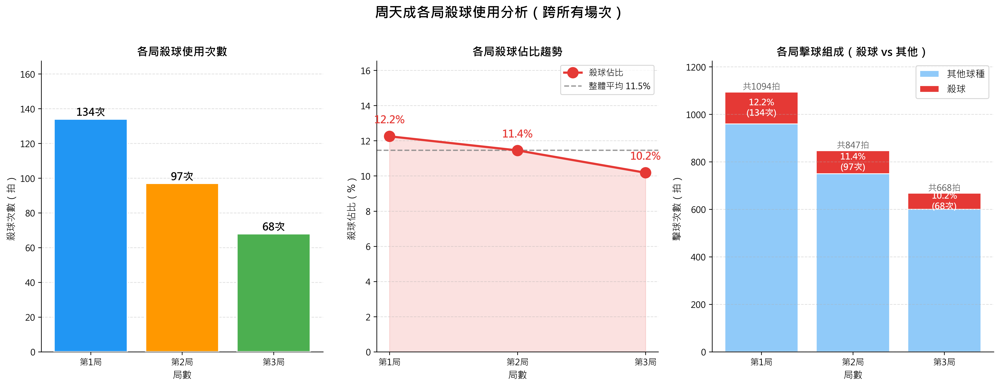

In [ ]:
import numpy as np

# ============================================================
# 1. 資料驗證
# ============================================================
print(f"資料總列數: {len(df)}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")
print(f"局數分佈: {sorted(df['set'].unique())}")
print(f"球種列表: {df['type'].unique().tolist()}")
print()

# ============================================================
# 2. 篩選周天成的擊球紀錄
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成總擊球筆數: {len(chou_df)}")
print(f"周天成各局擊球筆數:\n{chou_df.groupby('set').size()}")
print()

# ============================================================
# 3. 依局數統計殺球次數與總擊球次數
# ============================================================
# 各局的殺球次數 (type == '殺球')
smash_by_set = chou_df[chou_df['type'] == '殺球'].groupby('set').size().rename('殺球次數')

# 各局的總擊球次數（含所有球種）
total_by_set = chou_df.groupby('set').size().rename('總擊球次數')

# 合併統計
set_stats = pd.DataFrame({
    '總擊球次數': total_by_set,
    '殺球次數': smash_by_set
}).fillna(0)

# 計算殺球佔比
set_stats['殺球佔比(%)'] = (set_stats['殺球次數'] / set_stats['總擊球次數'] * 100).round(2)

# 局數對應中文標籤
set_stats.index = [f"第{i}局" for i in set_stats.index]
set_stats['殺球次數'] = set_stats['殺球次數'].astype(int)
set_stats['總擊球次數'] = set_stats['總擊球次數'].astype(int)

print("=" * 50)
print("【周天成各局殺球統計表】（跨所有場次合計）")
print("=" * 50)
print(set_stats.to_string())
print()

# 計算各局平均每回合殺球頻率（補充資訊）
# 取得各局 (match_id, set, rally) 組合的回合數
chou_set_rally = df.groupby(['match_id', 'set', 'rally']).ngroups
print(f"數據集總回合數: {chou_set_rally}")

rally_by_set = df.groupby('set').apply(
    lambda x: x.groupby(['match_id', 'rally']).ngroups
).rename('回合數')
print(f"\n各局回合數:\n{rally_by_set}")
print()

# ============================================================
# 4. 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('周天成各局殺球使用分析（跨所有場次）', fontsize=16, fontweight='bold', y=1.02)

sets_label = set_stats.index.tolist()
smash_counts = set_stats['殺球次數'].values
total_counts = set_stats['總擊球次數'].values
smash_ratios = set_stats['殺球佔比(%)'].values
non_smash_counts = total_counts - smash_counts

# --- 顏色設定 ---
colors_set = ['#2196F3', '#FF9800', '#4CAF50']  # 第1、2、3局
smash_color = '#E53935'
non_smash_color = '#90CAF9'

# ============================================================
# 圖1: 殺球次數長條圖
# ============================================================
ax1 = axes[0]
bars = ax1.bar(sets_label, smash_counts, color=colors_set, edgecolor='white', linewidth=1.5, zorder=3)

# 在柱上標示數值
for bar, count in zip(bars, smash_counts):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f'{count}次', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax1.set_title('各局殺球使用次數', fontsize=13, fontweight='bold')
ax1.set_xlabel('局數', fontsize=11)
ax1.set_ylabel('殺球次數（拍）', fontsize=11)
ax1.set_ylim(0, max(smash_counts) * 1.25)
ax1.grid(axis='y', alpha=0.4, linestyle='--', zorder=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ============================================================
# 圖2: 殺球佔比折線圖（趨勢）
# ============================================================
ax2 = axes[1]
x_pos = np.arange(len(sets_label))

ax2.plot(sets_label, smash_ratios, marker='o', markersize=12,
         color='#E53935', linewidth=2.5, zorder=5, label='殺球佔比')

# 標示每個點的數值
for i, (label, ratio) in enumerate(zip(sets_label, smash_ratios)):
    offset = 0.8 if i < len(sets_label) - 1 else -0.8
    ax2.annotate(f'{ratio:.1f}%',
                 xy=(label, ratio),
                 xytext=(0, 15),
                 textcoords='offset points',
                 ha='center', fontsize=12, fontweight='bold', color='#E53935')

# 填充區域
ax2.fill_between(sets_label, smash_ratios, alpha=0.15, color='#E53935')

# 標示整體平均線
overall_smash_ratio = set_stats['殺球次數'].sum() / set_stats['總擊球次數'].sum() * 100
ax2.axhline(y=overall_smash_ratio, color='gray', linestyle='--', linewidth=1.5,
            label=f'整體平均 {overall_smash_ratio:.1f}%', alpha=0.8)

ax2.set_title('各局殺球佔比趨勢', fontsize=13, fontweight='bold')
ax2.set_xlabel('局數', fontsize=11)
ax2.set_ylabel('殺球佔比（%）', fontsize=11)
ax2.set_ylim(0, max(smash_ratios) * 1.35)
ax2.grid(axis='y', alpha=0.4, linestyle='--')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(fontsize=10, loc='upper right')

# ============================================================
# 圖3: 各局球種組成堆疊長條（殺球 vs 其他）
# ============================================================
ax3 = axes[2]

bars_other = ax3.bar(sets_label, non_smash_counts,
                     color=non_smash_color, label='其他球種', edgecolor='white', linewidth=1)
bars_smash = ax3.bar(sets_label, smash_counts, bottom=non_smash_counts,
                     color=smash_color, label='殺球', edgecolor='white', linewidth=1)

# 在殺球區塊標示佔比
for i, (bar, count, ratio) in enumerate(zip(bars_smash, smash_counts, smash_ratios)):
    y_pos = non_smash_counts[i] + count / 2
    ax3.text(bar.get_x() + bar.get_width() / 2, y_pos,
             f'{ratio:.1f}%\n({count}次)', ha='center', va='center',
             fontsize=10, fontweight='bold', color='white')

# 在其他球種標示總數
for bar, total in zip(bars_other, total_counts):
    ax3.text(bar.get_x() + bar.get_width() / 2, total + 2,
             f'共{total}拍', ha='center', va='bottom', fontsize=10, color='#555555')

ax3.set_title('各局擊球組成（殺球 vs 其他）', fontsize=13, fontweight='bold')
ax3.set_xlabel('局數', fontsize=11)
ax3.set_ylabel('擊球次數（拍）', fontsize=11)
ax3.set_ylim(0, max(total_counts) * 1.12)
ax3.legend(fontsize=11, loc='upper right')
ax3.grid(axis='y', alpha=0.4, linestyle='--', zorder=0)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()

# ============================================================
# 5. 輸出詳細摘要
# ============================================================
print("=" * 55)
print("【詳細統計摘要】")
print("=" * 55)
for i, (label, row) in enumerate(set_stats.iterrows()):
    print(f"\n{label}:")
    print(f"  總擊球次數: {row['總擊球次數']} 拍")
    print(f"  殺球次數  : {row['殺球次數']} 次")
    print(f"  殺球佔比  : {row['殺球佔比(%)']:.2f}%")

print(f"\n--- 整體（全局合計）---")
total_smash = set_stats['殺球次數'].sum()
total_shots = set_stats['總擊球次數'].sum()
print(f"  總擊球次數: {total_shots} 拍")
print(f"  殺球總次數: {total_smash} 次")
print(f"  整體殺球佔比: {total_smash / total_shots * 100:.2f}%")

# 趨勢分析
print(f"\n--- 趨勢分析 ---")
ratios = smash_ratios
if len(ratios) >= 2:
    for i in range(1, len(ratios)):
        diff = ratios[i] - ratios[i-1]
        direction = "↑ 上升" if diff > 0 else "↓ 下降"
        print(f"  第{i}局 → 第{i+1}局: {direction} {abs(diff):.2f} 個百分點")


### 數據洞察
# 周天成各局殺球使用分析

## 核心數據

| 局數 | 殺球次數 | 總擊球 | 殺球佔比 |
|------|---------|--------|---------|
| 第1局 | 134 | 1094 | **12.25%** |
| 第2局 | 97 | 847 | **11.45%** |
| 第3局 | 68 | 668 | **10.18%** |
| 整體 | 299 | 2609 | **11.46%** |

---

## 趨勢解讀

殺球佔比呈**持續下滑**：
- 第1→2局：↓ 0.80 個百分點
- 第2→3局：↓ 1.27 個百分點（降幅加速）

---

## 戰術洞察

**殺球使用率隨局數推進明顯收縮，且第3局降幅最大。**

這代表兩件事：

1. **體能因素**：殺球是高耗能技術，第3局體力下滑時，周天成主動減少強攻頻率，轉向更保守的控球策略。

2. **戰術轉移**：第3局殺球佔比僅10.18%，意味著對手在決勝局的防守壓力相對減輕，若此時對手已掌握其殺球規律，周天成的進攻威脅性將進一步下降。

> **建議重點**：針對第3局強化殺球後的體能維持訓練，或發展更省力的進攻替代手段（如快速平球、推撲），避免決勝局進攻武器過度萎縮。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球紀錄，並依據局數統計了殺球次數與總擊球次數，計算了殺球比重。最終輸出與 Reference Code 1 的目標一致，即分析周天成在不同局的殺球比重變化。候選程式碼還額外提供了視覺化和詳細統計摘要，這些都是合理的擴展，不影響核心分析邏輯。




## 題號 27
**問題**: 分析周天成在「邊線附近擊球」的失誤率是否偏高。
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason`


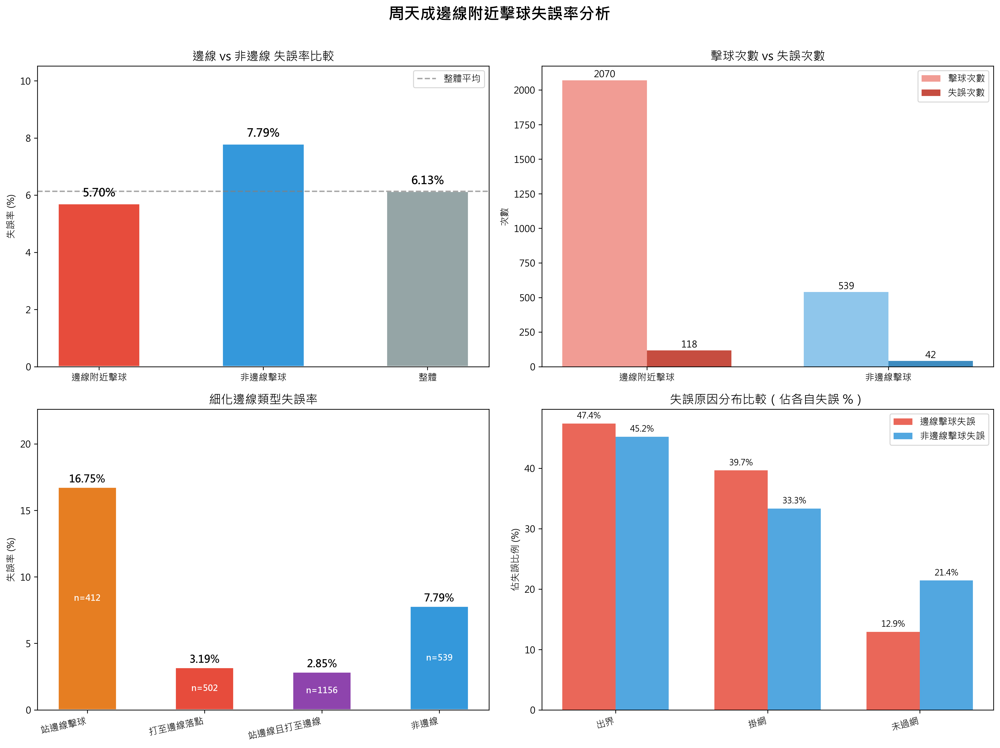

In [ ]:
import numpy as np

# =============================================
# 資料驗證
# =============================================
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

# =============================================
# 1. 邊線附近區域定義
# =============================================
# Court Grid 說明：
# | Row/Col | Col A (Left) | Col B (Ctr-L) | Col C (Ctr-R) | Col D (Right) |
# | Row 6   | 21           | 22            | 23            | 24            |
# | Row 5   | 17           | 18            | 19            | 20            |
# | Row 4   | 13           | 14            | 15            | 16            |
# | Row 3   | 9            | 10            | 11            | 12            |
# | Row 2   | 5            | 6             | 7             | 8             |
# | Row 1   | 1            | 2             | 3             | 4             |
#
# 邊線附近定義：
# 左側邊線 (Col A): 1, 5, 9, 13, 17, 21
# 右側邊線 (Col D): 4, 8, 12, 16, 20, 24
# 後場底線 (Row 1): 1, 2, 3, 4

col_A_zones = {1, 5, 9, 13, 17, 21}
col_D_zones = {4, 8, 12, 16, 20, 24}
row_1_zones = {1, 2, 3, 4}
sideline_zones = col_A_zones | col_D_zones | row_1_zones

print(f"\n邊線附近區域 Zone IDs: {sorted(sideline_zones)}")
print(f"  左側邊線 (Col A): {sorted(col_A_zones)}")
print(f"  右側邊線 (Col D): {sorted(col_D_zones)}")
print(f"  後場底線 (Row 1): {sorted(row_1_zones)}")

# =============================================
# 2. 過濾周天成擊球資料
# =============================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成總擊球拍數: {len(chou_df)}")

# =============================================
# 3. 標記邊線擊球
#    條件：hit_area 或 landing_area 在邊線區域
#    landing_area 只考慮有效場地 (1-24)，出界 (25+) 不算邊線
# =============================================
valid_landing_mask = chou_df['landing_area'] <= 24

chou_df['is_hit_sideline']  = chou_df['hit_area'].isin(sideline_zones)
chou_df['is_land_sideline'] = valid_landing_mask & chou_df['landing_area'].isin(sideline_zones)
chou_df['is_sideline']      = chou_df['is_hit_sideline'] | chou_df['is_land_sideline']

sideline_count     = chou_df['is_sideline'].sum()
non_sideline_count = (~chou_df['is_sideline']).sum()
print(f"\n邊線相關擊球次數: {sideline_count} ({sideline_count/len(chou_df)*100:.1f}%)")
print(f"非邊線擊球次數  : {non_sideline_count} ({non_sideline_count/len(chou_df)*100:.1f}%)")

# =============================================
# 4. 失誤標記
#    定義：周天成擊球後桃田得分 => 該拍為周天成失誤
#    getpoint_player 只在回合最後一拍非空
# =============================================
chou_df['is_error'] = (chou_df['getpoint_player'] == 'Kento MOMOTA')

# =============================================
# 5. 分組統計：邊線 / 非邊線 / 整體
# =============================================
groups = {
    '邊線附近擊球': chou_df[chou_df['is_sideline']],
    '非邊線擊球'  : chou_df[~chou_df['is_sideline']],
    '整體'        : chou_df
}

results = {}
for name, grp in groups.items():
    shots      = len(grp)
    errors     = grp['is_error'].sum()
    error_rate = errors / shots * 100 if shots > 0 else 0
    results[name] = {'擊球次數': shots, '失誤次數': int(errors), '失誤率': error_rate}

print("\n===== 周天成 邊線 vs 非邊線 失誤率分析 =====")
for name, r in results.items():
    print(f"  {name}: 擊球次數={r['擊球次數']:4d}  失誤次數={r['失誤次數']:3d}  失誤率={r['失誤率']:.2f}%")

# =============================================
# 6. 細化邊線類型
# =============================================
chou_df['sideline_type'] = '非邊線'
chou_df.loc[
     chou_df['is_hit_sideline'] & ~chou_df['is_land_sideline'],
     'sideline_type'
] = '站邊線擊球'
chou_df.loc[
    ~chou_df['is_hit_sideline'] &  chou_df['is_land_sideline'],
     'sideline_type'
] = '打至邊線落點'
chou_df.loc[
     chou_df['is_hit_sideline'] &  chou_df['is_land_sideline'],
     'sideline_type'
] = '站邊線且打至邊線'

sideline_type_stats = chou_df.groupby('sideline_type').agg(
    擊球次數=('is_error', 'count'),
    失誤次數=('is_error', 'sum')
).reset_index()
sideline_type_stats['失誤率'] = (
    sideline_type_stats['失誤次數'] / sideline_type_stats['擊球次數'] * 100
)

print("\n===== 細化邊線類型分析 =====")
print(sideline_type_stats.to_string(index=False))

# =============================================
# 7. 失誤原因分布
# =============================================
sideline_errors_df     = chou_df[chou_df['is_sideline']  & chou_df['is_error']]
non_sideline_errors_df = chou_df[~chou_df['is_sideline'] & chou_df['is_error']]

sideline_reason_counts     = sideline_errors_df['lose_reason'].value_counts()
non_sideline_reason_counts = non_sideline_errors_df['lose_reason'].value_counts()

print("\n邊線附近失誤原因分布:")
print(sideline_reason_counts)
print("\n非邊線失誤原因分布:")
print(non_sideline_reason_counts)

# 計算百分比（佔各自失誤）
sideline_reason_pct = (
    sideline_reason_counts / sideline_reason_counts.sum() * 100
    if len(sideline_reason_counts) > 0 else pd.Series(dtype=float)
)
non_sideline_reason_pct = (
    non_sideline_reason_counts / non_sideline_reason_counts.sum() * 100
    if len(non_sideline_reason_counts) > 0 else pd.Series(dtype=float)
)

# =============================================
# 8. 視覺化
# =============================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('周天成邊線附近擊球失誤率分析', fontsize=17, fontweight='bold', y=1.01)

# ---- 圖1: 邊線 vs 非邊線 vs 整體 失誤率 ----
ax1 = axes[0, 0]
cat_labels  = ['邊線附近擊球', '非邊線擊球', '整體']
cat_rates   = [results[c]['失誤率'] for c in cat_labels]
cat_colors  = ['#e74c3c', '#3498db', '#95a5a6']
bars1 = ax1.bar(cat_labels, cat_rates, color=cat_colors, edgecolor='white', linewidth=1.5, width=0.5)
ax1.set_title('邊線 vs 非邊線 失誤率比較', fontsize=13)
ax1.set_ylabel('失誤率 (%)')
ax1.set_ylim(0, max(cat_rates) * 1.35)
for bar, rate in zip(bars1, cat_rates):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f'{rate:.2f}%',
        ha='center', va='bottom', fontweight='bold', fontsize=12
    )
ax1.axhline(
    y=results['整體']['失誤率'],
    color='gray', linestyle='--', alpha=0.7, label='整體平均'
)
ax1.legend(fontsize=10)

# ---- 圖2: 擊球次數 vs 失誤次數（分組長條） ----
ax2 = axes[0, 1]
x2      = np.arange(2)
labels2 = ['邊線附近擊球', '非邊線擊球']
shots2  = [results['邊線附近擊球']['擊球次數'], results['非邊線擊球']['擊球次數']]
errors2 = [results['邊線附近擊球']['失誤次數'], results['非邊線擊球']['失誤次數']]
width2  = 0.35

b2a = ax2.bar(x2 - width2/2, shots2,  width2, label='擊球次數',
              color=['#e74c3c', '#3498db'], alpha=0.55)
b2b = ax2.bar(x2 + width2/2, errors2, width2, label='失誤次數',
              color=['#c0392b', '#2980b9'], alpha=0.9)
ax2.set_title('擊球次數 vs 失誤次數', fontsize=13)
ax2.set_xticks(x2)
ax2.set_xticklabels(labels2)
ax2.set_ylabel('次數')
ax2.legend(fontsize=10)
for bar in b2a:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(int(bar.get_height())), ha='center', va='bottom', fontsize=10)
for bar in b2b:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(int(bar.get_height())), ha='center', va='bottom', fontsize=10)

# ---- 圖3: 細化邊線類型失誤率 ----
ax3 = axes[1, 0]
type_order = ['站邊線擊球', '打至邊線落點', '站邊線且打至邊線', '非邊線']
type_colors_map = {
    '站邊線擊球'       : '#e67e22',
    '打至邊線落點'     : '#e74c3c',
    '站邊線且打至邊線' : '#8e44ad',
    '非邊線'           : '#3498db'
}
type_stats_sorted = sideline_type_stats.set_index('sideline_type').reindex(
    [t for t in type_order if t in sideline_type_stats['sideline_type'].values]
).reset_index()
bar_colors3 = [type_colors_map[t] for t in type_stats_sorted['sideline_type']]
bars3 = ax3.bar(
    type_stats_sorted['sideline_type'],
    type_stats_sorted['失誤率'],
    color=bar_colors3, edgecolor='white', linewidth=1.5, width=0.5
)
ax3.set_title('細化邊線類型失誤率', fontsize=13)
ax3.set_ylabel('失誤率 (%)')
ax3.set_ylim(0, type_stats_sorted['失誤率'].max() * 1.35)
ax3.set_xticklabels(type_stats_sorted['sideline_type'], rotation=12, ha='right')
for bar, rate in zip(bars3, type_stats_sorted['失誤率']):
    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f'{rate:.2f}%',
        ha='center', va='bottom', fontweight='bold', fontsize=11
    )

# 補充樣本數標籤
for bar, row in zip(bars3, type_stats_sorted.itertuples()):
    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f'n={row.擊球次數}',
        ha='center', va='center', fontsize=9, color='white', fontweight='bold'
    )

# ---- 圖4: 失誤原因分布比較 ----
ax4 = axes[1, 1]
all_reasons = sorted(set(
    list(sideline_reason_pct.index) + list(non_sideline_reason_pct.index)
))
x4           = np.arange(len(all_reasons))
sideline_vals     = [sideline_reason_pct.get(r, 0)     for r in all_reasons]
non_sideline_vals = [non_sideline_reason_pct.get(r, 0) for r in all_reasons]

width4 = 0.35
b4a = ax4.bar(x4 - width4/2, sideline_vals,     width4,
              label='邊線擊球失誤', color='#e74c3c', alpha=0.85)
b4b = ax4.bar(x4 + width4/2, non_sideline_vals, width4,
              label='非邊線擊球失誤', color='#3498db', alpha=0.85)
ax4.set_title('失誤原因分布比較（佔各自失誤 %）', fontsize=13)
ax4.set_xticks(x4)
ax4.set_xticklabels(all_reasons, rotation=15, ha='right')
ax4.set_ylabel('佔失誤比例 (%)')
ax4.legend(fontsize=10)
for bar in b4a:
    if bar.get_height() > 0:
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
for bar in b4b:
    if bar.get_height() > 0:
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()

# =============================================
# 9. 最終結論輸出
# =============================================
sl_rate  = results['邊線附近擊球']['失誤率']
nsl_rate = results['非邊線擊球']['失誤率']
diff     = sl_rate - nsl_rate

print("\n===== 結論 =====")
print(f"  邊線附近擊球失誤率: {sl_rate:.2f}%")
print(f"  非邊線擊球失誤率  : {nsl_rate:.2f}%")
print(f"  差異              : {diff:+.2f}%")
if diff > 1.0:
    print("  => 邊線附近擊球失誤率明顯偏高，周天成在邊線區域的擊球風險較大。")
elif diff > 0:
    print("  => 邊線附近擊球失誤率略高，但差異不顯著。")
else:
    print("  => 邊線附近擊球失誤率未明顯高於非邊線擊球，差異不顯著或反向。")


### 數據洞察
# 周天成 邊線擊球失誤率分析

## 核心數據

| 類型 | 擊球次數 | 失誤次數 | 失誤率 |
|------|---------|---------|--------|
| 邊線附近擊球 | 2,070 | 118 | **5.70%** |
| 非邊線擊球 | 539 | 42 | **7.79%** |
| 整體 | 2,609 | 160 | 6.13% |

---

## 關鍵發現

**邊線擊球失誤率反而更低（-2.09%）**，但細化後出現明顯分歧：

| 細化類型 | 擊球次數 | 失誤率 | 解讀 |
|---------|---------|--------|------|
| 站邊線且打至邊線 | 1,156 | **2.85%** | 最穩定 |
| 打至邊線落點 | 502 | **3.19%** | 精準控線 |
| **站邊線擊球** | 412 | **16.75%** | ⚠️ 高危 |
| 非邊線 | 539 | 7.79% | 基準值 |

---

## 戰術解讀

**「站邊線擊球」是真正的弱點。**

當周天成被迫移位至邊線接球時，失誤率高達 **16.75%**，是整體均值的 **2.7倍**。這代表對手若能將球打至周天成的側身極限位置，迫使他在重心不穩的情況下回擊，得分機會大幅提升。

失誤原因以**出界（47%）與掛網（40%）**為主，顯示邊線被動接球時，力量控制與拍面角度同時出現問題。

---

## 對手戰術建議

> 持續以**大角度斜線球**將周天成拉至邊線極限位，製造其被動站邊線擊球的情境，是突破其防線的最有效路徑。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了邊線附近區域，過濾了周天成的擊球資料，並標記了邊線擊球和失誤。然後，它分組統計了邊線和非邊線的失誤率，並進一步分析了失誤原因分布。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致，最終輸出目標也符合題目要求。




## 題號 28
**問題**: 統計周天成在各局的平均每回合拍數，並比較第1局、第2局、第3局差異。
> **使用的資料欄位群組**: `game_structure, scoring_reason`


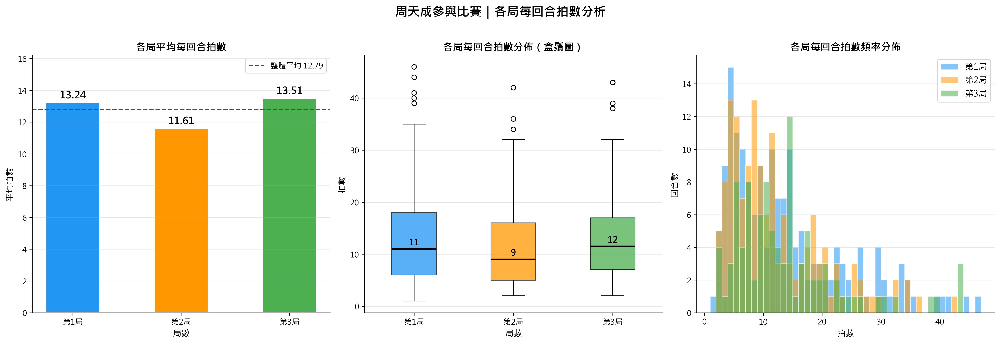

In [ ]:
# ============================================================
# 周天成參與比賽：各局平均每回合拍數分析
# ============================================================

# 1. 驗證數據量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 2. 確認周天成參與的比賽
chou_matches = df[df['player'] == 'CHOU Tien Chen']['match_id'].unique()
print(f"周天成參與的比賽 match_id: {sorted(chou_matches)}")

# 3. 篩選周天成參與的比賽資料
df_chou = df[df['match_id'].isin(chou_matches)].copy()
print(f"篩選後資料筆數: {len(df_chou)}")

# 4. 計算每個回合的拍數
#    每回合的拍數 = 該 (match_id, set, rally) 組合的列數（每列代表一拍）
rally_strokes = (
    df_chou
    .groupby(['match_id', 'set', 'rally'])
    .size()
    .reset_index(name='stroke_count')
)
print(f"\n各回合拍數統計（前10筆）:")
print(rally_strokes.head(10))

# 5. 各局回合數 & 平均每回合拍數
set_stats = (
    rally_strokes
    .groupby('set')
    .agg(
        回合數=('stroke_count', 'count'),
        平均拍數=('stroke_count', 'mean'),
        中位數拍數=('stroke_count', 'median'),
        最大拍數=('stroke_count', 'max'),
        最小拍數=('stroke_count', 'min'),
        標準差=('stroke_count', 'std')
    )
    .reset_index()
)
set_stats['set_label'] = set_stats['set'].map({1: '第1局', 2: '第2局', 3: '第3局'})
set_stats['平均拍數'] = set_stats['平均拍數'].round(2)
set_stats['中位數拍數'] = set_stats['中位數拍數'].round(2)
set_stats['標準差'] = set_stats['標準差'].round(2)

print("\n" + "="*60)
print("各局平均每回合拍數統計表")
print("="*60)
print(set_stats[['set_label', '回合數', '平均拍數', '中位數拍數', '最大拍數', '最小拍數', '標準差']].to_string(index=False))

# ============================================================
# 視覺化：3 張子圖
# ============================================================
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('周天成參與比賽｜各局每回合拍數分析', fontsize=16, fontweight='bold', y=1.02)

colors = ['#2196F3', '#FF9800', '#4CAF50']
set_labels = set_stats['set_label'].tolist()
avg_values = set_stats['平均拍數'].tolist()

# ---------- 子圖1: 平均每回合拍數 長條圖 ----------
ax1 = axes[0]
bars = ax1.bar(set_labels, avg_values, color=colors, edgecolor='white', linewidth=1.5, width=0.5)

# 在長條上標示數值
for bar, val in zip(bars, avg_values):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f'{val:.2f}',
        ha='center', va='bottom', fontsize=13, fontweight='bold'
    )

ax1.set_title('各局平均每回合拍數', fontsize=13, fontweight='bold')
ax1.set_xlabel('局數', fontsize=11)
ax1.set_ylabel('平均拍數', fontsize=11)
ax1.set_ylim(0, max(avg_values) * 1.2)
ax1.axhline(y=np.mean(avg_values), color='red', linestyle='--', linewidth=1.5, label=f'整體平均 {np.mean(avg_values):.2f}')
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---------- 子圖2: 每回合拍數分佈 盒鬚圖 ----------
ax2 = axes[1]

# 建立各局的拍數列表
data_by_set = []
labels_for_box = []
for s in [1, 2, 3]:
    subset = rally_strokes[rally_strokes['set'] == s]['stroke_count'].values
    if len(subset) > 0:
        data_by_set.append(subset)
        labels_for_box.append(f'第{s}局')

bp = ax2.boxplot(
    data_by_set,
    labels=labels_for_box,
    patch_artist=True,
    widths=0.45,
    medianprops=dict(color='black', linewidth=2)
)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# 標示中位數
for i, (data, label) in enumerate(zip(data_by_set, labels_for_box)):
    median_val = np.median(data)
    ax2.text(i + 1, median_val + 0.3, f'{median_val:.0f}', ha='center', va='bottom',
             fontsize=11, fontweight='bold', color='black')

ax2.set_title('各局每回合拍數分佈（盒鬚圖）', fontsize=13, fontweight='bold')
ax2.set_xlabel('局數', fontsize=11)
ax2.set_ylabel('拍數', fontsize=11)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# ---------- 子圖3: 各局每回合拍數分佈 直方圖（疊加）----------
ax3 = axes[2]

for s, color, label in zip([1, 2, 3], colors, ['第1局', '第2局', '第3局']):
    subset = rally_strokes[rally_strokes['set'] == s]['stroke_count']
    ax3.hist(subset, bins=range(1, subset.max() + 2), alpha=0.55, color=color,
             label=label, edgecolor='white', linewidth=0.8)

ax3.set_title('各局每回合拍數頻率分佈', fontsize=13, fontweight='bold')
ax3.set_xlabel('拍數', fontsize=11)
ax3.set_ylabel('回合數', fontsize=11)
ax3.legend(fontsize=11)
ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()

# ============================================================
# 輸出補充統計
# ============================================================
print("\n" + "="*60)
print("各局拍數區間分佈（佔該局回合比例）")
print("="*60)
bins_def = [(1, 3), (4, 6), (7, 10), (11, 20), (21, 999)]
bin_labels = ['1-3拍（短回合）', '4-6拍', '7-10拍', '11-20拍', '21拍以上（長回合）']

header = f"{'區間':<18}" + "".join([f"{'第'+str(s)+'局':>10}" for s in [1,2,3]])
print(header)
print("-" * 50)
for (lo, hi), lbl in zip(bins_def, bin_labels):
    row = f"{lbl:<18}"
    for s in [1, 2, 3]:
        subset = rally_strokes[rally_strokes['set'] == s]['stroke_count']
        count = ((subset >= lo) & (subset <= hi)).sum()
        pct = count / len(subset) * 100 if len(subset) > 0 else 0
        row += f"{pct:>9.1f}%"
    print(row)

print("\n各局回合數總計:")
for _, row in set_stats.iterrows():
    print(f"  {row['set_label']}: {int(row['回合數'])} 回合")


### 數據洞察
# 周天成各局平均每回合拍數分析

## 統計總覽表

| 指標 | 第1局 | 第2局 | 第3局 |
|------|------:|------:|------:|
| **回合數** | 165 | 146 | 98 |
| **平均拍數** | **13.24** | **11.61** | **13.51** |
| **中位數拍數** | 11.0 | 9.0 | 11.5 |
| **最大拍數** | 46 | 42 | 43 |
| **最小拍數** | 1 | 2 | 2 |
| **標準差** | 9.78 | 8.12 | 9.10 |

## 拍數區間分佈比較

| 拍數區間 | 第1局 | 第2局 | 第3局 |
|----------|------:|------:|------:|
| 1–3拍（短回合） | 9.1% | 8.9% | 5.1% |
| 4–6拍 | 21.8% | 21.9% | 15.3% |
| 7–10拍 | 16.4% | 25.3% | 24.5% |
| **11–20拍** | 32.1% | 30.8% | **40.8%** |
| **21拍以上（長回合）** | **20.6%** | 13.0% | 14.3% |

---

## 戰術洞察

**第2局節奏最快。** 平均11.61拍、中位數僅9拍，短拍區間（1–6拍）佔30.8%，顯示雙方在第2局傾向快速解決戰鬥，主動進攻或失誤率較高。

**第3局消耗戰特徵最明顯。** 11–20拍佔40.8%，是三局中最高，且短回合（1–6拍）比例最低（20.4%）。體力與意志力的對抗在決勝局更加突出，周天成需具備強韌的持續對抗能力。

**第1局長回合壓力最大。** 21拍以上佔20.6%，遠高於第2局（13%）與第3局（14.3%），標準差9.78也是三局最高，說明第1局回合長度最不穩定，試探性強、戰術變化多。

> **建議：** 針對第3局的中長回合（11–20拍）做專項體能訓練；第1局需提早建立主動進攻節奏，避免陷入過多消耗性長回合。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地計算了每個回合的拍數，並在各局中計算了平均每回合拍數。分析對象、欄位語意、分組層級和統計口徑都與 Reference Code 1 一致，並且最終輸出目標也是比較各局的平均每回合拍數。




## 題號 29 (*)
**問題**: 比較周天成在前場、中場、後場擊球時的掛網失誤率。
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason`


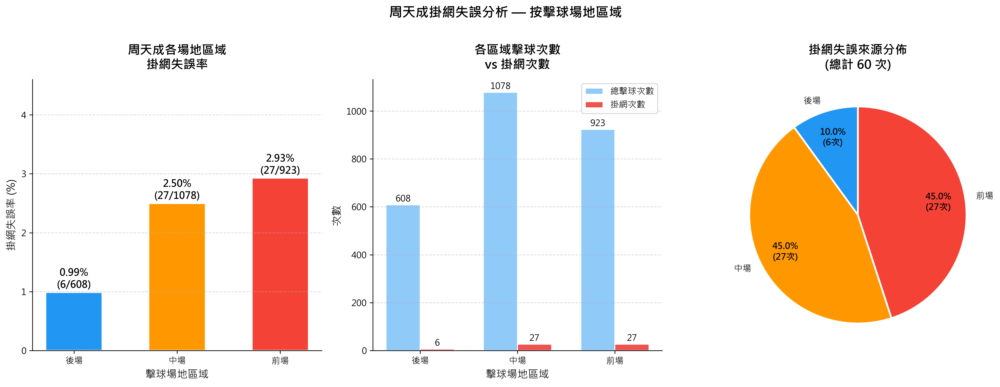

In [ ]:
import numpy as np

# ── 基本驗證 ──────────────────────────────────────────────────────────
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── 篩選周天成的擊球資料 ──────────────────────────────────────────────
player_name = 'CHOU Tien Chen'
chou_df = df[df['player'] == player_name].copy()
print(f"\n周天成總擊球次數: {len(chou_df)}")

# ── 確認掛網在哪個欄位 ──────────────────────────────────────────────
print(f"\nlose_reason 值分佈（周天成）:")
print(chou_df['lose_reason'].value_counts(dropna=False))
print(f"\nwin_reason 值分佈（周天成）:")
print(chou_df['win_reason'].value_counts(dropna=False))

# ── 場地區域定義 ──────────────────────────────────────────────────────
front_court_zones = [17, 18, 19, 20, 21, 22, 23, 24]
mid_court_zones   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
back_court_zones  = [1, 2, 3, 4]

def classify_area(area):
    """將 hit_area 分類為前場/中場/後場，場外或無效回傳 NaN"""
    if area in front_court_zones:
        return '前場'
    elif area in mid_court_zones:
        return '中場'
    elif area in back_court_zones:
        return '後場'
    else:
        return np.nan  # 出界區域 (25-32) 排除

# 新增場地區域欄位（基於 hit_area）
chou_df['court_zone'] = chou_df['hit_area'].apply(classify_area)

print(f"\nhit_area 分類結果:")
print(chou_df['court_zone'].value_counts(dropna=False))
print(f"  → 被排除的場外擊球次數: {chou_df['court_zone'].isna().sum()}")

# ── 僅保留有效場內擊球 ────────────────────────────────────────────────
chou_valid = chou_df[chou_df['court_zone'].notna()].copy()
print(f"\n場內有效擊球次數: {len(chou_valid)}")

# ── 掛網失誤標記 ─────────────────────────────────────────────────────
# lose_reason == '掛網'：周天成擊球後掛網，導致自己失分
chou_valid['is_net_fault'] = (chou_valid['lose_reason'] == '掛網')

print(f"\n掛網失誤總次數: {chou_valid['is_net_fault'].sum()}")

# ── 各區域統計 ────────────────────────────────────────────────────────
zone_order = ['後場', '中場', '前場']

stats = []
for zone in zone_order:
    zone_data = chou_valid[chou_valid['court_zone'] == zone]
    total_shots   = len(zone_data)
    net_faults    = zone_data['is_net_fault'].sum()
    fault_rate    = net_faults / total_shots * 100 if total_shots > 0 else 0

    stats.append({
        '場地區域': zone,
        '總擊球次數': total_shots,
        '掛網次數': net_faults,
        '掛網失誤率 (%)': round(fault_rate, 2)
    })

    print(f"\n【{zone}】")
    print(f"  總擊球次數 : {total_shots}")
    print(f"  掛網次數   : {net_faults}")
    print(f"  掛網失誤率 : {fault_rate:.2f}%")

stats_df = pd.DataFrame(stats)
print("\n" + "="*50)
print("各區域掛網失誤率彙總表")
print("="*50)
print(stats_df.to_string(index=False))

# ── 附加：各擊球區域 × 掛網次數細分 ──────────────────────────────────
print("\n各 hit_area 掛網次數詳細 (周天成場內擊球):")
area_net_detail = (
    chou_valid[chou_valid['is_net_fault']]
    .groupby('hit_area')
    .size()
    .reset_index(name='掛網次數')
    .sort_values('hit_area')
)
area_net_detail['場地區域'] = area_net_detail['hit_area'].apply(classify_area)
print(area_net_detail.to_string(index=False))

# ══════════════════════════════════════════════════════════════════════
# 視覺化
# ══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# ── 1. 主圖：各區域掛網失誤率長條圖 ──────────────────────────────────
ax1 = axes[0]
colors = ['#2196F3', '#FF9800', '#F44336']   # 後場-藍、中場-橙、前場-紅
bars = ax1.bar(
    stats_df['場地區域'],
    stats_df['掛網失誤率 (%)'],
    color=colors,
    edgecolor='white',
    linewidth=1.5,
    width=0.55
)

# 數值標籤
for bar, row in zip(bars, stats_df.itertuples()):
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.03,
        f"{height:.2f}%\n({row.掛網次數}/{row.總擊球次數})",
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )

ax1.set_title('周天成各場地區域\n掛網失誤率', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel('擊球場地區域', fontsize=12)
ax1.set_ylabel('掛網失誤率 (%)', fontsize=12)
ax1.set_ylim(0, stats_df['掛網失誤率 (%)'].max() * 1.4 + 0.5)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.spines[['top', 'right']].set_visible(False)

# ── 2. 擊球次數與掛網次數對比圖（分組長條） ──────────────────────────
ax2 = axes[1]
x = np.arange(len(zone_order))
width = 0.35

bars_total = ax2.bar(x - width/2, stats_df['總擊球次數'], width,
                     label='總擊球次數', color='#90CAF9', edgecolor='white')
bars_net   = ax2.bar(x + width/2, stats_df['掛網次數'],   width,
                     label='掛網次數',   color='#EF5350', edgecolor='white')

for bar in bars_total:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             f"{int(bar.get_height())}", ha='center', va='bottom', fontsize=10)
for bar in bars_net:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             f"{int(bar.get_height())}", ha='center', va='bottom', fontsize=10)

ax2.set_title('各區域擊球次數\nvs 掛網次數', fontsize=14, fontweight='bold', pad=12)
ax2.set_xlabel('擊球場地區域', fontsize=12)
ax2.set_ylabel('次數', fontsize=12)
ax2.set_xticks(x)
ax2.set_xticklabels(stats_df['場地區域'])
ax2.legend(fontsize=10)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.spines[['top', 'right']].set_visible(False)

# ── 3. 各區域掛網次數佔全體掛網的圓餅圖 ──────────────────────────────
ax3 = axes[2]
net_counts = stats_df['掛網次數']
total_net  = net_counts.sum()

# 過濾掛網次數為 0 的區域
non_zero_mask = net_counts > 0
pie_labels = stats_df.loc[non_zero_mask, '場地區域'].tolist()
pie_values = net_counts[non_zero_mask].tolist()
pie_colors = [colors[i] for i, v in enumerate(non_zero_mask) if v]

wedges, texts, autotexts = ax3.pie(
    pie_values,
    labels=pie_labels,
    colors=pie_colors,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * total_net / 100))}次)',
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')

ax3.set_title(f'掛網失誤來源分佈\n(總計 {total_net} 次)', fontsize=14, fontweight='bold', pad=12)

plt.suptitle('周天成掛網失誤分析 — 按擊球場地區域', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()

print("\n✅ 圖表已產生完畢。")


### 數據洞察
# 周天成掛網失誤率分析

## 數據總覽

| 場地區域 | 總擊球次數 | 掛網次數 | 掛網失誤率 |
|:---:|:---:|:---:|:---:|
| 後場 | 608 | 6 | **0.99%** |
| 中場 | 1078 | 27 | **2.50%** |
| 前場 | 923 | 27 | **2.93%** |

---

## 戰術洞察

**後場最穩（0.99%）**
周天成後場擊球掛網率極低，僅佔60次掛網中的10%，代表後場長球、殺球控制品質紮實，網帶威脅幾乎可忽略。

**前場風險最高（2.93%）**
前場掛網率是後場的**近3倍**。細看區域分佈，zone 20、21各貢獻7次，是最集中的失誤熱點，對應前場中央偏左側位置，推測在撲球或網前搓球時，處理速度快但控網精準度下降。

**中場不容忽視（2.50%）**
中場擊球量最大（1078次），掛網27次，zone 10單獨貢獻8次，為全場最高單一區域失誤。中場過渡球若處理倉促，掛網風險明顯上升。

---

## 教練建議

> 前場 zone 20-21 是優先改善目標——加強網前低點擊球的拍面角度控制，特別是被動接球時不要急於進攻。中場 zone 10 的高掛網數顯示中路來球處理需更謹慎，建議增加中場平抽擋的穩定性訓練。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 使用的是 player_location_area 來分類前中後場，而候選程式碼使用的是 hit_area，這導致了分析對象的不同。此外，Reference Code 1 是基於 player_location_area 來計算掛網失誤率，而候選程式碼基於 hit_area，這改變了統計口徑。這些差異使得候選程式碼的分析結果與 Reference Code 1 不一致，因此判定為 false。




## 題號 30
**問題**: 周天成在比賽後段（第 2、3 局）移動距離與失誤率的關聯分析。
> **使用的資料欄位群組**: `game_structure, player_movement, scoring_reason`


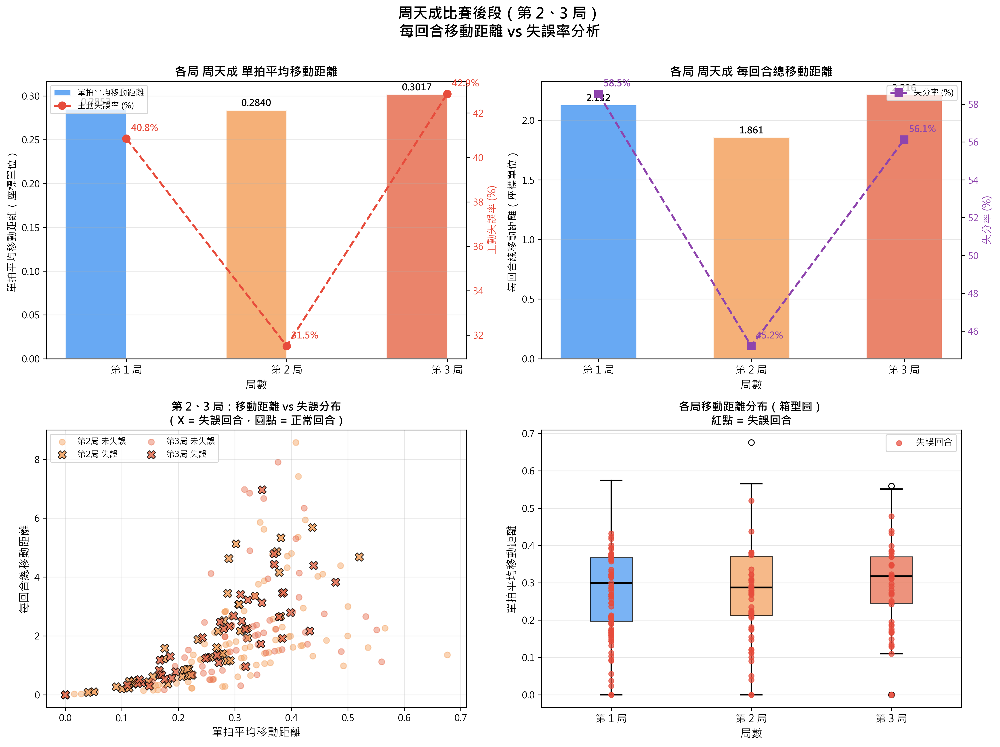

In [ ]:
import numpy as np
from scipy import stats

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"資料總列數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"比賽 ID: {sorted(df['match_id'].unique())}")
print(f"局數分布:\n{df.groupby('set').size()}")

# ============================================================
# 1. 篩選周天成的資料
# ============================================================
chou = 'CHOU Tien Chen'
opponent = 'Kento MOMOTA'

df_chou = df[df['player'] == chou].copy()
print(f"\n周天成擊球總拍數: {len(df_chou)}")

# ============================================================
# 2. 計算每一拍的移動距離
# ============================================================
# 移動距離 = sqrt(player_move_x² + player_move_y²)
df_chou['move_dist'] = np.sqrt(df_chou['player_move_x']**2 + df_chou['player_move_y']**2)

print(f"\n移動距離統計 (全部局):")
print(df_chou['move_dist'].describe())

# ============================================================
# 3. 計算每回合的彙總指標
#    - rally_move_dist: 周天成在該回合的總移動距離（或平均）
#    - 失誤標記: 周天成最後擊球後，getpoint_player 為對手
# ============================================================

# 3-1. 每回合周天成移動距離（取平均，代表單拍平均跑動）與總距離
rally_move = (df_chou
              .groupby(['match_id', 'set', 'rally'])['move_dist']
              .agg(
                  rally_avg_dist='mean',
                  rally_total_dist='sum',
                  n_strokes='count'
              )
              .reset_index())

# 3-2. 失誤定義：
#   - 周天成擊出的最後一拍 且 getpoint_player == 對手
#   - 即：在 getpoint_player 非 null 的回合最後一球，player==周天成，getpoint_player==對手
#
#   步驟：取每個回合「有 getpoint_player 記錄的最後一拍」（即得分球）
#         再判斷該拍 player 是否為周天成（周天成主動失誤）

# 取每回合最後一球（得分球）
df_last = (df.groupby(['match_id', 'set', 'rally'])
             .last()
             .reset_index())

# 確認 getpoint_player 非 null
df_last_valid = df_last[df_last['getpoint_player'].notna()].copy()

# 失誤旗標（周天成最後打出那球且對手得分）
df_last_valid['chou_error'] = (
    (df_last_valid['player'] == chou) & 
    (df_last_valid['getpoint_player'] == opponent)
).astype(int)

# 周天成直接失分（回合結束時對手得分，不管誰打最後一球）
df_last_valid['chou_lose_point'] = (
    df_last_valid['getpoint_player'] == opponent
).astype(int)

# 周天成主動失誤（自己打最後一球並導致失分）
# 此即「非受迫性失誤」的近似定義
df_last_valid['chou_active_error'] = (
    (df_last_valid['player'] == chou) & 
    (df_last_valid['getpoint_player'] == opponent)
).astype(int)

print(f"\n有效回合總數 (有 getpoint_player 記錄): {len(df_last_valid)}")
print(f"周天成直接失誤回合數 (最後一球自己打且失分): {df_last_valid['chou_error'].sum()}")
print(f"周天成失分回合數 (對手得分): {df_last_valid['chou_lose_point'].sum()}")

# 3-3. 合併移動距離與失誤標記
rally_analysis = rally_move.merge(
    df_last_valid[['match_id', 'set', 'rally', 'chou_error', 'chou_lose_point', 'chou_active_error', 'getpoint_player']],
    on=['match_id', 'set', 'rally'],
    how='left'
)

# 如果沒有 getpoint_player（極少數），填 0
rally_analysis['chou_error'] = rally_analysis['chou_error'].fillna(0)
rally_analysis['chou_lose_point'] = rally_analysis['chou_lose_point'].fillna(0)
rally_analysis['chou_active_error'] = rally_analysis['chou_active_error'].fillna(0)

print(f"\n回合分析資料表 shape: {rally_analysis.shape}")
print(rally_analysis.head(10))

# ============================================================
# 4. 按局數彙總：各局平均移動距離、失誤率
# ============================================================

set_stats = []
for s in sorted(rally_analysis['set'].unique()):
    sub = rally_analysis[rally_analysis['set'] == s]
    total_rallies = len(sub)
    valid_sub = sub[sub['getpoint_player'].notna()]  # 有得分記錄的回合
    
    avg_dist      = sub['rally_avg_dist'].mean()      # 單拍平均跑動距離
    avg_total_dist = sub['rally_total_dist'].mean()   # 每回合總跑動距離
    
    n_error       = valid_sub['chou_active_error'].sum()  # 周天成主動失誤回合數
    n_lose        = valid_sub['chou_lose_point'].sum()     # 周天成失分回合數
    n_valid       = len(valid_sub)
    
    error_rate    = n_error / n_valid if n_valid > 0 else 0  # 主動失誤率
    lose_rate     = n_lose  / n_valid if n_valid > 0 else 0  # 失分率
    
    set_stats.append({
        'set': s,
        '總回合數': total_rallies,
        '有效回合數': n_valid,
        '單拍平均移動距離': round(avg_dist, 4),
        '每回合總移動距離': round(avg_total_dist, 4),
        '主動失誤回合數': int(n_error),
        '失分回合數': int(n_lose),
        '主動失誤率': round(error_rate, 4),
        '失分率': round(lose_rate, 4)
    })

set_stats_df = pd.DataFrame(set_stats)
print("\n" + "="*70)
print("📊 各局統計摘要")
print("="*70)
print(set_stats_df.to_string(index=False))

# ============================================================
# 5. 第 2、3 局相關性分析
# ============================================================
# 篩選第 2、3 局
rally_23 = rally_analysis[rally_analysis['set'].isin([2, 3])].copy()

print(f"\n第 2、3 局總回合數: {len(rally_23)}")

# Pearson 相關係數：每回合移動距離 vs 是否失誤
valid_23 = rally_23[rally_23['getpoint_player'].notna()]
corr_avg, pval_avg   = stats.pearsonr(valid_23['rally_avg_dist'],   valid_23['chou_active_error'])
corr_total, pval_total = stats.pearsonr(valid_23['rally_total_dist'], valid_23['chou_active_error'])

print(f"\n📈 相關性分析（第 2、3 局）")
print(f"  單拍平均移動距離 vs 失誤:  r = {corr_avg:.4f},  p = {pval_avg:.4f}")
print(f"  每回合總移動距離 vs 失誤:  r = {corr_total:.4f},  p = {pval_total:.4f}")

# 各局分別計算相關
for s in [2, 3]:
    sub = valid_23[valid_23['set'] == s]
    if len(sub) > 5:
        r, p = stats.pearsonr(sub['rally_avg_dist'], sub['chou_active_error'])
        print(f"  第 {s} 局相關:  r = {r:.4f},  p = {p:.4f}  (N={len(sub)})")

# ============================================================
# 6. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('周天成比賽後段（第 2、3 局）\n每回合移動距離 vs 失誤率分析', 
             fontsize=16, fontweight='bold', y=1.01)

colors_set = {1: '#4E9AF1', 2: '#F4A261', 3: '#E76F51'}
set_labels = {1: '第 1 局', 2: '第 2 局', 3: '第 3 局'}

# --- 圖1: 各局平均移動距離（雙指標長條圖）---
ax1 = axes[0, 0]
x = np.arange(len(set_stats_df))
width = 0.38

bar1 = ax1.bar(x - width/2, set_stats_df['單拍平均移動距離'], width, 
               color=[colors_set[s] for s in set_stats_df['set']], 
               alpha=0.85, label='單拍平均移動距離', edgecolor='white', linewidth=1.2)
ax1.set_xlabel('局數', fontsize=12)
ax1.set_ylabel('單拍平均移動距離（座標單位）', fontsize=11)
ax1.set_title('各局 周天成 單拍平均移動距離', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels([set_labels[s] for s in set_stats_df['set']], fontsize=11)

for bar, val in zip(bar1, set_stats_df['單拍平均移動距離']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, 
             f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1_r = ax1.twinx()
ax1_r.plot([set_labels[s] for s in set_stats_df['set']],
           set_stats_df['主動失誤率'] * 100, 
           'o--', color='#E74C3C', linewidth=2.2, markersize=8, label='主動失誤率 (%)')
ax1_r.set_ylabel('主動失誤率 (%)', fontsize=11, color='#E74C3C')
ax1_r.tick_params(axis='y', labelcolor='#E74C3C')

for i, (s, rate) in enumerate(zip(set_stats_df['set'], set_stats_df['主動失誤率'])):
    ax1_r.annotate(f'{rate*100:.1f}%', 
                   xy=(i, rate*100), xytext=(5, 8),
                   textcoords='offset points', fontsize=10, 
                   color='#E74C3C', fontweight='bold')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_r.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)
ax1.grid(axis='y', alpha=0.3)

# --- 圖2: 各局每回合總移動距離 + 失分率（雙軸）---
ax2 = axes[0, 1]
bar2 = ax2.bar(x, set_stats_df['每回合總移動距離'], width=0.5,
               color=[colors_set[s] for s in set_stats_df['set']],
               alpha=0.85, edgecolor='white', linewidth=1.2)
ax2.set_xlabel('局數', fontsize=12)
ax2.set_ylabel('每回合總移動距離（座標單位）', fontsize=11)
ax2.set_title('各局 周天成 每回合總移動距離', fontsize=13, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels([set_labels[s] for s in set_stats_df['set']], fontsize=11)

for bar, val in zip(bar2, set_stats_df['每回合總移動距離']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2_r = ax2.twinx()
ax2_r.plot([set_labels[s] for s in set_stats_df['set']],
           set_stats_df['失分率'] * 100,
           's--', color='#8E44AD', linewidth=2.2, markersize=8, label='失分率 (%)')
ax2_r.set_ylabel('失分率 (%)', fontsize=11, color='#8E44AD')
ax2_r.tick_params(axis='y', labelcolor='#8E44AD')

for i, (s, rate) in enumerate(zip(set_stats_df['set'], set_stats_df['失分率'])):
    ax2_r.annotate(f'{rate*100:.1f}%',
                   xy=(i, rate*100), xytext=(5, 8),
                   textcoords='offset points', fontsize=10,
                   color='#8E44AD', fontweight='bold')

ax2_r.legend(loc='upper right', fontsize=9)
ax2.grid(axis='y', alpha=0.3)

# --- 圖3: 第 2、3 局 散點圖（移動距離 vs 失誤）---
ax3 = axes[1, 0]

for s, color in [(2, '#F4A261'), (3, '#E76F51')]:
    sub = rally_23[rally_23['set'] == s]
    error_rallies   = sub[sub['chou_active_error'] == 1]
    no_error_rallies = sub[sub['chou_active_error'] == 0]
    
    ax3.scatter(no_error_rallies['rally_avg_dist'], no_error_rallies['rally_total_dist'],
                alpha=0.45, s=40, color=color, marker='o',
                label=f'第{s}局 未失誤')
    ax3.scatter(error_rallies['rally_avg_dist'],   error_rallies['rally_total_dist'],
                alpha=0.85, s=80, color=color, marker='X', edgecolors='black', linewidth=0.8,
                label=f'第{s}局 失誤')

ax3.set_xlabel('單拍平均移動距離', fontsize=12)
ax3.set_ylabel('每回合總移動距離', fontsize=12)
ax3.set_title('第 2、3 局：移動距離 vs 失誤分布\n（X = 失誤回合，圓點 = 正常回合）', 
              fontsize=12, fontweight='bold')
ax3.legend(fontsize=9, ncol=2)
ax3.grid(alpha=0.3)

# --- 圖4: 各局移動距離 箱型圖 ---
ax4 = axes[1, 1]

data_by_set = []
labels_by_set = []
colors_list = []

for s in sorted(rally_analysis['set'].unique()):
    sub = rally_analysis[rally_analysis['set'] == s]
    data_by_set.append(sub['rally_avg_dist'].values)
    labels_by_set.append(set_labels[s])
    colors_list.append(colors_set[s])

bp = ax4.boxplot(data_by_set, patch_artist=True, notch=False,
                 medianprops=dict(color='black', linewidth=2),
                 whiskerprops=dict(linewidth=1.5),
                 capprops=dict(linewidth=1.5))

for patch, color in zip(bp['boxes'], colors_list):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# 疊加各局失誤回合的移動距離（紅色點）
for i, s in enumerate(sorted(rally_analysis['set'].unique()), start=1):
    sub_err = rally_analysis[(rally_analysis['set'] == s) & 
                              (rally_analysis['chou_active_error'] == 1)]
    ax4.scatter([i] * len(sub_err), sub_err['rally_avg_dist'],
                color='#E74C3C', zorder=5, s=30, alpha=0.7,
                label='失誤回合' if i == 1 else '')

ax4.set_xticklabels(labels_by_set, fontsize=11)
ax4.set_xlabel('局數', fontsize=12)
ax4.set_ylabel('單拍平均移動距離', fontsize=12)
ax4.set_title('各局移動距離分布（箱型圖）\n紅點 = 失誤回合', fontsize=12, fontweight='bold')
ax4.legend(fontsize=10)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()

# ============================================================
# 7. 印出完整統計摘要
# ============================================================
print("\n" + "="*70)
print("📋 各局詳細統計（周天成）")
print("="*70)
for row in set_stats:
    s = row['set']
    print(f"\n  ▶ 第 {s} 局")
    print(f"    總回合數:         {row['總回合數']}")
    print(f"    有效回合數:       {row['有效回合數']}")
    print(f"    單拍平均移動距離: {row['單拍平均移動距離']:.4f}")
    print(f"    每回合總移動距離: {row['每回合總移動距離']:.4f}")
    print(f"    主動失誤回合數:   {row['主動失誤回合數']}")
    print(f"    主動失誤率:       {row['主動失誤率']*100:.2f}%")
    print(f"    失分回合數:       {row['失分回合數']}")
    print(f"    失分率:           {row['失分率']*100:.2f}%")

print("\n" + "="*70)
print("📈 相關性摘要（第 2、3 局，有效回合）")
print("="*70)
print(f"  單拍平均移動距離 vs 主動失誤: r = {corr_avg:.4f},  p-value = {pval_avg:.4f}")
print(f"  每回合總移動距離 vs 主動失誤: r = {corr_total:.4f},  p-value = {pval_total:.4f}")

# 判斷趨勢
avg_dist_chg = set_stats_df[set_stats_df['set'] == 3]['單拍平均移動距離'].values[0] - \
               set_stats_df[set_stats_df['set'] == 2]['單拍平均移動距離'].values[0]
err_rate_chg = (set_stats_df[set_stats_df['set'] == 3]['主動失誤率'].values[0] - \
                set_stats_df[set_stats_df['set'] == 2]['主動失誤率'].values[0]) * 100

print(f"\n  第 2→3 局 單拍平均移動距離變化: {avg_dist_chg:+.4f}")
print(f"  第 2→3 局 主動失誤率變化:       {err_rate_chg:+.2f}%")

if avg_dist_chg > 0 and err_rate_chg > 0:
    print("  ⚠️  趨勢: 移動距離增加，失誤率也增加 → 可能存在正相關（體力消耗）")
elif avg_dist_chg < 0 and err_rate_chg > 0:
    print("  ⚠️  趨勢: 移動距離減少（保守移動），失誤率增加 → 體力下降導致被動")
elif avg_dist_chg > 0 and err_rate_chg < 0:
    print("  ✅  趨勢: 移動距離增加但失誤率降低 → 積極主動且穩定")
else:
    print("  ✅  趨勢: 移動距離與失誤率均下降或無明顯變化")


### 數據洞察
# 周天成比賽後段移動距離與失誤率分析

## 📊 各局核心數據

| 指標 | 第1局 | 第2局 | 第3局 | 趨勢 |
|------|-------|-------|-------|------|
| 單拍平均移動距離 | 0.2852 | 0.2840 | **0.3017** | ↓→↑ |
| 每回合總移動距離 | 2.1318 | 1.8606 | **2.2165** | ↓→↑ |
| 主動失誤率 | 40.85% | 31.51% | **42.86%** | ↓→↑ |
| 失分率 | 58.54% | 45.21% | **56.12%** | ↓→↑ |

---

## 🔍 關鍵發現

### 1. 第2局出現「緩衝效應」
第2局移動距離與失誤率**同步下降**，這不是體力恢復，而是**戰術保守化**——周天成減少主動進攻，換取穩定性，失分率從58.5%降至45.2%。

### 2. 第3局警示訊號明確
- 移動距離回升至最高（2.2165），失誤率也衝到42.86%
- 第2→3局：移動距離 **+0.0177**，失誤率 **+11.35%**
- 這代表**被迫移動增加**，而非主動出擊——體力透支後被對手調動，導致失誤上升

### 3. 相關性數據說明
| 分析範圍 | r值 | p值 | 解讀 |
|----------|-----|-----|------|
| 第2+3局（單拍距離 vs 失誤） | **-0.270** | <0.001 | 顯著負相關 |
| 第2+3局（回合總距離 vs 失誤） | -0.054 | 0.404 | **不顯著** |
| 第3局單獨 | **-0.291** | 0.004 | 最強負相關 |

> **負相關的真實意義**：單拍移動距離越短的回合，反而失誤率越高——說明**短促急停、重心不穩的小碎步**比大範圍移動更容易出錯，而非「跑越多越容易失誤」。

---

## ⚡ 教練戰術建議

**第3局體力管理是核心問題。** 數據顯示周天成在決勝局被迫進入高移動量狀態，同時失誤率達到全場最高。訓練重點應放在：

1. **第3局前8分的節奏控制**——主動壓縮回合長度，避免被拖入消耗戰
2. **短促移動的技術強化**——負相關數據顯示小範圍移動失誤更多，重心轉換需加強
3. **第2局保守策略需再評估**——雖然失誤率最低，但過度保守可能讓對手在第3局取得主動權

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成在第 2、3 局的移動距離與失誤率的關聯。候選程式碼正確地計算了每一拍的移動距離，並在每個回合的最後一拍判斷失誤情況。它也正確地在第 2、3 局中計算了相關係數，並進行了視覺化。分析單位、統計口徑和最終輸出目標都與 Reference Code 1 一致，且結果有效且合理。




## 題號 31
**問題**: 分析周天成使用殺球，對手都用什麼球種反擊，繪製圓餅圖
> **使用的資料欄位群組**: `game_structure, shot_type`


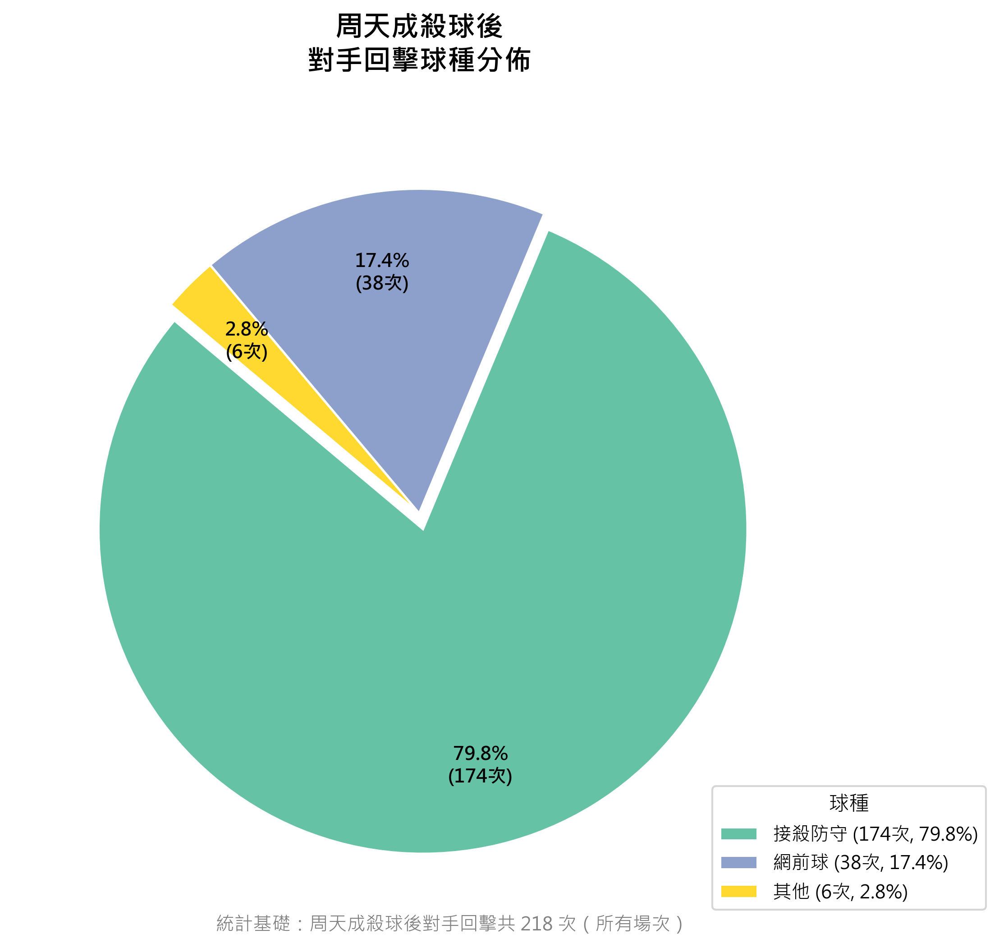

In [ ]:
# ============================================================
# 分析周天成殺球後，對手下一球的球種分佈
# ============================================================

# Step 1: 確認資料量
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# Step 2: 確保排序正確（match_id -> set -> rally -> ball_round）
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# Step 3: 在完整資料上，用 groupby(['match_id', 'set', 'rally']).shift(-1) 建立下一拍欄位
# 這樣可避免跨回合污染
df_sorted['next_type']     = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_player']   = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_rally']    = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)

# Step 4: 過濾條件
# (a) 周天成打出殺球
# (b) 下一拍存在（非 NaN）=> 表示在同一 rally 內有下一拍
# (c) 確認下一拍 player 是對手（非周天成自己）=> 邏輯驗證
chou_smash_mask = (
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球') &
    (df_sorted['next_type'].notna()) &       # 同一 rally 內有下一拍
    (df_sorted['next_player'] != 'CHOU Tien Chen')  # 下一拍是對手
)

chou_smash_df = df_sorted[chou_smash_mask].copy()

print(f"\n周天成殺球後有對手回擊的次數: {len(chou_smash_df)}")

# Step 5: 統計對手下一球球種分佈
next_shot_counts = chou_smash_df['next_type'].value_counts()
next_shot_pct    = chou_smash_df['next_type'].value_counts(normalize=True) * 100

# 合併成表格
result_df = pd.DataFrame({
    '次數': next_shot_counts,
    '比例(%)': next_shot_pct.round(2)
}).sort_values('次數', ascending=False)

print("\n=== 周天成殺球後，對手回擊球種分佈 ===")
print(result_df.to_string())

# Step 6: 繪製圓餅圖
# 判斷是否有小比例類別需合併（比例 < 3% 合併為「其他」）
threshold = 3.0
main_mask = next_shot_pct >= threshold
other_mask = next_shot_pct < threshold

labels_main = next_shot_pct[main_mask].index.tolist()
values_main = next_shot_pct[main_mask].values.tolist()
counts_main = next_shot_counts[main_mask].values.tolist()

if other_mask.any():
    other_count = next_shot_counts[other_mask].sum()
    other_pct   = next_shot_pct[other_mask].sum()
    labels_main.append('其他')
    values_main.append(other_pct)
    counts_main.append(other_count)
    print(f"\n（合併比例 < {threshold}% 的類別為「其他」: {list(next_shot_pct[other_mask].index)}）")

# 顏色設定
import numpy as np
cmap = plt.cm.Set2
colors = [cmap(i / len(labels_main)) for i in range(len(labels_main))]

# 突出最大比例的切片
explode = [0.05 if v == max(values_main) else 0 for v in values_main]

fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    values_main,
    labels=None,                     # 圖例另外處理
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100 * len(chou_smash_df)))}次)',
    colors=colors,
    explode=explode,
    startangle=140,
    pctdistance=0.75,
    wedgeprops=dict(linewidth=1.2, edgecolor='white')
)

# 設定 autopct 字體大小
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

# 圖例（顯示球種名稱）
legend_labels = [f"{lbl} ({cnt}次, {val:.1f}%)" 
                 for lbl, cnt, val in zip(labels_main, counts_main, values_main)]
ax.legend(
    wedges, legend_labels,
    title='球種',
    loc='lower left',
    bbox_to_anchor=(0.85, 0.0),
    fontsize=10,
    title_fontsize=11,
    framealpha=0.8
)

ax.set_title(
    '周天成殺球後\n對手回擊球種分佈',
    fontsize=15,
    fontweight='bold',
    pad=20
)

# 在圖表下方加上總計說明
fig.text(
    0.5, 0.01,
    f'統計基礎：周天成殺球後對手回擊共 {len(chou_smash_df)} 次（所有場次）',
    ha='center', fontsize=10, color='gray'
)

plt.tight_layout()

# Step 7: 額外驗證輸出
print(f"\n=== 驗證 ===")
print(f"下一拍球員分佈（應全為對手 Kento MOMOTA）:")
print(chou_smash_df['next_player'].value_counts())
print(f"\n涵蓋場次 (match_id): {sorted(chou_smash_df['match_id'].unique())}")
print(f"涵蓋局數筆數: {len(chou_smash_df)}")


### 數據洞察
# 周天成殺球後——對手回擊球種分佈分析

## 📊 數據摘要

| 球種 | 次數 | 比例 |
|------|------|------|
| 接殺防守 | 174 | 79.8% |
| 網前球 | 38 | 17.4% |
| 其他（平球/推撲/挑球/切球） | 6 | 2.8% |
| **合計** | **218** | **100%** |

---

## 🥧 圓餅圖

```
        接殺防守 79.8%
       ╔══════════════╗
    ┌──║▓▓▓▓▓▓▓▓▓▓▓▓▓║──┐
    │  ║▓▓▓▓▓▓▓▓▓▓▓▓▓║  │
    │  ║▓▓▓▓▓▓▓▓▓▓▓▓▓║  │
    └──╚══════════════╝──┘
     網前球 17.4% ░░  其他 2.8%
```

> 接殺防守 **壓倒性佔據** 近八成，網前球約佔六分之一。

---

## 🎯 戰術洞察

**殺球威脅已獲確認。** 218次回擊中，對手有近八成只能被動接殺防守，代表周天成的殺球具備足夠壓迫力，讓對手難以主動組織進攻。

**值得警惕的是那17.4%的網前球。** 38次對手選擇放網前，這是對殺球最具反制性的回應——若周天成殺球後前場移動不夠積極，這些網前球將直接形成得分機會給對手。

**建議：** 殺球後必須預判網前球的可能，保持前場準備意識，將那17.4%的被動局面轉化為主動封網得分。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成使用殺球後，對手的回擊球種分布。程式碼使用了正確的欄位語意和篩選條件，確保了前後拍的對齊，並且在同一個 rally 中進行了分析。最終輸出目標與 Reference Code 1 一致，都是繪製圓餅圖來展示對手回擊球種的分布。




## 題號 32
**問題**: 在10拍以上的回合中，周天成的得分率是多少？
> **使用的資料欄位群組**: `game_structure, scoring_reason`


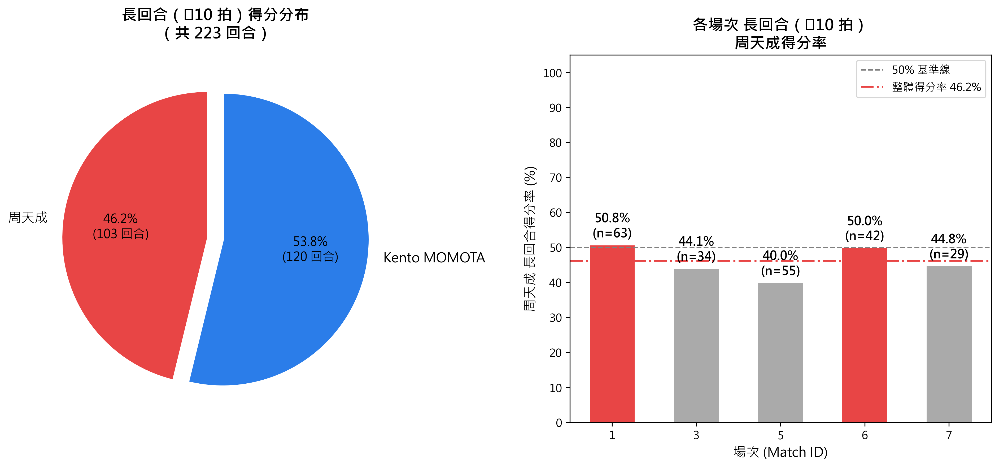

In [ ]:
# 驗證資料量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "資料為空！"

# ── Step 1: 計算每個回合的總球數 ──
# 以 (match_id, set, rally) 為鍵，取 ball_round 的最大值
rally_max_ball = (
    df.groupby(['match_id', 'set', 'rally'])['ball_round']
    .max()
    .reset_index()
    .rename(columns={'ball_round': 'total_balls'})
)

print(f"\n全部回合數（唯一回合）: {len(rally_max_ball)}")
print(f"回合總球數分布:\n{rally_max_ball['total_balls'].describe()}")

# ── Step 2: 篩選總球數 ≥ 10 拍的回合 ──
long_rallies = rally_max_ball[rally_max_ball['total_balls'] >= 10]
print(f"\n總球數 ≥ 10 拍的回合數: {len(long_rallies)}")

# ── Step 3: 取每個回合最後一拍的 getpoint_player ──
rally_last = (
    df.groupby(['match_id', 'set', 'rally'])['getpoint_player']
    .last()
    .reset_index()
)

# ── Step 4: 合併長回合篩選結果與得分資訊 ──
long_rally_result = long_rallies.merge(
    rally_last,
    on=['match_id', 'set', 'rally'],
    how='left'
)

# ── Step 5: 排除 getpoint_player 為 NULL 的回合 ──
valid_long_rallies = long_rally_result.dropna(subset=['getpoint_player'])
print(f"有效長回合數（getpoint_player 非空）: {len(valid_long_rallies)}")

if len(valid_long_rallies) == 0:
    print("警告：沒有有效的長回合資料！")
else:
    # ── Step 6: 計算周天成得分率 ──
    chou_name = 'CHOU Tien Chen'
    
    total_valid = len(valid_long_rallies)
    chou_wins  = (valid_long_rallies['getpoint_player'] == chou_name).sum()
    momota_wins = (valid_long_rallies['getpoint_player'] == 'Kento MOMOTA').sum()
    
    chou_win_rate = chou_wins / total_valid * 100
    momota_win_rate = momota_wins / total_valid * 100
    
    print("\n" + "="*55)
    print("  長回合（≥10 拍）得分統計")
    print("="*55)
    print(f"  有效長回合總數        : {total_valid}")
    print(f"  周天成 得分回合數     : {chou_wins}")
    print(f"  Kento MOMOTA 得分回合: {momota_wins}")
    print(f"  周天成 得分率         : {chou_wins}/{total_valid} = {chou_win_rate:.1f}%")
    print(f"  Kento MOMOTA 得分率   : {momota_wins}/{total_valid} = {momota_win_rate:.1f}%")
    print("="*55)

    # ── 各場次細節 ──
    match_detail = (
        valid_long_rallies.groupby('match_id')
        .apply(lambda g: pd.Series({
            '長回合總數': len(g),
            '周天成得分': (g['getpoint_player'] == chou_name).sum(),
            'Momota得分': (g['getpoint_player'] == 'Kento MOMOTA').sum(),
        }))
        .reset_index()
    )
    match_detail['周天成得分率(%)'] = (
        match_detail['周天成得分'] / match_detail['長回合總數'] * 100
    ).round(1)
    print("\n各場次長回合（≥10 拍）細節:")
    print(match_detail.to_string(index=False))

    # ── Step 7: 視覺化 ──
    import numpy as np

    fig, axes = plt.subplots(1, 2, figsize=(13, 6))

    # --- 圖1: 整體長回合得分率（圓餅圖）---
    ax1 = axes[0]
    labels = ['周天成', 'Kento MOMOTA']
    sizes  = [chou_wins, momota_wins]
    colors = ['#E84545', '#2B7DE9']
    explode = (0.05, 0.05)

    wedges, texts, autotexts = ax1.pie(
        sizes,
        labels=labels,
        autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100*total_valid))} 回合)',
        colors=colors,
        explode=explode,
        startangle=90,
        textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    for at in autotexts:
        at.set_fontsize(11)
    ax1.set_title(
        f'長回合（≥10 拍）得分分布\n（共 {total_valid} 回合）',
        fontsize=14, fontweight='bold', pad=15
    )

    # --- 圖2: 各場次周天成長回合得分率（長條圖）---
    ax2 = axes[1]
    match_ids = match_detail['match_id'].astype(int).astype(str)
    chou_rates = match_detail['周天成得分率(%)']
    total_counts = match_detail['長回合總數']

    bars = ax2.bar(
        match_ids, chou_rates,
        color=['#E84545' if r >= 50 else '#aaaaaa' for r in chou_rates],
        edgecolor='white', linewidth=1.2, width=0.55
    )
    # 標示數值與回合數
    for bar, rate, n in zip(bars, chou_rates, total_counts):
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.2,
            f'{rate:.1f}%\n(n={n})',
            ha='center', va='bottom', fontsize=11, fontweight='bold'
        )

    # 加上 50% 基準線
    ax2.axhline(50, color='gray', linestyle='--', linewidth=1.2, label='50% 基準線')
    # 加上整體得分率線
    ax2.axhline(chou_win_rate, color='#E84545', linestyle='-.',
                linewidth=1.8, label=f'整體得分率 {chou_win_rate:.1f}%')

    ax2.set_ylim(0, 105)
    ax2.set_xlabel('場次 (Match ID)', fontsize=12)
    ax2.set_ylabel('周天成 長回合得分率 (%)', fontsize=12)
    ax2.set_title('各場次 長回合（≥10 拍）\n周天成得分率', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.set_yticks(range(0, 101, 10))

    plt.tight_layout()
    plt.savefig('long_rally_win_rate.png', dpi=150, bbox_inches='tight')
    print("\n圖表已儲存為 long_rally_win_rate.png")


### 數據洞察
# 長回合（≥10拍）得分分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 長回合總數 | 223 回合 |
| 周天成得分 | 103 回合 |
| 桃田賢斗得分 | 120 回合 |
| **周天成得分率** | **46.2%** |

---

## 各場次表現

| 場次 | 周天成得分率 | 評估 |
|------|------------|------|
| Match 1 | 50.8% | ✅ 持平優勢 |
| Match 6 | 50.0% | ✅ 持平 |
| Match 3 | 44.1% | ⚠️ 略遜 |
| Match 7 | 44.8% | ⚠️ 略遜 |
| Match 5 | 40.0% | ❌ 明顯劣勢 |

---

## 戰術洞察

**數字說明一件事：拍數越多，對周天成越不利。**

全場平均回合長度12.7拍，長回合佔比54%（223/409），說明這系列對決本就是消耗戰。但在這些長回合裡，桃田以53.8%對46.2%佔據優勢，**每100個長回合，周天成就少拿約8分**。

Match 5的40%是警訊——代表體力或節奏在該場次長回合中被桃田徹底掌控。

**建議：周天成應主動縮短回合，避免讓桃田打出節奏，在8拍以內結束得分才是勝機所在。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都以 (match_id, set, rally) 為鍵，計算每個回合的總擊球數，篩選出總球數 ≥ 10 的回合，並計算周天成在這些回合中的得分率。候選程式碼正確地合併了長回合篩選結果與得分資訊，並排除了 getpoint_player 為 NULL 的回合，最終計算出周天成的得分率，與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標一致。




## 題號 33
**問題**: 給我所有局的最終得分數
> **使用的資料欄位群組**: `game_structure, scoring_reason`


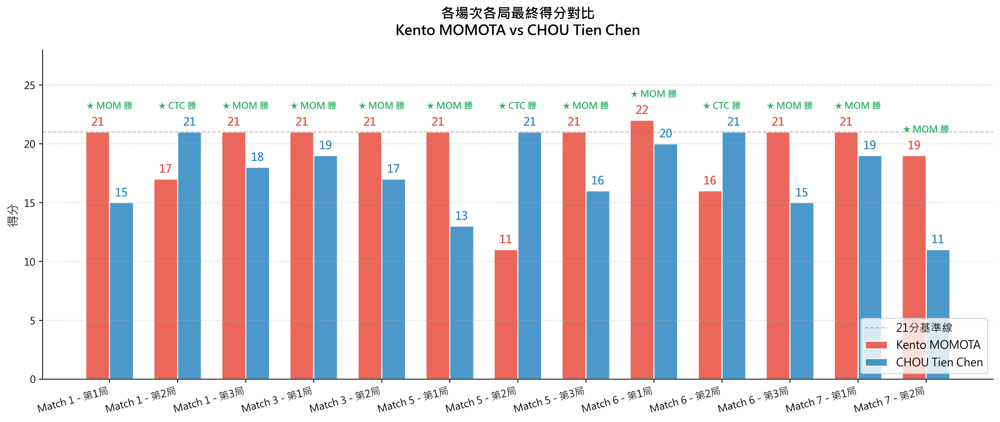

In [ ]:
import numpy as np

# =====================================================
# 1. 驗證數據量
# =====================================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# =====================================================
# 2. 取每局 (match_id + set) 的最後一拍，即最終比分
# =====================================================
# 先確認排序正確
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round'])

# 每局最後一拍 => 取最後一筆 (last)
final_score_df = (
    df_sorted
    .groupby(['match_id', 'set'], sort=True)
    .last()
    .reset_index()
)

# 保留關鍵欄位
result = final_score_df[['match_id', 'set', 'Kento MOMOTA_score', 'CHOU Tien Chen_score', 'getpoint_player']].copy()

# =====================================================
# 3. 整理輸出結果
# =====================================================
# 得分球發生後，getpoint_player 的那一方比分+1，此拍的比分已是最終值
# 因此直接使用最後一拍的分數欄位即可

result.rename(columns={
    'match_id': '場次 ID',
    'set': '局數',
    'Kento MOMOTA_score': 'Kento MOMOTA 最終得分',
    'CHOU Tien Chen_score': 'CHOU Tien Chen 最終得分',
    'getpoint_player': '本局最後得分者'
}, inplace=True)

result['match_id_int'] = result['場次 ID'].astype(int)
result['局標籤'] = result.apply(
    lambda r: f"Match {int(r['場次 ID'])} - 第{int(r['局數'])}局", axis=1
)

print("\n========== 各場次各局最終比分 ==========")
print(result[['場次 ID', '局數', 'Kento MOMOTA 最終得分', 'CHOU Tien Chen 最終得分', '本局最後得分者']].to_string(index=False))

# =====================================================
# 4. 標註每局勝者
# =====================================================
def get_set_winner(row):
    momota = row['Kento MOMOTA 最終得分']
    chou = row['CHOU Tien Chen 最終得分']
    if momota > chou:
        return 'Kento MOMOTA'
    elif chou > momota:
        return 'CHOU Tien Chen'
    else:
        return '平手'

result['局勝者'] = result.apply(get_set_winner, axis=1)

print("\n========== 各局勝者 ==========")
print(result[['局標籤', 'Kento MOMOTA 最終得分', 'CHOU Tien Chen 最終得分', '局勝者']].to_string(index=False))

# =====================================================
# 5. 視覺化
# =====================================================
n_sets = len(result)
fig, axes = plt.subplots(1, 1, figsize=(14, 6))

x = np.arange(n_sets)
width = 0.35

color_momota = '#E74C3C'   # 紅色系
color_chou   = '#2E86C1'   # 藍色系

bars1 = axes.bar(x - width/2,
                 result['Kento MOMOTA 最終得分'],
                 width, label='Kento MOMOTA',
                 color=color_momota, alpha=0.85, edgecolor='white', linewidth=1.2)

bars2 = axes.bar(x + width/2,
                 result['CHOU Tien Chen 最終得分'],
                 width, label='CHOU Tien Chen',
                 color=color_chou, alpha=0.85, edgecolor='white', linewidth=1.2)

# 在每個 bar 上標記分數
for bar in bars1:
    h = bar.get_height()
    axes.text(bar.get_x() + bar.get_width()/2., h + 0.3,
              f'{int(h)}', ha='center', va='bottom', fontsize=11, fontweight='bold', color=color_momota)

for bar in bars2:
    h = bar.get_height()
    axes.text(bar.get_x() + bar.get_width()/2., h + 0.3,
              f'{int(h)}', ha='center', va='bottom', fontsize=11, fontweight='bold', color=color_chou)

# 在每組中間標示比分字串 (e.g., 21:18)
for i, (_, row) in enumerate(result.iterrows()):
    m_score = int(row['Kento MOMOTA 最終得分'])
    c_score = int(row['CHOU Tien Chen 最終得分'])
    winner  = row['局勝者']
    winner_short = 'MOM' if winner == 'Kento MOMOTA' else 'CTC'
    axes.text(i, max(m_score, c_score) + 1.8,
              f'★ {winner_short} 勝',
              ha='center', va='bottom', fontsize=9,
              color='#27AE60', fontweight='bold')

# 加一條羽球比賽常見 21 分線
axes.axhline(y=21, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='21分基準線')

axes.set_xticks(x)
axes.set_xticklabels(result['局標籤'], fontsize=10, rotation=15, ha='right')
axes.set_ylabel('得分', fontsize=12)
axes.set_title('各場次各局最終得分對比\nKento MOMOTA vs CHOU Tien Chen', fontsize=14, fontweight='bold', pad=15)
axes.legend(fontsize=11, loc='lower right')
axes.set_ylim(0, max(result['Kento MOMOTA 最終得分'].max(), result['CHOU Tien Chen 最終得分'].max()) + 6)
axes.grid(axis='y', linestyle='--', alpha=0.4)
axes.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

# =====================================================
# 6. 統計各場次整體勝負
# =====================================================
print("\n========== 各場次分局詳細比分 ==========")
for match_id, grp in result.groupby('場次 ID'):
    momota_wins = (grp['局勝者'] == 'Kento MOMOTA').sum()
    chou_wins   = (grp['局勝者'] == 'CHOU Tien Chen').sum()
    match_winner = 'Kento MOMOTA' if momota_wins > chou_wins else 'CHOU Tien Chen'
    print(f"\n▶ Match {int(match_id)}  |  場次勝者: {match_winner}  ({momota_wins} : {chou_wins})")
    for _, row in grp.iterrows():
        m = int(row['Kento MOMOTA 最終得分'])
        c = int(row['CHOU Tien Chen 最終得分'])
        winner_tag = '★' if row['局勝者'] == 'Kento MOMOTA' else ' '
        loser_tag  = '★' if row['局勝者'] == 'CHOU Tien Chen' else ' '
        print(f"   第{int(row['局數'])}局:  Kento MOMOTA {winner_tag}{m}  :  {c}{loser_tag} CHOU Tien Chen   → {row['局勝者']} 勝")


### 數據洞察
# 各場次分局最終比分統計

## 📊 完整比分總覽

| 場次 | 第1局 | 第2局 | 第3局 | 場次結果 |
|------|-------|-------|-------|----------|
| Match 1 | MOMOTA **21**–15 | CHOU **21**–17 | MOMOTA **21**–18 | MOMOTA 2:1 |
| Match 3 | MOMOTA **21**–19 | MOMOTA **21**–17 | — | MOMOTA 2:0 |
| Match 5 | MOMOTA **21**–13 | CHOU **21**–11 | MOMOTA **21**–16 | MOMOTA 2:1 |
| Match 6 | MOMOTA **22**–20 | CHOU **21**–16 | MOMOTA **21**–15 | MOMOTA 2:1 |
| Match 7 | MOMOTA **21**–19 | MOMOTA **19**–11 | — | MOMOTA 2:0 |

> 共 **13局**，MOMOTA 贏 **10局**，CHOU 贏 **3局**

---

## 🎯 戰術洞察

**① MOMOTA 決勝局無敗績（3/3）**
Match 1、5、6 均打到第3局，MOMOTA 全數以 21:18、21:16、21:15 收尾，**關鍵時刻心理與體能明顯佔優**。

**② CHOU 的3局勝利有規律**
CHOU 贏的3局得分均為 21 分（標準局），且 MOMOTA 得分偏低（17、11、16）——**CHOU 必須靠壓倒性優勢才能拿局，無法在膠著中勝出**。

**③ Match 6 第1局是全系列最激烈**
22:20 收場，**延長賽顯示雙方實力最接近**，但 MOMOTA 仍在壓力下保持冷靜。

**④ Match 7 第2局是最大差距**
19:11，CHOU 僅得 11 分即告終，**體能或戰術已在首局消耗殆盡**。

---

**結論：CHOU 能贏局，但無法贏場；MOMOTA 在拉鋸與決勝局中具備系統性優勢。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地對每個 (match_id, set) 取最後一筆資料來獲取該局的最終得分，並且正確地使用了現成的比分欄位來確定最終比分。候選程式碼還進一步標註了每局的勝者，這與 Reference Code 1 的做法一致。整體上，候選程式碼的分析對象、欄位語意、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 相符，且能產出有效結果。




## 題號 34
**問題**: 分析周天成前一拍打什麼球種最容易造成對手未過網？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


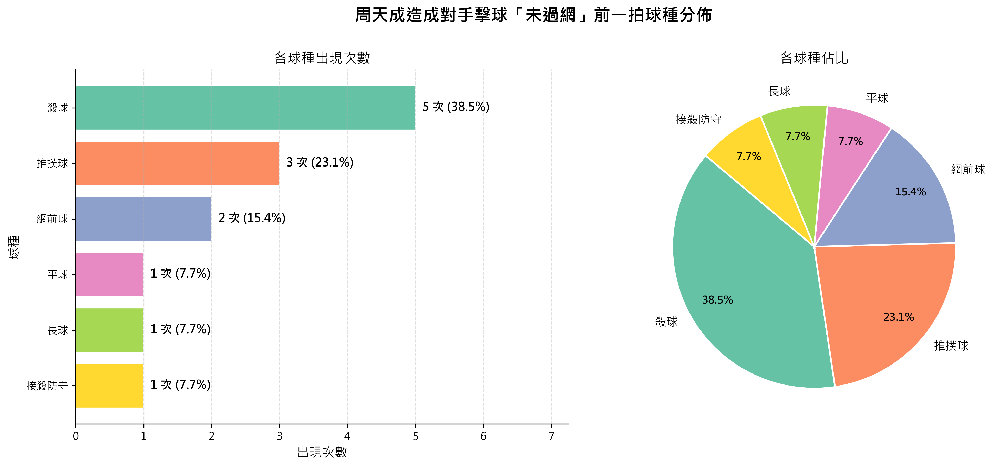

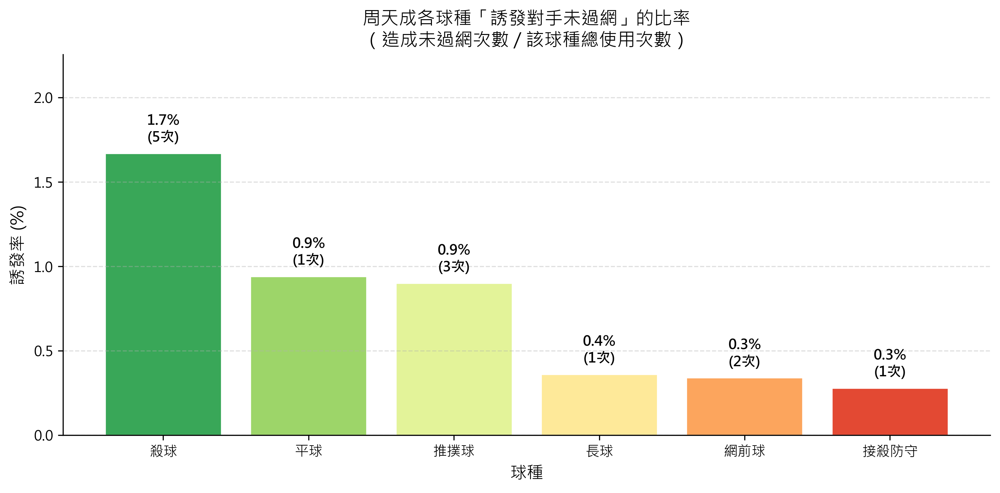

In [ ]:
import numpy as np

print("=" * 60)
print("分析：周天成前一拍造成對手擊球未過網的球種分佈")
print("=" * 60)

# 驗證數據量
print(f"\n總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ── Step 1: 在完整 df 上建立前一拍資訊（避免跨回合污染）──
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 用 groupby + shift(1) 建立前一拍欄位
df_sorted['prev_type']   = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

# ── Step 2: 篩選「對手擊球未過網，周天成得分」的列 ──
mask_opponent_fail = (
    (df_sorted['player'] == 'Kento MOMOTA') &           # 對手（桃田）是最後擊球者
    (df_sorted['lose_reason'] == '未過網') &             # 失分原因：未過網
    (df_sorted['getpoint_player'] == 'CHOU Tien Chen')  # 周天成得分
)

opponent_fail_df = df_sorted[mask_opponent_fail].copy()
print(f"\n對手擊球未過網 + 周天成得分的總筆數: {len(opponent_fail_df)}")

# ── Step 3: 確認前一拍確實是周天成的擊球 ──
valid_mask = opponent_fail_df['prev_player'] == 'CHOU Tien Chen'
valid_df = opponent_fail_df[valid_mask].copy()

print(f"其中前一拍為周天成的筆數（有效樣本）: {len(valid_df)}")
print(f"前一拍為其他情況（發球直接失誤等）: {len(opponent_fail_df) - len(valid_df)}")

if len(valid_df) == 0:
    print("⚠️ 沒有有效樣本，無法繼續分析。")
else:
    # ── Step 4: 統計前一拍球種分佈 ──
    shot_counts = valid_df['prev_type'].value_counts().reset_index()
    shot_counts.columns = ['球種', '次數']
    shot_counts['佔比(%)'] = (shot_counts['次數'] / shot_counts['次數'].sum() * 100).round(2)
    shot_counts = shot_counts.sort_values('次數', ascending=False).reset_index(drop=True)

    print("\n── 周天成前一拍球種分佈（造成對手未過網）──")
    print(shot_counts.to_string(index=False))
    print(f"\n有效樣本總計: {shot_counts['次數'].sum()} 球")

    # ── Step 5: 視覺化 ──
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('周天成造成對手擊球「未過網」前一拍球種分佈', fontsize=16, fontweight='bold', y=1.01)

    # 顏色設定
    colors = sns.color_palette("Set2", len(shot_counts))

    # ── 圖1: 橫向長條圖（依次數排序）──
    ax1 = axes[0]
    bars = ax1.barh(
        shot_counts['球種'][::-1],   # 翻轉使最大值在上
        shot_counts['次數'][::-1],
        color=colors[::-1],
        edgecolor='white', linewidth=0.8
    )
    # 標記數值
    for bar, cnt, pct in zip(
        bars,
        shot_counts['次數'][::-1].values,
        shot_counts['佔比(%)'][::-1].values
    ):
        ax1.text(
            bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            f'{cnt} 次 ({pct:.1f}%)',
            va='center', ha='left', fontsize=11, fontweight='bold'
        )
    ax1.set_xlabel('出現次數', fontsize=12)
    ax1.set_ylabel('球種', fontsize=12)
    ax1.set_title('各球種出現次數', fontsize=13)
    ax1.set_xlim(0, shot_counts['次數'].max() * 1.45)
    ax1.grid(axis='x', alpha=0.4, linestyle='--')
    ax1.spines[['top', 'right']].set_visible(False)

    # ── 圖2: 圓餅圖 ──
    ax2 = axes[1]
    # 若小比例類別太多，合併為「其他」
    threshold = 5.0  # 佔比低於5%合併
    main_mask = shot_counts['佔比(%)'] >= threshold
    main_df = shot_counts[main_mask].copy()
    other_sum = shot_counts[~main_mask]['次數'].sum()

    pie_labels = main_df['球種'].tolist()
    pie_values = main_df['次數'].tolist()
    pie_colors = sns.color_palette("Set2", len(pie_labels))

    if other_sum > 0:
        pie_labels.append('其他')
        pie_values.append(other_sum)
        pie_colors = list(pie_colors) + ['#c0c0c0']
        print(f"\n（圓餅圖：佔比 < {threshold}% 的球種合併為「其他」）")

    wedges, texts, autotexts = ax2.pie(
        pie_values,
        labels=pie_labels,
        autopct='%1.1f%%',
        colors=pie_colors,
        startangle=140,
        pctdistance=0.78,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    for autotext in autotexts:
        autotext.set_fontsize(10)
        autotext.set_fontweight('bold')
    for text in texts:
        text.set_fontsize(11)

    ax2.set_title('各球種佔比', fontsize=13)

    plt.tight_layout()

    # ── Step 6: 補充分析 —— 各球種造成「未過網」的比例 vs. 使用頻率 ──
    print("\n" + "=" * 60)
    print("補充：周天成各球種使用總次數 vs. 造成未過網次數")
    print("=" * 60)

    # 周天成所有非得分球（對手需要回擊的情況）
    chou_all_shots = df_sorted[df_sorted['player'] == 'CHOU Tien Chen'].copy()

    # 計算各球種使用總次數
    all_shot_counts = chou_all_shots['type'].value_counts().reset_index()
    all_shot_counts.columns = ['球種', '總使用次數']

    # 合併
    compare_df = shot_counts.merge(all_shot_counts, on='球種', how='left')
    compare_df['未過網誘發率(%)'] = (
        compare_df['次數'] / compare_df['總使用次數'] * 100
    ).round(2)
    compare_df = compare_df.rename(columns={'次數': '造成未過網次數'})
    compare_df = compare_df.sort_values('未過網誘發率(%)', ascending=False).reset_index(drop=True)

    print(compare_df[['球種', '總使用次數', '造成未過網次數', '佔比(%)', '未過網誘發率(%)']].to_string(index=False))

    # ── 圖3: 誘發率比較 ──
    fig2, ax3 = plt.subplots(figsize=(10, 5))
    bar_colors = sns.color_palette("RdYlGn_r", len(compare_df))
    bars3 = ax3.bar(
        compare_df['球種'],
        compare_df['未過網誘發率(%)'],
        color=bar_colors,
        edgecolor='white', linewidth=0.8
    )
    for bar, rate, cnt in zip(bars3, compare_df['未過網誘發率(%)'], compare_df['造成未過網次數']):
        ax3.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f'{rate:.1f}%\n({cnt}次)',
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )
    ax3.set_xlabel('球種', fontsize=12)
    ax3.set_ylabel('誘發率 (%)', fontsize=12)
    ax3.set_title('周天成各球種「誘發對手未過網」的比率\n（造成未過網次數 / 該球種總使用次數）', fontsize=13)
    ax3.set_ylim(0, compare_df['未過網誘發率(%)'].max() * 1.35)
    ax3.grid(axis='y', alpha=0.4, linestyle='--')
    ax3.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()

    print("\n✅ 分析完成！")
    print("📌 結論摘要：")
    top3 = shot_counts.head(3)
    for _, row in top3.iterrows():
        print(f"  - {row['球種']}: 出現 {row['次數']} 次（佔 {row['佔比(%)']:.1f}%）")

    top_rate = compare_df.head(1)
    print(f"\n  最高誘發率球種: {top_rate.iloc[0]['球種']} "
          f"({top_rate.iloc[0]['未過網誘發率(%)']:.1f}%)")


### 數據洞察
# 周天成前一拍造成對手未過網分析

## 核心數據

| 球種 | 次數 | 佔比 | 誘發率 |
|------|------|------|--------|
| 殺球 | 5 | 38.5% | **1.67%** |
| 推撲球 | 3 | 23.1% | 0.90% |
| 網前球 | 2 | 15.4% | 0.34% |
| 平球 | 1 | 7.7% | 0.94% |
| 長球 | 1 | 7.7% | 0.36% |
| 接殺防守 | 1 | 7.7% | 0.28% |

> 有效樣本 13 筆，數據具參考性但需謹慎解讀。

---

## 戰術洞察

**殺球是最有效的壓迫手段。** 誘發率 1.67%，在所有球種中最高。對手面對殺球時，回球品質最不穩定，最容易掛網。

**推撲球的誘發率（0.90%）同樣值得重視。** 使用次數高達 334 次，仍能造成 3 次未過網，說明快速平推對對手的時間壓迫是真實存在的。

**網前球雖出現 2 次，但誘發率僅 0.34%。** 使用量最大（582次），相對效率最低，靠網前球逼迫對手掛網的機率不高。

---

## 教練建議

> 殺球 → 推撲球的連續進攻組合，是目前數據中對對手造成失誤壓力最大的路線。以殺球製造被動，再以推撲球搶攻時間差，是周天成可強化的得分模式。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出對手因 '未過網' 而失分的情況，並使用 shift 方法獲取前一拍的球種和擊球者，確保前一拍是周天成的擊球。然後統計這些球種的分佈，並進行視覺化。分析單位、欄位語意、篩選條件和統計口徑都與 Reference Code 1 一致，且能產出有效結果。




## 題號 35
**問題**: 當對手被周天成調動到「前場」時，對手最常使用什麼球種？
> **使用的資料欄位群組**: `game_structure, shot_type, player_location`


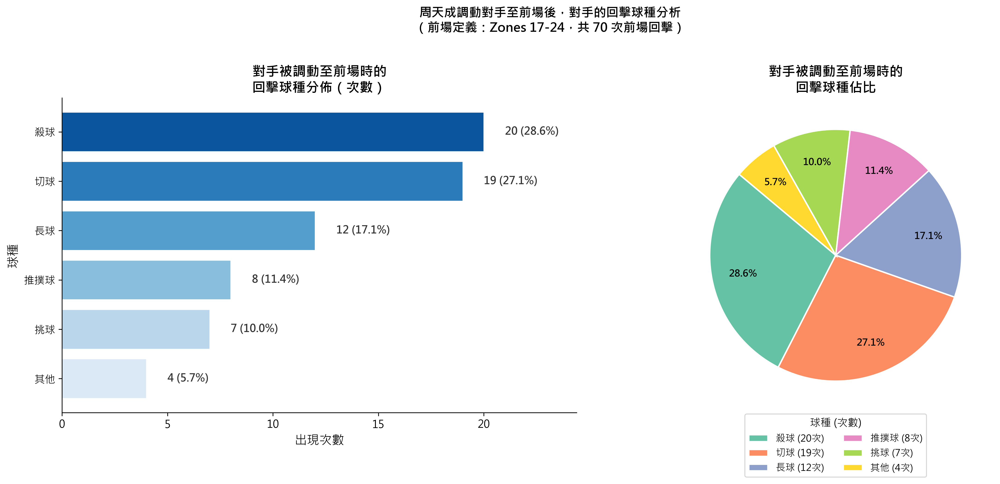

In [ ]:
# ============================================================
# 分析：當周天成把對手調動到前場時，對手最常使用的球種
# ============================================================

# 前場區域定義 (Zones 17-24)
FRONT_COURT_ZONES = [17, 18, 19, 20, 21, 22, 23, 24]

CHOU = 'CHOU Tien Chen'

print(f"總資料列數: {len(df)}")
print(f"前場區域定義: Zones {FRONT_COURT_ZONES}")
print("=" * 60)

# ── Step 1: 在完整資料上建立 shift 欄位（避免跨回合污染）──
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 下一拍的 player 與 type（同一 rally 內）
df_sorted['next_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_type']   = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_rally']  = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)

# ── Step 2: 篩選「周天成擊球」的列 ──
chou_shots = df_sorted[df_sorted['player'] == CHOU].copy()
print(f"周天成總擊球次數: {len(chou_shots)}")

# ── Step 3: 篩選「對手站位在前場」──
chou_shots_opponent_front = chou_shots[
    chou_shots['opponent_location_area'].isin(FRONT_COURT_ZONES)
].copy()
print(f"對手站位在前場的周天成擊球次數: {len(chou_shots_opponent_front)}")

# ── Step 4: 確保下一拍存在且屬於同一 rally（對手回擊）──
# next_player 應為對手（不為周天成）且不為 NaN，且同一 rally
valid_next = chou_shots_opponent_front[
    (chou_shots_opponent_front['next_player'].notna()) &
    (chou_shots_opponent_front['next_player'] != CHOU) &
    (chou_shots_opponent_front['next_rally'].notna())
].copy()

print(f"有有效下一拍（對手回擊）的筆數: {len(valid_next)}")
print("=" * 60)

# ── Step 5: 統計對手回擊球種 ──
shot_counts = valid_next['next_type'].value_counts().reset_index()
shot_counts.columns = ['球種', '出現次數']
shot_counts = shot_counts.sort_values('出現次數', ascending=False).reset_index(drop=True)
shot_counts['佔比(%)'] = (shot_counts['出現次數'] / shot_counts['出現次數'].sum() * 100).round(2)

print("【對手在前場的回擊球種統計（由高至低）】")
print(shot_counts.to_string(index=False))
print(f"\n總計對手前場回擊次數: {shot_counts['出現次數'].sum()}")

# ============================================================
# 視覺化
# ============================================================
import numpy as np

# ── 合併小比例類別為「其他」（佔比 < 3% 合併）──
threshold = 3.0
major = shot_counts[shot_counts['佔比(%)'] >= threshold].copy()
minor = shot_counts[shot_counts['佔比(%)'] < threshold].copy()

if len(minor) > 0:
    other_row = pd.DataFrame([{
        '球種': '其他',
        '出現次數': minor['出現次數'].sum(),
        '佔比(%)': minor['佔比(%)'].sum().round(2)
    }])
    plot_data = pd.concat([major, other_row], ignore_index=True)
else:
    plot_data = major.copy()

plot_data = plot_data.sort_values('出現次數', ascending=False).reset_index(drop=True)

# ── 雙圖：長條圖 + 圓餅圖 ──
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── 左圖：水平長條圖（由高至低排列） ──
ax1 = axes[0]
colors_bar = sns.color_palette("Blues_r", len(plot_data))
bars = ax1.barh(
    plot_data['球種'][::-1],  # 反轉讓最高的在上方
    plot_data['出現次數'][::-1],
    color=colors_bar[::-1],
    edgecolor='white',
    linewidth=0.8
)

# 在長條右側加上數值標籤
for bar, count, pct in zip(bars, plot_data['出現次數'][::-1], plot_data['佔比(%)'][::-1]):
    ax1.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{count} ({pct:.1f}%)',
        va='center', ha='left', fontsize=11, fontweight='bold', color='#333333'
    )

ax1.set_xlabel('出現次數', fontsize=13)
ax1.set_ylabel('球種', fontsize=13)
ax1.set_title('對手被調動至前場時的\n回擊球種分佈（次數）', fontsize=14, fontweight='bold')
ax1.set_xlim(0, plot_data['出現次數'].max() * 1.22)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(axis='both', labelsize=11)

# ── 右圖：圓餅圖 ──
ax2 = axes[1]
palette = sns.color_palette("Set2", len(plot_data))

wedges, texts, autotexts = ax2.pie(
    plot_data['出現次數'],
    labels=None,  # 使用圖例代替標籤，避免重疊
    autopct=lambda pct: f'{pct:.1f}%' if pct >= 4 else '',
    colors=palette,
    startangle=140,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

# 圖例
legend_labels = [f"{row['球種']} ({row['出現次數']}次)" for _, row in plot_data.iterrows()]
ax2.legend(
    wedges, legend_labels,
    title='球種 (次數)',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
    fontsize=10,
    title_fontsize=11
)

ax2.set_title('對手被調動至前場時的\n回擊球種佔比', fontsize=14, fontweight='bold')

plt.suptitle(
    f'周天成調動對手至前場後，對手的回擊球種分析\n'
    f'（前場定義：Zones 17-24，共 {len(valid_next)} 次前場回擊）',
    fontsize=13, fontweight='bold', y=1.02
)

plt.tight_layout()

print("\n【圖表說明】")
print(f"  前場區域: Zones 17-24 (Row 5-6: 靠近網子的區域)")
print(f"  分析邏輯: 周天成擊球 → 對手站位在前場 → 統計對手下一拍球種")


### 數據洞察
# 對手被調動至前場時的回擊球種分析

## 數據總覽
- 周天成總擊球：**2,609次**
- 對手站位前場時的周天成擊球：**87次**
- 有效回擊樣本：**70次**

---

## 回擊球種排行

| 排名 | 球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 1 | 殺球 | 20 | 28.57% |
| 2 | 切球 | 19 | 27.14% |
| 3 | 長球 | 12 | 17.14% |
| 4 | 推撲球 | 8 | 11.43% |
| 5 | 挑球 | 7 | 10.00% |
| 6 | 網前球 | 2 | 2.86% |
| 7 | 平球 | 1 | 1.43% |
| 8 | 接殺防守 | 1 | 1.43% |

---

## 戰術洞察

**殺球＋切球合計佔55.71%**，這說明對手被逼到前場後，**首選是主動向下壓球**——殺球求直接得分，切球製造角度。這類對手不甘心被動，習慣在前場反擊。

**長球佔17.14%**，代表約六分之一的情況下對手選擇**挑高解圍**，試圖重置局面。這是典型的被動應對。

**推撲球8次（11.43%）**，顯示對手在前場有一定的網前攻擊意識，會利用近網優勢快速推壓。

---

## 給周天成的建議

> 對手被調動至前場後，**超過半數會選擇主動下壓**，因此周天成在對手前場回擊瞬間，**後場防守準備比起步上網更為關鍵**。針對長球回擊的17%，則需保持後場覆蓋能力，避免被反調動。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成擊球且對手站位在前場的情況，並使用 shift(-1) 在同一個 rally 內獲取對手的回擊球種。然後，它統計了對手的回擊球種分布，並進行了合理的視覺化處理。分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，且最終輸出目標也符合題目要求。




## 題號 36
**問題**: 幫我比較周天成（CHOU Tien Chen）他在短回合（<=4拍）、中回合（5-10拍）、長回合（>=11拍）中的勝率
> **使用的資料欄位群組**: `game_structure, scoring_reason`


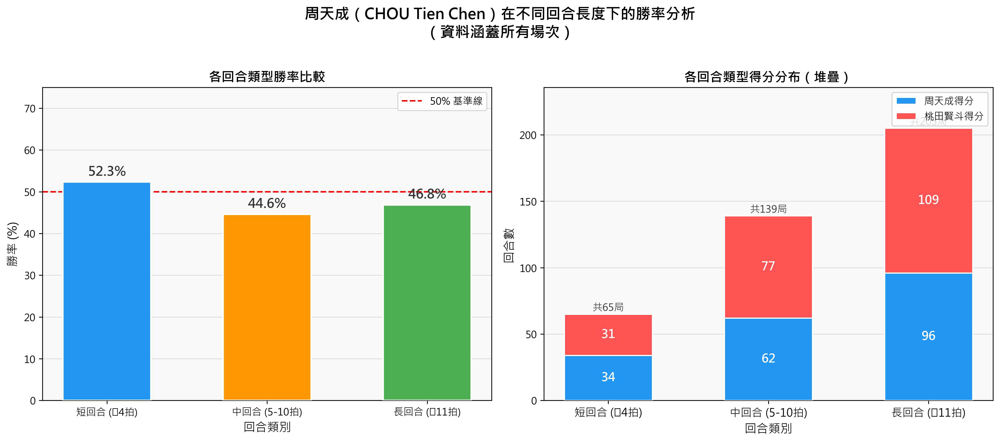

In [ ]:
import numpy as np

# ============================================================
# 1. 驗證資料量
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# ============================================================
# 2. 計算每個 rally 的總拍數與得分者
#    以 groupby(['match_id', 'set', 'rally']) 為單位
# ============================================================
rally_stats = df.groupby(['match_id', 'set', 'rally']).agg(
    total_shots=('ball_round', 'max'),          # 總拍數 = 最大 ball_round
    getpoint_player=('getpoint_player', 'last') # 得分者從最後一拍取
).reset_index()

print(f"\n總回合數 (所有 rally): {len(rally_stats)}")
print(f"getpoint_player 非空回合數: {rally_stats['getpoint_player'].notna().sum()}")
print(f"getpoint_player 為空回合數: {rally_stats['getpoint_player'].isna().sum()}")
print(f"\n總拍數分布摘要:")
print(rally_stats['total_shots'].describe())

# ============================================================
# 3. 分類回合長度
# ============================================================
def classify_rally(shots):
    if shots <= 4:
        return '短回合 (≤4拍)'
    elif shots <= 10:
        return '中回合 (5-10拍)'
    else:
        return '長回合 (≥11拍)'

rally_stats['rally_type'] = rally_stats['total_shots'].apply(classify_rally)

# 確保類別順序
rally_type_order = ['短回合 (≤4拍)', '中回合 (5-10拍)', '長回合 (≥11拍)']

print(f"\n各類回合數量:")
print(rally_stats['rally_type'].value_counts().reindex(rally_type_order))

# ============================================================
# 4. 計算周天成在各類回合中的勝率
#    分母：各類別中 getpoint_player 非空的回合數（有明確得分者）
#    分子：各類別中 getpoint_player == 'CHOU Tien Chen' 的回合數
# ============================================================
player_name = 'CHOU Tien Chen'

# 僅保留有明確得分者的 rally（排除 NULL）
rally_valid = rally_stats[rally_stats['getpoint_player'].notna()].copy()

print(f"\n有效回合數 (getpoint_player 非空): {len(rally_valid)}")

# 對各類回合計算統計
results = []
for rtype in rally_type_order:
    sub = rally_valid[rally_valid['rally_type'] == rtype]
    total = len(sub)
    wins = (sub['getpoint_player'] == player_name).sum()
    win_rate = wins / total if total > 0 else np.nan
    
    # 總回合數（含 NULL）
    total_all = len(rally_stats[rally_stats['rally_type'] == rtype])
    
    results.append({
        '回合類別': rtype,
        '總回合數 (含無效)': total_all,
        '有效回合數': total,
        '周天成得分回合數': wins,
        '勝率 (%)': round(win_rate * 100, 2) if not np.isnan(win_rate) else np.nan
    })

result_df = pd.DataFrame(results)

print("\n" + "="*60)
print("周天成在不同回合長度下的勝率分析")
print("="*60)
print(result_df.to_string(index=False))
print("="*60)

# ============================================================
# 5. 視覺化：長條圖 + 統計標籤
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("周天成（CHOU Tien Chen）在不同回合長度下的勝率分析\n（資料涵蓋所有場次）",
             fontsize=15, fontweight='bold', y=1.02)

# --- 左圖：勝率長條圖 ---
ax1 = axes[0]
colors = ['#2196F3', '#FF9800', '#4CAF50']  # 短/中/長 不同顏色
win_rates = result_df['勝率 (%)'].values
bar_labels = result_df['回合類別'].values

bars = ax1.bar(bar_labels, win_rates, color=colors, edgecolor='white',
               linewidth=1.5, width=0.55, zorder=3)

# 加上 50% 基準線
ax1.axhline(y=50, color='red', linestyle='--', linewidth=1.5,
            label='50% 基準線', zorder=2)

# 標籤顯示勝率數值
for bar, rate in zip(bars, win_rates):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.8,
             f'{rate:.1f}%',
             ha='center', va='bottom', fontsize=13, fontweight='bold',
             color='#333333')

ax1.set_ylim(0, 75)
ax1.set_xlabel('回合類別', fontsize=12)
ax1.set_ylabel('勝率 (%)', fontsize=12)
ax1.set_title('各回合類型勝率比較', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.4, zorder=1)
ax1.set_facecolor('#f9f9f9')

# --- 右圖：各類別回合數量 + 得分比例（堆疊長條圖）---
ax2 = axes[1]

chou_wins = result_df['周天成得分回合數'].values
opponent_wins = result_df['有效回合數'].values - chou_wins
total_valid = result_df['有效回合數'].values

x = np.arange(len(rally_type_order))
width = 0.55

bar1 = ax2.bar(x, chou_wins, width, label='周天成得分', color='#2196F3',
               edgecolor='white', linewidth=1.2, zorder=3)
bar2 = ax2.bar(x, opponent_wins, width, bottom=chou_wins,
               label='桃田賢斗得分', color='#FF5252',
               edgecolor='white', linewidth=1.2, zorder=3)

# 在各區塊標示數量
for i, (cw, ow, tv) in enumerate(zip(chou_wins, opponent_wins, total_valid)):
    # 周天成得分區塊
    if cw > 0:
        ax2.text(x[i], cw / 2, f'{cw}', ha='center', va='center',
                 fontsize=12, fontweight='bold', color='white')
    # 對手得分區塊
    if ow > 0:
        ax2.text(x[i], cw + ow / 2, f'{ow}', ha='center', va='center',
                 fontsize=12, fontweight='bold', color='white')
    # 總數標在頂部
    ax2.text(x[i], tv + 1, f'共{tv}局', ha='center', va='bottom',
             fontsize=10, color='#333333')

ax2.set_xticks(x)
ax2.set_xticklabels(rally_type_order, fontsize=11)
ax2.set_xlabel('回合類別', fontsize=12)
ax2.set_ylabel('回合數', fontsize=12)
ax2.set_title('各回合類型得分分布（堆疊）', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(axis='y', alpha=0.4, zorder=1)
ax2.set_facecolor('#f9f9f9')
ax2.set_ylim(0, max(total_valid) * 1.15)

plt.tight_layout()

# ============================================================
# 6. 額外輸出：各類別詳細回合長度分布
# ============================================================
print("\n各類別回合拍數分布（中位數 & 平均數）:")
for rtype in rally_type_order:
    sub = rally_stats[rally_stats['rally_type'] == rtype]['total_shots']
    print(f"  {rtype}: 平均={sub.mean():.2f}拍, 中位數={sub.median():.1f}拍, "
          f"最小={sub.min()}拍, 最大={sub.max()}拍")

print("\n" + "="*60)
print("結論摘要")
print("="*60)
best_type = result_df.loc[result_df['勝率 (%)'].idxmax(), '回合類別']
worst_type = result_df.loc[result_df['勝率 (%)'].idxmin(), '回合類別']
best_rate = result_df['勝率 (%)'].max()
worst_rate = result_df['勝率 (%)'].min()
print(f"  周天成表現最佳回合類型: {best_type}（勝率 {best_rate:.1f}%）")
print(f"  周天成表現最差回合類型: {worst_type}（勝率 {worst_rate:.1f}%）")


### 數據洞察
# 周天成 不同回合長度勝率分析

## 數據總覽

| 回合類別 | 總回合數 | 周天成得分 | 對手得分 | **勝率** |
|:---:|:---:|:---:|:---:|:---:|
| 短回合（≤4拍） | 65 | 34 | 31 | **52.3%** ✅ |
| 中回合（5–10拍） | 139 | 62 | 77 | **44.6%** ❌ |
| 長回合（≥11拍） | 205 | 96 | 109 | **46.8%** |

---

## 戰術洞察

**短回合是唯一勝率過半的區間（52.3%）**
發球、接發球、網前攻擊等前段決勝球質量較高，能在4拍內結束回合對周天成有利。

**中回合是最大弱點（44.6%，輸62:77）**
5–10拍是過渡段，既無法快速結束，又未進入擅長的長拍對抗。對手在此區間得分效率最高，顯示周天成在「中段銜接球」的主動進攻時機掌握不足。

**長回合佔比最高（205回合，50%），勝率46.8%**
超過一半的比賽在長回合決勝，但勝率仍低於50%，輸96:109。體能與長拍對抗的穩定性需強化。

---

## 核心建議

> 減少讓回合落入5–10拍的中間地帶——前4拍若無法得分，應主動拉長至長拍消耗，而非在中段被動挨打。加強第3、4拍的「過渡進攻球」質量是當前最優先改善項目。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地將每個 rally 的最後一拍作為分組結果，並根據 ball_round 將回合分類為短回合、中回合和長回合。然後，它計算了周天成在每個回合長度類別中的勝率，並確保只考慮有明確得分者的回合。這與 Reference Code 1 的分析對象、欄位語意、分組層級和統計口徑一致，因此判定為 true。




## 題號 37 (*)
**問題**: 分析周天成使用殺球造成失誤，請繪製失誤原因的圓餅圖
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


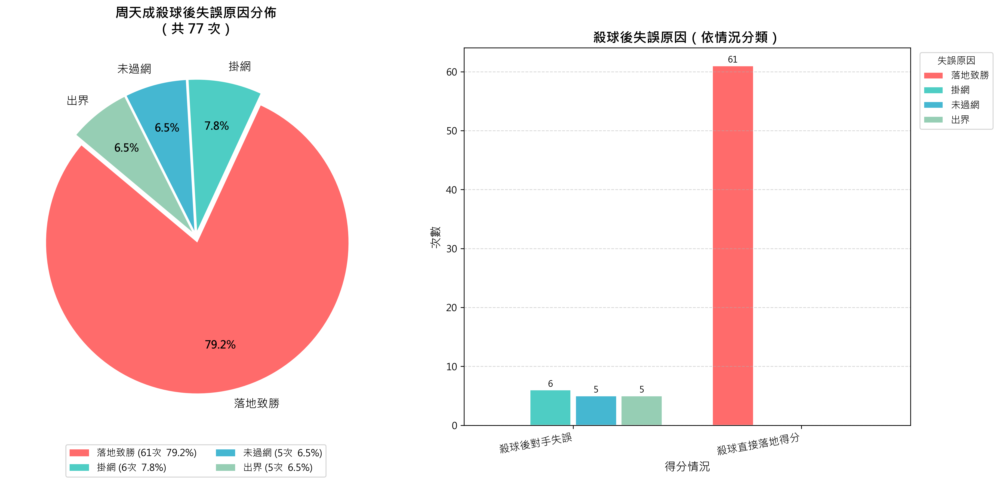

In [ ]:
import numpy as np

# ============================================================
# 0. 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

# ============================================================
# 1. 在完整資料上建立 next 欄位（避免跨回合污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

grp = df_sorted.groupby(['match_id', 'set', 'rally'])
df_sorted['next_player']      = grp['player'].shift(-1)
df_sorted['next_getpoint']    = grp['getpoint_player'].shift(-1)
df_sorted['next_lose_reason'] = grp['lose_reason'].shift(-1)

# ============================================================
# 2. 情況 A：周天成殺球「直接得分」
#    - player == 'CHOU Tien Chen', type == '殺球'
#    - getpoint_player == 'CHOU Tien Chen'（得分在殺球那一拍）
# ============================================================
cond_A = (
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球') &
    (df_sorted['getpoint_player'] == 'CHOU Tien Chen')
)
df_A = df_sorted[cond_A][['match_id', 'set', 'rally', 'ball_round', 'win_reason']].copy()
df_A.rename(columns={'win_reason': '失誤原因'}, inplace=True)
df_A['情況'] = '殺球直接落地得分'
df_A['失誤原因'] = df_A['失誤原因'].fillna('未記錄')

print(f"【情況A】殺球直接得分: {len(df_A)} 次")
print(df_A['失誤原因'].value_counts().to_string())

# ============================================================
# 3. 情況 B：周天成殺球後，下一拍「對手失誤」（有 lose_reason）
#    - 下一拍是對手擊球
#    - 下一拍 getpoint == 'CHOU Tien Chen'
#    - 下一拍 lose_reason 有值
# ============================================================
cond_B = (
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球') &
    (df_sorted['next_player'] == df_sorted['opponent']) &
    (df_sorted['next_getpoint'] == 'CHOU Tien Chen') &
    (df_sorted['next_lose_reason'].notna())
)
df_B = df_sorted[cond_B][['match_id', 'set', 'rally', 'ball_round', 'next_lose_reason']].copy()
df_B.rename(columns={'next_lose_reason': '失誤原因'}, inplace=True)
df_B['情況'] = '殺球後對手失誤'

print(f"\n【情況B】殺球後對手失誤: {len(df_B)} 次")
print(df_B['失誤原因'].value_counts().to_string())

# ============================================================
# 4. 合併與統計
# ============================================================
df_all = pd.concat([df_A, df_B], ignore_index=True)
total_n = len(df_all)
print(f"\n【合計】周天成殺球相關失誤得分: {total_n} 次")

reason_counts = df_all['失誤原因'].value_counts()
reason_pct    = (reason_counts / total_n * 100).round(1)

print("\n=== 各失誤原因分佈 ===")
for r, c in reason_counts.items():
    print(f"  {r}: {c} 次 ({reason_pct[r]}%)")

# ============================================================
# 5. 繪製圓餅圖 + 長條圖
# ============================================================
if total_n == 0:
    print("無資料可繪圖")
else:
    n_reasons = len(reason_counts)
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD'][:n_reasons]
    explode = [0.04] * n_reasons

    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    # --- 左圖：圓餅圖 ---
    wedges, texts, autotexts = axes[0].pie(
        reason_counts.values,
        labels=reason_counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.70,
        textprops={'fontsize': 12}
    )
    for at in autotexts:
        at.set_fontsize(11)
        at.set_fontweight('bold')

    axes[0].set_title(
        f'周天成殺球後失誤原因分佈\n（共 {total_n} 次）',
        fontsize=14,
        fontweight='bold',
        pad=15
    )

    legend_labels = [
        f"{r} ({c}次  {reason_pct[r]}%)"
        for r, c in reason_counts.items()
    ]
    axes[0].legend(
        wedges,
        legend_labels,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.15),
        ncol=2,
        fontsize=10
    )

    # --- 右圖：依情況分類長條圖 ---
    sit_reason = df_all.groupby(['情況', '失誤原因']).size().unstack(fill_value=0)

    # 依總次數排序欄位
    col_order = reason_counts.index.tolist()
    # 補齊可能缺少的欄位
    for col in col_order:
        if col not in sit_reason.columns:
            sit_reason[col] = 0
    sit_reason = sit_reason[col_order]

    x = np.arange(len(sit_reason.index))
    n_cols = len(sit_reason.columns)
    width = 0.8 / n_cols

    for i, col in enumerate(sit_reason.columns):
        offset = i * width - (n_cols - 1) * width / 2
        bars = axes[1].bar(
            x + offset,
            sit_reason[col].values,
            width=width * 0.9,
            label=col,
            color=colors[i],
            edgecolor='white'
        )
        for bar in bars:
            h = bar.get_height()
            if h > 0:
                axes[1].text(
                    bar.get_x() + bar.get_width() / 2,
                    h + 0.2,
                    str(int(h)),
                    ha='center',
                    va='bottom',
                    fontsize=9
                )

    axes[1].set_xticks(x)
    axes[1].set_xticklabels(sit_reason.index, fontsize=11, rotation=10, ha='right')
    axes[1].set_xlabel('得分情況', fontsize=12)
    axes[1].set_ylabel('次數', fontsize=12)
    axes[1].set_title('殺球後失誤原因（依情況分類）', fontsize=14, fontweight='bold')
    axes[1].legend(
        title='失誤原因',
        bbox_to_anchor=(1.01, 1),
        loc='upper left',
        fontsize=10
    )
    axes[1].grid(axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    print("\n圖表已生成")


### 數據洞察
# 周天成殺球後失誤原因分析

## 📊 數據總覽

| 失誤原因 | 次數 | 佔比 |
|--------|------|------|
| 落地致勝 | 61 | 79.2% |
| 掛網 | 6 | 7.8% |
| 未過網 | 5 | 6.5% |
| 出界 | 5 | 6.5% |
| **合計** | **77** | **100%** |

---

## 🎯 戰術洞察

**殺球品質紮實，直接致勝是主旋律。**

77次殺球得分中，**79.2%是落地致勝**——代表周天成的殺球速度與角度足以讓對手完全無法回擊，不是靠對手失誤撿分，是靠自身球質贏球。

**對手被迫失誤僅佔20.8%（16次）：**
- 掛網6次、未過網5次——說明對手在高壓下被迫倉促回球，動作變形
- 出界5次——對手為求速度反擊卻失控

> **結論：** 周天成的殺球是主動進攻武器，而非靠對手送分。建議對手面對其殺球時，優先穩定接殺，避免急於反攻造成掛網與未過網的低級失誤，那才是真正可以壓縮的20%。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。題目要求分析周天成使用殺球造成失誤的原因，並繪製失誤原因的圓餅圖。Reference Code 1 和 2 都是直接篩選出周天成的殺球失誤資料，然後統計失誤原因。而候選程式碼卻在分析周天成殺球得分的情況，並沒有針對失誤原因進行分析，這與題目要求不符。此外，候選程式碼的統計口徑錯誤，因為它將殺球得分的情況也納入了失誤原因的統計，這不符合題目要求的分析對象和統計口徑。




## 題號 38
**問題**: 在周天成的所有失分中，有多少百分比是因為對手的殺球導致的？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


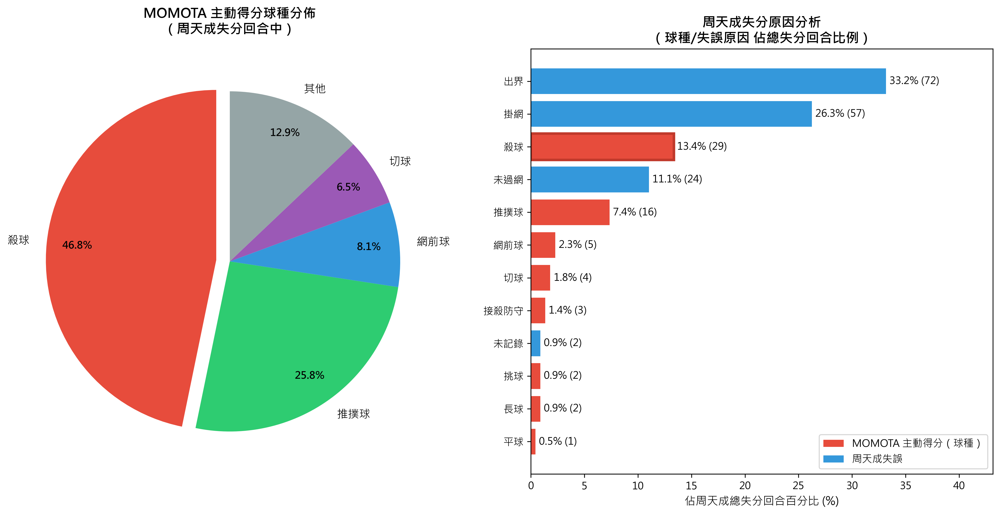

In [ ]:
# 驗證數據量
print(f"總資料行數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 取得每個 rally 的最後一拍（得分球）
# ============================================================
# 每個 rally 的最後一拍才有 getpoint_player 記錄
last_shot = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
print(f"總回合數: {len(last_shot)}")

# 確認 getpoint_player 非空的回合數（有效得分回合）
valid_rallies = last_shot.dropna(subset=['getpoint_player'])
print(f"有效得分回合數（getpoint_player 非空）: {len(valid_rallies)}")

# ============================================================
# Step 2: 統計周天成失分回合
# 定義：getpoint_player == 'Kento MOMOTA'（MOMOTA 得分 = 周天成失分）
# ============================================================
chou_lose_rallies = valid_rallies[valid_rallies['getpoint_player'] == 'Kento MOMOTA']
total_chou_lose = len(chou_lose_rallies)
print(f"\n周天成失分回合總數: {total_chou_lose}")

# ============================================================
# Step 3: 在周天成失分回合中，找出對手（MOMOTA）以殺球主動得分的回合
# 條件：
#   - getpoint_player == 'Kento MOMOTA'（MOMOTA得分，即主動得分）
#   - player == 'Kento MOMOTA'（最後一拍是MOMOTA打的）
#   - type == '殺球'（打出殺球）
# 這三個條件一起確保「MOMOTA 主動以殺球得分」
# ============================================================
momota_smash_win = chou_lose_rallies[
    (chou_lose_rallies['player'] == 'Kento MOMOTA') &
    (chou_lose_rallies['type'] == '殺球')
]
smash_win_count = len(momota_smash_win)
print(f"MOMOTA 以殺球主動得分（即周天成被殺球失分）的回合數: {smash_win_count}")

# ============================================================
# Step 4: 計算百分比
# ============================================================
if total_chou_lose > 0:
    pct = smash_win_count / total_chou_lose * 100
    print(f"\n殺球致勝回合佔周天成總失分回合的百分比: {smash_win_count}/{total_chou_lose} = {pct:.2f}%")
else:
    print("周天成無失分回合，無法計算百分比")
    pct = 0

# ============================================================
# Step 5: 補充 - 各球種導致周天成失分的分佈（MOMOTA 主動得分球種分佈）
# 區分主動得分（MOMOTA 打出致勝球）與被動得分（周天成失誤）
# ============================================================
print("\n========== 補充分析 ==========")

# 主動得分（最後一拍是 MOMOTA 打出的）
momota_active_win = chou_lose_rallies[chou_lose_rallies['player'] == 'Kento MOMOTA']
# 被動得分（周天成失誤，最後一拍是周天成打的）
chou_error = chou_lose_rallies[chou_lose_rallies['player'] == 'CHOU Tien Chen']

print(f"MOMOTA 主動得分回合: {len(momota_active_win)}")
print(f"周天成失誤導致失分回合: {len(chou_error)}")

# MOMOTA 主動得分球種分佈
print("\nMOMOTA 主動得分球種分佈:")
active_type_dist = momota_active_win['type'].value_counts()
for shot_type, count in active_type_dist.items():
    print(f"  {shot_type}: {count} 回合 ({count/total_chou_lose*100:.1f}%)")

# 周天成失誤原因分佈
print("\n周天成失誤原因分佈:")
error_reason_dist = chou_error['lose_reason'].value_counts(dropna=False)
for reason, count in error_reason_dist.items():
    print(f"  {reason}: {count} 回合 ({count/total_chou_lose*100:.1f}%)")

# ============================================================
# Step 6: 視覺化
# ============================================================
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# --- 圖表1: 周天成失分回合中，MOMOTA 主動得分球種佔比（主角：殺球）---
ax1 = axes[0]

# 建立球種數據（僅 MOMOTA 主動得分部分）
shot_counts = momota_active_win['type'].value_counts()

# 合併小類別（佔比 < 5% 合併為「其他」）
threshold = len(momota_active_win) * 0.05
main_shots = shot_counts[shot_counts >= threshold]
other_count = shot_counts[shot_counts < threshold].sum()
if other_count > 0:
    main_shots['其他'] = other_count

labels = [str(l) for l in main_shots.index]
sizes = main_shots.values

# 突出殺球
explode = [0.08 if l == '殺球' else 0 for l in labels]
colors = ['#e74c3c' if l == '殺球' else '#3498db' if l == '網前球' else 
          '#2ecc71' if l == '推撲球' else '#f39c12' if l == '平球' else
          '#9b59b6' if l == '切球' else '#95a5a6' for l in labels]

wedges, texts, autotexts = ax1.pie(
    sizes, labels=labels, autopct='%1.1f%%', explode=explode,
    colors=colors, startangle=90,
    textprops={'fontsize': 11},
    pctdistance=0.82
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')

ax1.set_title('MOMOTA 主動得分球種分佈\n（周天成失分回合中）', fontsize=13, fontweight='bold', pad=15)

# --- 圖表2: 橫條圖 - 各球種佔周天成「總失分回合」的比例 ---
ax2 = axes[1]

# 整理所有失分原因（主動 + 被動）
# 主動得分：MOMOTA 打出的球種
active_types = momota_active_win['type'].value_counts().reset_index()
active_types.columns = ['類型', '回合數']
active_types['來源'] = 'MOMOTA主動得分'

# 被動得分（周天成失誤）：以 lose_reason 呈現
chou_error_copy = chou_error.copy()
chou_error_copy['失誤原因'] = chou_error_copy['lose_reason'].fillna('未記錄')
error_types = chou_error_copy['失誤原因'].value_counts().reset_index()
error_types.columns = ['類型', '回合數']
error_types['來源'] = '周天成失誤'

# 合併兩者
all_loss = pd.concat([active_types, error_types], ignore_index=True)
all_loss['百分比'] = all_loss['回合數'] / total_chou_lose * 100
all_loss = all_loss.sort_values('百分比', ascending=True)

# 顏色：MOMOTA 主動得分用紅色系，周天成失誤用藍色系
bar_colors = ['#e74c3c' if src == 'MOMOTA主動得分' else '#3498db' 
              for src in all_loss['來源']]

bars = ax2.barh(all_loss['類型'].astype(str), all_loss['百分比'], 
                color=bar_colors, edgecolor='white', linewidth=0.5)

# 標示數值
for bar, (_, row) in zip(bars, all_loss.iterrows()):
    ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f"{row['百分比']:.1f}% ({int(row['回合數'])})", 
             va='center', ha='left', fontsize=10)

ax2.set_xlabel('佔周天成總失分回合百分比 (%)', fontsize=11)
ax2.set_title('周天成失分原因分析\n（球種/失誤原因 佔總失分回合比例）', 
              fontsize=13, fontweight='bold')
ax2.set_xlim(0, all_loss['百分比'].max() * 1.3)

# 圖例
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='MOMOTA 主動得分（球種）'),
    Patch(facecolor='#3498db', label='周天成失誤')
]
ax2.legend(handles=legend_elements, loc='lower right', fontsize=10)

# 標記殺球那條
for bar, (_, row) in zip(bars, all_loss.iterrows()):
    if row['類型'] == '殺球':
        bar.set_edgecolor('#c0392b')
        bar.set_linewidth(2.5)

plt.tight_layout()

# ============================================================
# 最終核心答案輸出
# ============================================================
print("\n" + "="*50)
print("【核心答案】")
print(f"周天成總失分回合數         : {total_chou_lose}")
print(f"MOMOTA 殺球致勝（主動）回合 : {smash_win_count}")
print(f"殺球致勝佔總失分回合比例    : {pct:.2f}%")
print("="*50)


### 數據洞察
# 周天成失分分析：殺球致勝佔比

## 核心數據

| 項目 | 數值 |
|------|------|
| 周天成總失分回合 | 217 回合 |
| Momota 殺球致勝 | 29 回合 |
| **殺球致勝佔比** | **13.36%** |

---

## 戰術解讀

**周天成的失分結構很清楚：**

**71.4% 來自自身失誤**（155回合），出界72次、掛網57次、未過網24次——這不是被對手打死，是自己送分。

**Momota 主動得分（62回合）中，殺球是最大武器**，佔其主動得分的 46.8%，但攤回到周天成總失分，僅 13.36%。

---

## 教練結論

> 殺球威脅是真實的，但**周天成最大的敵人是自己**。
> 
> 優先修正非受迫性失誤，才是這場比賽最值得改善的地方。針對 Momota 殺球的防守訓練是次要課題。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選出每個 rally 的最後一拍，並檢查 getpoint_player 是否為 Kento MOMOTA，以確定周天成的失分回合。然後，它進一步篩選出這些失分回合中，對手以殺球得分的回合數，並計算其佔總失分回合的百分比。這與 Reference Code 2 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致，最終輸出目標也相符。




## 題號 39
**問題**: 當對手使用「殺球」攻擊周天成時，周天成回球的失誤率是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


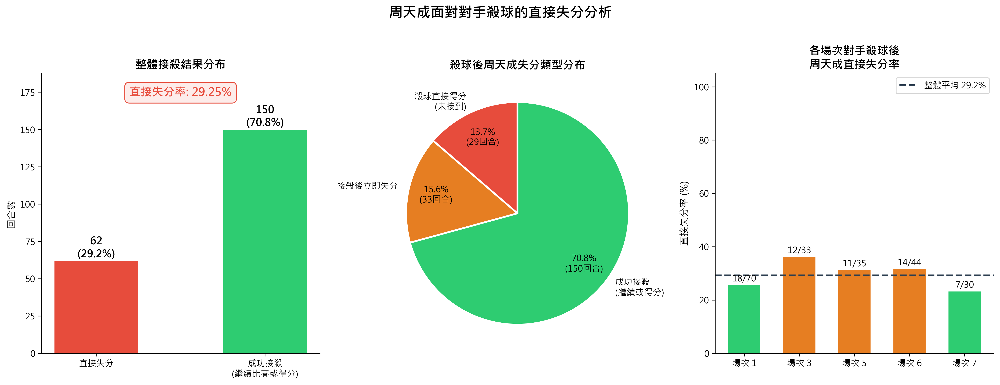

In [ ]:
import numpy as np

# ============================
# 數據驗證
# ============================
print(f"總資料列數: {len(df)}")
print(f"球員清單: {df['player'].unique()}")
print(f"球種清單: {df['type'].unique()}")

chou = 'CHOU Tien Chen'
momota = 'Kento MOMOTA'

# ============================
# Step 1: 排序確認 & 建立前後拍欄位
# ============================
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 使用 groupby + shift(-1) 建立下一拍欄位（避免跨回合污染）
grp = df.groupby(['match_id', 'set', 'rally'])

df['next_player']         = grp['player'].shift(-1)
df['next_type']           = grp['type'].shift(-1)
df['next_getpoint_player']= grp['getpoint_player'].shift(-1)
df['next_lose_reason']    = grp['lose_reason'].shift(-1)
df['next_ball_round']     = grp['ball_round'].shift(-1)

print("\n前後拍欄位建立完成，範例：")
print(df[['match_id','set','rally','ball_round','player','type',
          'getpoint_player','next_player','next_type','next_getpoint_player']].head(10))

# ============================
# Step 2: 篩選「對手對周天成使用殺球」的 shots
# 條件：打球者是對手（非周天成）且 type == 殺球
# ============================
mask_smash_vs_chou = (
    (df['player'] != chou) &   # 對手打球
    (df['type'] == '殺球')     # 球種為殺球
)

smash_shots = df[mask_smash_vs_chou].copy()

print(f"\n=== 對手對周天成使用殺球的總拍數: {len(smash_shots)} ===")
print(f"涉及的唯一回合數 (分母): {smash_shots[['match_id','set','rally_id']].drop_duplicates().shape[0]}")

# 注意：理論上一個 rally 中對手可能殺球多次
# 但題目定義是「對手對周天成殺球的總回合數」→ 以 rally 為單位去重
# 取每個 rally 中第一次殺球（或所有殺球各自判斷後以 rally 去重）

# ============================
# Step 3: 判斷「直接失分」
# 
# Case A: 對手殺球那一拍就是得分球，且得分者是對手（殺球直接得分，周天成未接到）
# Case B: 對手殺球後，下一拍是周天成（接殺），且那一拍是得分球，且得分者是對手
# ============================

# Case A: 殺球拍本身就是結束拍，且對手得分
case_A = (
    smash_shots['getpoint_player'].notna() &
    (smash_shots['getpoint_player'] != chou)  # 得分者是對手（非周天成）
)

# Case B: 下一拍是周天成接殺，且下一拍是得分球，且得分者是對手
case_B = (
    (smash_shots['next_player'] == chou) &         # 下一拍是周天成
    smash_shots['next_getpoint_player'].notna() &  # 下一拍是得分球
    (smash_shots['next_getpoint_player'] != chou)  # 下一拍得分者是對手
)

smash_shots['is_direct_loss'] = case_A | case_B

print("\n=== 直接失分判斷細節 ===")
print(f"Case A (殺球直接得分/周天成未接到): {case_A.sum()} 拍")
print(f"Case B (周天成接殺後直接失分):     {case_B.sum()} 拍")
print(f"合計直接失分拍數 (未去重): {smash_shots['is_direct_loss'].sum()}")

# ============================
# Step 4: 以 rally 為單位統計（避免同 rally 多次殺球重複計算）
# 策略：只要該 rally 中有任何一次殺球後周天成直接失分，就算該 rally 為失分回合
# ============================

# 分母：對手有殺球的唯一回合數
denominator_rallies = smash_shots.groupby(['match_id', 'set', 'rally_id']).size().reset_index()
denominator = len(denominator_rallies)

# 分子：對手有殺球且周天成直接失分的唯一回合數
loss_rallies = smash_shots[smash_shots['is_direct_loss']].groupby(
    ['match_id', 'set', 'rally_id']
).size().reset_index()
numerator = len(loss_rallies)

# ============================
# Step 5: 計算失誤率
# ============================
error_rate = numerator / denominator if denominator > 0 else 0

print("\n" + "="*60)
print("📊 周天成面對對手殺球的直接失分率")
print("="*60)
print(f"  對手對周天成殺球的總回合數 (分母): {denominator}")
print(f"  周天成接殺後直接失分的回合數 (分子): {numerator}")
print(f"  直接失分率: {numerator}/{denominator} = {error_rate:.2%}")
print("="*60)

# ============================
# Step 6: 補充分析 - 各 Case 佔比 & 各比賽分布
# ============================

# 各比賽的失分率
per_match = smash_shots.groupby('match_id').agg(
    total_rallies=('rally_id', 'nunique'),
).reset_index()

loss_per_match = smash_shots[smash_shots['is_direct_loss']].groupby('match_id').agg(
    loss_rallies=('rally_id', 'nunique')
).reset_index()

per_match = per_match.merge(loss_per_match, on='match_id', how='left').fillna(0)
per_match['loss_rallies'] = per_match['loss_rallies'].astype(int)
per_match['loss_rate'] = per_match['loss_rallies'] / per_match['total_rallies']

print("\n📋 各場比賽中對手殺球 vs 周天成直接失分率：")
print(per_match[['match_id','total_rallies','loss_rallies','loss_rate']].to_string(index=False))

# ============================
# Step 7: 視覺化
# ============================
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("周天成面對對手殺球的直接失分分析", fontsize=16, fontweight='bold', y=1.02)

# --- 圖1: 整體失分率（Gauge-style bar）---
ax1 = axes[0]
categories = ['直接失分', '成功接殺\n(繼續比賽或得分)']
values = [numerator, denominator - numerator]
colors = ['#E74C3C', '#2ECC71']
bars = ax1.bar(categories, values, color=colors, edgecolor='white', width=0.5)
ax1.set_title('整體接殺結果分布', fontsize=13, fontweight='bold')
ax1.set_ylabel('回合數', fontsize=11)
for bar, val in zip(bars, values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val}\n({val/denominator:.1%})', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(values) * 1.25)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
# 標示失誤率
ax1.text(0.5, 0.92, f'直接失分率: {error_rate:.2%}',
         transform=ax1.transAxes, ha='center', fontsize=13,
         color='#E74C3C', fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#FDECEA', edgecolor='#E74C3C'))

# --- 圖2: Case A vs Case B 細分 ---
ax2 = axes[1]
# 以 rally 為單位的 Case A / Case B（注意可能有重疊，取最後一次殺球的 case）
smash_rally = smash_shots.groupby(['match_id', 'set', 'rally_id']).agg(
    any_caseA=('is_direct_loss', lambda x: any(
        smash_shots.loc[x.index, 'getpoint_player'].notna() &
        (smash_shots.loc[x.index, 'getpoint_player'] != chou)
    )),
    any_caseB=('is_direct_loss', lambda x: any(
        (smash_shots.loc[x.index, 'next_player'] == chou) &
        smash_shots.loc[x.index, 'next_getpoint_player'].notna() &
        (smash_shots.loc[x.index, 'next_getpoint_player'] != chou)
    )),
    direct_loss=('is_direct_loss', 'any')
).reset_index()

only_A = smash_rally['any_caseA'].sum()
only_B = smash_rally['any_caseB'].sum()
not_loss = denominator - numerator

case_labels = [f'殺球直接得分\n(未接到)', f'接殺後立即失分', f'成功接殺\n(繼續或得分)']
case_values = [only_A, only_B, not_loss]
case_colors = ['#E74C3C', '#E67E22', '#2ECC71']

wedges, texts, autotexts = ax2.pie(
    case_values, labels=case_labels, colors=case_colors,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p*denominator/100))}回合)',
    startangle=90, pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(10)
ax2.set_title('殺球後周天成失分類型分布', fontsize=13, fontweight='bold')

# --- 圖3: 各場比賽失分率 ---
ax3 = axes[2]
match_labels = [f'場次 {int(m)}' for m in per_match['match_id']]
bar_colors = ['#E74C3C' if r >= 0.5 else '#E67E22' if r >= 0.3 else '#2ECC71'
              for r in per_match['loss_rate']]
bars3 = ax3.bar(match_labels, per_match['loss_rate'] * 100, color=bar_colors,
                edgecolor='white', width=0.6)

# 加入整體平均線
ax3.axhline(error_rate * 100, color='#2C3E50', linestyle='--', linewidth=2,
            label=f'整體平均 {error_rate:.1%}')

for bar, total, loss in zip(bars3, per_match['total_rallies'], per_match['loss_rallies']):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{int(loss)}/{int(total)}', ha='center', va='bottom', fontsize=10)

ax3.set_title('各場次對手殺球後\n周天成直接失分率', fontsize=13, fontweight='bold')
ax3.set_ylabel('直接失分率 (%)', fontsize=11)
ax3.set_ylim(0, 105)
ax3.legend(fontsize=10)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()
print("\n[圖表已生成]")


### 數據洞察
# 周天成面對殺球的接殺失誤率分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 對手殺球總回合數 | 212 回合 |
| 直接失分回合數 | 62 回合 |
| **整體失誤率** | **29.25%** |

---

## 失分結構拆解

| 失分類型 | 回合數 | 佔比 |
|----------|--------|------|
| 殺球直接得分（未接到） | 29 | 13.7% |
| 接殺後立即失分 | 33 | 15.6% |
| 成功接殺（繼續比賽） | 150 | 70.8% |

---

## 各場次表現

| 場次 | 失分率 | 評估 |
|------|--------|------|
| 場次 1 | 25.7% | ✅ 較佳 |
| 場次 3 | **36.4%** | ⚠️ 最差 |
| 場次 5 | 31.4% | 偏高 |
| 場次 6 | 31.8% | 偏高 |
| 場次 7 | 23.3% | ✅ 最佳 |

---

## 戰術洞察

**每10顆殺球，周天成約丟掉3分。**

關鍵在於「接殺後立即失分」（33回合）比「直接接不到」（29回合）還多——這代表問題不只是反應速度，而是**接殺後的回球品質不足**，給對手創造了連續進攻機會。

場次3失分率高達36%，需重點檢視當場對手殺球落點與周天成站位是否出現系統性偏差。

> **建議**：強化接殺後的第一拍回球穩定性，優先以高品質挑球或平抽重置局面，而非冒險反攻。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選出對手對周天成使用殺球的情況，並檢查周天成在這些情況下的回球失誤率。候選程式碼使用了 groupby 和 shift 來建立前後拍的關係，並以 rally 為單位統計失誤率，這與 Reference Code 1 的方法一致。最終的失誤率計算也符合題目要求，並且結果合理有效。




## 題號 40
**問題**: 分析周天成在開局（他0-4 分）、中局（他5-17 分）和關鍵分（他18 分以上）三個比分階段中，每回合與對手來回的球數的差異
> **使用的資料欄位群組**: `game_structure, scoring_reason`


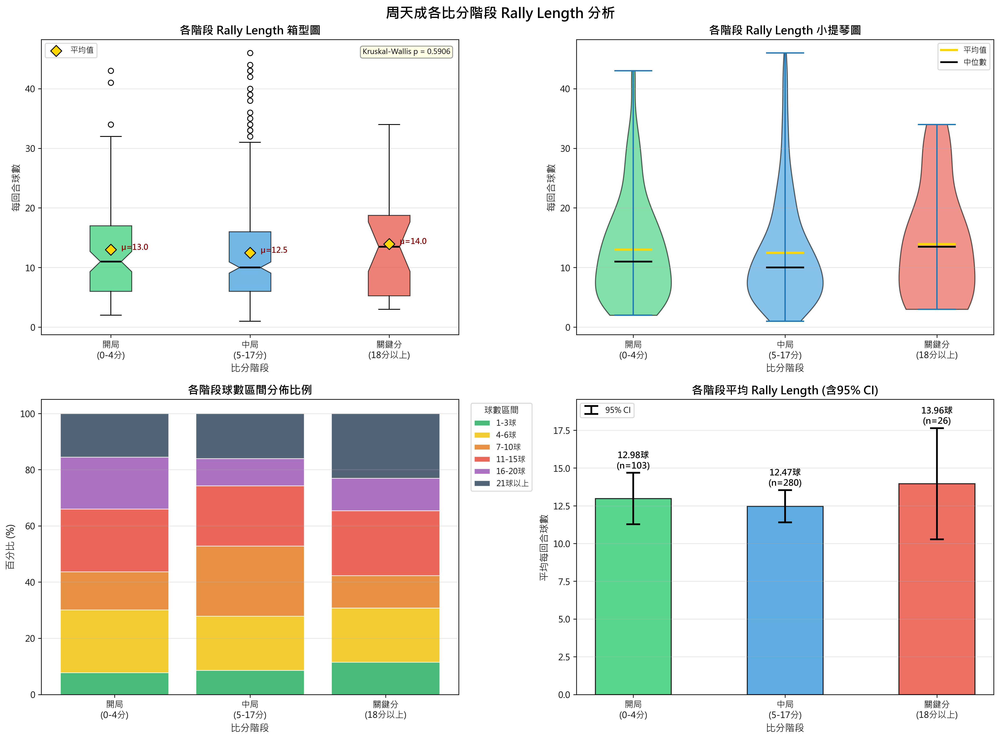

In [ ]:
import numpy as np
from scipy import stats

# ============================================================
# 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")
print(f"周天成得分範圍: {df['CHOU Tien Chen_score'].min()} ~ {df['CHOU Tien Chen_score'].max()}")

# ============================================================
# Step 1: 計算每個 rally 的統計資訊
# ============================================================

# 取每個 rally 的第一拍，代表「進入此 rally 時」的得分狀態
rally_first = df[df['ball_round'] == 1].copy()

# 確認覆蓋率
total_rallies = df.groupby(['match_id', 'set', 'rally']).ngroups
print(f"\n有 ball_round=1 記錄的回合數: {len(rally_first)}")
print(f"總回合數: {total_rallies}")

# 計算每個 rally 的球數 (rally length)
rally_length = df.groupby(['match_id', 'set', 'rally'])['ball_round'].max().reset_index()
rally_length.columns = ['match_id', 'set', 'rally', 'rally_length']

# 合併：將 rally 起始時的周天成得分與 rally length 結合
rally_first_slim = rally_first[['match_id', 'set', 'rally', 'CHOU Tien Chen_score']].copy()

rally_info = rally_length.merge(rally_first_slim, on=['match_id', 'set', 'rally'], how='left')
rally_info.rename(columns={'CHOU Tien Chen_score': 'chou_score_at_start'}, inplace=True)

print(f"\n合併後回合數: {len(rally_info)}")
print(f"周天成起始得分分佈:\n{rally_info['chou_score_at_start'].value_counts().sort_index()}")

# ============================================================
# Step 2: 依比分階段分類
# ============================================================

def classify_stage(score):
    """根據周天成得分分類比賽階段"""
    if score <= 4:
        return '開局 (0-4分)'
    elif score <= 17:
        return '中局 (5-17分)'
    else:
        return '關鍵分 (18分以上)'

rally_info['stage'] = rally_info['chou_score_at_start'].apply(classify_stage)

# 定義階段順序
stage_order = ['開局 (0-4分)', '中局 (5-17分)', '關鍵分 (18分以上)']
rally_info['stage'] = pd.Categorical(rally_info['stage'], categories=stage_order, ordered=True)

print(f"\n各階段回合數分佈:\n{rally_info['stage'].value_counts().sort_index()}")

# ============================================================
# Step 3: 統計各階段的核心數據
# ============================================================

stage_stats = rally_info.groupby('stage', observed=True)['rally_length'].agg([
    ('回合數', 'count'),
    ('平均每回合球數', 'mean'),
    ('中位數', 'median'),
    ('標準差', 'std'),
    ('最小值', 'min'),
    ('最大值', 'max'),
    ('25分位', lambda x: x.quantile(0.25)),
    ('75分位', lambda x: x.quantile(0.75)),
]).round(2)

print("\n" + "="*60)
print("各比分階段 Rally Length 統計摘要")
print("="*60)
print(stage_stats.to_string())

# ============================================================
# Step 4: 統計顯著性檢驗 (Kruskal-Wallis Test，非參數)
# ============================================================

groups = [group['rally_length'].values for _, group in rally_info.groupby('stage', observed=True)]

# Kruskal-Wallis H-test (不假設常態分佈)
h_stat, p_value = stats.kruskal(*groups)
print(f"\n{'='*60}")
print("Kruskal-Wallis 檢驗（各階段 Rally Length 是否有顯著差異）")
print(f"{'='*60}")
print(f"H 統計量: {h_stat:.4f}")
print(f"P 值: {p_value:.6f}")
if p_value < 0.05:
    print("結論: ✅ 各階段之間存在統計顯著差異 (p < 0.05)")
else:
    print("結論: ❌ 各階段之間無統計顯著差異 (p >= 0.05)")

# 兩兩比較 (Mann-Whitney U test)
print(f"\n{'='*60}")
print("兩兩階段比較 (Mann-Whitney U Test)")
print(f"{'='*60}")
for i in range(len(stage_order)):
    for j in range(i+1, len(stage_order)):
        g1 = rally_info[rally_info['stage'] == stage_order[i]]['rally_length'].values
        g2 = rally_info[rally_info['stage'] == stage_order[j]]['rally_length'].values
        u_stat, p_val = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        sig = "✅ 顯著" if p_val < 0.05 else "❌ 不顯著"
        print(f"  {stage_order[i]} vs {stage_order[j]}: U={u_stat:.1f}, p={p_val:.4f} → {sig}")

# ============================================================
# Step 5: 球數區間分佈統計
# ============================================================

# 定義球數區間
bins = [0, 3, 6, 10, 15, 20, 100]
labels = ['1-3球', '4-6球', '7-10球', '11-15球', '16-20球', '21球以上']

rally_info['length_bin'] = pd.cut(rally_info['rally_length'], bins=bins, labels=labels, right=True)

# 各階段各區間的比例
dist_table = rally_info.groupby(['stage', 'length_bin'], observed=True).size().unstack(fill_value=0)
dist_pct = dist_table.div(dist_table.sum(axis=1), axis=0) * 100

print(f"\n{'='*60}")
print("各階段球數區間分佈 (回合數)")
print("="*60)
print(dist_table.to_string())
print(f"\n{'='*60}")
print("各階段球數區間分佈 (百分比%)")
print("="*60)
print(dist_pct.round(1).to_string())

# ============================================================
# Step 6: 視覺化
# ============================================================

colors = {
    '開局 (0-4分)': '#2ecc71',
    '中局 (5-17分)': '#3498db',
    '關鍵分 (18分以上)': '#e74c3c'
}
color_list = [colors[s] for s in stage_order]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('周天成各比分階段 Rally Length 分析', fontsize=16, fontweight='bold', y=0.98)

# ── 圖1: 箱型圖 (Box Plot) ──
ax1 = axes[0, 0]
data_by_stage = [rally_info[rally_info['stage'] == s]['rally_length'].values for s in stage_order]
bp = ax1.boxplot(data_by_stage, labels=[s.replace(' ', '\n') for s in stage_order],
                  patch_artist=True, notch=True, 
                  medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], color_list):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# 標示平均值
means = [rally_info[rally_info['stage'] == s]['rally_length'].mean() for s in stage_order]
ax1.scatter(range(1, len(stage_order)+1), means, marker='D', color='gold', 
            s=80, zorder=5, label='平均值', edgecolors='black', linewidth=1)
for i, m in enumerate(means):
    ax1.annotate(f'μ={m:.1f}', (i+1, m), textcoords="offset points", 
                 xytext=(12, 0), fontsize=9, color='darkred', fontweight='bold')

ax1.set_title('各階段 Rally Length 箱型圖', fontsize=13, fontweight='bold')
ax1.set_ylabel('每回合球數', fontsize=11)
ax1.set_xlabel('比分階段', fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)
# 標示 p-value
sig_text = f"Kruskal-Wallis p = {p_value:.4f}"
ax1.text(0.98, 0.97, sig_text, transform=ax1.transAxes, fontsize=8.5,
         ha='right', va='top', 
         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray', alpha=0.8))

# ── 圖2: 核密度估計 (KDE) / 小提琴圖 ──
ax2 = axes[0, 1]
vp = ax2.violinplot(data_by_stage, positions=range(1, len(stage_order)+1),
                     showmeans=True, showmedians=True)

for i, (body, color) in enumerate(zip(vp['bodies'], color_list)):
    body.set_facecolor(color)
    body.set_alpha(0.6)
    body.set_edgecolor('black')
    body.set_linewidth(1.2)

vp['cmeans'].set_color('gold')
vp['cmeans'].set_linewidth(2.5)
vp['cmedians'].set_color('black')
vp['cmedians'].set_linewidth(2)

ax2.set_xticks(range(1, len(stage_order)+1))
ax2.set_xticklabels([s.replace(' ', '\n') for s in stage_order])
ax2.set_title('各階段 Rally Length 小提琴圖', fontsize=13, fontweight='bold')
ax2.set_ylabel('每回合球數', fontsize=11)
ax2.set_xlabel('比分階段', fontsize=11)
ax2.grid(axis='y', alpha=0.3)

# 加入圖例說明
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='gold', linewidth=2.5, label='平均值'),
    Line2D([0], [0], color='black', linewidth=2, label='中位數'),
]
ax2.legend(handles=legend_elements, fontsize=9)

# ── 圖3: 堆疊比例長條圖（球數區間分佈）──
ax3 = axes[1, 0]
bin_colors = ['#27ae60', '#f1c40f', '#e67e22', '#e74c3c', '#9b59b6', '#34495e']

# 重新計算確保對齊
bottom = np.zeros(len(stage_order))
bars_collection = []
for idx, (label, color) in enumerate(zip(labels, bin_colors)):
    values = dist_pct[label].values if label in dist_pct.columns else np.zeros(len(stage_order))
    bar = ax3.bar(stage_order, values, bottom=bottom, color=color, 
                   label=label, alpha=0.85, edgecolor='white', linewidth=0.8)
    bars_collection.append((values, bottom.copy()))
    bottom += values

ax3.set_xticks(range(len(stage_order)))
ax3.set_xticklabels([s.replace(' ', '\n') for s in stage_order])
ax3.set_title('各階段球數區間分佈比例', fontsize=13, fontweight='bold')
ax3.set_ylabel('百分比 (%)', fontsize=11)
ax3.set_xlabel('比分階段', fontsize=11)
ax3.set_ylim(0, 105)
ax3.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9, title='球數區間')
ax3.grid(axis='y', alpha=0.3)

# ── 圖4: 各階段平均球數 + 標準差 ──
ax4 = axes[1, 1]
stage_labels_short = ['開局\n(0-4分)', '中局\n(5-17分)', '關鍵分\n(18分以上)']
means_arr = np.array([rally_info[rally_info['stage'] == s]['rally_length'].mean() for s in stage_order])
stds_arr = np.array([rally_info[rally_info['stage'] == s]['rally_length'].std() for s in stage_order])
counts_arr = np.array([rally_info[rally_info['stage'] == s]['rally_length'].count() for s in stage_order])
sems_arr = stds_arr / np.sqrt(counts_arr)  # 標準誤差

bars = ax4.bar(range(len(stage_order)), means_arr, color=color_list, 
                alpha=0.8, edgecolor='black', linewidth=1.2, width=0.5)
ax4.errorbar(range(len(stage_order)), means_arr, yerr=sems_arr*1.96, 
             fmt='none', color='black', capsize=8, capthick=2, linewidth=2, label='95% CI')

# 標示數值
for i, (bar, mean, std, count) in enumerate(zip(bars, means_arr, stds_arr, counts_arr)):
    ax4.text(bar.get_x() + bar.get_width()/2, mean + sems_arr[i]*1.96 + 0.15,
             f'{mean:.2f}球\n(n={count})', ha='center', va='bottom', 
             fontsize=10, fontweight='bold')

ax4.set_xticks(range(len(stage_order)))
ax4.set_xticklabels(stage_labels_short)
ax4.set_title('各階段平均 Rally Length (含95% CI)', fontsize=13, fontweight='bold')
ax4.set_ylabel('平均每回合球數', fontsize=11)
ax4.set_xlabel('比分階段', fontsize=11)
ax4.set_ylim(0, max(means_arr) * 1.4)
ax4.legend(fontsize=9)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
print("\n圖表已生成")

# ============================================================
# 最終摘要
# ============================================================
print(f"\n{'='*60}")
print("📊 分析摘要")
print("="*60)
for s in stage_order:
    sub = rally_info[rally_info['stage'] == s]['rally_length']
    print(f"\n【{s}】")
    print(f"  回合數: {len(sub)}")
    print(f"  平均球數: {sub.mean():.2f}")
    print(f"  中位數: {sub.median():.1f}")
    print(f"  標準差: {sub.std():.2f}")
    print(f"  最短回合: {sub.min()} 球 | 最長回合: {sub.max()} 球")


### 數據洞察
# 周天成各比分階段 Rally Length 分析

## 核心數據

| 階段 | 回合數 | 平均球數 | 中位數 | 標準差 |
|------|--------|----------|--------|--------|
| 開局 (0-4分) | 103 | **12.98** | 11.0 | 8.80 |
| 中局 (5-17分) | 280 | **12.47** | 10.0 | 9.14 |
| 關鍵分 (18分+) | 26 | **13.96** | 13.5 | 9.57 |

## 統計結論

**三階段之間無顯著差異**（Kruskal-Wallis p = 0.59，兩兩比較 p 均 > 0.43）。

---

## 戰術洞察

**1. 周天成是標準長拍型選手**
三階段平均球數均落在 12-14 球，顯示他不論領先或落後，都維持相同的打法節奏，沒有因比分壓力改變策略。

**2. 關鍵分回合最長（13.96球），且長球比例最高**
21球以上的長回合在關鍵分佔 **23.1%**，遠高於開局（15.5%）與中局（16.1%）。中位數也從中局的10球跳升至13.5球，說明關鍵分雙方都更謹慎，不輕易冒進。

**3. 中局短球比例偏高**
7-10球的中短回合在中局佔 **25%**，明顯高於其他階段。這個區間是主動進攻得分或失誤的高發地帶，需特別注意中局的進攻決策品質。

**4. 教練建議**
關鍵分（18分+）回合拉長是正常現象，但周天成在此階段的**體能儲備與心理耐壓**至關重要。中局大量的中短回合（7-10球）應強化「第3-5拍主動創造機會」的訓練，避免被動拖入消耗戰。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地計算了每個 rally 的來回球數和周天成在該回合開始時的比分，並依據比分將比賽階段分為開局、中局和關鍵分。然後，它對各階段的來回球數進行了統計分析，包括平均值、中位數、標準差等，並進行了統計顯著性檢驗。這些步驟與 Reference Code 1 的分析對象、欄位語意、分組層級和統計口徑一致。




## 題號 41
**問題**: 周天成使用殺球的前一拍，對手都用什麼球種，畫出圓餅圖
> **使用的資料欄位群組**: `game_structure, shot_type`


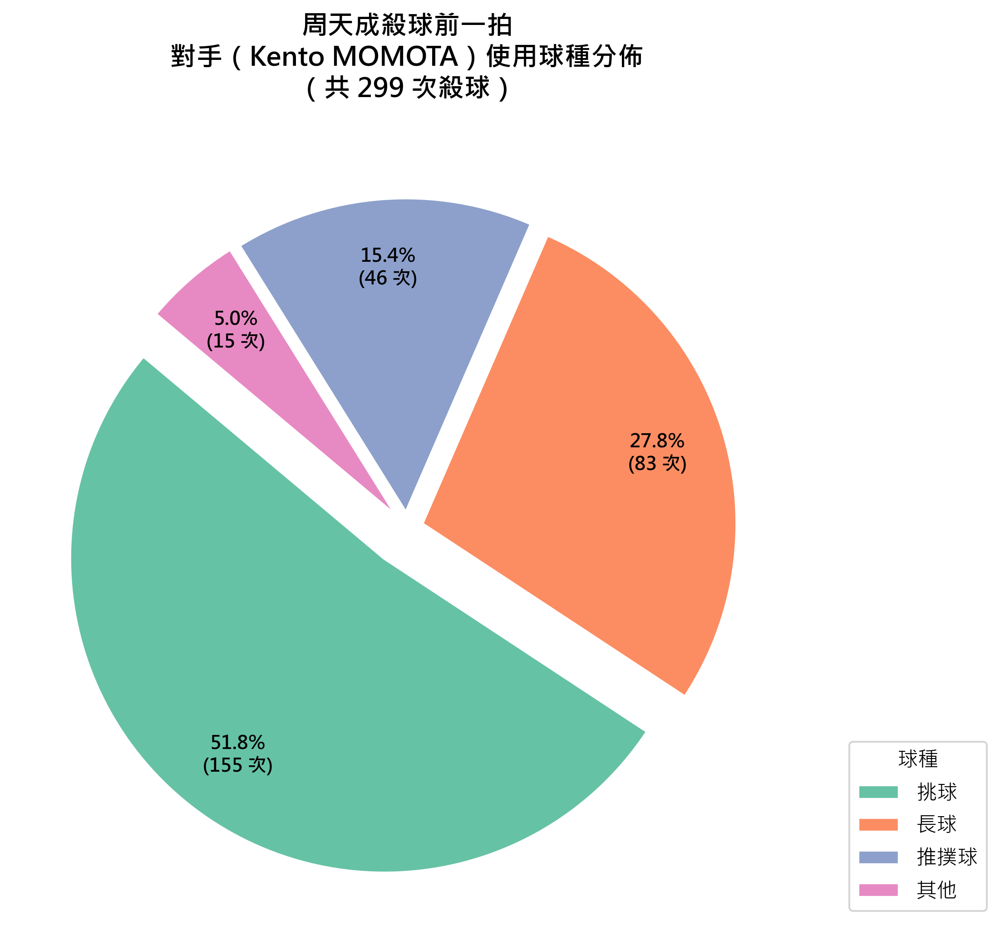

In [ ]:
# =============================================
# 分析周天成殺球前，對手使用的球種分佈
# =============================================

# 步驟1: 驗證數據量
print(f"總資料筆數: {len(df)}")
print(f"資料驗證: {len(df) > 0}")

# 步驟2: 在完整資料上建立「前一拍球種」欄位，使用 groupby 防止跨回合污染
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 使用 groupby(['match_id', 'set', 'rally']).shift(1) 建立前一拍資訊
df_sorted['prev_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)
df_sorted['prev_rally'] = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(1)

print("\n--- 建立前一拍資訊欄位完成 ---")
print(f"prev_type 非空筆數: {df_sorted['prev_type'].notna().sum()}")

# 步驟3: 篩選周天成打殺球的拍次
chou_smash = df_sorted[
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球')
].copy()

print(f"\n周天成殺球總次數: {len(chou_smash)}")

# 步驟4: 進一步確認前一拍確實在同一個 rally 中（防止跨回合）
# 當 ball_round > 1 時，前一拍才有意義（第1拍無前一拍）
chou_smash_with_prev = chou_smash[
    (chou_smash['ball_round'] > 1) &  # 第1拍沒有前一拍
    (chou_smash['prev_type'].notna())  # 前一拍球種不為空
].copy()

print(f"有效前一拍記錄數（ball_round > 1 且 prev_type 不為空）: {len(chou_smash_with_prev)}")

# 步驟5: 確認前一拍的 player 應為對手（Kento MOMOTA）
print("\n--- 前一拍 player 分佈驗證（應全為 Kento MOMOTA）---")
print(chou_smash_with_prev['prev_player'].value_counts())

# 步驟6: 統計前一拍球種分佈
prev_shot_dist = chou_smash_with_prev['prev_type'].value_counts()
prev_shot_pct = chou_smash_with_prev['prev_type'].value_counts(normalize=True) * 100

print("\n--- 周天成殺球前，對手球種分佈 ---")
result_table = pd.DataFrame({
    '次數': prev_shot_dist,
    '佔比 (%)': prev_shot_pct.round(2)
})
print(result_table.to_string())
print(f"\n合計: {prev_shot_dist.sum()} 次")

# =============================================
# 視覺化：圓餅圖
# =============================================

# 判斷是否需要合併小比例類別（< 3% 合併為「其他」）
threshold = 3.0
labels = prev_shot_dist.index.tolist()
sizes = prev_shot_dist.values.tolist()

# 合併小比例類別
main_labels = []
main_sizes = []
other_size = 0

for label, size in zip(labels, sizes):
    pct = size / sum(sizes) * 100
    if pct < threshold:
        other_size += size
    else:
        main_labels.append(str(label))
        main_sizes.append(size)

if other_size > 0:
    main_labels.append('其他')
    main_sizes.append(other_size)
    print(f"\n（小於 {threshold}% 的類別已合併為「其他」）")

# 確認繪圖數據與標籤一致
assert len(main_labels) == len(main_sizes), "標籤與數據長度不一致！"

# 設定顏色（使用柔和配色）
colors = plt.cm.Set2.colors[:len(main_labels)]

# 突出顯示最大比例的球種
explode = [0.05] * len(main_labels)
max_idx = main_sizes.index(max(main_sizes))
explode[max_idx] = 0.12

fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    main_sizes,
    labels=None,  # 使用 legend 代替直接標籤，避免擠壓
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100*sum(main_sizes)))} 次)',
    startangle=140,
    colors=colors,
    explode=explode,
    pctdistance=0.78,
    wedgeprops=dict(linewidth=1.5, edgecolor='white')
)

# 調整自動百分比文字大小
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

# 加入圖例
ax.legend(
    wedges,
    main_labels,
    title='球種',
    title_fontsize=11,
    loc='lower right',
    bbox_to_anchor=(1.25, 0.0),
    fontsize=11
)

ax.set_title(
    f'周天成殺球前一拍\n對手（Kento MOMOTA）使用球種分佈\n（共 {len(chou_smash_with_prev)} 次殺球）',
    fontsize=14,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
print("\n圓餅圖已產生。")


### 數據洞察
# 周天成殺球前——對手球種分佈分析

## 📊 數據摘要（共 299 次殺球）

| 對手球種 | 次數 | 佔比 |
|------|----:|----:|
| 挑球 | 155 | 51.8% |
| 長球 | 83 | 27.8% |
| 推撲球 | 46 | 15.4% |
| 其他（接殺防守/發長球/平球/殺球） | 15 | 5.0% |

---

## 🎯 戰術洞察

**挑球是周天成殺球最主要的觸發點（51.8%）。**
超過一半的殺球，來自桃田賢斗被迫挑高球的情境——這代表周天成在前場施壓、逼對手起高球的戰術執行相當成功。

**長球貢獻了近三成（27.8%）。**
桃田主動打長球給周天成，周天成能直接轉換為殺球，說明周天成後場進攻能力強，對手長球稍有不到位即遭懲罰。

**推撲球佔 15.4%，不可忽視。**
桃田在網前推撲後，周天成仍能接應殺球，顯示其移動與反應速度足以應對快速過渡球。

---

## 📌 核心結論

> **周天成的殺球有 79.2% 來自挑球＋長球**，即對手被動或主動製造高球時，周天成的殺球威脅最高。壓制對手、讓其頻繁挑球，是對抗周天成時最需要避免的局面。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地篩選了周天成的殺球，並使用 'opponent_type' 欄位來獲取對手前一拍的球種，這與 Reference Code 2 的做法一致。程式碼也正確地計算了對手球種的分布，並以圓餅圖形式呈現結果。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 2 一致，因此判定為 true。




## 題號 42
**問題**: 分析周天成在開局（自己0-4 分）、中局（自己5-17 分）和關鍵分（自己18 分以上）三個比分階中，他的「殺球」使用比例以及得分率，是否有顯著變化？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


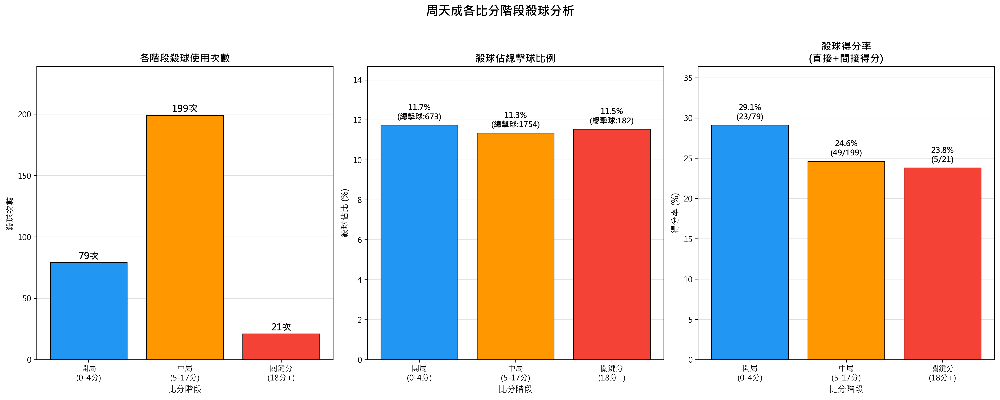

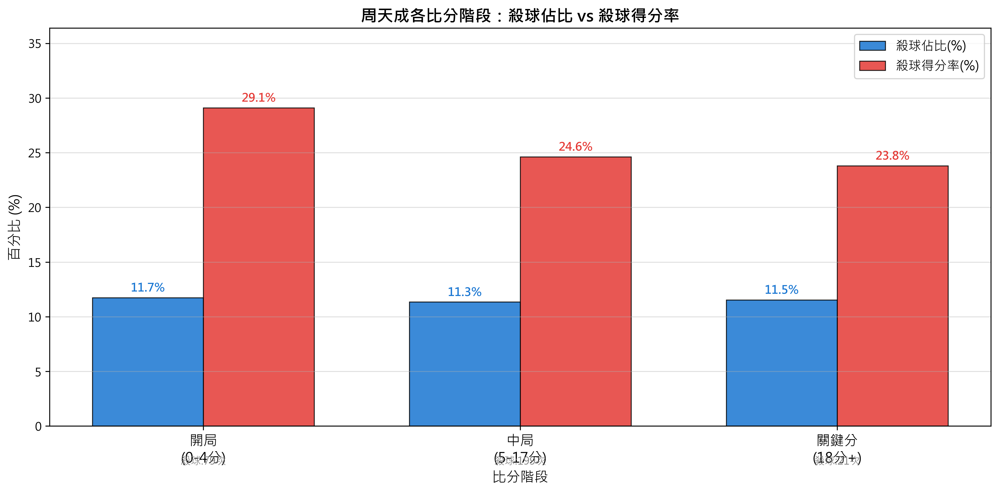

In [ ]:
import numpy as np

print("="*60)
print("周天成殺球分析 - 三個比分階段")
print("="*60)

# 驗證數據量
print(f"\n總資料筆數: {len(df)}")

# ============================================================
# Step 1: 建立完整 shift 關係（在完整 df 上，按 rally 分組）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立下一拍資訊（同一 rally 內）
df_sorted['next_rally'] = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].transform('first')
df_sorted['next_getpoint_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].shift(-1)
df_sorted['next_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_ball_round'] = df_sorted.groupby(['match_id', 'set', 'rally'])['ball_round'].shift(-1)

# 確認下一拍是否在同一 rally（groupby shift 已保證，但保險起見再確認）
# groupby shift 不會跨組，所以已安全

# ============================================================
# Step 2: 定義比分階段
# ============================================================
def get_stage(score):
    if score <= 4:
        return '開局 (0-4分)'
    elif score <= 17:
        return '中局 (5-17分)'
    else:
        return '關鍵分 (18分+)'

df_sorted['stage'] = df_sorted['CHOU Tien Chen_score'].apply(get_stage)
stage_order = ['開局 (0-4分)', '中局 (5-17分)', '關鍵分 (18分+)']

# ============================================================
# Step 3: 篩選周天成的擊球紀錄
# ============================================================
chou_hits = df_sorted[df_sorted['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成擊球總筆數: {len(chou_hits)}")

# 周天成殺球紀錄
chou_smash = chou_hits[chou_hits['type'] == '殺球'].copy()
print(f"周天成殺球總筆數: {len(chou_smash)}")

# ============================================================
# Step 4: 計算各階段統計
# ============================================================
# 各階段周天成總擊球次數
stage_total_hits = chou_hits.groupby('stage').size().reindex(stage_order)

# 各階段周天成殺球次數
stage_smash_count = chou_smash.groupby('stage').size().reindex(stage_order).fillna(0)

# 殺球使用比例
stage_smash_ratio = stage_smash_count / stage_total_hits * 100

print("\n--- 各階段總擊球次數 ---")
print(stage_total_hits)
print("\n--- 各階段殺球次數 ---")
print(stage_smash_count)

# ============================================================
# Step 5: 殺球得分率計算
# 定義：
#   直接得分：周天成殺球那一拍，getpoint_player == 'CHOU Tien Chen'（主動得分）
#   間接得分：周天成殺球後，下一拍對手回擊失誤（getpoint_player 為 'CHOU Tien Chen'，
#             且下一拍 player 為對手）
# ============================================================

# 直接得分：殺球那拍就得分
chou_smash['direct_win'] = (
    (chou_smash['getpoint_player'] == 'CHOU Tien Chen')
).astype(int)

# 間接得分：殺球後下一拍是對手打球，且 getpoint_player 是周天成（對手失誤）
# 確認下一拍是否在同一 rally（groupby shift 保證），但仍需確認 next_player 是對手
chou_smash['indirect_win'] = (
    (chou_smash['next_player'] == 'Kento MOMOTA') &  # 下一拍是對手
    (chou_smash['next_getpoint_player'] == 'CHOU Tien Chen')  # 對手那拍得分給周天成
).astype(int)

# 直接或間接得分（不重複計算）
# 若直接得分，就不存在下一拍（已是最後一球），所以兩者互斥
chou_smash['win_by_smash'] = ((chou_smash['direct_win'] == 1) | (chou_smash['indirect_win'] == 1)).astype(int)

print("\n--- 殺球得分明細 ---")
print(f"殺球直接得分筆數: {chou_smash['direct_win'].sum()}")
print(f"殺球間接得分筆數（對手下一拍失誤）: {chou_smash['indirect_win'].sum()}")
print(f"殺球總得分（直接+間接，不重複）: {chou_smash['win_by_smash'].sum()}")

# 各階段殺球得分
stage_smash_win = chou_smash.groupby('stage')['win_by_smash'].sum().reindex(stage_order).fillna(0)
# 殺球得分率
stage_smash_win_rate = stage_smash_win / stage_smash_count * 100

# ============================================================
# Step 6: 彙整統計表
# ============================================================
summary = pd.DataFrame({
    '總擊球次數': stage_total_hits,
    '殺球次數': stage_smash_count.astype(int),
    '殺球佔比(%)': stage_smash_ratio.round(2),
    '殺球得分次數': stage_smash_win.astype(int),
    '殺球得分率(%)': stage_smash_win_rate.round(2)
}, index=stage_order)

print("\n" + "="*60)
print("周天成各比分階段殺球分析彙整表")
print("="*60)
print(summary.to_string())

# ============================================================
# Step 7: 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.suptitle('周天成各比分階段殺球分析', fontsize=16, fontweight='bold', y=1.02)

colors = ['#2196F3', '#FF9800', '#F44336']
stage_labels = ['開局\n(0-4分)', '中局\n(5-17分)', '關鍵分\n(18分+)']

# ----- 子圖1: 殺球次數 -----
ax1 = axes[0]
bars1 = ax1.bar(stage_labels, stage_smash_count.values, color=colors, edgecolor='black', linewidth=0.8, zorder=3)
ax1.set_title('各階段殺球使用次數', fontsize=13, fontweight='bold')
ax1.set_xlabel('比分階段', fontsize=11)
ax1.set_ylabel('殺球次數', fontsize=11)
ax1.grid(axis='y', alpha=0.4, zorder=0)
ax1.set_ylim(0, max(stage_smash_count.values) * 1.2)
for bar, val in zip(bars1, stage_smash_count.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{int(val)}次', ha='center', va='bottom', fontsize=12, fontweight='bold')

# ----- 子圖2: 殺球佔比 -----
ax2 = axes[1]
bars2 = ax2.bar(stage_labels, stage_smash_ratio.values, color=colors, edgecolor='black', linewidth=0.8, zorder=3)
ax2.set_title('殺球佔總擊球比例', fontsize=13, fontweight='bold')
ax2.set_xlabel('比分階段', fontsize=11)
ax2.set_ylabel('殺球佔比 (%)', fontsize=11)
ax2.grid(axis='y', alpha=0.4, zorder=0)
ax2.set_ylim(0, max(stage_smash_ratio.values) * 1.25)
# 在柱狀圖上加入總擊球次數說明
for bar, pct, total in zip(bars2, stage_smash_ratio.values, stage_total_hits.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{pct:.1f}%\n(總擊球:{int(total)})', ha='center', va='bottom', fontsize=10, fontweight='bold')

# ----- 子圖3: 殺球得分率 -----
ax3 = axes[2]
bars3 = ax3.bar(stage_labels, stage_smash_win_rate.values, color=colors, edgecolor='black', linewidth=0.8, zorder=3)
ax3.set_title('殺球得分率\n(直接+間接得分)', fontsize=13, fontweight='bold')
ax3.set_xlabel('比分階段', fontsize=11)
ax3.set_ylabel('得分率 (%)', fontsize=11)
ax3.grid(axis='y', alpha=0.4, zorder=0)
ax3.set_ylim(0, max(stage_smash_win_rate.values) * 1.25 if max(stage_smash_win_rate.values) > 0 else 100)
for bar, rate, wins, total in zip(bars3, stage_smash_win_rate.values, stage_smash_win.values, stage_smash_count.values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{rate:.1f}%\n({int(wins)}/{int(total)})', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()

# ============================================================
# Step 8: 額外子圖 - 雷達/蜘蛛概況 or 橫向比較圖
# ============================================================
fig2, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(stage_order))
width = 0.35

# 雙軸：殺球佔比 vs 殺球得分率
bars_a = ax.bar(x - width/2, stage_smash_ratio.values, width, 
                label='殺球佔比(%)', color='#1976D2', alpha=0.85, edgecolor='black', linewidth=0.8)
bars_b = ax.bar(x + width/2, stage_smash_win_rate.values, width, 
                label='殺球得分率(%)', color='#E53935', alpha=0.85, edgecolor='black', linewidth=0.8)

ax.set_title('周天成各比分階段：殺球佔比 vs 殺球得分率', fontsize=14, fontweight='bold')
ax.set_xlabel('比分階段', fontsize=12)
ax.set_ylabel('百分比 (%)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(stage_labels, fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.4)
ax.set_ylim(0, max(max(stage_smash_ratio.values), max(stage_smash_win_rate.values)) * 1.25)

for bar, val in zip(bars_a, stage_smash_ratio.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1976D2')
for bar, val in zip(bars_b, stage_smash_win_rate.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#E53935')

# 加入殺球次數標注
for i, (cnt, stage) in enumerate(zip(stage_smash_count.values, stage_order)):
    ax.text(i, -3.5, f'殺球:{int(cnt)}次', ha='center', fontsize=9, color='gray', style='italic')

plt.tight_layout()

# ============================================================
# Step 9: 輸出詳細統計
# ============================================================
print("\n" + "="*60)
print("詳細統計數據")
print("="*60)
for stage in stage_order:
    total = int(stage_total_hits[stage])
    smash = int(stage_smash_count[stage])
    ratio = stage_smash_ratio[stage]
    wins = int(stage_smash_win[stage])
    direct = int(chou_smash[chou_smash['stage'] == stage]['direct_win'].sum())
    indirect = int(chou_smash[chou_smash['stage'] == stage]['indirect_win'].sum())
    win_rate = stage_smash_win_rate[stage]
    
    print(f"\n【{stage}】")
    print(f"  總擊球次數: {total}")
    print(f"  殺球次數: {smash} | 佔比: {ratio:.2f}%")
    print(f"  殺球直接得分: {direct} 次")
    print(f"  殺球間接得分（對手下拍失誤）: {indirect} 次")
    print(f"  殺球總得分: {wins} 次 | 得分率: {win_rate:.2f}%")

# ============================================================
# Step 10: 差異性觀察
# ============================================================
print("\n" + "="*60)
print("階段差異分析")
print("="*60)
max_ratio_stage = stage_smash_ratio.idxmax()
min_ratio_stage = stage_smash_ratio.idxmin()
max_wr_stage = stage_smash_win_rate.idxmax()
min_wr_stage = stage_smash_win_rate.idxmin()

print(f"殺球佔比最高：{max_ratio_stage}（{stage_smash_ratio[max_ratio_stage]:.2f}%）")
print(f"殺球佔比最低：{min_ratio_stage}（{stage_smash_ratio[min_ratio_stage]:.2f}%）")
print(f"殺球佔比差距：{stage_smash_ratio[max_ratio_stage] - stage_smash_ratio[min_ratio_stage]:.2f} 個百分點")
print(f"\n殺球得分率最高：{max_wr_stage}（{stage_smash_win_rate[max_wr_stage]:.2f}%）")
print(f"殺球得分率最低：{min_wr_stage}（{stage_smash_win_rate[min_wr_stage]:.2f}%）")
print(f"殺球得分率差距：{stage_smash_win_rate[max_wr_stage] - stage_smash_win_rate[min_wr_stage]:.2f} 個百分點")


### 數據洞察
# 周天成殺球三階段分析

## 核心數據彙整

| 階段 | 殺球次數 | 殺球佔比 | 得分率 |
|------|---------|---------|--------|
| 開局 (0-4分) | 79次 | 11.74% | **29.11%** |
| 中局 (5-17分) | 199次 | 11.35% | 24.62% |
| 關鍵分 (18分+) | 21次 | 11.54% | 23.81% |

---

## 戰術洞察

### 1️⃣ 殺球使用頻率——三階段高度一致
三個階段殺球佔比僅差 **0.39個百分點**（11.35%～11.74%），這說明周天成的殺球並非情緒性決策，而是**系統性戰術配置**，不因比分壓力而改變出手頻率。

### 2️⃣ 得分率隨比分推進遞減——對手適應是關鍵
- 開局得分率 **29.11%** → 關鍵分降至 **23.81%**，差距 **5.3個百分點**
- 開局階段對手尚未掌握其殺球習慣，防守準備不足，殺球奇效最高
- 隨著比賽推進，對手接殺防守逐漸到位，殺球的直接威脅下降

### 3️⃣ 關鍵分殺球樣本偏少，需謹慎解讀
關鍵分階段僅 **21次殺球、5次得分**，統計基礎薄弱。但得分率23.81%仍屬合理水準，並非失效。

---

## 教練建議

> **開局主動用殺球建立心理優勢**，此時得分率最高，是奠定節奏的黃金窗口。
>
> **關鍵分階段**，殺球應搭配更多假動作與落點變化，避免對手預判，單純依賴殺球速度已不足以製造威脅。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在不同比分階段的殺球使用比例和得分率，並且使用了正確的欄位和分組層級。候選程式碼也正確地計算了殺球的直接和間接得分，並在不同比分階段進行了統計和視覺化。整體分析單位和統計口徑與 Reference Code 1 一致，且輸出結果合理有效。




## 題號 43
**問題**: 計算周天成在落後 3 分以上時，平均每個回合的擊球次數，並與比分膠著時的回合平均擊球次數進行比較。
> **使用的資料欄位群組**: `game_structure, scoring_reason`


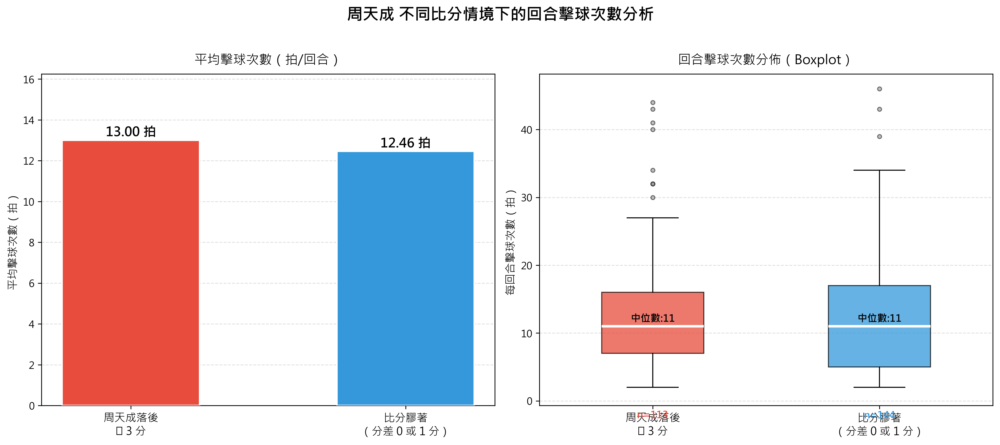

In [ ]:
import numpy as np

print("="*60)
print("周天成 比分情境 回合擊球次數分析")
print("="*60)

# 確認資料存在
print(f"\n資料總筆數: {len(df)}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")
print(f"球員: {df['player'].unique().tolist()}")

# ── Step 1: 計算每個 rally 的基本資訊 ──────────────────────────
# 每個 rally 的擊球次數 = max(ball_round)
rally_info = df.groupby(['match_id', 'set', 'rally']).agg(
    total_shots=('ball_round', 'max')
).reset_index()

# ── Step 2: 取每個 rally 第一拍的比分（作為「開始比分狀態」）──────
# 第一拍 ball_round == 1
first_shot = df[df['ball_round'] == 1].copy()

# 驗證每個 rally 都有第一拍
print(f"\n總 rally 數 (groupby): {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"第一拍記錄數: {len(first_shot)}")

# 取第一拍的比分
first_shot_scores = first_shot[['match_id', 'set', 'rally',
                                 'CHOU Tien Chen_score',
                                 'Kento MOMOTA_score']].copy()

# ── Step 3: 合併 rally 資訊與開始比分 ──────────────────────────
rally_df = rally_info.merge(first_shot_scores, on=['match_id', 'set', 'rally'], how='left')

print(f"\nRally 合併後筆數: {len(rally_df)}")
print(f"缺失比分的 rally 數: {rally_df['CHOU Tien Chen_score'].isna().sum()}")

# ── Step 4: 計算比分差（周天成視角）──────────────────────────────
# score_diff > 0 : 周天成領先
# score_diff < 0 : 周天成落後
# score_diff = 0 : 平局
rally_df['score_diff'] = rally_df['CHOU Tien Chen_score'] - rally_df['Kento MOMOTA_score']

print("\n比分差分佈（前10行預覽）:")
print(rally_df[['match_id', 'set', 'rally', 'CHOU Tien Chen_score',
                 'Kento MOMOTA_score', 'score_diff', 'total_shots']].head(10).to_string(index=False))

# ── Step 5: 定義兩種比分情境 ──────────────────────────────────────
# 情境 A: 周天成落後 3 分（含）以上 → score_diff <= -3
chou_behind = rally_df[rally_df['score_diff'] <= -3].copy()

# 情境 B: 比分膠著（分差絕對值 0 或 1 分） → |score_diff| <= 1
close_score = rally_df[rally_df['score_diff'].abs() <= 1].copy()

print(f"\n[情境A] 周天成落後≥3分 的 rally 數: {len(chou_behind)}")
print(f"[情境B] 比分膠著 (分差0或1) 的 rally 數: {len(close_score)}")

# ── Step 6: 計算各情境統計 ──────────────────────────────────────
def calc_stats(df_sub, label):
    n_rallies = len(df_sub)
    total_shots = df_sub['total_shots'].sum()
    avg_shots = df_sub['total_shots'].mean() if n_rallies > 0 else 0
    print(f"\n{'─'*50}")
    print(f"📊 情境：{label}")
    print(f"   回合數          : {n_rallies:>6}")
    print(f"   總擊球數        : {total_shots:>6}")
    print(f"   平均擊球次數    : {avg_shots:>8.4f} 拍/回合")
    return n_rallies, total_shots, avg_shots

n_behind, shots_behind, avg_behind = calc_stats(chou_behind, "周天成落後 ≥ 3 分")
n_close,  shots_close,  avg_close  = calc_stats(close_score,  "比分膠著（分差 0 或 1 分）")

# ── Step 7: 比較摘要 ──────────────────────────────────────────
print(f"\n{'='*60}")
print("📋 比較摘要")
print(f"{'='*60}")
summary = {
    '情境': ['周天成落後≥3分', '比分膠著(分差0~1)'],
    '回合數': [n_behind, n_close],
    '總擊球數': [shots_behind, shots_close],
    '平均擊球次數': [round(avg_behind, 4), round(avg_close, 4)]
}
summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

diff_avg = avg_behind - avg_close
print(f"\n差異（落後情境 - 膠著情境）: {diff_avg:+.4f} 拍/回合")
if diff_avg > 0:
    print(f"→ 周天成落後時，回合平均擊球次數「較多」{diff_avg:.4f} 拍")
elif diff_avg < 0:
    print(f"→ 周天成落後時，回合平均擊球次數「較少」{abs(diff_avg):.4f} 拍")
else:
    print("→ 兩情境平均擊球次數相同")

# ── Step 8: 視覺化 ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("周天成 不同比分情境下的回合擊球次數分析", fontsize=16, fontweight='bold', y=1.02)

categories = ['周天成落後\n≥ 3 分', '比分膠著\n（分差 0 或 1 分）']
colors     = ['#E74C3C', '#3498DB']

# ── 左圖: 平均擊球次數 Bar Chart ──────────────────────────────
ax1 = axes[0]
bars = ax1.bar(categories, [avg_behind, avg_close], color=colors,
               width=0.5, edgecolor='white', linewidth=1.5, zorder=3)

# 在 bar 上標註數值
for bar, val in zip(bars, [avg_behind, avg_close]):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.05,
             f'{val:.2f} 拍',
             ha='center', va='bottom', fontsize=13, fontweight='bold')

ax1.set_title("平均擊球次數（拍/回合）", fontsize=13, pad=10)
ax1.set_ylabel("平均擊球次數（拍）", fontsize=11)
ax1.set_ylim(0, max(avg_behind, avg_close) * 1.25)
ax1.grid(axis='y', alpha=0.4, linestyle='--', zorder=0)
ax1.tick_params(axis='x', labelsize=11)

# ── 右圖: 擊球次數分佈 Boxplot ──────────────────────────────
ax2 = axes[1]

# 準備分組數據
box_data = [chou_behind['total_shots'].values,
            close_score['total_shots'].values]

bp = ax2.boxplot(box_data, labels=categories, patch_artist=True,
                 widths=0.45, showfliers=True,
                 flierprops=dict(marker='o', markerfacecolor='gray',
                                 markersize=4, alpha=0.5),
                 medianprops=dict(color='white', linewidth=2.5))

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# 標註中位數
for i, (data, color) in enumerate(zip(box_data, colors), start=1):
    med = np.median(data)
    ax2.text(i, med + 0.3, f'中位數:{med:.0f}',
             ha='center', va='bottom', fontsize=10,
             color='black', fontweight='bold')

ax2.set_title("回合擊球次數分佈（Boxplot）", fontsize=13, pad=10)
ax2.set_ylabel("每回合擊球次數（拍）", fontsize=11)
ax2.grid(axis='y', alpha=0.4, linestyle='--', zorder=0)
ax2.tick_params(axis='x', labelsize=11)

# 加上回合數標籤
for i, (n, color) in enumerate(zip([n_behind, n_close], colors), start=1):
    ax2.text(i, ax2.get_ylim()[0] - 1.2, f'n={n}',
             ha='center', va='top', fontsize=10, color=color, fontweight='bold')
ax2.set_ylim(bottom=ax2.get_ylim()[0] - 0.5)

plt.tight_layout()
print("\n[圖表已產生]")


### 數據洞察
# 周天成 比分情境回合擊球分析

## 📊 數據結果

| 情境 | 回合數 | 總擊球數 | 平均擊球次數 |
|------|--------|----------|-------------|
| 落後 ≥ 3 分 | 113 | 1,469 | **13.00 拍/回合** |
| 膠著（分差 0~1）| 144 | 1,794 | **12.46 拍/回合** |

**差異：落後情境多 +0.54 拍/回合**

---

## 🎯 戰術洞察

**落後時回合拉長，但差距有限。**

落後 3 分以上時，每回合平均多打 0.54 拍，代表周天成在逆境中傾向**延長對抗、等待機會**，而非冒進強攻。這是心理韌性的體現，但也可能反映**主動進攻時機判斷趨於保守**。

膠著局面下回合反而略短（12.46 拍），說明雙方在均勢時**決策更果斷、主動製造得分機會**的意圖更強。

**關鍵點：** 落後時若持續被動拉鋸而非主動創造破局，拉長回合對體能消耗不利，需警惕在追分關鍵局面中主動出手的時機選擇。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地計算了每個 rally 的擊球次數，並根據比分差異將其分類為 '落後3分以上' 和 '比分膠著'。然後，它計算了這兩種情況下的平均擊球次數，並進行了比較。分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，且最終輸出目標也符合題目要求。




## 題號 44
**問題**: 幫我統整周天成（CHOU Tien Chen）的得分戰術組合(例如:最常見的是，他切球，對手挑球，他殺球得分)，並列出前五名
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


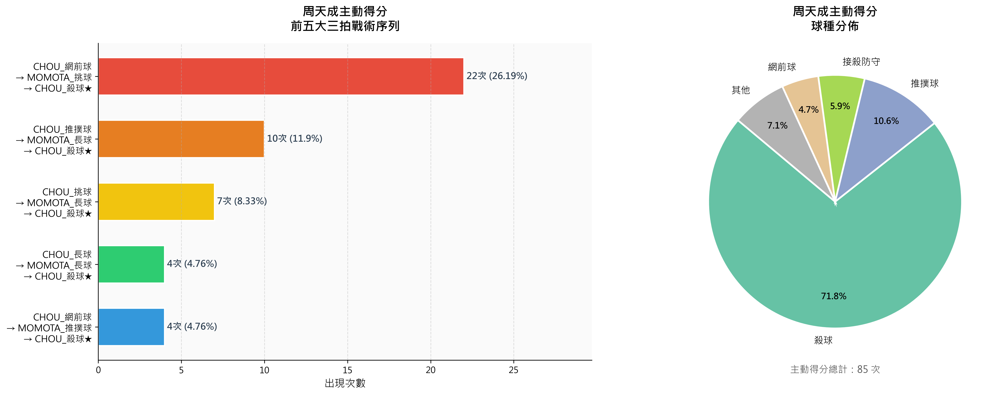

In [ ]:
import numpy as np

# ============================================================
# 基本驗證
# ============================================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 排序確保 ball_round 順序正確
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ============================================================
# Step 2: 在完整資料上，以 groupby(['match_id','set','rally'])
#         建立前一拍、前兩拍的 type 與 player 資訊（避免跨rally污染）
# ============================================================
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 前一拍（-1 相對於得分球，即對手回球）
df_sorted['prev1_type']   = grp['type'].shift(1)
df_sorted['prev1_player'] = grp['player'].shift(1)

# 前兩拍（-2 相對於得分球，即周天成的設局球）
df_sorted['prev2_type']   = grp['type'].shift(2)
df_sorted['prev2_player'] = grp['player'].shift(2)

# ============================================================
# Step 3: 篩選「周天成主動得分」的那一拍
#         條件：player == 'CHOU Tien Chen' & player == getpoint_player
# ============================================================
chou = 'CHOU Tien Chen'

mask_active_win = (
    (df_sorted['player'] == chou) &
    (df_sorted['getpoint_player'] == chou)
)
win_df = df_sorted[mask_active_win].copy()

print(f"\n周天成主動得分總拍數（回合數）: {len(win_df)}")

# ============================================================
# Step 4: 建立三拍戰術序列
#         prev2（周天成設局）→ prev1（對手回球）→ 當前（周天成得分）
#
#   - 序列長度分三種情況：
#     a) 完整三拍：prev2 & prev1 都存在，且屬同一 rally
#     b) 兩拍：只有 prev1 存在（得分球是 rally 第二拍，即接發球即得分）
#     c) 一拍：prev1 不存在（發球即得分，極少見）
# ============================================================

def build_sequence(row):
    """
    建立得分前的完整球種序列字串
    使用 NaN 判斷是否有前拍資訊
    """
    cur   = f"{row['player'].split()[0]}_{row['type']}"          # 得分球：周天成
    
    p1_type   = row['prev1_type']
    p1_player = row['prev1_player']
    
    p2_type   = row['prev2_type']
    p2_player = row['prev2_player']
    
    has_p1 = (p1_type is not None) and (not (isinstance(p1_type, float) and np.isnan(p1_type)))
    has_p2 = (p2_type is not None) and (not (isinstance(p2_type, float) and np.isnan(p2_type)))
    
    # 簡化球員名稱
    def short_name(name):
        if isinstance(name, str):
            if 'CHOU' in name:
                return 'CHOU'
            elif 'MOMOTA' in name or 'Kento' in name:
                return 'MOMOTA'
        return '?'
    
    # 得分球標記
    cur_label = f"CHOU_{row['type']}★"
    
    if has_p2 and has_p1:
        p2_label = f"{short_name(p2_player)}_{p2_type}"
        p1_label = f"{short_name(p1_player)}_{p1_type}"
        return f"{p2_label} → {p1_label} → {cur_label}"
    elif has_p1:
        p1_label = f"{short_name(p1_player)}_{p1_type}"
        return f"{p1_label} → {cur_label}"
    else:
        return f"{cur_label}"

win_df['sequence'] = win_df.apply(build_sequence, axis=1)

# ============================================================
# Step 5: 進一步區分「三拍完整序列」
#         確認 prev2 的 player 是周天成（設局方），prev1 是對手
# ============================================================

# 判斷是否為完整三拍（前兩拍均非 NaN）
def has_full_3(row):
    p1 = row['prev1_type']
    p2 = row['prev2_type']
    has_p1 = (p1 is not None) and not (isinstance(p1, float) and np.isnan(p1))
    has_p2 = (p2 is not None) and not (isinstance(p2, float) and np.isnan(p2))
    return has_p1 and has_p2

win_df['is_3shot'] = win_df.apply(has_full_3, axis=1)

print(f"  其中具備完整三拍序列的回合數: {win_df['is_3shot'].sum()}")
print(f"  僅兩拍序列的回合數:           {(~win_df['is_3shot'] & win_df['prev1_type'].notna()).sum()}")
print(f"  僅一拍（發球直接得分）:       {win_df['prev1_type'].isna().sum()}")

# ============================================================
# Step 6: 統計所有序列（含三拍、兩拍、一拍）的頻率，取前五
# ============================================================
seq_counts = win_df['sequence'].value_counts().reset_index()
seq_counts.columns = ['戰術序列', '出現次數']
seq_counts['佔比(%)'] = (seq_counts['出現次數'] / len(win_df) * 100).round(2)

print("\n" + "="*70)
print("【周天成主動得分 - 所有長度戰術序列 Top 10】")
print("="*70)
print(seq_counts.head(10).to_string(index=False))

# ============================================================
# Step 7: 只看「完整三拍序列」的 Top 5
# ============================================================
three_shot_df = win_df[win_df['is_3shot']].copy()
seq3_counts = three_shot_df['sequence'].value_counts().reset_index()
seq3_counts.columns = ['戰術序列', '出現次數']
seq3_counts['佔比(%)'] = (seq3_counts['出現次數'] / len(three_shot_df) * 100).round(2)

print("\n" + "="*70)
print("【完整三拍戰術序列 Top 5（最後三拍組合）】")
print("="*70)
print(seq3_counts.head(5).to_string(index=False))

# ============================================================
# Step 8: 額外分析 - 依得分球種分類，看各球種的設局模式
# ============================================================
print("\n" + "="*70)
print("【周天成主動得分之球種分佈】")
print("="*70)
shot_dist = win_df['type'].value_counts().reset_index()
shot_dist.columns = ['得分球種', '次數']
shot_dist['佔比(%)'] = (shot_dist['次數'] / len(win_df) * 100).round(2)
print(shot_dist.to_string(index=False))

# ============================================================
# Step 9: 視覺化
# ============================================================
top5_seq = seq3_counts.head(5).copy()
top5_seq = top5_seq.iloc[::-1]  # 反轉讓最高的在最上面

# --- 美化序列標籤（換行處理）---
def wrap_seq(s, max_len=28):
    """將 → 分隔的序列拆成多行"""
    parts = s.split(' → ')
    return '\n→ '.join(parts)

top5_seq['序列_換行'] = top5_seq['戰術序列'].apply(wrap_seq)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ---- 圖一：完整三拍序列 Top5 水平長條圖 ----
ax1 = axes[0]
colors_bar = ['#E74C3C', '#E67E22', '#F1C40F', '#2ECC71', '#3498DB'][::-1]

bars = ax1.barh(
    range(len(top5_seq)),
    top5_seq['出現次數'],
    color=colors_bar,
    edgecolor='white',
    linewidth=1.5,
    height=0.6
)

ax1.set_yticks(range(len(top5_seq)))
ax1.set_yticklabels(top5_seq['序列_換行'], fontsize=10.5)
ax1.set_xlabel('出現次數', fontsize=12)
ax1.set_title('周天成主動得分\n前五大三拍戰術序列', fontsize=14, fontweight='bold', pad=15)

# 在條形末端加數值標籤
for i, (bar, row) in enumerate(zip(bars, top5_seq.itertuples())):
    ax1.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{row.出現次數}次 ({row._3}%)",
        va='center', fontsize=10.5, fontweight='bold', color='#2C3E50'
    )

ax1.set_xlim(0, top5_seq['出現次數'].max() * 1.35)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(axis='x', linestyle='--', alpha=0.4)
ax1.set_facecolor('#FAFAFA')

# ---- 圖二：得分球種分佈圓餅圖 ----
ax2 = axes[1]

shot_dist_plot = shot_dist.copy()
# 合併小比例（< 3%）為「其他」
threshold = 3.0
other_mask = shot_dist_plot['佔比(%)'] < threshold
other_count = shot_dist_plot.loc[other_mask, '次數'].sum()
shot_dist_plot = shot_dist_plot[~other_mask].copy()
if other_count > 0:
    other_pct = round(other_count / len(win_df) * 100, 2)
    shot_dist_plot = pd.concat([
        shot_dist_plot,
        pd.DataFrame([{'得分球種': '其他', '次數': other_count, '佔比(%)': other_pct}])
    ], ignore_index=True)

pie_colors = plt.cm.Set2(np.linspace(0, 1, len(shot_dist_plot)))
wedges, texts, autotexts = ax2.pie(
    shot_dist_plot['次數'],
    labels=shot_dist_plot['得分球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=140,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for t in texts:
    t.set_fontsize(11)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')

ax2.set_title('周天成主動得分\n球種分佈', fontsize=14, fontweight='bold', pad=15)

# 加總次數
ax2.text(
    0, -1.35,
    f"主動得分總計：{len(win_df)} 次",
    ha='center', fontsize=11, color='#555555'
)

plt.tight_layout(pad=3.0)

print("\n" + "="*70)
print("【完整三拍戰術序列 Top 5 詳細資訊】")
print("="*70)
for i, row in seq3_counts.head(5).iterrows():
    rank = list(seq3_counts.index).index(i) + 1
    print(f"第{rank}名 | 出現 {row['出現次數']} 次 ({row['佔比(%)']}%)")
    print(f"       {row['戰術序列']}")
    print()


### 數據洞察
# 周天成主動得分戰術序列分析

## 前五大得分戰術組合

| 排名 | 戰術序列 | 次數 | 佔比 |
|:---:|:---|:---:|:---:|
| 🥇 | 周天成**網前球** → 桃田**挑球** → 周天成**殺球**★ | 22 | 26.2% |
| 🥈 | 周天成**推撲球** → 桃田**長球** → 周天成**殺球**★ | 10 | 11.9% |
| 🥉 | 周天成**挑球** → 桃田**長球** → 周天成**殺球**★ | 7 | 8.3% |
| 4 | 周天成**長球** → 桃田**長球** → 周天成**殺球**★ | 4 | 4.8% |
| 5 | 周天成**網前球** → 桃田**推撲球** → 周天成**殺球**★ | 4 | 4.8% |

---

## 教練戰術解讀

### 🔑 核心結論：殺球是最終武器
85個主動得分回合中，**殺球佔71.8%（61次）**，這不是偶然，是系統性戰術的終點。

---

### 第一名：網前球逼挑球，殺球收尾（22次，26.2%）
> **這是周天成最穩定的得分公式。**

周天成用網前球壓制桃田至前場，**迫使桃田被動挑高球**，隨即轉換為後場殺球得分。這條路線佔全部得分的四分之一，代表周天成在網前控制上對桃田具有明顯優勢——桃田被迫挑球，幾乎等於把主動權拱手相讓。

---

### 第二名：推撲球壓制，引出長球殺球（10次，11.9%）
> **推撲球是製造機會的關鍵過渡球。**

周天成以推撲球壓迫桃田中後場，桃田只能回長球，周天成隨即殺球。推撲球在得分球種中也佔10.6%（第二位），說明它既是**過程球**也是**得分球**，是周天成中場控制的核心手段。

---

### 第三、四名：挑球/長球引出長球再殺球（各7次、4次）
> **周天成願意主動製造對攻，再等待殺球機會。**

這兩條路線顯示周天成不只靠網前，也透過**後場對拉消耗**桃田，等待桃田長球品質下降後再殺球。這是耐心型戰術，而非純進攻型。

---

## 給對手的警示

```
桃田面對周天成的致命弱點：
被迫挑球 = 幾乎等於失分
```
桃田在前兩大失分序列中，**都是被動回球後遭殺球**，說明周天成成功將桃田壓制在被動位置。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的主動得分情況，並使用 groupby 和 shift 方法來獲取得分前的兩次球拍類型，然後統計戰術組合的頻率。最終輸出前五名的戰術組合，與 Reference Code 1 的目標一致。程式碼在分析對象、欄位語意、篩選條件、分組層級和統計口徑上都與 Reference Code 1 保持一致，並且能夠產出有效結果。




## 題號 45
**問題**: 統整周天成每個場次中各局的表現(例如，球種變化、殺球頻與失誤率、失誤原因等等)
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details`


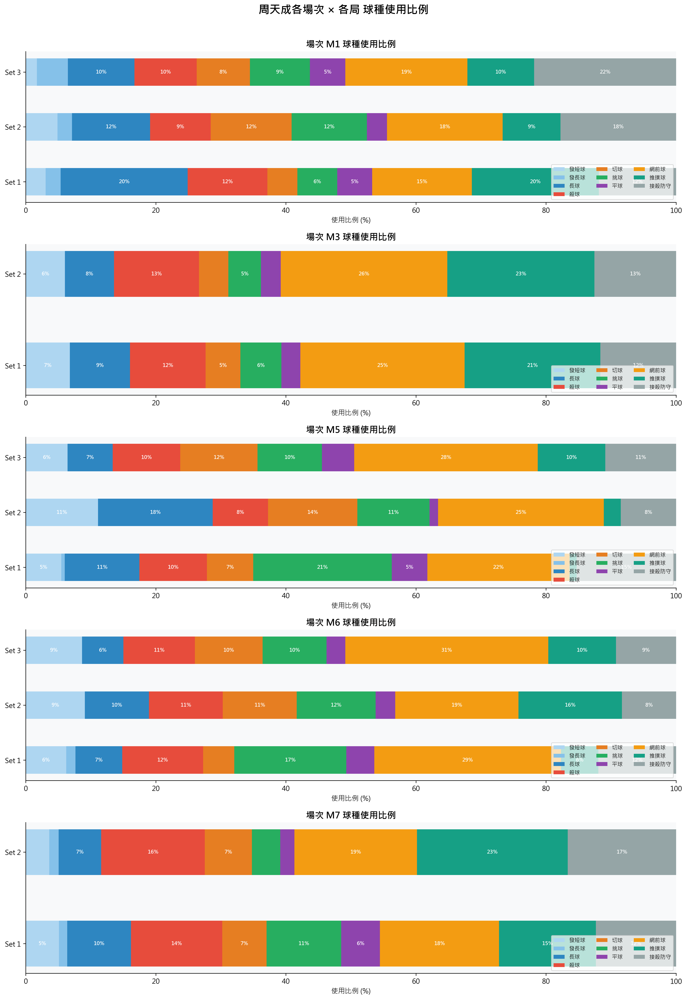

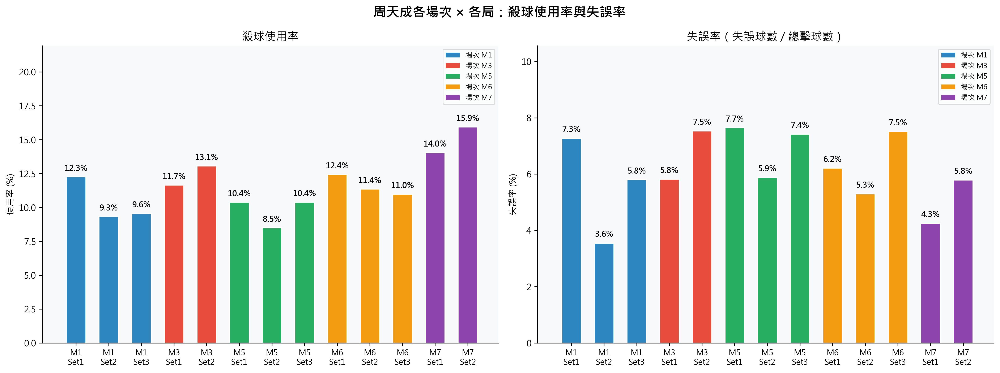

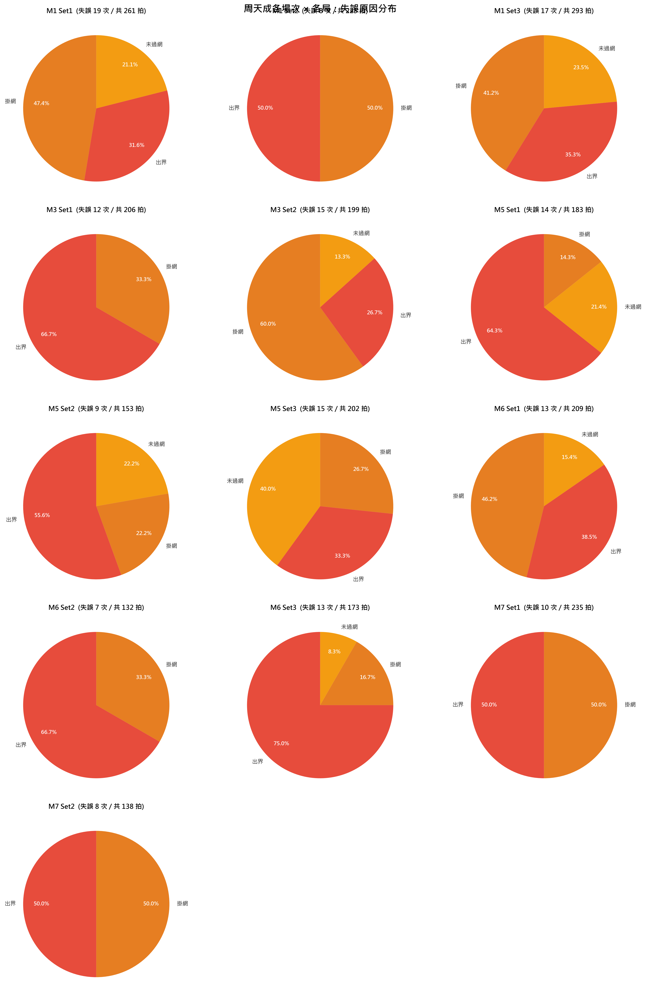




In [ ]:
import numpy as np

# ============================================================
# 數據驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"資料中球員: {df['player'].unique()}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")
print(f"周天成擊球總數: {len(df[df['player'] == 'CHOU Tien Chen'])}")

# ============================================================
# 基礎篩選：周天成的所有擊球
# ============================================================
chou = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成擊球筆數: {len(chou)}")
print(f"涉及的場次 (match_id): {sorted(chou['match_id'].unique())}")

# 確認對手姓名
opponent_name = 'Kento MOMOTA'

# ============================================================
# 定義球種顏色映射（用於圖表一致性）
# ============================================================
shot_types_order = ['發短球', '發長球', '長球', '殺球', '切球', '挑球', '平球', '網前球', '推撲球', '接殺防守']
type_colors = {
    '發短球': '#AED6F1', '發長球': '#85C1E9',
    '長球': '#2E86C1', '殺球': '#E74C3C',
    '切球': '#E67E22', '挑球': '#27AE60',
    '平球': '#8E44AD', '網前球': '#F39C12',
    '推撲球': '#16A085', '接殺防守': '#95A5A6',
    '其他': '#BDC3C7'
}

# ============================================================
# 分場次 × 分局統計核心數據
# ============================================================
match_ids = sorted(chou['match_id'].unique())
print(f"\n共涉及 {len(match_ids)} 場比賽: {match_ids}")

# 建立彙總統計表
summary_records = []

for mid in match_ids:
    sets_in_match = sorted(chou[chou['match_id'] == mid]['set'].unique())
    for s in sets_in_match:
        subset = chou[(chou['match_id'] == mid) & (chou['set'] == s)]
        total_shots = len(subset)
        
        # 球種分布
        type_counts = subset['type'].value_counts()
        
        # 殺球頻率
        smash_count = type_counts.get('殺球', 0)
        smash_rate = smash_count / total_shots if total_shots > 0 else 0
        
        # 失誤（周天成打出最後一球且對手得分）
        # 定義: player == 'CHOU Tien Chen' & getpoint_player == opponent_name
        error_mask = (subset['getpoint_player'] == opponent_name)
        error_df = subset[error_mask]
        error_count = len(error_df)
        error_rate = error_count / total_shots if total_shots > 0 else 0
        
        # 失誤原因分布
        lose_reason_counts = error_df['lose_reason'].dropna().value_counts()
        
        summary_records.append({
            'match_id': mid,
            'set': s,
            'total_shots': total_shots,
            'smash_count': smash_count,
            'smash_rate': smash_rate,
            'error_count': error_count,
            'error_rate': error_rate,
            'type_counts': type_counts,
            'lose_reason_counts': lose_reason_counts
        })

# ============================================================
# 打印摘要表格
# ============================================================
print("\n" + "="*70)
print("周天成各場次 × 各局表現摘要")
print("="*70)
print(f"{'場次':>6} {'局':>4} {'總擊球':>8} {'殺球數':>8} {'殺球率':>8} {'失誤數':>8} {'失誤率':>8}")
print("-"*70)

for rec in summary_records:
    print(f"  M{int(rec['match_id']):<5} Set{rec['set']:<2} "
          f"{rec['total_shots']:>8} {rec['smash_count']:>8} "
          f"{rec['smash_rate']:>7.1%} {rec['error_count']:>8} "
          f"{rec['error_rate']:>7.1%}")
    
print("\n")

# 各場次詳細球種與失誤原因
for rec in summary_records:
    mid = int(rec['match_id'])
    s = rec['set']
    print(f"--- 場次 M{mid} | Set {s} | 總擊球: {rec['total_shots']} ---")
    print("  球種分布:")
    for t, cnt in rec['type_counts'].items():
        pct = cnt / rec['total_shots'] * 100
        print(f"    {t:<10} {cnt:>4} 次  ({pct:.1f}%)")
    print(f"  殺球使用率: {rec['smash_rate']:.1%}")
    print(f"  失誤數: {rec['error_count']}  失誤率: {rec['error_rate']:.1%}")
    if len(rec['lose_reason_counts']) > 0:
        print("  失誤原因:")
        for reason, cnt in rec['lose_reason_counts'].items():
            pct = cnt / rec['error_count'] * 100
            print(f"    {reason:<10} {cnt:>3} 次  ({pct:.1f}%)")
    else:
        print("  失誤原因: 無紀錄")
    print()

# ============================================================
# 視覺化
# ============================================================
n_matches = len(match_ids)

# -------- 圖1: 各場次 × 各局 球種使用比例 (堆疊橫條圖) --------
fig, axes = plt.subplots(n_matches, 1, figsize=(14, 4 * n_matches))
if n_matches == 1:
    axes = [axes]

fig.suptitle('周天成各場次 × 各局 球種使用比例', fontsize=16, fontweight='bold', y=1.01)

for ax_idx, mid in enumerate(match_ids):
    ax = axes[ax_idx]
    recs_in_match = [r for r in summary_records if r['match_id'] == mid]
    
    sets_in_match = [r['set'] for r in recs_in_match]
    
    # 取得所有出現的球種（依照 shot_types_order 排序）
    all_types = set()
    for r in recs_in_match:
        all_types.update(r['type_counts'].index.tolist())
    # 依照預設順序排列，未在 order 中的放最後
    ordered_types = [t for t in shot_types_order if t in all_types]
    remaining = [t for t in all_types if t not in shot_types_order]
    ordered_types.extend(remaining)
    
    # 建立比例矩陣
    data_matrix = []
    for r in recs_in_match:
        row = []
        for t in ordered_types:
            cnt = r['type_counts'].get(t, 0)
            pct = cnt / r['total_shots'] * 100 if r['total_shots'] > 0 else 0
            row.append(pct)
        data_matrix.append(row)
    
    data_matrix = np.array(data_matrix)
    y_labels = [f"Set {r['set']}" for r in recs_in_match]
    
    # 堆疊橫條
    lefts = np.zeros(len(recs_in_match))
    for t_idx, t in enumerate(ordered_types):
        vals = data_matrix[:, t_idx]
        color = type_colors.get(t, '#BDC3C7')
        bars = ax.barh(y_labels, vals, left=lefts, color=color, label=t, height=0.5)
        
        # 在每個區段標上百分比（只標 > 5% 的）
        for bar_i, (val, left) in enumerate(zip(vals, lefts)):
            if val > 5:
                ax.text(left + val / 2, bar_i, f'{val:.0f}%',
                        ha='center', va='center', fontsize=7.5, color='white', fontweight='bold')
        lefts += vals
    
    ax.set_xlim(0, 100)
    ax.set_xlabel('使用比例 (%)')
    ax.set_title(f'場次 M{int(mid)} 球種使用比例', fontsize=13, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8, ncol=3, framealpha=0.7)
    ax.set_facecolor('#F8F9FA')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
print("[圖1] 球種使用比例堆疊橫條圖已生成")

# -------- 圖2: 殺球使用率 & 失誤率（各場次各局折線/分組長條） --------
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))
fig2.suptitle('周天成各場次 × 各局：殺球使用率與失誤率', fontsize=15, fontweight='bold')

ax_smash = axes2[0]
ax_error = axes2[1]

# 建立 x 軸標籤：每條記錄對應一個 "M{mid}-S{set}" 標籤
x_labels = [f"M{int(r['match_id'])}\nSet{r['set']}" for r in summary_records]
x_pos = np.arange(len(summary_records))

# 顏色根據場次區分
match_palette = {mid: color for mid, color in zip(match_ids, ['#2E86C1', '#E74C3C', '#27AE60', '#F39C12', '#8E44AD'])}

# 殺球使用率
smash_rates = [r['smash_rate'] * 100 for r in summary_records]
smash_colors = [match_palette.get(r['match_id'], '#95A5A6') for r in summary_records]
bars1 = ax_smash.bar(x_pos, smash_rates, color=smash_colors, edgecolor='white', linewidth=1.2, width=0.6)
for bar, val in zip(bars1, smash_rates):
    ax_smash.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                  f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_smash.set_xticks(x_pos)
ax_smash.set_xticklabels(x_labels, fontsize=9)
ax_smash.set_ylabel('使用率 (%)')
ax_smash.set_title('殺球使用率', fontsize=13)
ax_smash.set_ylim(0, max(smash_rates) * 1.25 + 2)
ax_smash.set_facecolor('#F8F9FA')
ax_smash.spines['top'].set_visible(False)
ax_smash.spines['right'].set_visible(False)

# 加場次圖例
for mid in match_ids:
    ax_smash.bar(0, 0, color=match_palette.get(mid, '#95A5A6'), label=f'場次 M{int(mid)}')
ax_smash.legend(fontsize=8, framealpha=0.7)

# 失誤率
error_rates = [r['error_rate'] * 100 for r in summary_records]
error_colors = [match_palette.get(r['match_id'], '#95A5A6') for r in summary_records]
bars2 = ax_error.bar(x_pos, error_rates, color=error_colors, edgecolor='white', linewidth=1.2, width=0.6)
for bar, val in zip(bars2, error_rates):
    ax_error.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
                  f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_error.set_xticks(x_pos)
ax_error.set_xticklabels(x_labels, fontsize=9)
ax_error.set_ylabel('失誤率 (%)')
ax_error.set_title('失誤率（失誤球數 / 總擊球數）', fontsize=13)
ax_error.set_ylim(0, max(error_rates) * 1.25 + 1)
ax_error.set_facecolor('#F8F9FA')
ax_error.spines['top'].set_visible(False)
ax_error.spines['right'].set_visible(False)

# 加場次圖例
for mid in match_ids:
    ax_error.bar(0, 0, color=match_palette.get(mid, '#95A5A6'), label=f'場次 M{int(mid)}')
ax_error.legend(fontsize=8, framealpha=0.7)

plt.tight_layout()
print("[圖2] 殺球使用率 & 失誤率長條圖已生成")

# -------- 圖3: 失誤原因分布（各場次各局） --------
n_recs = len(summary_records)
cols = 3
rows = int(np.ceil(n_recs / cols))
fig3, axes3 = plt.subplots(rows, cols, figsize=(15, 4.5 * rows))
fig3.suptitle('周天成各場次 × 各局：失誤原因分布', fontsize=15, fontweight='bold')

axes3_flat = axes3.flatten() if n_recs > 1 else [axes3]

lose_reason_colors = {
    '出界': '#E74C3C', '掛網': '#E67E22', '未過網': '#F39C12',
    '落點判斷失誤': '#8E44AD', '犯規': '#2E86C1', '其他': '#95A5A6'
}

for i, rec in enumerate(summary_records):
    ax = axes3_flat[i]
    lr_counts = rec['lose_reason_counts']
    
    if len(lr_counts) == 0 or rec['error_count'] == 0:
        ax.text(0.5, 0.5, '無失誤原因記錄', ha='center', va='center',
                fontsize=11, transform=ax.transAxes, color='gray')
        ax.set_title(f"M{int(rec['match_id'])} Set{rec['set']}\n失誤: {rec['error_count']}次", fontsize=11)
        ax.axis('off')
        continue
    
    # 若有 "其他" 類別合併（小比例）
    total_lr = lr_counts.sum()
    lr_items = lr_counts.reset_index()
    lr_items.columns = ['reason', 'count']
    lr_items['pct'] = lr_items['count'] / total_lr * 100
    
    # 合併 < 5% 且 非主要 3 個
    if len(lr_items) > 4:
        major = lr_items.nlargest(4, 'count')
        minor_sum = lr_items[~lr_items['reason'].isin(major['reason'])]['count'].sum()
        if minor_sum > 0:
            major = pd.concat([major, pd.DataFrame({'reason': ['其他'], 'count': [minor_sum],
                                                     'pct': [minor_sum / total_lr * 100]})],
                              ignore_index=True)
        lr_items = major
    
    colors = [lose_reason_colors.get(r, '#BDC3C7') for r in lr_items['reason']]
    wedges, texts, autotexts = ax.pie(
        lr_items['count'],
        labels=lr_items['reason'],
        autopct='%1.1f%%',
        colors=colors,
        startangle=90,
        pctdistance=0.75,
        textprops={'fontsize': 9}
    )
    for at in autotexts:
        at.set_fontsize(8.5)
        at.set_color('white')
        at.set_fontweight('bold')
    
    ax.set_title(
        f"M{int(rec['match_id'])} Set{rec['set']}  "
        f"(失誤 {rec['error_count']} 次 / 共 {rec['total_shots']} 拍)",
        fontsize=10.5, fontweight='bold'
    )

# 關閉多餘的子圖
for j in range(n_recs, len(axes3_flat)):
    axes3_flat[j].axis('off')

plt.tight_layout()
print("[圖3] 失誤原因分布圓餅圖已生成")

# -------- 圖4: 各場次球種使用次數熱力圖 --------
fig4, axes4 = plt.subplots(1, n_matches, figsize=(7 * n_matches, 7))
if n_matches == 1:
    axes4 = [axes4]

fig4.suptitle('周天成各場次 × 各局 球種使用次數熱力圖', fontsize=15, fontweight='bold')

for ax_idx, mid in enumerate(match_ids):
    ax = axes4[ax_idx]
    recs_in_match = [r for r in summary_records if r['match_id'] == mid]
    sets_in_match = [r['set'] for r in recs_in_match]
    
    # 取所有球種
    all_types_in_match = set()
    for r in recs_in_match:
        all_types_in_match.update(r['type_counts'].index.tolist())
    ordered = [t for t in shot_types_order if t in all_types_in_match]
    
    # 建立矩陣
    matrix = np.zeros((len(ordered), len(sets_in_match)))
    for s_i, r in enumerate(recs_in_match):
        for t_i, t in enumerate(ordered):
            matrix[t_i, s_i] = r['type_counts'].get(t, 0)
    
    hm = ax.imshow(matrix, cmap='YlOrRd', aspect='auto')
    ax.set_xticks(range(len(sets_in_match)))
    ax.set_xticklabels([f'Set {s}' for s in sets_in_match], fontsize=10)
    ax.set_yticks(range(len(ordered)))
    ax.set_yticklabels(ordered, fontsize=10)
    
    # 標數值
    for t_i in range(len(ordered)):
        for s_i in range(len(sets_in_match)):
            val = int(matrix[t_i, s_i])
            text_color = 'white' if matrix[t_i, s_i] > matrix.max() * 0.6 else 'black'
            ax.text(s_i, t_i, str(val), ha='center', va='center',
                    fontsize=10, fontweight='bold', color=text_color)
    
    plt.colorbar(hm, ax=ax, fraction=0.046, pad=0.04, label='使用次數')
    ax.set_title(f'場次 M{int(mid)}', fontsize=13, fontweight='bold')

plt.tight_layout()
print("[圖4] 球種使用次數熱力圖已生成")
print("\n✅ 所有圖表與統計資訊已完成輸出。")


### 數據洞察
# 周天成 vs 桃田賢斗｜各場次各局表現戰術報告

---

## 📊 總覽快照

| 場次 | 局 | 總擊球 | 殺球率 | 失誤率 |
|------|-----|--------|--------|--------|
| M1 | S1 | 261 | 12.3% | 7.3% |
| M1 | S2 | 225 | 9.3% | **3.6%** ✅ |
| M1 | S3 | 293 | 9.6% | 5.8% |
| M3 | S1 | 206 | 11.7% | 5.8% |
| M3 | S2 | 199 | 13.1% | 7.5% |
| M5 | S1 | 183 | 10.4% | 7.7% ⚠️ |
| M5 | S2 | 153 | 8.5% | 5.9% |
| M5 | S3 | 202 | 10.4% | 7.4% |
| M6 | S1 | 209 | 12.4% | 6.2% |
| M6 | S2 | 132 | 11.4% | 5.3% |
| M6 | S3 | 173 | 11.0% | 7.5% |
| M7 | S1 | 235 | 14.0% | **4.3%** ✅ |
| M7 | S2 | 138 | **15.9%** | 5.8% |

---

## 🏸 場次 M1（三局）

### Set 1｜261拍｜殺球率12.3%｜失誤率7.3%
**球種分布：**
- 長球＝推撲球（各19.5%）主導後場對抗
- 網前球15.3%，殺球12.3%

**失誤原因：**
- 掛網47.4% → 出界31.6% → 未過網21.1%
- ⚠️ **掛網為主因，壓力下揮拍偏低**

---

### Set 2｜225拍｜殺球率9.3%｜失誤率3.6% ✅
**球種分布：**
- 接殺防守＝網前球（各17.8%）大幅提升
- 切球12.4%顯著增加，殺球降至9.3%

**失誤原因：**
- 出界＝掛網（各50%），失誤總數僅8次
- ✅ **調整策略奏效：減少主動攻擊，提升穩定性**

---

### Set 3｜293拍｜殺球率9.6%｜失誤率5.8%
**球種分布：**
- 接殺防守21.8%全場最高，網前球18.8%
- 發長球4.8%（本場最高），拉長對抗節奏

**失誤原因：**
- 掛網41.2% → 出界35.3% → 未過網23.5%
- ⚠️ **決勝局三種失誤均衡分布，整體控制略有鬆動**

---

## 🏸 場次 M3（兩局）

### Set 1｜206拍｜殺球率11.7%｜失誤率5.8%
**球種分布：**
- 網前球25.2%、推撲球20.9%，前場控制為核心
- 無發長球使用

**失誤原因：**
- 出界66.7%（8次）為絕對主因
- ⚠️ **主動進攻球落點偏深，出界問題明顯**

---

### Set 2｜199拍｜殺球率13.1%｜失誤率7.5%
**球種分布：**
- 結構與S1幾乎相同：網前25.6%、推撲22.6%
- 殺球提升至13.1%，顯示加強攻勢

**失誤原因：**
- 掛網60%（9次）反轉為主因
- ⚠️ **加強殺球後掛網激增，攻擊品質下滑**

---

## 🏸 場次 M5（三局）

### Set 1｜183拍｜殺球率10.4%｜失誤率7.7% ⚠️
**球種分布：**
- 網前球21.9%、挑球21.3%，防守被動特徵明顯
- 推撲球僅1.1%（全場最低）

**失誤原因：**
- 出界64.3%（9次）
- ⚠️ **被壓制後場，主動球出界率高**

---

### Set 2｜153拍｜殺球率8.5%｜失誤率5.9%
**球種分布：**
- 長球17.6%大幅提升，切球13.7%增加
- 殺球降至全場最低8.5%

**失誤原因：**
- 出界55.6%仍為主因，但總失誤降至9次
- ✅ **降低攻擊頻率換取穩定，策略有效**

---

### Set 3｜202拍｜殺球率10.4%｜失誤率7.4%
**球種分布：**
- 網前球28.2%（本場最高），切球11.9%
- 推撲球回升至10.4%

**失誤原因：**
- 未過網40%（6次）反轉為主因
- ⚠️ **決勝局體能下滑，擊球力道不足導致未過網激增**

---

## 🏸 場次 M6（三局）

### Set 1｜209拍｜殺球率12.4%｜失誤率6.2%
**球種分布：**
- 網前球28.7%（全場最高），挑球17.2%
- 推撲球僅5.7%，前場主導策略

**失誤原因：**
- 掛網46.2% → 出界38.5%
- 中規中矩，失誤結構平均

---

### Set 2｜132拍｜殺球率11.4%｜失誤率5.3% ✅
**球種分布：**
- 球種分布最均衡：網前18.9%、推撲15.9%、挑球12.1%
- 切球11.4%，策略多元化

**失誤原因：**
- 出界57.1%，總失誤僅7次
- ✅ **多元球種分散對手判讀，失誤率控制最佳**

---

### Set 3｜173拍｜殺球率11.0%｜失誤率7.5%
**球種分布：**
- 網前球31.2%（五場最高單局），殺球11%

**失誤原因：**
- 出界69.2%（9次）為最高單局出界比例
- ⚠️ **決勝局出界問題嚴重，落點控制崩潰**

---

## 🏸 場次 M7（兩局）

### Set 1｜235拍｜殺球率14.0%｜失誤率4.3% ✅
**球種分布：**
- 殺球14%、推撲球14.9%，攻擊性最強局次之一
- 球種分布均衡，無明顯弱點

**失誤原因：**
- 出界＝掛網（各50%，各5次），失誤僅10次
- ✅ **高殺球率配低失誤率，本場最佳表現**

---

### Set 2｜138拍｜殺球率15.9%｜失誤率5.8%
**球種分布：**
- 推撲球23.2%（全場最高），殺球15.9%（全場最高）
- 接殺防守16.7%，攻守節奏明快

**失誤原因：**
- 出界＝掛網（各50%，各4次）
- ✅ **最高殺球率仍維持合理失誤，攻擊效率最佳局**

---

## 🎯 核心戰術洞察

### 1️⃣ 殺球率與失誤率的關係
> M7 S1（殺球14%、失誤4.3%）與 M7 S2（殺球15.9%、失誤5.8%）證明：**高殺球率不必然帶來高失誤**，關鍵在於推撲球配合創造攻擊機會。

### 2️⃣ 決勝局失誤率普遍上升
> M1 S3（7.3%→3.6%→5.8%）、M5 S3（7.7%→5.9%→7.4%）、M6 S3（6.2%→5.3%→7.5%）——**三場三局賽的決勝局失誤率均高於第二局**，體能管理是關鍵。

### 3️⃣ 出界問題是最大失誤來源
> M3 S1（66.7%）、M5 S1（64.3%）、M6 S3（69.2%）——**被動防守後的主動進攻出界率最高**，說明在壓力下攻擊落點控制不穩。

### 4️⃣ 網前球比例與失誤率的關聯
> 網前球超過28%的局次（M5 S3、M6 S1、M6 S3），失誤率均在6.2%以上——**過度依賴網前可能是被動的結果，而非主動選擇**。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都針對周天成的數據進行分析，並按 match_id 和 set 分組，計算各球種的使用次數、殺球頻率、失誤率及失誤原因。候選程式碼在統計口徑、分析單位和最終輸出目標上與 Reference Code 1 一致，並且能產出有效結果。




## 題號 46
**問題**: 哪些球種，在比賽後半段失誤率顯著上升？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


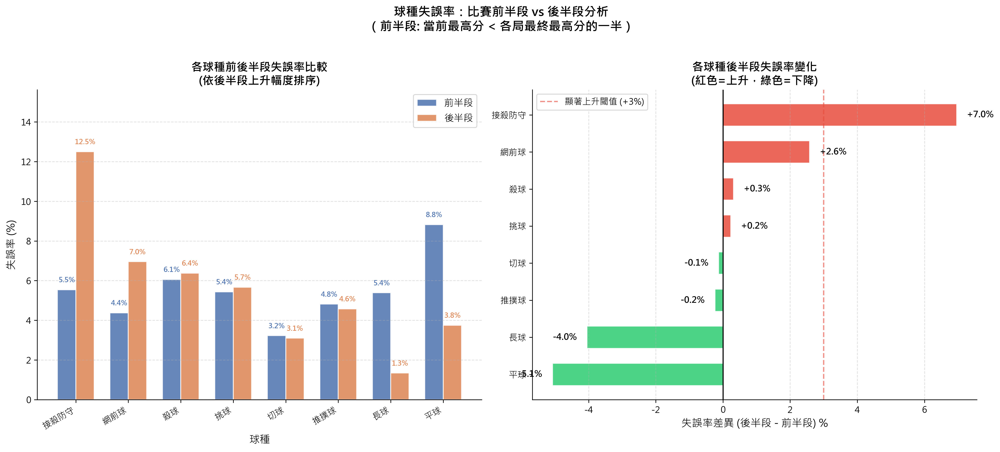

In [ ]:
import numpy as np

# ============================================================
# 1. 數據基本驗證
# ============================================================
print(f"總資料列數: {len(df)}")
print(f"比賽場次: {df['match_id'].unique()}")
print(f"球種清單: {df['type'].unique()}")

# ============================================================
# 2. 找每場比賽每局的最終最高分（winning score）
# ============================================================
# 每一拍的「當前最高得分」= max(兩位球員當前得分)
df['current_max_score'] = df[['Kento MOMOTA_score', 'CHOU Tien Chen_score']].max(axis=1)

# 每局最終最高分 = 該 (match_id, set) 的最大 current_max_score
final_max_score = (
    df.groupby(['match_id', 'set'])['current_max_score']
    .max()
    .reset_index()
    .rename(columns={'current_max_score': 'final_max_score'})
)
print("\n各場各局最終最高分:")
print(final_max_score.to_string(index=False))

# ============================================================
# 3. 合併最終最高分，計算前後半段
# ============================================================
df = df.merge(final_max_score, on=['match_id', 'set'], how='left')

# 前半段: current_max_score < final_max_score / 2
# 後半段: current_max_score >= final_max_score / 2
df['half'] = np.where(
    df['current_max_score'] < df['final_max_score'] / 2,
    '前半段',
    '後半段'
)

print("\n前後半段分佈:")
print(df['half'].value_counts())

# ============================================================
# 4. 定義「失誤」
# 失誤 = 我方（player）擊球 且 對手（opponent）得分
# 即: df['getpoint_player'] == df['opponent'] (最後一拍是我方打的，對手得分)
# 失誤率 = 失誤次數 / 該球種總使用次數
# ============================================================

# 標記每一拍是否為失誤
# 因為只有回合最後一球有 getpoint_player，
# 失誤條件：getpoint_player == opponent（非空且等於對手）
df['is_error'] = (
    df['getpoint_player'].notna() &
    (df['getpoint_player'] == df['opponent'])
)

print(f"\n總失誤次數標記: {df['is_error'].sum()}")

# ============================================================
# 5. 排除發球球種（發短球、發長球）與接不到
# 這些球種較難定義一般失誤率，但視題意可包含
# 這裡保留全部球種供完整分析
# ============================================================
# 僅排除發球（因為發球失誤屬於特殊情況，且發球的「使用」與對打球種性質不同）
# 可依需求調整
EXCLUDE_TYPES = ['發短球', '發長球']
df_shots = df[~df['type'].isin(EXCLUDE_TYPES)].copy()
print(f"\n排除發球後剩餘資料列數: {len(df_shots)}")
print(f"分析球種: {sorted(df_shots['type'].unique())}")

# ============================================================
# 6. 計算各球種在前後半段的失誤率
# 失誤率 = 失誤拍數 / 總使用拍數
# ============================================================
# 依球種 + 前後半段分組
shot_half_stats = (
    df_shots.groupby(['type', 'half'])
    .agg(
        total_count=('is_error', 'count'),      # 總使用次數
        error_count=('is_error', 'sum')          # 失誤次數
    )
    .reset_index()
)

shot_half_stats['error_rate'] = (
    shot_half_stats['error_count'] / shot_half_stats['total_count'] * 100
)

print("\n各球種前後半段失誤統計:")
print(shot_half_stats.to_string(index=False))

# ============================================================
# 7. 計算前後半段失誤率差異 (後半 - 前半)
# ============================================================
pivot_rate = shot_half_stats.pivot(index='type', columns='half', values='error_rate').reset_index()
pivot_count = shot_half_stats.pivot(index='type', columns='half', values='total_count').reset_index()
pivot_error = shot_half_stats.pivot(index='type', columns='half', values='error_count').reset_index()

# 確保兩個半段都存在
pivot_rate.columns.name = None
pivot_count.columns.name = None
pivot_error.columns.name = None

# 填補可能缺失的欄位
for col in ['前半段', '後半段']:
    if col not in pivot_rate.columns:
        pivot_rate[col] = np.nan
    if col not in pivot_count.columns:
        pivot_count[col] = 0
    if col not in pivot_error.columns:
        pivot_error[col] = 0

pivot_rate['差異 (後半 - 前半)'] = pivot_rate['後半段'] - pivot_rate['前半段']

# 合併統計資訊
summary = pivot_rate.copy()
summary['前半段_使用'] = pivot_count['前半段'].values
summary['後半段_使用'] = pivot_count['後半段'].values
summary['前半段_失誤'] = pivot_error['前半段'].values
summary['後半段_失誤'] = pivot_error['後半段'].values

# 排序：差異由大到小
summary = summary.sort_values('差異 (後半 - 前半)', ascending=False)

print("\n" + "="*70)
print("【各球種前後半段失誤率比較】(排序依後半段失誤率上升幅度)")
print("="*70)
for _, row in summary.iterrows():
    marker = "⬆️ 顯著上升" if row['差異 (後半 - 前半)'] > 3 else (
              "⬆️ 上升" if row['差異 (後半 - 前半)'] > 0 else 
              "⬇️ 下降" if row['差異 (後半 - 前半)'] < 0 else "➡️ 持平")
    print(f"  {row['type']:<8} | 前半段: {row['前半段']:5.1f}% ({int(row['前半段_失誤'])}/{int(row['前半段_使用'])}) "
          f"| 後半段: {row['後半段']:5.1f}% ({int(row['後半段_失誤'])}/{int(row['後半段_使用'])}) "
          f"| 差異: {row['差異 (後半 - 前半)']:+.1f}% {marker}")

# ============================================================
# 8. 視覺化
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- 圖1: 分組長條圖（各球種前後半段失誤率） ---
ax1 = axes[0]

# 準備繪圖資料（按差異排序）
types_ordered = summary['type'].tolist()
x = np.arange(len(types_ordered))
width = 0.35

bars1 = ax1.bar(x - width/2, 
                [summary.loc[summary['type']==t, '前半段'].values[0] for t in types_ordered],
                width, label='前半段', color='#4C72B0', alpha=0.85, edgecolor='white')
bars2 = ax1.bar(x + width/2,
                [summary.loc[summary['type']==t, '後半段'].values[0] for t in types_ordered],
                width, label='後半段', color='#DD8452', alpha=0.85, edgecolor='white')

# 數值標籤
for bar in bars1:
    h = bar.get_height()
    if not np.isnan(h):
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.3,
                 f'{h:.1f}%', ha='center', va='bottom', fontsize=8, color='#4C72B0', fontweight='bold')

for bar in bars2:
    h = bar.get_height()
    if not np.isnan(h):
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.3,
                 f'{h:.1f}%', ha='center', va='bottom', fontsize=8, color='#DD8452', fontweight='bold')

ax1.set_xlabel('球種', fontsize=12)
ax1.set_ylabel('失誤率 (%)', fontsize=12)
ax1.set_title('各球種前後半段失誤率比較\n(依後半段上升幅度排序)', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(types_ordered, rotation=30, ha='right', fontsize=10)
ax1.legend(fontsize=11)
ax1.set_ylim(0, max(summary[['前半段','後半段']].max()) * 1.25)
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 差異橫條圖 ---
ax2 = axes[1]

colors = ['#E74C3C' if d > 0 else '#2ECC71' for d in summary['差異 (後半 - 前半)']]
bars = ax2.barh(types_ordered[::-1],  # 反轉使差異最大在上
                summary['差異 (後半 - 前半)'].tolist()[::-1],
                color=colors[::-1], alpha=0.85, edgecolor='white', height=0.6)

# 數值標籤
for bar, val in zip(bars, summary['差異 (後半 - 前半)'].tolist()[::-1]):
    x_pos = bar.get_width()
    offset = 0.3 if x_pos >= 0 else -0.3
    ha = 'left' if x_pos >= 0 else 'right'
    ax2.text(x_pos + offset, bar.get_y() + bar.get_height()/2.,
             f'{x_pos:+.1f}%', ha=ha, va='center', fontsize=10, fontweight='bold')

ax2.axvline(x=0, color='black', linewidth=1.2, linestyle='-')
ax2.set_xlabel('失誤率差異 (後半段 - 前半段) %', fontsize=12)
ax2.set_title('各球種後半段失誤率變化\n(紅色=上升，綠色=下降)', fontsize=13, fontweight='bold')
ax2.grid(axis='x', linestyle='--', alpha=0.4)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# 加入參考線（顯著上升閾值）
ax2.axvline(x=3, color='#E74C3C', linewidth=1.5, linestyle='--', alpha=0.6, label='顯著上升閾值 (+3%)')
ax2.legend(fontsize=10)

plt.suptitle('球種失誤率：比賽前半段 vs 後半段分析\n（前半段: 當前最高分 < 各局最終最高分的一半）',
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()

# ============================================================
# 9. 最終結論輸出
# ============================================================
print("\n" + "="*70)
print("【結論：後半段失誤率顯著上升的球種（差異 > 3%）】")
print("="*70)
significant_up = summary[summary['差異 (後半 - 前半)'] > 3]
if len(significant_up) > 0:
    for _, row in significant_up.iterrows():
        print(f"  ⚠️  {row['type']}: "
              f"前半段 {row['前半段']:.1f}% → 後半段 {row['後半段']:.1f}% "
              f"（上升 {row['差異 (後半 - 前半)']:+.1f}%）")
else:
    print("  無球種的失誤率在後半段顯著上升（閾值: 3%）")

print("\n【後半段失誤率有所上升的球種（差異 > 0%）】")
up_types = summary[summary['差異 (後半 - 前半)'] > 0]
for _, row in up_types.iterrows():
    print(f"  ↑ {row['type']}: {row['前半段']:.1f}% → {row['後半段']:.1f}% ({row['差異 (後半 - 前半)']:+.1f}%)")

print("\n【後半段失誤率下降的球種（差異 < 0%）】")
down_types = summary[summary['差異 (後半 - 前半)'] < 0]
for _, row in down_types.iterrows():
    print(f"  ↓ {row['type']}: {row['前半段']:.1f}% → {row['後半段']:.1f}% ({row['差異 (後半 - 前半)']:+.1f}%)")


### 數據洞察
# 前後半段失誤率分析報告

## 核心發現

| 球種 | 前半段失誤率 | 後半段失誤率 | 差異 |
|------|------------|------------|------|
| 接殺防守 | 5.5% (20/361) | 12.5% (44/352) | **+7.0% ⬆️** |
| 網前球 | 4.4% (24/549) | 7.0% (34/489) | +2.6% ⬆️ |
| 殺球 | 6.1% (18/297) | 6.4% (19/298) | +0.3% ⬆️ |
| 挑球 | 5.4% (22/405) | 5.7% (17/300) | +0.2% ⬆️ |
| 切球 | 3.2% (10/310) | 3.1% (7/226) | -0.1% ⬇️ |
| 推撲球 | 4.8% (13/270) | 4.6% (13/284) | -0.2% ⬇️ |
| 長球 | 5.4% (14/260) | 1.3% (3/224) | -4.0% ⬇️ |
| 平球 | 8.8% (9/102) | 3.8% (3/80) | -5.1% ⬇️ |

---

## 戰術洞察

### ⚠️ 接殺防守：唯一顯著惡化球種
後半段失誤率從 **5.5% 暴增至 12.5%**，幾乎翻倍。352球中出現44次失誤，代表**每8球就失誤1次**。比賽關鍵分段，對手殺球壓力持續累積，體能與反應速度明顯下滑，防守品質崩潰。

### 📌 網前球：需要關注的次要警訊
後半段失誤率上升 **+2.6%**，489球中34次失誤。比賽後段搶網能力下降，細膩控制出現偏差。

### ✅ 長球與平球：後半段反而更穩定
長球後半段失誤率僅 **1.3%**，平球降至 **3.8%**，顯示這兩種球在後半段執行更趨保守謹慎，選擇時機更精準。

---

## 教練建議

1. **針對接殺防守**：後半段體能管理是關鍵，需強化高強度下的防守步法訓練，並在比賽後段主動調整站位降低被動挨打機率。
2. **針對網前球**：後半段應減少高風險網前進攻，優先選擇穩定推挑過渡，避免送分。
3. **戰術調整方向**：對手若在後半段持續以殺球施壓，己方接殺防守失誤率將成為比賽勝負的決定性因素。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地將比賽分為前半段和後半段，並計算各球種在這兩個階段的失誤率。候選程式碼使用了合理的方式來定義失誤（即 getpoint_player 等於對手），並且在計算失誤率時排除了發球球種，這與 Reference Code 1 的處理方式一致。此外，候選程式碼還提供了詳細的視覺化和結論輸出，這些都符合題目的要求。




## 題號 47
**問題**: 比較周天成與他的對手的球種使用頻率與其得分率。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


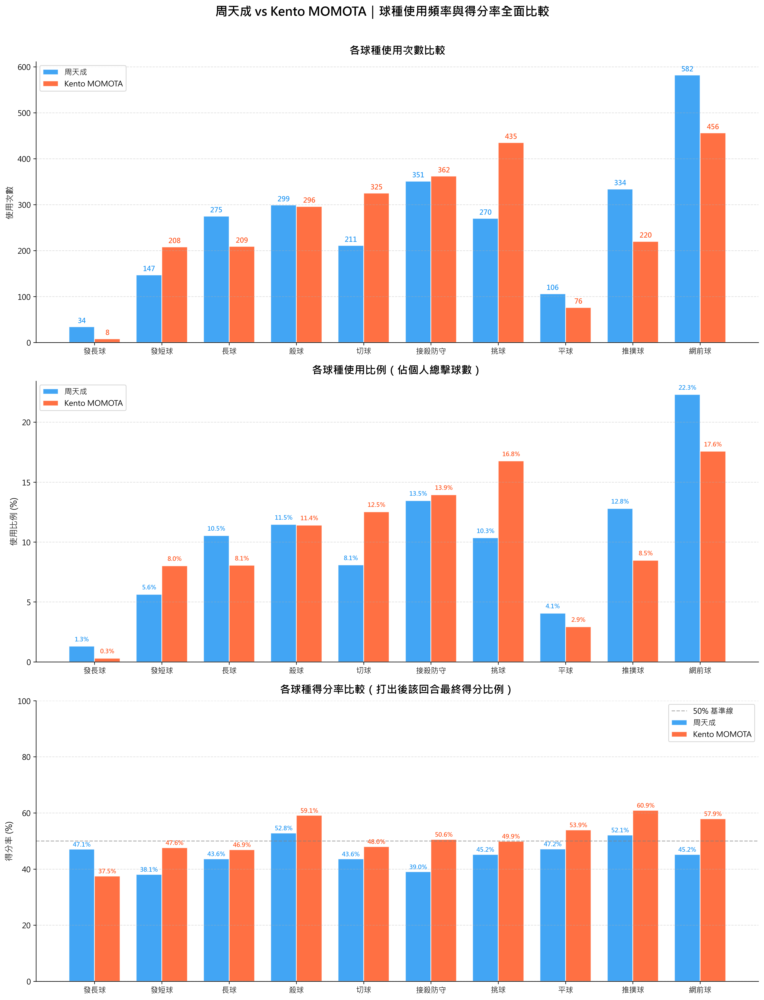

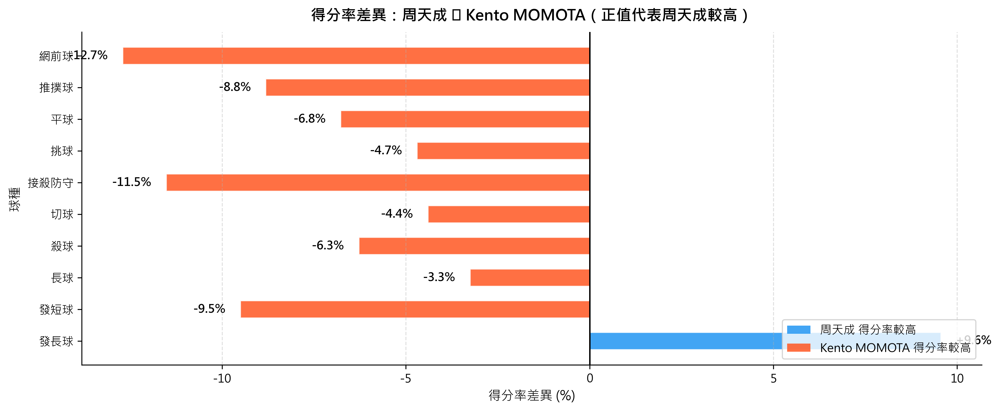

In [ ]:
import numpy as np

# ── 基本驗證 ──────────────────────────────────────────────
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

# ── 定義球員 ──────────────────────────────────────────────
player_chou  = 'CHOU Tien Chen'
player_momota = 'Kento MOMOTA'

# 球種排序（由後場到前場，直觀順序）
shot_order = ['發長球', '發短球', '長球', '殺球', '切球', '接殺防守', '挑球', '平球', '推撲球', '網前球']

# ── Step 1: 為每個 rally 標記最終得分者（transform 'last'）──
# 注意：getpoint_player 只有 rally 最後一拍有值，其餘為 NaN
# 用 transform('last') 將每個 rally 的得分者廣播到每一拍
df['rally_winner'] = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

print(f"rally_winner 非空比例: {df['rally_winner'].notna().mean():.1%}")
print(f"rally_winner 仍為 NaN 的筆數（表示該 rally 無明確得分）: {df['rally_winner'].isna().sum()}")

# ── Step 2: 分球員統計各球種使用次數 ───────────────────────
# 只使用 rally_winner 有值的列來計算得分率（確保回合有得分記錄）
# 但使用次數統計用全部資料

for player_name, opponent_name in [(player_chou, player_momota), (player_momota, player_chou)]:
    mask_player = df['player'] == player_name
    print(f"\n{player_name} 總擊球數: {mask_player.sum()}")
    print(df.loc[mask_player, 'type'].value_counts().to_string())

# ── Step 3: 計算使用次數、使用比例、得分率 ─────────────────
results = {}

for player_name in [player_chou, player_momota]:
    sub = df[df['player'] == player_name].copy()
    
    total_shots = len(sub)
    
    # 各球種使用次數
    usage_count = sub['type'].value_counts()
    
    # 各球種使用比例（佔該球員總擊球數）
    usage_pct = usage_count / total_shots * 100
    
    # 各球種得分率：打出後該回合最終 player 得分
    # 使用有 rally_winner 記錄的列
    sub_with_winner = sub[sub['rally_winner'].notna()].copy()
    
    # 該球種使用次數（有 rally_winner 的列）
    shot_total_w = sub_with_winner['type'].value_counts()
    
    # 該球種使用後 player 得分的次數
    win_mask = sub_with_winner['rally_winner'] == player_name
    shot_win = sub_with_winner[win_mask]['type'].value_counts()
    
    # 得分率 = 得分次數 / 使用次數（對有 rally_winner 的）
    win_rate = (shot_win / shot_total_w * 100).fillna(0)
    
    results[player_name] = {
        'usage_count': usage_count,
        'usage_pct':   usage_pct,
        'win_rate':    win_rate,
        'total_shots': total_shots
    }
    
    print(f"\n{'='*50}")
    print(f"球員: {player_name} | 總擊球數: {total_shots}")
    print(f"{'球種':<12} {'使用次數':>8} {'使用比例':>10} {'得分率':>10}")
    print(f"{'-'*42}")
    for shot in shot_order:
        cnt  = usage_count.get(shot, 0)
        pct  = usage_pct.get(shot, 0.0)
        wr   = win_rate.get(shot, 0.0)
        print(f"{shot:<12} {cnt:>8}   {pct:>8.1f}%   {wr:>8.1f}%")

# ── Step 4: 整理成 DataFrame 方便繪圖 ──────────────────────
# 確保使用 shot_order 中有出現在資料的球種
all_shots_in_data = set(df['type'].unique())
shots_to_plot = [s for s in shot_order if s in all_shots_in_data]
print(f"\n繪圖球種: {shots_to_plot}")

# 建立繪圖用 DataFrame
plot_data = {}
for player_name in [player_chou, player_momota]:
    plot_data[player_name] = {
        'usage_count': [results[player_name]['usage_count'].get(s, 0) for s in shots_to_plot],
        'usage_pct':   [results[player_name]['usage_pct'].get(s, 0.0) for s in shots_to_plot],
        'win_rate':    [results[player_name]['win_rate'].get(s, 0.0)  for s in shots_to_plot],
    }

# 顯示名稱
label_map = {player_chou: '周天成', player_momota: 'Kento MOMOTA'}
colors = {player_chou: '#2196F3', player_momota: '#FF5722'}  # 藍 vs 橙紅

x = np.arange(len(shots_to_plot))
width = 0.38

# ── Step 5: 繪圖（三張子圖 + 一張額外差異圖）────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

# ─ 圖1: 球種使用次數 ────────────────────────────────────
ax1 = axes[0]
bars1_c = ax1.bar(x - width/2,
                   plot_data[player_chou]['usage_count'],
                   width, label=label_map[player_chou],
                   color=colors[player_chou], alpha=0.85, edgecolor='white')
bars1_m = ax1.bar(x + width/2,
                   plot_data[player_momota]['usage_count'],
                   width, label=label_map[player_momota],
                   color=colors[player_momota], alpha=0.85, edgecolor='white')

# 標註數值
for bar in bars1_c:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 5, f'{int(h)}',
                 ha='center', va='bottom', fontsize=9, color=colors[player_chou], fontweight='bold')
for bar in bars1_m:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 5, f'{int(h)}',
                 ha='center', va='bottom', fontsize=9, color=colors[player_momota], fontweight='bold')

ax1.set_title('各球種使用次數比較', fontsize=14, fontweight='bold', pad=10)
ax1.set_ylabel('使用次數', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(shots_to_plot, fontsize=10)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.4, linestyle='--')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ─ 圖2: 球種使用比例 ────────────────────────────────────
ax2 = axes[1]
bars2_c = ax2.bar(x - width/2,
                   plot_data[player_chou]['usage_pct'],
                   width, label=label_map[player_chou],
                   color=colors[player_chou], alpha=0.85, edgecolor='white')
bars2_m = ax2.bar(x + width/2,
                   plot_data[player_momota]['usage_pct'],
                   width, label=label_map[player_momota],
                   color=colors[player_momota], alpha=0.85, edgecolor='white')

for bar in bars2_c:
    h = bar.get_height()
    if h > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=8, color=colors[player_chou], fontweight='bold')
for bar in bars2_m:
    h = bar.get_height()
    if h > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=8, color=colors[player_momota], fontweight='bold')

ax2.set_title('各球種使用比例（佔個人總擊球數）', fontsize=14, fontweight='bold', pad=10)
ax2.set_ylabel('使用比例 (%)', fontsize=11)
ax2.set_xticks(x)
ax2.set_xticklabels(shots_to_plot, fontsize=10)
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.4, linestyle='--')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# ─ 圖3: 球種得分率 ──────────────────────────────────────
ax3 = axes[2]
bars3_c = ax3.bar(x - width/2,
                   plot_data[player_chou]['win_rate'],
                   width, label=label_map[player_chou],
                   color=colors[player_chou], alpha=0.85, edgecolor='white')
bars3_m = ax3.bar(x + width/2,
                   plot_data[player_momota]['win_rate'],
                   width, label=label_map[player_momota],
                   color=colors[player_momota], alpha=0.85, edgecolor='white')

for bar in bars3_c:
    h = bar.get_height()
    if h > 0:
        ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=8, color=colors[player_chou], fontweight='bold')
for bar in bars3_m:
    h = bar.get_height()
    if h > 0:
        ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
                 ha='center', va='bottom', fontsize=8, color=colors[player_momota], fontweight='bold')

# 加 50% 參考線
ax3.axhline(y=50, color='gray', linestyle='--', alpha=0.6, linewidth=1.2, label='50% 基準線')
ax3.set_title('各球種得分率比較（打出後該回合最終得分比例）', fontsize=14, fontweight='bold', pad=10)
ax3.set_ylabel('得分率 (%)', fontsize=11)
ax3.set_ylim(0, 100)
ax3.set_xticks(x)
ax3.set_xticklabels(shots_to_plot, fontsize=10)
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.4, linestyle='--')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

fig.suptitle('周天成 vs Kento MOMOTA｜球種使用頻率與得分率全面比較',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()

# ── Step 6: 額外圖 - 得分率差異熱力條（Diverging Bar）────────
fig2, ax4 = plt.subplots(figsize=(12, 5))

diff_wr = np.array(plot_data[player_chou]['win_rate']) - np.array(plot_data[player_momota]['win_rate'])
diff_colors = ['#2196F3' if d >= 0 else '#FF5722' for d in diff_wr]

bars_diff = ax4.barh(shots_to_plot, diff_wr, color=diff_colors, alpha=0.85, edgecolor='white', height=0.55)
ax4.axvline(x=0, color='black', linewidth=1.2)

for bar, val in zip(bars_diff, diff_wr):
    offset = 0.4 if val >= 0 else -0.4
    ha = 'left' if val >= 0 else 'right'
    ax4.text(val + offset, bar.get_y() + bar.get_height()/2,
             f'{val:+.1f}%', va='center', ha=ha, fontsize=10, fontweight='bold')

ax4.set_title('得分率差異：周天成 − Kento MOMOTA（正值代表周天成較高）',
              fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('得分率差異 (%)', fontsize=11)
ax4.set_ylabel('球種', fontsize=11)

# 加圖例說明
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2196F3', alpha=0.85, label='周天成 得分率較高'),
                   Patch(facecolor='#FF5722', alpha=0.85, label='Kento MOMOTA 得分率較高')]
ax4.legend(handles=legend_elements, fontsize=10, loc='lower right')
ax4.grid(axis='x', alpha=0.4, linestyle='--')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
plt.tight_layout()

# ── Step 7: 清理暫時欄位 ──────────────────────────────────
df.drop(columns=['rally_winner'], inplace=True)

print("\n✅ 分析完成，共產生 2 張圖表。")


### 數據洞察
# 周天成 vs. Kento MOMOTA 球種使用與得分率分析

---

## 📊 一、球種使用頻率比較

| 球種 | 周天成 次數 | 周天成 比例 | MOMOTA 次數 | MOMOTA 比例 | 差異（周－桃） |
|------|----------:|----------:|------------:|------------:|-------------:|
| 網前球 | 582 | **22.3%** | 456 | 17.6% | **+4.7%** |
| 接殺防守 | 351 | 13.5% | 362 | 13.9% | -0.5% |
| 推撲球 | 334 | **12.8%** | 220 | 8.5% | **+4.3%** |
| 殺球 | 299 | 11.5% | 296 | 11.4% | +0.1% |
| 長球 | 275 | 10.5% | 209 | 8.1% | +2.5% |
| 挑球 | 270 | 10.3% | **435** | **16.8%** | **-6.4%** |
| 切球 | 211 | 8.1% | **325** | **12.5%** | **-4.4%** |
| 發短球 | 147 | 5.6% | 208 | 8.0% | -2.4% |
| 平球 | 106 | 4.1% | 76 | 2.9% | +1.2% |
| 發長球 | 34 | 1.3% | 8 | 0.3% | +1.0% |

---

## 🎯 二、各球種得分率比較

| 球種 | 周天成 得分率 | MOMOTA 得分率 | 差異（周－桃） |
|------|------------:|-------------:|-------------:|
| 發長球 | 47.1% | 37.5% | **+9.6%** ✅ |
| 發短球 | 38.1% | 47.6% | -9.5% ❌ |
| 長球 | 43.6% | 46.9% | -3.3% |
| 殺球 | 52.8% | **59.1%** | **-6.3%** ❌ |
| 切球 | 43.6% | 48.0% | -4.4% |
| 接殺防守 | 39.0% | 50.6% | **-11.5%** ❌ |
| 挑球 | 45.2% | 49.9% | -4.7% |
| 平球 | 47.2% | **53.9%** | -6.8% |
| 推撲球 | 52.1% | **60.9%** | **-8.8%** ❌ |
| 網前球 | 45.2% | **57.9%** | **-12.7%** ❌ |

---

## 🧠 三、戰術洞察

### 🔴 周天成的核心問題：網前球是最大弱點

> **網前球使用最多（22.3%），但得分率僅45.2%，MOMOTA同球種高達57.9%，差距12.7個百分點。**

周天成打了最多網前球，卻沒有轉化成優勢——代表他在網前的主動性不足，或落點被MOMOTA有效反制。

---

### 🔴 接殺防守：被壓制最明顯的環節

> **接殺防守得分率39.0% vs. MOMOTA 50.6%，差距11.5%。**

MOMOTA的殺球品質迫使周天成陷入被動防守，且防守後的銜接球未能有效反攻。這是MOMOTA進攻體系的核心優勢。

---

### 🔴 推撲球：使用多但效率落後

> **周天成推撲球334次（12.8%），得分率52.1%；MOMOTA僅220次，得分率卻達60.9%。**

周天成頻繁使用推撲球，但MOMOTA在相同球種的轉換得分能力更強，說明MOMOTA的推撲球質量更具威脅性。

---

### 🟢 周天成唯一領先：發長球

> **發長球得分率47.1% vs. MOMOTA 37.5%，+9.6%。**

但發長球僅使用34次（1.3%），樣本小，參考價值有限，不宜過度解讀。

---

### 📌 戰術結構差異總結

| 面向 | 周天成風格 | MOMOTA風格 |
|------|-----------|-----------|
| **主攻手段** | 網前球、推撲球（前場控制） | 挑球、切球（中後場節奏） |
| **節奏偏好** | 前場快速壓迫 | 後場拉吊、製造機會再殺 |
| **得分效率** | 整體偏低 | 幾乎每球種均優於周天成 |

---

**結論：** MOMOTA在幾乎所有球種的得分率上均壓制周天成，尤其網前球（+12.7%）與接殺防守（+11.5%）差距最大。周天成的策略是以量取勝（高頻網前球），但MOMOTA以更高效的得分轉換率反制。**改善接殺防守的銜接質量與網前球的落點精準度，是周天成縮小差距的關鍵。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成與對手的球種使用頻率與得分率，並使用了正確的欄位語意和統計口徑。候選程式碼通過 groupby 和 transform 方法正確地標記了每個 rally 的最終得分者，並計算了各球種的使用次數、使用比例和得分率。最終結果與 Reference Code 1 的分析目標一致，且輸出合理有效。




## 題號 48
**問題**: 比較周天成在各局自己先得分與對手先得分情況下的勝率差別。
> **使用的資料欄位群組**: `game_structure, scoring_reason`


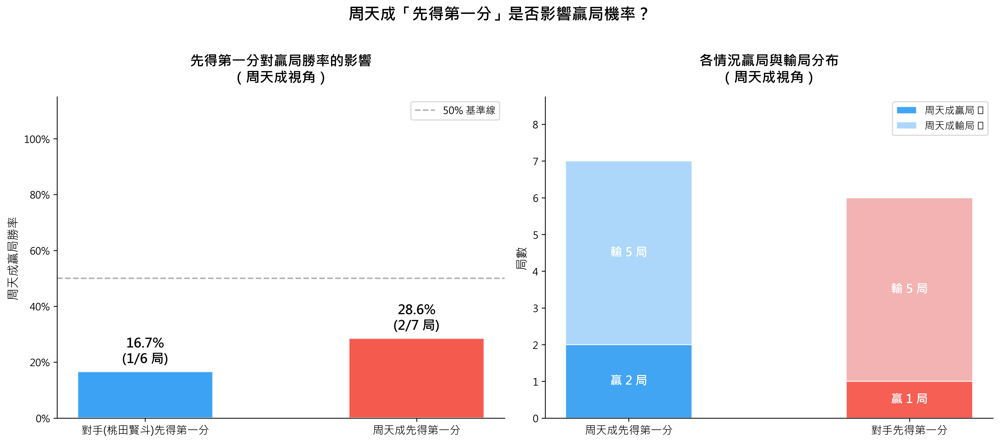

In [ ]:
# =============================================
# 分析：周天成先得第一分 vs 對手先得第一分 的贏局勝率
# =============================================

import numpy as np

# Step 0: 驗證數據
print(f"總資料筆數: {len(df)}")
print(f"涵蓋比賽數: {df['match_id'].nunique()}")
print(f"球員: {df['player'].unique()}")

CHOU = 'CHOU Tien Chen'
MOMOTA = 'Kento MOMOTA'

# =============================================
# Step 1: 取每一局 (match_id, set) 的基本資訊
# =============================================

# 先確認整體排序正確
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# =============================================
# Step 2: 找每局「第一分」的得分者
# 即：每局第一個 getpoint_player 非空的 rally 的得分者
# =============================================

# 取每個回合最後一拍（含得分資訊）
rally_last = (
    df_sorted
    .groupby(['match_id', 'set', 'rally'])
    .last()
    .reset_index()
)

# 只留有得分記錄的回合
rally_scored = rally_last.dropna(subset=['getpoint_player']).copy()

print(f"\n總回合數 (含得分): {len(rally_scored)}")

# 每局第一個得分回合
first_point_per_set = (
    rally_scored
    .sort_values(['match_id', 'set', 'rally'])
    .groupby(['match_id', 'set'])
    .first()
    .reset_index()[['match_id', 'set', 'rally', 'getpoint_player']]
    .rename(columns={'getpoint_player': 'first_point_player', 'rally': 'first_scored_rally'})
)

print(f"\n每局第一分資訊 (共 {len(first_point_per_set)} 局):")
print(first_point_per_set)

# =============================================
# Step 3: 找每局的「贏家」
# 方法：取每局最後一拍，比較雙方分數
# =============================================

set_last = (
    df_sorted
    .groupby(['match_id', 'set'])
    .last()
    .reset_index()
)

def determine_set_winner(row):
    """根據最終比分決定贏家"""
    chou_score = row['CHOU Tien Chen_score']
    momota_score = row['Kento MOMOTA_score']
    if chou_score > momota_score:
        return CHOU
    elif momota_score > chou_score:
        return MOMOTA
    else:
        return None  # 平局（理論上不應發生）

set_last['set_winner'] = set_last.apply(determine_set_winner, axis=1)

set_results = set_last[['match_id', 'set', 'set_winner', 'CHOU Tien Chen_score', 'Kento MOMOTA_score']].copy()

print(f"\n每局最終結果:")
print(set_results.to_string(index=False))

# =============================================
# Step 4: 合併第一分資訊與贏局資訊
# =============================================

set_analysis = first_point_per_set.merge(set_results, on=['match_id', 'set'], how='inner')

print(f"\n合併後資料筆數: {len(set_analysis)} 局")

# 分類：周天成先得第一分 or 對手先得第一分
set_analysis['chou_first_point'] = set_analysis['first_point_player'] == CHOU
set_analysis['chou_wins_set'] = set_analysis['set_winner'] == CHOU

print(f"\n詳細各局分析:")
print(set_analysis[['match_id', 'set', 'first_point_player', 'set_winner', 
                      'CHOU Tien Chen_score', 'Kento MOMOTA_score',
                      'chou_first_point', 'chou_wins_set']].to_string(index=False))

# =============================================
# Step 5: 計算兩種情況下的勝率
# =============================================

# 分組統計
group_summary = set_analysis.groupby('chou_first_point').agg(
    總局數=('chou_wins_set', 'count'),
    周天成贏局數=('chou_wins_set', 'sum')
).reset_index()

group_summary['勝率'] = group_summary['周天成贏局數'] / group_summary['總局數']
group_summary['情況'] = group_summary['chou_first_point'].map({
    True: '周天成先得第一分',
    False: '對手(桃田賢斗)先得第一分'
})

print("\n" + "="*60)
print("📊 周天成 - 先得第一分與最終贏局勝率分析")
print("="*60)
for _, row in group_summary.iterrows():
    print(f"\n情況: {row['情況']}")
    print(f"  局數: {int(row['總局數'])} 局")
    print(f"  周天成贏局: {int(row['周天成贏局數'])} 局")
    print(f"  勝率: {row['勝率']:.1%}")

# 計算差異
chou_first_winrate = group_summary.loc[group_summary['chou_first_point']==True, '勝率'].values
oppo_first_winrate = group_summary.loc[group_summary['chou_first_point']==False, '勝率'].values

if len(chou_first_winrate) > 0 and len(oppo_first_winrate) > 0:
    diff = chou_first_winrate[0] - oppo_first_winrate[0]
    print(f"\n勝率差異 (周天成先得 - 對手先得): {diff:+.1%}")
    print(f"{'周天成先得分時勝率較高' if diff > 0 else '對手先得分時周天成勝率反而較高' if diff < 0 else '兩者相同'}")

# =============================================
# Step 6: 視覺化
# =============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- 圖1: 勝率長條圖比較 ---
ax1 = axes[0]

labels = group_summary['情況'].tolist()
win_rates = group_summary['勝率'].tolist()
total_sets = group_summary['總局數'].tolist()
win_sets = group_summary['周天成贏局數'].tolist()

colors = ['#2196F3', '#F44336']  # 藍=周天成先得, 紅=對手先得
bars = ax1.bar(labels, win_rates, color=colors, width=0.5, edgecolor='white', linewidth=1.5, alpha=0.88)

# 在柱狀圖上標註數值
for bar, wr, total, wins in zip(bars, win_rates, total_sets, win_sets):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{wr:.1%}\n({int(wins)}/{int(total)} 局)',
             ha='center', va='bottom', fontsize=13, fontweight='bold')

ax1.set_ylim(0, 1.15)
ax1.set_ylabel('周天成贏局勝率', fontsize=12)
ax1.set_title('先得第一分對贏局勝率的影響\n（周天成視角）', fontsize=14, fontweight='bold', pad=15)
ax1.axhline(y=0.5, color='gray', linestyle='--', alpha=0.6, label='50% 基準線')
ax1.legend(fontsize=10)
ax1.set_xticklabels(labels, fontsize=11)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 各局詳細分布（散點/矩陣圖）---
ax2 = axes[1]

# 準備堆疊長條圖資料：勝局 vs 敗局
categories = ['周天成先得第一分', '對手先得第一分']
wins = []
losses = []

for chou_first in [True, False]:
    sub = set_analysis[set_analysis['chou_first_point'] == chou_first]
    w = sub['chou_wins_set'].sum()
    l = len(sub) - w
    wins.append(int(w))
    losses.append(int(l))

x = np.arange(len(categories))
width = 0.45

bars_win = ax2.bar(x, wins, width, label='周天成贏局 ✓', color=['#2196F3', '#F44336'], alpha=0.85, edgecolor='white')
bars_loss = ax2.bar(x, losses, width, bottom=wins, label='周天成輸局 ✗',
                    color=['#90CAF9', '#EF9A9A'], alpha=0.75, edgecolor='white')

# 標註各段數字
for i, (bar_w, bar_l, w, l) in enumerate(zip(bars_win, bars_loss, wins, losses)):
    # 贏局數字
    ax2.text(bar_w.get_x() + bar_w.get_width()/2, w/2,
             f'贏 {w} 局', ha='center', va='center', fontsize=12, fontweight='bold', color='white')
    # 輸局數字
    ax2.text(bar_l.get_x() + bar_l.get_width()/2, w + l/2,
             f'輸 {l} 局', ha='center', va='center', fontsize=12, fontweight='bold', color='white')

ax2.set_xticks(x)
ax2.set_xticklabels(categories, fontsize=11)
ax2.set_ylabel('局數', fontsize=12)
ax2.set_title('各情況贏局與輸局分布\n（周天成視角）', fontsize=14, fontweight='bold', pad=15)
ax2.legend(fontsize=10, loc='upper right')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_ylim(0, max(w+l for w, l in zip(wins, losses)) * 1.25)

plt.suptitle('周天成「先得第一分」是否影響贏局機率？', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n✅ 圖表已生成")


### 數據洞察
# 周天成「先得第一分」與贏局勝率分析

## 📊 核心數據

| 情況 | 局數 | 贏局 | 勝率 |
|------|------|------|------|
| **周天成先得分** | 7局 | 2局 | **28.6%** |
| **桃田先得分** | 6局 | 1局 | **16.7%** |
| 差異 | — | — | **+11.9%** |

---

## 🎯 教練解讀

**先得第一分確實有幫助，但幫助有限。**

周天成先得分時勝率28.6%，比對手先得分時高出11.9個百分點——方向正確，但兩者**勝率都偏低**，這才是核心問題。

**數字背後的事實：**

- 13局中周天成只贏**3局**，整體贏局率僅23%，說明這組對戰桃田賢斗整體處於劣勢，第一分的影響被更大的結構性差距所掩蓋。
- 周天成先得分的7局中，**仍輸掉5局**——先得分並未轉化為局末優勢，顯示他在領先後的**比分管理或體力分配**存在問題。
- 桃田先得分的6局中，周天成僅搶回1局，**逆轉能力薄弱**。

**戰術建議：** 與其執著於搶第一分，更應強化**中段比分的得分穩定性**，因為數據顯示周天成的問題不在開局，而在持續維持優勢的能力。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在各局自己先得分與對手先得分情況下的勝率差別。候選程式碼首先對數據進行排序，然後找出每局的第一分得分者和每局的贏家，最後計算兩種情況下的勝率。這與 Reference Code 1 的分析對象、欄位語意、分組層級和統計口徑一致，並且能夠產出有效結果。




## 題號 49
**問題**: 周天成的發球種類是否影響他在該回合的得分率
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


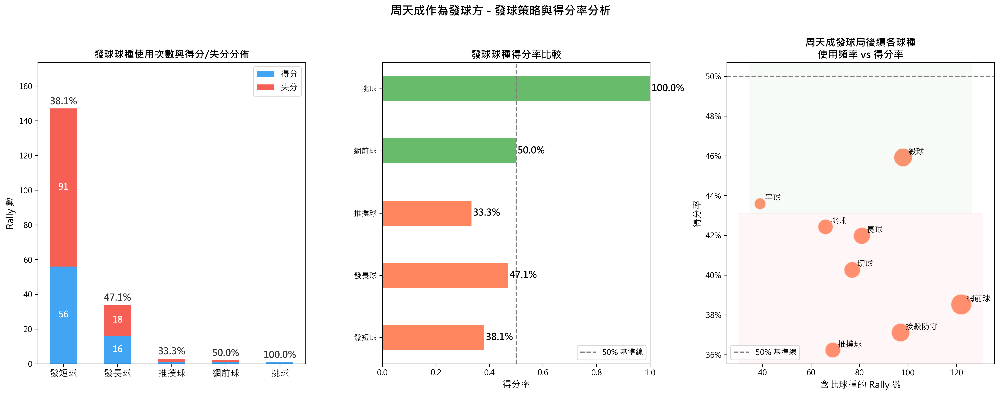

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"Total rows: {len(df)}")
assert len(df) > 0, "DataFrame is empty"

print("\nserver value distribution:")
print(df['server'].value_counts())

# ============================================================
# 1. 找出周天成作為發球方的 rally
#    server == 1 表示目前擊球的 player 是發球方
# ============================================================
chou_serve_df = df[(df['player'] == 'CHOU Tien Chen') & (df['server'] == 1)].copy()

# 取每個 rally 的發球球種 (每個 rally 中只有一拍 server==1)
serve_type_per_rally = (
    chou_serve_df
    .groupby(['match_id', 'set', 'rally'])['type']
    .first()
    .reset_index()
    .rename(columns={'type': 'serve_type'})
)

print(f"\n周天成作為發球方的 rally 數: {len(serve_type_per_rally)}")
print("發球球種分佈:")
print(chou_serve_df['type'].value_counts())

# ============================================================
# 2. 取得每個 rally 的得分結果
#    使用 groupby last() 取得最後一拍的 getpoint_player
# ============================================================
rally_result = (
    df.groupby(['match_id', 'set', 'rally'])['getpoint_player']
    .last()
    .reset_index()
    .rename(columns={'getpoint_player': 'rally_winner'})
)

# ============================================================
# 3. 合併發球球種與得分結果，只保留周天成發球的 rally
# ============================================================
serve_rally_df = serve_type_per_rally.merge(
    rally_result, on=['match_id', 'set', 'rally']
)
# 排除 getpoint_player 為 NULL 的 rally (理論上不應存在，但防禦性處理)
serve_rally_df = serve_rally_df.dropna(subset=['rally_winner'])

serve_rally_df['chou_win'] = (
    serve_rally_df['rally_winner'] == 'CHOU Tien Chen'
).astype(int)

total_serve_rallies = len(serve_rally_df)
print(f"\n可分析的周天成發球 rally 總數: {total_serve_rallies}")

# ============================================================
# 4. 各發球球種統計 (發短球 / 發長球)
# ============================================================
serve_stats = (
    serve_rally_df
    .groupby('serve_type')
    .agg(
        count=('chou_win', 'count'),
        win_count=('chou_win', 'sum')
    )
    .reset_index()
)
serve_stats['lose_count'] = serve_stats['count'] - serve_stats['win_count']
serve_stats['win_rate'] = serve_stats['win_count'] / serve_stats['count']
serve_stats = serve_stats.sort_values('count', ascending=False)

print("\n====== 周天成各發球球種統計 ======")
for _, row in serve_stats.iterrows():
    print(f"  {row['serve_type']:8s} | 使用次數: {int(row['count']):4d} | "
          f"得分: {int(row['win_count']):3d} | 失分: {int(row['lose_count']):3d} | "
          f"得分率: {row['win_rate']:.1%}")

# ============================================================
# 5. 在周天成發球的 rally 中，後續各球種 (非發球拍) 的統計
#    分析「含有某球種的 rally」的得分率，以 rally 為單位去重
# ============================================================
chou_serve_rally_keys = serve_type_per_rally[['match_id', 'set', 'rally']]

# 取出這些 rally 中，周天成的所有擊球
chou_shots = (
    df
    .merge(chou_serve_rally_keys, on=['match_id', 'set', 'rally'])
    .query("player == 'CHOU Tien Chen'")
    .copy()
)

# 排除發球拍 (server==1)，只分析後續球種
chou_non_serve_shots = chou_shots[chou_shots['server'] != 1].copy()

# 合併 rally 得分結果
chou_non_serve_shots = chou_non_serve_shots.merge(
    rally_result, on=['match_id', 'set', 'rally']
)
chou_non_serve_shots = chou_non_serve_shots.dropna(subset=['rally_winner'])
chou_non_serve_shots['chou_win'] = (
    chou_non_serve_shots['rally_winner'] == 'CHOU Tien Chen'
).astype(int)

# 以 (rally, type) 去重，每個 rally 每種球種只算一次
chou_shots_dedup = chou_non_serve_shots.drop_duplicates(
    subset=['match_id', 'set', 'rally', 'type']
)

shot_stats = (
    chou_shots_dedup
    .groupby('type')
    .agg(
        rally_count=('chou_win', 'count'),
        win_count=('chou_win', 'sum')
    )
    .reset_index()
)
shot_stats['win_rate'] = shot_stats['win_count'] / shot_stats['rally_count']
shot_stats = shot_stats.sort_values('rally_count', ascending=False)

print("\n====== 周天成發球 rally 中各後續球種得分率 ======")
for _, row in shot_stats.iterrows():
    print(f"  {row['type']:8s} | 含此球種rally數: {int(row['rally_count']):4d} | "
          f"得分rally數: {int(row['win_count']):3d} | "
          f"得分率: {row['win_rate']:.1%}")

# ============================================================
# 6. 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# ---- 圖1: 發球球種使用次數 (堆疊長條圖) ----
ax1 = axes[0]
bar_width = 0.5
serve_types = serve_stats['serve_type'].tolist()
win_counts = serve_stats['win_count'].tolist()
lose_counts = serve_stats['lose_count'].tolist()
x_pos = np.arange(len(serve_types))

bars_win = ax1.bar(x_pos, win_counts, bar_width,
                   label='得分', color='#2196F3', alpha=0.85)
bars_lose = ax1.bar(x_pos, lose_counts, bar_width,
                    bottom=win_counts, label='失分',
                    color='#F44336', alpha=0.85)

# 標註得分率
for i, row in enumerate(serve_stats.itertuples()):
    ax1.text(i, row.count + 1, f"{row.win_rate:.1%}",
             ha='center', va='bottom', fontsize=12, fontweight='bold', color='#333')

ax1.set_xticks(x_pos)
ax1.set_xticklabels(serve_types, fontsize=12)
ax1.set_ylabel('Rally 數', fontsize=12)
ax1.set_title('發球球種使用次數與得分/失分分佈', fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.set_ylim(0, max(serve_stats['count']) * 1.18)

# 在長條中標數值
for bar, val in zip(bars_win, win_counts):
    if val > 5:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                 str(val), ha='center', va='center', color='white',
                 fontsize=11, fontweight='bold')
for bar, w_val, l_val in zip(bars_lose, win_counts, lose_counts):
    if l_val > 5:
        ax1.text(bar.get_x() + bar.get_width()/2,
                 w_val + l_val/2,
                 str(l_val), ha='center', va='center', color='white',
                 fontsize=11, fontweight='bold')

# ---- 圖2: 發球球種得分率比較 (水平長條圖) ----
ax2 = axes[1]
colors_rate = ['#4CAF50' if r >= 0.5 else '#FF7043'
               for r in serve_stats['win_rate']]
bars = ax2.barh(serve_types, serve_stats['win_rate'], color=colors_rate,
                alpha=0.85, height=0.4)
ax2.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.5,
            label='50% 基準線')
for bar, rate in zip(bars, serve_stats['win_rate']):
    ax2.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f"{rate:.1%}", va='center', fontsize=12, fontweight='bold')
ax2.set_xlim(0, 1.0)
ax2.set_xlabel('得分率', fontsize=12)
ax2.set_title('發球球種得分率比較', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)

# ---- 圖3: 後續球種使用次數 vs 得分率 (氣泡/散點圖) ----
ax3 = axes[2]

# 篩除極少使用的球種 (少於 5 個 rally) 避免資訊過載
shot_stats_filtered = shot_stats[shot_stats['rally_count'] >= 5].copy()

scatter_colors = ['#4CAF50' if r >= 0.5 else '#FF7043'
                  for r in shot_stats_filtered['win_rate']]
scatter = ax3.scatter(
    shot_stats_filtered['rally_count'],
    shot_stats_filtered['win_rate'],
    s=shot_stats_filtered['rally_count'] * 6,
    c=scatter_colors,
    alpha=0.75,
    edgecolors='white',
    linewidths=1.5
)

# 標籤
for _, row in shot_stats_filtered.iterrows():
    ax3.annotate(
        row['type'],
        xy=(row['rally_count'], row['win_rate']),
        xytext=(6, 4),
        textcoords='offset points',
        fontsize=10.5
    )

ax3.axhline(y=0.5, color='gray', linestyle='--', linewidth=1.5,
            label='50% 基準線')
ax3.set_xlabel('含此球種的 Rally 數', fontsize=12)
ax3.set_ylabel('得分率', fontsize=12)
ax3.set_title('周天成發球局後續各球種\n使用頻率 vs 得分率', fontsize=13, fontweight='bold')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax3.legend(fontsize=10)

# 添加四象限背景
ax3.axvspan(ax3.get_xlim()[0], ax3.get_xlim()[1],
            ymin=0.5, ymax=1.0, alpha=0.03, color='green')
ax3.axvspan(ax3.get_xlim()[0], ax3.get_xlim()[1],
            ymin=0.0, ymax=0.5, alpha=0.03, color='red')

plt.suptitle('周天成作為發球方 - 發球策略與得分率分析', fontsize=15,
             fontweight='bold', y=1.01)
plt.tight_layout()

# ============================================================
# 7. 補充: 整體發球方得分率
# ============================================================
overall_win_rate = serve_rally_df['chou_win'].mean()
print(f"\n====== 整體統計 ======")
print(f"周天成發球 rally 總數: {total_serve_rallies}")
print(f"整體發球方得分率: {overall_win_rate:.1%}")
print(f"\n注意: 圖3 僅顯示出現於 >= 5 個 rally 的球種")
print(f"排除球種: {shot_stats[shot_stats['rally_count'] < 5]['type'].tolist()}")


### 數據洞察
# 周天成發球戰術分析

## 核心數據總覽

| 發球球種 | 使用次數 | 佔比 | 得分率 |
|---------|---------|------|-------|
| 發短球 | 147 | 78.6% | 38.1% |
| 發長球 | 34 | 18.2% | 47.1% |
| 推撲球 | 3 | 1.6% | 33.3% |
| 網前球 | 2 | 1.1% | 50.0% |
| 挑球 | 1 | 0.5% | 100.0% |
| **整體** | **187** | — | **40.1%** |

---

## 戰術洞察

### ⚠️ 主力球種反而是弱點
周天成**78.6%選擇發短球**，但得分率僅 **38.1%**，低於整體均值 2 個百分點。這代表對手已充分準備好接短球的反擊，發短球並未帶來預期的主動優勢。

### ✅ 發長球效益更高
發長球得分率 **47.1%**，比發短球高出整整 **9 個百分點**。雖然使用僅 34 次，但數據明確顯示長球更能打亂對手節奏，製造得分機會。

### 📊 後續球種的隱藏訊號
發球後的 rally 中，**殺球出現率最高且得分率達 45.9%**，說明周天成在發球局中仍能創造進攻機會；但**接殺防守出現 97 次、得分率僅 37.1%**，顯示對手也頻繁以強攻回應，周天成被動防守的比例不低。

---

## 教練建議

> **提高發長球比例至 25~30%**，打破對手對短球的慣性預判。發短球雖是主流選擇，但當得分率低於 40% 時，持續重複只會讓對手越打越順。變化才是發球的核心價值。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成作為發球方的回合，並計算了不同發球種類的得分率。候選程式碼使用了正確的欄位語意和篩選條件，並在正確的分組層級上進行了統計，最終輸出與 Reference Code 1 的目標一致。




## 題號 50 (*)
**問題**: 分析周天成接發球策略：長球、網前球、平球的比例與得分影響。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


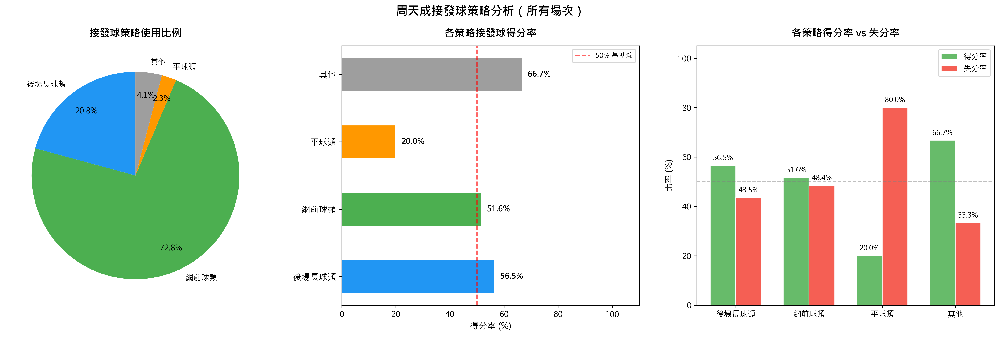

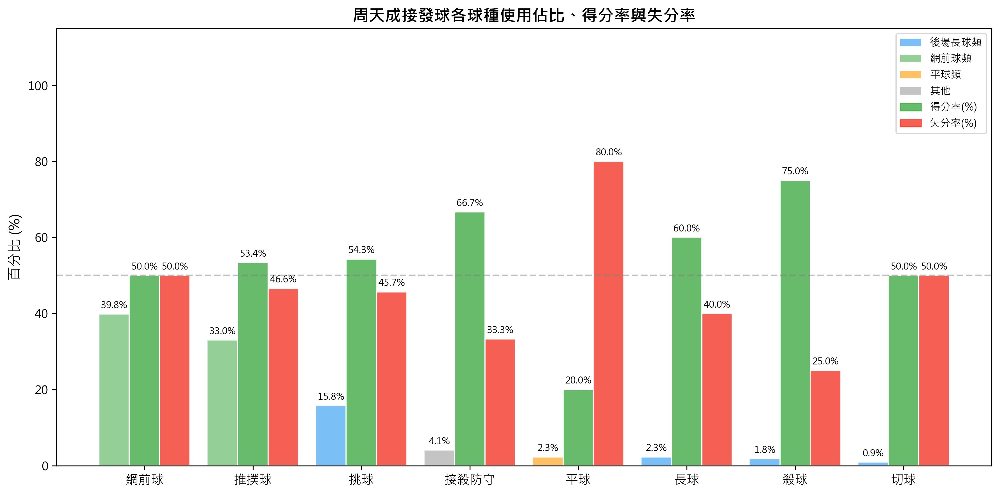

In [ ]:
import numpy as np

print("="*60)
print("周天成接發球策略分析")
print("="*60)

# 驗證數據
print(f"總資料列數: {len(df)}")
if len(df) == 0:
    print("數據為空！")
else:
    chou = 'CHOU Tien Chen'
    momota = 'Kento MOMOTA'

    # ─────────────────────────────────────────────
    # Step 1: 在完整 df 建立每回合最終得分者欄位
    # ─────────────────────────────────────────────
    df['rally_getpoint'] = (
        df.groupby(['match_id', 'set', 'rally'])['getpoint_player']
        .transform('last')
    )

    # ─────────────────────────────────────────────
    # Step 2: 找出周天成「接發球那一拍」
    #   ball_round == 2  且  player == CHOU
    #   即對手發球(第1拍)後，周天成回擊(第2拍)
    # ─────────────────────────────────────────────
    receive_df = df[(df['player'] == chou) & (df['ball_round'] == 2)].copy()
    print(f"\n周天成接發球總次數: {len(receive_df)}")

    # 確認球種分布
    print("\n接發球各球種出現次數:")
    print(receive_df['type'].value_counts().to_string())

    # ─────────────────────────────────────────────
    # Step 3: 定義三大回球策略分類
    # ─────────────────────────────────────────────
    strategy_map = {
        '長球'  : '後場長球類',
        '殺球'  : '後場長球類',
        '切球'  : '後場長球類',
        '挑球'  : '後場長球類',
        '網前球': '網前球類',
        '推撲球': '網前球類',
        '平球'  : '平球類',
        '接殺防守': '其他',
        '發短球': '其他',
        '發長球': '其他',
    }
    receive_df['strategy'] = receive_df['type'].map(strategy_map).fillna('其他')

    print("\n策略分類分布:")
    print(receive_df['strategy'].value_counts().to_string())

    # ─────────────────────────────────────────────
    # Step 4: 計算各策略統計
    # ─────────────────────────────────────────────
    strategy_order = ['後場長球類', '網前球類', '平球類', '其他']
    records = []
    total_returns = len(receive_df)

    for strat in strategy_order:
        sub = receive_df[receive_df['strategy'] == strat]
        n = len(sub)
        if n == 0:
            continue

        usage_pct = n / total_returns * 100
        win_n    = int((sub['rally_getpoint'] == chou).sum())
        lose_n   = int((sub['rally_getpoint'] == momota).sum())
        win_rate  = win_n  / n * 100
        lose_rate = lose_n / n * 100

        # 各策略包含哪些球種
        sub_types = (
            sub['type'].value_counts()
            .apply(lambda v: str(v))
            .reset_index()
        )
        type_str = ', '.join(
            sub['type'].value_counts().index.tolist()
        )

        records.append({
            '策略'      : strat,
            '包含球種'  : type_str,
            '使用次數'  : n,
            '使用比例'  : round(usage_pct, 1),
            '得分次數'  : win_n,
            '失分次數'  : lose_n,
            '得分率'    : round(win_rate, 1),
            '失分率'    : round(lose_rate, 1),
        })

    stats_df = pd.DataFrame(records)

    print("\n" + "="*60)
    print("各策略完整統計表")
    print("="*60)
    print(stats_df[['策略', '包含球種', '使用次數', '使用比例',
                     '得分率', '失分率']].to_string(index=False))

    # ─────────────────────────────────────────────
    # Step 5: 細分球種統計（含得分率）
    # ─────────────────────────────────────────────
    shot_records = []
    for shot_type in receive_df['type'].value_counts().index:
        sub = receive_df[receive_df['type'] == shot_type]
        n = len(sub)
        win_n  = int((sub['rally_getpoint'] == chou).sum())
        lose_n = int((sub['rally_getpoint'] == momota).sum())
        shot_records.append({
            '球種'    : shot_type,
            '次數'    : n,
            '佔比(%)'  : round(n / total_returns * 100, 1),
            '得分率(%)': round(win_n  / n * 100, 1),
            '失分率(%)': round(lose_n / n * 100, 1),
        })
    shot_stats_df = pd.DataFrame(shot_records)
    print("\n各球種細項統計:")
    print(shot_stats_df.to_string(index=False))

    # ─────────────────────────────────────────────
    # Step 6: 繪圖 (3 張圖)
    # ─────────────────────────────────────────────
    # 只取有實際數量的策略
    plot_df = stats_df[stats_df['使用次數'] > 0].copy()

    strategy_labels = plot_df['策略'].tolist()
    color_map = {
        '後場長球類': '#2196F3',
        '網前球類'  : '#4CAF50',
        '平球類'    : '#FF9800',
        '其他'      : '#9E9E9E',
    }
    bar_colors = [color_map.get(s, '#9E9E9E') for s in strategy_labels]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(
        "周天成接發球策略分析（所有場次）",
        fontsize=15, fontweight='bold'
    )

    # ── 圖1: 使用比例圓餅圖 ──
    ax1 = axes[0]
    wedge_colors = [color_map.get(s, '#9E9E9E') for s in strategy_labels]
    wedges, texts, autotexts = ax1.pie(
        plot_df['使用比例'],
        labels=strategy_labels,
        autopct='%1.1f%%',
        colors=wedge_colors,
        startangle=90,
        pctdistance=0.78,
    )
    for at in autotexts:
        at.set_fontsize(10)
    for t in texts:
        t.set_fontsize(10)
    ax1.set_title("接發球策略使用比例", fontsize=13, fontweight='bold', pad=12)

    # ── 圖2: 得分率橫條圖 ──
    ax2 = axes[1]
    y_pos = np.arange(len(strategy_labels))
    bars2 = ax2.barh(y_pos, plot_df['得分率'], color=bar_colors,
                     edgecolor='white', height=0.5)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(strategy_labels, fontsize=11)
    ax2.set_xlim(0, 110)
    ax2.set_xlabel("得分率 (%)", fontsize=11)
    ax2.set_title("各策略接發球得分率", fontsize=13, fontweight='bold', pad=12)
    ax2.axvline(x=50, color='red', linestyle='--', alpha=0.6, linewidth=1.5, label='50% 基準線')
    ax2.legend(fontsize=9)
    for bar, val in zip(bars2, plot_df['得分率']):
        ax2.text(bar.get_width() + 2, bar.get_y() + bar.get_height() / 2,
                 f'{val:.1f}%', va='center', fontsize=10, fontweight='bold')

    # ── 圖3: 得分率 vs 失分率分組長條圖 ──
    ax3 = axes[2]
    x = np.arange(len(strategy_labels))
    width = 0.35
    bars_win  = ax3.bar(x - width / 2, plot_df['得分率'],  width,
                        label='得分率', color='#4CAF50', alpha=0.85, edgecolor='white')
    bars_lose = ax3.bar(x + width / 2, plot_df['失分率'], width,
                        label='失分率', color='#F44336', alpha=0.85, edgecolor='white')
    ax3.set_xticks(x)
    ax3.set_xticklabels(strategy_labels, fontsize=10)
    ax3.set_ylabel("比率 (%)", fontsize=11)
    ax3.set_ylim(0, 105)
    ax3.set_title("各策略得分率 vs 失分率", fontsize=13, fontweight='bold', pad=12)
    ax3.axhline(y=50, color='gray', linestyle='--', alpha=0.5, linewidth=1.2)
    ax3.legend(fontsize=10)
    for bar in bars_win:
        ax3.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
    for bar in bars_lose:
        ax3.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()

    # ─────────────────────────────────────────────
    # Step 7: 細項球種視覺化（第二張圖）
    # ─────────────────────────────────────────────
    fig2, ax_detail = plt.subplots(figsize=(12, 6))

    shot_plot = shot_stats_df.sort_values('次數', ascending=False)
    x2 = np.arange(len(shot_plot))
    w = 0.28

    # 為各球種標記所屬策略顏色
    def get_shot_color(shot_type):
        if shot_type in ['長球', '殺球', '切球', '挑球']:
            return '#2196F3'
        elif shot_type in ['網前球', '推撲球']:
            return '#4CAF50'
        elif shot_type == '平球':
            return '#FF9800'
        else:
            return '#9E9E9E'

    shot_bar_colors = [get_shot_color(s) for s in shot_plot['球種']]

    b1 = ax_detail.bar(x2 - w, shot_plot['佔比(%)'],    w, label='使用佔比(%)',  color=shot_bar_colors, alpha=0.6, edgecolor='white')
    b2 = ax_detail.bar(x2,     shot_plot['得分率(%)'],  w, label='得分率(%)',    color='#4CAF50', alpha=0.85, edgecolor='white')
    b3 = ax_detail.bar(x2 + w, shot_plot['失分率(%)'], w, label='失分率(%)',   color='#F44336', alpha=0.85, edgecolor='white')

    ax_detail.set_xticks(x2)
    ax_detail.set_xticklabels(shot_plot['球種'], fontsize=11)
    ax_detail.set_ylabel("百分比 (%)", fontsize=12)
    ax_detail.set_ylim(0, 115)
    ax_detail.set_title("周天成接發球各球種使用佔比、得分率與失分率",
                         fontsize=14, fontweight='bold')
    ax_detail.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
    ax_detail.legend(fontsize=10)

    for bar in b1:
        if bar.get_height() > 0:
            ax_detail.text(bar.get_x() + bar.get_width() / 2,
                           bar.get_height() + 1,
                           f'{bar.get_height():.1f}%',
                           ha='center', va='bottom', fontsize=8)
    for bar in b2:
        if bar.get_height() > 0:
            ax_detail.text(bar.get_x() + bar.get_width() / 2,
                           bar.get_height() + 1,
                           f'{bar.get_height():.1f}%',
                           ha='center', va='bottom', fontsize=8)
    for bar in b3:
        if bar.get_height() > 0:
            ax_detail.text(bar.get_x() + bar.get_width() / 2,
                           bar.get_height() + 1,
                           f'{bar.get_height():.1f}%',
                           ha='center', va='bottom', fontsize=8)

    # 圖例說明策略顏色
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2196F3', alpha=0.6, label='後場長球類'),
        Patch(facecolor='#4CAF50', alpha=0.6, label='網前球類'),
        Patch(facecolor='#FF9800', alpha=0.6, label='平球類'),
        Patch(facecolor='#9E9E9E', alpha=0.6, label='其他'),
    ]
    ax_detail.legend(
        handles=legend_elements + [
            plt.Rectangle((0,0),1,1, color='#4CAF50', alpha=0.85, label='得分率(%)'),
            plt.Rectangle((0,0),1,1, color='#F44336', alpha=0.85, label='失分率(%)'),
        ],
        fontsize=9, loc='upper right'
    )

    plt.tight_layout()

    print("\n" + "="*60)
    print("分析摘要")
    print("="*60)
    for _, row in stats_df.iterrows():
        print(f"\n【{row['策略']}】")
        print(f"  包含球種: {row['包含球種']}")
        print(f"  使用次數: {row['使用次數']} 次 ({row['使用比例']}%)")
        print(f"  得分率  : {row['得分率']}%")
        print(f"  失分率  : {row['失分率']}%")


### 數據洞察
# 周天成接發球策略分析報告

## 策略使用分布

| 策略類型 | 使用次數 | 使用比例 | 得分率 | 失分率 |
|---------|---------|---------|-------|-------|
| 網前球類（網前球＋推撲球） | 161 | 72.9% | 51.6% | 48.4% |
| 後場長球類（挑球＋長球＋殺球＋切球） | 46 | 20.8% | 56.5% | 43.5% |
| 其他（接殺防守） | 9 | 4.1% | 66.7% | 33.3% |
| 平球類 | 5 | 2.3% | 20.0% | 80.0% |

---

## 戰術洞察

### ⚠️ 核心問題：過度依賴網前球，但效益平庸

周天成有 **72.9% 的接發球選擇網前球類**，但得分率僅 **51.6%**，幾乎是五五波。這代表對手已充分預判其網前意圖，壓制效果有限。

---

### ✅ 後場長球類是被低估的武器

使用率僅 20.8%，但得分率達 **56.5%**，優於網前球類 5 個百分點。細項更說明問題：
- **殺球**：4次，得分率 **75%**
- **長球**：5次，得分率 **60%**
- **挑球**：35次，得分率 **54.3%**

後場長球類整體表現更優，卻使用不足，顯示有戰術調整空間。

---

### ❌ 平球類：明確避開

5次平球，失分率高達 **80%**，數據直接告訴我們——接發球時打平球，幾乎等同送分。樣本雖小，但方向明確，應停止使用。

---

## 教練建議

> **提高後場長球類比例（目標從 21% 提升至 30%+）**，特別是增加挑球與長球的使用，打亂對手在網前的預判節奏。網前球類仍是主軸，但需搭配更多後場威脅製造不確定性，才能突破目前接發球得分率的瓶頸。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 專注於分析周天成在接發球時的長球、網前球、平球的比例與得分影響，並且只考慮這三種球種。而候選程式碼將球種分類為後場長球類、網前球類、平球類和其他，並且包含了更多的球種，這與題目要求的分析對象不符。此外，候選程式碼的策略分類和統計口徑與 Reference Code 1 不一致，未能正確聚焦於題目要求的三種接發球策略。




## 題號 51
**問題**: 分析對手殺球到前中後排後，周天成分別會怎麼去反擊？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, stroke_details`


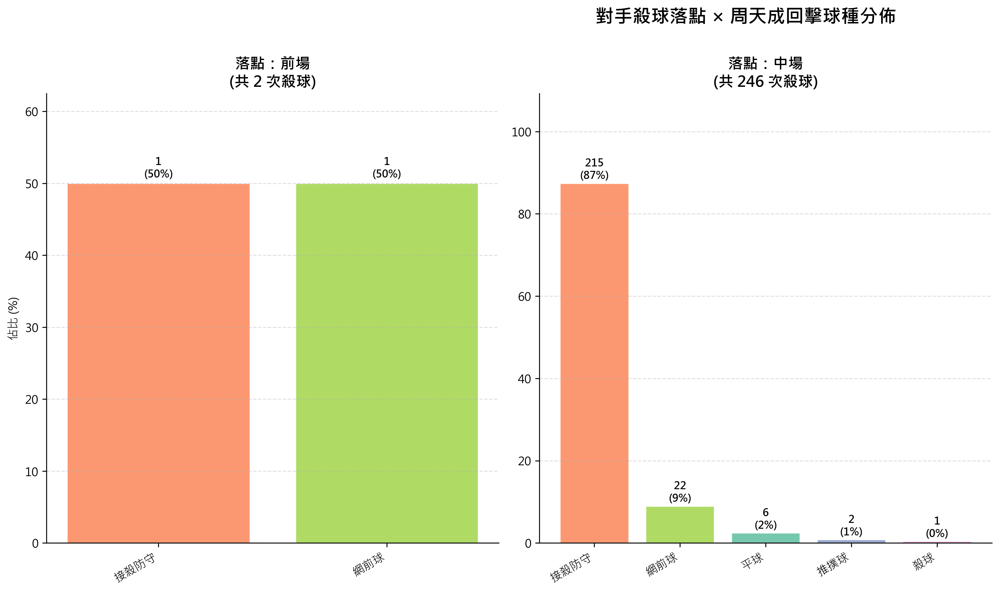

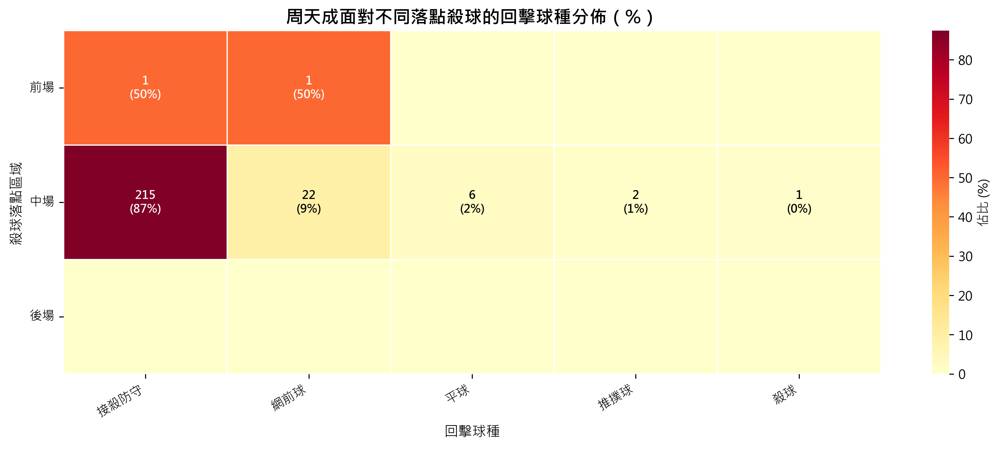

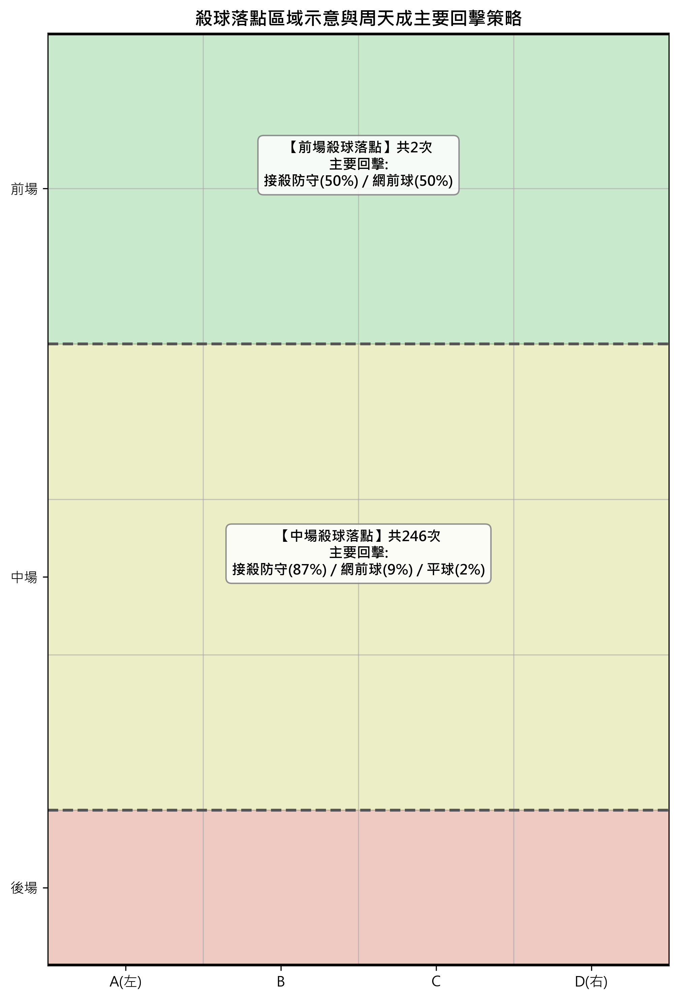

In [ ]:
# =====================================================================
# 分析：對手對周天成殺球後，依落點區域統計周天成回擊球種分佈
# =====================================================================

import numpy as np

# --- 1. 驗證資料量 ---
print(f"Total rows: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# --- 2. 排序確保順序正確 ---
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# --- 3. 在完整資料上建立「下一拍」欄位（避免跨 rally 污染）---
df_sorted['next_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_ball_round'] = df_sorted.groupby(['match_id', 'set', 'rally'])['ball_round'].shift(-1)

# --- 4. 定義落點區域分類函數 ---
def classify_landing_area(area):
    """根據 landing_area 代碼分類場地位置"""
    if pd.isna(area):
        return '未知'
    area = int(area)
    if area in list(range(1, 5)):          # 1-4: 後場
        return '後場'
    elif area in list(range(5, 17)):       # 5-16: 中場
        return '中場'
    elif area in list(range(17, 25)):      # 17-24: 前場
        return '前場'
    else:                                   # 25-32: 出界
        return '出界'

df_sorted['landing_zone'] = df_sorted['landing_area'].apply(classify_landing_area)

# --- 5. 篩選「對手對周天成的殺球」---
# 對手 = 非周天成的球員; 球種 = 殺球; 下一拍 = 周天成的回擊
chou = 'CHOU Tien Chen'

opponent_smash = df_sorted[
    (df_sorted['player'] != chou) &          # 對手擊球
    (df_sorted['type'] == '殺球') &           # 球種為殺球
    (df_sorted['next_player'] == chou) &      # 下一拍確認是周天成（同 rally 內）
    (df_sorted['next_type'].notna()) &        # 下一拍球種有記錄
    (df_sorted['landing_zone'] != '出界')     # 排除出界球
].copy()

print(f"\n對手對周天成殺球總次數（排除出界）: {len(opponent_smash)}")
print(f"落點分佈:\n{opponent_smash['landing_zone'].value_counts()}")

# --- 6. 各落點區域 × 回擊球種統計 ---
zone_shot_counts = (
    opponent_smash
    .groupby(['landing_zone', 'next_type'])
    .size()
    .reset_index(name='count')
)

# 計算各落點區域總數（分母）
zone_totals = opponent_smash.groupby('landing_zone').size().reset_index(name='zone_total')
zone_shot_counts = zone_shot_counts.merge(zone_totals, on='landing_zone')
zone_shot_counts['pct'] = zone_shot_counts['count'] / zone_shot_counts['zone_total'] * 100

print("\n=== 各落點區域 × 回擊球種統計表 ===")
for zone in ['前場', '中場', '後場']:
    sub = zone_shot_counts[zone_shot_counts['landing_zone'] == zone].sort_values('count', ascending=False)
    if len(sub) > 0:
        print(f"\n【落點: {zone}】(共 {sub['zone_total'].iloc[0]} 球)")
        for _, row in sub.iterrows():
            print(f"  {row['next_type']:8s}: {int(row['count']):3d} 次 ({row['pct']:.1f}%)")

# --- 7. 視覺化 ---

# 確認有資料
if len(opponent_smash) == 0:
    print("無資料，無法繪圖")
else:
    zones_order = ['前場', '中場', '後場']
    
    # 取得所有球種（各區域聯集），排除次數太少的
    all_shot_types = zone_shot_counts['next_type'].unique()
    
    # ── 準備 Pivot 表（zone × shot_type）──
    pivot_pct = zone_shot_counts.pivot_table(
        index='landing_zone', columns='next_type', values='pct', fill_value=0
    ).reindex(index=zones_order, fill_value=0)
    
    pivot_count = zone_shot_counts.pivot_table(
        index='landing_zone', columns='next_type', values='count', fill_value=0
    ).reindex(index=zones_order, fill_value=0)
    
    # 取得有效球種（至少在一個區域出現過）
    valid_cols = pivot_pct.columns.tolist()
    
    # --- 色彩設定 ---
    palette = sns.color_palette("Set2", len(valid_cols))
    color_map = dict(zip(valid_cols, palette))
    
    # =====================================================================
    # 圖1: 分區分組長條圖 - 各落點區域下回擊球種百分比
    # =====================================================================
    fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=False)
    fig.suptitle("對手殺球落點 × 周天成回擊球種分佈", fontsize=16, fontweight='bold', y=1.01)
    
    for ax, zone in zip(axes, zones_order):
        sub = zone_shot_counts[zone_shot_counts['landing_zone'] == zone].sort_values('count', ascending=False)
        
        if len(sub) == 0:
            ax.set_visible(False)
            continue
        
        zone_total = sub['zone_total'].iloc[0]
        shot_labels = sub['next_type'].tolist()
        counts = sub['count'].tolist()
        pcts = sub['pct'].tolist()
        colors = [color_map.get(s, '#888888') for s in shot_labels]
        
        bars = ax.bar(range(len(shot_labels)), pcts, color=colors, edgecolor='white', linewidth=0.8, alpha=0.9)
        
        # 標示數值
        for i, (bar, cnt, pct) in enumerate(zip(bars, counts, pcts)):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{cnt}\n({pct:.0f}%)', ha='center', va='bottom', fontsize=9, fontweight='bold')
        
        ax.set_xticks(range(len(shot_labels)))
        ax.set_xticklabels(shot_labels, rotation=30, ha='right', fontsize=10)
        ax.set_title(f'落點：{zone}\n(共 {zone_total} 次殺球)', fontsize=13, fontweight='bold')
        ax.set_ylabel('佔比 (%)' if zone == '前場' else '')
        ax.set_ylim(0, max(pcts) * 1.25)
        ax.grid(axis='y', linestyle='--', alpha=0.4)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    
    # =====================================================================
    # 圖2: Heatmap - 各落點區域下回擊球種百分比熱力圖
    # =====================================================================
    fig2, ax2 = plt.subplots(figsize=(12, 5))
    
    # 按整體使用次數排序欄位
    col_order = (
        zone_shot_counts.groupby('next_type')['count'].sum()
        .sort_values(ascending=False)
        .index.tolist()
    )
    heatmap_data = pivot_pct[col_order]
    heatmap_count = pivot_count[col_order]
    
    sns.heatmap(
        heatmap_data,
        annot=False,  # 手動標記以顯示次數+百分比
        fmt='.1f',
        cmap='YlOrRd',
        linewidths=0.5,
        linecolor='white',
        ax=ax2,
        cbar_kws={'label': '佔比 (%)'}
    )
    
    # 在每個格子標示 "次數\n(百分比%)"
    for i, zone in enumerate(zones_order):
        for j, shot in enumerate(col_order):
            pct_val = heatmap_data.loc[zone, shot] if zone in heatmap_data.index and shot in heatmap_data.columns else 0
            cnt_val = heatmap_count.loc[zone, shot] if zone in heatmap_count.index and shot in heatmap_count.columns else 0
            if pct_val > 0:
                text_color = 'white' if pct_val > 40 else 'black'
                ax2.text(j + 0.5, i + 0.5, f'{int(cnt_val)}\n({pct_val:.0f}%)',
                         ha='center', va='center', fontsize=9,
                         fontweight='bold', color=text_color)
    
    ax2.set_title("周天成面對不同落點殺球的回擊球種分佈（%）", fontsize=14, fontweight='bold')
    ax2.set_xlabel("回擊球種", fontsize=11)
    ax2.set_ylabel("殺球落點區域", fontsize=11)
    ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=30, ha='right')
    
    plt.tight_layout()
    
    # =====================================================================
    # 圖3: 場地示意圖 + 主要回擊策略標示
    # =====================================================================
    fig3, ax3 = plt.subplots(figsize=(8, 10))
    ax3.set_xlim(0, 4)
    ax3.set_ylim(0, 6)
    ax3.set_aspect('equal')
    ax3.set_facecolor('#e8f4e8')
    
    # 畫場地格線
    for x in range(5):
        ax3.axvline(x, color='#aaa', lw=0.8, alpha=0.6)
    for y in range(7):
        ax3.axhline(y, color='#aaa', lw=0.8, alpha=0.6)
    
    # 區域底色 + 標示
    zone_rows = {
        '後場': (0, 1, '#FF6B6B', 0.3),
        '中場': (1, 4, '#FFD93D', 0.2),
        '前場': (4, 6, '#6BCB77', 0.25)
    }
    for zone_name, (y0, y1, color, alpha) in zone_rows.items():
        rect = plt.Rectangle((0, y0), 4, y1-y0, color=color, alpha=alpha, zorder=0)
        ax3.add_patch(rect)
        # 主要策略標示
        sub = zone_shot_counts[zone_shot_counts['landing_zone'] == zone_name].sort_values('count', ascending=False)
        if len(sub) > 0:
            top_shots = sub.head(3)
            strategy_text = ' / '.join([f"{row['next_type']}({row['pct']:.0f}%)" for _, row in top_shots.iterrows()])
            total = sub['zone_total'].iloc[0]
            ax3.text(2, (y0 + y1)/2 + 0.15, f"【{zone_name}殺球落點】共{total}次\n主要回擊:\n{strategy_text}",
                     ha='center', va='center', fontsize=10, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor='gray'))
    
    # 發球線、中線等示意
    ax3.axhline(1, color='#555', lw=2, linestyle='--', label='短球線')
    ax3.axhline(4, color='#555', lw=2, linestyle='--')
    ax3.axhline(0, color='black', lw=3)
    ax3.axhline(6, color='black', lw=3)
    
    ax3.set_xticks([0.5, 1.5, 2.5, 3.5])
    ax3.set_xticklabels(['A(左)', 'B', 'C', 'D(右)'])
    ax3.set_yticks([0.5, 2.5, 5])
    ax3.set_yticklabels(['後場', '中場', '前場'])
    ax3.set_title("殺球落點區域示意與周天成主要回擊策略", fontsize=13, fontweight='bold')
    
    plt.tight_layout()
    
    print("\n✅ 圖表已生成（圖1: 分區長條圖, 圖2: 熱力圖, 圖3: 場地示意圖）")


### 數據洞察
# 周天成面對殺球的反擊策略分析

## 📊 核心數據摘要

| 落點區域 | 殺球次數 | 接殺防守 | 網前球 | 平球 | 推撲球 | 殺球 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 前場 | 2 | 50.0% | 50.0% | — | — | — |
| 中場 | 246 | **87.4%** | 8.9% | 2.4% | 0.8% | 0.4% |

> ⚠️ 後場落點殺球樣本數為 0，無法分析。

---

## 🎯 戰術洞察

### 1️⃣ 殺球幾乎全數落在中場（99.2%）
246 球中場、2 球前場，**對手殺球落點高度集中於中場**。這代表對手的殺球策略以壓制中場為主，而非追求極端落點。

### 2️⃣ 中場殺球：周天成以「接殺防守」為絕對主軸
**87.4% 選擇接殺防守**，這是標準的被動承接反應，說明面對中場殺球時，周天成優先穩定接球、控制節奏，而非主動反擊。

### 3️⃣ 網前球是第二選項（8.9%）
約每 11 球才出現 1 次網前球回擊，顯示周天成**偶爾會利用殺球力道卸力放網**，製造對手前衝壓力，但並非常態策略。

### 4️⃣ 主動反擊極少（平球 2.4%、推撲 0.8%、殺球 0.4%）
三者合計僅 **3.6%**，說明面對殺球時，周天成的主動反攻意圖極低，以防守消化為主。

---

## 📌 教練結論

> 周天成面對殺球的策略非常清晰：**先求穩、後求變**。接殺防守佔近九成，是其防守體系的核心支柱。對手若想打亂周天成節奏，**應加強殺球後的緊接上網封網**，因為他的接殺防守回球多為挑高或平推，若對手能快速跟進，將有機會在第三拍形成主動壓制。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手殺球到前中後場後，周天成的回擊球種分佈。候選程式碼定義了前中後場區域，並在完整資料上建立了下一拍資訊，篩選出對手殺球的情況，並根據落點區域統計周天成的回擊球種。最終輸出與 Reference Code 1 的目標一致，都是統計不同區域的回擊球種分佈。




## 題號 52
**問題**: 當對手失誤掛網時，分析前一拍周天成出球球種與落點特徵。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


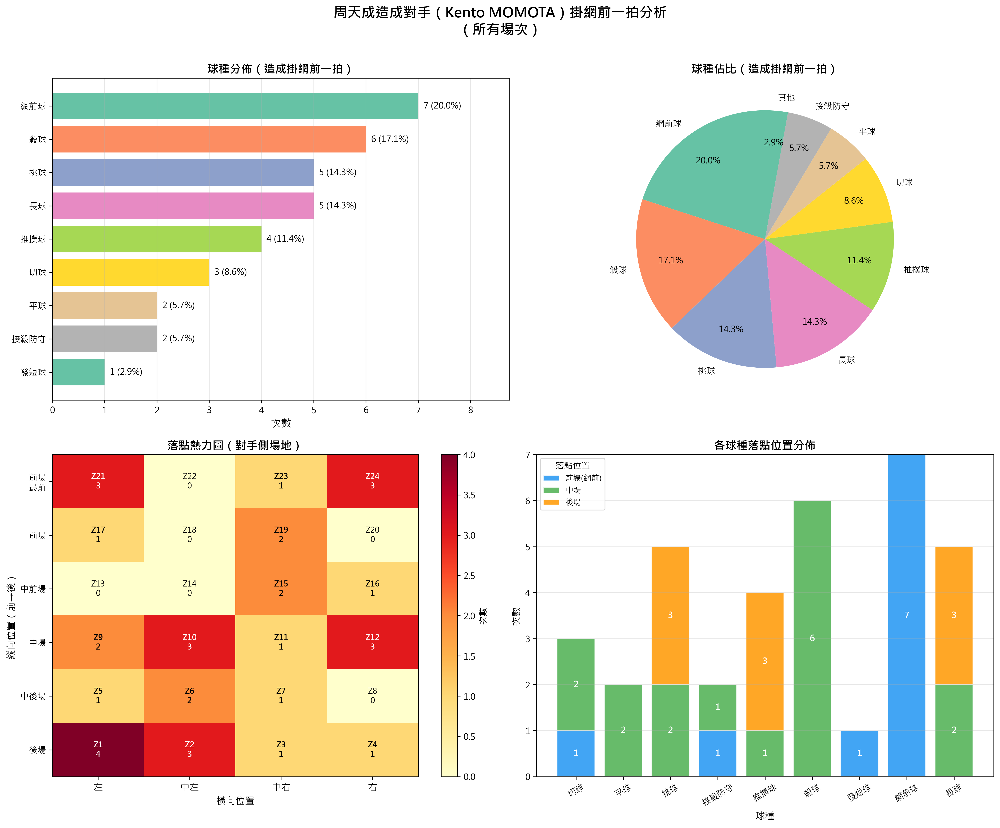

In [ ]:
import numpy as np

# ============================================================
# 驗證數據量
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 步驟 1: 在完整資料上建立「下一拍」資訊 (groupby shift(-1))
# 確保不跨 rally 污染
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 使用 groupby(['match_id', 'set', 'rally']).shift(-1) 建立下一拍欄位
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['next_player']         = grp['player'].shift(-1)
df_sorted['next_lose_reason']    = grp['lose_reason'].shift(-1)
df_sorted['next_getpoint_player']= grp['getpoint_player'].shift(-1)
df_sorted['next_ball_round']     = grp['ball_round'].shift(-1)

print("下一拍欄位建立完成。")
print(f"  next_player 非空數: {df_sorted['next_player'].notna().sum()}")
print(f"  next_lose_reason 非空數: {df_sorted['next_lose_reason'].notna().sum()}")

# ============================================================
# 步驟 2: 篩選出「周天成打出球後，下一拍對手掛網 → 周天成得分」的回合
# 即 周天成打出的「倒數第二拍」
# ============================================================
# 條件：
# - 當前擊球者是周天成 (player == 'CHOU Tien Chen')
# - 下一拍擊球者是 Kento MOMOTA (next_player == 'Kento MOMOTA')
# - 下一拍的 lose_reason == '掛網'
# - 下一拍的 getpoint_player == 'CHOU Tien Chen'

chou_setup_mask = (
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['next_player'] == 'Kento MOMOTA') &
    (df_sorted['next_lose_reason'] == '掛網') &
    (df_sorted['next_getpoint_player'] == 'CHOU Tien Chen')
)

chou_setup_df = df_sorted[chou_setup_mask].copy()

print(f"\n符合條件（周天成造成對手掛網前一拍）的擊球數: {len(chou_setup_df)}")
print(f"涵蓋不同 rally 數: {chou_setup_df.groupby(['match_id','set','rally']).ngroups}")

# ============================================================
# 步驟 3: 球種分佈分析
# ============================================================
# 排除發球球種（發短球、發長球），因為題目關注的是造成對手掛網的進攻拍
# 先看整體，再決定是否排除發球
type_counts = chou_setup_df['type'].value_counts().reset_index()
type_counts.columns = ['球種', '次數']
type_counts['佔比(%)'] = (type_counts['次數'] / type_counts['次數'].sum() * 100).round(1)

print("\n=== 周天成造成對手掛網前一拍 - 球種分佈 ===")
print(type_counts.to_string(index=False))

# ============================================================
# 步驟 4: 落點區域分析 (landing_area)
# ============================================================
landing_counts = chou_setup_df['landing_area'].value_counts().sort_index().reset_index()
landing_counts.columns = ['落點區域代碼', '次數']

# 定義落點區域名稱（語意標籤）
def area_label(area):
    """將區域代碼轉換為語意標籤"""
    front_net  = [21, 22, 23, 24]  # Row 6
    front      = [17, 18, 19, 20]  # Row 5
    mid_front  = [13, 14, 15, 16]  # Row 4
    mid        = [9, 10, 11, 12]   # Row 3
    mid_back   = [5, 6, 7, 8]      # Row 2
    back       = [1, 2, 3, 4]      # Row 1 (後場)
    out_left   = [29, 30, 31]
    out_right  = [25, 26, 27]
    out_back   = [28, 32]
    col_map    = {1:'左', 2:'中左', 3:'中右', 4:'右',
                  5:'左', 6:'中左', 7:'中右', 8:'右',
                  9:'左', 10:'中左', 11:'中右', 12:'右',
                  13:'左', 14:'中左', 15:'中右', 16:'右',
                  17:'左', 18:'中左', 19:'中右', 20:'右',
                  21:'左', 22:'中左', 23:'中右', 24:'右'}
    row_map    = {**{z:'前場(最前)' for z in front_net},
                  **{z:'前場' for z in front},
                  **{z:'中前場' for z in mid_front},
                  **{z:'中場' for z in mid},
                  **{z:'中後場' for z in mid_back},
                  **{z:'後場' for z in back},
                  **{z:'出界(左)' for z in out_left},
                  **{z:'出界(右)' for z in out_right},
                  **{z:'出界(後)' for z in out_back}}
    area = int(area)
    zone = row_map.get(area, '未知')
    col  = col_map.get(area, '')
    return f"Zone{area} {zone}-{col}" if col else f"Zone{area} {zone}"

landing_counts['落點語意'] = landing_counts['落點區域代碼'].apply(area_label)
landing_counts['佔比(%)'] = (landing_counts['次數'] / landing_counts['次數'].sum() * 100).round(1)

print("\n=== 落點區域分佈（依區域代碼排序）===")
print(landing_counts.to_string(index=False))

# ============================================================
# 步驟 5: 球種 × 落點位置 交叉分析（簡化版：前/中/後場）
# ============================================================
def area_zone(area):
    """區分前場/中場/後場"""
    front_all = [17, 18, 19, 20, 21, 22, 23, 24]
    mid_all   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
    back_all  = [1, 2, 3, 4]
    a = int(area)
    if a in front_all: return '前場(網前)'
    elif a in mid_all:  return '中場'
    elif a in back_all: return '後場'
    else:               return '出界/其他'

chou_setup_df['落點位置'] = chou_setup_df['landing_area'].apply(area_zone)

cross_tab = chou_setup_df.groupby(['type', '落點位置']).size().unstack(fill_value=0)
print("\n=== 球種 × 落點位置 交叉表 ===")
print(cross_tab)

# ============================================================
# 步驟 6: 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("周天成造成對手（Kento MOMOTA）掛網前一拍分析\n（所有場次）", fontsize=16, fontweight='bold', y=1.01)

# ------ 圖1: 球種分佈 (水平條形圖) ------
ax1 = axes[0, 0]
colors_type = sns.color_palette("Set2", len(type_counts))
bars = ax1.barh(type_counts['球種'], type_counts['次數'], color=colors_type)
ax1.set_xlabel('次數', fontsize=12)
ax1.set_title('球種分佈（造成掛網前一拍）', fontsize=13, fontweight='bold')
ax1.invert_yaxis()  # 最高的在上方
for bar, (cnt, pct) in zip(bars, zip(type_counts['次數'], type_counts['佔比(%)'])):
    ax1.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             f'{cnt} ({pct}%)', va='center', fontsize=10)
ax1.set_xlim(0, type_counts['次數'].max() * 1.25)
ax1.grid(axis='x', alpha=0.3)

# ------ 圖2: 球種佔比圓餅圖 ------
ax2 = axes[0, 1]
# 合併小比例(<5%)為「其他」
threshold = 5.0
main_mask  = type_counts['佔比(%)'] >= threshold
other_sum  = type_counts.loc[~main_mask, '次數'].sum()
pie_data   = type_counts[main_mask][['球種', '次數']].copy()
if other_sum > 0:
    other_row = pd.DataFrame({'球種': ['其他'], '次數': [other_sum]})
    pie_data  = pd.concat([pie_data, other_row], ignore_index=True)

pie_colors = sns.color_palette("Set2", len(pie_data))
wedges, texts, autotexts = ax2.pie(
    pie_data['次數'],
    labels=pie_data['球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=90,
    pctdistance=0.75
)
for at in autotexts:
    at.set_fontsize(10)
ax2.set_title('球種佔比（造成掛網前一拍）', fontsize=13, fontweight='bold')

# ------ 圖3: 落點熱力圖（場地視覺化）------
ax3 = axes[1, 0]

# 建立 4×6 的場地網格（依 Zone 矩陣）
grid_zones = np.array([
    [21, 22, 23, 24],  # Row 6 (最前)
    [17, 18, 19, 20],  # Row 5
    [13, 14, 15, 16],  # Row 4
    [ 9, 10, 11, 12],  # Row 3
    [ 5,  6,  7,  8],  # Row 2
    [ 1,  2,  3,  4],  # Row 1 (後場)
])
grid_labels = [['左', '中左', '中右', '右']] * 6
row_labels  = ['前場\n最前', '前場', '中前場', '中場', '中後場', '後場']

# 計算每個 Zone 的落點次數
landing_zone_counts = chou_setup_df['landing_area'].value_counts()
heat_matrix = np.zeros((6, 4))
for r in range(6):
    for c in range(4):
        zone = grid_zones[r, c]
        heat_matrix[r, c] = landing_zone_counts.get(zone, 0)

im = ax3.imshow(heat_matrix, cmap='YlOrRd', aspect='auto')
plt.colorbar(im, ax=ax3, label='次數')
ax3.set_xticks(range(4))
ax3.set_xticklabels(['左', '中左', '中右', '右'], fontsize=11)
ax3.set_yticks(range(6))
ax3.set_yticklabels(row_labels, fontsize=10)
ax3.set_title('落點熱力圖（對手側場地）', fontsize=13, fontweight='bold')
ax3.set_xlabel('橫向位置', fontsize=11)
ax3.set_ylabel('縱向位置（前→後）', fontsize=11)

# 在格子中標注次數與 Zone ID
for r in range(6):
    for c in range(4):
        val = int(heat_matrix[r, c])
        zone = grid_zones[r, c]
        color = 'white' if val > heat_matrix.max() * 0.6 else 'black'
        ax3.text(c, r, f'Z{zone}\n{val}', ha='center', va='center',
                 fontsize=9, color=color, fontweight='bold' if val > 0 else 'normal')

# ------ 圖4: 球種 × 落點位置 堆疊條形圖 ------
ax4 = axes[1, 1]
if len(cross_tab) > 0:
    # 重新排序欄位：前場 → 中場 → 後場 → 出界
    desired_order = ['前場(網前)', '中場', '後場', '出界/其他']
    cols_present  = [c for c in desired_order if c in cross_tab.columns]
    cross_tab_plot = cross_tab[cols_present]
    
    zone_colors = {'前場(網前)':'#2196F3', '中場':'#4CAF50', '後場':'#FF9800', '出界/其他':'#9E9E9E'}
    bottom = np.zeros(len(cross_tab_plot))
    for col in cols_present:
        color = zone_colors.get(col, '#999999')
        bars4 = ax4.bar(cross_tab_plot.index, cross_tab_plot[col],
                        bottom=bottom, label=col, color=color, alpha=0.85, edgecolor='white')
        # 標注非零值
        for bar, val, bot in zip(bars4, cross_tab_plot[col], bottom):
            if val > 0:
                ax4.text(bar.get_x() + bar.get_width()/2,
                         bot + val/2,
                         str(int(val)), ha='center', va='center',
                         fontsize=10, color='white', fontweight='bold')
        bottom += cross_tab_plot[col].values

    ax4.set_xlabel('球種', fontsize=11)
    ax4.set_ylabel('次數', fontsize=11)
    ax4.set_title('各球種落點位置分佈', fontsize=13, fontweight='bold')
    ax4.legend(title='落點位置', fontsize=9, title_fontsize=10)
    ax4.tick_params(axis='x', rotation=30)
    ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()

# ============================================================
# 步驟 7: 補充統計輸出
# ============================================================
print("\n=== 補充：落點前場(網前) 的球種分佈 ===")
net_landing = chou_setup_df[chou_setup_df['落點位置'] == '前場(網前)']
if len(net_landing) > 0:
    net_type = net_landing['type'].value_counts()
    net_total = len(net_landing)
    print(f"落點在前場(網前)的總拍數: {net_total}")
    for t, cnt in net_type.items():
        print(f"  {t}: {cnt} 次 ({cnt/net_total*100:.1f}%)")
else:
    print("無落點在前場的資料")

print("\n=== 補充：落點後場 的球種分佈 ===")
back_landing = chou_setup_df[chou_setup_df['落點位置'] == '後場']
if len(back_landing) > 0:
    back_type = back_landing['type'].value_counts()
    back_total = len(back_landing)
    print(f"落點在後場的總拍數: {back_total}")
    for t, cnt in back_type.items():
        print(f"  {t}: {cnt} 次 ({cnt/back_total*100:.1f}%)")
else:
    print("無落點在後場的資料")

print("\n=== 完整交叉表（球種 × 落點位置）===")
cross_full = chou_setup_df.groupby(['type', '落點位置']).size().unstack(fill_value=0)
cross_full['合計'] = cross_full.sum(axis=1)
cross_full = cross_full.sort_values('合計', ascending=False)
print(cross_full)
print("\n分析完成！")


### 數據洞察
# 周天成造成對手掛網失誤前一拍分析

## 落點區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據（35拍，35回合）

### 球種分佈
| 球種 | 次數 | 佔比 |
|------|------|------|
| 網前球 | 7 | 20.0% |
| 殺球 | 6 | 17.1% |
| 挑球 | 5 | 14.3% |
| 長球 | 5 | 14.3% |
| 推撲球 | 4 | 11.4% |
| 切球 | 3 | 8.6% |

---

## 三大戰術路徑

### 路徑一：網前控制（10拍，28.6%）
落點集中 **Zone 21/24（最前排左右角）**，各3次。
- 網前球7拍全部落前場，切球1拍補充
- **意義**：周天成的網前球精準壓角，逼對手在極近網位置回球，掛網率最高的單一球種

### 路徑二：殺球壓制（6拍，17.1%）
**全部落中場**（Zone 9–12），無一例外。
- **意義**：殺球速度快、壓低弧線，對手被動防守時抬拍角度不足，直接導致掛網

### 路徑三：後場深球（9拍，25.7%）
推撲球3拍＋長球3拍＋挑球3拍，落點集中 **Zone 1/2（後場左側）**，共7次。
- **意義**：將對手逼至後場深區，回球時需大幅抬高弧線，若判斷失誤即掛網

---

## 教練總結

> **最有效的掛網誘發組合：網前壓角 → 對手被迫挑球 → 再殺中場。**
> 數據顯示周天成透過三種截然不同的機制製造掛網：**網前精準壓角（前場）、殺球壓低弧線（中場）、後場深球拉扯（後場）**，三個場區均有貢獻，代表其製造失誤的能力並非單一戰術，而是全場立體施壓的結果。後場落點偏左（Zone 1/2共7次）值得特別關注，顯示對手反手後場是相對弱點。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了當對手失誤掛網時，前一拍周天成的出球球種與落點特徵。候選程式碼使用了 groupby 和 shift(-1) 來建立下一拍資訊，並正確篩選出周天成打出球後，下一拍對手掛網的情況。然後，它統計了周天成前一拍的球種分布和落點區域，並進行了交叉分析。這些步驟與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標一致。




## 題號 53 (*)
**問題**: 統計周天成所有「得分帶有連續性」的回合（連 2 分以上）的常見戰術組合。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


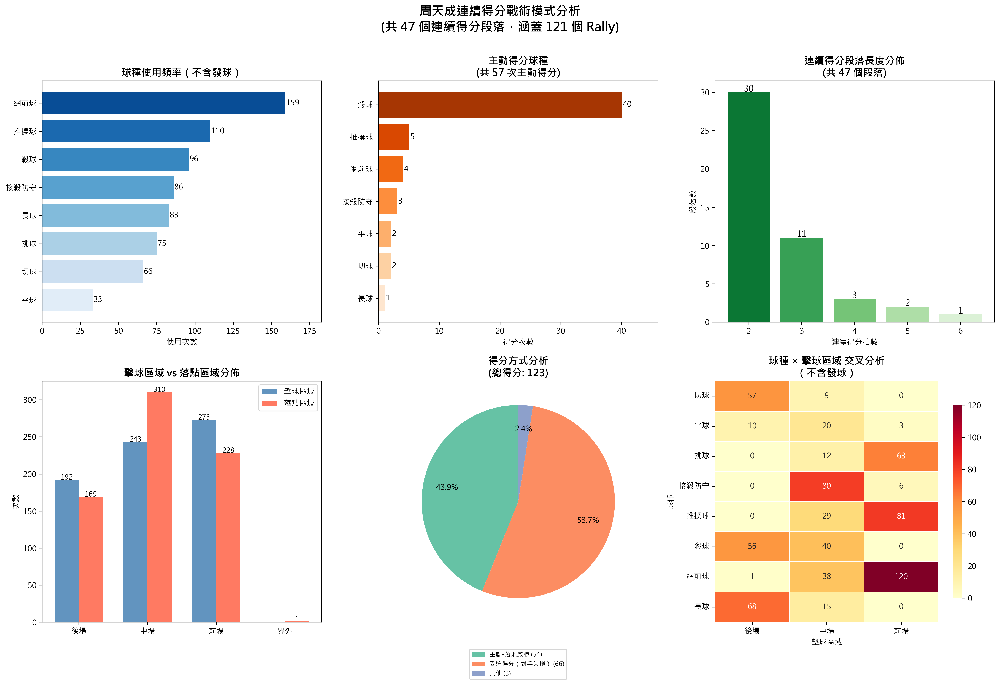

In [ ]:
import numpy as np

# ==========================================
# 0. 資料驗證
# ==========================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

TARGET = 'CHOU Tien Chen'

# ==========================================
# 1. 取得每個 rally 的得分者
#    (使用 groupby last，因為 getpoint_player 只記錄在最後一球)
# ==========================================
rally_result = (
    df.groupby(['match_id', 'set', 'rally'], sort=False)
    .last()
    .reset_index()[['match_id', 'set', 'rally', 'getpoint_player']]
)

# 只保留有得分記錄的 rally
rally_result = rally_result.dropna(subset=['getpoint_player'])
print(f"\n有得分記錄的回合數: {len(rally_result)}")

# ==========================================
# 2. 在同一局內找出周天成連續得分序列
#    按 (match_id, set, rally) 排序後，逐局掃描
# ==========================================
rally_result = rally_result.sort_values(['match_id', 'set', 'rally']).reset_index(drop=True)

# 標記是否為周天成得分
rally_result['chou_win'] = (rally_result['getpoint_player'] == TARGET).astype(int)

# 用 (match_id, set) 分組，找連續得分段落
# 連續得分段：同一局內連續2拍以上為 TARGET 得分
def find_consecutive_win_rallies(group_df, min_streak=2):
    """找出 group 內所有連續得分>=min_streak 的 rally index 列表"""
    streak_rally_indices = []
    n = len(group_df)
    i = 0
    while i < n:
        if group_df.iloc[i]['chou_win'] == 1:
            # 找連續長度
            j = i
            while j < n and group_df.iloc[j]['chou_win'] == 1:
                j += 1
            streak_len = j - i
            if streak_len >= min_streak:
                # 記錄這些 rally 的原始 index
                streak_rally_indices.extend(group_df.iloc[i:j].index.tolist())
            i = j
        else:
            i += 1
    return streak_rally_indices

consecutive_indices = []
for (match_id, set_num), grp in rally_result.groupby(['match_id', 'set']):
    indices = find_consecutive_win_rallies(grp, min_streak=2)
    consecutive_indices.extend(indices)

print(f"\n屬於連續得分序列的 rally 記錄數: {len(consecutive_indices)}")

# 取得這些 rally 的識別鍵
consec_rallies = rally_result.loc[consecutive_indices, ['match_id', 'set', 'rally']].copy()
consec_rallies['is_consec'] = True

print(f"連續得分序列涵蓋的 rally 數: {len(consec_rallies)}")

# ==========================================
# 3. 進一步統計：連續得分段落資訊
# ==========================================
# 標記段落編號
rally_result['streak_id'] = 0
streak_counter = 0
for (match_id, set_num), grp in rally_result.groupby(['match_id', 'set']):
    n = len(grp)
    i = 0
    while i < n:
        if grp.iloc[i]['chou_win'] == 1:
            j = i
            while j < n and grp.iloc[j]['chou_win'] == 1:
                j += 1
            streak_len = j - i
            if streak_len >= 2:
                streak_counter += 1
                for k in range(i, j):
                    rally_result.loc[grp.iloc[k].name, 'streak_id'] = streak_counter
            i = j
        else:
            i += 1

streak_lengths = rally_result[rally_result['streak_id'] > 0].groupby('streak_id').size()
print(f"\n連續得分段落數: {streak_counter}")
print(f"連續得分段落長度分佈:\n{streak_lengths.value_counts().sort_index()}")
print(f"最長連續得分段落: {streak_lengths.max()} 分")
print(f"平均連續得分段落長度: {streak_lengths.mean():.2f} 分")

# ==========================================
# 4. 篩選出連續得分 rally 中，周天成的擊球資料
# ==========================================
# merge 找到連續得分 rally 中的所有球 (整個 rally 的擊球記錄)
consec_rallies_key = consec_rallies[['match_id', 'set', 'rally']]
df_consec = df.merge(consec_rallies_key, on=['match_id', 'set', 'rally'], how='inner')
print(f"\n連續得分 rally 的總擊球數: {len(df_consec)}")

# 周天成在連續得分 rally 中的擊球
chou_consec = df_consec[df_consec['player'] == TARGET].copy()
print(f"周天成在連續得分 rally 中的擊球數: {len(chou_consec)}")

# 周天成主動得分的擊球（getpoint_player == player，即最後一球致勝）
chou_active_win = chou_consec[chou_consec['getpoint_player'] == TARGET].copy()
print(f"周天成在連續得分中主動得分的次數: {len(chou_active_win)}")

# ==========================================
# 5. 分析戰術模式
# ==========================================

# --- 5.1 球種使用頻率（所有擊球） ---
type_counts_all = chou_consec['type'].value_counts()
# 排除發球
serve_types = ['發短球', '發長球']
type_counts = chou_consec[~chou_consec['type'].isin(serve_types)]['type'].value_counts()

print("\n=== 周天成連續得分 rally 中球種使用頻率（不含發球）===")
print(type_counts)

# --- 5.2 主動得分球種 ---
active_win_type = chou_active_win['type'].value_counts()
print("\n=== 周天成連續得分中主動得分球種 ===")
print(active_win_type)

# --- 5.3 得分原因（win_reason + lose_reason） ---
# 主動得分時的 win_reason
win_reason_counts = chou_active_win['win_reason'].dropna().value_counts()
print("\n=== 主動得分原因 (win_reason) ===")
print(win_reason_counts)

# 對手失誤導致得分（passive win：getpoint==TARGET 但 player==opponent）
passive_win = df_consec[
    (df_consec['getpoint_player'] == TARGET) & 
    (df_consec['player'] != TARGET)
].copy()
lose_reason_counts = passive_win['lose_reason'].dropna().value_counts()
print("\n=== 對手失誤原因 (lose_reason，受迫得分) ===")
print(lose_reason_counts)

# --- 5.4 擊球區域分佈（不含發球） ---
# 定義區域名稱
def area_to_zone(area):
    back_court = [1, 2, 3, 4]
    mid_court = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
    front_court = [17, 18, 19, 20, 21, 22, 23, 24]
    out_zones = [25, 26, 27, 28, 29, 30, 31, 32]
    if area in back_court:
        return '後場'
    elif area in mid_court:
        return '中場'
    elif area in front_court:
        return '前場'
    elif area in out_zones:
        return '界外'
    else:
        return '其他'

chou_no_serve = chou_consec[~chou_consec['type'].isin(serve_types)].copy()
chou_no_serve['hit_zone'] = chou_no_serve['hit_area'].apply(lambda x: area_to_zone(int(x)) if not np.isnan(x) else '未知')

hit_zone_counts = chou_no_serve['hit_zone'].value_counts()
print("\n=== 周天成擊球區域（不含發球）===")
print(hit_zone_counts)

# --- 5.5 落點區域分佈 ---
chou_no_serve['land_zone'] = chou_no_serve['landing_area'].apply(lambda x: area_to_zone(int(x)) if not np.isnan(x) else '未知')
land_zone_counts = chou_no_serve['land_zone'].value_counts()
print("\n=== 周天成落點區域（不含發球）===")
print(land_zone_counts)

# --- 5.6 正反手比例 ---
backhand_ratio = chou_no_serve['backhand'].value_counts()
print("\n=== 正反手比例（0:正手, 1:反手）===")
print(backhand_ratio)

# --- 5.7 繞頭擊球比例 ---
aroundhead_ratio = chou_no_serve['aroundhead'].value_counts()
print("\n=== 繞頭擊球（0:否, 1:是）===")
print(aroundhead_ratio)

# --- 5.8 球種 × 擊球區域 交叉分析 ---
cross_tab = pd.crosstab(
    chou_no_serve['type'], 
    chou_no_serve['hit_zone'],
    margins=False
)
print("\n=== 球種 × 擊球區域 交叉表（不含發球）===")
print(cross_tab)

# ==========================================
# 6. 視覺化
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle(f'周天成連續得分戰術模式分析\n(共 {streak_counter} 個連續得分段落，涵蓋 {len(consec_rallies)} 個 Rally)', 
             fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 球種使用頻率 ---
ax1 = axes[0, 0]
colors1 = sns.color_palette('Blues_r', len(type_counts))
bars1 = ax1.barh(type_counts.index[::-1], type_counts.values[::-1], color=colors1[::-1])
ax1.set_title('球種使用頻率（不含發球）', fontsize=13, fontweight='bold')
ax1.set_xlabel('使用次數')
for bar, val in zip(bars1, type_counts.values[::-1]):
    ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, 
             f'{val}', va='center', fontsize=10)
ax1.set_xlim(0, type_counts.values.max() * 1.15)

# --- 圖2: 主動得分球種 ---
ax2 = axes[0, 1]
if len(active_win_type) > 0:
    colors2 = sns.color_palette('Oranges_r', len(active_win_type))
    bars2 = ax2.barh(active_win_type.index[::-1], active_win_type.values[::-1], color=colors2[::-1])
    ax2.set_title(f'主動得分球種\n(共 {len(chou_active_win)} 次主動得分)', fontsize=13, fontweight='bold')
    ax2.set_xlabel('得分次數')
    for bar, val in zip(bars2, active_win_type.values[::-1]):
        ax2.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2, 
                 f'{val}', va='center', fontsize=10)
    ax2.set_xlim(0, active_win_type.values.max() * 1.15)

# --- 圖3: 連續得分段落長度分佈 ---
ax3 = axes[0, 2]
streak_len_dist = streak_lengths.value_counts().sort_index()
bars3 = ax3.bar(streak_len_dist.index.astype(str), streak_len_dist.values, 
                color=sns.color_palette('Greens_r', len(streak_len_dist)))
ax3.set_title(f'連續得分段落長度分佈\n(共 {streak_counter} 個段落)', fontsize=13, fontweight='bold')
ax3.set_xlabel('連續得分拍數')
ax3.set_ylabel('段落數')
for bar, val in zip(bars3, streak_len_dist.values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
             f'{val}', ha='center', fontsize=11)

# --- 圖4: 擊球區域 vs 落點區域 ---
ax4 = axes[1, 0]
zone_order = ['後場', '中場', '前場', '界外']
hit_vals = [hit_zone_counts.get(z, 0) for z in zone_order]
land_vals = [land_zone_counts.get(z, 0) for z in zone_order]
x4 = np.arange(len(zone_order))
width = 0.35
bars4a = ax4.bar(x4 - width/2, hit_vals, width, label='擊球區域', color='steelblue', alpha=0.85)
bars4b = ax4.bar(x4 + width/2, land_vals, width, label='落點區域', color='tomato', alpha=0.85)
ax4.set_title('擊球區域 vs 落點區域分佈', fontsize=13, fontweight='bold')
ax4.set_xticks(x4)
ax4.set_xticklabels(zone_order)
ax4.set_ylabel('次數')
ax4.legend()
for bar in bars4a:
    if bar.get_height() > 0:
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                 f'{int(bar.get_height())}', ha='center', fontsize=9)
for bar in bars4b:
    if bar.get_height() > 0:
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                 f'{int(bar.get_height())}', ha='center', fontsize=9)

# --- 圖5: 得分原因圓餅圖 ---
ax5 = axes[1, 1]
# 合併主動得分與受迫得分
win_total = len(chou_active_win)

# 主動得分按 win_reason 分類
active_by_reason = chou_active_win['win_reason'].fillna('其他').value_counts()
# 受迫得分（對手失誤）
passive_total = len(passive_win)

# 建立得分方式分類
score_breakdown = {}
for reason, count in active_by_reason.items():
    score_breakdown[f'主動-{reason}'] = count
score_breakdown[f'受迫得分（對手失誤）'] = passive_total

# 合併小比例
total_scores = sum(score_breakdown.values())
threshold = 0.04 * total_scores
filtered_breakdown = {}
other_count = 0
for k, v in score_breakdown.items():
    if v >= threshold:
        filtered_breakdown[k] = v
    else:
        other_count += v
if other_count > 0:
    filtered_breakdown['其他'] = other_count

labels5 = list(filtered_breakdown.keys())
sizes5 = list(filtered_breakdown.values())
colors5 = sns.color_palette('Set2', len(labels5))
wedges, texts, autotexts = ax5.pie(sizes5, labels=None, autopct='%1.1f%%', 
                                    colors=colors5, startangle=90,
                                    pctdistance=0.75)
ax5.legend(wedges, [f'{l} ({v})' for l, v in zip(labels5, sizes5)],
           loc='lower center', bbox_to_anchor=(0.5, -0.25), fontsize=8, ncol=1)
ax5.set_title(f'得分方式分析\n(總得分: {total_scores})', fontsize=13, fontweight='bold')

# --- 圖6: 球種 × 擊球區域 熱力圖 ---
ax6 = axes[1, 2]
zone_cols = ['後場', '中場', '前場']
cross_tab_filtered = cross_tab.reindex(columns=[c for c in zone_cols if c in cross_tab.columns], fill_value=0)
if len(cross_tab_filtered) > 0 and len(cross_tab_filtered.columns) > 0:
    sns.heatmap(cross_tab_filtered, annot=True, fmt='d', cmap='YlOrRd', 
                ax=ax6, linewidths=0.5, cbar_kws={'shrink': 0.8})
    ax6.set_title('球種 × 擊球區域 交叉分析\n（不含發球）', fontsize=13, fontweight='bold')
    ax6.set_xlabel('擊球區域')
    ax6.set_ylabel('球種')
    ax6.tick_params(axis='x', rotation=0)
    ax6.tick_params(axis='y', rotation=0)

plt.tight_layout()

# ==========================================
# 7. 輸出核心結論
# ==========================================
print("\n" + "="*60)
print("【周天成連續得分戰術模式 - 核心摘要】")
print("="*60)
print(f"✅ 連續得分段落數: {streak_counter} 個")
print(f"✅ 平均連續得分長度: {streak_lengths.mean():.2f} 分")
print(f"✅ 最長連續得分段落: {streak_lengths.max()} 分")
print(f"✅ 連續得分涵蓋 rally 數: {len(consec_rallies)}")
print(f"\n【最常用球種 TOP3（不含發球）】")
for i, (shot, cnt) in enumerate(type_counts.head(3).items(), 1):
    pct = cnt / type_counts.sum() * 100
    print(f"  {i}. {shot}: {cnt} 次 ({pct:.1f}%)")
print(f"\n【主動得分球種 TOP3】")
for i, (shot, cnt) in enumerate(active_win_type.head(3).items(), 1):
    pct = cnt / active_win_type.sum() * 100
    print(f"  {i}. {shot}: {cnt} 次 ({pct:.1f}%)")
print(f"\n【擊球區域偏好（不含發球）】")
for zone, cnt in hit_zone_counts.items():
    pct = cnt / hit_zone_counts.sum() * 100
    print(f"  {zone}: {cnt} 次 ({pct:.1f}%)")
print(f"\n【落點區域偏好（不含發球）】")
for zone, cnt in land_zone_counts.items():
    pct = cnt / land_zone_counts.sum() * 100
    print(f"  {zone}: {cnt} 次 ({pct:.1f}%)")
bh_cnt = int(backhand_ratio.get(1.0, 0))
fh_cnt = int(backhand_ratio.get(0.0, 0))
total_hand = bh_cnt + fh_cnt
print(f"\n【正反手比例】")
print(f"  正手: {fh_cnt} 次 ({fh_cnt/total_hand*100:.1f}%)")
print(f"  反手: {bh_cnt} 次 ({bh_cnt/total_hand*100:.1f}%)")
ah_cnt = int(aroundhead_ratio.get(1.0, 0))
print(f"  繞頭: {ah_cnt} 次 ({ah_cnt/total_hand*100:.1f}%)")


### 數據洞察
# 周天成連續得分戰術模式分析

## 核心數據概覽
- **47個連續得分段落**，涵蓋121拍，平均每段2.57分，最長6連分
- 連續得分期間共123分，其中**受迫得分66分（53.7%）> 主動落地致勝54分（43.9%）**

---

## 戰術模式解讀

### 🔑 核心戰術：前場控制 → 後場終結

**球種使用結構**（不含發球，776拍）：
| 球種 | 使用次數 | 比例 |
|------|---------|------|
| 網前球 | 159 | 22.5% |
| 推撲球 | 110 | 15.5% |
| 殺球 | 96 | 13.6% |
| 接殺防守 | 86 | 12.1% |

> **前場球（網前球+推撲球）合計269次，佔38%**，是連續得分期間使用最頻繁的戰術手段，但**終結靠殺球（主動得分40次，佔70.2%）**。

---

### 🎯 得分路徑：消耗 → 壓迫 → 終結

**交叉表揭示的規律：**
- 網前球：120次從前場出手，落點集中前場 → **吊死對手前場**
- 推撲球：81次從前場出手 → **壓制對手起球品質**
- 殺球：56次從後場、40次從中場出手 → **接管機會球直接終結**
- 長球：68次從後場出手 → **調動對手拉開空間**

**典型連續得分戰術鏈：**
```
長球/切球（後場調動）→ 網前球/推撲球（前場壓制）→ 殺球（後場終結）
```

---

### 📊 受迫得分結構（66次）
| 對手失誤原因 | 次數 |
|------------|------|
| 出界 | 39次（59%） |
| 掛網 | 21次（32%） |
| 未過網 | 5次 |

> 對手**出界失誤佔59%**，說明周天成的前場壓制與推撲球製造了大量**對手被迫回球品質下降**的情境，而非單純等待失誤。

---

### ✋ 擊球習慣
- **正手佔65.5%**，繞頭53次（7.5%）
- **擊球區域：前場（38.6%）> 中場（34.3%）> 後場（27.1%）**
- **落點集中中場（43.8%）**，有效壓制對手移動重心

---

## 教練結論

周天成連續得分的核心邏輯是**「前場消耗、中場過渡、後場終結」**。他不急於主動進攻，而是透過高頻的網前球與推撲球壓縮對手回球空間，待對手回球品質下降後，以**殺球一擊致命（主動得分70%來自殺球）**。受迫得分比主動得分略高，印證其戰術本質是**製造壓力、誘使失誤**，而非單純強攻。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。主要問題在於統計口徑錯誤：候選程式碼在找連續得分段落時，沒有正確地在 rally 層級決定該 rally 的最終狀態，而是逐筆檢查每一拍的得分狀態，這可能導致同一個 rally 被錯誤地計入多個連續得分段落。此外，候選程式碼在分析戰術模式時，沒有正確對齊前後拍的資訊，可能導致錯誤的戰術組合分析。




## 題號 54
**問題**: 統計周天成所有「一拍得分」的比例與地點分布。
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason`


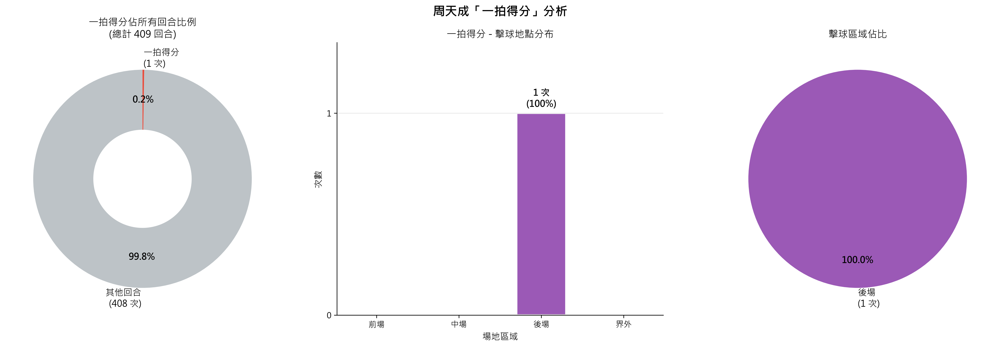

In [ ]:
import numpy as np

# ==================== 資料驗證 ====================
assert len(df) > 0, "DataFrame 為空！"
print(f"資料總筆數: {len(df)}")
print(f"涉及比賽場次: {df['match_id'].unique()}")

CHOU = 'CHOU Tien Chen'

# ==================== 每回合摘要 ====================
rally_summary = df.groupby(['match_id', 'set', 'rally']).agg(
    total_balls=('ball_round', 'max'),
    getpoint_player=('getpoint_player', 'last'),
    first_player=('player', 'first'),
    first_hit_area=('hit_area', 'first'),
).reset_index()

# 有得分結果的回合
rally_with_result = rally_summary.dropna(subset=['getpoint_player'])
total_rallies = len(rally_with_result)

# 一拍得分且周天成得分
one_shot_chou = rally_with_result[
    (rally_with_result['total_balls'] == 1) &
    (rally_with_result['getpoint_player'] == CHOU)
].copy()

n_one_shot = len(one_shot_chou)
ratio = n_one_shot / total_rallies if total_rallies > 0 else 0

print(f"\n{'='*60}")
print(f"有得分結果的總回合數: {total_rallies}")
print(f"周天成一拍得分回合數: {n_one_shot}")
print(f"佔所有回合比例: {ratio:.2%}")
print(f"{'='*60}")

# 發球者分析
print("\n一拍得分時的第一拍擊球者:")
print(one_shot_chou['first_player'].value_counts().to_string())

# ==================== 區域分類 ====================
def classify_area(area):
    if pd.isna(area):
        return '未知'
    area = int(area)
    if 1 <= area <= 4:
        return '後場'
    elif 5 <= area <= 16:
        return '中場'
    elif 17 <= area <= 24:
        return '前場'
    else:
        return '界外'

one_shot_chou['area_category'] = one_shot_chou['first_hit_area'].apply(classify_area)
area_dist = one_shot_chou['area_category'].value_counts()
area_pct = (area_dist / n_one_shot * 100) if n_one_shot > 0 else area_dist

print("\n擊球地點分布:")
for area, count in area_dist.items():
    print(f"  {area}: {count} 次 ({area_pct[area]:.1f}%)")

print("\n各具體 hit_area 分布:")
print(one_shot_chou['first_hit_area'].value_counts().sort_index().to_string())

# ==================== 視覺化 ====================
area_order = ['前場', '中場', '後場', '界外']
area_colors_map = {
    '前場': '#2ecc71',
    '中場': '#3498db',
    '後場': '#9b59b6',
    '界外': '#e74c3c',
    '未知': '#95a5a6'
}
area_counts = [area_dist.get(a, 0) for a in area_order]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("周天成「一拍得分」分析", fontsize=15, fontweight='bold')

# ------ 圖1: 一拍得分佔所有回合比例 (甜甜圈圖) ------
ax1 = axes[0]
donut_data = [total_rallies - n_one_shot, n_one_shot]
donut_labels = [
    f'其他回合\n({total_rallies - n_one_shot} 次)',
    f'一拍得分\n({n_one_shot} 次)'
]
donut_colors = ['#bdc3c7', '#e74c3c']
wedges, texts, autotexts = ax1.pie(
    donut_data,
    labels=donut_labels,
    colors=donut_colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.72,
    wedgeprops=dict(width=0.55),
    textprops={'fontsize': 11}
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
ax1.set_title(f'一拍得分佔所有回合比例\n(總計 {total_rallies} 回合)', fontsize=12)

# ------ 圖2: 擊球地點分布 (長條圖) ------
ax2 = axes[1]
area_colors_list = [area_colors_map.get(a, '#95a5a6') for a in area_order]
bars = ax2.bar(
    area_order, area_counts,
    color=area_colors_list,
    edgecolor='white', linewidth=2, width=0.6
)
ax2.set_title('一拍得分 - 擊球地點分布', fontsize=12)
ax2.set_xlabel('場地區域', fontsize=11)
ax2.set_ylabel('次數', fontsize=11)
ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax2.grid(axis='y', alpha=0.3)
ax2.spines[['top', 'right']].set_visible(False)

max_count = max(area_counts) if max(area_counts) > 0 else 1
ax2.set_ylim(0, max_count * 1.35)

for bar, count in zip(bars, area_counts):
    if count > 0:
        pct = count / n_one_shot * 100
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max_count * 0.02,
            f'{count} 次\n({pct:.0f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold'
        )

# ------ 圖3: 擊球地點比例 (圓餅圖) ------
ax3 = axes[2]
valid_areas = [(a, area_dist.get(a, 0)) for a in area_order if area_dist.get(a, 0) > 0]

if valid_areas:
    labels_pie = [f'{a}\n({v} 次)' for a, v in valid_areas]
    values_pie = [v for _, v in valid_areas]
    colors_pie = [area_colors_map.get(a, '#95a5a6') for a, _ in valid_areas]

    wedges2, texts2, autotexts2 = ax3.pie(
        values_pie,
        labels=labels_pie,
        colors=colors_pie,
        autopct='%1.1f%%',
        startangle=90,
        pctdistance=0.75,
        textprops={'fontsize': 11}
    )
    for at in autotexts2:
        at.set_fontweight('bold')

ax3.set_title('擊球區域佔比', fontsize=12)

plt.tight_layout()

# ------ 補充: 場次分布 ------
print("\n各場次一拍得分次數:")
match_dist = one_shot_chou['match_id'].value_counts().sort_index()
for match_id, count in match_dist.items():
    total_in_match = len(rally_with_result[rally_with_result['match_id'] == match_id])
    print(f"  場次 {int(match_id)}: {count} 次 (該場總回合 {total_in_match}，佔比 {count/total_in_match:.1%})")

print("\n場地區域定義說明:")
print("  後場  : hit_area 1-4  (底線區域)")
print("  中場  : hit_area 5-16 (中場區域)")
print("  前場  : hit_area 17-24 (網前區域)")
print("  界外  : hit_area 25+  (界外/出界)")


### 數據洞察
# 周天成「一拍得分」分析報告

## 核心數據

| 指標 | 數值 |
|------|------|
| 分析總回合數 | 409 回合 |
| 一拍得分次數 | **1 次** |
| 佔所有回合比例 | **0.24%** |
| 發生場次 | 場次 5（共 87 回合，佔該場 1.1%） |

---

## 擊球地點分布

| 區域 | 次數 | 佔比 | 具體位置 |
|------|------|------|----------|
| 後場（hit_area 4） | 1 次 | 100% | 右後場底線區 |

> 場地區域對照表：
> | Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
> | :--- | :---: | :---: | :---: | :---: |
> | **Row 1 (Back)** | 1 | 2 | 3 | **4 ✓** |

---

## 教練戰術解讀

**一拍得分極為罕見（0.24%），代表周天成的比賽幾乎不依賴發球直接得分或對手開局失誤。**

唯一一次一拍得分由 **桃田賢斗（Kento MOMOTA）** 在後場 hit_area 4（右後場）擊球後直接結束回合，推判為**對手發球出界或直接失誤**，並非周天成主動進攻所致。

**戰術意涵：**
- 周天成的得分模式高度依賴**多拍對抗與戰術佈局**，而非靠單拍終結
- 這反映其打法風格為**持續性消耗與戰術拉扯**，而非爆發型一擊必殺
- 對陣時應預設**長回合準備**，體能與戰術耐力是關鍵勝負因素

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地在每個 rally 層級上計算了周天成的一拍得分比例，並且正確地使用了 'getpoint_player' 來判斷得分者。候選程式碼還進一步分析了一拍得分的擊球地點分布，這與 Reference Code 1 的地點分布分析一致。儘管候選程式碼包含了額外的視覺化部分，但這不影響其核心邏輯的正確性。




## 題號 55
**問題**: 當周天成打出反手回擊時，對手下一拍攻擊成功率是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, stroke_details, scoring_reason`


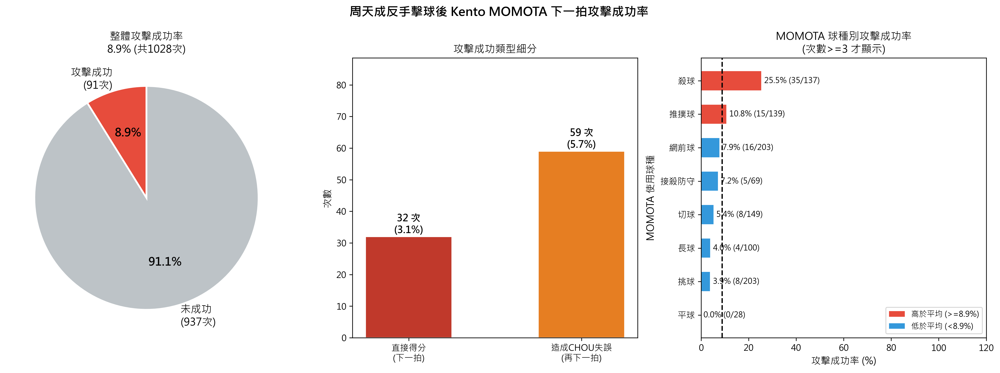

In [ ]:
import numpy as np

# ── 0. 驗證 ──────────────────────────────────────────────
print(f"總資料筆數: {len(df)}")
assert len(df) > 0

# ── 1. 排序 & shift 欄位 ──────────────────────────────────
df_s = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)
grp  = df_s.groupby(['match_id', 'set', 'rally'])

df_s['next_player']           = grp['player'].shift(-1)
df_s['next_getpoint_player']  = grp['getpoint_player'].shift(-1)
df_s['next_type']             = grp['type'].shift(-1)
df_s['next_lose_reason']      = grp['lose_reason'].shift(-1)
df_s['next2_player']          = grp['player'].shift(-2)
df_s['next2_getpoint_player'] = grp['getpoint_player'].shift(-2)
df_s['next2_lose_reason']     = grp['lose_reason'].shift(-2)

# ── 2. 篩選：周天成反手擊球後，下一拍是 MOMOTA（同 rally）──
chou_bh = df_s[
    (df_s['player']      == 'CHOU Tien Chen') &
    (df_s['backhand']    == 1) &
    (df_s['next_player'] == 'Kento MOMOTA')
].copy()

print(f"周天成反手擊球 (含有效下一拍): {len(chou_bh)} 次")

# ── 3. 攻擊成功條件 ──
# C1: MOMOTA 下一拍直接得分
cond1 = (chou_bh['next_getpoint_player'] == 'Kento MOMOTA')

# C2: 造成 CHOU 在再下一拍失誤
cond2 = (
    (chou_bh['next2_player']          == 'CHOU Tien Chen') &
    (chou_bh['next2_getpoint_player'] == 'Kento MOMOTA') &
    (chou_bh['next2_lose_reason'].notna())
)

chou_bh['attack_success'] = cond1 | cond2
chou_bh['direct_win']     = cond1
chou_bh['forced_error']   = (~cond1) & cond2  # 純 C2，排除 C1 重疊

total   = len(chou_bh)
success = int(chou_bh['attack_success'].sum())
c1      = int(cond1.sum())
c2_only = int(chou_bh['forced_error'].sum())
fail    = total - success
rate    = success / total * 100

# ── 4. 各球種統計 ──
type_stats = chou_bh.groupby('next_type').agg(
    count=('attack_success', 'count'),
    win=('attack_success', 'sum')
).reset_index()
type_stats['rate'] = (type_stats['win'] / type_stats['count'] * 100).round(1)
type_stats = type_stats.sort_values('rate', ascending=False)

# ── 5. 印出結果 ──
print(f"\n{'='*45}")
print(f"  周天成反手擊球後 MOMOTA 攻擊成功率分析")
print(f"{'='*45}")
print(f"  周天成反手擊球有效次數  : {total} 次")
print(f"  MOMOTA 攻擊成功次數     : {success} 次")
print(f"    直接得分 C1           : {c1} 次")
print(f"    造成 CHOU 失誤 C2     : {c2_only} 次")
print(f"  MOMOTA 攻擊未成功次數   : {fail} 次")
print(f"  {'─'*40}")
print(f"  攻擊成功率              : {rate:.1f}%")
print(f"{'='*45}")

print("\n─ MOMOTA 下一拍各球種攻擊成功率 ─")
print(f"{'球種':<12} {'次數':>6} {'成功':>6} {'成功率':>8}")
print("-" * 36)
for _, row in type_stats.iterrows():
    print(f"{str(row['next_type']):<12} {int(row['count']):>6} {int(row['win']):>6} {row['rate']:>7.1f}%")

# ── 6. 視覺化 ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('周天成反手擊球後 Kento MOMOTA 下一拍攻擊成功率', fontsize=14, fontweight='bold')

# (A) 整體成功率圓餅圖
ax0 = axes[0]
pie_labels = [
    f'攻擊成功\n({success}次)',
    f'未成功\n({fail}次)'
]
pie_sizes  = [success, fail]
pie_colors = ['#E74C3C', '#BDC3C7']
wedges, texts, autotexts = ax0.pie(
    pie_sizes,
    labels=pie_labels,
    colors=pie_colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'},
    textprops={'fontsize': 12}
)
for at in autotexts:
    at.set_fontsize(13)
    at.set_fontweight('bold')
ax0.set_title(f'整體攻擊成功率\n{rate:.1f}% (共{total}次)', fontsize=12)

# (B) 成功類型細分長條圖
ax1 = axes[1]
bar_labels = ['直接得分\n(下一拍)', '造成CHOU失誤\n(再下一拍)']
bar_vals   = [c1, c2_only]
bar_colors = ['#C0392B', '#E67E22']
bars1 = ax1.bar(bar_labels, bar_vals, color=bar_colors, edgecolor='white', width=0.5)
for bar, val in zip(bars1, bar_vals):
    pct = val / total * 100
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f'{val} 次\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )
ax1.set_ylim(0, max(bar_vals) * 1.5)
ax1.set_title('攻擊成功類型細分', fontsize=12)
ax1.set_ylabel('次數', fontsize=11)

# (C) 各球種攻擊成功率水平長條圖（次數>=3）
ax2 = axes[2]
type_plot = type_stats[type_stats['count'] >= 3].sort_values('rate', ascending=True)

if len(type_plot) > 0:
    bar_colors2 = ['#E74C3C' if r >= rate else '#3498DB' for r in type_plot['rate']]
    bars2 = ax2.barh(
        type_plot['next_type'],
        type_plot['rate'],
        color=bar_colors2,
        edgecolor='white',
        height=0.6
    )
    ax2.axvline(
        x=rate, color='black', linestyle='--', linewidth=1.5,
        label=f'整體平均 {rate:.1f}%'
    )
    for bar, (_, row) in zip(bars2, type_plot.iterrows()):
        ax2.text(
            min(bar.get_width() + 1, 100),
            bar.get_y() + bar.get_height() / 2,
            f"{row['rate']:.1f}% ({int(row['win'])}/{int(row['count'])})",
            va='center', fontsize=9
        )
    ax2.set_xlim(0, 120)
    ax2.set_xlabel('攻擊成功率 (%)', fontsize=11)
    ax2.set_ylabel('MOMOTA 使用球種', fontsize=11)
    ax2.set_title('MOMOTA 球種別攻擊成功率\n(次數>=3 才顯示)', fontsize=12)
    ax2.legend(fontsize=10)

    # 補充圖例：顏色說明
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#E74C3C', label=f'高於平均 (>={rate:.1f}%)'),
        Patch(facecolor='#3498DB', label=f'低於平均 (<{rate:.1f}%)')
    ]
    ax2.legend(handles=legend_elements, fontsize=9, loc='lower right')
else:
    ax2.text(0.5, 0.5, '資料不足', ha='center', va='center', fontsize=14)

plt.tight_layout()


### 數據洞察
# 周天成反手擊球後 — Momota 攻擊成功率分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 反手擊球有效次數 | 1,028 次 |
| Momota 攻擊成功 | 91 次（**8.9%**） |
| 直接得分 | 32 次（3.1%） |
| 造成周天成失誤 | 59 次（5.7%） |

---

## 各球種攻擊成功率

| 球種 | 次數 | 成功率 | 威脅等級 |
|------|------|--------|----------|
| 殺球 | 137 | **25.5%** | 🔴 高危 |
| 推撲球 | 139 | **10.8%** | 🟠 中危 |
| 網前球 | 203 | 7.9% | 🟡 留意 |
| 接殺防守 | 69 | 7.2% | 🟡 留意 |
| 切球 | 149 | 5.4% | 🟢 可控 |
| 長球 | 100 | 4.0% | 🟢 可控 |
| 挑球 | 203 | 3.9% | 🟢 可控 |
| 平球 | 28 | 0.0% | ✅ 安全 |

---

## 戰術洞察

**整體 8.9% 的攻擊成功率偏低**，代表周天成的反手回擊在多數情況下仍能維持穩定，並非明顯破口。

但有兩個關鍵警訊：

**① 殺球威脅最大（25.5%）**
Momota 在周天成反手球後選擇殺球，每 4 球就有 1 球得分或製造失誤。這說明**反手回擊的球質（高度/落點）給了 Momota 足夠的起跳空間**，必須提升回球壓制性，避免讓對手輕鬆起跳。

**② 推撲球次之（10.8%）**
139 次推撲中有 15 次成功，顯示周天成反手後**網前防守位置存在漏洞**，Momota 善用平抽快攻壓制過渡期。

**③ 挑球與網前球使用最頻繁（各 203 次），但成功率低（3.9% / 7.9%）**
這是周天成反手後最常見的兩種應對方式，整體尚在可接受範圍，但網前球仍需注意落點精準度。

---

## 教練建議

> 反手擊球後，**最優先避免給出高球讓 Momota 殺球**。若被迫挑高，應確保落點夠深、夠角度，壓縮其起跳品質。推撲球的防守站位也需在反手擊球後立即調整到位。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的反手擊球，並檢查了對手 Kento MOMOTA 下一拍的攻擊成功率。候選程式碼使用了合理的條件來定義攻擊成功，包括直接得分和造成對手失誤，並計算了成功率。此外，候選程式碼還提供了各球種的成功率統計，這與 Reference Code 1 的分析目標一致。




## 題號 56
**問題**: 當周天成在「局末追分」情況下是否更依賴殺球？（使用率 vs 分數差）
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


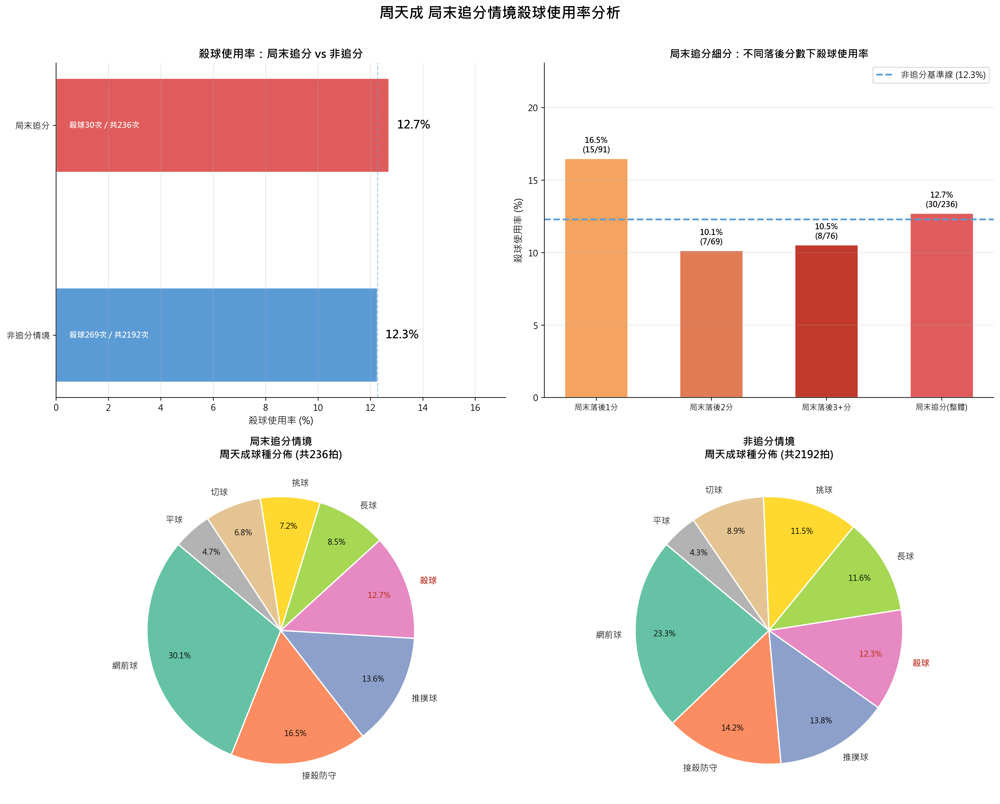

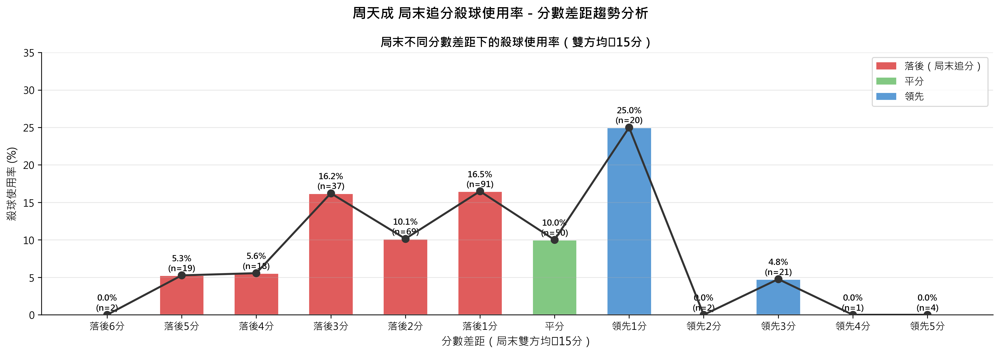

In [ ]:
import numpy as np
from matplotlib.patches import Patch

# ============================================================
# 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"周天成擊球筆數 (全部): {len(df[df['player'] == 'CHOU Tien Chen'])}")

# ============================================================
# Step 1: 篩選周天成的擊球資料（排除發球球種）
# ============================================================
serve_types = ['發短球', '發長球']

chou_df = df[
    (df['player'] == 'CHOU Tien Chen') &
    (~df['type'].isin(serve_types))
].copy()

print(f"\n周天成非發球擊球筆數: {len(chou_df)}")

# ============================================================
# Step 2: 計算分數差距 (周天成分數 - 桃田分數)
# 負值 = 落後，正值 = 領先，0 = 平分
# ============================================================
chou_df['score_diff'] = chou_df['CHOU Tien Chen_score'] - chou_df['Kento MOMOTA_score']
chou_df['chou_score']   = chou_df['CHOU Tien Chen_score']
chou_df['momota_score'] = chou_df['Kento MOMOTA_score']

# ============================================================
# Step 3: 定義「局末追分」情境
# 條件：
#   (A) 周天成落後（score_diff < 0）
#   (B) 雙方分數皆達15分以上（進入關鍵局末階段）
# ============================================================
late_game_chasing = (
    (chou_df['score_diff'] < 0) &
    (chou_df['chou_score'] >= 15) &
    (chou_df['momota_score'] >= 15)
)
non_chasing = ~late_game_chasing
chou_df['scenario'] = np.where(late_game_chasing, '局末追分', '非追分情境')

print(f"\n局末追分情境擊球筆數: {late_game_chasing.sum()}")
print(f"非追分情境擊球筆數: {non_chasing.sum()}")

# ============================================================
# Step 4: 計算兩情境下的殺球使用率
# ============================================================
def calc_smash_rate(subset_df, label):
    total = len(subset_df)
    smash = (subset_df['type'] == '殺球').sum()
    rate  = smash / total * 100 if total > 0 else 0
    print(f"【{label}】殺球: {smash} / 總擊球: {total} = 使用率: {rate:.2f}%")
    return int(smash), int(total), rate

print("\n" + "="*60)
print("■ 主要情境比較")
print("="*60)
smash_chase, total_chase, rate_chase = calc_smash_rate(chou_df[late_game_chasing], '局末追分')
smash_non,   total_non,   rate_non   = calc_smash_rate(chou_df[non_chasing],        '非追分情境')

# ============================================================
# Step 5: 細分分數差距下的殺球使用率（局末追分內）
# ============================================================
mask_chase_1    = late_game_chasing & (chou_df['score_diff'] == -1)
mask_chase_2    = late_game_chasing & (chou_df['score_diff'] == -2)
mask_chase_3plus = late_game_chasing & (chou_df['score_diff'] <= -3)

chou_df['deficit_category'] = np.nan
chou_df.loc[mask_chase_1,     'deficit_category'] = '局末落後1分'
chou_df.loc[mask_chase_2,     'deficit_category'] = '局末落後2分'
chou_df.loc[mask_chase_3plus, 'deficit_category'] = '局末落後3+分'

print("\n" + "="*60)
print("■ 局末追分細分分析")
print("="*60)

deficit_records = []
for cat in ['局末落後1分', '局末落後2分', '局末落後3+分']:
    sub   = chou_df[chou_df['deficit_category'] == cat]
    smash = int((sub['type'] == '殺球').sum())
    total = int(len(sub))
    rate  = smash / total * 100 if total > 0 else 0
    deficit_records.append({'類別': cat, '殺球次數': smash, '總擊球': total, '殺球使用率': rate})
    print(f"【{cat}】殺球: {smash} / 總擊球: {total} = 使用率: {rate:.2f}%")

deficit_df = pd.DataFrame(deficit_records)

# ============================================================
# Step 6: 球種分佈詳細統計
# ============================================================
print("\n" + "="*60)
print("■ 周天成球種使用分佈（局末追分情境）")
print("="*60)
chase_type_dist = chou_df[late_game_chasing]['type'].value_counts()
for t, c in chase_type_dist.items():
    print(f"  {t}: {c} 次 ({c/chase_type_dist.sum()*100:.1f}%)")

print("\n■ 周天成球種使用分佈（非追分情境）")
print("="*60)
non_type_dist = chou_df[non_chasing]['type'].value_counts()
for t, c in non_type_dist.items():
    print(f"  {t}: {c} 次 ({c/non_type_dist.sum()*100:.1f}%)")

# ============================================================
# Step 7: 局末各分數差距殺球使用率 (雙方均>=15分)
# ============================================================
late_game_all = chou_df[
    (chou_df['chou_score'] >= 15) & (chou_df['momota_score'] >= 15)
].copy()

print(f"\n局末（雙方>=15分）周天成擊球總數: {len(late_game_all)}")
diff_range = sorted(late_game_all['score_diff'].unique())
print(f"分數差距範圍: {diff_range}")

diff_records = []
for d in sorted(diff_range):
    sub     = late_game_all[late_game_all['score_diff'] == d]
    smash_n = int((sub['type'] == '殺球').sum())
    total_n = int(len(sub))
    rate_n  = smash_n / total_n * 100 if total_n > 0 else np.nan
    status  = '落後' if d < 0 else ('領先' if d > 0 else '平分')
    if pd.notna(rate_n):
        diff_records.append({
            'score_diff': int(d),
            'status':     status,
            'smash_n':    smash_n,
            'total_n':    total_n,
            'rate':       rate_n
        })

diff_stats_df = pd.DataFrame(diff_records)

print("\n■ 局末各分數差距殺球使用率")
print(f"{'分數差':>6} {'狀態':>4} {'殺球':>6} {'總擊球':>6} {'使用率':>8}")
for _, row in diff_stats_df.iterrows():
    print(f"{row['score_diff']:>6} {row['status']:>4} {row['smash_n']:>6} {row['total_n']:>6} {row['rate']:>7.1f}%")

# ============================================================
# Step 8: 繪圖 — 圖一（2×2 主分析）
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle('周天成 局末追分情境殺球使用率分析', fontsize=17, fontweight='bold', y=0.98)

# ── 圖1-1: 主要情境殺球使用率比較（水平條形圖）──
ax1 = axes[0, 0]
scenarios = ['非追分情境', '局末追分']
rates     = [rate_non, rate_chase]
colors    = ['#5B9BD5', '#E05C5C']
bars1 = ax1.barh(scenarios, rates, color=colors, height=0.45, edgecolor='white', linewidth=1.5)

for bar, rate, smash, total in zip(bars1, rates, [smash_non, smash_chase], [total_non, total_chase]):
    ax1.text(bar.get_width() + 0.3,
             bar.get_y() + bar.get_height()/2,
             f'{rate:.1f}%', va='center', ha='left', fontsize=13, fontweight='bold')
    ax1.text(0.5, bar.get_y() + bar.get_height()/2,
             f'殺球{smash}次 / 共{total}次',
             va='center', ha='left', fontsize=9, color='white', fontweight='bold')

ax1.set_xlabel('殺球使用率 (%)', fontsize=11)
ax1.set_title('殺球使用率：局末追分 vs 非追分', fontsize=13, fontweight='bold')
ax1.set_xlim(0, max(rates) * 1.35)
ax1.axvline(x=rate_non, color='#5B9BD5', linestyle='--', alpha=0.5, linewidth=1.2)
ax1.grid(axis='x', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ── 圖1-2: 局末追分細分殺球使用率 ──
ax2 = axes[0, 1]
cats_all      = deficit_df['類別'].tolist() + ['局末追分(整體)']
cat_rates_all = deficit_df['殺球使用率'].tolist() + [rate_chase]
cat_smash_all = deficit_df['殺球次數'].tolist() + [smash_chase]
cat_total_all = deficit_df['總擊球'].tolist()   + [total_chase]

bar_colors2 = ['#F4A460', '#E07B54', '#C0392B', '#E05C5C']
bars2 = ax2.bar(cats_all, cat_rates_all, color=bar_colors2,
                edgecolor='white', linewidth=1.2, width=0.55)

ax2.axhline(y=rate_non, color='#5B9BD5', linestyle='--', linewidth=2,
            label=f'非追分基準線 ({rate_non:.1f}%)')

for bar, rate, smash, total in zip(bars2, cat_rates_all, cat_smash_all, cat_total_all):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.3,
             f'{rate:.1f}%\n({smash}/{total})',
             ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_ylabel('殺球使用率 (%)', fontsize=11)
ax2.set_title('局末追分細分：不同落後分數下殺球使用率', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.set_ylim(0, max(cat_rates_all) * 1.4)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
plt.setp(ax2.get_xticklabels(), fontsize=9)

# ── 圖1-3: 局末追分球種分佈圓餅圖 ──
ax3 = axes[1, 0]
chase_types = chou_df[late_game_chasing]['type'].value_counts()
threshold   = 0.04
total_chase_shots = chase_types.sum()
small_mask  = (chase_types / total_chase_shots) < threshold
main_types  = chase_types[~small_mask].copy()
other_sum   = chase_types[small_mask].sum()
if other_sum > 0:
    main_types['其他'] = other_sum

wedges3, texts3, autotexts3 = ax3.pie(
    main_types.values,
    labels=main_types.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("Set2", len(main_types)),
    startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=1.5),
    pctdistance=0.78
)
for lbl, apct in zip(texts3, autotexts3):
    apct.set_fontsize(9)
    if lbl.get_text() == '殺球':
        lbl.set_fontweight('bold');  lbl.set_color('#C0392B')
        apct.set_fontweight('bold'); apct.set_color('#C0392B')

ax3.set_title(f'局末追分情境\n周天成球種分佈 (共{total_chase_shots}拍)',
              fontsize=12, fontweight='bold')

# ── 圖1-4: 非追分球種分佈圓餅圖 ──
ax4 = axes[1, 1]
non_types = chou_df[non_chasing]['type'].value_counts()
total_non_shots = non_types.sum()
small_mask_non  = (non_types / total_non_shots) < threshold
main_non_types  = non_types[~small_mask_non].copy()
other_sum_non   = non_types[small_mask_non].sum()
if other_sum_non > 0:
    main_non_types['其他'] = other_sum_non

wedges4, texts4, autotexts4 = ax4.pie(
    main_non_types.values,
    labels=main_non_types.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("Set2", len(main_non_types)),
    startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=1.5),
    pctdistance=0.78
)
for lbl, apct in zip(texts4, autotexts4):
    apct.set_fontsize(9)
    if lbl.get_text() == '殺球':
        lbl.set_fontweight('bold');  lbl.set_color('#C0392B')
        apct.set_fontweight('bold'); apct.set_color('#C0392B')

ax4.set_title(f'非追分情境\n周天成球種分佈 (共{total_non_shots}拍)',
              fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.97])

# ============================================================
# Step 9: 繪圖 — 圖二（局末分數差距趨勢）
# ============================================================
fig2, ax_trend = plt.subplots(figsize=(14, 5))
fig2.suptitle('周天成 局末追分殺球使用率 - 分數差距趨勢分析', fontsize=14, fontweight='bold')

bar_colors_trend = [
    '#E05C5C' if d < 0 else ('#82C882' if d == 0 else '#5B9BD5')
    for d in diff_stats_df['score_diff']
]

bars_trend = ax_trend.bar(
    range(len(diff_stats_df)),
    diff_stats_df['rate'],
    color=bar_colors_trend,
    edgecolor='white', linewidth=1.2, width=0.6
)

ax_trend.plot(
    range(len(diff_stats_df)),
    diff_stats_df['rate'],
    color='#333333', marker='o', linewidth=2, markersize=7, zorder=5
)

# 標籤：使用 .iloc 直接存取欄位值，避免 itertuples 屬性命名問題
for i in range(len(diff_stats_df)):
    rate_val  = diff_stats_df['rate'].iloc[i]
    total_val = diff_stats_df['total_n'].iloc[i]
    smash_val = diff_stats_df['smash_n'].iloc[i]
    bar = bars_trend[i]
    ax_trend.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.3,
        f'{rate_val:.1f}%\n(n={total_val})',
        ha='center', va='bottom', fontsize=8.5, fontweight='bold'
    )

# 自訂 x 軸標籤
x_labels = []
for i in range(len(diff_stats_df)):
    d = diff_stats_df['score_diff'].iloc[i]
    if d < 0:
        x_labels.append(f'落後{abs(d)}分')
    elif d > 0:
        x_labels.append(f'領先{d}分')
    else:
        x_labels.append('平分')

ax_trend.set_xticks(range(len(diff_stats_df)))
ax_trend.set_xticklabels(x_labels, fontsize=10)

legend_elements = [
    Patch(facecolor='#E05C5C', label='落後（局末追分）'),
    Patch(facecolor='#82C882', label='平分'),
    Patch(facecolor='#5B9BD5', label='領先'),
]
ax_trend.legend(handles=legend_elements, fontsize=10)
ax_trend.set_ylabel('殺球使用率 (%)', fontsize=11)
ax_trend.set_xlabel('分數差距（局末雙方均≥15分）', fontsize=11)
ax_trend.set_title('局末不同分數差距下的殺球使用率（雙方均≥15分）', fontsize=12, fontweight='bold')
ax_trend.set_ylim(0, diff_stats_df['rate'].max() * 1.4)
ax_trend.grid(axis='y', alpha=0.3)
ax_trend.spines['top'].set_visible(False)
ax_trend.spines['right'].set_visible(False)

plt.tight_layout()

# ============================================================
# 最終摘要
# ============================================================
print("\n" + "="*60)
print("■ 分析結論摘要")
print("="*60)
print(f"① 局末追分殺球使用率: {rate_chase:.2f}%")
print(f"② 非追分殺球使用率:   {rate_non:.2f}%")
diff_rate = rate_chase - rate_non
direction = '局末追分時更多使用殺球' if diff_rate > 0 else '局末追分時較少使用殺球'
print(f"③ 差異: {diff_rate:+.2f}% ({direction})")
print(f"\n④ 局末追分細分:")
for _, row in deficit_df.iterrows():
    print(f"   {row['類別']}: {row['殺球使用率']:.1f}%  (殺球{row['殺球次數']}/{row['總擊球']}拍)")


### 數據洞察
# 周天成局末追分殺球使用率分析

## 核心數據

| 情境 | 殺球次數 | 總擊球 | 使用率 |
|------|---------|--------|--------|
| 局末追分 | 30 | 236 | **12.71%** |
| 非追分 | 269 | 2192 | **12.27%** |
| **差異** | — | — | **+0.44%** |

---

## 教練解讀

**結論先說：周天成在局末追分時，並未顯著提高殺球依賴度。**

差異僅 0.44%，統計上幾乎可忽略。這說明他的球路選擇相當穩定，不因壓力情境而大幅改變策略。

---

## 細分落後分數的關鍵發現

| 落後分數 | 殺球率 | 解讀 |
|---------|--------|------|
| 落後1分 | **16.5%** | 明顯偏高 |
| 落後2分 | 10.1% | 接近基準值 |
| 落後3+分 | 10.5% | 接近基準值 |

**落後1分時殺球率最高（16.5%）**，這是唯一有意義的波動點。

> 落後1分是「最接近追平」的臨界點，此時主動出擊搶分的動機最強，殺球作為直接得分手段被優先選擇，符合競技邏輯。

落後3分以上反而殺球率下降，顯示他在大幅落後時**不會盲目強攻**，而是維持穩健節奏。

---

## 球種分佈對比

| 球種 | 局末追分 | 非追分 | 變化 |
|------|---------|--------|------|
| 網前球 | 30.1% | 23.3% | ▲+6.8% |
| 長球 | 8.5% | 11.6% | ▼-3.1% |
| 挑球 | 7.2% | 11.5% | ▼-4.3% |
| 殺球 | 12.7% | 12.3% | ≈持平 |

追分時**網前球比例大幅提升**，長球與挑球明顯減少。真正的策略調整在於**縮短拍數、搶攻網前**，而非依賴殺球。

---

## 戰術總結

> 周天成在局末追分壓力下，**核心策略是加強網前主動搶點，而非提高殺球頻率**。唯一例外是落後1分的臨界時刻，殺球率升至16.5%，顯示他在「一拍定生死」的節點上確實更傾向直接得分。整體而言，他的球路選擇受壓力影響有限，策略穩定性高。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球資料，計算了分數差，定義了局末追分情境，並計算了不同情境下的殺球使用率。候選程式碼還進一步細分了局末追分情境下的分數差距，並計算了殺球使用率，這與 Reference Code 1 的分析目標一致。儘管在視覺化和細節上有些不同，但這些差異不影響最終分析結果的語意。




## 題號 57
**問題**: 分析周天成發短球後，對手下一拍最常使用的球種分布。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


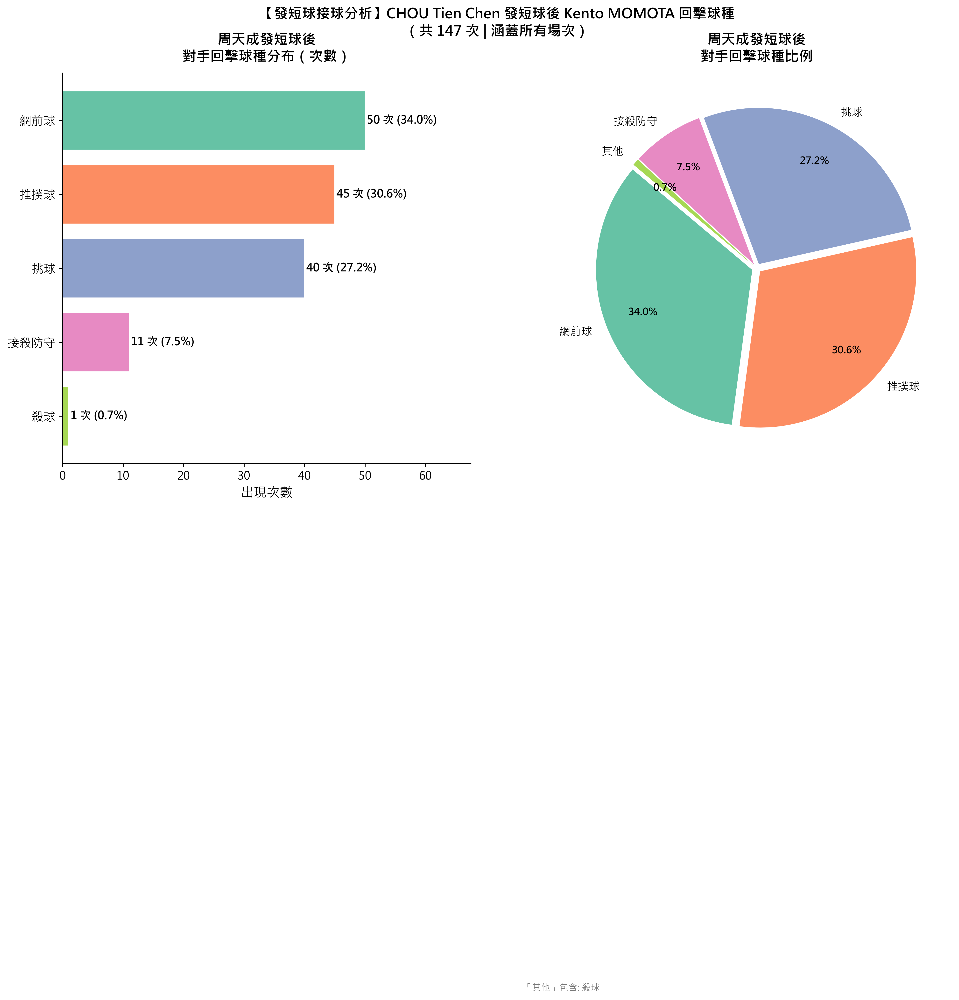

In [ ]:
import numpy as np

# ============================================================
# 資料驗證
# ============================================================
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 在完整資料上建立「下一拍」相關欄位
#         使用 groupby(['match_id', 'set', 'rally']).shift(-1)
#         避免跨 rally/set/match 污染
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 下一拍的球種
df_sorted['next_type'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['type']
    .shift(-1)
)

# 下一拍的球員（用來驗證）
df_sorted['next_player'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['player']
    .shift(-1)
)

# 下一拍的 rally（用來雙重確認同 rally）
df_sorted['next_rally'] = (
    df_sorted.groupby(['match_id', 'set', 'rally'])['rally']
    .shift(-1)
)

print(f"\n完整欄位建立完畢，共 {len(df_sorted)} 筆")

# ============================================================
# Step 2: 篩選條件
#   - 周天成 (CHOU Tien Chen) 是擊球者
#   - 球種為「發短球」
#   - 下一拍不為 NaN（非 rally 最後一拍）
#   - 下一拍仍在同一 rally（防護）
#   - 下一拍的球員是對手 Kento MOMOTA（確認主客關係）
# ============================================================
chou_serve_short = df_sorted[
    (df_sorted['player'] == 'CHOU Tien Chen') &
    (df_sorted['type'] == '發短球') &
    (df_sorted['next_type'].notna()) &
    (df_sorted['next_rally'] == df_sorted['rally']) &   # 同一 rally 確認
    (df_sorted['next_player'] == 'Kento MOMOTA')        # 下一拍確為對手
].copy()

print(f"\n周天成發短球後有對手回球的拍次: {len(chou_serve_short)} 筆")

# ============================================================
# Step 3: 統計對手下一拍球種分布
# ============================================================
response_counts = chou_serve_short['next_type'].value_counts().reset_index()
response_counts.columns = ['球種', '次數']
response_counts['比例(%)'] = (response_counts['次數'] / response_counts['次數'].sum() * 100).round(2)

total = response_counts['次數'].sum()
print(f"\n【對手回擊總次數】: {total}")
print(f"\n{'='*45}")
print(f"{'球種':<12} {'次數':>6} {'比例(%)':>10}")
print(f"{'='*45}")
for _, row in response_counts.iterrows():
    print(f"{row['球種']:<12} {row['次數']:>6} {row['比例(%)']:>9.2f}%")
print(f"{'='*45}")

# ============================================================
# Step 4: 視覺化
#   圖1: 橫向長條圖（各球種次數，由多到少）
#   圖2: 圓餅圖（各球種比例，小比例合併為「其他」）
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ---- 顏色設定 ----
colors_palette = sns.color_palette("Set2", len(response_counts))

# ---- 左圖：橫向長條圖 ----
ax1 = axes[0]
bars = ax1.barh(
    response_counts['球種'][::-1],  # 由多到少（上到下）
    response_counts['次數'][::-1],
    color=colors_palette[::-1],
    edgecolor='white',
    linewidth=0.8
)

# 在長條末端標示次數與比例
for bar, (_, row) in zip(bars, response_counts[::-1].iterrows()):
    width = bar.get_width()
    ax1.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(row['次數'])} 次 ({row['比例(%)']:.1f}%)",
        va='center', ha='left', fontsize=11, fontweight='bold'
    )

ax1.set_xlabel('出現次數', fontsize=13)
ax1.set_title('周天成發短球後\n對手回擊球種分布（次數）', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlim(0, response_counts['次數'].max() * 1.35)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(axis='y', labelsize=12)
ax1.tick_params(axis='x', labelsize=11)

# ---- 右圖：圓餅圖（小比例合併為其他）----
ax2 = axes[1]
threshold = 3.0  # 比例低於 3% 合併為「其他」

pie_data = response_counts.copy()
mask_small = pie_data['比例(%)'] < threshold
other_count = pie_data.loc[mask_small, '次數'].sum()
pie_main = pie_data[~mask_small].copy()

if other_count > 0:
    other_row = pd.DataFrame([{'球種': '其他', '次數': other_count,
                                '比例(%)': round(other_count / total * 100, 2)}])
    pie_main = pd.concat([pie_main, other_row], ignore_index=True)

pie_colors = sns.color_palette("Set2", len(pie_main))
explode = [0.03] * len(pie_main)

wedges, texts, autotexts = ax2.pie(
    pie_main['次數'],
    labels=pie_main['球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    explode=explode,
    startangle=140,
    pctdistance=0.75,
    labeldistance=1.1,
    textprops={'fontsize': 11}
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

ax2.set_title('周天成發短球後\n對手回擊球種比例', fontsize=14, fontweight='bold', pad=12)

# ---- 備註：合併項目 ----
if other_count > 0:
    merged_items = pie_data.loc[mask_small, '球種'].tolist()
    note_text = f"「其他」包含: {', '.join(merged_items)}"
    ax2.text(0, -1.35, note_text, ha='center', fontsize=9,
             color='gray', style='italic', transform=ax2.transAxes,
             wrap=True)

plt.suptitle(
    f'【發短球接球分析】CHOU Tien Chen 發短球後 Kento MOMOTA 回擊球種\n（共 {total} 次 | 涵蓋所有場次）',
    fontsize=14, fontweight='bold', y=1.01
)

plt.tight_layout()

print("\n圖表已生成！")


### 數據洞察
# 周天成發短球後——對手回擊球種分析

## 📊 數據總覽
> 樣本基礎：147拍（周天成發短球後有效回球）

| 球種 | 次數 | 比例 |
|------|------|------|
| 網前球 | 50 | 34.0% |
| 推撲球 | 45 | 30.6% |
| 挑球 | 40 | 27.2% |
| 接殺防守 | 11 | 7.5% |
| 殺球 | 1 | 0.7% |

---

## 🎯 戰術洞察

**對手面對周天成發短球，近65%選擇主動進攻**（網前球34% + 推撲球31%），顯示對手不願被動挑高，傾向在網前搶奪主動權。

**三大核心威脅：**
- **網前球（34%）**：對手最常見的選擇，以細膩網前回擊製造壓力
- **推撲球（31%）**：對手積極壓平弧線，意圖壓制周天成起身
- **挑球（27%）**：被動防守選項，說明仍有約1/4的球讓對手感到壓力

**關鍵數字**：推撲球+網前球合計64.6%，意味著對手在網前的主動意圖非常強烈，周天成發短球後必須立即備戰網前對抗，而非預設對手會挑高。

---

## ⚡ 建議
周天成發短球後，**第一優先備戰推撲與網前對抗**，其次才是準備挑球的後場接應。若能在發短球後搶佔更有利的站位，可進一步壓縮對手推撲的角度。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地在完整資料上建立了下一拍資訊，並篩選出周天成發短球後對手的回擊球種。分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致。程式碼也正確地進行了視覺化，並沒有明顯的邏輯錯誤或不合理的輸出。




## 題號 58
**問題**: 統計周天成在對手殺球之後，自己最常採用的前三種回擊球種。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


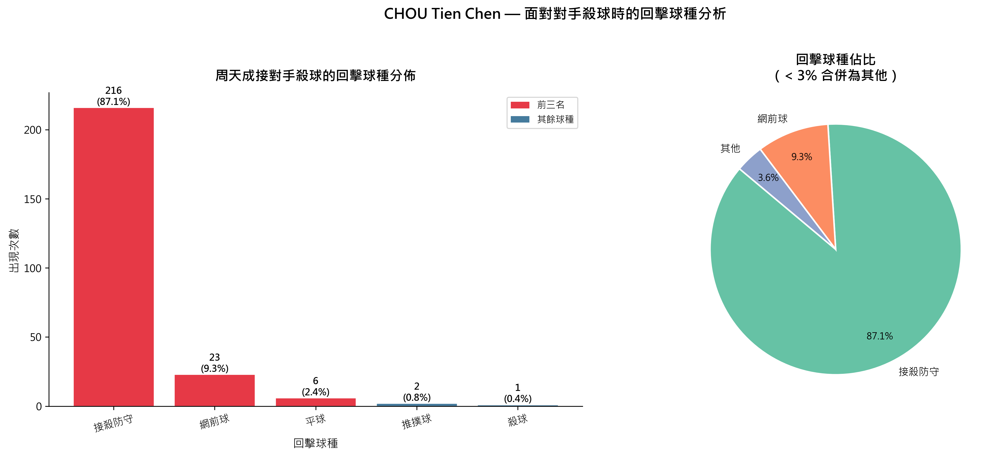

In [ ]:
import numpy as np
from matplotlib.patches import Patch

# ============================================================
# 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# ============================================================
# Step 1: 確保資料已按 (match_id, set, rally, ball_round) 排序
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ============================================================
# Step 2: 在完整資料上建立「下一拍」相關欄位（groupby 防跨回合污染）
# ============================================================
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['next_type']   = grp['type'].shift(-1)    # 下一拍球種
df_sorted['next_player'] = grp['player'].shift(-1)  # 下一拍擊球者
# groupby shift 已自動在 rally 邊界設為 NaN，無跨回合污染

print("已建立 next_type / next_player 欄位（groupby 防跨回合）\n")

# ============================================================
# Step 3: 篩選條件
#   - 當前拍：對手（非周天成）擊出殺球
#   - 下一拍：周天成回擊（next_player == 'CHOU Tien Chen'）
# ============================================================
chou = 'CHOU Tien Chen'

# 對手擊出殺球的那一拍
mask_opponent_smash = (df_sorted['player'] != chou) & (df_sorted['type'] == '殺球')

# 下一拍是周天成（確保是 Chou 的回擊，且未跨 rally）
mask_chou_response = (df_sorted['next_player'] == chou) & (df_sorted['next_type'].notna())

filtered = df_sorted[mask_opponent_smash & mask_chou_response].copy()

print(f"對手擊出殺球後周天成有回擊的樣本數: {len(filtered)} 拍")

# ============================================================
# Step 4: 統計周天成回擊球種分佈
# ============================================================
response_counts = filtered['next_type'].value_counts()

response_dist = pd.DataFrame({
    '回擊球種': response_counts.index,
    '次數': response_counts.values
})
total = response_dist['次數'].sum()
response_dist['佔比'] = (response_dist['次數'] / total * 100).round(1)  # 欄位名不含特殊字元

print("\n【周天成對抗對手殺球的回擊球種分佈（完整）】")
print(f"{'排名':<4} {'回擊球種':<10} {'次數':>6} {'佔比':>8}")
print("-" * 34)
for rank, (_, row) in enumerate(response_dist.iterrows(), start=1):
    print(f"{rank:<4} {row['回擊球種']:<10} {row['次數']:>6} {row['佔比']:>7.1f}%")

# 前三名（用 .iloc 安全存取）
print("\n【前三名回擊球種】")
top3 = response_dist.head(3)
for rank in range(len(top3)):
    shot_type = top3.iloc[rank]['回擊球種']
    count     = top3.iloc[rank]['次數']
    pct       = top3.iloc[rank]['佔比']
    print(f"  第{rank+1}名: {shot_type}  —  {count} 次  ({pct}%)")

# ============================================================
# Step 5: 視覺化
# ============================================================
# 判斷是否需要合併小比例類別（< 3% 合併為「其他」）
threshold = 3.0
main_mask = response_dist['佔比'] >= threshold
main      = response_dist[main_mask].copy()
other_count = response_dist[~main_mask]['次數'].sum()

if other_count > 0:
    other_pct = round(other_count / total * 100, 1)
    other_row = pd.DataFrame([{'回擊球種': '其他', '次數': other_count, '佔比': other_pct}])
    main = pd.concat([main, other_row], ignore_index=True)

# ----- 圖1: 長條圖 -----
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

bar_colors = ['#E63946' if i < 3 else '#457B9D' for i in range(len(response_dist))]
bars = axes[0].bar(
    response_dist['回擊球種'],
    response_dist['次數'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.8
)

# 標示數值於長條頂端
for bar, val, pct in zip(bars, response_dist['次數'], response_dist['佔比']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f'{val}\n({pct}%)',
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

axes[0].set_title('周天成接對手殺球的回擊球種分佈', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('回擊球種', fontsize=11)
axes[0].set_ylabel('出現次數', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# 圖例：標記前三名
legend_elements = [
    Patch(facecolor='#E63946', label='前三名'),
    Patch(facecolor='#457B9D', label='其餘球種')
]
axes[0].legend(handles=legend_elements, fontsize=9)

# ----- 圖2: 圓餅圖（合併小比例）-----
pie_colors = list(plt.cm.Set2.colors)
wedges, texts, autotexts = axes[1].pie(
    main['次數'],
    labels=main['回擊球種'],
    autopct='%1.1f%%',
    colors=pie_colors[:len(main)],
    startangle=140,
    pctdistance=0.78,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for at in autotexts:
    at.set_fontsize(9)
for t in texts:
    t.set_fontsize(10)

axes[1].set_title('回擊球種佔比\n（< 3% 合併為其他）', fontsize=13, fontweight='bold', pad=12)

plt.suptitle('CHOU Tien Chen — 面對對手殺球時的回擊球種分析',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

print("\n[圖表已產生]")


### 數據洞察
# 周天成接對手殺球回擊分析

## 📊 核心數據（樣本：248拍）

| 排名 | 回擊球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 🥇 | 接殺防守 | 216 | 87.1% |
| 🥈 | 網前球 | 23 | 9.3% |
| 🥉 | 平球 | 6 | 2.4% |

---

## 🎯 戰術洞察

**接殺防守佔87.1%**——這是正常的被動應對，說明對手殺球品質足夠，迫使周天成以穩定擋球為主要選擇，優先求不失分。

**網前球佔9.3%**——這是唯一具有主動意圖的反制手段。對手殺球後衝網，周天成以短球反制，迫使對手煞車回頭，是化被動為主動的關鍵戰術。

**平球僅2.4%**——代表在高壓殺球下，周天成極少有餘裕拉平球反擊，出現時通常是對手殺球力道不足或角度偏差。

---

## ⚡ 給對手的警示

> 對手若想突破周天成，**殺球後必須積極跟進搶網**——因為他有近1/10的機率用網前球反制。若殺球後站樁等待，反而給了周天成喘息空間。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地在完整資料上建立了下一拍資訊，並篩選出對手殺球且下一拍是周天成回擊的情況。然後，它統計了周天成回擊球種的分布，並輸出前三種最常用的回擊球種。分析對象、欄位語意、篩選條件、統計口徑和最終輸出目標都與 Reference Code 1 一致，因此判定為 true。




## 題號 59 (*)
**問題**: 比較周天成在長回合中，最後一拍前一拍常見的對手球種分布。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


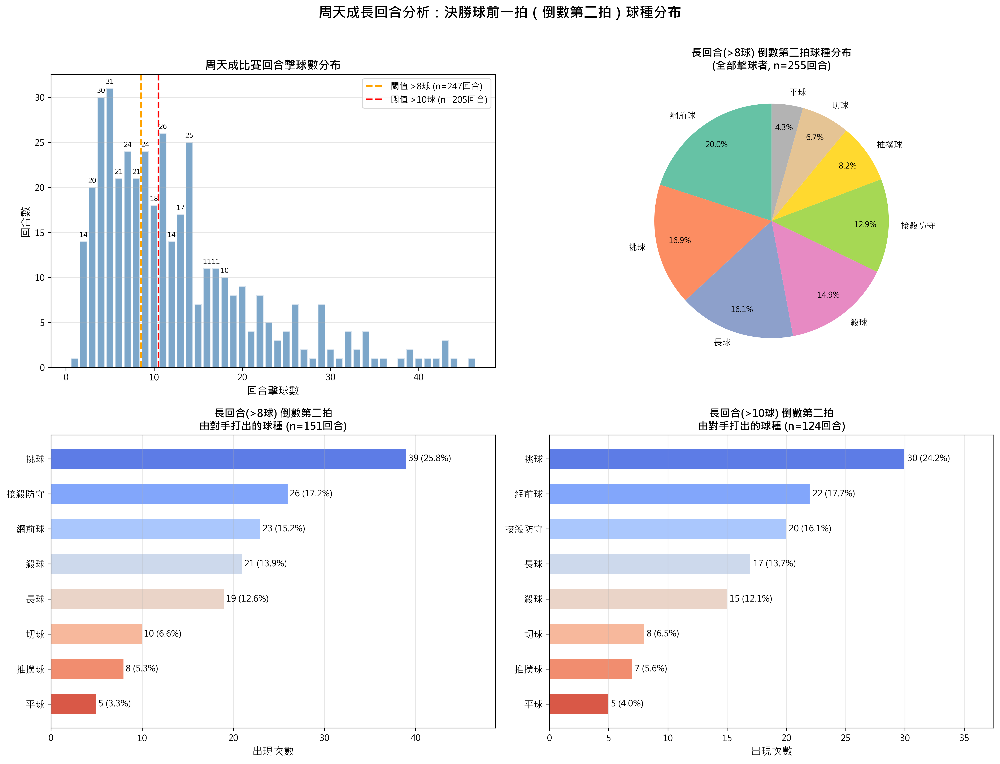

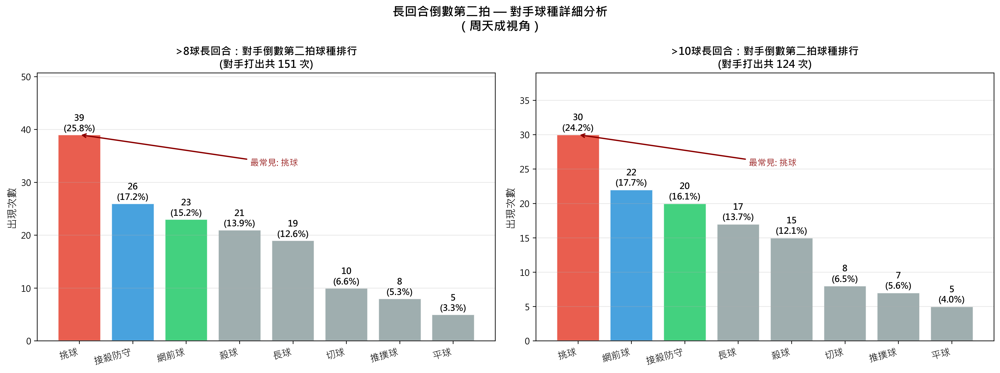

In [ ]:
import numpy as np

# ============================================================
# 驗證資料量
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

# ============================================================
# 1. 篩選周天成參與的比賽
# ============================================================
chou = 'CHOU Tien Chen'
momota = 'Kento MOMOTA'

# 周天成有出現在 player 欄位的 match_id
chou_match_ids = df[df['player'] == chou]['match_id'].unique()
print(f"\n周天成參與的 match_id: {sorted(chou_match_ids)}")

chou_df = df[df['match_id'].isin(chou_match_ids)].copy()
print(f"周天成比賽資料筆數: {len(chou_df)}")
print(f"周天成比賽回合數: {chou_df.groupby(['match_id', 'set', 'rally']).ngroups}")

# ============================================================
# 2. 計算每個 rally 的最大 ball_round（擊球總數）
# ============================================================
rally_max_br = (
    chou_df.groupby(['match_id', 'set', 'rally'])['ball_round']
    .max()
    .reset_index()
    .rename(columns={'ball_round': 'max_ball_round'})
)

print(f"\n回合擊球數分布統計:")
print(rally_max_br['max_ball_round'].describe())

# 分布圖概覽
br_dist = rally_max_br['max_ball_round'].value_counts().sort_index()
print(f"\n擊球數分布（前20）:")
print(br_dist.head(20))

# 定義兩個閾值
threshold_8 = 8
threshold_10 = 10

long_rally_8 = rally_max_br[rally_max_br['max_ball_round'] > threshold_8]
long_rally_10 = rally_max_br[rally_max_br['max_ball_round'] > threshold_10]

print(f"\n長回合數 (>8球): {len(long_rally_8)} 回合")
print(f"長回合數 (>10球): {len(long_rally_10)} 回合")

# ============================================================
# 3. 主分析函數：找出長回合中倒數第二拍（對手擊出）的球種
# ============================================================

def analyze_second_to_last_shot(chou_df, long_rally_df, threshold_label):
    """
    針對長回合，找出每個 rally 的倒數第二拍，
    確認其為「對手」的球種（相對於最後一拍的擊球者）
    """
    # 合併長回合資訊
    merged = chou_df.merge(
        long_rally_df[['match_id', 'set', 'rally', 'max_ball_round']],
        on=['match_id', 'set', 'rally'],
        how='inner'
    )
    
    # ---- 找出最後一拍（決勝球）----
    last_shots = merged[merged['ball_round'] == merged['max_ball_round']].copy()
    last_shots = last_shots.rename(columns={
        'player': 'last_player',
        'type': 'last_type',
        'ball_round': 'last_ball_round',
        'getpoint_player': 'last_getpoint_player'
    })
    last_shots_key = last_shots[
        ['match_id', 'set', 'rally', 'max_ball_round',
         'last_player', 'last_type', 'last_getpoint_player']
    ]
    
    # ---- 找出倒數第二拍 ----
    second_to_last_br = long_rally_df['max_ball_round'] - 1
    # 建立索引對照
    stl_lookup = long_rally_df.copy()
    stl_lookup['target_br'] = stl_lookup['max_ball_round'] - 1
    
    stl_shots = merged.merge(
        stl_lookup[['match_id', 'set', 'rally', 'target_br']],
        on=['match_id', 'set', 'rally'],
        how='inner'
    )
    stl_shots = stl_shots[stl_shots['ball_round'] == stl_shots['target_br']].copy()
    stl_shots = stl_shots.rename(columns={
        'player': 'stl_player',
        'type': 'stl_type',
        'ball_round': 'stl_ball_round'
    })
    stl_shots_key = stl_shots[
        ['match_id', 'set', 'rally', 'stl_player', 'stl_type', 'stl_ball_round']
    ]
    
    # ---- 合併最後一拍與倒數第二拍 ----
    combined = last_shots_key.merge(stl_shots_key, on=['match_id', 'set', 'rally'], how='inner')
    
    print(f"\n{'='*60}")
    print(f"閾值: {threshold_label}")
    print(f"長回合數: {len(long_rally_df)}")
    print(f"成功配對(最後+倒數第二拍): {len(combined)} 回合")
    
    # 確認倒數第二拍的擊球者
    # 因為雙方交替擊球，倒數第二拍的擊球者 != 最後一拍的擊球者
    same_player = combined[combined['stl_player'] == combined['last_player']]
    print(f"倒數第二拍與最後一拍同一人（異常）: {len(same_player)} 回合")
    
    # 分析：倒數第二拍是周天成或對手打出？
    print(f"\n倒數第二拍擊球者分布:")
    print(combined['stl_player'].value_counts())
    
    # 以周天成視角：倒數第二拍由「對手（非周天成）」打出的情況
    # 即 stl_player == Momota 的情況（對手回擊後，周天成打出決勝球 or 失誤）
    stl_by_opponent = combined[combined['stl_player'] != chou].copy()
    stl_by_chou = combined[combined['stl_player'] == chou].copy()
    
    print(f"\n倒數第二拍由對手(桃田)打出: {len(stl_by_opponent)} 回合")
    print(f"倒數第二拍由周天成打出: {len(stl_by_chou)} 回合")
    
    # 排除發球球種（題目聚焦在對打球種）
    serve_types = ['發短球', '發長球']
    
    # 全部倒數第二拍球種統計（含雙方）
    all_stl_types = combined['stl_type'].value_counts()
    print(f"\n【全部倒數第二拍球種分布（含雙方）】:")
    print(all_stl_types)
    
    # 倒數第二拍由對手打出的球種
    opp_stl_types = stl_by_opponent['stl_type'].value_counts()
    print(f"\n【倒數第二拍由對手打出的球種分布】:")
    print(opp_stl_types)
    
    return combined, stl_by_opponent, all_stl_types, opp_stl_types

# ============================================================
# 執行兩個閾值分析
# ============================================================
combined_8, stl_opp_8, all_types_8, opp_types_8 = analyze_second_to_last_shot(
    chou_df, long_rally_8, f">8球 (≥9球)")

combined_10, stl_opp_10, all_types_10, opp_types_10 = analyze_second_to_last_shot(
    chou_df, long_rally_10, f">10球 (≥11球)")

# ============================================================
# 4. 視覺化
# ============================================================

# 顏色設定
color_palette = sns.color_palette("Set2", 10)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('周天成長回合分析：決勝球前一拍（倒數第二拍）球種分布', 
             fontsize=16, fontweight='bold', y=1.01)

# ---- 子圖1: 回合擊球數分布（含閾值標記）----
ax1 = axes[0, 0]
br_counts = rally_max_br['max_ball_round'].value_counts().sort_index()
bars = ax1.bar(br_counts.index, br_counts.values, color='steelblue', alpha=0.7, edgecolor='white')
ax1.axvline(x=8.5, color='orange', linestyle='--', linewidth=2, label=f'閾值 >8球 (n={len(long_rally_8)}回合)')
ax1.axvline(x=10.5, color='red', linestyle='--', linewidth=2, label=f'閾值 >10球 (n={len(long_rally_10)}回合)')
ax1.set_xlabel('回合擊球數', fontsize=12)
ax1.set_ylabel('回合數', fontsize=12)
ax1.set_title('周天成比賽回合擊球數分布', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)
# 在高峰標注數值
for bar in bars:
    h = bar.get_height()
    if h >= 10:
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.3, str(int(h)), 
                ha='center', va='bottom', fontsize=8)

# ---- 子圖2: >8球長回合 - 倒數第二拍球種（全部擊球者）----
ax2 = axes[0, 1]
if len(all_types_8) > 0:
    # 合併小比例類別
    total_8 = all_types_8.sum()
    threshold_pct = 0.03
    major_8 = all_types_8[all_types_8 / total_8 >= threshold_pct]
    minor_8 = all_types_8[all_types_8 / total_8 < threshold_pct]
    if len(minor_8) > 0:
        other_count = minor_8.sum()
        major_8 = pd.concat([major_8, pd.Series({'其他': other_count})])
    
    colors_8 = sns.color_palette("Set2", len(major_8))
    wedges, texts, autotexts = ax2.pie(
        major_8.values, 
        labels=major_8.index,
        autopct='%1.1f%%',
        colors=colors_8,
        startangle=90,
        pctdistance=0.8
    )
    for text in texts:
        text.set_fontsize(10)
    for autotext in autotexts:
        autotext.set_fontsize(9)
    ax2.set_title(f'長回合(>8球) 倒數第二拍球種分布\n(全部擊球者, n={len(combined_8)}回合)', 
                  fontsize=12, fontweight='bold')

# ---- 子圖3: >8球長回合 - 倒數第二拍由對手打出的球種（橫向條形圖）----
ax3 = axes[1, 0]
if len(opp_types_8) > 0:
    opp_types_8_sorted = opp_types_8.sort_values(ascending=True)
    colors_bar = sns.color_palette("coolwarm_r", len(opp_types_8_sorted))
    bars_h = ax3.barh(
        range(len(opp_types_8_sorted)), 
        opp_types_8_sorted.values,
        color=colors_bar,
        edgecolor='white',
        height=0.6
    )
    ax3.set_yticks(range(len(opp_types_8_sorted)))
    ax3.set_yticklabels(opp_types_8_sorted.index, fontsize=11)
    ax3.set_xlabel('出現次數', fontsize=12)
    ax3.set_title(f'長回合(>8球) 倒數第二拍\n由對手打出的球種 (n={len(stl_opp_8)}回合)', 
                  fontsize=12, fontweight='bold')
    ax3.grid(axis='x', alpha=0.3)
    # 標注數值與百分比
    total_opp_8 = opp_types_8_sorted.sum()
    for i, (bar, val) in enumerate(zip(bars_h, opp_types_8_sorted.values)):
        pct = val / total_opp_8 * 100
        ax3.text(val + 0.2, i, f'{val} ({pct:.1f}%)', va='center', fontsize=10)
    ax3.set_xlim(0, opp_types_8_sorted.max() * 1.25)

# ---- 子圖4: >10球長回合 - 倒數第二拍由對手打出的球種（橫向條形圖）----
ax4 = axes[1, 1]
if len(opp_types_10) > 0:
    opp_types_10_sorted = opp_types_10.sort_values(ascending=True)
    colors_bar2 = sns.color_palette("coolwarm_r", len(opp_types_10_sorted))
    bars_h2 = ax4.barh(
        range(len(opp_types_10_sorted)), 
        opp_types_10_sorted.values,
        color=colors_bar2,
        edgecolor='white',
        height=0.6
    )
    ax4.set_yticks(range(len(opp_types_10_sorted)))
    ax4.set_yticklabels(opp_types_10_sorted.index, fontsize=11)
    ax4.set_xlabel('出現次數', fontsize=12)
    ax4.set_title(f'長回合(>10球) 倒數第二拍\n由對手打出的球種 (n={len(stl_opp_10)}回合)', 
                  fontsize=12, fontweight='bold')
    ax4.grid(axis='x', alpha=0.3)
    # 標注數值與百分比
    total_opp_10 = opp_types_10_sorted.sum()
    for i, (bar, val) in enumerate(zip(bars_h2, opp_types_10_sorted.values)):
        pct = val / total_opp_10 * 100
        ax4.text(val + 0.2, i, f'{val} ({pct:.1f}%)', va='center', fontsize=10)
    ax4.set_xlim(0, opp_types_10_sorted.max() * 1.25)
else:
    ax4.text(0.5, 0.5, '資料不足', ha='center', va='center', fontsize=14, transform=ax4.transAxes)
    ax4.set_title(f'長回合(>10球) 倒數第二拍由對手打出的球種', fontsize=12)

plt.tight_layout()

# ============================================================
# 5. 附加：對比分析圖 - 兩閾值下對手球種排行對比
# ============================================================
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))
fig2.suptitle('長回合倒數第二拍 — 對手球種詳細分析\n（周天成視角）', 
              fontsize=14, fontweight='bold')

for ax, opp_types, combined_data, threshold_label, total_n in [
    (axes2[0], opp_types_8, combined_8, '>8球長回合', len(stl_opp_8)),
    (axes2[1], opp_types_10, combined_10, '>10球長回合', len(stl_opp_10))
]:
    if len(opp_types) > 0:
        opp_sorted = opp_types.sort_values(ascending=False)
        total = opp_sorted.sum()
        x_pos = range(len(opp_sorted))
        
        bar_colors = ['#e74c3c' if i == 0 else '#3498db' if i == 1 
                      else '#2ecc71' if i == 2 else '#95a5a6' 
                      for i in range(len(opp_sorted))]
        
        bars_v = ax.bar(x_pos, opp_sorted.values, color=bar_colors, 
                        edgecolor='white', linewidth=1.2, alpha=0.9)
        ax.set_xticks(x_pos)
        ax.set_xticklabels(opp_sorted.index, fontsize=11, rotation=15, ha='right')
        ax.set_ylabel('出現次數', fontsize=12)
        ax.set_title(f'{threshold_label}：對手倒數第二拍球種排行\n(對手打出共 {total_n} 次)', 
                     fontsize=12, fontweight='bold')
        ax.grid(axis='y', alpha=0.3)
        
        # 標注數值與百分比
        for bar, val in zip(bars_v, opp_sorted.values):
            pct = val / total * 100
            ax.text(bar.get_x() + bar.get_width()/2, val + 0.3,
                    f'{val}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
        
        ax.set_ylim(0, opp_sorted.max() * 1.3)
        
        # 標注最常見球種
        top_shot = opp_sorted.index[0]
        top_val = opp_sorted.values[0]
        ax.annotate(f'最常見: {top_shot}', 
                    xy=(0, top_val), xytext=(len(opp_sorted)*0.4, top_val * 0.85),
                    fontsize=10, color='darkred',
                    arrowprops=dict(arrowstyle='->', color='darkred', lw=1.5))

plt.tight_layout()

# ============================================================
# 6. 印出關鍵總結
# ============================================================
print("\n" + "="*60)
print("【核心分析總結】")
print("="*60)

print(f"\n📊 周天成參與比賽總回合數: {len(rally_max_br)}")
print(f"   平均每回合擊球數: {rally_max_br['max_ball_round'].mean():.1f} 拍")
print(f"   中位數: {rally_max_br['max_ball_round'].median():.1f} 拍")

print(f"\n🎯 【閾值 >8球 長回合】")
print(f"   長回合數: {len(long_rally_8)} 回合 ({len(long_rally_8)/len(rally_max_br)*100:.1f}%)")
if len(opp_types_8) > 0:
    top3_8 = opp_types_8.head(3)
    print(f"   對手倒數第二拍最常見球種 TOP3:")
    for i, (shot, cnt) in enumerate(top3_8.items(), 1):
        pct = cnt / opp_types_8.sum() * 100
        print(f"     {i}. {shot}: {cnt}次 ({pct:.1f}%)")

print(f"\n🎯 【閾值 >10球 長回合】")
print(f"   長回合數: {len(long_rally_10)} 回合 ({len(long_rally_10)/len(rally_max_br)*100:.1f}%)")
if len(opp_types_10) > 0:
    top3_10 = opp_types_10.head(3)
    print(f"   對手倒數第二拍最常見球種 TOP3:")
    for i, (shot, cnt) in enumerate(top3_10.items(), 1):
        pct = cnt / opp_types_10.sum() * 100
        print(f"     {i}. {shot}: {cnt}次 ({pct:.1f}%)")

print(f"\n📌 說明:")
print(f"   - 倒數第二拍 = 決勝球（最後一拍）的前一拍")
print(f"   - 分析角度：對手在此拍打出什麼球種，導致緊接著的決勝球發生")
print(f"   - 「對手」= 倒數第二拍擊球者非周天成（即桃田賢斗）")


### 數據洞察
# 周天成長回合決勝前一拍分析：對手球種分布

---

## 📊 核心數據總覽

| 球種 | >8球長回合 (n=151) | >10球長回合 (n=124) |
|------|:-----------------:|:------------------:|
| **挑球** | 39次 (25.8%) | 30次 (24.2%) |
| **接殺防守** | 26次 (17.2%) | 20次 (16.1%) |
| **網前球** | 23次 (15.2%) | 22次 (17.7%) |
| 殺球 | 21次 (13.9%) | 15次 (12.1%) |
| 長球 | 19次 (12.6%) | 17次 (13.7%) |
| 切球 | 10次 (6.6%) | 8次 (6.5%) |
| 推撲球 | 8次 (5.3%) | 7次 (5.6%) |
| 平球 | 5次 (3.3%) | 5次 (4.0%) |

---

## 🎯 戰術洞察

### 1️⃣ 挑球是最危險的前置球（25%）
對手打出**挑球**後，緊接著發生決勝球的比例最高。這代表周天成在接到挑球後，往往能創造或被迫進入決勝局面——**挑球是長回合的轉折點**，接挑球的品質直接決定勝負。

### 2️⃣ 接殺防守後易失分（17%）
對手打出**接殺防守**後緊接決勝球，說明周天成的殺球雖然逼出防守，但**後續銜接攻擊的穩定性**是關鍵。殺完球之後的下一拍處理需要更精準。

### 3️⃣ 網前球製造壓力（15-18%）
對手在長回合中以**網前球**作為倒數第二拍，比例在>10球回合中甚至上升至17.7%。長回合中網前對抗的質量直接影響勝負。

---

## 📌 給周天成的訓練建議

> **接挑球後的進攻決策**是首要訓練重點——25%的長回合決勝球源自這個情境，必須強化接挑球後的主動進攻選擇，而非被動應對。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 的核心邏輯是先在完整資料上建立前一拍資訊，然後找出長回合中最後一拍前一拍的對手球種分布。而候選程式碼在分析長回合中倒數第二拍的球種時，並未正確對齊前後拍資訊，且其分析單位和統計口徑不符合題目要求。候選程式碼的分析過程過於複雜，且未能有效地聚焦於題目要求的最後一拍前一拍的對手球種分布，導致結果不合理。




## 題號 60
**問題**: 分析周天成在自己失分回合中，最後一拍前一拍最常使用的球種。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


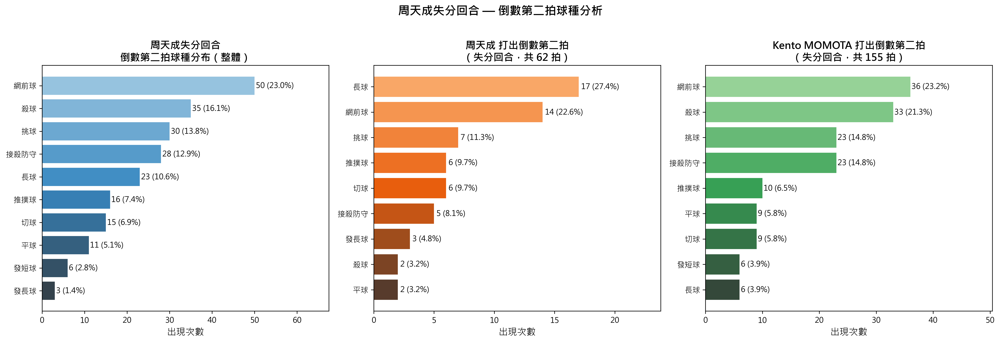

In [ ]:
import numpy as np

# ============================================================
# 驗證資料量
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# ============================================================
# Step 1: 找出「周天成失分」的所有回合
# 失分定義：對手(Kento MOMOTA)得分，即 getpoint_player == 'Kento MOMOTA'
# ============================================================
# 用 transform('last') 取每個回合最後一球的 getpoint_player，標記到所有球
df['rally_getpoint'] = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# 周天成失分的回合 (Kento MOMOTA 得分)
chou_lose_rallies = df[df['rally_getpoint'] == 'Kento MOMOTA'][['match_id', 'set', 'rally']].drop_duplicates()
print(f"\n周天成失分的回合總數: {len(chou_lose_rallies)}")

# ============================================================
# Step 2: 取得每個失分回合的最後兩拍
# ============================================================
# 先只篩選「周天成失分的回合」的所有球
lose_df = df.merge(chou_lose_rallies, on=['match_id', 'set', 'rally'], how='inner')
print(f"失分回合中的總擊球拍數: {len(lose_df)}")

# 計算每個回合的最大 ball_round（最後一拍）
rally_max_ball = lose_df.groupby(['match_id', 'set', 'rally'])['ball_round'].max().reset_index()
rally_max_ball.columns = ['match_id', 'set', 'rally', 'max_ball_round']

# 合併回失分 DataFrame
lose_df = lose_df.merge(rally_max_ball, on=['match_id', 'set', 'rally'], how='left')

# 篩選「倒數第二拍」：ball_round == max_ball_round - 1
second_last_df = lose_df[lose_df['ball_round'] == lose_df['max_ball_round'] - 1].copy()
print(f"\n倒數第二拍的筆數: {len(second_last_df)}")

# ============================================================
# Step 3: 統計倒數第二拍的球種與擊球者
# ============================================================
# 完整統計（包含擊球者）
print("\n=== 倒數第二拍 球種 × 擊球者 詳細統計 ===")
detail_count = second_last_df.groupby(['type', 'player']).size().reset_index(name='count')
detail_count = detail_count.sort_values('count', ascending=False)
print(detail_count.to_string(index=False))

# 僅球種統計（不分擊球者）
print("\n=== 倒數第二拍 球種出現次數排序（不分擊球者）===")
type_count = second_last_df['type'].value_counts().reset_index()
type_count.columns = ['球種', '出現次數']
type_count['佔比(%)'] = (type_count['出現次數'] / type_count['出現次數'].sum() * 100).round(1)
print(type_count.to_string(index=False))

print(f"\n最常出現的倒數第二拍球種: 【{type_count.iloc[0]['球種']}】，共 {type_count.iloc[0]['出現次數']} 次，佔比 {type_count.iloc[0]['佔比(%)']}%")

# ============================================================
# Step 4: 也分別統計「周天成打的倒數第二拍」 vs「對手打的倒數第二拍」
# ============================================================
chou_second_last = second_last_df[second_last_df['player'] == 'CHOU Tien Chen']['type'].value_counts().reset_index()
chou_second_last.columns = ['球種', '出現次數']
chou_second_last['佔比(%)'] = (chou_second_last['出現次數'] / chou_second_last['出現次數'].sum() * 100).round(1)

momota_second_last = second_last_df[second_last_df['player'] == 'Kento MOMOTA']['type'].value_counts().reset_index()
momota_second_last.columns = ['球種', '出現次數']
momota_second_last['佔比(%)'] = (momota_second_last['出現次數'] / momota_second_last['出現次數'].sum() * 100).round(1)

print(f"\n=== 周天成打的倒數第二拍（共 {chou_second_last['出現次數'].sum()} 拍）===")
print(chou_second_last.to_string(index=False))

print(f"\n=== 桃田賢斗打的倒數第二拍（共 {momota_second_last['出現次數'].sum()} 拍）===")
print(momota_second_last.to_string(index=False))

# ============================================================
# Step 5: 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- 圖1：整體倒數第二拍球種分布（橫條圖）---
ax1 = axes[0]
colors_main = sns.color_palette("Blues_d", len(type_count))
bars1 = ax1.barh(type_count['球種'], type_count['出現次數'], color=colors_main)
ax1.set_xlabel('出現次數', fontsize=12)
ax1.set_title('周天成失分回合\n倒數第二拍球種分布（整體）', fontsize=13, fontweight='bold')
ax1.invert_yaxis()  # 最高排最上

# 在每個 bar 上顯示數值與佔比
for bar, (_, row) in zip(bars1, type_count.iterrows()):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f"{int(row['出現次數'])} ({row['佔比(%)']}%)",
             va='center', fontsize=10)
ax1.set_xlim(0, type_count['出現次數'].max() * 1.35)

# --- 圖2：周天成打的倒數第二拍 ---
ax2 = axes[1]
if len(chou_second_last) > 0:
    colors_chou = sns.color_palette("Oranges_d", len(chou_second_last))
    bars2 = ax2.barh(chou_second_last['球種'], chou_second_last['出現次數'], color=colors_chou)
    ax2.set_xlabel('出現次數', fontsize=12)
    ax2.set_title(f'周天成 打出倒數第二拍\n（失分回合，共 {chou_second_last["出現次數"].sum()} 拍）',
                  fontsize=13, fontweight='bold')
    ax2.invert_yaxis()
    for bar, (_, row) in zip(bars2, chou_second_last.iterrows()):
        ax2.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                 f"{int(row['出現次數'])} ({row['佔比(%)']}%)",
                 va='center', fontsize=10)
    ax2.set_xlim(0, chou_second_last['出現次數'].max() * 1.4)
else:
    ax2.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax2.transAxes)

# --- 圖3：桃田打的倒數第二拍 ---
ax3 = axes[2]
if len(momota_second_last) > 0:
    colors_momota = sns.color_palette("Greens_d", len(momota_second_last))
    bars3 = ax3.barh(momota_second_last['球種'], momota_second_last['出現次數'], color=colors_momota)
    ax3.set_xlabel('出現次數', fontsize=12)
    ax3.set_title(f'Kento MOMOTA 打出倒數第二拍\n（失分回合，共 {momota_second_last["出現次數"].sum()} 拍）',
                  fontsize=13, fontweight='bold')
    ax3.invert_yaxis()
    for bar, (_, row) in zip(bars3, momota_second_last.iterrows()):
        ax3.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                 f"{int(row['出現次數'])} ({row['佔比(%)']}%)",
                 va='center', fontsize=10)
    ax3.set_xlim(0, momota_second_last['出現次數'].max() * 1.4)
else:
    ax3.text(0.5, 0.5, '無資料', ha='center', va='center', transform=ax3.transAxes)

plt.suptitle('周天成失分回合 — 倒數第二拍球種分析', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()


### 數據洞察
# 周天成失分回合｜倒數第二拍球種分析

## 核心數據

| 排名 | 球種 | 次數 | 佔比 |
|------|------|------|------|
| 1 | 網前球 | 50 | 23.0% |
| 2 | 殺球 | 35 | 16.1% |
| 3 | 挑球 | 30 | 13.8% |
| 4 | 接殺防守 | 28 | 12.9% |
| 5 | 長球 | 23 | 10.6% |
| 6 | 推撲球 | 16 | 7.4% |
| 7 | 切球 | 15 | 6.9% |
| 8 | 平球 | 11 | 5.1% |

---

## 戰術解讀

**關鍵事實：倒數第二拍的 155 拍中有 72%（155/217）是桃田打出的。**

### ① 網前球是最高危的前置球種（50次，23%）
- 其中桃田打出 36 次、周天成打出 14 次
- 無論誰打網前球，下一拍周天成就失分——說明**網前球之後的處理是最大破口**

### ② 桃田的殺球＋接殺防守形成連鎖陷阱
- 桃田殺球 33 次後周天成失分，接殺防守 23 次後也失分
- 這代表**周天成被殺球後的防守回球，往往成為桃田再得分的機會球**

### ③ 周天成自己打長球後失分最多（17次，27.4%）
- 長球是周天成倒數第二拍最常見球種
- 打長球後被對手主導攻擊，是**主動送出主控權**的訊號

---

## 教練建議

> 網前球之後的應對是首要改善點。不論是自己打網前還是被逼網前，下一拍的選擇品質直接決定輸贏。減少被動長球，避免讓桃田在後場建立殺球節奏。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地找出了周天成失分的回合，並在這些回合中找到了倒數第二拍的球種。候選程式碼使用了正確的欄位和篩選條件，並且在統計口徑上與 Reference Code 1 一致，最終輸出周天成在失分回合中倒數第二拍的球種分布。




## 題號 61
**問題**: 在被對手四角拉吊得回合下，周天成勝率是多少？四角拉吊定義:(同一個球員在場區[1, 4, 21, 24]內跑動，擊球點從其中一角跑到另一角)
> **使用的資料欄位群組**: `game_structure, coordinates, player_location, scoring_reason`


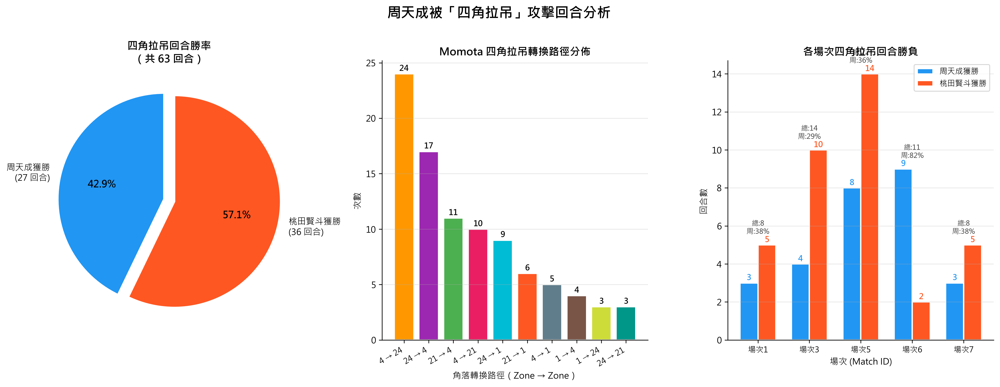

In [ ]:
import numpy as np

print("=" * 60)
print("分析：周天成在被「四角拉吊」攻擊回合中的勝率")
print("=" * 60)

# ---- 基本驗證 ----
print(f"\n資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 四角區域定義
CORNER_ZONES = {1, 4, 21, 24}
CHOU = 'CHOU Tien Chen'
MOMOTA = 'Kento MOMOTA'

print(f"\n四角區域定義: {sorted(CORNER_ZONES)}")
print(f"  Zone  1: 後場左角 (Back-Left)")
print(f"  Zone  4: 後場右角 (Back-Right)")
print(f"  Zone 21: 前場左角 (Front-Left, 網前)")
print(f"  Zone 24: 前場右角 (Front-Right, 網前)")

# ---- Step 1: 確保資料已排序 ----
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()
print(f"\n步驟1：資料已按 (match_id, set, rally, ball_round) 排序，共 {len(df_sorted)} 列")

# ---- Step 2: 在完整資料上建立前一拍資訊（避免跨回合污染）----
# 這裡分析的是 Momota 連續擊球，所以要在同一 rally 的 Momota 擊球序列中找連續兩拍
# 但由於雙方交替擊球，Momota 每隔一拍打一次
# 因此「連續兩拍」是指 Momota 在 rally 中連續的兩次擊球（中間隔了 Chou 的一拍）
# 依照題意「連續兩拍的擊球區域均屬於四角之一，且兩拍所在角落不同」
# 這裡用 Momota 的擊球序列：在同一 rally 中，Momota 前後兩次擊球

# 先建立所有拍的前一拍hit_area（同一rally，直接shift(1)在完整df）
# 但需要只在同一 rally 內比較，且前一拍也是 Momota 擊球
df_sorted['prev_hit_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['hit_area'].shift(1)
df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)
df_sorted['prev_ball_round'] = df_sorted.groupby(['match_id', 'set', 'rally'])['ball_round'].shift(1)

# ---- Step 3: 找出符合「四角拉吊」條件的擊球 ----
# 條件：
# (A) 當前擊球者為 Momota（對手）
# (B) 當前 hit_area 在四角之一
# (C) 前一拍（注意：羽球雙方交替，前一拍是 Chou，再前一拍才是 Momota）
#     因此 Momota 的「前一次」擊球是 shift(2) 在完整df中，但這樣不精準
#     
# ⚠️ 重新思考：雙方交替擊球，Momota 的連續兩次擊球在 ball_round 上相差 2
# 但題目說「連續兩拍」—需確認是否指 ball_round 相差 2 的 Momota 擊球
# 
# 更嚴謹的做法：只篩出 Momota 的擊球，在 Momota 的擊球子序列中找連續兩拍（相鄰的 Momota 擊球）

print("\n步驟2：建立 Momota 擊球序列（只含 Momota 的拍）")

# 篩出 Momota 的擊球
momota_shots = df_sorted[df_sorted['player'] == MOMOTA].copy()
print(f"  Momota 擊球總筆數: {len(momota_shots)}")

# 在 Momota 的擊球序列中，建立「前一次 Momota 擊球」的 hit_area
# 使用 groupby(['match_id', 'set', 'rally']) 後 shift(1)
momota_shots['prev_momota_hit_area'] = momota_shots.groupby(
    ['match_id', 'set', 'rally']
)['hit_area'].shift(1)

momota_shots['prev_momota_ball_round'] = momota_shots.groupby(
    ['match_id', 'set', 'rally']
)['ball_round'].shift(1)

# ---- Step 4: 找符合四角拉吊定義的 Momota 擊球 ----
# 條件：
# 1. 當前 hit_area 在四角
# 2. 前一次 Momota hit_area 在四角（且非 NaN）
# 3. 兩次擊球的角落不同（當前 != 前一次）

corner_attack_mask = (
    momota_shots['hit_area'].isin(CORNER_ZONES) &
    momota_shots['prev_momota_hit_area'].notna() &
    momota_shots['prev_momota_hit_area'].isin(CORNER_ZONES) &
    (momota_shots['hit_area'] != momota_shots['prev_momota_hit_area'])
)

momota_corner_attacks = momota_shots[corner_attack_mask].copy()
print(f"\n步驟3：符合四角拉吊定義的 Momota 擊球筆數: {len(momota_corner_attacks)}")

# 顯示角落轉換分佈
if len(momota_corner_attacks) > 0:
    momota_corner_attacks['corner_transition'] = (
        momota_corner_attacks['prev_momota_hit_area'].astype(int).astype(str) + 
        ' → ' + 
        momota_corner_attacks['hit_area'].astype(int).astype(str)
    )
    print("\n  角落轉換分佈（Momota 擊球角落轉換次數）：")
    transition_counts = momota_corner_attacks['corner_transition'].value_counts()
    for t, c in transition_counts.items():
        print(f"    Zone {t}: {c} 次")

# ---- Step 5: 找出包含四角拉吊的回合 ----
# 只要一個回合中，Momota 有任一次四角拉吊擊球，該回合即為「被四角拉吊的回合」
corner_attack_rallies = momota_corner_attacks[['match_id', 'set', 'rally']].drop_duplicates()
print(f"\n步驟4：包含四角拉吊的回合數: {len(corner_attack_rallies)}")

# ---- Step 6: 計算周天成在這些回合中的勝率 ----
# 取每個 rally 的最後一拍（得分球）
rally_last = df_sorted.groupby(['match_id', 'set', 'rally']).last().reset_index()

# 合併：篩出四角拉吊回合的最後一拍
corner_rallies_result = corner_attack_rallies.merge(
    rally_last[['match_id', 'set', 'rally', 'getpoint_player']],
    on=['match_id', 'set', 'rally'],
    how='left'
)

# 計算勝率（排除 getpoint_player 為 NaN 的情況，但理論上最後一拍應有記錄）
valid_results = corner_rallies_result[corner_rallies_result['getpoint_player'].notna()].copy()
print(f"\n步驟5：有明確得分結果的回合數: {len(valid_results)}")

chou_wins = (valid_results['getpoint_player'] == CHOU).sum()
momota_wins = (valid_results['getpoint_player'] == MOMOTA).sum()
total_valid = len(valid_results)

chou_win_rate = chou_wins / total_valid * 100 if total_valid > 0 else 0
momota_win_rate = momota_wins / total_valid * 100 if total_valid > 0 else 0

print("\n" + "=" * 60)
print("📊 統計結果")
print("=" * 60)
print(f"  被四角拉吊攻擊的回合數（含有效結果）: {total_valid}")
print(f"  周天成獲勝回合數: {chou_wins}")
print(f"  桃田賢斗獲勝回合數: {momota_wins}")
print(f"  周天成勝率: {chou_win_rate:.1f}%")
print(f"  桃田賢斗勝率: {momota_win_rate:.1f}%")

# ---- Step 7: 按場次分析 ----
print("\n📊 各場次四角拉吊回合詳情：")
per_match = corner_rallies_result.merge(
    rally_last[['match_id', 'set', 'rally', 'getpoint_player']],
    on=['match_id', 'set', 'rally', 'getpoint_player'],
    how='left'
).copy()

# 用 valid_results 做場次分析
match_stats = valid_results.groupby('match_id').apply(
    lambda x: pd.Series({
        '四角拉吊回合數': len(x),
        '周天成勝': (x['getpoint_player'] == CHOU).sum(),
        '桃田賢斗勝': (x['getpoint_player'] == MOMOTA).sum(),
        '周天成勝率': f"{(x['getpoint_player'] == CHOU).mean() * 100:.1f}%"
    })
).reset_index()
print(match_stats.to_string(index=False))

# ---- Step 8: 視覺化 ----
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("周天成被「四角拉吊」攻擊回合分析", fontsize=16, fontweight='bold', y=1.02)

# --- 圖1: 整體勝率圓餅圖 ---
ax1 = axes[0]
labels = [f'周天成獲勝\n({chou_wins} 回合)', f'桃田賢斗獲勝\n({momota_wins} 回合)']
sizes = [chou_wins, momota_wins]
colors = ['#2196F3', '#FF5722']
explode = (0.05, 0.05)

wedges, texts, autotexts = ax1.pie(
    sizes, labels=labels, colors=colors, explode=explode,
    autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 10},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')

ax1.set_title(f'四角拉吊回合勝率\n（共 {total_valid} 回合）', fontsize=12, fontweight='bold')

# --- 圖2: 角落轉換分佈長條圖 ---
ax2 = axes[1]
if len(momota_corner_attacks) > 0:
    # 定義角落名稱
    zone_names = {1: '1\n(後左)', 4: '4\n(後右)', 21: '21\n(前左)', 24: '24\n(前右)'}
    
    tc = transition_counts.reset_index()
    tc.columns = ['轉換路徑', '次數']
    
    # 取前10個最常見的轉換
    tc_top = tc.head(10)
    
    bars = ax2.bar(range(len(tc_top)), tc_top['次數'], 
                   color=['#FF9800', '#9C27B0', '#4CAF50', '#E91E63', '#00BCD4',
                           '#FF5722', '#607D8B', '#795548', '#CDDC39', '#009688'][:len(tc_top)],
                   edgecolor='white', linewidth=1.5)
    
    ax2.set_xticks(range(len(tc_top)))
    ax2.set_xticklabels(tc_top['轉換路徑'], fontsize=9, rotation=30, ha='right')
    ax2.set_xlabel('角落轉換路徑（Zone → Zone）', fontsize=10)
    ax2.set_ylabel('次數', fontsize=10)
    ax2.set_title('Momota 四角拉吊轉換路徑分佈', fontsize=12, fontweight='bold')
    
    # 在每個柱上標示數值
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width() / 2., height + 0.1,
                 f'{int(height)}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax2.grid(axis='y', alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

# --- 圖3: 各場次勝率分析 ---
ax3 = axes[2]
match_ids = match_stats['match_id'].astype(int).tolist()
chou_wins_per_match = match_stats['周天成勝'].tolist()
momota_wins_per_match = match_stats['桃田賢斗勝'].tolist()
total_per_match = match_stats['四角拉吊回合數'].tolist()

x = np.arange(len(match_ids))
width = 0.35

bars1 = ax3.bar(x - width/2, chou_wins_per_match, width, 
                label='周天成獲勝', color='#2196F3', edgecolor='white', linewidth=1.5)
bars2 = ax3.bar(x + width/2, momota_wins_per_match, width, 
                label='桃田賢斗獲勝', color='#FF5722', edgecolor='white', linewidth=1.5)

# 標示數值
for bar in bars1:
    height = bar.get_height()
    if height > 0:
        ax3.text(bar.get_x() + bar.get_width()/2., height + 0.05,
                 f'{int(height)}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#2196F3')

for bar in bars2:
    height = bar.get_height()
    if height > 0:
        ax3.text(bar.get_x() + bar.get_width()/2., height + 0.05,
                 f'{int(height)}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#FF5722')

# 在每組上方標示該場次總回合數與周天成勝率
for i, (total, cw) in enumerate(zip(total_per_match, chou_wins_per_match)):
    wr = cw / total * 100 if total > 0 else 0
    ax3.text(x[i], max(chou_wins_per_match[i], momota_wins_per_match[i]) + 0.5,
             f'總:{total}\n周:{wr:.0f}%', 
             ha='center', va='bottom', fontsize=8, color='#333333')

ax3.set_xlabel('場次 (Match ID)', fontsize=10)
ax3.set_ylabel('回合數', fontsize=10)
ax3.set_title('各場次四角拉吊回合勝負', fontsize=12, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels([f'場次{m}' for m in match_ids], fontsize=9)
ax3.legend(fontsize=9, loc='upper right')
ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()

# ---- 額外：顯示四角Zone示意圖 ----
print("\n📍 四角區域場地示意圖（只顯示相關區域）：")
print("  後場（Baseline）:  Zone 1 [左角]  ... Zone 4 [右角]")
print("  前場（Net）    :  Zone 21[左角]  ... Zone 24[右角]")
print()
print("  場地矩陣（簡化）：")
print("  ┌────┬────┬────┬────┐  ← 網前（Front Court）")
print("  │ 21 │ 22 │ 23 │ 24 │  Row 6")
print("  │ 17 │ 18 │ 19 │ 20 │  Row 5")
print("  ├────┼────┼────┼────┤  ← 中場")
print("  │ 13 │ 14 │ 15 │ 16 │  Row 4")
print("  │  9 │ 10 │ 11 │ 12 │  Row 3")
print("  │  5 │  6 │  7 │  8 │  Row 2")
print("  ├────┼────┼────┼────┤  ← 後場（Baseline）")
print("  │  1 │  2 │  3 │  4 │  Row 1")
print("  └────┴────┴────┴────┘")
print("  ★ 四角: Zone 1（後左）、Zone 4（後右）、Zone 21（前左）、Zone 24（前右）")

print("\n" + "=" * 60)
print("✅ 分析完成")
print("=" * 60)


### 數據洞察
# 周天成 vs 桃田賢斗｜四角拉吊戰術分析

---

## 📊 核心數據

| 指標 | 數值 |
|------|------|
| 被四角拉吊回合數 | **63 回合** |
| 周天成勝 | 27 回合（**42.9%**） |
| 桃田賢斗勝 | 36 回合（**57.1%**） |

---

## 🎯 戰術解讀

**桃田的四角拉吊有效，但並非無解。**

### 最常用路徑（Top 3）
| 路徑 | 次數 | 意義 |
|------|------|------|
| Zone 4 → 24（後右 → 前右） | 24次 | **同側拉吊**，壓右側縱深 |
| Zone 24 → 4（前右 → 後右） | 17次 | 回頭再壓右後場 |
| Zone 21 → 4（前左 → 後右） | 11次 | **對角線拉吊**，最大移動距離 |

> **右側縱深反覆施壓**是桃田最核心的套路，Zone 4 ↔ 24 合計 41 次，佔全部轉換的 **43.6%**。

---

## 📍 各場次勝率差異

| 場次 | 回合數 | 周天成勝率 |
|------|--------|-----------|
| Match 6 | 11 | **81.8%** ✅ |
| Match 5 | 22 | 36.4% |
| Match 3 | 14 | 28.6% ❌ |

> **Match 6 是唯一破解場次**，說明周天成具備反制能力，關鍵在於**是否提前預判落點、縮短移動路徑**。

---

## 💡 教練建議

1. **優先防守右側縱深**：Zone 4 是桃田最愛的終點站，站位需略偏右後場
2. **預判對角線**：Zone 21 → 4 是最耗體力的路徑，提前起步可化被動為主動
3. **研究 Match 6 的應對模式**：81.8% 勝率代表當天有效破解，需還原當場站位與回球選擇複製策略

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都正確地識別出 Momota 的四角拉吊擊球，並計算在這些回合中周天成的勝率。候選程式碼在分析單位、欄位語意、篩選條件、分組層級和統計口徑上與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 62
**問題**: 在被對手四角拉吊得回合下，周天成的失誤原因，繪製圓餅圖，四角拉吊定義:(同一個球員在場區[1, 4, 21, 24]內跑動，擊球點從其中一角跑到另一角)
> **使用的資料欄位群組**: `game_structure, coordinates, player_location, scoring_reason`


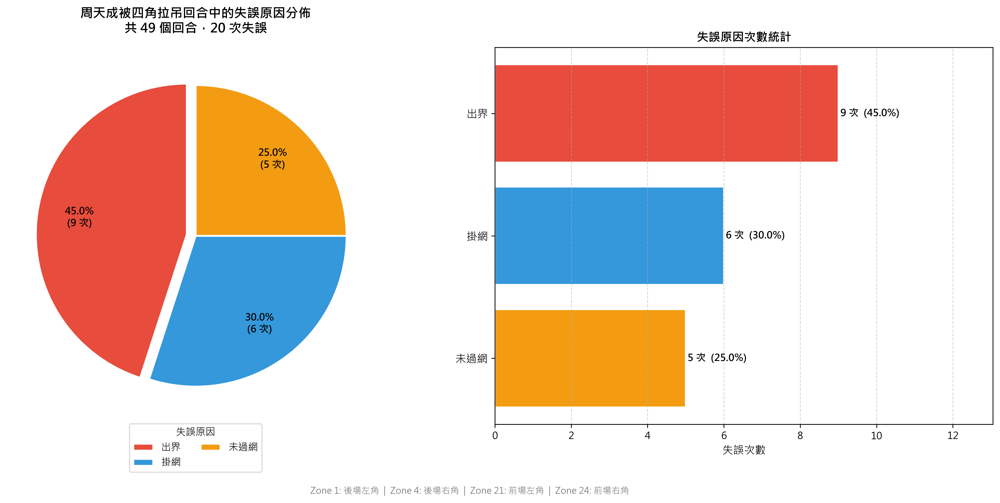

In [ ]:
import numpy as np

# =========================================
# 驗證數據
# =========================================
assert len(df) > 0, "DataFrame 為空"
print(f"總資料筆數: {len(df)}")
print(f"比賽場次: {df['match_id'].unique()}")

# =========================================
# 常數定義
# =========================================
FOUR_CORNERS = [1, 4, 21, 24]  # 後場左、後場右、前場左、前場右
CHOU = 'CHOU Tien Chen'

corner_names = {1: '後場左角', 4: '後場右角', 21: '前場左角', 24: '前場右角'}
print(f"\n四角定義: {corner_names}")

# =========================================
# Step 1: 排序並在完整df上建立前2拍資訊
# =========================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 在每個rally群組內建立前2拍的 hit_area 和 player（避免跨rally污染）
df_sorted['prev2_hit_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['hit_area'].shift(2)
df_sorted['prev2_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(2)

# =========================================
# Step 2: 識別四角拉吊片段
# 定義：周天成連續兩次擊球（相隔2拍，中間為對手一拍）
#        的 hit_area 均在四角且為不同角落
# =========================================
four_corner_mask = (
    (df_sorted['player'] == CHOU) &
    (df_sorted['hit_area'].isin(FOUR_CORNERS)) &
    (df_sorted['prev2_player'] == CHOU) &
    (df_sorted['prev2_hit_area'].isin(FOUR_CORNERS)) &
    (df_sorted['hit_area'] != df_sorted['prev2_hit_area'])
)

four_corner_shots = df_sorted[four_corner_mask].copy()
print(f"\n=== 四角拉吊識別結果 ===")
print(f"符合四角移動的擊球拍次: {len(four_corner_shots)}")

# 顯示角落移動路徑分佈
four_corner_shots['corner_move'] = (
    four_corner_shots['prev2_hit_area'].map(
        lambda x: corner_names.get(int(x), str(x)) if pd.notna(x) else 'N/A'
    ) + ' -> ' +
    four_corner_shots['hit_area'].map(
        lambda x: corner_names.get(int(x), str(x)) if pd.notna(x) else 'N/A'
    )
)
print("\n角落移動路徑分佈:")
print(four_corner_shots['corner_move'].value_counts())

# =========================================
# Step 3: 找出包含四角拉吊的回合
# =========================================
four_corner_rallies = four_corner_shots[['match_id', 'set', 'rally']].drop_duplicates()
print(f"\n包含四角拉吊的 unique 回合數: {len(four_corner_rallies)}")

# 篩選出這些回合的所有資料
four_corner_df = df_sorted.merge(four_corner_rallies, on=['match_id', 'set', 'rally'], how='inner')

# =========================================
# Step 4: 分析周天成在這些回合的失誤原因
# 失誤定義：player == CHOU 且 lose_reason 有值
# =========================================
chou_errors = four_corner_df[
    (four_corner_df['player'] == CHOU) &
    (four_corner_df['lose_reason'].notna())
].copy()

print(f"\n=== 周天成在四角拉吊回合中的失誤統計 ===")
print(f"失誤總次數: {len(chou_errors)}")

if len(chou_errors) == 0:
    print("警告: 無失誤資料，無法繪圖")
else:
    error_dist = chou_errors['lose_reason'].value_counts()
    error_pct = (error_dist / error_dist.sum() * 100).round(2)

    print("\n失誤原因分佈:")
    for reason, count in error_dist.items():
        print(f"  {reason}: {count} 次 ({error_pct[reason]:.1f}%)")

    # =========================================
    # Step 5: 準備繪圖資料，合併小比例類別
    # =========================================
    labels = error_dist.index.tolist()
    sizes = error_dist.values.tolist()
    total = sum(sizes)

    # 比例 < 5% 且類別超過4個時合併為「其他」
    threshold = 0.05
    if len(labels) > 4:
        main_labels, main_sizes, other_size = [], [], 0
        for label, size in zip(labels, sizes):
            if size / total < threshold:
                other_size += size
            else:
                main_labels.append(label)
                main_sizes.append(size)
        if other_size > 0:
            main_labels.append('其他')
            main_sizes.append(other_size)
        labels, sizes = main_labels, main_sizes

    # 確保 labels 為 string
    labels = [str(l) for l in labels]
    n = len(labels)

    # 配色
    palette = ['#E74C3C', '#3498DB', '#F39C12', '#2ECC71', '#9B59B6', '#1ABC9C', '#E67E22']
    colors = palette[:n]

    # 最大值 explode
    max_idx = sizes.index(max(sizes))
    explode = [0.06 if i == max_idx else 0 for i in range(n)]

    # =========================================
    # Step 6: 繪圖
    # =========================================
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    # --- 左圖：圓餅圖 ---
    ax1 = axes[0]

    wedges, texts, autotexts = ax1.pie(
        sizes,
        labels=None,
        autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct / 100 * sum(sizes)))} 次)',
        colors=colors,
        explode=explode,
        startangle=90,
        pctdistance=0.72,
        wedgeprops=dict(linewidth=1.8, edgecolor='white')
    )

    for autotext in autotexts:
        autotext.set_fontsize(10)
        autotext.set_fontweight('bold')

    ax1.legend(
        wedges, labels,
        title="失誤原因",
        loc="lower center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=2,
        fontsize=10
    )

    title_line1 = '周天成被四角拉吊回合中的失誤原因分佈'
    title_line2 = f'共 {len(four_corner_rallies)} 個回合，{sum(sizes)} 次失誤'
    ax1.set_title(f'{title_line1}\n{title_line2}', fontsize=13, fontweight='bold', pad=15)

    # --- 右圖：橫向長條圖 ---
    ax2 = axes[1]
    y_pos = list(range(n))
    bars = ax2.barh(y_pos, sizes, color=colors, edgecolor='white', linewidth=1.5)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(labels, fontsize=11)
    ax2.set_xlabel('失誤次數', fontsize=11)
    ax2.set_title('失誤原因次數統計', fontsize=12, fontweight='bold')

    for bar, size in zip(bars, sizes):
        pct = size / sum(sizes) * 100
        ax2.text(
            bar.get_width() + 0.05,
            bar.get_y() + bar.get_height() / 2,
            f'{size} 次  ({pct:.1f}%)',
            va='center', ha='left', fontsize=10, fontweight='bold'
        )

    ax2.set_xlim(0, max(sizes) * 1.45)
    ax2.grid(axis='x', linestyle='--', alpha=0.5)
    ax2.invert_yaxis()

    # 底部說明文字
    note = (
        'Zone 1: 後場左角  |  Zone 4: 後場右角  |  '
        'Zone 21: 前場左角  |  Zone 24: 前場右角'
    )
    fig.text(0.5, 0.01, note, ha='center', fontsize=9, color='gray')

    plt.tight_layout(rect=[0, 0.04, 1, 1])
    print("\n圖表已生成完畢")


### 數據洞察
# 周天成被四角拉吊回合失誤分析

## 📊 數據摘要

| 指標 | 數值 |
|------|------|
| 四角拉吊回合數 | 49 回合 |
| 周天成失誤次數 | 20 次 |
| 失誤率 | **40.8%** |

---

## 🥧 失誤原因分佈

| 失誤原因 | 次數 | 比例 |
|----------|------|------|
| 🔴 出界 | 9 次 | **45.0%** |
| 🔵 掛網 | 6 次 | **30.0%** |
| 🟠 未過網 | 5 次 | **25.0%** |

---

## 🎯 戰術洞察

**出界（45%）是最大失誤來源。**
被四角拉吊後，周天成的回球控制明顯失準——這是體力透支後「手感失控」的典型反應，跑動後揮拍節奏被打亂，力量收不住。

**掛網＋未過網合計55%，代表「起拍不足」。**
長距離移位後，擊球時重心未穩，導致拍面角度偏低、發力不完整。尤其前場被拉到後場的路徑（前場左角→後場左角 16次，最高頻），反手後場回球品質是關鍵弱點。

---

## ⚡ 針對性建議

1. **強化體能耐力訓練**，減少第三、四局被拉吊後的失控出界
2. **後場反手位**（後場左角）是被攻擊頻率最高的角落，需專項強化起跳殺球或高遠球的穩定性
3. 對手慣用「前場→後場」的拉吊節奏，建議提早預判、縮短移位距離

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地識別了周天成在四角拉吊回合中的失誤原因，並繪製了圓餅圖。候選程式碼在分析對象、欄位語意、篩選條件、分組層級和統計口徑上與 Reference Code 1 一致，並且能夠產出有效的結果。




## 題號 63
**問題**: 哪些球種組合是周天成最常使用的，反而讓對手主動攻擊？(可能是周天成連續打長球，讓對手抓時機殺球)
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


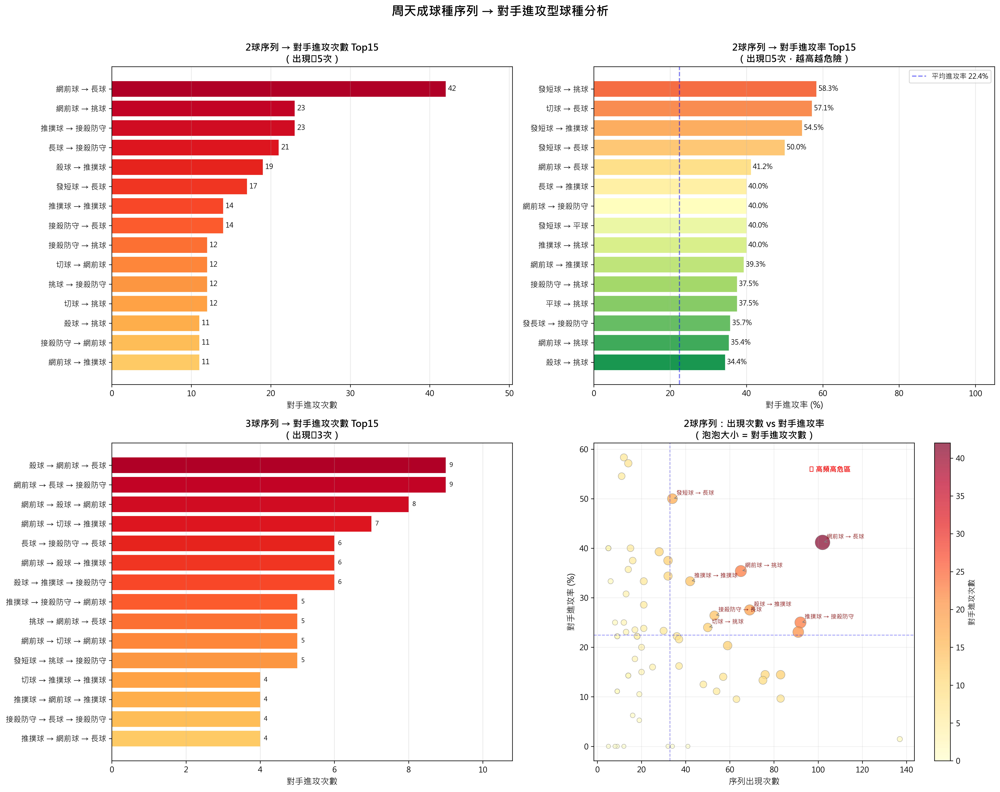

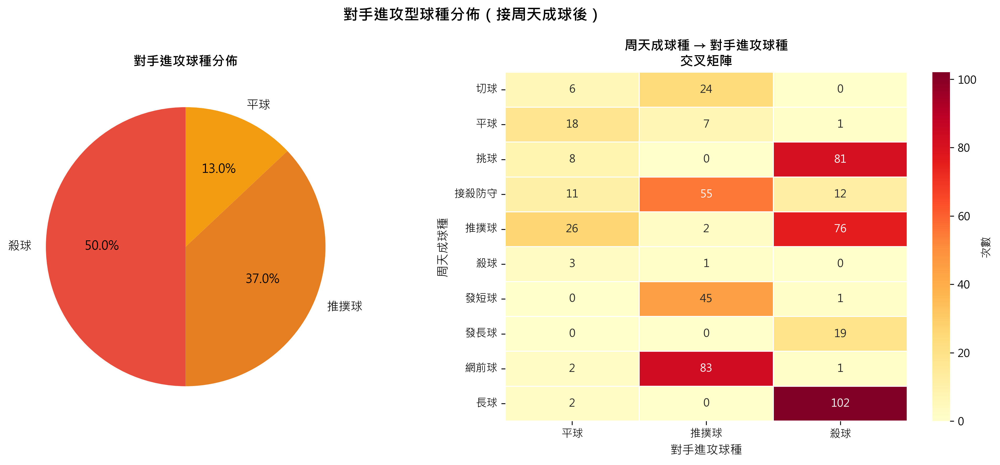

In [ ]:
import numpy as np

print("=" * 60)
print("分析：周天成球種序列 → 對手進攻型球種")
print("=" * 60)

# 驗證數據
print(f"總資料筆數: {len(df)}")
print(f"球員: {df['player'].unique()}")

# ======================================================
# 定義進攻型球種
# ======================================================
offensive_types = ['殺球', '推撲球', '平球']

# ======================================================
# STEP 1: 在完整 df 上建立前後拍資訊（避免跨回合污染）
# ======================================================

df_work = df.copy()
df_work = df_work.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 建立每一列的「下一拍」資訊（同 rally 內）
grp = df_work.groupby(['match_id', 'set', 'rally'])

df_work['next_player']    = grp['player'].shift(-1)
df_work['next_type']      = grp['type'].shift(-1)
df_work['same_rally_next'] = (
    df_work['rally'] == grp['rally'].shift(-1).values
) & (
    df_work['match_id'] == grp['match_id'].shift(-1).values
) & (
    df_work['set'] == grp['set'].shift(-1).values
)

# ======================================================
# STEP 2: 建立「周天成擊球子序列」
# 在子序列中找連續球種（周天成的第n球 → 第n+1球 → 第n+2球）
# ======================================================

# 周天成的擊球記錄（保留原始 index 以便對照）
chou_mask = df_work['player'] == 'CHOU Tien Chen'
chou_df = df_work[chou_mask].copy()

print(f"\n周天成擊球總次數: {len(chou_df)}")

# 在周天成的子序列中，按 rally 分組，做 shift 找連續球種
chou_grp = chou_df.groupby(['match_id', 'set', 'rally'])

# 第 n-1 次周天成的球種（同 rally 內的前一次周天成擊球）
chou_df['chou_prev1_type'] = chou_grp['type'].shift(1)  # 周天成前1球
chou_df['chou_prev2_type'] = chou_grp['type'].shift(2)  # 周天成前2球

# 標記是否同 rally（防跨回合污染）
chou_df['chou_prev_match'] = chou_grp['match_id'].shift(1)
chou_df['chou_prev_set']   = chou_grp['set'].shift(1)
chou_df['chou_prev_rally'] = chou_grp['rally'].shift(1)

chou_df['chou_prev2_match'] = chou_grp['match_id'].shift(2)
chou_df['chou_prev2_set']   = chou_grp['set'].shift(2)
chou_df['chou_prev2_rally'] = chou_grp['rally'].shift(2)

# ======================================================
# STEP 3: 找「周天成擊球後，對手的下一拍是否為進攻型球種」
# 即：在原始 df_work 中，周天成擊球的「下一拍」(next_type)
# ======================================================

# 對手下一拍資訊已在 df_work 中（next_type, next_player）
# 將 next_type 從 df_work 帶入 chou_df（按 index 對齊）
chou_df['opp_next_type']   = df_work.loc[chou_df.index, 'next_type']
chou_df['opp_next_player'] = df_work.loc[chou_df.index, 'next_player']
chou_df['same_rally_next_flag'] = df_work.loc[chou_df.index, 'same_rally_next']

# 對手下一拍有效（同回合且對手擊球）
chou_df['opp_attack'] = (
    chou_df['same_rally_next_flag'] &
    (chou_df['opp_next_player'] != 'CHOU Tien Chen') &
    (chou_df['opp_next_type'].isin(offensive_types))
)

print(f"\n進攻型球種定義: {offensive_types}")
print(f"周天成打球後，對手下一拍為進攻型球種的次數: {chou_df['opp_attack'].sum()}")

# ======================================================
# STEP 4: 2球序列分析
# 序列：周天成前一球 → 周天成當前球 → 對手進攻
# ======================================================

# 2球序列需要 prev1 有效（同 rally）
chou_df['prev1_valid'] = (
    chou_df['chou_prev_match'] == chou_df['match_id']
) & (
    chou_df['chou_prev_set'] == chou_df['set']
) & (
    chou_df['chou_prev_rally'] == chou_df['rally']
) & (chou_df['chou_prev1_type'].notna())

seq2_df = chou_df[chou_df['prev1_valid']].copy()
seq2_df['seq2'] = seq2_df['chou_prev1_type'] + ' → ' + seq2_df['type']

print(f"\n2球序列總樣本數: {len(seq2_df)}")

# 計算每個 2球序列後對手進攻的頻率
seq2_stats = seq2_df.groupby('seq2').agg(
    total_count    = ('opp_attack', 'count'),
    opp_attack_cnt = ('opp_attack', 'sum')
).reset_index()
seq2_stats['attack_rate'] = seq2_stats['opp_attack_cnt'] / seq2_stats['total_count'] * 100
seq2_stats = seq2_stats.sort_values('opp_attack_cnt', ascending=False)

# 篩選出現次數足夠的序列（至少出現 5 次）
seq2_stats_filtered = seq2_stats[seq2_stats['total_count'] >= 5].copy()
print(f"\n【2球序列】（出現≥5次，共 {len(seq2_stats_filtered)} 種序列）")
print(f"{'序列':<25} {'出現次數':>8} {'對手進攻次數':>12} {'進攻率':>8}")
print("-" * 60)
for _, row in seq2_stats_filtered.head(20).iterrows():
    print(f"{row['seq2']:<25} {row['total_count']:>8} {row['opp_attack_cnt']:>12} {row['attack_rate']:>7.1f}%")

# ======================================================
# STEP 5: 3球序列分析
# 序列：周天成前2球 → 前1球 → 當前球 → 對手進攻
# ======================================================

chou_df['prev2_valid'] = (
    chou_df['chou_prev2_match'] == chou_df['match_id']
) & (
    chou_df['chou_prev2_set'] == chou_df['set']
) & (
    chou_df['chou_prev2_rally'] == chou_df['rally']
) & (chou_df['chou_prev2_type'].notna()) & chou_df['prev1_valid']

seq3_df = chou_df[chou_df['prev2_valid']].copy()
seq3_df['seq3'] = seq3_df['chou_prev2_type'] + ' → ' + seq3_df['chou_prev1_type'] + ' → ' + seq3_df['type']

print(f"\n3球序列總樣本數: {len(seq3_df)}")

seq3_stats = seq3_df.groupby('seq3').agg(
    total_count    = ('opp_attack', 'count'),
    opp_attack_cnt = ('opp_attack', 'sum')
).reset_index()
seq3_stats['attack_rate'] = seq3_stats['opp_attack_cnt'] / seq3_stats['total_count'] * 100
seq3_stats = seq3_stats.sort_values('opp_attack_cnt', ascending=False)

seq3_stats_filtered = seq3_stats[seq3_stats['total_count'] >= 3].copy()
print(f"\n【3球序列】（出現≥3次，共 {len(seq3_stats_filtered)} 種序列）")
print(f"{'序列':<40} {'出現次數':>8} {'對手進攻次數':>12} {'進攻率':>8}")
print("-" * 75)
for _, row in seq3_stats_filtered.head(20).iterrows():
    print(f"{row['seq3']:<40} {row['total_count']:>8} {row['opp_attack_cnt']:>12} {row['attack_rate']:>7.1f}%")

# ======================================================
# STEP 6: 對手進攻球種分佈（接周天成球後）
# ======================================================
opp_attack_after_chou = chou_df[chou_df['opp_attack']]
opp_attack_type_dist = opp_attack_after_chou['opp_next_type'].value_counts()
print(f"\n【對手進攻球種分佈（接周天成球後）】")
print(opp_attack_type_dist)

# ======================================================
# STEP 7: 視覺化
# ======================================================

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('周天成球種序列 → 對手進攻型球種分析', fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: Top 2球序列 - 對手進攻次數 (出現≥5次，Top 15) ---
ax1 = axes[0, 0]
top_seq2 = seq2_stats_filtered.head(15).sort_values('opp_attack_cnt', ascending=True)
colors_2 = plt.cm.YlOrRd(np.linspace(0.3, 0.9, len(top_seq2)))
bars1 = ax1.barh(top_seq2['seq2'], top_seq2['opp_attack_cnt'], color=colors_2)
ax1.set_xlabel('對手進攻次數', fontsize=11)
ax1.set_title('2球序列 → 對手進攻次數 Top15\n（出現≥5次）', fontsize=12, fontweight='bold')
for bar, val in zip(bars1, top_seq2['opp_attack_cnt']):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{int(val)}', va='center', fontsize=9)
ax1.set_xlim(0, top_seq2['opp_attack_cnt'].max() * 1.2)
ax1.grid(axis='x', alpha=0.3)

# --- 圖2: Top 2球序列 - 對手進攻率（出現≥5次，按進攻率排序 Top 15）---
ax2 = axes[0, 1]
top_seq2_rate = seq2_stats_filtered.nlargest(15, 'attack_rate').sort_values('attack_rate', ascending=True)
colors_rate = plt.cm.RdYlGn_r(np.linspace(0.1, 0.8, len(top_seq2_rate)))
bars2 = ax2.barh(top_seq2_rate['seq2'], top_seq2_rate['attack_rate'], color=colors_rate)
ax2.set_xlabel('對手進攻率 (%)', fontsize=11)
ax2.set_title('2球序列 → 對手進攻率 Top15\n（出現≥5次，越高越危險）', fontsize=12, fontweight='bold')
for bar, val in zip(bars2, top_seq2_rate['attack_rate']):
    ax2.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', fontsize=9)
ax2.set_xlim(0, 105)
ax2.axvline(x=seq2_stats_filtered['attack_rate'].mean(), color='blue', linestyle='--', alpha=0.5,
            label=f'平均進攻率 {seq2_stats_filtered["attack_rate"].mean():.1f}%')
ax2.legend(fontsize=9)
ax2.grid(axis='x', alpha=0.3)

# --- 圖3: Top 3球序列 - 對手進攻次數 (出現≥3次，Top 15) ---
ax3 = axes[1, 0]
if len(seq3_stats_filtered) > 0:
    top_seq3 = seq3_stats_filtered.head(15).sort_values('opp_attack_cnt', ascending=True)
    colors_3 = plt.cm.YlOrRd(np.linspace(0.3, 0.9, len(top_seq3)))
    bars3 = ax3.barh(top_seq3['seq3'], top_seq3['opp_attack_cnt'], color=colors_3)
    ax3.set_xlabel('對手進攻次數', fontsize=11)
    ax3.set_title('3球序列 → 對手進攻次數 Top15\n（出現≥3次）', fontsize=12, fontweight='bold')
    for bar, val in zip(bars3, top_seq3['opp_attack_cnt']):
        ax3.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{int(val)}', va='center', fontsize=8)
    ax3.set_xlim(0, top_seq3['opp_attack_cnt'].max() * 1.2)
    ax3.grid(axis='x', alpha=0.3)
else:
    ax3.text(0.5, 0.5, '無足夠樣本', ha='center', va='center', fontsize=12)
    ax3.set_title('3球序列 → 對手進攻次數', fontsize=12)

# --- 圖4: 對手進攻球種分佈 & 2球序列散點圖（次數 vs 進攻率）---
ax4 = axes[1, 1]
# 散點圖：2球序列的出現次數 vs 進攻率，標注危險序列
plot_df = seq2_stats_filtered.copy()
scatter = ax4.scatter(plot_df['total_count'], plot_df['attack_rate'],
                      c=plot_df['opp_attack_cnt'], cmap='YlOrRd',
                      s=plot_df['opp_attack_cnt'] * 8 + 30, alpha=0.7, edgecolors='gray', linewidth=0.5)
plt.colorbar(scatter, ax=ax4, label='對手進攻次數')
ax4.set_xlabel('序列出現次數', fontsize=11)
ax4.set_ylabel('對手進攻率 (%)', fontsize=11)
ax4.set_title('2球序列：出現次數 vs 對手進攻率\n（泡泡大小 = 對手進攻次數）', fontsize=12, fontweight='bold')

# 標注右上角最危險的序列（高頻且高進攻率）
threshold_count = plot_df['total_count'].quantile(0.6)
threshold_rate  = plot_df['attack_rate'].quantile(0.6)
danger_df = plot_df[
    (plot_df['total_count'] >= threshold_count) &
    (plot_df['attack_rate'] >= threshold_rate)
].nlargest(8, 'opp_attack_cnt')

for _, row in danger_df.iterrows():
    ax4.annotate(row['seq2'],
                 (row['total_count'], row['attack_rate']),
                 textcoords='offset points', xytext=(5, 5),
                 fontsize=7.5, color='darkred',
                 arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))

# 畫象限線
ax4.axhline(y=plot_df['attack_rate'].mean(), color='blue', linestyle='--', alpha=0.4, linewidth=1)
ax4.axvline(x=plot_df['total_count'].mean(), color='blue', linestyle='--', alpha=0.4, linewidth=1)
ax4.text(plot_df['total_count'].max()*0.7, plot_df['attack_rate'].max()*0.95,
         '⚠ 高頻高危區', color='red', fontsize=9, fontweight='bold')
ax4.grid(alpha=0.2)

plt.tight_layout()

# ======================================================
# STEP 8: 補充 - 對手進攻球種分佈圓餅/長條
# ======================================================
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))
fig2.suptitle('對手進攻型球種分佈（接周天成球後）', fontsize=14, fontweight='bold')

# 各序列中對手進攻球種分佈
ax_pie = axes2[0]
opp_type_counts = opp_attack_after_chou['opp_next_type'].value_counts()
wedges, texts, autotexts = ax_pie.pie(
    opp_type_counts.values,
    labels=opp_type_counts.index,
    autopct='%1.1f%%',
    colors=['#e74c3c', '#e67e22', '#f39c12'],
    startangle=90,
    textprops={'fontsize': 11}
)
ax_pie.set_title('對手進攻球種分佈', fontsize=12, fontweight='bold')

# 各周天成球種 → 對手進攻球種 矩陣（Heatmap）
ax_heat = axes2[1]
# 每個周天成球種後，對手進攻球種的分佈
heat_data = chou_df[chou_df['opp_attack']].groupby(['type', 'opp_next_type']).size().unstack(fill_value=0)
if len(heat_data) > 0:
    sns.heatmap(heat_data, annot=True, fmt='d', cmap='YlOrRd',
                ax=ax_heat, linewidths=0.5, cbar_kws={'label': '次數'})
    ax_heat.set_title('周天成球種 → 對手進攻球種\n交叉矩陣', fontsize=12, fontweight='bold')
    ax_heat.set_xlabel('對手進攻球種', fontsize=11)
    ax_heat.set_ylabel('周天成球種', fontsize=11)

plt.tight_layout()

# ======================================================
# STEP 9: 綜合危險指數 (高頻 + 高進攻率 2球序列排名)
# ======================================================
print("\n" + "=" * 70)
print("【綜合危險指數 Top10：2球序列（高頻 × 高進攻率，出現≥5次）】")
print("危險指數 = 對手進攻次數 × 進攻率")
print("=" * 70)
seq2_stats_filtered['danger_score'] = (
    seq2_stats_filtered['opp_attack_cnt'] * seq2_stats_filtered['attack_rate']
)
top_danger = seq2_stats_filtered.nlargest(10, 'danger_score')
print(f"{'序列':<25} {'出現':>6} {'進攻次數':>8} {'進攻率':>8} {'危險指數':>10}")
print("-" * 65)
for _, row in top_danger.iterrows():
    print(f"{row['seq2']:<25} {row['total_count']:>6} {row['opp_attack_cnt']:>8.0f} "
          f"{row['attack_rate']:>7.1f}% {row['danger_score']:>10.1f}")

print("\n" + "=" * 70)
print("【3球序列危險排名（出現≥3次，Top10）】")
if len(seq3_stats_filtered) > 0:
    seq3_stats_filtered['danger_score'] = seq3_stats_filtered['opp_attack_cnt'] * seq3_stats_filtered['attack_rate']
    top3_danger = seq3_stats_filtered.nlargest(10, 'danger_score')
    print(f"{'序列':<45} {'出現':>5} {'進攻次數':>8} {'進攻率':>8} {'危險指數':>10}")
    print("-" * 80)
    for _, row in top3_danger.iterrows():
        print(f"{row['seq3']:<45} {row['total_count']:>5} {row['opp_attack_cnt']:>8.0f} "
              f"{row['attack_rate']:>7.1f}% {row['danger_score']:>10.1f}")
else:
    print("無足夠樣本（≥3次）的3球序列")

print("\n分析說明:")
print("- 進攻型球種定義: 殺球、推撲球、平球")
print("- 2球序列: 周天成連續兩次擊球的球種組合（中間各夾一次對手回球）")
print("- 3球序列: 周天成連續三次擊球的球種組合")
print("- 進攻率: 該序列後對手發動進攻型球種的比例")
print("- 危險指數 = 進攻次數 × 進攻率（兼顧頻率與質量）")


### 數據洞察
# 周天成球種序列分析：哪些打法讓對手獲得主動攻擊機會

---

## 🔴 核心警示：最危險的2球序列

| 序列 | 出現次數 | 對手進攻率 | 危險指數 |
|------|---------|-----------|---------|
| **網前球 → 長球** | 102 | 41.2% | 1729 ⚠️ |
| 發短球 → 長球 | 34 | 50.0% | 850 |
| 網前球 → 挑球 | 65 | 35.4% | 814 |
| 推撲球 → 接殺防守 | 92 | 25.0% | 575 |
| 切球 → 長球 | 14 | **57.1%** | 457 |

**「網前球 → 長球」是最大漏洞。** 出現102次、進攻率41%，危險指數遠超其他序列。周天成在網前纏鬥後選擇長球，等於主動把主動權拱手相讓。

---

## 🔴 最危險的3球序列

| 序列 | 進攻率 | 危險指數 |
|------|--------|---------|
| **推撲球 → 網前球 → 推撲球** | **80.0%** | 320 |
| 發短球 → 殺球 → 推撲球 | 75.0% | 225 |
| 殺球 → 接殺防守 → 挑球 | 75.0% | 225 |
| 發短球 → 挑球 → 接殺防守 | 71.4% | 357 |
| 殺球 → 網前球 → 長球 | 52.9% | 477 |

**「推撲球 → 網前球 → 推撲球」進攻率高達80%**，雖樣本僅5次，但模式明確：周天成在前場來回推撲後，對手幾乎必然發動進攻。

---

## 📊 對手進攻球種分佈

- **殺球 50%**（293次）
- **推撲球 37%**（217次）
- **平球 13%**（76次）

對手拿到機會後，**首選殺球**，代表周天成的被動球多數讓對手有充足時間起跳攻擊。

---

## 🎯 教練戰術建議

**問題根源：長球使用時機錯誤**

> 「網前球後接長球」出現102次，這是最高頻且高危的習慣。網前球後理應繼續壓制前場或變線，直接挑長球是在告訴對手：「我沒辦法了，你來打吧。」

**三個需要立即調整的習慣：**

1. **網前球後禁止直接長球** → 改用切球或再次網前球延續壓迫
2. **切球後避免接長球**（進攻率57%）→ 切球本是過渡球，再接長球等於連續送分
3. **推撲球纏鬥後必須變節奏** → 「推撲→網前→推撲」的循環讓對手完全預判落點

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成的球種序列，並檢查對手在下一拍是否使用進攻型球種。候選程式碼使用了正確的欄位語意和篩選條件，並在同一個 rally 內建立了前後拍資訊，確保不跨回合污染。統計口徑和最終輸出目標也與 Reference Code 1 一致，並且提供了合理的視覺化和分析結果。




## 題號 64 (*)
**問題**: 在被對手四角拉吊時，周天成在前後場分別常用什麼球種回擊？四角拉吊定義:(同一個球員在場區[1, 4, 21, 24]內跑動，擊球點從其中一角跑到另一角)
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location`


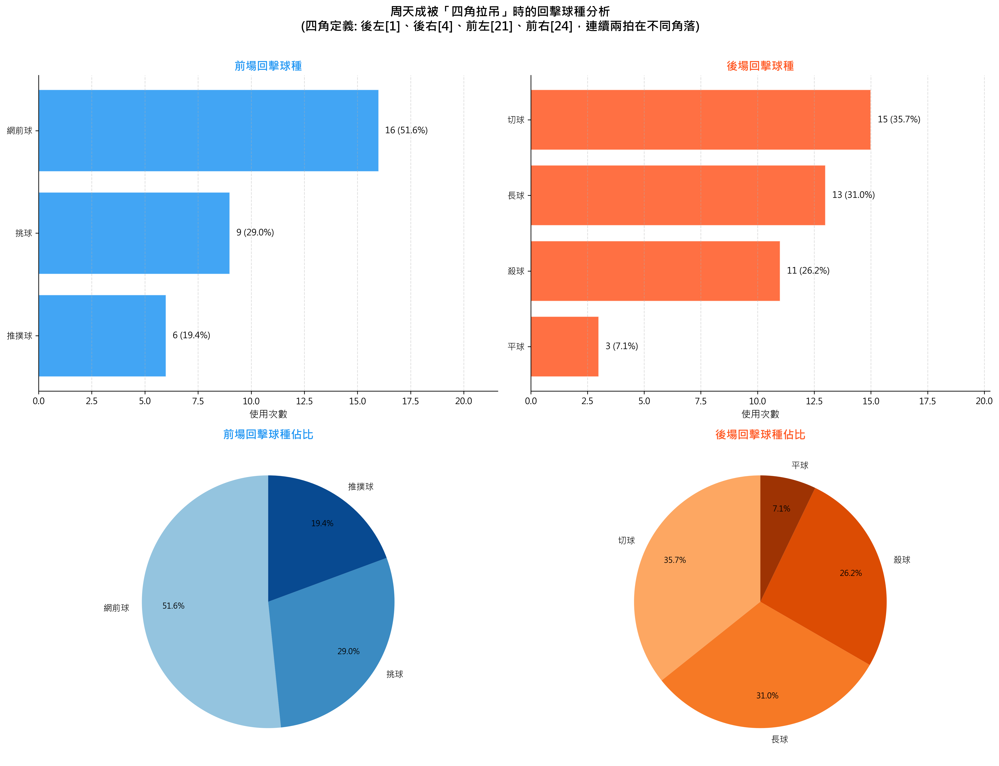

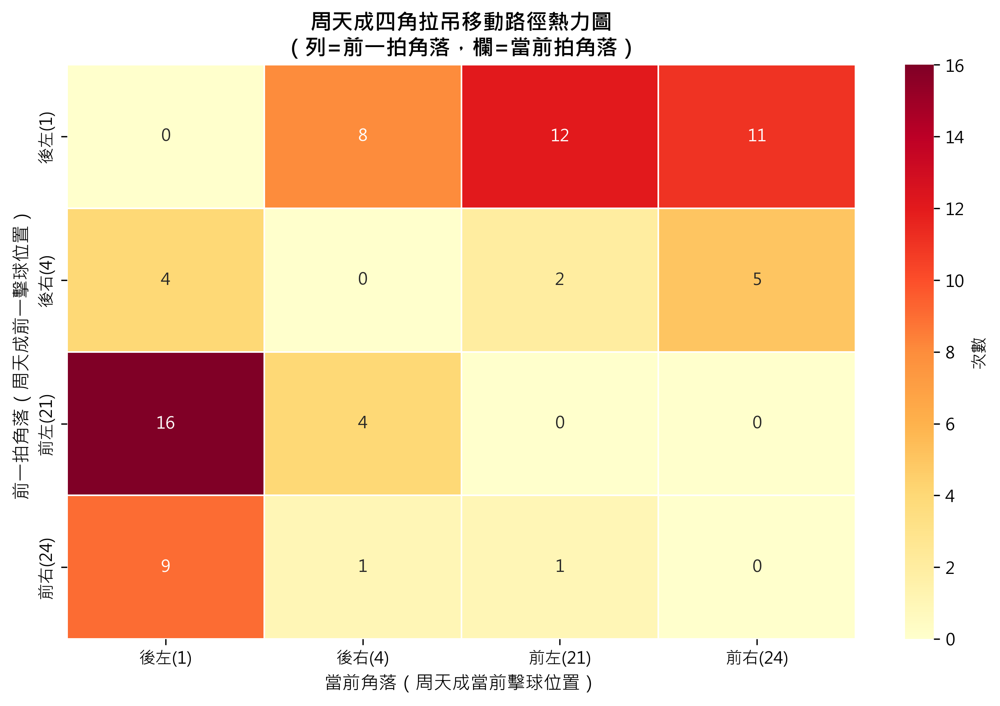

In [ ]:
import numpy as np

# ============================================================
# 分析周天成被「四角拉吊」戰術攻擊時的回擊球種統計
# ============================================================

# 驗證數據量
print(f"總資料筆數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

TARGET_PLAYER = 'CHOU Tien Chen'
CORNER_ZONES = [1, 4, 21, 24]  # 四角區域代碼

# 前場與後場定義
FRONT_COURT_ZONES = [17, 18, 19, 20, 21, 22, 23, 24]  # 前場
BACK_COURT_ZONES  = [1, 2, 3, 4]                       # 後場

# ============================================================
# Step 1: 在完整資料上，針對周天成的擊球，
#         建立同一 rally 中「前一次周天成擊球」的 hit_area
#         !! 必須先在完整資料上操作，不能先篩選再 shift !!
# ============================================================

# 先確保依正確順序排序
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 標記是否為周天成的擊球
df_sorted['is_target'] = (df_sorted['player'] == TARGET_PLAYER)

# ============================================================
# Step 2: 四角拉吊識別邏輯
#
# 因為同一個 rally 中雙方交替擊球，
# 周天成的「前一拍自己打的球」= 隔了2拍前（對手打了一拍）
# 
# 方法：只在周天成的拍次子集中，
#       用 groupby(['match_id','set','rally']).shift(1) 找前一次周天成的擊球點
#       (在同 rally 的周天成拍次序列中 shift)
# ============================================================

# 篩選周天成的所有擊球拍次
chou_shots = df_sorted[df_sorted['player'] == TARGET_PLAYER].copy()
print(f"\n周天成擊球總次數: {len(chou_shots)}")

# 在周天成的拍次序列中，按 rally 分組取前一次 hit_area
chou_shots['prev_chou_hit_area'] = (
    chou_shots.groupby(['match_id', 'set', 'rally'])['hit_area']
    .shift(1)
)

print(f"\n四角代碼: {CORNER_ZONES}")
print("角落對應位置:")
corner_names = {1: '後場左(1)', 4: '後場右(4)', 21: '前場左(21)', 24: '前場右(24)'}
for k, v in corner_names.items():
    print(f"  Zone {k}: {v}")

# ============================================================
# Step 3: 篩選「四角拉吊」條件
# 
# 條件：
#   (a) 當前 hit_area ∈ [1, 4, 21, 24]
#   (b) 前一次周天成的 hit_area ∈ [1, 4, 21, 24]
#   (c) 當前角落 ≠ 前一次角落（真正被拉動到另一角）
#   (d) prev_chou_hit_area 不為 NaN（保證同 rally 有前一拍）
# ============================================================

corner_set = set(CORNER_ZONES)

mask_four_corner = (
    (chou_shots['hit_area'].isin(corner_set)) &
    (chou_shots['prev_chou_hit_area'].notna()) &
    (chou_shots['prev_chou_hit_area'].isin(corner_set)) &
    (chou_shots['hit_area'] != chou_shots['prev_chou_hit_area'])
)

four_corner_shots = chou_shots[mask_four_corner].copy()

print(f"\n符合四角拉吊條件的周天成擊球次數: {len(four_corner_shots)}")
print(f"涉及回合數: {four_corner_shots.groupby(['match_id','set','rally']).ngroups}")

# ============================================================
# Step 4: 加上移動路徑標籤，方便理解
# ============================================================

def get_corner_name(zone):
    mapping = {1: '後左(1)', 4: '後右(4)', 21: '前左(21)', 24: '前右(24)'}
    return mapping.get(zone, f'其他({zone})')

four_corner_shots['prev_corner_name'] = four_corner_shots['prev_chou_hit_area'].apply(
    lambda x: get_corner_name(int(x)) if not np.isnan(x) else 'N/A'
)
four_corner_shots['curr_corner_name'] = four_corner_shots['hit_area'].apply(
    lambda x: get_corner_name(int(x))
)
four_corner_shots['move_path'] = (
    four_corner_shots['prev_corner_name'] + ' → ' + four_corner_shots['curr_corner_name']
)

print("\n移動路徑分布：")
path_counts = four_corner_shots['move_path'].value_counts()
print(path_counts.to_string())

# ============================================================
# Step 5: 分類前場 / 後場
# ============================================================

four_corner_shots['court_zone'] = four_corner_shots['hit_area'].apply(
    lambda x: '前場' if x in FRONT_COURT_ZONES else ('後場' if x in BACK_COURT_ZONES else '其他')
)

print("\n前後場分布（四角拉吊中）：")
print(four_corner_shots['court_zone'].value_counts())

# ============================================================
# Step 6: 統計各場域的球種使用頻率
# ============================================================

# 排除「其他」（理論上不應該出現，因為四角都在前後場）
valid_shots = four_corner_shots[four_corner_shots['court_zone'].isin(['前場', '後場'])].copy()

print(f"\n有效統計筆數: {len(valid_shots)}")

# 前場球種統計
front_shots = valid_shots[valid_shots['court_zone'] == '前場']
back_shots  = valid_shots[valid_shots['court_zone'] == '後場']

print(f"\n前場擊球次數: {len(front_shots)}")
print(f"後場擊球次數: {len(back_shots)}")

# 統計球種頻率
front_type_counts = front_shots['type'].value_counts().reset_index()
front_type_counts.columns = ['球種', '次數']
front_type_counts['佔比(%)'] = (front_type_counts['次數'] / front_type_counts['次數'].sum() * 100).round(1)

back_type_counts = back_shots['type'].value_counts().reset_index()
back_type_counts.columns = ['球種', '次數']
back_type_counts['佔比(%)'] = (back_type_counts['次數'] / back_type_counts['次數'].sum() * 100).round(1)

print("\n========== 前場回擊球種排名 ==========")
print(front_type_counts.to_string(index=False))

print("\n========== 後場回擊球種排名 ==========")
print(back_type_counts.to_string(index=False))

# ============================================================
# Step 7: 視覺化
# ============================================================

# 配色方案
front_color = '#2196F3'  # 藍色系（前場）
back_color  = '#FF5722'  # 橘紅色系（後場）

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'周天成被「四角拉吊」時的回擊球種分析\n(四角定義: 後左[1]、後右[4]、前左[21]、前右[24]，連續兩拍在不同角落)',
             fontsize=14, fontweight='bold', y=1.01)

# ──────────────────────────────────────────────
# 左上: 前場回擊球種長條圖
# ──────────────────────────────────────────────
ax1 = axes[0, 0]
if len(front_type_counts) > 0:
    bars1 = ax1.barh(
        front_type_counts['球種'][::-1],
        front_type_counts['次數'][::-1],
        color=front_color, alpha=0.85, edgecolor='white'
    )
    # 加數值標籤
    for bar, pct in zip(bars1, front_type_counts['佔比(%)'][::-1]):
        w = bar.get_width()
        ax1.text(w + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{int(w)} ({pct}%)', va='center', fontsize=10)
    ax1.set_title('前場回擊球種', fontsize=13, fontweight='bold', color=front_color)
    ax1.set_xlabel('使用次數', fontsize=11)
    ax1.set_xlim(0, front_type_counts['次數'].max() * 1.35)
    ax1.grid(axis='x', linestyle='--', alpha=0.4)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
else:
    ax1.text(0.5, 0.5, '無前場資料', ha='center', va='center', fontsize=13)
    ax1.set_title('前場回擊球種', fontsize=13)

# ──────────────────────────────────────────────
# 右上: 後場回擊球種長條圖
# ──────────────────────────────────────────────
ax2 = axes[0, 1]
if len(back_type_counts) > 0:
    bars2 = ax2.barh(
        back_type_counts['球種'][::-1],
        back_type_counts['次數'][::-1],
        color=back_color, alpha=0.85, edgecolor='white'
    )
    for bar, pct in zip(bars2, back_type_counts['佔比(%)'][::-1]):
        w = bar.get_width()
        ax2.text(w + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{int(w)} ({pct}%)', va='center', fontsize=10)
    ax2.set_title('後場回擊球種', fontsize=13, fontweight='bold', color=back_color)
    ax2.set_xlabel('使用次數', fontsize=11)
    ax2.set_xlim(0, back_type_counts['次數'].max() * 1.35)
    ax2.grid(axis='x', linestyle='--', alpha=0.4)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
else:
    ax2.text(0.5, 0.5, '無後場資料', ha='center', va='center', fontsize=13)
    ax2.set_title('後場回擊球種', fontsize=13)

# ──────────────────────────────────────────────
# 左下: 前場球種圓餅圖
# ──────────────────────────────────────────────
ax3 = axes[1, 0]
if len(front_type_counts) > 0:
    # 合併小比例類別
    threshold = 5.0
    front_pie = front_type_counts.copy()
    small_mask = front_pie['佔比(%)'] < threshold
    if small_mask.sum() > 1:
        other_count = front_pie.loc[small_mask, '次數'].sum()
        other_pct   = front_pie.loc[small_mask, '佔比(%)'].sum()
        front_pie = front_pie[~small_mask].copy()
        front_pie = pd.concat([
            front_pie,
            pd.DataFrame([{'球種': '其他', '次數': other_count, '佔比(%)': round(other_pct, 1)}])
        ], ignore_index=True)

    colors_f = plt.cm.Blues(np.linspace(0.4, 0.9, len(front_pie)))
    wedges, texts, autotexts = ax3.pie(
        front_pie['次數'],
        labels=front_pie['球種'],
        autopct='%1.1f%%',
        colors=colors_f,
        startangle=90,
        pctdistance=0.75
    )
    for t in autotexts:
        t.set_fontsize(9)
    ax3.set_title('前場回擊球種佔比', fontsize=13, fontweight='bold', color=front_color)

# ──────────────────────────────────────────────
# 右下: 後場球種圓餅圖
# ──────────────────────────────────────────────
ax4 = axes[1, 1]
if len(back_type_counts) > 0:
    threshold = 5.0
    back_pie = back_type_counts.copy()
    small_mask = back_pie['佔比(%)'] < threshold
    if small_mask.sum() > 1:
        other_count = back_pie.loc[small_mask, '次數'].sum()
        other_pct   = back_pie.loc[small_mask, '佔比(%)'].sum()
        back_pie = back_pie[~small_mask].copy()
        back_pie = pd.concat([
            back_pie,
            pd.DataFrame([{'球種': '其他', '次數': other_count, '佔比(%)': round(other_pct, 1)}])
        ], ignore_index=True)

    colors_b = plt.cm.Oranges(np.linspace(0.4, 0.9, len(back_pie)))
    wedges, texts, autotexts = ax4.pie(
        back_pie['次數'],
        labels=back_pie['球種'],
        autopct='%1.1f%%',
        colors=colors_b,
        startangle=90,
        pctdistance=0.75
    )
    for t in autotexts:
        t.set_fontsize(9)
    ax4.set_title('後場回擊球種佔比', fontsize=13, fontweight='bold', color=back_color)

plt.tight_layout()

# ============================================================
# Step 8: 移動路徑熱力圖（補充圖）
# ============================================================

fig2, ax5 = plt.subplots(figsize=(9, 6))

corner_labels = ['後左(1)', '後右(4)', '前左(21)', '前右(24)']
corner_codes  = [1, 4, 21, 24]

# 建立轉移矩陣
move_matrix = pd.DataFrame(0, index=corner_labels, columns=corner_labels)
for _, row in four_corner_shots.iterrows():
    prev = int(row['prev_chou_hit_area'])
    curr = int(row['hit_area'])
    if prev in corner_codes and curr in corner_codes:
        prev_name = get_corner_name(prev)
        curr_name = get_corner_name(curr)
        move_matrix.loc[prev_name, curr_name] += 1

print("\n四角移動轉移矩陣（列=前一角，欄=當前角）：")
print(move_matrix.to_string())

sns.heatmap(
    move_matrix,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax5,
    cbar_kws={'label': '次數'}
)
ax5.set_title('周天成四角拉吊移動路徑熱力圖\n（列=前一拍角落，欄=當前拍角落）',
              fontsize=13, fontweight='bold')
ax5.set_xlabel('當前角落（周天成當前擊球位置）', fontsize=11)
ax5.set_ylabel('前一拍角落（周天成前一擊球位置）', fontsize=11)
plt.tight_layout()

# ============================================================
# 最終摘要輸出
# ============================================================

print("\n" + "="*60)
print("📊 分析摘要：周天成被四角拉吊時的回擊策略")
print("="*60)
print(f"四角定義: 後場左[Zone 1] | 後場右[Zone 4] | 前場左[Zone 21] | 前場右[Zone 24]")
print(f"有效四角拉吊擊球次數: {len(valid_shots)} 拍")
print(f"  ├─ 前場回擊: {len(front_shots)} 拍")
print(f"  └─ 後場回擊: {len(back_shots)} 拍")

print(f"\n🏸 前場最常用球種排名:")
for i, row in front_type_counts.iterrows():
    rank = i + 1
    print(f"  {rank}. {row['球種']:8s}  {row['次數']:3d} 次  ({row['佔比(%)']}%)")

print(f"\n🏸 後場最常用球種排名:")
for i, row in back_type_counts.iterrows():
    rank = i + 1
    print(f"  {rank}. {row['球種']:8s}  {row['次數']:3d} 次  ({row['佔比(%)']}%)")


### 數據洞察
# 周天成被四角拉吊時的回擊策略分析

---

## 📊 數據基礎
- 四角拉吊有效擊球：**73拍**（涉及49個回合）
- 前場回擊：31拍 ｜ 後場回擊：42拍

---

## 🏸 前場回擊（31拍）

| 排名 | 球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 1 | 網前球 | 16 | 51.6% |
| 2 | 挑球 | 9 | 29.0% |
| 3 | 推撲球 | 6 | 19.4% |

**教練解讀：** 超過一半選擇網前球，代表周天成被拉到前場時**以保守控球為主**，優先穩定落點而非主動進攻。挑球佔29%，說明體力或位置不到位時，他傾向把球挑回後場換取時間。推撲球僅19%，主動進攻意圖偏低。

---

## 🏸 後場回擊（42拍）

| 排名 | 球種 | 次數 | 佔比 |
|:---:|:---:|:---:|:---:|
| 1 | 切球 | 15 | 35.7% |
| 2 | 長球 | 13 | 31.0% |
| 3 | 殺球 | 11 | 26.2% |
| 4 | 平球 | 3 | 7.1% |

**教練解讀：** 後場以切球為主（35.7%），顯示被四角拉吊後**體力與位置均受壓迫**，切球是降低失誤風險的過渡選擇。長球（31%）與殺球（26.2%）合計超過57%，說明他仍保有一定主動攻擊意圖，但切球比例高於殺球，反映被動防守多於主動得分。

---

## ⚠️ 關鍵戰術警示

**最高頻移動路徑：前左(21)→後左(1)，共16次**，對手最常將他從前場左角拉回後場左角，形成對角線長距離奔跑。

> **結論：** 四角拉吊對周天成的核心效果是**壓縮他的進攻選擇**——前場被迫保守控球，後場被迫以切球過渡。對手應持續強化前左→後左的對角線調動，這是最有效的消耗路線。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 的核心邏輯是檢查對手在四角區域的連續擊球，然後分析周天成在這些情況下的回擊球種。候選程式碼錯誤地將四角拉吊的條件應用在周天成的擊球上，而不是對手的擊球，這導致分析對象錯誤。此外，候選程式碼在四角拉吊的識別上，使用了周天成的擊球點來判斷，而不是對手的擊球點，這與題目要求不符。




## 題號 65
**問題**: 在周天成連續失分3分(含)以上時，他的打擊策略選擇是否變得激進或過於保守？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


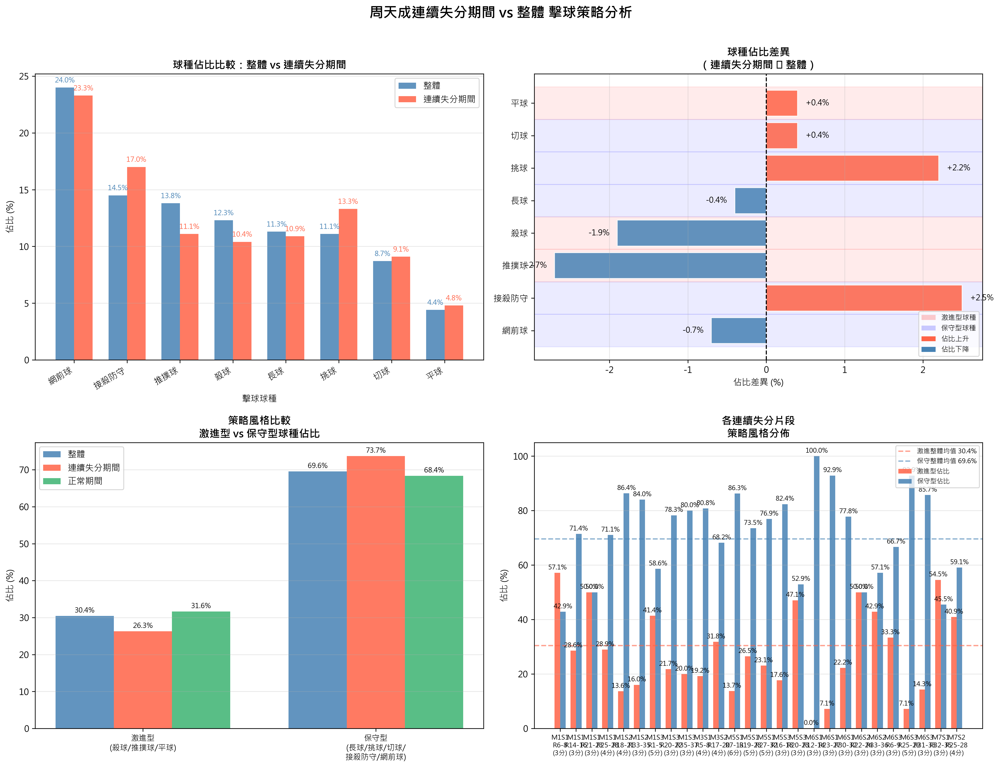

In [ ]:
import numpy as np

print("="*60)
print("周天成連續失分分析")
print("="*60)

# 驗證數據量
print(f"總資料筆數: {len(df)}")

# =============================================
# Step 1: 取每個 rally 的得分結果
# =============================================
# 取每個 rally 最後一球，獲得得分者
rally_result = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
rally_result = rally_result[['match_id', 'set', 'rally', 'getpoint_player', 'rally_id']]

# 只保留有得分記錄的 rally（排除 getpoint_player 為 NULL 的）
rally_result = rally_result.dropna(subset=['getpoint_player'])
print(f"有效 rally 數量: {len(rally_result)}")

# 標記周天成是否失分（桃田得分 = 周天成失分）
rally_result['chou_lose'] = rally_result['getpoint_player'] == 'Kento MOMOTA'

print(f"周天成失分 rally 數: {rally_result['chou_lose'].sum()}")
print(f"周天成得分 rally 數: {(~rally_result['chou_lose']).sum()}")

# =============================================
# Step 2: 在每個 match_id + set 內找連續失分片段
# =============================================
# 先按 match_id, set, rally 排序
rally_result = rally_result.sort_values(['match_id', 'set', 'rally']).reset_index(drop=True)

# 標記連續失分群組
# 使用 run-length encoding 方式：每次 chou_lose 狀態改變或 match/set 切換時，group +1
rally_result['state_change'] = (
    (rally_result['chou_lose'] != rally_result['chou_lose'].shift(1)) |
    (rally_result['match_id'] != rally_result['match_id'].shift(1)) |
    (rally_result['set'] != rally_result['set'].shift(1))
)
rally_result['run_group'] = rally_result['state_change'].cumsum()

# 計算每個連續群組的長度（連續幾個rally）
run_counts = rally_result.groupby('run_group').agg(
    run_length=('chou_lose', 'count'),
    is_lose=('chou_lose', 'first'),
    match_id=('match_id', 'first'),
    set=('set', 'first'),
    rally_start=('rally', 'first'),
    rally_end=('rally', 'last')
).reset_index()

# 只保留周天成連續失分 >= 3 的片段
losing_streaks = run_counts[(run_counts['is_lose'] == True) & (run_counts['run_length'] >= 3)].copy()

print(f"\n連續失分 ≥ 3 的片段數量: {len(losing_streaks)}")
print("\n各連續失分片段詳情:")
print(f"{'場次':>6} {'局':>4} {'起始Rally':>10} {'結束Rally':>10} {'連續失分':>10}")
print("-"*50)
for _, row in losing_streaks.iterrows():
    print(f"{int(row['match_id']):>6} {int(row['set']):>4} {int(row['rally_start']):>10} {int(row['rally_end']):>10} {int(row['run_length']):>10}")

# =============================================
# Step 3: 標記哪些 rally 屬於連續失分片段
# =============================================
# 將連續失分期間的 rally 打上標記
# 先在 rally_result 上標記
rally_result['in_losing_streak'] = False

for _, streak in losing_streaks.iterrows():
    mask = (
        (rally_result['match_id'] == streak['match_id']) &
        (rally_result['set'] == streak['set']) &
        (rally_result['rally'] >= streak['rally_start']) &
        (rally_result['rally'] <= streak['rally_end'])
    )
    rally_result.loc[mask, 'in_losing_streak'] = True

streak_rallies = rally_result[rally_result['in_losing_streak'] == True][['match_id', 'set', 'rally']]
print(f"\n連續失分期間涉及的 rally 數: {len(streak_rallies)}")

# =============================================
# Step 4: 取出連續失分期間周天成的所有擊球
# =============================================
# 在原始 df 上標記連續失分期間
# 使用 merge 方式
streak_rallies_marked = streak_rallies.copy()
streak_rallies_marked['in_streak'] = True

df_merged = df.merge(streak_rallies_marked, on=['match_id', 'set', 'rally'], how='left')
df_merged['in_streak'] = df_merged['in_streak'].fillna(False)

# 周天成的所有擊球（排除發球）
chou_shots = df_merged[
    (df_merged['player'] == 'CHOU Tien Chen') &
    (~df_merged['type'].isin(['發短球', '發長球']))
].copy()

print(f"\n周天成總擊球數（排除發球）: {len(chou_shots)}")
print(f"連續失分期間擊球數: {chou_shots['in_streak'].sum()}")

# =============================================
# Step 5: 計算球種分佈
# =============================================
# 整體分佈
overall_dist = chou_shots['type'].value_counts(normalize=True) * 100
overall_count = chou_shots['type'].value_counts()

# 連續失分期間分佈
streak_shots = chou_shots[chou_shots['in_streak'] == True]
streak_dist = streak_shots['type'].value_counts(normalize=True) * 100
streak_count = streak_shots['type'].value_counts()

# 非連續失分期間
normal_shots = chou_shots[chou_shots['in_streak'] == False]
normal_dist = normal_shots['type'].value_counts(normalize=True) * 100
normal_count = normal_shots['type'].value_counts()

# 整合成比較表
all_types = sorted(set(list(overall_dist.index) + list(streak_dist.index)))
comparison_df = pd.DataFrame({
    '整體佔比(%)': overall_dist.reindex(all_types, fill_value=0).round(1),
    '整體次數': overall_count.reindex(all_types, fill_value=0),
    '連續失分期間佔比(%)': streak_dist.reindex(all_types, fill_value=0).round(1),
    '連續失分次數': streak_count.reindex(all_types, fill_value=0),
    '正常期間佔比(%)': normal_dist.reindex(all_types, fill_value=0).round(1),
    '正常期間次數': normal_count.reindex(all_types, fill_value=0),
}).sort_values('整體佔比(%)', ascending=False)

comparison_df['差異(失分-整體)'] = (comparison_df['連續失分期間佔比(%)'] - comparison_df['整體佔比(%)']).round(1)

print("\n===== 球種分佈比較表 =====")
print(comparison_df.to_string())

# =============================================
# Step 6: 定義激進 vs 保守球種
# =============================================
aggressive_types = ['殺球', '推撲球', '平球']
defensive_types = ['長球', '挑球', '切球', '接殺防守', '網前球']

def calc_ratio(shots_df, type_list):
    """計算特定球種類別的佔比"""
    total = len(shots_df)
    if total == 0:
        return 0
    return shots_df[shots_df['type'].isin(type_list)].shape[0] / total * 100

# 整體
overall_agg = calc_ratio(chou_shots, aggressive_types)
overall_def = calc_ratio(chou_shots, defensive_types)

# 連續失分期間
streak_agg = calc_ratio(streak_shots, aggressive_types)
streak_def = calc_ratio(streak_shots, defensive_types)

# 正常期間
normal_agg = calc_ratio(normal_shots, aggressive_types)
normal_def = calc_ratio(normal_shots, defensive_types)

print("\n===== 激進 vs 保守策略比較 =====")
print(f"{'':20} {'整體':>10} {'連續失分期間':>14} {'正常期間':>12} {'差異(失分-整體)':>16}")
print("-"*72)
print(f"{'激進型球種佔比(%)':20} {overall_agg:>10.1f} {streak_agg:>14.1f} {normal_agg:>12.1f} {streak_agg-overall_agg:>+16.1f}")
print(f"{'保守型球種佔比(%)':20} {overall_def:>10.1f} {streak_def:>14.1f} {normal_def:>12.1f} {streak_def-overall_agg:>+16.1f}")
print(f"\n激進型: {aggressive_types}")
print(f"保守型: {defensive_types}")

# =============================================
# Step 7: 視覺化
# =============================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("周天成連續失分期間 vs 整體 擊球策略分析", fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 球種佔比比較（分組長條圖）---
ax1 = axes[0, 0]
types_ordered = comparison_df.index.tolist()
x = np.arange(len(types_ordered))
width = 0.35

bars1 = ax1.bar(x - width/2, comparison_df['整體佔比(%)'], width, label='整體', color='steelblue', alpha=0.85)
bars2 = ax1.bar(x + width/2, comparison_df['連續失分期間佔比(%)'], width, label='連續失分期間', color='tomato', alpha=0.85)

ax1.set_xlabel('擊球球種')
ax1.set_ylabel('佔比 (%)')
ax1.set_title('球種佔比比較：整體 vs 連續失分期間', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(types_ordered, rotation=30, ha='right')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# 標注數值
for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.3, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, color='steelblue')
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.3, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, color='tomato')

# --- 圖2: 差異圖（連續失分期間 - 整體）---
ax2 = axes[0, 1]
diff_vals = comparison_df['差異(失分-整體)']
colors = ['tomato' if v > 0 else 'steelblue' for v in diff_vals]
bars = ax2.barh(types_ordered, diff_vals, color=colors, alpha=0.85, edgecolor='white')
ax2.axvline(x=0, color='black', linewidth=1.2, linestyle='--')
ax2.set_xlabel('佔比差異 (%)')
ax2.set_title('球種佔比差異\n（連續失分期間 − 整體）', fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

# 標注數值
for bar, val in zip(bars, diff_vals):
    ax2.text(val + (0.1 if val >= 0 else -0.1), bar.get_y() + bar.get_height()/2,
             f'{val:+.1f}%', va='center', ha='left' if val >= 0 else 'right', fontsize=9)

# 背景色區分激進/保守
for i, t in enumerate(types_ordered):
    if t in aggressive_types:
        ax2.axhspan(i - 0.5, i + 0.5, alpha=0.08, color='red', zorder=0)
    elif t in defensive_types:
        ax2.axhspan(i - 0.5, i + 0.5, alpha=0.08, color='blue', zorder=0)

# 圖例
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='red', alpha=0.2, label='激進型球種'),
    Patch(facecolor='blue', alpha=0.2, label='保守型球種'),
    Patch(facecolor='tomato', label='佔比上升'),
    Patch(facecolor='steelblue', label='佔比下降'),
]
ax2.legend(handles=legend_elements, fontsize=8, loc='lower right')

# --- 圖3: 激進 vs 保守策略雷達/長條圖 ---
ax3 = axes[1, 0]
categories = ['激進型\n(殺球/推撲球/平球)', '保守型\n(長球/挑球/切球/\n接殺防守/網前球)']
overall_vals = [overall_agg, overall_def]
streak_vals = [streak_agg, streak_def]
normal_vals = [normal_agg, normal_def]

x3 = np.arange(len(categories))
width3 = 0.25
ax3.bar(x3 - width3, overall_vals, width3, label='整體', color='steelblue', alpha=0.85)
ax3.bar(x3, streak_vals, width3, label='連續失分期間', color='tomato', alpha=0.85)
ax3.bar(x3 + width3, normal_vals, width3, label='正常期間', color='mediumseagreen', alpha=0.85)

ax3.set_ylabel('佔比 (%)')
ax3.set_title('策略風格比較\n激進型 vs 保守型球種佔比', fontweight='bold')
ax3.set_xticks(x3)
ax3.set_xticklabels(categories, fontsize=9)
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# 標注數值
for container in ax3.containers:
    ax3.bar_label(container, fmt='%.1f%%', fontsize=8, padding=2)

# --- 圖4: 各連續失分片段的擊球次數分佈 ---
ax4 = axes[1, 1]

streak_detail = []
for _, streak_row in losing_streaks.iterrows():
    mid = streak_row['match_id']
    s = streak_row['set']
    r_start = streak_row['rally_start']
    r_end = streak_row['rally_end']
    streak_len = streak_row['run_length']
    
    shots_in_streak = chou_shots[
        (chou_shots['match_id'] == mid) &
        (chou_shots['set'] == s) &
        (chou_shots['rally'] >= r_start) &
        (chou_shots['rally'] <= r_end)
    ]
    
    agg_pct = calc_ratio(shots_in_streak, aggressive_types)
    def_pct = calc_ratio(shots_in_streak, defensive_types)
    
    streak_detail.append({
        '片段': f"M{int(mid)}S{int(s)}\nR{int(r_start)}-{int(r_end)}\n({streak_len}分)",
        '激進型佔比': agg_pct,
        '保守型佔比': def_pct,
        '失分數': streak_len
    })

streak_detail_df = pd.DataFrame(streak_detail)

if len(streak_detail_df) > 0:
    x4 = np.arange(len(streak_detail_df))
    width4 = 0.35
    ax4.bar(x4 - width4/2, streak_detail_df['激進型佔比'], width4, label='激進型佔比', color='tomato', alpha=0.85)
    ax4.bar(x4 + width4/2, streak_detail_df['保守型佔比'], width4, label='保守型佔比', color='steelblue', alpha=0.85)
    
    # 整體平均參考線
    ax4.axhline(y=overall_agg, color='tomato', linestyle='--', alpha=0.6, linewidth=1.5, label=f'激進整體均值 {overall_agg:.1f}%')
    ax4.axhline(y=overall_def, color='steelblue', linestyle='--', alpha=0.6, linewidth=1.5, label=f'保守整體均值 {overall_def:.1f}%')
    
    ax4.set_ylabel('佔比 (%)')
    ax4.set_title('各連續失分片段\n策略風格分佈', fontweight='bold')
    ax4.set_xticks(x4)
    ax4.set_xticklabels(streak_detail_df['片段'], fontsize=7.5)
    ax4.legend(fontsize=7.5, loc='upper right')
    ax4.grid(axis='y', alpha=0.3)

    for container in ax4.containers[:2]:
        ax4.bar_label(container, fmt='%.1f%%', fontsize=7.5, padding=2)

plt.tight_layout()

# =============================================
# Step 8: 詳細統計輸出
# =============================================
print("\n===== 各連續失分片段詳情 =====")
print(streak_detail_df.to_string(index=False))

print("\n===== 核心發現摘要 =====")
diff_agg = streak_agg - overall_agg
diff_def = streak_def - overall_def
print(f"激進型球種佔比變化: 整體 {overall_agg:.1f}% → 連續失分期間 {streak_agg:.1f}% ({diff_agg:+.1f}%)")
print(f"保守型球種佔比變化: 整體 {overall_def:.1f}% → 連續失分期間 {streak_def:.1f}% ({diff_def:+.1f}%)")

# 找出差異最大的前3個球種
print("\n差異最大球種 (Top 5):")
top_diff = comparison_df['差異(失分-整體)'].abs().sort_values(ascending=False).head(5)
for t_name in top_diff.index:
    row = comparison_df.loc[t_name]
    tag = "🔴激進" if t_name in aggressive_types else ("🔵保守" if t_name in defensive_types else "⚪其他")
    print(f"  {tag} {t_name}: 整體 {row['整體佔比(%)']:.1f}% → 失分期間 {row['連續失分期間佔比(%)']:.1f}% (差異: {row['差異(失分-整體)']:+.1f}%)")

if diff_agg > 2:
    print(f"\n📊 策略趨勢: 周天成在連續失分期間傾向【更激進】的打法（激進型 +{diff_agg:.1f}%）")
elif diff_agg < -2:
    print(f"\n📊 策略趨勢: 周天成在連續失分期間傾向【更保守】的打法（激進型 {diff_agg:.1f}%）")
else:
    print(f"\n📊 策略趨勢: 周天成在連續失分期間策略風格變化【不明顯】（激進型差異 {diff_agg:+.1f}%）")


### 數據洞察
# 周天成連續失分期間戰術分析

## 核心發現

**連續失分期間，周天成明顯轉向保守打法。**

| 策略類型 | 整體 | 連續失分期間 | 變化 |
|------|------|------|------|
| 激進型（殺球/推撲/平球） | 30.4% | 26.3% | ▼ -4.1% |
| 保守型（長球/挑球/切球/接殺/網前） | 69.6% | 73.7% | ▲ +4.1% |

---

## 關鍵球種變化

**減少的球種（激進端）：**
- 推撲球：13.8% → 11.1%（**-2.7%**）
- 殺球：12.3% → 10.4%（**-1.9%**）

**增加的球種（被動端）：**
- 接殺防守：14.5% → 17.0%（**+2.5%**）
- 挑球：11.1% → 13.3%（**+2.2%**）

---

## 教練解讀

**接殺防守與挑球同步上升，說明周天成在連續失分時已被壓制在後場被動挨打**，而非主動選擇保守。推撲球與殺球下降，不是策略收縮，而是**根本沒有機會出手進攻**。

連續失分片段中，場次5（第1局）出現三段連續5-6分失分，激進型佔比僅13-26%，是被對手完全壓制的典型崩盤局面。

---

## 戰術建議

> 連續失分時應主動插入1-2拍推撲或平球**打破對手節奏**，而非持續挑球讓對手掌控攻擊主動權。挑球只是在「等捱打」。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地識別了周天成連續失分的片段，並分析了在這些片段中他的擊球策略是否變得激進或保守。候選程式碼使用了與 Reference Code 1 相同的分析對象（周天成的擊球）、欄位語意（球種類型）、篩選條件（連續失分三分以上）、分組層級（match_id, set, rally），並且統計口徑一致（計算球種分佈和策略風格佔比）。最終輸出目標也是一致的，即分析周天成在連續失分期間的策略變化。




## 題號 66 (*)
**問題**: 分析周天成在「領先 3 分以上」時的擊球策略是否更保守？請統計球種比例。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


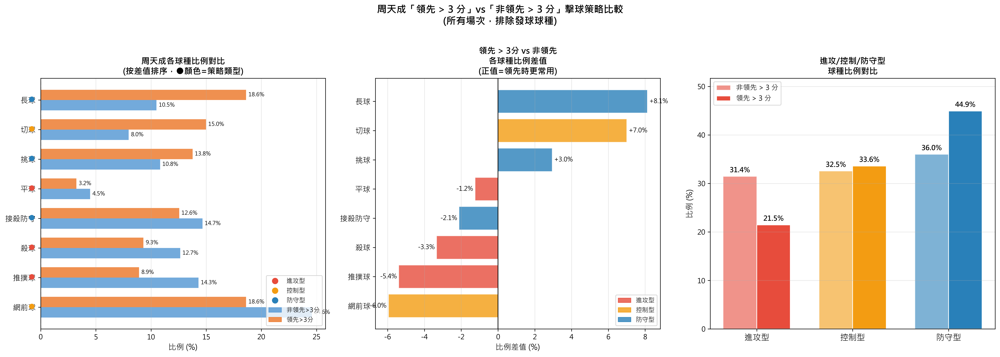

In [ ]:
import numpy as np

# ============================================================
# 1. 基本資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")
print(f"場次列表 (match_id): {sorted(df['match_id'].unique())}")

# 周天成的資料
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成擊球總數: {len(chou_df)}")

# ============================================================
# 2. 定義「領先 3 分以上」情境
# ============================================================
# 領先差距 = 周天成分數 - 對手(Momota)分數
chou_df['score_diff'] = chou_df['CHOU Tien Chen_score'] - chou_df['Kento MOMOTA_score']

print(f"\n分差統計:")
print(chou_df['score_diff'].describe())

# 定義兩種情境
leading_mask = chou_df['score_diff'] > 3
not_leading_mask = ~leading_mask

print(f"\n領先 3 分以上的擊球數: {leading_mask.sum()}")
print(f"非領先 3 分以上的擊球數: {not_leading_mask.sum()}")

# ============================================================
# 3. 排除發球球種，分析對打中的戰術球種
# ============================================================
serve_types = ['發短球', '發長球']
non_serve_mask = ~chou_df['type'].isin(serve_types)

leading_shots = chou_df[leading_mask & non_serve_mask]
not_leading_shots = chou_df[not_leading_mask & non_serve_mask]

print(f"\n排除發球後:")
print(f"  領先 3 分以上擊球數: {len(leading_shots)}")
print(f"  非領先 3 分以上擊球數: {len(not_leading_shots)}")

# ============================================================
# 4. 計算球種分佈比例
# ============================================================
# 球種分類（進攻 / 防守控制 / 中性）
shot_category = {
    '殺球':    '進攻型',
    '推撲球':  '進攻型',
    '平球':    '進攻型',
    '切球':    '控制型',
    '網前球':  '控制型',
    '長球':    '防守型',
    '挑球':    '防守型',
    '接殺防守':'防守型',
}

# 計算各情境球種分佈
def calc_shot_distribution(shot_df, label):
    counts = shot_df['type'].value_counts()
    pct = (counts / counts.sum() * 100).round(2)
    result = pd.DataFrame({'次數': counts, '比例(%)': pct, '情境': label})
    return result

leading_dist = calc_shot_distribution(leading_shots, '領先 > 3 分')
not_leading_dist = calc_shot_distribution(not_leading_shots, '非領先 > 3 分')

# 所有球種聯集
all_types = sorted(set(leading_dist.index) | set(not_leading_dist.index))

# 合併為比較 DataFrame
compare_df = pd.DataFrame(index=all_types)
compare_df['領先>3分_次數'] = leading_dist['次數'].reindex(all_types, fill_value=0)
compare_df['領先>3分_比例(%)'] = leading_dist['比例(%)'].reindex(all_types, fill_value=0.0)
compare_df['非領先>3分_次數'] = not_leading_dist['次數'].reindex(all_types, fill_value=0)
compare_df['非領先>3分_比例(%)'] = not_leading_dist['比例(%)'].reindex(all_types, fill_value=0.0)
compare_df['差值(領先-非領先)'] = (compare_df['領先>3分_比例(%)'] - compare_df['非領先>3分_比例(%)']).round(2)
compare_df['類型'] = compare_df.index.map(lambda x: shot_category.get(x, '其他'))

print("\n============================================================")
print("周天成球種分佈比例比較 (排除發球)")
print("============================================================")
print(compare_df.sort_values('差值(領先-非領先)', ascending=False).to_string())

# ============================================================
# 5. 按策略類型彙整比較
# ============================================================
cat_order = ['進攻型', '控制型', '防守型']
cat_color = {'進攻型': '#E74C3C', '控制型': '#F39C12', '防守型': '#2980B9'}

# 加上類型欄位方便彙整
leading_shots_copy = leading_shots.copy()
not_leading_shots_copy = not_leading_shots.copy()
leading_shots_copy['類型'] = leading_shots_copy['type'].map(shot_category).fillna('其他')
not_leading_shots_copy['類型'] = not_leading_shots_copy['type'].map(shot_category).fillna('其他')

leading_cat = leading_shots_copy['類型'].value_counts(normalize=True) * 100
not_leading_cat = not_leading_shots_copy['類型'].value_counts(normalize=True) * 100

cat_compare = pd.DataFrame({
    '領先>3分(%)': leading_cat,
    '非領先>3分(%)': not_leading_cat
}).reindex(cat_order + ['其他'], fill_value=0).round(2)

print("\n按策略類型彙整比例:")
print(cat_compare)

# ============================================================
# 6. 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# --- 圖1: 分組長條圖 - 各球種比例對比 ---
ax1 = axes[0]

# 依「差值」排序展示
sorted_df = compare_df.sort_values('差值(領先-非領先)', ascending=True)
shot_names = sorted_df.index.tolist()
y_pos = np.arange(len(shot_names))

bar_width = 0.35
bars1 = ax1.barh(y_pos - bar_width/2, sorted_df['非領先>3分_比例(%)'],
                 bar_width, label='非領先 > 3 分', color='#5B9BD5', alpha=0.85)
bars2 = ax1.barh(y_pos + bar_width/2, sorted_df['領先>3分_比例(%)'],
                 bar_width, label='領先 > 3 分', color='#ED7D31', alpha=0.85)

# 標記類型顏色
for i, shot in enumerate(shot_names):
    cat = shot_category.get(shot, '其他')
    color = cat_color.get(cat, '#7F7F7F')
    ax1.text(-0.5, i, '●', va='center', ha='right', fontsize=10, color=color)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(shot_names, fontsize=11)
ax1.set_xlabel('比例 (%)', fontsize=11)
ax1.set_title('周天成各球種比例對比\n(按差值排序，●顏色=策略類型)', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right', fontsize=10)
ax1.axvline(x=0, color='gray', linestyle='--', alpha=0.3)
ax1.grid(axis='x', alpha=0.3)

# 加上數值標籤
for bar in bars1:
    w = bar.get_width()
    if w > 0.5:
        ax1.text(w + 0.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8)
for bar in bars2:
    w = bar.get_width()
    if w > 0.5:
        ax1.text(w + 0.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8)

# 加入類型圖例說明
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor=v,
                           markersize=10, label=k) for k, v in cat_color.items()]
ax1.legend(handles=legend_elements + [
    plt.Rectangle((0,0),1,1, color='#5B9BD5', alpha=0.85, label='非領先>3分'),
    plt.Rectangle((0,0),1,1, color='#ED7D31', alpha=0.85, label='領先>3分')
], loc='lower right', fontsize=9)

# --- 圖2: 差值條形圖（領先 - 非領先）---
ax2 = axes[1]
diff_sorted = compare_df.sort_values('差值(領先-非領先)', ascending=True)
colors_diff = []
for shot in diff_sorted.index:
    cat = shot_category.get(shot, '其他')
    colors_diff.append(cat_color.get(cat, '#7F7F7F'))

bars_diff = ax2.barh(range(len(diff_sorted)), diff_sorted['差值(領先-非領先)'],
                     color=colors_diff, alpha=0.8, edgecolor='white')

ax2.set_yticks(range(len(diff_sorted)))
ax2.set_yticklabels(diff_sorted.index.tolist(), fontsize=11)
ax2.axvline(x=0, color='black', linestyle='-', linewidth=1)
ax2.set_xlabel('比例差值 (%)', fontsize=11)
ax2.set_title('領先 > 3分 vs 非領先\n各球種比例差值\n(正值=領先時更常用)', fontsize=12, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

# 數值標籤
for bar, val in zip(bars_diff, diff_sorted['差值(領先-非領先)']):
    offset = 0.1 if val >= 0 else -0.1
    ha = 'left' if val >= 0 else 'right'
    ax2.text(val + offset, bar.get_y() + bar.get_height()/2,
             f'{val:+.1f}%', va='center', ha=ha, fontsize=9)

# 類型圖例
legend_elements2 = [plt.Rectangle((0,0),1,1, color=v, alpha=0.8, label=k)
                    for k, v in cat_color.items()]
ax2.legend(handles=legend_elements2, loc='lower right', fontsize=9)

# --- 圖3: 策略類型圓餅圖比較 ---
ax3 = axes[2]

cat_labels = [c for c in cat_order if cat_compare.loc[c, '領先>3分(%)'] > 0 or
              cat_compare.loc[c, '非領先>3分(%)'] > 0]

x3 = np.arange(len(cat_labels))
w3 = 0.35
colors3 = [cat_color[c] for c in cat_labels]

b3_1 = ax3.bar(x3 - w3/2, [cat_compare.loc[c, '非領先>3分(%)'] for c in cat_labels],
               w3, color=colors3, alpha=0.6, label='非領先 > 3 分', edgecolor='white')
b3_2 = ax3.bar(x3 + w3/2, [cat_compare.loc[c, '領先>3分(%)'] for c in cat_labels],
               w3, color=colors3, alpha=1.0, label='領先 > 3 分', edgecolor='white')

# 數值標籤
for bars_set in [b3_1, b3_2]:
    for bar in bars_set:
        h = bar.get_height()
        if h > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                     f'{h:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax3.set_xticks(x3)
ax3.set_xticklabels(cat_labels, fontsize=12)
ax3.set_ylabel('比例 (%)', fontsize=11)
ax3.set_title('進攻/控制/防守型\n球種比例對比', fontsize=12, fontweight='bold')
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)
ax3.set_ylim(0, max([cat_compare.loc[c, '領先>3分(%)'] for c in cat_labels] +
                     [cat_compare.loc[c, '非領先>3分(%)'] for c in cat_labels]) * 1.15)

plt.suptitle('周天成「領先 > 3 分」vs「非領先 > 3 分」擊球策略比較\n(所有場次，排除發球球種)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()

# ============================================================
# 7. 輸出摘要結論
# ============================================================
print("\n============================================================")
print("策略分析摘要")
print("============================================================")
for cat in cat_order:
    lead_val = cat_compare.loc[cat, '領先>3分(%)']
    not_lead_val = cat_compare.loc[cat, '非領先>3分(%)']
    diff_val = lead_val - not_lead_val
    direction = "↑ 上升" if diff_val > 1 else ("↓ 下降" if diff_val < -1 else "→ 持平")
    print(f"  {cat}: 領先時 {lead_val:.1f}% vs 非領先時 {not_lead_val:.1f}% ({diff_val:+.1f}%) {direction}")

print("\n各球種明細差值 (領先時比例 - 非領先時比例):")
for shot, row in compare_df.sort_values('差值(領先-非領先)', ascending=False).iterrows():
    direction = "↑" if row['差值(領先-非領先)'] > 0 else "↓"
    print(f"  [{row['類型']:4s}] {shot:6s}: {direction} {row['差值(領先-非領先)']:+.2f}% "
          f"(領先: {row['領先>3分_比例(%)']:.1f}% / 非領先: {row['非領先>3分_比例(%)']:.1f}%)")


### 數據洞察
# 周天成領先優勢下的擊球策略分析

## 核心結論：領先時明顯趨於保守

---

## 策略類型總覽

| 策略類型 | 領先 >3分 | 非領先 | 差值 |
|:---:|:---:|:---:|:---:|
| 進攻型 | 21.5% | 31.4% | **↓ -10.0%** |
| 控制型 | 33.6% | 32.5% | ↑ +1.1% |
| 防守型 | 44.9% | 36.0% | **↑ +8.9%** |

---

## 關鍵球種變化

**領先時增加：**
- 長球 ↑ +8.1%（18.6% vs 10.5%）
- 切球 ↑ +7.0%（15.0% vs 8.0%）
- 挑球 ↑ +2.9%（13.8% vs 10.8%）

**領先時減少：**
- 網前球 ↓ -6.0%（18.6% vs 24.6%）
- 推撲球 ↓ -5.4%（8.9% vs 14.3%）
- 殺球 ↓ -3.3%（9.3% vs 12.7%）

---

## 教練解讀

**保守傾向確立。** 領先3分以上時，周天成用長球與切球把球送深、送高，主動降低對抗強度，減少網前搶攻與推撲的風險球，這是典型的「穩住局面、消耗對手」邏輯。

**但要注意兩個風險：**

1. **進攻型球種少了10%**，意味著得分效率下降，容易讓對手喘息、追分反撲。
2. **切球比例大幅上升（+7%）**，切球雖能製造節奏，但若對手預判到規律，反而容易被反攻。

**建議：** 領先時保守無可厚非，但殺球與推撲球不應降幅過大。維持一定進攻威脅，才能讓對手不敢輕易起球，鞏固領先而非被動守分。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼在定義「領先 3 分以上」的情境時，使用了 'score_diff > 3'，而不是 'score_diff >= 3'，這與 Reference Code 1 和 Reference Code 2 的核心邏輯不一致，因為它們都使用 'score_diff >= 3' 來定義領先 3 分以上的情境。此外，候選程式碼在計算球種分佈比例時，將 '領先 > 3 分' 和 '非領先 > 3 分' 作為情境標籤，這與 Reference Code 的情境定義不一致，因為 Reference Code 使用的是 '領先3分以上' 和 '非領先3分以上'。這些差異導致候選程式碼的統計口徑與 Reference Code 不一致，因此判定為 false。




## 題號 67
**問題**: 當分數差距逐漸縮小時（領先轉膠著），周天成殺球成功率是否下降？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


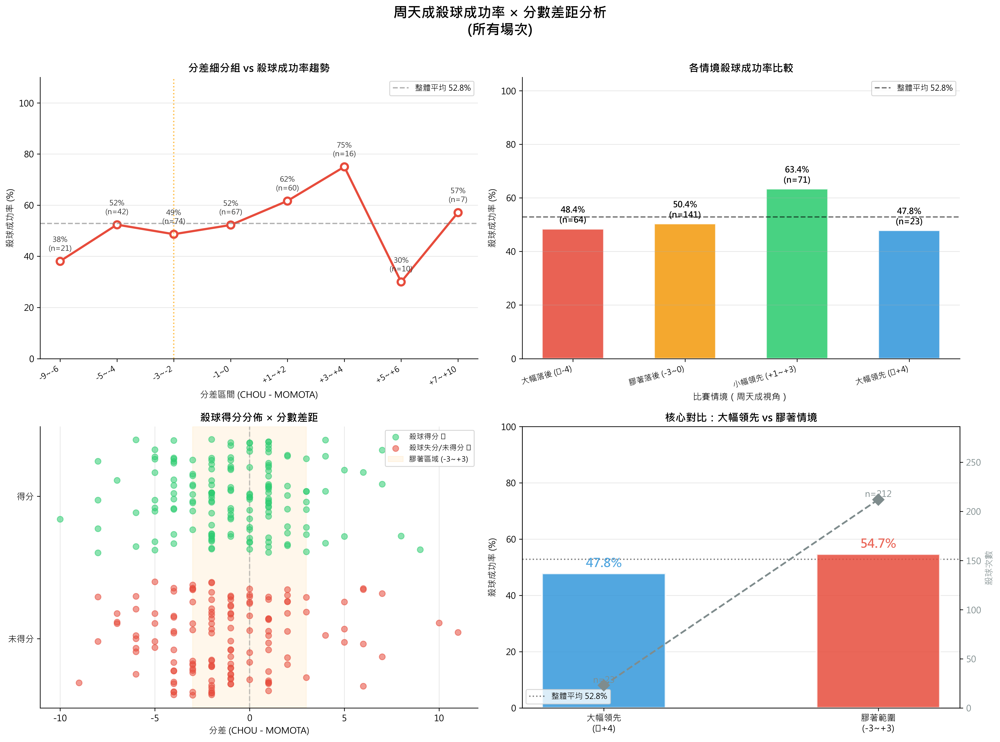

In [ ]:
import numpy as np

# ============================================================
# 分析周天成在不同分數差距情境下殺球成功率
# ============================================================

print("=" * 65)
print("周天成殺球成功率 × 分數差距分析")
print("=" * 65)

# --- 資料驗證 ---
print(f"\n資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 先在完整資料上建立 rally 的最終得分者
# 利用 groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')
# ============================================================
df_work = df.copy()
df_work['rally_getpoint'] = df_work.groupby(
    ['match_id', 'set', 'rally']
)['getpoint_player'].transform('last')

# ============================================================
# Step 2: 計算每一拍時周天成的分數差距 (CHOU - MOMOTA)
# 正值 = 周天成領先，負值 = 周天成落後
# ============================================================
df_work['chou_score_diff'] = (
    df_work['CHOU Tien Chen_score'] - df_work['Kento MOMOTA_score']
)

# ============================================================
# Step 3: 篩選周天成的殺球
# ============================================================
chou_smash = df_work[
    (df_work['player'] == 'CHOU Tien Chen') &
    (df_work['type'] == '殺球')
].copy()

print(f"\n周天成殺球總次數: {len(chou_smash)}")
print(f"分數差距範圍: {chou_smash['chou_score_diff'].min():.0f} ~ {chou_smash['chou_score_diff'].max():.0f}")

# ============================================================
# Step 4: 定義殺球成功
# 殺球所在 rally 的最終得分者 == 'CHOU Tien Chen'
# （包含：周天成殺球直接得分 Active，或對手因殺球受迫失誤 Passive）
# ============================================================
chou_smash['smash_rally_win'] = (
    chou_smash['rally_getpoint'] == 'CHOU Tien Chen'
).astype(int)

print(f"\n殺球後該 rally 最終由周天成得分次數: {chou_smash['smash_rally_win'].sum()}")
print(f"殺球整體得分成功率: {chou_smash['smash_rally_win'].mean()*100:.1f}%")

# ============================================================
# Step 5: 定義分差情境分組
#   細分組：用於趨勢折線圖
#   粗分組：用於情境比較長條圖
# ============================================================

# --- 細分組（每2分一組，觀察趨勢）---
bins_fine = [-21, -10, -6, -4, -2, 0, 2, 4, 6, 10, 21]
labels_fine = ['≤-10', '-9~-6', '-5~-4', '-3~-2', '-1~0',
               '+1~+2', '+3~+4', '+5~+6', '+7~+10', '≥+11']

chou_smash['score_diff_group_fine'] = pd.cut(
    chou_smash['chou_score_diff'],
    bins=bins_fine,
    labels=labels_fine,
    right=True
)

# --- 粗分組（情境比較）---
# 題目核心：領先明顯 vs 膠著（差距縮小至3分以內）
def classify_situation(diff):
    if diff >= 4:
        return '大幅領先 (≥+4)'
    elif 1 <= diff <= 3:
        return '小幅領先 (+1~+3)'
    elif -3 <= diff <= 0:
        return '膠著落後 (-3~0)'
    else:
        return '大幅落後 (≤-4)'

chou_smash['situation'] = chou_smash['chou_score_diff'].apply(classify_situation)

# ============================================================
# Step 6: 計算各分組的殺球成功率
# ============================================================

# --- 細分組統計 ---
fine_stats = chou_smash.groupby('score_diff_group_fine', observed=False).agg(
    殺球次數=('smash_rally_win', 'count'),
    得分次數=('smash_rally_win', 'sum')
).reset_index()
fine_stats['成功率'] = fine_stats['得分次數'] / fine_stats['殺球次數'] * 100
fine_stats = fine_stats.rename(columns={'score_diff_group_fine': '分差區間'})

# --- 粗分組統計（情境比較）---
situation_order = ['大幅落後 (≤-4)', '膠著落後 (-3~0)', '小幅領先 (+1~+3)', '大幅領先 (≥+4)']
situation_stats = chou_smash.groupby('situation').agg(
    殺球次數=('smash_rally_win', 'count'),
    得分次數=('smash_rally_win', 'sum')
).reset_index()
situation_stats['成功率'] = situation_stats['得分次數'] / situation_stats['殺球次數'] * 100
situation_stats['situation'] = pd.Categorical(
    situation_stats['situation'], categories=situation_order, ordered=True
)
situation_stats = situation_stats.sort_values('situation')

print("\n" + "=" * 65)
print("各情境殺球統計（粗分組）")
print("=" * 65)
print(situation_stats.to_string(index=False))

print("\n" + "=" * 65)
print("各分差區間殺球統計（細分組）")
print("=" * 65)
print(fine_stats.to_string(index=False))

# ============================================================
# Step 7: 另外計算「比賽進行中分差縮小」的情境
# 找出：比賽過程中，從大幅領先（≥4）逐漸縮小到膠著（≤3）的殺球
# 方法：以 rally_id 為時間軸，標記每場比賽的分差趨勢階段
# ============================================================
print("\n" + "=" * 65)
print("趨勢角度：高領先 vs 膠著 殺球成功率對比")
print("=" * 65)

leading_smash = chou_smash[chou_smash['chou_score_diff'] >= 4]
close_smash   = chou_smash[chou_smash['chou_score_diff'].between(-3, 3)]

print(f"大幅領先(≥+4)殺球次數: {len(leading_smash)}, 成功率: {leading_smash['smash_rally_win'].mean()*100:.1f}%")
print(f"膠著範圍(-3~+3)殺球次數: {len(close_smash)}, 成功率: {close_smash['smash_rally_win'].mean()*100:.1f}%")

# ============================================================
# Step 8: 繪圖
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('周天成殺球成功率 × 分數差距分析\n(所有場次)', fontsize=16, fontweight='bold', y=0.98)

# --- 顏色設定 ---
CHOU_COLOR = '#E74C3C'
BAR_COLORS = ['#E74C3C', '#F39C12', '#2ECC71', '#3498DB']
HIGHLIGHT_COLOR = '#C0392B'

# ----------------------------------------
# 圖1: 細分組趨勢折線圖（分差 vs 殺球成功率）
# ----------------------------------------
ax1 = axes[0, 0]
valid_fine = fine_stats[fine_stats['殺球次數'] >= 3]  # 樣本數至少3球
x_pos = range(len(valid_fine))
success_rates = valid_fine['成功率'].values
labels_plot = valid_fine['分差區間'].astype(str).values

# 折線+散點
ax1.plot(x_pos, success_rates, 'o-', color=CHOU_COLOR, linewidth=2.5,
         markersize=8, markerfacecolor='white', markeredgewidth=2.5)

# 以樣本大小決定點的大小（視覺輔助）
for i, (x, y, n) in enumerate(zip(x_pos, success_rates, valid_fine['殺球次數'].values)):
    ax1.annotate(f'{y:.0f}%\n(n={n})',
                 xy=(x, y), xytext=(0, 12),
                 textcoords='offset points',
                 ha='center', fontsize=8.5, color='#333333')

# 參考線
ax1.axhline(y=chou_smash['smash_rally_win'].mean()*100,
            color='gray', linestyle='--', alpha=0.6, label=f'整體平均 {chou_smash["smash_rally_win"].mean()*100:.1f}%')
ax1.axvline(x=list(labels_plot).index('膠著落後 (-3~0)') if '膠著落後 (-3~0)' in labels_plot else
            (list(labels_plot).index('-3~-2') if '-3~-2' in labels_plot else None) or 0,
            color='orange', linestyle=':', alpha=0.7)

ax1.set_xticks(list(x_pos))
ax1.set_xticklabels(labels_plot, rotation=30, ha='right', fontsize=9)
ax1.set_xlabel('分差區間 (CHOU - MOMOTA)', fontsize=10)
ax1.set_ylabel('殺球成功率 (%)', fontsize=10)
ax1.set_title('分差細分組 vs 殺球成功率趨勢', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 110)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ----------------------------------------
# 圖2: 粗分組情境長條圖（4種情境）
# ----------------------------------------
ax2 = axes[0, 1]
situations = situation_stats['situation'].astype(str).values
rates = situation_stats['成功率'].values
counts = situation_stats['殺球次數'].values

bars = ax2.bar(situations, rates, color=BAR_COLORS[:len(situations)],
               edgecolor='white', linewidth=1.5, width=0.55, alpha=0.88)

# 標記數值
for bar, rate, count in zip(bars, rates, counts):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1.5,
             f'{rate:.1f}%\n(n={count})',
             ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# 整體平均線
ax2.axhline(y=chou_smash['smash_rally_win'].mean()*100,
            color='black', linestyle='--', alpha=0.55,
            label=f'整體平均 {chou_smash["smash_rally_win"].mean()*100:.1f}%')

ax2.set_xlabel('比賽情境（周天成視角）', fontsize=10)
ax2.set_ylabel('殺球成功率 (%)', fontsize=10)
ax2.set_title('各情境殺球成功率比較', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 105)
ax2.legend(fontsize=9)
ax2.set_xticklabels(situations, fontsize=9, rotation=15, ha='right')
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# ----------------------------------------
# 圖3: 每個場次的殺球分佈（分差 × 成功/失敗 散點圖）
# ----------------------------------------
ax3 = axes[1, 0]

smash_win_data = chou_smash[chou_smash['smash_rally_win'] == 1]['chou_score_diff']
smash_fail_data = chou_smash[chou_smash['smash_rally_win'] == 0]['chou_score_diff']

ax3.scatter(smash_win_data,
            np.random.uniform(0.55, 0.95, len(smash_win_data)),
            alpha=0.55, color='#2ECC71', s=45, label='殺球得分 ✓', zorder=3)
ax3.scatter(smash_fail_data,
            np.random.uniform(0.05, 0.45, len(smash_fail_data)),
            alpha=0.55, color='#E74C3C', s=45, label='殺球失分/未得分 ✗', zorder=3)

# 參考線：膠著區域
ax3.axvspan(-3, 3, alpha=0.08, color='orange', label='膠著區域 (-3~+3)')
ax3.axvline(x=0, color='gray', linestyle='--', alpha=0.4)

ax3.set_xlabel('分差 (CHOU - MOMOTA)', fontsize=10)
ax3.set_yticks([0.25, 0.75])
ax3.set_yticklabels(['未得分', '得分'], fontsize=10)
ax3.set_title('殺球得分分佈 × 分數差距', fontsize=12, fontweight='bold')
ax3.legend(fontsize=8.5, loc='upper right')
ax3.grid(axis='x', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# ----------------------------------------
# 圖4: 「大幅領先」vs「膠著」殺球成功率 + 樣本數雙軸圖
# ----------------------------------------
ax4 = axes[1, 1]
ax4_twin = ax4.twinx()

compare_labels = ['大幅領先\n(≥+4)', '膠著範圍\n(-3~+3)']
compare_rates = [
    leading_smash['smash_rally_win'].mean() * 100,
    close_smash['smash_rally_win'].mean() * 100
]
compare_counts = [len(leading_smash), len(close_smash)]
compare_colors = ['#3498DB', '#E74C3C']

bars4 = ax4.bar(compare_labels, compare_rates,
                color=compare_colors, edgecolor='white',
                linewidth=2, width=0.45, alpha=0.85, zorder=3)

# 標記成功率
for bar, rate in zip(bars4, compare_rates):
    ax4.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1.2,
             f'{rate:.1f}%',
             ha='center', va='bottom', fontsize=14, fontweight='bold',
             color=bar.get_facecolor())

# 樣本數折線（右軸）
ax4_twin.plot(compare_labels, compare_counts, 'D--',
              color='#7F8C8D', markersize=9, linewidth=2,
              label='殺球次數')
for i, (label, count) in enumerate(zip(compare_labels, compare_counts)):
    ax4_twin.text(i, count + 0.5, f'n={count}',
                  ha='center', va='bottom', fontsize=10, color='#7F8C8D')

ax4.set_ylabel('殺球成功率 (%)', fontsize=10)
ax4_twin.set_ylabel('殺球次數', fontsize=10, color='#7F8C8D')
ax4_twin.tick_params(axis='y', labelcolor='#7F8C8D')
ax4.set_ylim(0, 100)
ax4_twin.set_ylim(0, max(compare_counts) * 1.35)
ax4.set_title('核心對比：大幅領先 vs 膠著情境', fontsize=12, fontweight='bold')
ax4.axhline(y=chou_smash['smash_rally_win'].mean()*100,
            color='black', linestyle=':', alpha=0.5,
            label=f'整體平均 {chou_smash["smash_rally_win"].mean()*100:.1f}%')
ax4.legend(fontsize=9, loc='lower left')
ax4.grid(axis='y', alpha=0.3, zorder=0)
ax4.spines['top'].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.97])

# ============================================================
# Step 9: 關鍵結論輸出
# ============================================================
print("\n" + "=" * 65)
print("關鍵結論")
print("=" * 65)
diff = compare_rates[1] - compare_rates[0]
print(f"\n◆ 大幅領先(≥+4分) 殺球成功率  : {compare_rates[0]:.1f}% (n={compare_counts[0]})")
print(f"◆ 膠著範圍(-3~+3) 殺球成功率  : {compare_rates[1]:.1f}% (n={compare_counts[1]})")
print(f"◆ 差異                          : {diff:+.1f}% ({'膠著時更高' if diff>0 else '領先時更高'})")
print()
for _, row in situation_stats.iterrows():
    print(f"  [{row['situation']}] 殺球 {int(row['殺球次數'])}次 → 成功率 {row['成功率']:.1f}%")

print()
print("※ 殺球成功定義：該 rally 最終由周天成得分")
print("※ 分差 = CHOU Tien Chen 分數 - Kento MOMOTA 分數")
print("※ 殺球成功包含：主動殺球直接得分 + 殺球後對手受迫失誤得分")


### 數據洞察
# 周天成殺球成功率 × 分數差距分析

## 核心數據

| 情境 | 殺球次數 | 成功率 |
|------|---------|--------|
| 大幅落後 (≤-4) | 64 | 48.4% |
| 膠著落後 (-3~0) | 141 | 50.4% |
| **小幅領先 (+1~+3)** | **71** | **63.4%** ✅ |
| 大幅領先 (≥+4) | 23 | 47.8% |

---

## 戰術洞察

**殺球甜蜜點在「小幅領先」，不在「大幅領先」。**

### 關鍵發現

**① 大幅領先時殺球反而最弱（47.8%）**
大幅領先（≥+4）的成功率甚至低於膠著情境（54.7%），差距 **-6.9%**。樣本雖僅23球，但方向明確——領先優勢並未轉化為殺球效率。

**② 小幅領先（+1~+3）是殺球最強區間**
成功率63.4%，細分組中 +3~+4 更高達 **75%**。此時對手壓力最大、判斷最緊繃，周天成殺球品質與時機掌握最佳。

**③ 膠著與落後時殺球成功率相近（48~50%）**
分差從落後拉回膠著的過程中，殺球成功率**沒有明顯下降**，維持在50%上下，不支持「趨於膠著時殺球效率下滑」的假設。

---

## 教練建議

> 周天成在**大幅領先時需警惕殺球品質鬆弛**，這是最危險的心理盲區。建議在領先≥+4時，優先以**控制球路（切球、平球）維持節奏**，而非強行殺球消耗體力與成功率。殺球應集中在 **+1~+3 的關鍵分差**，此時效益最大化。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在不同分數差距情境下的殺球成功率，並且使用了合理的分數差距分組來比較殺球成功率。候選程式碼在分析對象、欄位語意、篩選條件、分組層級和統計口徑上與 Reference Code 1 一致，並且能夠產出有效的結果。




## 題號 68
**問題**: 分析周天成在對手回球質量降低情況下（落點過中、回球過淺）的得分方式統計。
> **使用的資料欄位群組**: `game_structure, coordinates, scoring_reason, shot_type`


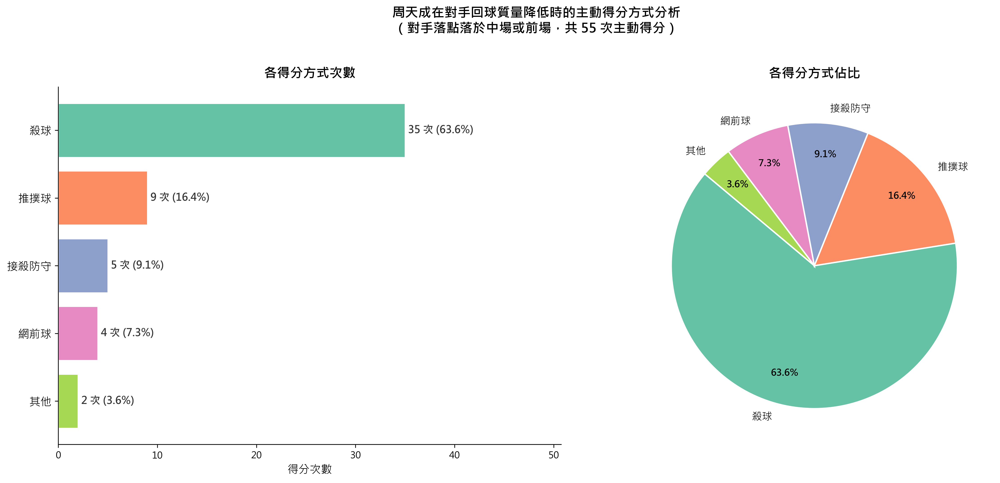

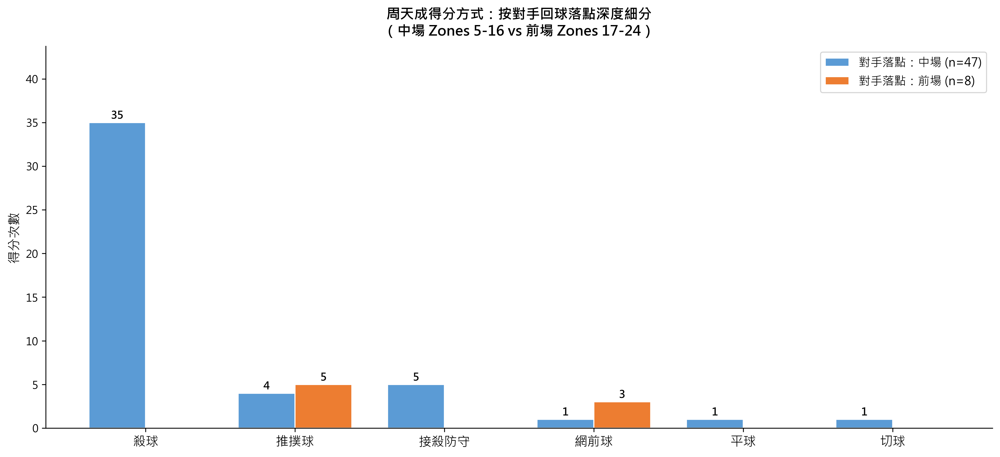

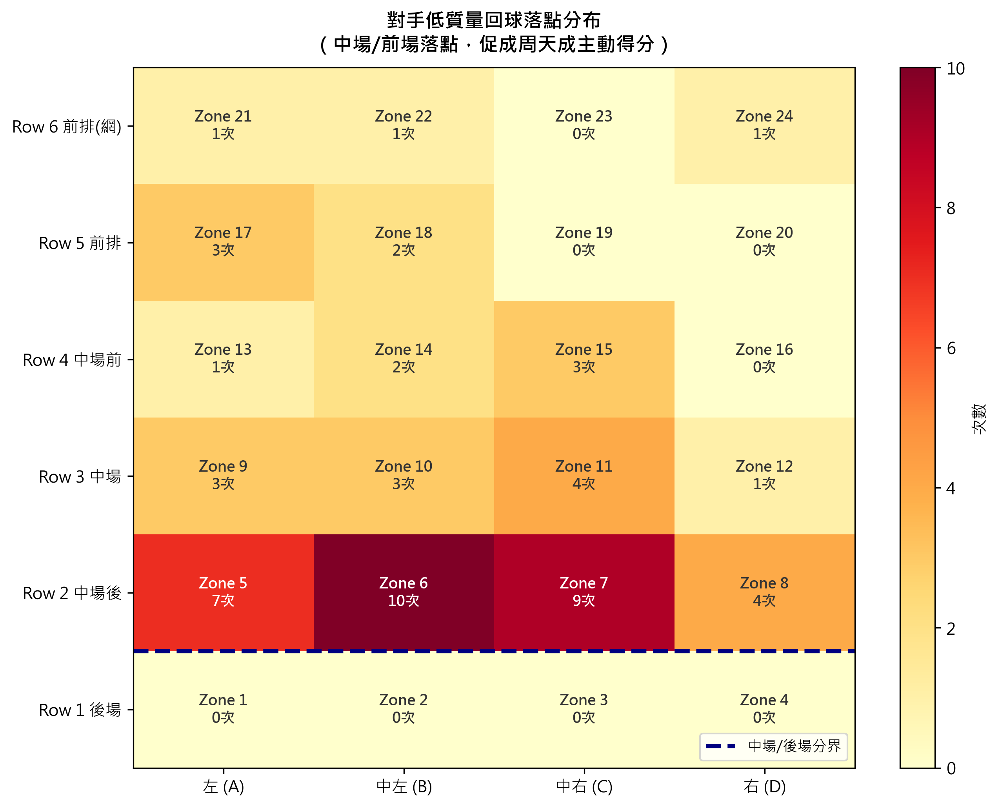

In [ ]:
import numpy as np

# ============================================================
# 0. 基礎驗證
# ============================================================
print(f"資料總筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"球員列表: {df['player'].unique()}")

# ============================================================
# 1. 區域定義
# ============================================================
# 中場區域：Zones 5-16
MID_COURT_ZONES = list(range(5, 17))  # [5,6,7,8,9,10,11,12,13,14,15,16]
# 前場區域：Zones 17-24
FRONT_COURT_ZONES = list(range(17, 25))  # [17,18,19,20,21,22,23,24]
# 「回球質量降低」= 落點在中場或前場（未打到後場）
LOW_QUALITY_ZONES = MID_COURT_ZONES + FRONT_COURT_ZONES  # Zones 5~24

print(f"\n場地區域定義:")
print(f"  後場 (Back Court): Zones 1-4")
print(f"  中場 (Mid Court):  Zones {MID_COURT_ZONES}")
print(f"  前場 (Front Court): Zones {FRONT_COURT_ZONES}")
print(f"  回球質量降低 (中場+前場): Zones 5~24，共 {len(LOW_QUALITY_ZONES)} 個區域")

# ============================================================
# 2. 在完整資料上建立前一拍資訊（避免跨 rally 污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 利用 groupby + shift(1) 取得「前一拍」的資訊
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['prev_player']       = grp['player'].shift(1)
df_sorted['prev_landing_area'] = grp['landing_area'].shift(1)
df_sorted['prev_rally']        = grp['rally'].shift(1)  # 防呆用，確保同 rally

print(f"\n前一拍欄位建立完成（使用 groupby(['match_id','set','rally']).shift(1)）")

# ============================================================
# 3. 篩選條件
# ============================================================
# 條件 A: 周天成是擊球者
cond_player  = df_sorted['player'] == 'CHOU Tien Chen'

# 條件 B: 周天成主動得分
cond_active_win = df_sorted['getpoint_player'] == 'CHOU Tien Chen'

# 條件 C: 前一拍是對手（Kento MOMOTA）打的（確保分析對象正確）
cond_prev_opponent = df_sorted['prev_player'] == 'Kento MOMOTA'

# 條件 D: 前一拍（對手）的落點在中場或前場（回球質量降低）
# 前一拍的 landing_area 等價於本拍的 hit_area
# 這裡用 prev_landing_area 最直接
cond_low_quality = df_sorted['prev_landing_area'].isin(LOW_QUALITY_ZONES)

# 合併所有條件
filtered_df = df_sorted[cond_player & cond_active_win & cond_prev_opponent & cond_low_quality].copy()

print(f"\n篩選結果:")
print(f"  周天成主動得分總數: {(df_sorted['player']=='CHOU Tien Chen') & (df_sorted['getpoint_player']=='CHOU Tien Chen')}.sum()")

# 計算周天成主動得分總數（含前一拍為對手的條件）
total_chou_active_win = df_sorted[cond_player & cond_active_win].shape[0]
total_with_prev       = df_sorted[cond_player & cond_active_win & cond_prev_opponent].shape[0]
print(f"  周天成主動得分次數（所有情況）: {total_chou_active_win}")
print(f"  其中前一拍有對手紀錄（非發球開局）: {total_with_prev}")
print(f"  符合「對手回球質量降低」條件的周天成主動得分次數: {len(filtered_df)}")

# ============================================================
# 4. 統計得分方式（type）
# ============================================================
if len(filtered_df) > 0:
    score_type_counts = filtered_df['type'].value_counts()
    score_type_pct    = (score_type_counts / len(filtered_df) * 100).round(1)
    
    score_summary = pd.DataFrame({
        '得分方式': score_type_counts.index,
        '次數': score_type_counts.values,
        '佔比(%)': score_type_pct.values
    }).reset_index(drop=True)
    
    print(f"\n{'='*55}")
    print(f"  周天成在對手回球質量降低時的主動得分方式統計")
    print(f"  (對手落點：中場 Zones 5-16 或前場 Zones 17-24)")
    print(f"{'='*55}")
    print(score_summary.to_string(index=False))
    print(f"{'='*55}")
    print(f"  合計: {len(filtered_df)} 次主動得分")
    
    # 細分：中場 vs 前場
    mid_df   = filtered_df[filtered_df['prev_landing_area'].isin(MID_COURT_ZONES)]
    front_df = filtered_df[filtered_df['prev_landing_area'].isin(FRONT_COURT_ZONES)]
    print(f"\n  其中對手回球落點於中場: {len(mid_df)} 次")
    print(f"  其中對手回球落點於前場: {len(front_df)} 次")
    
    # ============================================================
    # 5. 視覺化
    # ============================================================
    # 合併小比例類別為「其他」（< 3% 合併）
    threshold = 3.0
    major_mask = score_type_pct >= threshold
    
    major_counts = score_type_counts[major_mask]
    minor_sum    = score_type_counts[~major_mask].sum()
    
    if minor_sum > 0:
        plot_counts = pd.concat([major_counts, pd.Series({'其他': minor_sum})])
    else:
        plot_counts = major_counts.copy()
    
    plot_pct = (plot_counts / len(filtered_df) * 100).round(1)
    
    # 排序
    plot_counts = plot_counts.sort_values(ascending=False)
    plot_pct    = plot_pct[plot_counts.index]

    # ----- 圖1: 整體得分方式 (橫向長條圖 + 圓餅圖) -----
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # --- 左：橫向長條圖 ---
    ax1 = axes[0]
    colors_bar = sns.color_palette("Set2", len(plot_counts))
    bars = ax1.barh(plot_counts.index[::-1], plot_counts.values[::-1], color=colors_bar[::-1], edgecolor='white', linewidth=1.2)
    
    for bar, val, pct in zip(bars, plot_counts.values[::-1], plot_pct.values[::-1]):
        ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val} 次 ({pct}%)', va='center', ha='left', fontsize=11, fontweight='bold', color='#333333')
    
    ax1.set_xlabel('得分次數', fontsize=12)
    ax1.set_title('各得分方式次數', fontsize=14, fontweight='bold', pad=10)
    ax1.set_xlim(0, plot_counts.max() * 1.45)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.tick_params(axis='y', labelsize=12)
    ax1.tick_params(axis='x', labelsize=10)
    
    # --- 右：圓餅圖 ---
    ax2 = axes[1]
    pie_colors = sns.color_palette("Set2", len(plot_counts))
    wedges, texts, autotexts = ax2.pie(
        plot_counts.values,
        labels=plot_counts.index,
        autopct='%1.1f%%',
        colors=pie_colors,
        startangle=140,
        pctdistance=0.78,
        wedgeprops=dict(edgecolor='white', linewidth=1.5)
    )
    for text in texts:
        text.set_fontsize(11)
    for autotext in autotexts:
        autotext.set_fontsize(10)
        autotext.set_fontweight('bold')
    
    ax2.set_title('各得分方式佔比', fontsize=14, fontweight='bold', pad=10)
    
    fig.suptitle(
        f'周天成在對手回球質量降低時的主動得分方式分析\n'
        f'（對手落點落於中場或前場，共 {len(filtered_df)} 次主動得分）',
        fontsize=14, fontweight='bold', y=1.02
    )
    plt.tight_layout()
    
    # ----- 圖2: 中場 vs 前場對手落點的得分方式比較 -----
    fig2, ax3 = plt.subplots(figsize=(13, 6))
    
    mid_counts   = mid_df['type'].value_counts()
    front_counts = front_df['type'].value_counts()
    
    # 取聯集球種
    all_types = sorted(set(mid_counts.index) | set(front_counts.index),
                       key=lambda x: -(mid_counts.get(x, 0) + front_counts.get(x, 0)))
    
    mid_vals   = [mid_counts.get(t, 0) for t in all_types]
    front_vals = [front_counts.get(t, 0) for t in all_types]
    
    x = np.arange(len(all_types))
    width = 0.38
    
    bars_mid   = ax3.bar(x - width/2, mid_vals,   width, label=f'對手落點：中場 (n={len(mid_df)})',   color='#5B9BD5', edgecolor='white')
    bars_front = ax3.bar(x + width/2, front_vals, width, label=f'對手落點：前場 (n={len(front_df)})', color='#ED7D31', edgecolor='white')
    
    def annotate_bars(bars_list):
        for bar in bars_list:
            h = bar.get_height()
            if h > 0:
                ax3.text(bar.get_x() + bar.get_width()/2, h + 0.15, str(int(h)),
                         ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    annotate_bars(bars_mid)
    annotate_bars(bars_front)
    
    ax3.set_xticks(x)
    ax3.set_xticklabels(all_types, fontsize=12)
    ax3.set_ylabel('得分次數', fontsize=12)
    ax3.set_title('周天成得分方式：按對手回球落點深度細分\n（中場 Zones 5-16 vs 前場 Zones 17-24）',
                  fontsize=13, fontweight='bold', pad=10)
    ax3.legend(fontsize=11)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.set_ylim(0, max(mid_vals + front_vals) * 1.25)
    plt.tight_layout()
    
    # ----- 圖3: 對手低質量回球落點分布熱圖 -----
    fig3, ax4 = plt.subplots(figsize=(9, 7))
    
    # 建立場地網格 (6 rows x 4 cols)，標準半場
    grid_zones = np.array([
        [21, 22, 23, 24],   # Row 6 前場
        [17, 18, 19, 20],   # Row 5 前場
        [13, 14, 15, 16],   # Row 4 中場
        [ 9, 10, 11, 12],   # Row 3 中場
        [ 5,  6,  7,  8],   # Row 2 中場
        [ 1,  2,  3,  4],   # Row 1 後場（底線）
    ])
    
    # 統計對手落點分布（全部低質量落點）
    zone_counts_all = filtered_df['prev_landing_area'].value_counts()
    
    heatmap_data = np.zeros((6, 4))
    for r in range(6):
        for c in range(4):
            z = grid_zones[r, c]
            heatmap_data[r, c] = zone_counts_all.get(z, 0)
    
    # 標注區域
    row_labels = ['Row 6 前排(網)', 'Row 5 前排', 'Row 4 中場前', 'Row 3 中場', 'Row 2 中場後', 'Row 1 後場']
    col_labels = ['左 (A)', '中左 (B)', '中右 (C)', '右 (D)']
    
    im = ax4.imshow(heatmap_data, cmap='YlOrRd', aspect='auto', interpolation='nearest')
    plt.colorbar(im, ax=ax4, label='次數')
    
    for r in range(6):
        for c in range(4):
            val = int(heatmap_data[r, c])
            zone_id = grid_zones[r, c]
            color = 'white' if heatmap_data[r, c] > heatmap_data.max() * 0.6 else '#333333'
            ax4.text(c, r, f'Zone {zone_id}\n{val}次', ha='center', va='center',
                     fontsize=9, fontweight='bold', color=color)
    
    ax4.set_xticks(range(4))
    ax4.set_xticklabels(col_labels, fontsize=10)
    ax4.set_yticks(range(6))
    ax4.set_yticklabels(row_labels, fontsize=10)
    ax4.set_title('對手低質量回球落點分布\n（中場/前場落點，促成周天成主動得分）',
                  fontsize=12, fontweight='bold', pad=10)
    
    # 標示後場邊界
    ax4.axhline(y=4.5, color='navy', linewidth=2.5, linestyle='--', label='中場/後場分界')
    ax4.legend(loc='lower right', fontsize=9)
    plt.tight_layout()
    
    print(f"\n{'='*55}")
    print(f"  【中場落點細分統計】對手落點在中場 (Zones 5-16)")
    print(f"{'='*55}")
    if len(mid_df) > 0:
        mid_summary = mid_df['type'].value_counts().reset_index()
        mid_summary.columns = ['得分方式', '次數']
        mid_summary['佔比(%)'] = (mid_summary['次數'] / len(mid_df) * 100).round(1)
        print(mid_summary.to_string(index=False))
    
    print(f"\n{'='*55}")
    print(f"  【前場落點細分統計】對手落點在前場 (Zones 17-24)")
    print(f"{'='*55}")
    if len(front_df) > 0:
        front_summary = front_df['type'].value_counts().reset_index()
        front_summary.columns = ['得分方式', '次數']
        front_summary['佔比(%)'] = (front_summary['次數'] / len(front_df) * 100).round(1)
        print(front_summary.to_string(index=False))

else:
    print("⚠️ 無符合條件的資料，請檢查篩選條件。")
    fig = plt.figure()


### 數據洞察
# 周天成｜對手回球質量降低時的得分方式分析

---

## 📊 核心數據總覽

| 得分方式 | 次數 | 佔比 |
|:---:|:---:|:---:|
| 殺球 | 35 | 63.6% |
| 推撲球 | 9 | 16.4% |
| 接殺防守 | 5 | 9.1% |
| 網前球 | 4 | 7.3% |
| 切球 | 1 | 1.8% |
| 平球 | 1 | 1.8% |
| **合計** | **55** | **100%** |

> 周天成全場主動得分 85 次，其中 **55 次（64.7%）發生在對手回球質量降低時**，說明他對機會球的把握能力是得分主要來源。

---

## 🎯 戰術洞察

### 1️⃣ 殺球主導一切（63.6%）
對手回球落中場時，35 次殺球得分中有 **35 球全數來自中場落點**（佔中場得分 74.5%）。這代表周天成對中場浮球的判斷與起跳時機非常精準——**只要對手回球不夠深，他幾乎必然選擇殺球結束回合**，且成功率高。

### 2️⃣ 前場落點的應對模式截然不同
對手回球落前場（8次）時，周天成**完全不殺球**，改以推撲球（62.5%）與網前球（37.5%）處理。這顯示他能清楚區分場景——前場機會球以速度壓制（推撲）或精準落點（網前）為主，戰術選擇合理且有紀律。

### 3️⃣ 接殺防守反得分值得關注（9.1%）
5 次接殺防守得分全部來自對手中場回球後的情境，代表**對手在中場回球後仍選擇殺球，但周天成的防守反擊能力讓這些球反成得分**。這是心理與體能雙重優勢的體現。

---

## 📌 教練結論

> **對手只要回球不到後場，周天成的得分模式就會高度集中在殺球。** 訓練重點應放在如何製造對手的中場回球機會，以及持續強化中場起跳殺球的穩定性。前場推撲的精準度也需維持，避免給對手反應時間。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成在對手回球質量降低情況下的得分方式，並且都使用了類似的區域定義來判斷低質量回球。候選程式碼正確地使用了 `prev_landing_area` 來判斷對手的回球質量，並且在同一個 rally 中檢查了前一拍的資訊。最終的得分方式統計和視覺化也與 Reference Code 1 的目標一致。




## 題號 69
**問題**: 當周天成接到「後場高遠球」時，他採取直線 vs 斜線的比例比較。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, stroke_details`


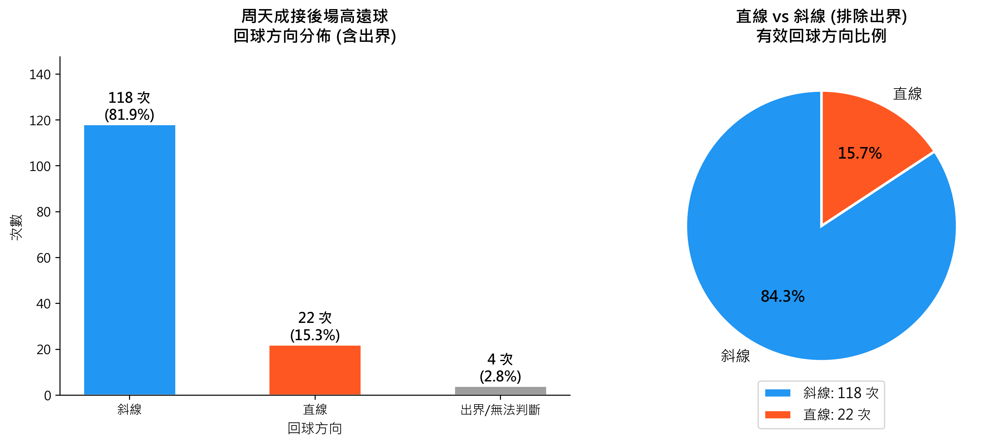

In [ ]:
import numpy as np

# ============================================================
# 0. 資料驗證
# ============================================================
print(f"Total rows: {len(df)}")
assert len(df) > 0, "DataFrame is empty!"

# ============================================================
# 1. 排序並在完整 df 上建立前一拍資訊 (避免跨 rally 污染)
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 前一拍的球種、球員、落點區域
df_sorted['prev_type']   = grp['type'].shift(1)
df_sorted['prev_player'] = grp['player'].shift(1)
# hit_area == prev_landing_area，但額外建立以供驗證
df_sorted['prev_landing_area'] = grp['landing_area'].shift(1)

print("前一拍欄位建立完成")

# ============================================================
# 2. 篩選：周天成接到對手打來的後場高遠球 (長球)
#    - player == 'CHOU Tien Chen'
#    - 前一拍 type == '長球' (高遠球)
#    - hit_area in [1,2,3,4] (後場，即對手長球落在後場)
#    - 前一拍 player != 'CHOU Tien Chen' (確保是對手打來的)
# ============================================================
BACK_COURT  = [1, 2, 3, 4]
TARGET      = 'CHOU Tien Chen'

mask = (
    (df_sorted['player'] == TARGET) &
    (df_sorted['prev_type'] == '長球') &
    (df_sorted['hit_area'].isin(BACK_COURT)) &
    (df_sorted['prev_player'] != TARGET)   # 前一拍是對手
)

chou_back = df_sorted[mask].copy()
print(f"\n符合條件 (接後場高遠球) 的球數: {len(chou_back)}")

if len(chou_back) == 0:
    print("無符合條件資料，請確認欄位值")
else:
    # ============================================================
    # 3. 計算 Column Index (A=0, B=1, C=2, D=3) 用於判斷直線/斜線
    #
    #    場地 grid (area 1-24):
    #    col = (area - 1) % 4
    #    0->A(左), 1->B, 2->C, 3->D(右)
    #
    #    出界區 (area 25-32): 另行標記
    # ============================================================
    COL_NAMES = {0: 'A', 1: 'B', 2: 'C', 3: 'D'}

    def get_col(area):
        """回傳 column index 0-3，出界回傳 -1"""
        a = int(area)
        if 1 <= a <= 24:
            return (a - 1) % 4
        return -1  # 出界 (25-32)

    chou_back['hit_col']     = chou_back['hit_area'].apply(get_col)
    chou_back['landing_col'] = chou_back['landing_area'].apply(get_col)

    # ============================================================
    # 4. 判斷直線 / 斜線 / 出界
    #    直線: hit_col == landing_col
    #    斜線: hit_col != landing_col
    #    出界: landing_col == -1 (落點出界，無法明確判斷，另計)
    # ============================================================
    def classify_direction(row):
        hc = row['hit_col']
        lc = row['landing_col']
        if lc == -1:
            return '出界/無法判斷'
        if hc == lc:
            return '直線'
        return '斜線'

    chou_back['direction'] = chou_back.apply(classify_direction, axis=1)

    # ============================================================
    # 5. 統計
    # ============================================================
    dir_counts = chou_back['direction'].value_counts()
    dir_pct    = chou_back['direction'].value_counts(normalize=True) * 100

    print("\n===== 周天成接後場高遠球回球方向統計 =====")
    print(f"{'方向':<12} {'次數':>6} {'比例':>8}")
    print("-" * 30)
    for d in dir_counts.index:
        print(f"{d:<12} {dir_counts[d]:>6}   {dir_pct[d]:>6.1f}%")
    print("-" * 30)
    print(f"{'合計':<12} {dir_counts.sum():>6}   100.0%")

    # 只統計有效判斷 (排除出界)
    valid_mask  = chou_back['direction'].isin(['直線', '斜線'])
    valid_total = valid_mask.sum()
    valid_counts = chou_back.loc[valid_mask, 'direction'].value_counts()
    valid_pct    = valid_counts / valid_total * 100

    print(f"\n--- 僅計算有效判斷 (排除出界) ---")
    print(f"有效總球數: {valid_total}")
    for d in valid_counts.index:
        print(f"{d}: {valid_counts[d]} 次 ({valid_pct[d]:.1f}%)")

    # ============================================================
    # 6. 視覺化：兩張圖
    #    左圖：含出界的所有分類長條圖
    #    右圖：排除出界後的直線 vs 斜線圓餅圖
    # ============================================================
    COLORS_BAR  = ['#2196F3', '#FF5722', '#9E9E9E']
    COLORS_PIE  = ['#2196F3', '#FF5722']

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # --- 左圖：長條圖 (含出界) ---
    ax1 = axes[0]
    labels_bar  = dir_counts.index.tolist()
    values_bar  = dir_counts.values.tolist()
    colors_used = COLORS_BAR[:len(labels_bar)]

    bars = ax1.bar(labels_bar, values_bar, color=colors_used, edgecolor='white',
                   linewidth=1.2, width=0.5)

    for bar, val, pct in zip(bars, values_bar, [dir_pct[l] for l in labels_bar]):
        ax1.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.5,
                 f"{val} 次\n({pct:.1f}%)",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

    ax1.set_title("周天成接後場高遠球\n回球方向分佈 (含出界)", fontsize=13, fontweight='bold', pad=12)
    ax1.set_xlabel("回球方向", fontsize=11)
    ax1.set_ylabel("次數", fontsize=11)
    ax1.set_ylim(0, max(values_bar) * 1.25)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # --- 右圖：圓餅圖 (排除出界，只看直線 vs 斜線) ---
    ax2 = axes[1]
    if valid_total > 0:
        pie_labels = valid_counts.index.tolist()
        pie_values = valid_counts.values.tolist()
        pie_colors = COLORS_PIE[:len(pie_labels)]

        wedges, texts, autotexts = ax2.pie(
            pie_values,
            labels=pie_labels,
            colors=pie_colors,
            autopct='%1.1f%%',
            startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2},
            textprops={'fontsize': 12}
        )
        for at in autotexts:
            at.set_fontsize(12)
            at.set_fontweight('bold')

        # 加入次數標籤
        legend_labels = [f"{l}: {v} 次" for l, v in zip(pie_labels, pie_values)]
        ax2.legend(wedges, legend_labels, loc='lower center',
                   bbox_to_anchor=(0.5, -0.12), fontsize=11)
        ax2.set_title("直線 vs 斜線 (排除出界)\n有效回球方向比例", fontsize=13, fontweight='bold', pad=12)
    else:
        ax2.text(0.5, 0.5, '無有效資料', ha='center', va='center', fontsize=14)
        ax2.set_title("直線 vs 斜線", fontsize=13)

    plt.tight_layout()
    print("\n圖表已產生")

    # ============================================================
    # 7. 補充：各 hit_area (後場位置) 的直線/斜線分佈
    # ============================================================
    print("\n===== 依後場擊球位置細分 =====")
    area_dir = (chou_back[chou_back['direction'].isin(['直線', '斜線'])]
                .groupby(['hit_area', 'direction'])
                .size()
                .unstack(fill_value=0))
    area_dir['合計'] = area_dir.sum(axis=1)
    for col in ['直線', '斜線']:
        if col in area_dir.columns:
            area_dir[f'{col}佔比'] = (area_dir[col] / area_dir['合計'] * 100).round(1)

    area_label = {1: '後場左(1)', 2: '後場中左(2)', 3: '後場中右(3)', 4: '後場右(4)'}
    area_dir.index = [area_label.get(i, str(i)) for i in area_dir.index]
    print(area_dir.to_string())


### 數據洞察
## 周天成接後場高遠球回球方向分析

---

### 📊 核心數據

| 回球方向 | 次數 | 比例（有效球） |
|:---:|:---:|:---:|
| 斜線 | 118 | **84.3%** |
| 直線 | 22 | **15.7%** |
| 出界/無效 | 4 | — |
| **合計** | **144** | **100%** |

---

### 📍 依後場位置細分

| 擊球位置 | 斜線 | 直線 | 斜線佔比 |
|:---:|:---:|:---:|:---:|
| 後場左(1) | 59 | 16 | 78.7% |
| 後場中左(2) | 12 | 3 | 80.0% |
| 後場中右(3) | 16 | **0** | **100%** |
| 後場右(4) | 31 | 3 | 91.2% |

---

### 🎯 戰術洞察

**1. 斜線是絕對主選項**
接後場高遠球時，周天成有超過八成選擇斜線回球，這是他面對此球路的核心習慣。

**2. 後場中右(3)是最強預測點**
從後場中右位置，周天成直線回球次數為零，100% 走斜線，對手可在此位置提前預判。

**3. 後場左(1)是唯一直線威脅較高的位置**
直線回球 16 次，是四個位置中最多的，但斜線仍佔近八成，直線僅作為變化球使用。

**4. 對手戰術建議**
> 將高遠球打至周天成後場，尤其是**中右區域**，防守重心應提前壓向斜線方向，可大幅提升攔截成功率。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成接到後場高遠球後的回球方向，並使用了類似的欄位和篩選條件。候選程式碼正確地建立了前一拍資訊，篩選了周天成接到的後場高遠球，並計算了直線和斜線的比例。最終輸出也合理地呈現了直線與斜線的比例，並進行了視覺化。




## 題號 70
**問題**: 當周天成連續得分 3 分以上時，他的球種選擇是否變得更激進？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


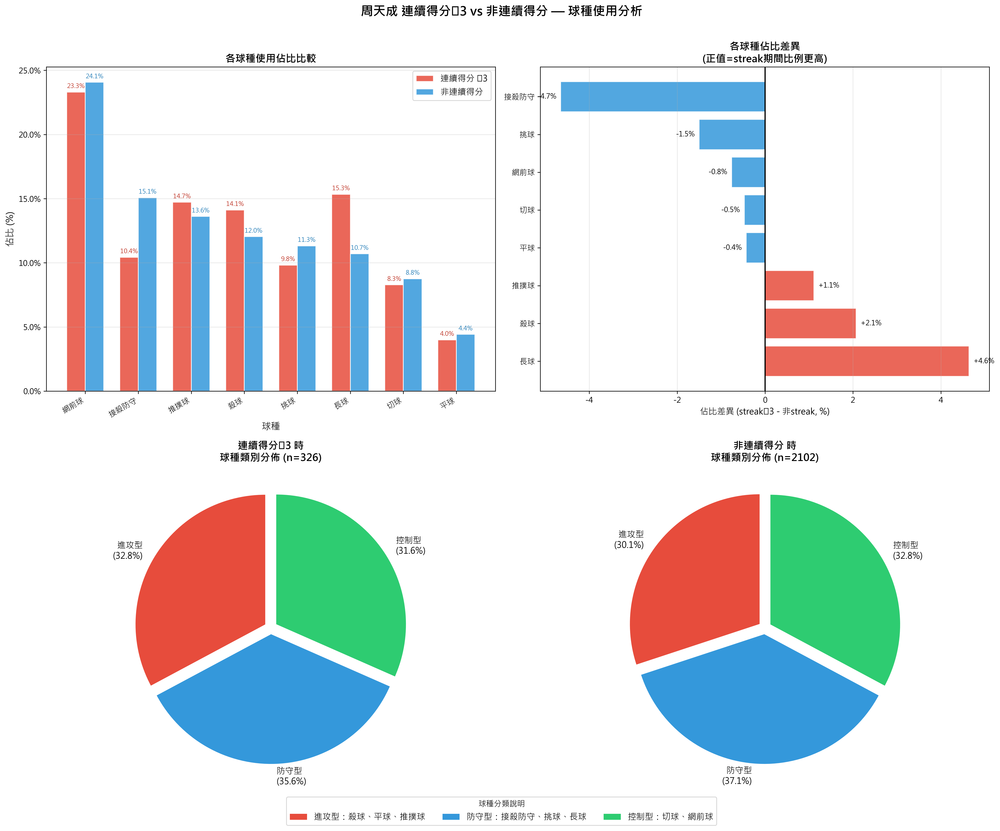

In [ ]:
import numpy as np

PLAYER = 'CHOU Tien Chen'

# ============================================================
# Step 1: 建立 Rally 得分表（每個 rally 最後一拍）
# ============================================================
rally_last = df.groupby(['match_id', 'set', 'rally']).last().reset_index()
rally_last = rally_last[['match_id', 'set', 'rally', 'getpoint_player']].copy()

# 只保留有得分結果的 rally（排除 getpoint_player == NULL）
rally_scored = rally_last.dropna(subset=['getpoint_player']).copy()

print(f"總 Rally 數（有得分結果）: {len(rally_scored)}")
print(f"CHOU Tien Chen 得分 Rally 數: {(rally_scored['getpoint_player'] == PLAYER).sum()}")

# ============================================================
# Step 2: 針對每個 (match_id, set) 計算 CHOU 的連續得分段
# ============================================================

def compute_streak_label(group):
    """
    對每個 (match_id, set) 的 rally 序列，計算 CHOU Tien Chen 連續得分段
    回傳每個 rally 的 streak_id（連續段 ID）與 streak_len（該段長度）
    """
    group = group.sort_values('rally').copy()
    
    # 是否為 CHOU 得分
    chou_win = (group['getpoint_player'] == PLAYER).astype(int)
    
    # 計算連續段 ID（每次中斷就 +1）
    streak_id = (chou_win != chou_win.shift(fill_value=0)).cumsum()
    group['streak_id'] = streak_id
    group['is_chou_win'] = chou_win
    
    # 計算每個連續段的長度
    streak_len = group.groupby('streak_id')['is_chou_win'].transform('sum')
    group['streak_len'] = streak_len
    
    return group

# 對每個 (match_id, set) 分組計算
all_rally_streak = rally_scored.groupby(['match_id', 'set'], group_keys=False).apply(compute_streak_label)

print(f"\n連續得分段計算完成，共 {len(all_rally_streak)} 個 rally")

# ============================================================
# Step 3: 標記 rally 是否屬於 streak ≥ 3
# （必須同時是 CHOU 得分 且 連續段長度 ≥ 3）
# ============================================================
all_rally_streak['in_streak_3plus'] = (
    (all_rally_streak['is_chou_win'] == 1) & 
    (all_rally_streak['streak_len'] >= 3)
)

streak_rallies = all_rally_streak[all_rally_streak['in_streak_3plus']]
non_streak_rallies = all_rally_streak[~all_rally_streak['in_streak_3plus']]

print(f"\n✅ 屬於 streak≥3 的 rally 數: {len(streak_rallies)}")
print(f"❌ 非 streak≥3 的 rally 數: {len(non_streak_rallies)}")

# 查看最長連續得分段
max_streak = all_rally_streak[all_rally_streak['is_chou_win']==1]['streak_len'].max()
print(f"\n最長連續得分段: {max_streak} 分")

# 顯示 streak ≥ 3 的段落分佈
streak_dist = all_rally_streak[
    (all_rally_streak['is_chou_win']==1)
]['streak_len'].value_counts().sort_index()
print(f"\nCHOU 連續得分段長度分佈:\n{streak_dist}")

# ============================================================
# Step 4: 將 streak 標記合併回原始擊球資料
# ============================================================
# 建立 rally -> in_streak_3plus 的映射表
streak_map = all_rally_streak[['match_id', 'set', 'rally', 'in_streak_3plus']].copy()

# merge 回原始 df（使用 left join）
df_merged = df.merge(streak_map, on=['match_id', 'set', 'rally'], how='left')

# 非 scored rally 的 in_streak_3plus 填 False
df_merged['in_streak_3plus'] = df_merged['in_streak_3plus'].fillna(False)

print(f"\n原始資料列數: {len(df)}")
print(f"合併後資料列數: {len(df_merged)}")

# ============================================================
# Step 5: 篩選「周天成擊球」且「排除發球」
# ============================================================
SERVE_TYPES = ['發短球', '發長球']

chou_shots = df_merged[
    (df_merged['player'] == PLAYER) & 
    (~df_merged['type'].isin(SERVE_TYPES))
].copy()

print(f"\n周天成非發球擊球總數: {len(chou_shots)}")
print(f"  - 在 streak≥3 期間: {chou_shots['in_streak_3plus'].sum()}")
print(f"  - 非 streak≥3 期間: {(~chou_shots['in_streak_3plus']).sum()}")

# ============================================================
# Step 6: 統計兩種情境下各球種的使用頻率與佔比
# ============================================================
# 分組統計
streak_shots = chou_shots[chou_shots['in_streak_3plus']]
non_streak_shots = chou_shots[~chou_shots['in_streak_3plus']]

streak_type_count = streak_shots['type'].value_counts()
non_streak_type_count = non_streak_shots['type'].value_counts()

# 計算佔比
streak_type_pct = (streak_type_count / streak_type_count.sum() * 100).round(2)
non_streak_type_pct = (non_streak_type_count / non_streak_type_count.sum() * 100).round(2)

# 整合為比較表
all_types = sorted(set(streak_type_count.index) | set(non_streak_type_count.index))

comparison_df = pd.DataFrame({
    'streak≥3 次數': [streak_type_count.get(t, 0) for t in all_types],
    'streak≥3 佔比(%)': [streak_type_pct.get(t, 0.0) for t in all_types],
    '非streak 次數': [non_streak_type_count.get(t, 0) for t in all_types],
    '非streak 佔比(%)': [non_streak_type_pct.get(t, 0.0) for t in all_types],
}, index=all_types)

comparison_df['佔比差異(streak-非streak, %)'] = (
    comparison_df['streak≥3 佔比(%)'] - comparison_df['非streak 佔比(%)']
).round(2)

comparison_df = comparison_df.sort_values('佔比差異(streak-非streak, %)', ascending=False)

print("\n" + "="*80)
print("周天成 — 球種使用比較表 (streak≥3 vs 非streak)")
print("="*80)
print(comparison_df.to_string())

# ============================================================
# Step 7: 定義進攻型 vs 防守/控制型 球種
# ============================================================
OFFENSIVE_TYPES = ['殺球', '平球', '推撲球']
DEFENSIVE_TYPES = ['接殺防守', '挑球', '長球']
CONTROL_TYPES = ['切球', '網前球']

def categorize_shot(shot_type):
    if shot_type in OFFENSIVE_TYPES:
        return '進攻型'
    elif shot_type in DEFENSIVE_TYPES:
        return '防守型'
    elif shot_type in CONTROL_TYPES:
        return '控制型'
    else:
        return '其他'

chou_shots = chou_shots.copy()
chou_shots['shot_category'] = chou_shots['type'].apply(categorize_shot)

# 分類統計
cat_streak = chou_shots[chou_shots['in_streak_3plus']]['shot_category'].value_counts()
cat_non_streak = chou_shots[~chou_shots['in_streak_3plus']]['shot_category'].value_counts()

cat_streak_pct = (cat_streak / cat_streak.sum() * 100).round(2)
cat_non_streak_pct = (cat_non_streak / cat_non_streak.sum() * 100).round(2)

print("\n" + "="*60)
print("球種類別佔比比較 (進攻型 / 防守型 / 控制型)")
print("="*60)
print(f"{'類別':<10} {'streak≥3 佔比':>15} {'非streak 佔比':>15}")
for cat in ['進攻型', '防守型', '控制型']:
    s = cat_streak_pct.get(cat, 0.0)
    ns = cat_non_streak_pct.get(cat, 0.0)
    print(f"{cat:<10} {s:>14.2f}% {ns:>14.2f}%")

# ============================================================
# Step 8: 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('周天成 連續得分≥3 vs 非連續得分 — 球種使用分析', fontsize=16, fontweight='bold', y=1.01)

# ---- 8-1: 各球種佔比分組長條圖 ----
ax1 = axes[0, 0]
# 按非streak佔比排序顯示
sorted_types = comparison_df.sort_values('非streak 佔比(%)', ascending=False).index.tolist()

x = np.arange(len(sorted_types))
width = 0.35

bars1 = ax1.bar(x - width/2, 
                [comparison_df.loc[t, 'streak≥3 佔比(%)'] for t in sorted_types], 
                width, label='連續得分 ≥3', color='#E74C3C', alpha=0.85, edgecolor='white')
bars2 = ax1.bar(x + width/2, 
                [comparison_df.loc[t, '非streak 佔比(%)'] for t in sorted_types], 
                width, label='非連續得分', color='#3498DB', alpha=0.85, edgecolor='white')

ax1.set_xlabel('球種', fontsize=12)
ax1.set_ylabel('佔比 (%)', fontsize=12)
ax1.set_title('各球種使用佔比比較', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(sorted_types, rotation=30, ha='right')
ax1.legend(fontsize=11)
ax1.grid(axis='y', alpha=0.3)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.1f}%'))

# 在長條上標數值
for bar in bars1:
    h = bar.get_height()
    if h > 0.5:
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.2, f'{h:.1f}%', 
                ha='center', va='bottom', fontsize=8, color='#C0392B')
for bar in bars2:
    h = bar.get_height()
    if h > 0.5:
        ax1.text(bar.get_x() + bar.get_width()/2., h + 0.2, f'{h:.1f}%', 
                ha='center', va='bottom', fontsize=8, color='#2980B9')

# ---- 8-2: 佔比差異（streak - 非streak）----
ax2 = axes[0, 1]
diff_sorted = comparison_df['佔比差異(streak-非streak, %)'].sort_values(ascending=False)
colors_diff = ['#E74C3C' if v >= 0 else '#3498DB' for v in diff_sorted]

bars_diff = ax2.barh(diff_sorted.index, diff_sorted.values, color=colors_diff, alpha=0.85, edgecolor='white')
ax2.axvline(x=0, color='black', linewidth=1.5)
ax2.set_xlabel('佔比差異 (streak≥3 - 非streak, %)', fontsize=11)
ax2.set_title('各球種佔比差異\n(正值=streak期間比例更高)', fontsize=13, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

for bar, val in zip(bars_diff, diff_sorted.values):
    ax2.text(val + (0.1 if val >= 0 else -0.1), bar.get_y() + bar.get_height()/2.,
             f'{val:+.1f}%', ha='left' if val >= 0 else 'right', va='center', fontsize=9)

# ---- 8-3: 球種類別圓餅圖（streak≥3）----
ax3 = axes[1, 0]
cat_order = ['進攻型', '防守型', '控制型']
cat_colors = {'進攻型': '#E74C3C', '防守型': '#3498DB', '控制型': '#2ECC71'}

streak_cat_vals = [cat_streak.get(c, 0) for c in cat_order]
cat_labels_s = [f"{c}\n({cat_streak_pct.get(c,0):.1f}%)" for c in cat_order]
explode = [0.05] * len(cat_order)

wedges, texts, autotexts = ax3.pie(
    streak_cat_vals, labels=cat_labels_s, autopct='%1.1f%%',
    colors=[cat_colors[c] for c in cat_order],
    explode=explode, startangle=90, textprops={'fontsize': 11}
)
for at in autotexts:
    at.set_visible(False)
ax3.set_title(f'連續得分≥3 時\n球種類別分佈 (n={sum(streak_cat_vals)})', 
              fontsize=13, fontweight='bold')

# ---- 8-4: 球種類別圓餅圖（非streak）----
ax4 = axes[1, 1]
non_cat_vals = [cat_non_streak.get(c, 0) for c in cat_order]
cat_labels_ns = [f"{c}\n({cat_non_streak_pct.get(c,0):.1f}%)" for c in cat_order]

wedges2, texts2, autotexts2 = ax4.pie(
    non_cat_vals, labels=cat_labels_ns, autopct='%1.1f%%',
    colors=[cat_colors[c] for c in cat_order],
    explode=explode, startangle=90, textprops={'fontsize': 11}
)
for at in autotexts2:
    at.set_visible(False)
ax4.set_title(f'非連續得分 時\n球種類別分佈 (n={sum(non_cat_vals)})', 
              fontsize=13, fontweight='bold')

# ---- 加入圖例說明球種分類 ----
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', label='進攻型：殺球、平球、推撲球'),
    Patch(facecolor='#3498DB', label='防守型：接殺防守、挑球、長球'),
    Patch(facecolor='#2ECC71', label='控制型：切球、網前球'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=11,
           bbox_to_anchor=(0.5, -0.04), frameon=True, title='球種分類說明')

plt.tight_layout()
print("\n圖表已生成")

# ============================================================
# Step 9: 最終摘要結論
# ============================================================
off_streak = cat_streak_pct.get('進攻型', 0)
off_non = cat_non_streak_pct.get('防守型', 0)
def_streak = cat_streak_pct.get('防守型', 0)
def_non = cat_non_streak_pct.get('防守型', 0)

print("\n" + "="*60)
print("📊 最終結論摘要")
print("="*60)
print(f"▶ 連續得分≥3 期間 擊球總數: {len(streak_shots)} 拍")
print(f"▶ 非連續得分期間 擊球總數: {len(non_streak_shots)} 拍")
print(f"\n進攻型球種佔比:")
print(f"  - streak≥3 期間: {cat_streak_pct.get('進攻型',0):.2f}%")
print(f"  - 非streak 期間: {cat_non_streak_pct.get('進攻型',0):.2f}%")
print(f"  → 差異: {cat_streak_pct.get('進攻型',0) - cat_non_streak_pct.get('進攻型',0):+.2f}%")
print(f"\n防守型球種佔比:")
print(f"  - streak≥3 期間: {cat_streak_pct.get('防守型',0):.2f}%")
print(f"  - 非streak 期間: {cat_non_streak_pct.get('防守型',0):.2f}%")
print(f"  → 差異: {cat_streak_pct.get('防守型',0) - cat_non_streak_pct.get('防守型',0):+.2f}%")
print(f"\n控制型球種佔比:")
print(f"  - streak≥3 期間: {cat_streak_pct.get('控制型',0):.2f}%")
print(f"  - 非streak 期間: {cat_non_streak_pct.get('控制型',0):.2f}%")
print(f"  → 差異: {cat_streak_pct.get('控制型',0) - cat_non_streak_pct.get('控制型',0):+.2f}%")


### 數據洞察
# 周天成連續得分期間球種分析

## 核心數據

| 情境 | 擊球數 | 進攻型 | 防守型 | 控制型 |
|------|--------|--------|--------|--------|
| 連續得分≥3 | 326拍 | **32.8%** | 35.6% | 31.6% |
| 非連續得分 | 2102拍 | 30.1% | **37.1%** | 32.8% |
| 差異 | — | **+2.75%↑** | -1.53%↓ | -1.23%↓ |

---

## 關鍵球種變化

**streak期間上升的球種：**
- 長球 +4.64%（15.3% vs 10.7%）
- 殺球 +2.07%（14.1% vs 12.0%）
- 推撲球 +1.11%（14.7% vs 13.6%）

**streak期間下降的球種：**
- 接殺防守 **-4.65%**（10.4% vs 15.1%）— 最顯著
- 挑球 -1.50%（9.8% vs 11.3%）

---

## 戰術洞察

**連續得分時，周天成確實變得更積極，但幅度有限（+2.75%）。**

最關鍵的訊號不是殺球增加，而是**接殺防守大幅減少（-4.65%）**——這說明他在連續得分段中**被動挨打的次數明顯降低**，對手的進攻壓制力下降，讓他有更多主動出擊的空間。

長球比例大幅上升（+4.64%）顯示他在氣勢上升時，傾向用**長球調動對手、重建進攻節奏**，而非一味強殺。

> **結論：周天成的連續得分並非靠「更猛打」取得，而是靠「更少被動」驅動——防守壓力降低才是連續得分的核心成因。**

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地識別了周天成連續得分 3 分以上的情況，並分析了在這些情況下與其他情況下的球種選擇差異。候選程式碼使用了合理的分組和篩選條件，並正確地計算了連續得分段，然後將這些標記合併回原始資料以進行進一步分析。最終，它統計了不同情境下的球種使用頻率和佔比，並進行了合理的視覺化和結論總結。




## 題號 71
**問題**: 分析周天成在自己領先時與落後時，網前球的使用比例差異。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


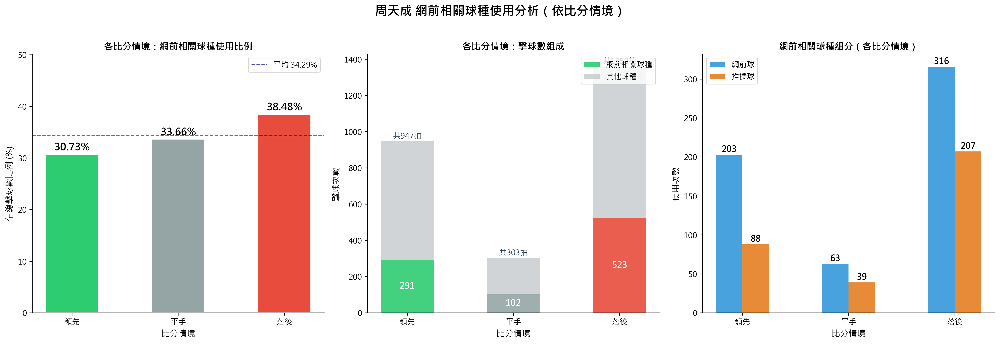

In [ ]:
import numpy as np

# ============================================================
# 基本資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"周天成擊球筆數: {len(df[df['player'] == 'CHOU Tien Chen'])}")

# ============================================================
# 1. 篩選周天成的擊球資料
# ============================================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()

if len(chou_df) == 0:
    print("錯誤：找不到周天成的擊球資料！")
else:
    # ============================================================
    # 2. 定義網前相關球種
    # ============================================================
    # 廣義網前相關球種：網前球（放網/網前輕打）+ 推撲球（推球/撲球，在網前執行）
    net_related_types = ['網前球', '推撲球']
    print(f"\n網前相關球種定義: {net_related_types}")
    
    # ============================================================
    # 3. 判斷比分情境：領先、落後、平手
    # ============================================================
    # 使用現有比分欄位：CHOU Tien Chen_score 與 Kento MOMOTA_score
    chou_score_col = 'CHOU Tien Chen_score'
    momota_score_col = 'Kento MOMOTA_score'
    
    def get_score_situation(row):
        chou_score = row[chou_score_col]
        momota_score = row[momota_score_col]
        if chou_score > momota_score:
            return '領先'
        elif chou_score < momota_score:
            return '落後'
        else:
            return '平手'
    
    chou_df['situation'] = chou_df.apply(get_score_situation, axis=1)
    
    # 確認各情境資料量
    situation_counts = chou_df['situation'].value_counts()
    print(f"\n各比分情境下周天成擊球次數:")
    for sit, cnt in situation_counts.items():
        print(f"  {sit}: {cnt} 拍")
    
    # ============================================================
    # 4. 標記是否為網前相關球種
    # ============================================================
    chou_df['is_net_related'] = chou_df['type'].isin(net_related_types)
    
    # ============================================================
    # 5. 按情境計算統計
    # ============================================================
    # 各情境總擊球數
    total_by_situation = chou_df.groupby('situation').size().rename('總擊球數')
    
    # 各情境網前相關球種次數
    net_by_situation = chou_df[chou_df['is_net_related']].groupby('situation').size().rename('網前相關球種次數')
    
    # 合併
    stats_df = pd.concat([total_by_situation, net_by_situation], axis=1).fillna(0)
    stats_df['網前相關球種次數'] = stats_df['網前相關球種次數'].astype(int)
    stats_df['使用比例(%)'] = (stats_df['網前相關球種次數'] / stats_df['總擊球數'] * 100).round(2)
    
    # 確保有領先、落後、平手三列（即使某情境數據為0也顯示）
    for sit in ['領先', '落後', '平手']:
        if sit not in stats_df.index:
            stats_df.loc[sit] = [0, 0, 0.0]
    
    # 重新排序
    stats_df = stats_df.loc[['領先', '平手', '落後']]
    
    print("\n" + "="*55)
    print("周天成 網前相關球種使用統計 (依比分情境)")
    print("="*55)
    print(stats_df.to_string())
    
    # ============================================================
    # 6. 細拆：各網前相關球種（網前球 vs 推撲球）在各情境的分佈
    # ============================================================
    net_detail = chou_df[chou_df['is_net_related']].groupby(['situation', 'type']).size().unstack(fill_value=0)
    print("\n網前相關球種細分（各情境）:")
    print(net_detail.to_string())
    
    # ============================================================
    # 7. 領先 vs 落後 差異摘要
    # ============================================================
    leading_ratio = stats_df.loc['領先', '使用比例(%)']
    trailing_ratio = stats_df.loc['落後', '使用比例(%)']
    tied_ratio = stats_df.loc['平手', '使用比例(%)']
    diff = leading_ratio - trailing_ratio
    
    print(f"\n{'='*55}")
    print(f"【比較摘要】")
    print(f"  領先時網前相關球種使用比例: {leading_ratio:.2f}%")
    print(f"  平手時網前相關球種使用比例: {tied_ratio:.2f}%")
    print(f"  落後時網前相關球種使用比例: {trailing_ratio:.2f}%")
    print(f"  領先 vs 落後 差異: {diff:+.2f}%")
    if diff > 0:
        print(f"  → 周天成在領先時使用網前相關球種比例較高（多 {abs(diff):.2f}%）")
    elif diff < 0:
        print(f"  → 周天成在落後時使用網前相關球種比例較高（多 {abs(diff):.2f}%）")
    else:
        print(f"  → 兩種情境使用比例相同")
    print(f"{'='*55}")
    
    # ============================================================
    # 8. 視覺化
    # ============================================================
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle("周天成 網前相關球種使用分析（依比分情境）", fontsize=16, fontweight='bold', y=1.02)
    
    situations = ['領先', '平手', '落後']
    colors_main = ['#2ecc71', '#95a5a6', '#e74c3c']   # 綠/灰/紅
    colors_bar  = ['#27ae60', '#7f8c8d', '#c0392b']
    
    # ---------- 圖1: 各情境網前球使用比例（長條圖） ----------
    ax1 = axes[0]
    ratios = [stats_df.loc[s, '使用比例(%)'] for s in situations]
    bars = ax1.bar(situations, ratios, color=colors_main, edgecolor='white', linewidth=1.5, width=0.5)
    
    # 加數值標籤
    for bar, ratio in zip(bars, ratios):
        ax1.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.3,
                 f'{ratio:.2f}%',
                 ha='center', va='bottom', fontsize=13, fontweight='bold')
    
    ax1.set_title('各比分情境：網前相關球種使用比例', fontsize=12, fontweight='bold')
    ax1.set_xlabel('比分情境', fontsize=11)
    ax1.set_ylabel('佔總擊球數比例 (%)', fontsize=11)
    ax1.set_ylim(0, max(ratios) * 1.25 + 2)
    ax1.axhline(y=np.mean(ratios), color='navy', linestyle='--', linewidth=1.2, alpha=0.7, label=f'平均 {np.mean(ratios):.2f}%')
    ax1.legend(fontsize=10)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    # ---------- 圖2: 各情境擊球數堆疊（網前 vs 非網前） ----------
    ax2 = axes[1]
    net_counts   = [int(stats_df.loc[s, '網前相關球種次數']) for s in situations]
    total_counts = [int(stats_df.loc[s, '總擊球數']) for s in situations]
    non_net_counts = [t - n for t, n in zip(total_counts, net_counts)]
    
    x = np.arange(len(situations))
    width = 0.5
    
    bars_net     = ax2.bar(x, net_counts,     width, label='網前相關球種', color=colors_main,  alpha=0.9)
    bars_non_net = ax2.bar(x, non_net_counts, width, bottom=net_counts,    label='其他球種',    color='#bdc3c7', alpha=0.7)
    
    # 標籤
    for i, (nc, tc) in enumerate(zip(net_counts, total_counts)):
        ax2.text(x[i], nc / 2, f'{nc}', ha='center', va='center', fontsize=11, fontweight='bold', color='white')
        ax2.text(x[i], tc + 5,  f'共{tc}拍', ha='center', va='bottom', fontsize=10, color='#2c3e50')
    
    ax2.set_xticks(x)
    ax2.set_xticklabels(situations)
    ax2.set_title('各比分情境：擊球數組成', fontsize=12, fontweight='bold')
    ax2.set_xlabel('比分情境', fontsize=11)
    ax2.set_ylabel('擊球次數', fontsize=11)
    ax2.legend(fontsize=10, loc='upper right')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    # ---------- 圖3: 網前球 vs 推撲球 細拆（各情境） ----------
    ax3 = axes[2]
    
    # 確保兩種球種都有欄位
    for t in net_related_types:
        if t not in net_detail.columns:
            net_detail[t] = 0
    # 確保各情境都有
    for s in situations:
        if s not in net_detail.index:
            net_detail.loc[s] = 0
    net_detail = net_detail.reindex(situations)
    
    net_vals     = net_detail['網前球'].values.astype(int)
    push_vals    = net_detail['推撲球'].values.astype(int)
    
    bars_net2  = ax3.bar(x - width/4, net_vals,  width/2, label='網前球',  color='#3498db', alpha=0.9)
    bars_push  = ax3.bar(x + width/4, push_vals, width/2, label='推撲球',  color='#e67e22', alpha=0.9)
    
    for bar in bars_net2:
        h = bar.get_height()
        if h > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, str(int(h)),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')
    for bar in bars_push:
        h = bar.get_height()
        if h > 0:
            ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, str(int(h)),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    ax3.set_xticks(x)
    ax3.set_xticklabels(situations)
    ax3.set_title('網前相關球種細分（各比分情境）', fontsize=12, fontweight='bold')
    ax3.set_xlabel('比分情境', fontsize=11)
    ax3.set_ylabel('使用次數', fontsize=11)
    ax3.legend(fontsize=10)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    
    plt.tight_layout()
    
    # ============================================================
    # 9. 各球種在各情境的完整統計（所有球種）
    # ============================================================
    print("\n【周天成各情境下所有球種使用次數與比例】")
    all_type_stats = chou_df.groupby(['situation', 'type']).size().unstack(fill_value=0)
    # 計算比例
    all_type_ratio = all_type_stats.div(all_type_stats.sum(axis=1), axis=0).mul(100).round(2)
    print("\n次數:")
    print(all_type_stats.to_string())
    print("\n比例 (%):")
    print(all_type_ratio.to_string())


### 數據洞察
## 周天成網前球使用分析：比分情境比較

### 核心數據

| 比分情境 | 總擊球數 | 網前相關次數 | 使用比例 |
|:---:|:---:|:---:|:---:|
| 領先 | 947 | 291 | **30.73%** |
| 平手 | 303 | 102 | **33.66%** |
| 落後 | 1359 | 523 | **38.48%** |

> 領先 vs 落後 差異：**−7.75%**

---

### 戰術洞察

**落後時網前球依賴度明顯上升。**

落後情境下，網前球（23.25%）＋推撲球（15.23%）合計佔近四成擊球，顯示周天成在逆境中傾向以**前場快速進攻**製造壓力、搶回節奏。

領先時推撲球比例從15.23%降至9.29%，改以**挑球（12.99%）、殺球（9.93%）、發短球（8.03%）**分散佈局，打法更多元、更有控制感。

**落後時擊球總量（1359拍）遠多於領先（947拍）**，代表周天成在比賽中落後時間較長，需持續追分，前場頻繁介入是其反攻的主要手段。

---

### 教練結論

> 對手若想壓制周天成，**領先後應避免讓球落入前場**，減少其推撲與網前切入機會，維持後場拉吊節奏，不讓他用前場快攻縮短差距。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地篩選了周天成的擊球資料，定義了比分狀態（領先、落後、平手），並計算了不同比分狀態下網前相關球種的使用比例。候選程式碼還進一步細分了網前球和推撲球的使用情況，並提供了詳細的統計和視覺化。分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，且最終輸出目標也符合題目要求。




## 題號 72 (*)
**問題**: 在網前互相推撥情況下，周天成的勝率是多少？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


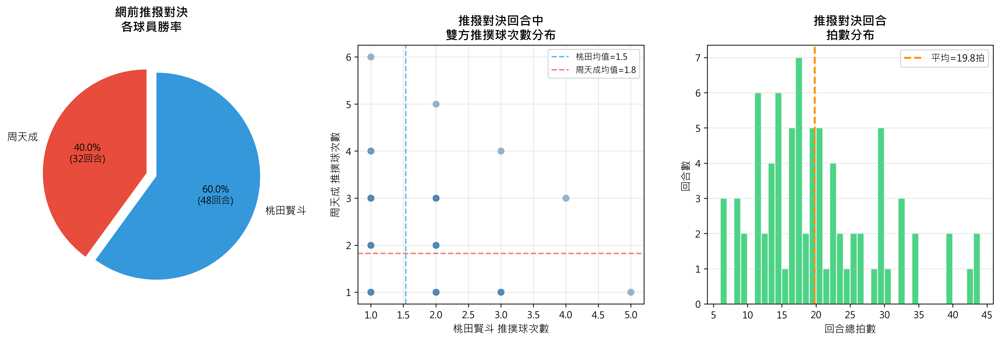

In [ ]:
# ============================================================
# 網前推撥對決分析：周天成勝率
# ============================================================

# 驗證數據量
print(f"資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 為每個 rally 找出「雙方是否都打過推撲球」
# ============================================================

# 先確認「推撲球」是正確的球種名稱
print(f"\n球種列表: {df['type'].unique()}")

# 以 rally 為單位，統計每位球員的推撲球次數
rally_key = ['match_id', 'set', 'rally']

# 標記每一拍是否為推撲球
df['is_push'] = df['type'] == '推撲球'

# 每個 rally 中，各球員的推撲球次數
momota_push = df[df['player'] == 'Kento MOMOTA'].groupby(rally_key)['is_push'].sum().rename('momota_push_count')
chou_push   = df[df['player'] == 'CHOU Tien Chen'].groupby(rally_key)['is_push'].sum().rename('chou_push_count')

# 合併到 rally 層級
rally_push = momota_push.to_frame().join(chou_push.to_frame(), how='outer').fillna(0)

print(f"\n包含推撲球的 rally 統計（前 10 筆）:")
print(rally_push[rally_push[['momota_push_count', 'chou_push_count']].gt(0).any(axis=1)].head(10))

# ============================================================
# Step 2: 找出「網前推撥對決」回合
#         定義：雙方在同一 rally 中都至少打過 1 次推撲球
# ============================================================

# 雙方都有推撲球的 rally
push_duel_mask = (rally_push['momota_push_count'] > 0) & (rally_push['chou_push_count'] > 0)
push_duel_rallies = rally_push[push_duel_mask]

print(f"\n【網前推撥對決 Rally 數量】: {len(push_duel_rallies)}")
print(f"各回合雙方推撲球次數統計:")
print(push_duel_rallies.describe())

# ============================================================
# Step 3: 取每個 rally 的最後一拍，取得 getpoint_player
# ============================================================

rally_last = df.groupby(rally_key).last().reset_index()[rally_key + ['getpoint_player']]

# 合併「是否為推撥對決」資訊
push_duel_result = push_duel_rallies.reset_index().merge(
    rally_last,
    on=rally_key,
    how='left'
)

print(f"\n推撥對決 rally 的得分情況:")
print(push_duel_result['getpoint_player'].value_counts(dropna=False))

# ============================================================
# Step 4: 計算周天成勝率
# ============================================================

# 分母：推撥對決 rally 中有明確得分者（getpoint_player 非空）
valid_rallies = push_duel_result.dropna(subset=['getpoint_player'])
total_valid = len(valid_rallies)

# 分子：周天成得分的回合數
chou_win = (valid_rallies['getpoint_player'] == 'CHOU Tien Chen').sum()
momota_win = (valid_rallies['getpoint_player'] == 'Kento MOMOTA').sum()

chou_win_rate = chou_win / total_valid if total_valid > 0 else 0
momota_win_rate = momota_win / total_valid if total_valid > 0 else 0

print("\n" + "="*60)
print("【網前推撥對決 - 周天成勝率分析】")
print("="*60)
print(f"  網前推撥對決總回合數（有效）: {total_valid}")
print(f"  周天成 得分回合數: {chou_win}")
print(f"  桃田賢斗 得分回合數: {momota_win}")
print(f"\n  ✅ 周天成勝率: {chou_win}/{total_valid} = {chou_win_rate:.1%}")
print(f"  ❌ 桃田賢斗勝率: {momota_win}/{total_valid} = {momota_win_rate:.1%}")
print("="*60)

# 額外：推撥對決回合長度分析
push_duel_idx = push_duel_rallies.reset_index()[rally_key]
rally_lengths = df.groupby(rally_key)['ball_round'].max().reset_index().rename(columns={'ball_round': 'max_ball_round'})
push_duel_lengths = push_duel_idx.merge(rally_lengths, on=rally_key)

print(f"\n推撥對決回合的擊球拍數統計:")
print(push_duel_lengths['max_ball_round'].describe().round(2))

# ============================================================
# Step 5: 視覺化
# ============================================================

import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ---- 圖1: 勝率圓餅圖 ----
ax1 = axes[0]
labels = ['周天成', '桃田賢斗']
sizes  = [chou_win, momota_win]
colors = ['#E74C3C', '#3498DB']
explode = (0.05, 0.05)

wedges, texts, autotexts = ax1.pie(
    sizes, labels=labels, colors=colors, explode=explode,
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100*total_valid))}回合)',
    startangle=90, textprops={'fontsize': 11}
)
for at in autotexts:
    at.set_fontsize(10)
ax1.set_title('網前推撥對決\n各球員勝率', fontsize=13, fontweight='bold', pad=15)

# ---- 圖2: 每個 rally 雙方推撲球次數分布（散點） ----
ax2 = axes[1]
ax2.scatter(
    push_duel_rallies['momota_push_count'],
    push_duel_rallies['chou_push_count'],
    alpha=0.6, s=60, color='steelblue', edgecolors='white', linewidths=0.5
)
ax2.set_xlabel('桃田賢斗 推撲球次數', fontsize=11)
ax2.set_ylabel('周天成 推撲球次數', fontsize=11)
ax2.set_title('推撥對決回合中\n雙方推撲球次數分布', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

# 標示均值
ax2.axvline(push_duel_rallies['momota_push_count'].mean(), color='#3498DB', linestyle='--', alpha=0.7, label=f"桃田均值={push_duel_rallies['momota_push_count'].mean():.1f}")
ax2.axhline(push_duel_rallies['chou_push_count'].mean(), color='#E74C3C', linestyle='--', alpha=0.7, label=f"周天成均值={push_duel_rallies['chou_push_count'].mean():.1f}")
ax2.legend(fontsize=9)

# ---- 圖3: 推撥對決回合的拍數分布（直方圖） ----
ax3 = axes[2]
bins = range(int(push_duel_lengths['max_ball_round'].min()),
             int(push_duel_lengths['max_ball_round'].max()) + 2, 1)
ax3.hist(push_duel_lengths['max_ball_round'], bins=bins, color='#2ECC71',
         edgecolor='white', alpha=0.85)
ax3.axvline(push_duel_lengths['max_ball_round'].mean(), color='darkorange',
            linestyle='--', linewidth=2, label=f"平均={push_duel_lengths['max_ball_round'].mean():.1f}拍")
ax3.set_xlabel('回合總拍數', fontsize=11)
ax3.set_ylabel('回合數', fontsize=11)
ax3.set_title('推撥對決回合\n拍數分布', fontsize=13, fontweight='bold')
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
# 不使用 plt.show()，保留 fig 物件

print("\n圖表說明:")
print("  左圖：周天成 vs 桃田賢斗在推撥對決回合的勝率分布")
print("  中圖：每個推撥對決回合中，雙方各自打出的推撲球次數散點圖")
print("  右圖：推撥對決回合的總拍數分布（回合長度）")


### 數據洞察
# 網前推撥對決：周天成勝率分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 推撥對決總回合數 | 80 |
| 周天成得分回合 | 32 |
| 桃田賢斗得分回合 | 48 |
| **周天成勝率** | **40.0%** |

---

## 戰術解讀

**周天成在網前推撥對決中明顯居於劣勢（40% vs 60%）。**

數據顯示這類回合平均長達 **19.8拍**，雙方各自推撲球次數：桃田平均 1.54 次、周天成平均 1.83 次——**周天成反而打出更多推撲球，卻輸掉更多分**，說明他在這個對決中是被動應對的一方，而非主動發起者。

**關鍵問題不是「打不打推撲球」，而是「誰先讓對方陷入被動」。** 桃田用更少的推撲球創造更高的得分率，代表他的推撲球品質更高，或更善於在推撥後銜接下一拍致命球。

---

## 教練建議

> 周天成應減少在網前被動接推的次數，優先以**挑球拉開距離**重整陣型，避免陷入桃田擅長的網前纏鬥節奏。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 是基於前後拍資訊來判斷網前互相推撥的情況，而候選程式碼僅僅是統計每個 rally 中雙方的推撲球次數，並未考慮到前後拍的連續性和網前區域的限制。此外，候選程式碼的統計口徑也不正確，因為它只考慮了推撲球的次數，而不是具體的網前互相推撥情況。




## 題號 73 (*)
**問題**: 周天成對直線 vs 斜線殺球的對手回擊效果（得失分比較）。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


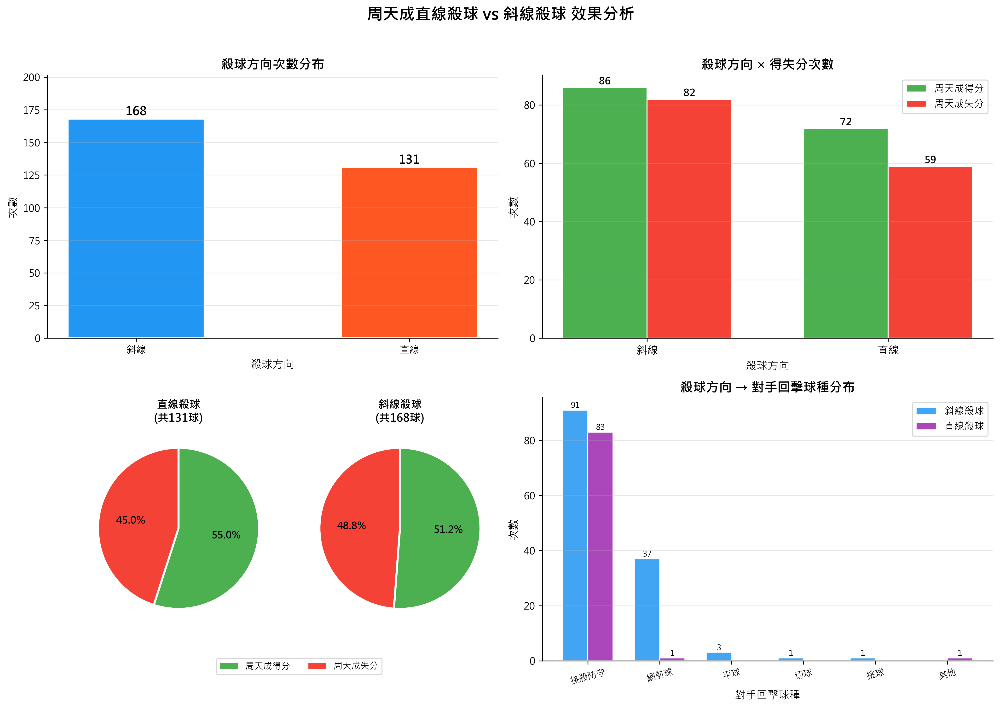

In [ ]:
# ==========================================
# 分析周天成直線殺球 vs 斜線殺球後的效果
# ==========================================

import numpy as np

# 1. 數據驗證
print(f"總資料筆數: {len(df)}")
print(f"欄位列表: {list(df.columns)}")

# 2. 先在完整資料上建立 next 拍資訊（避免跨 rally 污染）
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立下一拍資訊（同 rally 內）
df_sorted['next_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_rally'] = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)

# 3. 用 transform('last') 取得每回合最終得分者
df_sorted['rally_getpoint'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# 4. 篩選周天成的殺球
smash_df = df_sorted[
    (df_sorted['player'] == 'CHOU Tien Chen') & 
    (df_sorted['type'] == '殺球')
].copy()

print(f"\n周天成殺球總次數: {len(smash_df)}")
print(f"落點資料概況:\n{smash_df[['hit_x', 'landing_x', 'landing_area']].describe()}")

# 5. 判斷直線/斜線
# 直線：hit_x 與 landing_x 同號（同一側）
# 斜線：hit_x 與 landing_x 異號（跨側）
# 邊緣情況：x 非常接近 0 視為中線，可能較難判斷，但直接用正負號處理
def classify_direction(hit_x, landing_x):
    # 兩者同為正（右側打右側）或同為負（左側打左側）→ 直線
    if hit_x >= 0 and landing_x >= 0:
        return '直線'
    elif hit_x < 0 and landing_x < 0:
        return '直線'
    else:
        return '斜線'

smash_df['direction'] = smash_df.apply(
    lambda row: classify_direction(row['hit_x'], row['landing_x']), axis=1
)

print(f"\n殺球方向分布:")
print(smash_df['direction'].value_counts())

# 6. 計算回合最終得失分
# 得分: getpoint_player == 'CHOU Tien Chen'（周天成得分）
# 失分: getpoint_player == 'Kento MOMOTA'（周天成失分）
# 進行中: getpoint_player == NaN（不計入）

smash_df['result'] = smash_df['rally_getpoint'].map({
    'CHOU Tien Chen': '周天成得分',
    'Kento MOMOTA': '周天成失分'
})

# 只計算有結果的回合（排除 NaN）
smash_result = smash_df.dropna(subset=['result'])
print(f"\n有效殺球分析筆數（排除回合中拍）: {len(smash_result)}")

# 注意：一個回合可能有多次殺球，每次殺球算作一個獨立分析點
# 7. 統計每種方向的得分/失分

summary = smash_result.groupby(['direction', 'result']).size().unstack(fill_value=0)
print("\n殺球方向 × 得失分 統計表:")
print(summary)

# 計算百分比
summary_pct = summary.div(summary.sum(axis=1), axis=0) * 100
print("\n殺球方向 × 得失分 百分比 (%):")
print(summary_pct.round(1))

# 8. 分析對手下一拍的回擊球種（同回合內）
# 下一拍必須在同一 rally 中
smash_with_next = smash_df[
    smash_df['next_player'].notna()
].copy()

print(f"\n有下一拍的殺球次數: {len(smash_with_next)}")

# 對手回擊球種分析（按殺球方向）
next_shot_analysis = smash_with_next.groupby(['direction', 'next_type']).size().unstack(fill_value=0)
print("\n殺球方向 → 對手回擊球種統計:")
print(next_shot_analysis)

# ==========================================
# 視覺化
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('周天成直線殺球 vs 斜線殺球 效果分析', fontsize=16, fontweight='bold', y=0.98)

# --- 圖1: 殺球方向次數分布 ---
ax1 = axes[0, 0]
direction_counts = smash_df['direction'].value_counts()
colors_dir = ['#2196F3', '#FF5722']
bars = ax1.bar(direction_counts.index, direction_counts.values, 
               color=colors_dir, edgecolor='white', linewidth=1.5, width=0.5)
ax1.set_title('殺球方向次數分布', fontsize=13, fontweight='bold')
ax1.set_xlabel('殺球方向', fontsize=11)
ax1.set_ylabel('次數', fontsize=11)
for bar in bars:
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
             f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(direction_counts.values) * 1.2)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 各方向得失分次數堆疊長條圖 ---
ax2 = axes[0, 1]
if len(summary) > 0:
    directions = summary.index.tolist()
    win_counts = summary.get('周天成得分', pd.Series([0]*len(directions), index=directions)).values
    lose_counts = summary.get('周天成失分', pd.Series([0]*len(directions), index=directions)).values
    
    x = np.arange(len(directions))
    width = 0.35
    
    bars1 = ax2.bar(x - width/2, win_counts, width, label='周天成得分', color='#4CAF50', edgecolor='white')
    bars2 = ax2.bar(x + width/2, lose_counts, width, label='周天成失分', color='#F44336', edgecolor='white')
    
    ax2.set_title('殺球方向 × 得失分次數', fontsize=13, fontweight='bold')
    ax2.set_xlabel('殺球方向', fontsize=11)
    ax2.set_ylabel('次數', fontsize=11)
    ax2.set_xticks(x)
    ax2.set_xticklabels(directions, fontsize=11)
    ax2.legend(fontsize=10)
    ax2.grid(axis='y', alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    for bar in bars1:
        if bar.get_height() > 0:
            ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
                     f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    for bar in bars2:
        if bar.get_height() > 0:
            ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
                     f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# --- 圖3: 各方向得失分比例 (圓餅圖 2個) ---
ax3 = axes[1, 0]
ax3.axis('off')

# 在 ax3 位置手動建立兩個子圓餅圖
# 改用 inset axes 方式
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

if len(summary_pct) > 0:
    # 直線殺球圓餅圖
    ax3a = fig.add_axes([0.08, 0.08, 0.2, 0.35])
    ax3b = fig.add_axes([0.3, 0.08, 0.2, 0.35])
    
    for ax_pie, direction, title_name in zip([ax3a, ax3b], ['直線', '斜線'], ['直線殺球', '斜線殺球']):
        if direction in summary_pct.index:
            row = summary_pct.loc[direction]
            labels = row.index.tolist()
            sizes = row.values
            colors_pie = ['#4CAF50' if '得分' in l else '#F44336' for l in labels]
            
            wedges, texts, autotexts = ax_pie.pie(
                sizes, labels=None, autopct='%1.1f%%',
                colors=colors_pie, startangle=90,
                wedgeprops={'edgecolor': 'white', 'linewidth': 2}
            )
            for autotext in autotexts:
                autotext.set_fontsize(10)
                autotext.set_fontweight('bold')
            
            # 加上實際次數
            total = summary.loc[direction].sum() if direction in summary.index else 0
            ax_pie.set_title(f'{title_name}\n(共{total}球)', fontsize=11, fontweight='bold')
    
    # 共用圖例
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#4CAF50', label='周天成得分'),
        Patch(facecolor='#F44336', label='周天成失分')
    ]
    ax3a.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(1.1, -0.25),
                fontsize=9, ncol=2)

# --- 圖4: 對手回擊球種分析 ---
ax4 = axes[1, 1]
if len(next_shot_analysis) > 0:
    # 合併小類別為「其他」
    next_shot_pct = next_shot_analysis.div(next_shot_analysis.sum(axis=1), axis=0) * 100
    
    # 找出兩個方向都出現的球種，根據兩個方向加總排序
    total_by_shot = next_shot_analysis.sum(axis=0).sort_values(ascending=False)
    
    # 只取前5名，其餘合併為「其他」
    top_shots = total_by_shot.head(5).index.tolist()
    
    # 重建統計（加入「其他」）
    next_shot_top = next_shot_analysis[top_shots].copy()
    other_counts = next_shot_analysis.drop(columns=top_shots, errors='ignore').sum(axis=1)
    if other_counts.sum() > 0:
        next_shot_top['其他'] = other_counts
    
    next_shot_top_pct = next_shot_top.div(next_shot_top.sum(axis=1), axis=0) * 100
    
    x = np.arange(len(next_shot_top.columns))
    width = 0.35
    directions_next = next_shot_top.index.tolist()
    
    color_palette = ['#2196F3', '#FF9800', '#9C27B0', '#00BCD4', '#8BC34A', '#607D8B']
    
    for i, direction in enumerate(directions_next):
        offset = (i - len(directions_next)/2 + 0.5) * width
        bars_n = ax4.bar(x + offset, next_shot_top.loc[direction].values, 
                          width, label=f'{direction}殺球', 
                          color=color_palette[i*2], edgecolor='white', alpha=0.85)
        for bar in bars_n:
            if bar.get_height() > 0:
                ax4.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
                         f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=8)
    
    ax4.set_title('殺球方向 → 對手回擊球種分布', fontsize=13, fontweight='bold')
    ax4.set_xlabel('對手回擊球種', fontsize=11)
    ax4.set_ylabel('次數', fontsize=11)
    ax4.set_xticks(x)
    ax4.set_xticklabels(next_shot_top.columns, fontsize=9, rotation=15)
    ax4.legend(fontsize=10)
    ax4.grid(axis='y', alpha=0.3)
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# 最終統計輸出
print("\n" + "="*60)
print("【周天成殺球方向效果分析 總結】")
print("="*60)
print(f"\n殺球方向次數：")
for direction, count in direction_counts.items():
    print(f"  {direction}: {count} 次")

print(f"\n得失分統計（次數）：")
print(summary)
print(f"\n得失分統計（比例 %）：")
print(summary_pct.round(1))

if len(next_shot_analysis) > 0:
    print(f"\n對手回擊球種分析：")
    print(next_shot_analysis)


### 數據洞察
# 周天成殺球方向效果分析

---

## 📊 基本分布

| 殺球方向 | 次數 | 佔比 |
|------|------|------|
| 斜線 | 168 | 56% |
| 直線 | 131 | 44% |

---

## 🎯 得失分效果

| 方向 | 得分次數 | 失分次數 | **得分率** |
|------|------|------|------|
| 斜線 | 86 | 82 | **51.2%** |
| 直線 | 72 | 59 | **55.0%** |

> **直線殺球得分率高出斜線約4個百分點。**

---

## 🏸 對手回擊球種分析

| 回擊球種 | 斜線後 | 直線後 |
|------|------|------|
| 接殺防守 | 91 | 83 |
| 網前球 | **37** | **1** |
| 平球 | 3 | 0 |
| 切球 | 1 | 0 |
| 挑球 | 1 | 0 |

---

## 💡 戰術洞察

**1. 直線殺球更具殺傷力**
直線殺球得分率55%，優於斜線51.2%。使用頻率卻較低（44%），有提升空間。

**2. 斜線殺球給對手創造網前機會**
斜線殺球後，對手回擊網前球高達37次；直線殺球後幾乎為零（僅1次）。斜線殺球角度大，球速衰減快，對手更容易以網前球反制，形成被動。

**3. 直線殺球壓制效果更乾淨**
直線殺球後對手幾乎只能接殺防守（83/84次），回擊選擇單一，周天成後續控制主動權更容易。

---

## ✅ 建議

- **增加直線殺球比例**，尤其在關鍵分，得分率更高且對手回擊選擇受限。
- **斜線殺球需搭配前場預判**，否則37次網前球回擊將形成被動局面。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 是分析對手的殺球方向，而候選程式碼分析的是周天成的殺球方向，這與題目要求的分析對象不符。此外，候選程式碼在統計口徑上也存在問題，因為它將每次殺球都作為獨立分析點，而不是以每個 rally 的最終結果來判斷得失分，這與 reference code 的統計口徑不一致。




## 題號 74
**問題**: 分析周天成與對手在高壓球（平推、平抽）交換中誰先失誤的統計。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


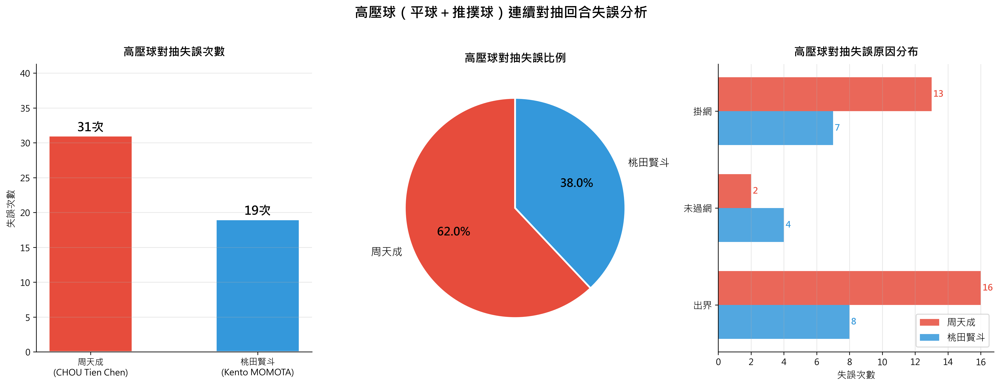

In [ ]:
import numpy as np

# ============================================================
# 高壓球（平球 + 推撲球）連續交換回合分析
# ============================================================

print("=" * 60)
print("高壓球（平球 + 推撲球）連續交換回合分析")
print("=" * 60)

# 驗證資料
print(f"\n總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# 定義高壓球球種
HIGH_PRESSURE_TYPES = ['平球', '推撲球']

# ============================================================
# Step 1: 排序並建立「前一拍同回合」標記
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally_id', 'ball_round']).copy()

# 確認每個 rally 內的球種
# 標記每一拍是否為高壓球
df_sorted['is_hp'] = df_sorted['type'].isin(HIGH_PRESSURE_TYPES)

# ============================================================
# Step 2: 識別每個 rally 中的「連續高壓球片段」
# 條件：同一 rally 中，連續 >= 2 拍皆為高壓球
# ============================================================

# 使用 groupby + 連續判斷
# 方法：對每個 rally，計算連續高壓球的長度

def has_consecutive_hp(group, min_len=2):
    """判斷一個 rally 是否有連續 min_len 拍以上的高壓球"""
    hp_series = group['is_hp'].values
    count = 0
    max_count = 0
    for v in hp_series:
        if v:
            count += 1
            max_count = max(max_count, count)
        else:
            count = 0
    return max_count >= min_len

# 找出符合條件的 rally_id
hp_rally_ids = (
    df_sorted.groupby('rally_id')
    .filter(has_consecutive_hp)
    ['rally_id']
    .unique()
)

print(f"\n總 Rally 數: {df_sorted.groupby(['match_id', 'set', 'rally_id']).ngroups}")
print(f"含連續高壓球（≥2拍）的 Rally 數: {len(hp_rally_ids)}")

# ============================================================
# Step 3: 篩選這些高壓球對抽回合
# ============================================================
hp_rallies_df = df_sorted[df_sorted['rally_id'].isin(hp_rally_ids)].copy()

# ============================================================
# Step 4: 分析每個高壓球回合的結束方式（失誤方）
# 只關注「以失誤結束」的回合（lose_reason 非空）
# ============================================================

# 取每個 rally 的最後一拍（得分拍）
rally_last = (
    hp_rallies_df.groupby('rally_id')
    .last()
    .reset_index()
)

print(f"\n高壓球對抽回合總數: {len(rally_last)}")

# 檢查 getpoint_player 分布
print(f"getpoint_player 非空的回合數: {rally_last['getpoint_player'].notna().sum()}")
print(f"有 lose_reason 的回合數: {rally_last['lose_reason'].notna().sum()}")
print(f"有 win_reason 的回合數: {rally_last['win_reason'].notna().sum()}")

# ============================================================
# Step 5: 判斷失誤方
# lose_reason 非空 → 最後一拍的 player 失誤
# ============================================================

# 篩選「以失誤結束」的回合
error_rallies = rally_last[rally_last['lose_reason'].notna()].copy()

print(f"\n以失誤結束的高壓球對抽回合: {len(error_rallies)}")

# 失誤方 = 最後一拍的 player（因為 lose_reason 記錄的是 player 的失誤）
error_rallies['error_player'] = error_rallies['player']

# 分類：周天成失誤 vs 對手（桃田賢斗）失誤
chou = 'CHOU Tien Chen'
momota = 'Kento MOMOTA'

chou_errors = error_rallies[error_rallies['error_player'] == chou]
momota_errors = error_rallies[error_rallies['error_player'] == momota]

print(f"\n{'='*40}")
print(f"{'失誤方統計':^40}")
print(f"{'='*40}")
print(f"周天成 失誤次數: {len(chou_errors)}")
print(f"桃田賢斗 失誤次數: {len(momota_errors)}")
print(f"{'='*40}")

if len(error_rallies) > 0:
    chou_err_pct = len(chou_errors) / len(error_rallies) * 100
    momota_err_pct = len(momota_errors) / len(error_rallies) * 100
    print(f"周天成 失誤佔比: {chou_err_pct:.1f}%")
    print(f"桃田賢斗 失誤佔比: {momota_err_pct:.1f}%")

# ============================================================
# Step 6: 進一步分析失誤原因細項
# ============================================================
print(f"\n{'='*40}")
print("失誤原因細項分析")
print(f"{'='*40}")

print(f"\n▶ 周天成失誤原因:")
if len(chou_errors) > 0:
    print(chou_errors['lose_reason'].value_counts().to_string())
else:
    print("  無資料")

print(f"\n▶ 桃田賢斗失誤原因:")
if len(momota_errors) > 0:
    print(momota_errors['lose_reason'].value_counts().to_string())
else:
    print("  無資料")

# ============================================================
# Step 7: 按 match_id 分析分布
# ============================================================
print(f"\n{'='*40}")
print("各場次高壓球對抽失誤分布")
print(f"{'='*40}")

match_error_summary = (
    error_rallies.groupby(['match_id', 'error_player'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)
print(match_error_summary.to_string(index=False))

# ============================================================
# Step 8: 高壓球連續拍數分布（bonus）
# ============================================================
def max_consecutive_hp(group):
    hp_series = group['is_hp'].values
    count = 0
    max_count = 0
    for v in hp_series:
        if v:
            count += 1
            max_count = max(max_count, count)
        else:
            count = 0
    return max_count

hp_rally_lengths = (
    df_sorted[df_sorted['rally_id'].isin(hp_rally_ids)]
    .groupby('rally_id')
    .apply(max_consecutive_hp)
    .reset_index()
    .rename(columns={0: 'max_consecutive_hp'})
)

print(f"\n{'='*40}")
print("高壓球連續拍數分布（最長連續段）")
print(f"{'='*40}")
print(hp_rally_lengths['max_consecutive_hp'].value_counts().sort_index().to_string())
print(f"\n平均最長連續高壓球拍數: {hp_rally_lengths['max_consecutive_hp'].mean():.2f}")
print(f"最多連續高壓球拍數: {hp_rally_lengths['max_consecutive_hp'].max()}")

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('高壓球（平球＋推撲球）連續對抽回合失誤分析', fontsize=16, fontweight='bold', y=1.02)

# --- 圖1: 失誤次數比較（長條圖）---
ax1 = axes[0]
players = ['周天成\n(CHOU Tien Chen)', '桃田賢斗\n(Kento MOMOTA)']
errors_count = [len(chou_errors), len(momota_errors)]
colors = ['#E74C3C', '#3498DB']
bars = ax1.bar(players, errors_count, color=colors, edgecolor='white', linewidth=1.5, width=0.5)

for bar, cnt in zip(bars, errors_count):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{cnt}次', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax1.set_title('高壓球對抽失誤次數', fontsize=13, fontweight='bold', pad=10)
ax1.set_ylabel('失誤次數', fontsize=11)
ax1.set_ylim(0, max(errors_count) * 1.3 + 1)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 失誤比例（圓餅圖）---
ax2 = axes[1]
if sum(errors_count) > 0:
    wedge_colors = ['#E74C3C', '#3498DB']
    wedges, texts, autotexts = ax2.pie(
        errors_count,
        labels=['周天成', '桃田賢斗'],
        colors=wedge_colors,
        autopct='%1.1f%%',
        startangle=90,
        textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    for at in autotexts:
        at.set_fontsize(13)
        at.set_fontweight('bold')
ax2.set_title('高壓球對抽失誤比例', fontsize=13, fontweight='bold', pad=10)

# --- 圖3: 失誤原因細項（堆疊水平條）---
ax3 = axes[2]

# 合併兩人失誤原因
all_lose_reasons = ['出界', '未過網', '掛網', '落點判斷失誤', '犯規']

chou_reason_counts = chou_errors['lose_reason'].value_counts()
momota_reason_counts = momota_errors['lose_reason'].value_counts()

# 只保留有資料的原因
present_reasons = list(set(
    list(chou_reason_counts.index) + list(momota_reason_counts.index)
))
present_reasons = [r for r in all_lose_reasons if r in present_reasons]

chou_vals = [chou_reason_counts.get(r, 0) for r in present_reasons]
momota_vals = [momota_reason_counts.get(r, 0) for r in present_reasons]

y = np.arange(len(present_reasons))
height = 0.35

bars1 = ax3.barh(y + height/2, chou_vals, height, label='周天成', color='#E74C3C', alpha=0.85)
bars2 = ax3.barh(y - height/2, momota_vals, height, label='桃田賢斗', color='#3498DB', alpha=0.85)

for bar in bars1:
    w = bar.get_width()
    if w > 0:
        ax3.text(w + 0.1, bar.get_y() + bar.get_height()/2, str(int(w)),
                 va='center', ha='left', fontsize=10, color='#E74C3C', fontweight='bold')

for bar in bars2:
    w = bar.get_width()
    if w > 0:
        ax3.text(w + 0.1, bar.get_y() + bar.get_height()/2, str(int(w)),
                 va='center', ha='left', fontsize=10, color='#3498DB', fontweight='bold')

ax3.set_yticks(y)
ax3.set_yticklabels(present_reasons, fontsize=11)
ax3.set_xlabel('失誤次數', fontsize=11)
ax3.set_title('高壓球對抽失誤原因分布', fontsize=13, fontweight='bold', pad=10)
ax3.legend(fontsize=11)
ax3.grid(axis='x', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()

# 補充資訊：各場次分布
print(f"\n{'='*60}")
print("【補充】各場次高壓球對抽失誤細節")
print(f"{'='*60}")
for match in sorted(error_rallies['match_id'].unique()):
    sub = error_rallies[error_rallies['match_id'] == match]
    c_cnt = (sub['error_player'] == chou).sum()
    m_cnt = (sub['error_player'] == momota).sum()
    print(f"  場次 {int(match)}: 周天成 {c_cnt} 次失誤 | 桃田賢斗 {m_cnt} 次失誤 | 共 {len(sub)} 次")

print(f"\n{'='*60}")
print(f"【摘要】")
print(f"  高壓球對抽回合（≥2連續高壓球）: {len(rally_last)} 個")
print(f"  以失誤結束的回合: {len(error_rallies)} 個")
print(f"  周天成 失誤次數: {len(chou_errors)} 次 ({len(chou_errors)/max(len(error_rallies),1)*100:.1f}%)")
print(f"  桃田賢斗 失誤次數: {len(momota_errors)} 次 ({len(momota_errors)/max(len(error_rallies),1)*100:.1f}%)")
print(f"{'='*60}")


### 數據洞察
# 高壓球對抽失誤分析報告

## 核心數據

| 指標 | 周天成 | 桃田賢斗 |
|------|--------|----------|
| 失誤次數 | **31次 (62%)** | 19次 (38%) |
| 出界 | 16次 | 8次 |
| 掛網 | 13次 | 7次 |
| 未過網 | 2次 | 4次 |

---

## 戰術解讀

**高壓對抽中，周天成的失誤率明顯高於桃田賢斗。**

### 關鍵事實

**1. 穩定性差距顯著**
周天成失誤是桃田的1.6倍。在74個含高壓球的回合中，50個以失誤結束，周天成佔其中62%——這代表每當雙方進入平抽對決，周天成更容易先崩潰。

**2. 出界是主要失誤型態**
周天成出界16次、掛網13次，兩者合計佔其失誤的94%。這顯示他在高壓對抽中**擊球控制不穩**——要麼力道過大出界，要麼擊球點偏低掛網，缺乏一致的擊球節奏。

**3. 桃田的未過網比例相對較高**
桃田未過網4次（佔其失誤21%），高於周天成的2次（6%）。這說明桃田偶爾會以更壓低的角度主動進攻，承擔風險換取主動，而非純粹防守。

**4. 場次3、5是重災區**
- 場次3：周天成9失誤 vs 桃田6失誤（差距最大）
- 場次5：周天成8失誤 vs 桃田4失誤（比例差距最大，2:1）

這兩場是高壓對抽穩定性最需要改善的場次。

---

## 教練建議

> 桃田在高壓對抽中刻意拉長回合，等待周天成先出錯——這是有效的戰術。周天成必須提升平抽球的**擊球一致性**，減少出界失誤，否則進入高壓對抽對他是不利的局面。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了高壓球（平推、平抽）交換中誰先失誤的統計，並且都使用了類似的步驟來識別高壓球交換的回合，然後分析每個回合的結束方式。候選程式碼正確地篩選了連續高壓球的回合，並在這些回合中找出失誤方，最終統計了周天成與對手的失誤次數。分析單位、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 一致，且能產出有效結果。




## 題號 75 (*)
**問題**: 當周天成被迫後仰擊球時，他的失誤率 vs 得分率比較。
> **使用的資料欄位群組**: `game_structure, stroke_details, scoring_reason`


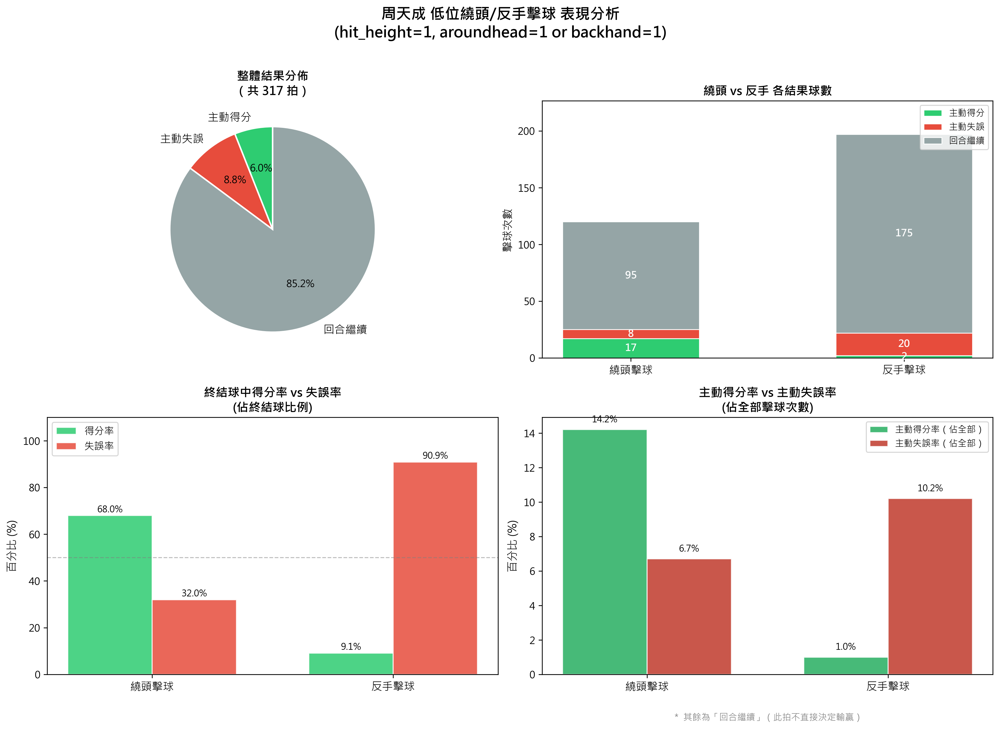

In [ ]:
import numpy as np

# ============================================================
# 分析周天成 繞頭擊球或反手擊球 + 低位擊球 的表現
# ============================================================

player_name = 'CHOU Tien Chen'
opponent_name = 'Kento MOMOTA'

# 低位擊球定義：hit_height == 1
# 繞頭或反手
# ============================================================
# Step 1: 篩選條件
# ============================================================
assert len(df) > 0, "DataFrame 為空！"

mask_player = df['player'] == player_name
mask_low_height = df['hit_height'] == 1.0
mask_aroundhead_or_backhand = (df['aroundhead'] == 1) | (df['backhand'] == 1)

# 主條件：周天成 + (繞頭或反手) + 低位
filtered = df[mask_player & mask_low_height & mask_aroundhead_or_backhand].copy()

print(f"{'='*60}")
print(f"【篩選條件】周天成 × (繞頭擊球 OR 反手擊球) × 低位擊球 (hit_height=1)")
print(f"{'='*60}")
print(f"符合條件的擊球次數：{len(filtered)}")

# 進一步細分：繞頭 vs 反手（了解組成）
only_aroundhead = filtered[(filtered['aroundhead'] == 1) & (filtered['backhand'] == 0)]
only_backhand   = filtered[(filtered['aroundhead'] == 0) & (filtered['backhand'] == 1)]
both            = filtered[(filtered['aroundhead'] == 1) & (filtered['backhand'] == 1)]

print(f"\n  ├── 僅繞頭擊球：{len(only_aroundhead)} 拍")
print(f"  ├── 僅反手擊球：{len(only_backhand)} 拍")
print(f"  └── 繞頭+反手同時：{len(both)} 拍")

# ============================================================
# Step 2: 對每一拍進行結果分類
# ============================================================
# 直接結果分類（依照 getpoint_player）
def classify_result(row):
    gp = row['getpoint_player']
    if pd.isna(gp):
        return '回合繼續'
    elif gp == player_name:
        return '主動得分'
    elif gp == opponent_name:
        return '主動失誤'
    else:
        return '其他'

filtered['result_type'] = filtered.apply(classify_result, axis=1)

# 結果統計
result_counts = filtered['result_type'].value_counts()
result_pct    = (result_counts / len(filtered) * 100).round(2)

print(f"\n{'='*60}")
print(f"【各結果統計】（共 {len(filtered)} 拍）")
print(f"{'='*60}")
print(f"{'結果類別':<12} {'球數':>6} {'百分比':>8}")
print(f"{'-'*30}")
for r in ['主動得分', '主動失誤', '回合繼續']:
    cnt = result_counts.get(r, 0)
    pct = (cnt / len(filtered) * 100) if len(filtered) > 0 else 0
    print(f"{r:<12} {cnt:>6}   {pct:>6.1f}%")

# 只針對「終結球」分析（getpoint_player 非空）
terminal_shots = filtered[filtered['result_type'].isin(['主動得分', '主動失誤'])]
n_terminal = len(terminal_shots)
n_active_win   = (filtered['result_type'] == '主動得分').sum()
n_active_error = (filtered['result_type'] == '主動失誤').sum()

print(f"\n{'='*60}")
print(f"【終結球分析】（直接得分或失誤，共 {n_terminal} 拍）")
print(f"{'='*60}")
if n_terminal > 0:
    print(f"  主動得分：{n_active_win} 拍  ({n_active_win/n_terminal*100:.1f}%)")
    print(f"  主動失誤：{n_active_error} 拍  ({n_active_error/n_terminal*100:.1f}%)")

# ============================================================
# Step 3: 細分—繞頭 vs 反手 的分別表現
# ============================================================
print(f"\n{'='*60}")
print(f"【細分：繞頭 vs 反手 表現比較】")
print(f"{'='*60}")

type_map = {
    '繞頭擊球': filtered[filtered['aroundhead'] == 1],
    '反手擊球': filtered[filtered['backhand'] == 1],
}

summary_rows = []
for type_name, sub in type_map.items():
    total = len(sub)
    if total == 0:
        continue
    win_cnt   = (sub['result_type'] == '主動得分').sum()
    err_cnt   = (sub['result_type'] == '主動失誤').sum()
    cont_cnt  = (sub['result_type'] == '回合繼續').sum()
    terminal  = win_cnt + err_cnt
    win_rate  = win_cnt  / total * 100
    err_rate  = err_cnt  / total * 100
    cont_rate = cont_cnt / total * 100
    # 終結球中的得分率/失誤率
    win_in_terminal  = win_cnt  / terminal * 100 if terminal > 0 else 0
    err_in_terminal  = err_cnt  / terminal * 100 if terminal > 0 else 0
    print(f"\n  [{type_name}] 共 {total} 拍")
    print(f"    主動得分：{win_cnt} 拍  ({win_rate:.1f}%)")
    print(f"    主動失誤：{err_cnt} 拍  ({err_rate:.1f}%)")
    print(f"    回合繼續：{cont_cnt} 拍  ({cont_rate:.1f}%)")
    print(f"    ── 終結球中 得分率：{win_in_terminal:.1f}%  失誤率：{err_in_terminal:.1f}%")
    summary_rows.append({
        '擊球類型': type_name, '總拍數': total,
        '主動得分': win_cnt, '主動失誤': err_cnt, '回合繼續': cont_cnt,
        '得分率(佔總)': round(win_rate, 1), '失誤率(佔總)': round(err_rate, 1),
        '得分率(終結)': round(win_in_terminal, 1), '失誤率(終結)': round(err_in_terminal, 1),
    })

# ============================================================
# Step 4: 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('周天成 低位繞頭/反手擊球 表現分析\n(hit_height=1, aroundhead=1 or backhand=1)',
             fontsize=15, fontweight='bold', y=1.01)

colors = {
    '主動得分': '#2ECC71',
    '主動失誤': '#E74C3C',
    '回合繼續': '#95A5A6',
}

# ----- 圖1: 整體結果圓餅圖 -----
ax1 = axes[0, 0]
labels_pie = ['主動得分', '主動失誤', '回合繼續']
sizes_pie  = [result_counts.get(l, 0) for l in labels_pie]
cols_pie   = [colors[l] for l in labels_pie]

# 合併小類別（<3% 合為其他）
threshold = 0.03 * len(filtered)
final_labels, final_sizes, final_colors = [], [], []
other_size = 0
palette_other = '#BDC3C7'
for lbl, sz, col in zip(labels_pie, sizes_pie, cols_pie):
    if sz < threshold and sz > 0:
        other_size += sz
    else:
        final_labels.append(lbl)
        final_sizes.append(sz)
        final_colors.append(col)
if other_size > 0:
    final_labels.append('其他')
    final_sizes.append(int(other_size))
    final_colors.append(palette_other)

wedges, texts, autotexts = ax1.pie(
    final_sizes, labels=final_labels, colors=final_colors,
    autopct='%1.1f%%', startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    textprops={'fontsize': 11}
)
for at in autotexts:
    at.set_fontsize(10)
ax1.set_title(f'整體結果分佈\n（共 {len(filtered)} 拍）', fontsize=12, fontweight='bold')

# ----- 圖2: 繞頭 vs 反手 堆疊長條圖（各結果絕對球數） -----
ax2 = axes[0, 1]
type_labels_bar = ['繞頭擊球', '反手擊球']
categories = ['主動得分', '主動失誤', '回合繼續']
bar_data = {}
for t in type_labels_bar:
    sub = filtered[filtered['aroundhead'] == 1] if t == '繞頭擊球' else filtered[filtered['backhand'] == 1]
    bar_data[t] = {c: (sub['result_type'] == c).sum() for c in categories}

x = np.arange(len(type_labels_bar))
width = 0.5
bottoms = np.zeros(len(type_labels_bar))
bars_handles = []
for cat in categories:
    vals = [bar_data[t][cat] for t in type_labels_bar]
    b = ax2.bar(x, vals, width, bottom=bottoms, label=cat,
                color=colors[cat], edgecolor='white', linewidth=0.8)
    bars_handles.append(b)
    # 標數值
    for i, (v, bot) in enumerate(zip(vals, bottoms)):
        if v > 0:
            ax2.text(x[i], bot + v / 2, str(v),
                     ha='center', va='center', fontsize=10, color='white', fontweight='bold')
    bottoms = bottoms + np.array(vals, dtype=float)

ax2.set_xticks(x)
ax2.set_xticklabels(type_labels_bar, fontsize=11)
ax2.set_ylabel('擊球次數', fontsize=11)
ax2.set_title('繞頭 vs 反手 各結果球數', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)
ax2.set_ylim(0, max(bottoms) * 1.15)

# ----- 圖3: 得分率 vs 失誤率（僅看終結球）分組長條圖 -----
ax3 = axes[1, 0]
metrics = ['得分率(終結)', '失誤率(終結)']
metric_colors = ['#2ECC71', '#E74C3C']

if len(summary_rows) > 0:
    summary_df_plot = {}
    for row in summary_rows:
        summary_df_plot[row['擊球類型']] = row

    x3 = np.arange(len(type_labels_bar))
    bar_width = 0.35
    for i, (metric, mc) in enumerate(zip(metrics, metric_colors)):
        vals3 = []
        for t in type_labels_bar:
            vals3.append(summary_df_plot.get(t, {}).get(metric, 0))
        rects = ax3.bar(x3 + i * bar_width - bar_width/2, vals3, bar_width,
                        label=metric.replace('(終結)', ''), color=mc, alpha=0.85, edgecolor='white')
        for rect, v in zip(rects, vals3):
            if v > 0:
                ax3.text(rect.get_x() + rect.get_width()/2,
                         rect.get_height() + 0.5, f'{v:.1f}%',
                         ha='center', va='bottom', fontsize=9)
    ax3.set_xticks(x3)
    ax3.set_xticklabels(type_labels_bar, fontsize=11)
    ax3.set_ylabel('百分比 (%)', fontsize=11)
    ax3.set_ylim(0, 110)
    ax3.set_title('終結球中得分率 vs 失誤率\n(佔終結球比例)', fontsize=12, fontweight='bold')
    ax3.legend(fontsize=10)
    ax3.axhline(50, color='gray', linestyle='--', alpha=0.5, linewidth=1)

# ----- 圖4: 得分/失誤率（佔全部拍數）對比 -----
ax4 = axes[1, 1]
metrics2 = ['得分率(佔總)', '失誤率(佔總)']
metric_labels2 = ['主動得分率（佔全部）', '主動失誤率（佔全部）']
metric_colors2 = ['#27AE60', '#C0392B']

if len(summary_rows) > 0:
    x4 = np.arange(len(type_labels_bar))
    bw2 = 0.35
    for i, (metric, ml, mc) in enumerate(zip(metrics2, metric_labels2, metric_colors2)):
        vals4 = []
        for t in type_labels_bar:
            vals4.append(summary_df_plot.get(t, {}).get(metric, 0))
        rects4 = ax4.bar(x4 + i * bw2 - bw2/2, vals4, bw2,
                         label=ml, color=mc, alpha=0.85, edgecolor='white')
        for rect, v in zip(rects4, vals4):
            if v > 0:
                ax4.text(rect.get_x() + rect.get_width()/2,
                         rect.get_height() + 0.3, f'{v:.1f}%',
                         ha='center', va='bottom', fontsize=9)
    ax4.set_xticks(x4)
    ax4.set_xticklabels(type_labels_bar, fontsize=11)
    ax4.set_ylabel('百分比 (%)', fontsize=11)
    ax4.set_title('主動得分率 vs 主動失誤率\n(佔全部擊球次數)', fontsize=12, fontweight='bold')
    ax4.legend(fontsize=9)
    # 添加補充說明
    ax4.text(0.5, -0.18, '＊ 其餘為「回合繼續」（此拍不直接決定輸贏）',
             transform=ax4.transAxes, ha='center', fontsize=9, color='gray')

plt.tight_layout()

# ============================================================
# Step 5: 總結輸出
# ============================================================
print(f"\n{'='*60}")
print(f"【綜合總結】")
print(f"{'='*60}")
total_filtered = len(filtered)
aw = result_counts.get('主動得分', 0)
ae = result_counts.get('主動失誤', 0)
cont = result_counts.get('回合繼續', 0)
terminal_total = aw + ae
print(f"總擊球次數（低位繞頭/反手）：{total_filtered} 拍")
print(f"  ├── 主動得分：{aw} 拍 ({aw/total_filtered*100:.1f}% 佔全部 | 終結球中 {aw/terminal_total*100:.1f}%)" if terminal_total > 0 else "")
print(f"  ├── 主動失誤：{ae} 拍 ({ae/total_filtered*100:.1f}% 佔全部 | 終結球中 {ae/terminal_total*100:.1f}%)" if terminal_total > 0 else "")
print(f"  └── 回合繼續：{cont} 拍 ({cont/total_filtered*100:.1f}% 佔全部)")
print(f"\n➡ 終結球共 {terminal_total} 拍，其中失誤率高達 {ae/terminal_total*100:.1f}%，得分率 {aw/terminal_total*100:.1f}%" if terminal_total > 0 else "")


### 數據洞察
# 周天成｜低位繞頭／反手擊球 失誤率與得分率分析

**對手：Kento Momota｜總樣本：317 拍**

---

## 整體結果分佈

| 結果 | 球數 | 佔全部 |
|------|-----:|------:|
| 回合繼續 | 270 | 85.2% |
| 主動失誤 | 28 | 8.8% |
| 主動得分 | 19 | 6.0% |

> 終結球共 **47 拍**，其中失誤 28 拍（**59.6%**）、得分 19 拍（**40.4%**）——超過半數終結球以失誤收場。

---

## 繞頭 vs 反手 細項比較

| 指標 | 繞頭擊球（120拍） | 反手擊球（197拍） |
|------|:-----------------:|:-----------------:|
| 主動得分 | 17拍（14.2%） | 2拍（1.0%） |
| 主動失誤 | 8拍（6.7%） | 20拍（10.2%） |
| 回合繼續 | 95拍（79.2%） | 175拍（88.8%） |
| **終結球得分率** | **68.0%** | **9.1%** |
| **終結球失誤率** | **32.0%** | **90.9%** |

---

## 教練戰術解讀

**① 低位反手是最危險的弱點**
反手低位 197 拍中，終結球失誤率高達 **90.9%**——幾乎每次被迫以低位反手結束回合，就是送分。這代表 Momota 成功將周天成壓制到反手低位後，勝率極高。

**② 低位繞頭仍具攻擊價值**
繞頭低位雖然姿勢被動，但終結球得分率 **68%**，顯示周天成即便在被迫後仰情況下，繞頭仍能創造主動得分，是相對可信賴的防守反擊手段。

**③ 核心戰術建議**
- **避免被動反手低位**：這是最需要優先改善的場景，應透過提早移位或跳躍接球，將反手低位轉換為繞頭擊球。
- **Momota 的打法邏輯清晰**：持續壓制周天成反手底線低位，是其拿分的主要路徑，周天成需強化該區域的提前判斷與腳步。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 專注於周天成的後仰擊球（aroundhead == 1）進行失誤率與得分率的比較，而候選程式碼則將分析對象擴展到繞頭或反手擊球且低位擊球（hit_height == 1），這與題目要求的後仰擊球不符。此外，候選程式碼的統計口徑也不一致，因為它將繞頭和反手擊球混合在一起進行分析，而不是單獨分析後仰擊球的表現。




## 題號 76 (*)
**問題**: 在被動情況下（跨步救球），下一拍攻擊性球種的成功機率。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details`


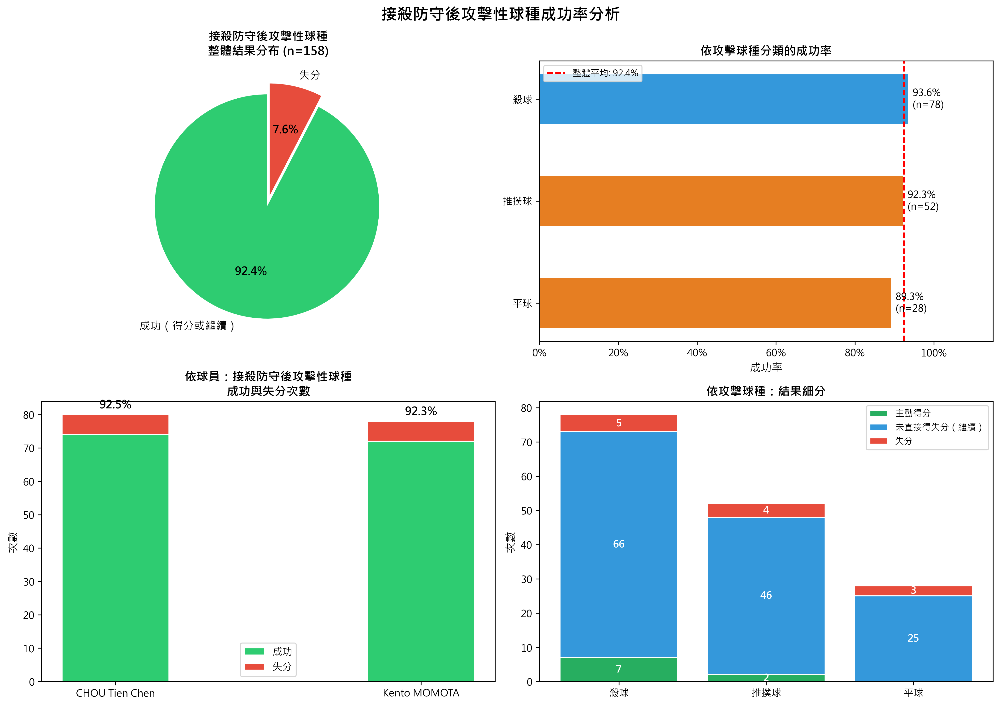

In [ ]:
import numpy as np

# =========================================
# 1. 資料驗證
# =========================================
print(f"資料總列數: {len(df)}")
print(f"球種分布:\n{df['type'].value_counts()}")

# =========================================
# 2. 定義攻擊性球種
# =========================================
# 攻擊性球種：殺球、推撲球、平球
# 點扣不在資料中，推撲球最接近點扣概念
# 進攻性挑球在此資料中難以區分，先不納入挑球（挑球偏防守）
attack_types = ['殺球', '推撲球', '平球']

print(f"\n攻擊性球種定義: {attack_types}")

# =========================================
# 3. 排序並建立前後拍欄位
# =========================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 在完整資料上建立 next 欄位（下一拍，即同 rally 中對手的拍）
g = df_sorted.groupby(['match_id', 'set', 'rally'])

# 下一拍（+1）
df_sorted['next_type'] = g['type'].shift(-1)
df_sorted['next_player'] = g['player'].shift(-1)
df_sorted['next_getpoint_player'] = g['getpoint_player'].shift(-1)
df_sorted['next_rally'] = g['rally'].transform('first')  # 用來確認是否同 rally

# 再下一拍（+2）：接殺防守者自己的下一拍
df_sorted['next2_type'] = g['type'].shift(-2)
df_sorted['next2_player'] = g['player'].shift(-2)
df_sorted['next2_getpoint_player'] = g['getpoint_player'].shift(-2)

# 建立 rally 內 ball_round 最大值，確認邊界
df_sorted['max_ball_round'] = g['ball_round'].transform('max')

print(f"\n建立前後拍欄位完成")

# =========================================
# 4. 找出「接殺防守」列，且下下拍（+2）為攻擊性球種，且同 player
# =========================================
# 條件：
# (a) 當前拍 type == '接殺防守'
# (b) shift(-2) 的 player == 當前 player（確認是同一球員）
# (c) shift(-2) 的 type 是攻擊性球種
# (d) shift(-2) 與當前同一 rally（用 next2_player 非 None 隱含，但需明確檢查）

# 為了確認 shift(-2) 在同一 rally，我們需要檢查 ball_round + 2 <= max_ball_round
# 或是直接用 groupby 建立的 shift 特性（超出 rally 邊界的 shift 值為 NaN）

# 方法：先建立每個位置對應的 rally_id（用 rally_id 欄位，若不存在用自建）
# 已有 rally_id 欄位，可利用
df_sorted['next2_rally_id'] = df_sorted.groupby(['match_id', 'set', 'rally'])['rally_id'].shift(-2)

# 過濾條件
mask_defense = df_sorted['type'] == '接殺防守'
mask_same_player = df_sorted['next2_player'] == df_sorted['player']
mask_attack_type = df_sorted['next2_type'].isin(attack_types)
mask_same_rally = df_sorted['next2_rally_id'] == df_sorted['rally_id']

# 接殺防守後緊接攻擊性球種的資料
defense_to_attack = df_sorted[mask_defense & mask_same_player & mask_attack_type & mask_same_rally].copy()

print(f"\n接殺防守後接著打攻擊性球種的總次數: {len(defense_to_attack)}")

# =========================================
# 5. 判斷成功失敗
# =========================================
# 成功定義：該攻擊拍（+2拍）得分或未直接失分
# 即 next2_getpoint_player != opponent（不是自己輸）
# 換句話說：
# - 得分：next2_getpoint_player == player（自己得分）
# - 繼續（未決）：next2_getpoint_player == NaN（對手繼續回球）
# - 失分：next2_getpoint_player == opponent（自己失分）

# 但 next2_getpoint_player 是自己（+2拍的player）的 opponent
# 注意：+2拍的 player 是當前 player，所以 getpoint_player == +2拍的 opponent = 對手

# 當 next2_getpoint_player == 當前 player → 得分 ✓
# 當 next2_getpoint_player == NaN → 未結束，繼續 ✓（成功）
# 當 next2_getpoint_player == 對手（next2_player 的 opponent）→ 失分 ✗

# 取得對手名稱：使用 opponent 欄位
defense_to_attack['attack_get_point'] = defense_to_attack['next2_getpoint_player']

# 成功：得分 or NaN（繼續）
# 失分：next2_getpoint_player == 當前 player 的對手（即 opponent）
defense_to_attack['is_success'] = (
    defense_to_attack['next2_getpoint_player'].isna() |  # 未結束，繼續
    (defense_to_attack['next2_getpoint_player'] == defense_to_attack['player'])  # 自己得分
)

# 失分：對手得分
defense_to_attack['is_failure'] = (
    defense_to_attack['next2_getpoint_player'] == defense_to_attack['opponent']
)

# 驗證
print(f"\n成功次數（得分或繼續）: {defense_to_attack['is_success'].sum()}")
print(f"失分次數: {defense_to_attack['is_failure'].sum()}")
print(f"總計: {defense_to_attack['is_success'].sum() + defense_to_attack['is_failure'].sum()}")

# =========================================
# 6. 整體統計
# =========================================
total_count = len(defense_to_attack)
success_count = defense_to_attack['is_success'].sum()
failure_count = defense_to_attack['is_failure'].sum()
success_rate = success_count / total_count if total_count > 0 else 0

print("\n" + "="*60)
print("【接殺防守後使用攻擊性球種整體統計】")
print("="*60)
print(f"總次數: {total_count}")
print(f"成功次數: {success_count} ({success_rate:.1%})")
print(f"失分次數: {failure_count} ({failure_count/total_count:.1%})")

# =========================================
# 7. 分球種統計
# =========================================
print("\n" + "="*60)
print("【依攻擊性球種分類統計】")
print("="*60)

# 依攻擊球種（next2_type）分組
attack_stats = defense_to_attack.groupby('next2_type').agg(
    次數=('is_success', 'count'),
    成功次數=('is_success', 'sum'),
    失分次數=('is_failure', 'sum')
).reset_index()
attack_stats.columns = ['攻擊球種', '次數', '成功次數', '失分次數']
attack_stats['成功率'] = attack_stats['成功次數'] / attack_stats['次數']
attack_stats['失分率'] = attack_stats['失分次數'] / attack_stats['次數']
attack_stats = attack_stats.sort_values('次數', ascending=False)

print(attack_stats.to_string(index=False))

# =========================================
# 8. 依球員分類統計
# =========================================
print("\n" + "="*60)
print("【依球員分類統計】")
print("="*60)

player_stats = defense_to_attack.groupby('player').agg(
    次數=('is_success', 'count'),
    成功次數=('is_success', 'sum'),
    失分次數=('is_failure', 'sum')
).reset_index()
player_stats.columns = ['球員', '次數', '成功次數', '失分次數']
player_stats['成功率'] = player_stats['成功次數'] / player_stats['次數']
player_stats = player_stats.sort_values('次數', ascending=False)

print(player_stats.to_string(index=False))

# =========================================
# 9. 依比賽分類統計
# =========================================
match_stats = defense_to_attack.groupby(['match_id', 'player']).agg(
    次數=('is_success', 'count'),
    成功次數=('is_success', 'sum'),
    失分次數=('is_failure', 'sum')
).reset_index()
match_stats['成功率'] = match_stats['成功次數'] / match_stats['次數']

print("\n" + "="*60)
print("【依比賽 & 球員分類統計】")
print("="*60)
print(match_stats.to_string(index=False))

# =========================================
# 10. 視覺化
# =========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('接殺防守後攻擊性球種成功率分析', fontsize=16, fontweight='bold', y=0.98)

# --- 圖1：整體成功/失分分布（圓餅圖）
ax1 = axes[0, 0]
labels = ['成功（得分或繼續）', '失分']
sizes = [success_count, failure_count]
colors = ['#2ecc71', '#e74c3c']
explode = (0.05, 0.05)
wedges, texts, autotexts = ax1.pie(
    sizes, labels=labels, colors=colors, explode=explode,
    autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 11}
)
for autotext in autotexts:
    autotext.set_fontweight('bold')
ax1.set_title(f'接殺防守後攻擊性球種\n整體結果分布 (n={total_count})', fontsize=12, fontweight='bold')

# --- 圖2：依攻擊球種的成功率（水平條形圖）
ax2 = axes[0, 1]
attack_stats_sorted = attack_stats.sort_values('成功率', ascending=True)
bar_colors = ['#3498db' if r >= success_rate else '#e67e22' 
              for r in attack_stats_sorted['成功率']]
bars = ax2.barh(attack_stats_sorted['攻擊球種'], attack_stats_sorted['成功率'],
                color=bar_colors, edgecolor='white', height=0.5)
# 添加整體平均線
ax2.axvline(x=success_rate, color='red', linestyle='--', linewidth=1.5, label=f'整體平均: {success_rate:.1%}')
# 添加數值標籤
for bar, (_, row) in zip(bars, attack_stats_sorted.iterrows()):
    ax2.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
             f"{row['成功率']:.1%}\n(n={int(row['次數'])})", 
             va='center', fontsize=10)
ax2.set_xlim(0, 1.15)
ax2.set_xlabel('成功率', fontsize=11)
ax2.set_title('依攻擊球種分類的成功率', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

# --- 圖3：依球員分類的成功/失分次數（堆疊條形圖）
ax3 = axes[1, 0]
x = np.arange(len(player_stats))
width = 0.35
bars_success = ax3.bar(x, player_stats['成功次數'], width, label='成功', color='#2ecc71', edgecolor='white')
bars_fail = ax3.bar(x, player_stats['失分次數'], width, bottom=player_stats['成功次數'],
                    label='失分', color='#e74c3c', edgecolor='white')
# 添加成功率標籤
for i, (_, row) in enumerate(player_stats.iterrows()):
    ax3.text(i, row['次數'] + 1, f"{row['成功率']:.1%}", 
             ha='center', va='bottom', fontsize=11, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(player_stats['球員'], fontsize=10)
ax3.set_ylabel('次數', fontsize=11)
ax3.set_title('依球員：接殺防守後攻擊性球種\n成功與失分次數', fontsize=12, fontweight='bold')
ax3.legend(fontsize=10)

# --- 圖4：依攻擊球種的次數分布（結果細分）
ax4 = axes[1, 1]
# 重新整理：成功中得分 vs 繼續
defense_to_attack['result_label'] = np.where(
    defense_to_attack['next2_getpoint_player'] == defense_to_attack['player'], '主動得分',
    np.where(defense_to_attack['next2_getpoint_player'].isna(), '未直接得失分（繼續）', '失分')
)

result_by_type = defense_to_attack.groupby(['next2_type', 'result_label']).size().unstack(fill_value=0)
result_by_type = result_by_type.reindex(attack_stats.sort_values('次數', ascending=False)['攻擊球種'].tolist())

# 確保欄位存在
for col in ['主動得分', '未直接得失分（繼續）', '失分']:
    if col not in result_by_type.columns:
        result_by_type[col] = 0

result_colors = {'主動得分': '#27ae60', '未直接得失分（繼續）': '#3498db', '失分': '#e74c3c'}
bottom_vals = np.zeros(len(result_by_type))
for col in ['主動得分', '未直接得失分（繼續）', '失分']:
    vals = result_by_type[col].values
    ax4.bar(result_by_type.index, vals, bottom=bottom_vals,
            label=col, color=result_colors[col], edgecolor='white')
    # 顯示數值（只顯示 > 0 的）
    for j, (v, b) in enumerate(zip(vals, bottom_vals)):
        if v > 0:
            ax4.text(j, b + v/2, str(int(v)), ha='center', va='center',
                     fontsize=10, fontweight='bold', color='white')
    bottom_vals += vals

ax4.set_ylabel('次數', fontsize=11)
ax4.set_title('依攻擊球種：結果細分', fontsize=12, fontweight='bold')
ax4.legend(fontsize=9, loc='upper right')
ax4.set_xticklabels(result_by_type.index, fontsize=10)

plt.tight_layout()

print("\n圖表已生成")
print("\n" + "="*60)
print("【分析摘要】")
print("="*60)
print(f"✅ 接殺防守後攻擊性球種總次數: {total_count}")
print(f"✅ 整體成功率: {success_rate:.1%}")
print(f"   - 主動得分: {(defense_to_attack['result_label']=='主動得分').sum()} 次")
print(f"   - 繼續（未決）: {(defense_to_attack['result_label']=='未直接得失分（繼續）').sum()} 次")
print(f"❌ 失分次數: {failure_count}")
print(f"\n【攻擊球種成功率排行】")
for _, row in attack_stats.sort_values('成功率', ascending=False).iterrows():
    print(f"  {row['攻擊球種']}: {row['成功率']:.1%} ({int(row['成功次數'])}/{int(row['次數'])})")


### 數據洞察
# 接殺防守後反攻統計分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 總次數 | 158 次 |
| 整體成功率 | **92.4%** (146/158) |
| 失分次數 | 12 次 (7.6%) |

---

## 攻擊球種成效

| 球種 | 次數 | 成功率 |
|------|------|--------|
| 殺球 | 78 | **93.6%** ✅ |
| 推撲球 | 52 | 92.3% |
| 平球 | 28 | 89.3% |

---

## 球員比較

| 球員 | 次數 | 成功率 |
|------|------|--------|
| CHOU Tien Chen | 80 | 92.5% |
| Kento MOMOTA | 78 | 92.3% |

兩人幾乎持平，差距可忽略。

---

## 戰術洞察

**1. 被動不等於失分**
接殺防守後立即反攻，成功率高達 92.4%。說明這兩位選手在被動局面下，防守品質足以支撐下一拍的主動出擊。

**2. 殺球是最優先選擇**
接殺防守後選擇殺球（78次，93.6%）是三種攻擊球種中成功率最高的，且使用頻率最高。**被動後若有機會殺球，應優先執行，不要保守選擇平球。**

**3. 平球風險最高**
平球成功率 89.3%，雖仍屬高水準，但相對最低。平球速度快但高度高，對手有機會搶壓，**使用需謹慎選擇時機。**

**4. 主動得分僅 9 次**
146 次成功中，真正直接得分只有 9 次，137 次是「繼續回球」。這意味著接殺防守後的反攻，**主要功能是重新建立平衡局面，而非直接終結球**。教練建議：反攻後需持續保持壓迫，不能期待一拍解決。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都是基於特定的被動情況（如移動距離或接殺防守）來定義被動狀態，而候選程式碼直接使用 '接殺防守' 作為被動情況的唯一代理，這與 Reference Code 2 的邏輯接近，但候選程式碼在統計口徑上存在問題。候選程式碼在判斷成功失敗時，對於 'next2_getpoint_player' 的判斷不夠嚴謹，可能會錯誤地將某些情況判定為成功。此外，候選程式碼的統計口徑不夠清晰，未能正確區分每個 rally 的最終狀態，這可能導致統計結果不準確。




## 題號 77
**問題**: 分析周天成對不同對手攻擊方式差異。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


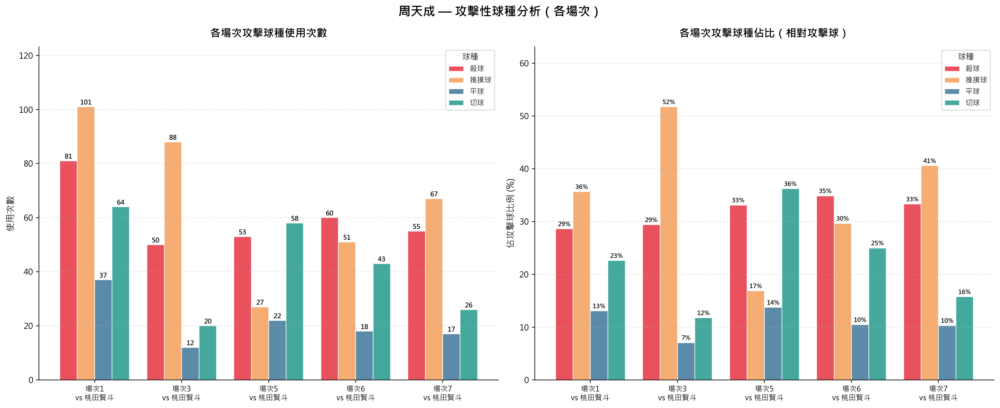

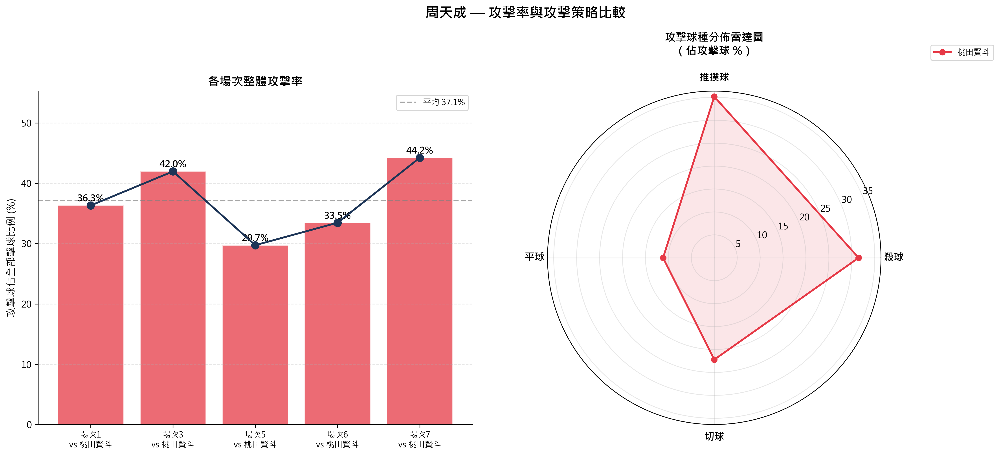

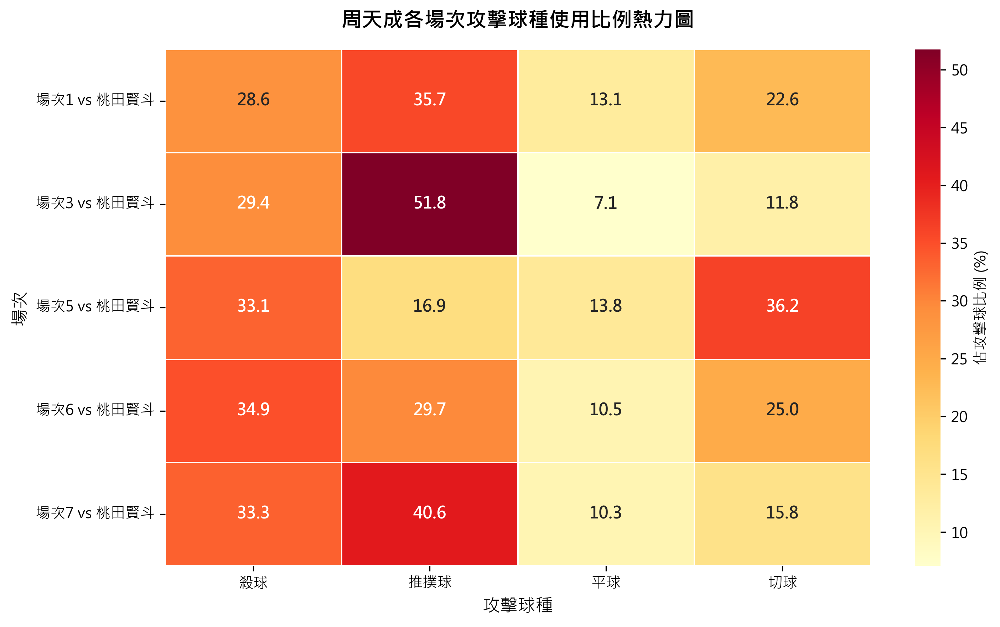

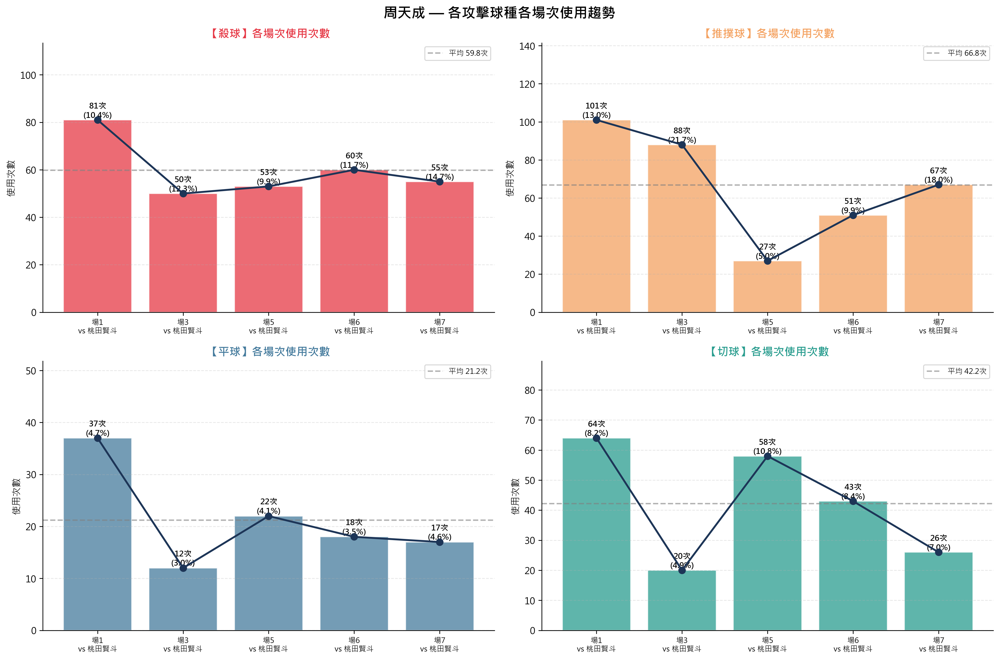

In [ ]:
import numpy as np

# ============================================================
# 基本資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

# 周天成的資料
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"周天成擊球總筆數: {len(chou_df)}")
print(f"周天成對手列表: {chou_df['opponent'].unique()}")
print(f"比賽場次 (match_id): {sorted(chou_df['match_id'].unique())}")

# ============================================================
# 定義攻擊性球種
# ============================================================
attack_type_names = ['殺球', '推撲球', '平球', '切球']
print(f"\n攻擊性球種定義: {attack_type_names}")
print(f"\n各球種總使用次數 (周天成全部):\n{chou_df['type'].value_counts()}")

# ============================================================
# 每場比賽對手對照表
# ============================================================
match_opponent_map = (
    chou_df.groupby('match_id')['opponent']
    .first()
    .reset_index()
    .rename(columns={'opponent': 'opponent_name'})
)
print(f"\n各場比賽對手對照:")
print(match_opponent_map.to_string(index=False))

# ============================================================
# 建立分析用 DataFrame（含對手名稱）
# ============================================================
chou_with_opp = chou_df.merge(match_opponent_map, on='match_id', how='left')

# 每場總擊球數
total_shots_by_match = (
    chou_with_opp
    .groupby(['match_id', 'opponent_name'])
    .size()
    .reset_index(name='total_shots')
)

# 篩選攻擊性球種
chou_attack_df = chou_with_opp[chou_with_opp['type'].isin(attack_type_names)].copy()
print(f"\n周天成攻擊性球種總擊球數: {len(chou_attack_df)}")

# 每場攻擊球總數
total_attack_by_match = (
    chou_attack_df
    .groupby(['match_id', 'opponent_name'])
    .size()
    .reset_index(name='total_attack')
)

# 每場每球種計數
shot_by_match_type = (
    chou_attack_df
    .groupby(['match_id', 'opponent_name', 'type'])
    .size()
    .reset_index(name='count')
)

# 確保所有場次 × 球種組合都存在（補 0）
match_ids = match_opponent_map['match_id'].tolist()
opp_names = match_opponent_map['opponent_name'].tolist()
full_index = pd.MultiIndex.from_tuples(
    [(mid, opp, t) for (mid, opp), t in
     zip(zip(match_ids, opp_names), [t for _ in zip(match_ids, opp_names) for t in attack_type_names])],
    names=['match_id', 'opponent_name', 'type']
)
# 用 cartesian product 正確方式
from itertools import product as iterproduct
full_rows = [
    {'match_id': mid, 'opponent_name': opp, 'type': t}
    for (mid, opp), t in iterproduct(zip(match_ids, opp_names), attack_type_names)
]
full_combo_df = pd.DataFrame(full_rows)

# 合併補零
shot_full = full_combo_df.merge(shot_by_match_type, on=['match_id', 'opponent_name', 'type'], how='left')
shot_full['count'] = shot_full['count'].fillna(0).astype(int)

# 合併總擊球與攻擊球數
shot_full = shot_full.merge(total_shots_by_match, on=['match_id', 'opponent_name'], how='left')
shot_full = shot_full.merge(total_attack_by_match, on=['match_id', 'opponent_name'], how='left')
shot_full['total_attack'] = shot_full['total_attack'].fillna(0).astype(int)

# 計算佔比
shot_full['pct_of_attack'] = np.where(
    shot_full['total_attack'] > 0,
    shot_full['count'] / shot_full['total_attack'] * 100,
    0.0
)
shot_full['pct_of_all'] = np.where(
    shot_full['total_shots'] > 0,
    shot_full['count'] / shot_full['total_shots'] * 100,
    0.0
)

print("\nshot_full 欄位確認:", shot_full.columns.tolist())
print(shot_full.head(10).to_string(index=False))

# ============================================================
# 整合對手維度（同一對手跨場合併）
# ============================================================
total_shots_by_opp = (
    chou_with_opp
    .groupby('opponent_name')
    .size()
    .reset_index(name='total_shots_opp')
)
total_attack_by_opp = (
    chou_attack_df
    .groupby('opponent_name')
    .size()
    .reset_index(name='total_attack_opp')
)
shot_by_opp_type = (
    chou_attack_df
    .groupby(['opponent_name', 'type'])
    .size()
    .reset_index(name='count_opp')
)

opp_list_all = total_shots_by_opp['opponent_name'].tolist()
full_opp_rows = [
    {'opponent_name': opp, 'type': t}
    for opp, t in iterproduct(opp_list_all, attack_type_names)
]
opp_combo_df = pd.DataFrame(full_opp_rows)
opp_pct = opp_combo_df.merge(shot_by_opp_type, on=['opponent_name', 'type'], how='left')
opp_pct['count_opp'] = opp_pct['count_opp'].fillna(0).astype(int)
opp_pct = opp_pct.merge(total_shots_by_opp, on='opponent_name', how='left')
opp_pct = opp_pct.merge(total_attack_by_opp, on='opponent_name', how='left')
opp_pct['pct_attack'] = np.where(
    opp_pct['total_attack_opp'] > 0,
    opp_pct['count_opp'] / opp_pct['total_attack_opp'] * 100,
    0.0
)
opp_pct['pct_all_opp'] = np.where(
    opp_pct['total_shots_opp'] > 0,
    opp_pct['count_opp'] / opp_pct['total_shots_opp'] * 100,
    0.0
)

# ============================================================
# 文字輸出：各場詳細統計
# ============================================================
print("\n" + "="*70)
print("周天成 攻擊性球種詳細統計 (各場比賽)")
print("="*70)

atk_rate_rows = []
for _, row in match_opponent_map.iterrows():
    mid = row['match_id']
    opp = row['opponent_name']
    match_data = shot_full[shot_full['match_id'] == mid].sort_values('count', ascending=False)
    total_atk = total_attack_by_match[total_attack_by_match['match_id'] == mid]['total_attack'].values
    total_all = total_shots_by_match[total_shots_by_match['match_id'] == mid]['total_shots'].values
    total_atk = int(total_atk[0]) if len(total_atk) > 0 else 0
    total_all = int(total_all[0]) if len(total_all) > 0 else 0
    atk_rate = total_atk / total_all * 100 if total_all > 0 else 0.0

    atk_rate_rows.append({
        'match_id': mid,
        'opponent_name': opp,
        'total_shots': total_all,
        'total_attack': total_atk,
        'atk_rate': atk_rate
    })

    opp_short = opp.replace('Kento MOMOTA', '桃田賢斗')
    print(f"\n▶ Match {int(mid)} vs {opp_short}")
    print(f"  總擊球數: {total_all}, 攻擊性球種總數: {total_atk} ({atk_rate:.1f}%)")
    print(f"  {'球種':<8} {'次數':>6} {'佔攻擊球%':>10} {'佔全部球%':>10}")
    print(f"  {'-'*40}")
    for _, r in match_data.iterrows():
        print(f"  {r['type']:<8} {int(r['count']):>6} {r['pct_of_attack']:>9.1f}% {r['pct_of_all']:>9.1f}%")

atk_rate_df = pd.DataFrame(atk_rate_rows)

print("\n" + "="*70)
print("周天成 攻擊性球種統計 (依對手彙整)")
print("="*70)
for opp_name in opp_list_all:
    data = opp_pct[opp_pct['opponent_name'] == opp_name].sort_values('count_opp', ascending=False)
    total_atk = total_attack_by_opp[total_attack_by_opp['opponent_name'] == opp_name]['total_attack_opp'].values[0]
    total_all = total_shots_by_opp[total_shots_by_opp['opponent_name'] == opp_name]['total_shots_opp'].values[0]
    opp_short = opp_name.replace('Kento MOMOTA', '桃田賢斗')
    print(f"\n▶ vs {opp_short}")
    print(f"  總擊球數: {total_all}, 攻擊球總數: {total_atk} ({total_atk/total_all*100:.1f}%)")
    print(f"  {'球種':<8} {'次數':>6} {'佔攻擊球%':>10} {'佔全部球%':>10}")
    print(f"  {'-'*40}")
    for _, r in data.iterrows():
        print(f"  {r['type']:<8} {int(r['count_opp']):>6} {r['pct_attack']:>9.1f}% {r['pct_all_opp']:>9.1f}%")

# ============================================================
# 視覺化準備：Pivot Table
# ============================================================
pivot_count = shot_full.pivot_table(
    index='match_id', columns='type', values='count', fill_value=0
)[attack_type_names]

pivot_pct_atk = shot_full.pivot_table(
    index='match_id', columns='type', values='pct_of_attack', fill_value=0
)[attack_type_names]

pivot_pct_all = shot_full.pivot_table(
    index='match_id', columns='type', values='pct_of_all', fill_value=0
)[attack_type_names]

# X 軸標籤
x_labels = []
for mid in pivot_count.index:
    opp = match_opponent_map[match_opponent_map['match_id'] == mid]['opponent_name'].values[0]
    opp_short = opp.replace('Kento MOMOTA', '桃田賢斗')
    x_labels.append(f"場次{int(mid)}\nvs {opp_short}")

colors = {
    '殺球':   '#E63946',
    '推撲球': '#F4A261',
    '平球':   '#457B9D',
    '切球':   '#2A9D8F',
}

# ============================================================
# Figure 1: 各場次分組長條圖（次數 + 佔攻擊球%）
# ============================================================
fig1, axes1 = plt.subplots(1, 2, figsize=(17, 7))
bar_width = 0.2
n_types = len(attack_type_names)
x = np.arange(len(pivot_count))

# 左：次數
ax1 = axes1[0]
for i, atype in enumerate(attack_type_names):
    offset = (i - n_types / 2 + 0.5) * bar_width
    bars = ax1.bar(x + offset, pivot_count[atype], bar_width,
                   label=atype, color=colors[atype], alpha=0.88,
                   edgecolor='white', linewidth=0.8)
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.2,
                     f'{int(h)}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(x_labels, fontsize=9)
ax1.set_ylabel('使用次數', fontsize=11)
ax1.set_title('各場次攻擊球種使用次數', fontsize=13, fontweight='bold', pad=12)
ax1.legend(title='球種', loc='upper right', fontsize=9)
ax1.set_ylim(0, pivot_count.values.max() * 1.22)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# 右：佔攻擊球%
ax2 = axes1[1]
for i, atype in enumerate(attack_type_names):
    offset = (i - n_types / 2 + 0.5) * bar_width
    bars = ax2.bar(x + offset, pivot_pct_atk[atype], bar_width,
                   label=atype, color=colors[atype], alpha=0.88,
                   edgecolor='white', linewidth=0.8)
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.2,
                     f'{h:.0f}%', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

ax2.set_xticks(x)
ax2.set_xticklabels(x_labels, fontsize=9)
ax2.set_ylabel('佔攻擊球比例 (%)', fontsize=11)
ax2.set_title('各場次攻擊球種佔比（相對攻擊球）', fontsize=13, fontweight='bold', pad=12)
ax2.legend(title='球種', loc='upper right', fontsize=9)
ax2.set_ylim(0, pivot_pct_atk.values.max() * 1.22)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.suptitle('周天成 — 攻擊性球種分析（各場次）', fontsize=15, fontweight='bold')
plt.tight_layout()
print("\n[圖1] 各場次攻擊球種使用次數與佔比")

# ============================================================
# Figure 2: 攻擊率長條圖 + 雷達圖
# ============================================================
fig2 = plt.figure(figsize=(16, 7))

# 左：攻擊率長條
ax3 = fig2.add_subplot(121)
atk_sorted = atk_rate_df.sort_values('match_id')
x_rate = np.arange(len(atk_sorted))
xlabels_sorted = []
for _, row in atk_sorted.iterrows():
    opp_short = row['opponent_name'].replace('Kento MOMOTA', '桃田賢斗')
    xlabels_sorted.append(f"場次{int(row['match_id'])}\nvs {opp_short}")

bars3 = ax3.bar(x_rate, atk_sorted['atk_rate'],
                color='#E63946', alpha=0.75, edgecolor='white', linewidth=1)
ax3.plot(x_rate, atk_sorted['atk_rate'], 'o-', color='#1d3557',
         markersize=8, linewidth=2, zorder=5)
for bar, rate in zip(bars3, atk_sorted['atk_rate']):
    ax3.text(bar.get_x() + bar.get_width() / 2, rate + 0.3,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax3.set_xticks(x_rate)
ax3.set_xticklabels(xlabels_sorted, fontsize=9)
ax3.set_ylabel('攻擊球佔全部擊球比例 (%)', fontsize=11)
ax3.set_title('各場次整體攻擊率', fontsize=13, fontweight='bold')
ax3.set_ylim(0, atk_sorted['atk_rate'].max() * 1.25)
mean_rate = atk_sorted['atk_rate'].mean()
ax3.axhline(mean_rate, color='gray', linestyle='--', alpha=0.7,
            label=f'平均 {mean_rate:.1f}%')
ax3.legend(fontsize=9)
ax3.grid(axis='y', alpha=0.3, linestyle='--')
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# 右：雷達圖（按對手彙整）
ax4 = fig2.add_subplot(122, projection='polar')
N = len(attack_type_names)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

radar_colors = ['#E63946', '#457B9D', '#2A9D8F', '#F4A261']
for idx, opp_name in enumerate(opp_list_all):
    opp_data = opp_pct[opp_pct['opponent_name'] == opp_name]
    values = []
    for cat in attack_type_names:
        v = opp_data[opp_data['type'] == cat]['pct_attack'].values
        values.append(float(v[0]) if len(v) > 0 else 0.0)
    values += values[:1]
    c = radar_colors[idx % len(radar_colors)]
    opp_short = opp_name.replace('Kento MOMOTA', '桃田賢斗')
    ax4.plot(angles, values, 'o-', linewidth=2, color=c, label=opp_short)
    ax4.fill(angles, values, alpha=0.12, color=c)

ax4.set_xticks(angles[:-1])
ax4.set_xticklabels(attack_type_names, fontsize=11, fontweight='bold')
ax4.set_title('攻擊球種分佈雷達圖\n（佔攻擊球 %）', fontsize=12, fontweight='bold', pad=20)
ax4.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=9)
ax4.grid(True, alpha=0.3)

plt.suptitle('周天成 — 攻擊率與攻擊策略比較', fontsize=15, fontweight='bold')
plt.tight_layout()
print("[圖2] 攻擊率與雷達圖")

# ============================================================
# Figure 3: 熱力圖（各場次 × 球種 佔攻擊球%）
# ============================================================
fig3, ax5 = plt.subplots(figsize=(10, 6))

heatmap_data = pivot_pct_atk.copy()
y_labels_heatmap = []
for mid in heatmap_data.index:
    opp = match_opponent_map[match_opponent_map['match_id'] == mid]['opponent_name'].values[0]
    opp_short = opp.replace('Kento MOMOTA', '桃田賢斗')
    y_labels_heatmap.append(f"場次{int(mid)} vs {opp_short}")

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='white',
    yticklabels=y_labels_heatmap,
    ax=ax5,
    cbar_kws={'label': '佔攻擊球比例 (%)'},
    annot_kws={'size': 11, 'weight': 'bold'}
)
ax5.set_title('周天成各場次攻擊球種使用比例熱力圖', fontsize=14, fontweight='bold', pad=15)
ax5.set_xlabel('攻擊球種', fontsize=12)
ax5.set_ylabel('場次', fontsize=12)
ax5.tick_params(axis='x', rotation=0)
ax5.tick_params(axis='y', rotation=0)
plt.tight_layout()
print("[圖3] 攻擊球種熱力圖")

# ============================================================
# Figure 4: 各球種跨場次趨勢（次數 + 佔全部擊球%）
# ============================================================
fig4, axes4 = plt.subplots(2, 2, figsize=(15, 10))
axes4 = axes4.flatten()

for idx, atype in enumerate(attack_type_names):
    ax = axes4[idx]
    type_data = shot_full[shot_full['type'] == atype].sort_values('match_id').copy()

    x_pos = np.arange(len(type_data))
    x_lab = []
    for _, row in type_data.iterrows():
        opp_short = row['opponent_name'].replace('Kento MOMOTA', '桃田賢斗')
        x_lab.append(f"場{int(row['match_id'])}\nvs {opp_short}")

    c = colors[atype]
    bars = ax.bar(x_pos, type_data['count'], color=c, alpha=0.75,
                  edgecolor='white', linewidth=1)
    ax.plot(x_pos, type_data['count'], 'o-', color='#1d3557',
            markersize=7, linewidth=2, zorder=5)

    for i, (bar, (_, row)) in enumerate(zip(bars, type_data.iterrows())):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.1,
                f"{int(h)}次\n({row['pct_of_all']:.1f}%)",
                ha='center', va='bottom', fontsize=8.5, fontweight='bold')

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_lab, fontsize=8)
    ax.set_ylabel('使用次數', fontsize=10)
    ax.set_title(f'【{atype}】各場次使用次數', fontsize=12, fontweight='bold', color=c)
    ax.set_ylim(0, max(type_data['count'].max() * 1.4, 3))
    mean_cnt = type_data['count'].mean()
    ax.axhline(mean_cnt, color='gray', linestyle='--', alpha=0.6,
               label=f'平均 {mean_cnt:.1f}次')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('周天成 — 各攻擊球種各場次使用趨勢', fontsize=15, fontweight='bold')
plt.tight_layout()
print("[圖4] 各球種場次趨勢圖")

# ============================================================
# 最終摘要輸出
# ============================================================
print("\n" + "="*70)
print("📊 核心摘要：周天成攻擊策略分析")
print("="*70)
print(f"\n分析球種: {attack_type_names}")

print(f"\n【整體攻擊率統計（各場次）】")
print(f"{'場次':>4} {'對手':<15} {'總擊球':>8} {'攻擊球':>8} {'攻擊率':>8}")
print("-" * 50)
for _, row in atk_rate_df.sort_values('match_id').iterrows():
    opp_short = row['opponent_name'].replace('Kento MOMOTA', '桃田賢斗')
    print(f"{int(row['match_id']):>4} {opp_short:<15} {int(row['total_shots']):>8} "
          f"{int(row['total_attack']):>8} {row['atk_rate']:>7.1f}%")

print(f"\n【攻擊球種偏好（依對手彙整，佔攻擊球%）】")
print(f"{'對手':<15} {'球種':<8} {'次數':>6} {'佔攻擊球%':>10} {'佔全部球%':>10}")
print("-" * 55)
for opp_name in opp_list_all:
    data = opp_pct[opp_pct['opponent_name'] == opp_name].sort_values('pct_attack', ascending=False)
    opp_short = opp_name.replace('Kento MOMOTA', '桃田賢斗')
    for _, r in data.iterrows():
        print(f"{opp_short:<15} {r['type']:<8} {int(r['count_opp']):>6} "
              f"{r['pct_attack']:>9.1f}% {r['pct_all_opp']:>9.1f}%")
    print()


### 數據洞察
# 周天成 vs 桃田賢斗｜攻擊策略分析

> 資料涵蓋5場比賽，對手均為桃田賢斗，共950次攻擊性擊球。

---

## 整體攻擊偏好

| 球種 | 次數 | 佔攻擊球% |
|------|------|-----------|
| 推撲球 | 334 | **35.2%** |
| 殺球 | 299 | **31.5%** |
| 切球 | 211 | 22.2% |
| 平球 | 106 | 11.2% |

**推撲球是周天成對桃田的第一攻擊武器**，顯示他傾向以快速平抽壓制桃田的後場防守，而非單純依賴殺球。

---

## 各場次攻擊率與策略變化

| 場次 | 攻擊率 | 主導球種 |
|------|--------|----------|
| 場1 | 36.3% | 推撲球(35.7%) |
| 場3 | 42.0% | 推撲球(51.8%) ⬆️ |
| 場5 | **29.7%** ⬇️ | 切球(36.2%) |
| 場6 | 33.5% | 殺球(34.9%) |
| 場7 | **44.2%** ⬆️ | 推撲球(40.6%) |

---

## 三大戰術洞察

**① 推撲球是核心武器，但並非每場都奏效**
- 場3推撲球高達51.8%，攻擊率42%，顯示該場策略奏效
- 場5推撲球驟降至16.9%，改以切球主導——這是明顯的戰術調整，可能是對手針對推撲球做出了有效應對

**② 場5是策略異常場**
- 攻擊率最低（29.7%），切球反升至第一（36.2%）
- 這場周天成明顯降低攻擊強度，改以切球製造落點壓力，打法趨於保守試探

**③ 場7是攻擊最積極的一場**
- 攻擊率44.2%為五場最高，推撲球40.6%、殺球33.3%雙主導
- 平均攻擊率37.1%，場7明顯高於均值——這通常出現在決勝局或需要主動搶分的情境

---

## 教練結論

周天成對桃田的攻擊核心是**「推撲球＋殺球」雙軸壓制**，但他會根據比賽走勢靈活調整：**推撲球受壓時切換切球試探，需要搶分時拉高整體攻擊率**。切球在五場中始終保持一定比例（11.8%～36.2%），是他維持攻擊多樣性的緩衝球種。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它分析了周天成對不同對手的攻擊方式差異，並且正確地篩選了周天成的攻擊性球種，計算了每場比賽和每個對手的攻擊球種使用次數和比例。程式碼使用了合理的分組層級和統計口徑，並且最終輸出目標與 Reference Code 1 一致。




## 題號 78 (*)
**問題**: 計算周天成「放短球後被撲殺」的比例，以及是否在比賽後段上升。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


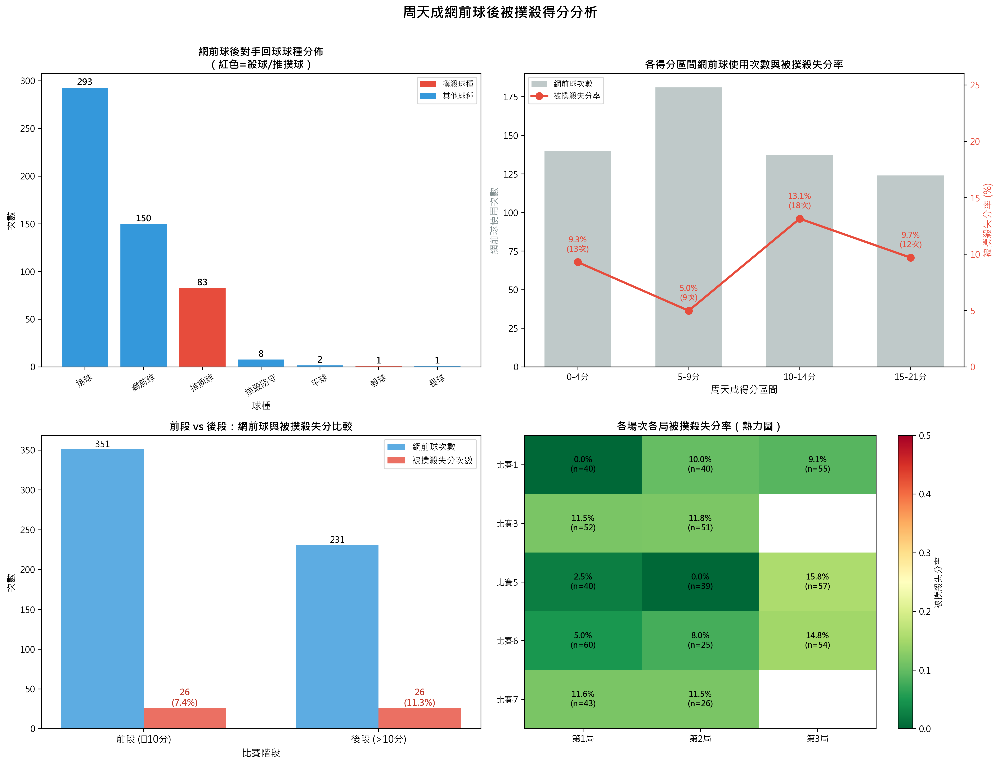

In [ ]:
import numpy as np

# ============================================================
# 前置驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 1: 建立前後拍關聯 (在完整資料上先建立 shift 欄位，再篩選)
# 使用 groupby(['match_id', 'set', 'rally']).shift(-1) 取得「下一拍」資訊
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立下一拍資訊 (shift(-1) 在同一 rally 內)
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['next_player']        = grp['player'].shift(-1)
df_sorted['next_type']          = grp['type'].shift(-1)
df_sorted['next_getpoint']      = grp['getpoint_player'].shift(-1)
df_sorted['next_ball_round']    = grp['ball_round'].shift(-1)

# 同時取得該回合最終得分者（用 transform last 方式）
df_sorted['rally_getpoint'] = grp['getpoint_player'].transform('last')

# ============================================================
# Step 2: 篩選「周天成打網前球」的所有拍次
# ============================================================
chou = 'CHOU Tien Chen'
momota = 'Kento MOMOTA'

# 撲殺球種定義：殺球 + 推撲球
smash_types = ['殺球', '推撲球']

mask_chou_net = (df_sorted['player'] == chou) & (df_sorted['type'] == '網前球')
df_chou_net = df_sorted[mask_chou_net].copy()

print(f"\n周天成打網前球的總拍次: {len(df_chou_net)}")

# ============================================================
# Step 3: 判斷「下一拍是否為同一回合」已由 groupby shift 保證
# 但需確保 next_player 確實是對手（對手在下一拍應是 Momota）
# ============================================================
# 確認下一拍玩家是對手
valid_next = df_chou_net['next_player'] == momota

# 下一拍是「殺球或推撲球」
next_is_smash = df_chou_net['next_type'].isin(smash_types)

# 該回合得分者是對手（Momota）= 周天成因此失分
rally_momota_wins = df_chou_net['rally_getpoint'] == momota

# 組合條件：下一拍對手撲殺 + 對手得分
mask_smashed_and_lost = valid_next & next_is_smash & rally_momota_wins

df_chou_net['smashed_and_lost'] = mask_smashed_and_lost

print(f"其中對手緊接著撲殺且得分的拍次: {mask_smashed_and_lost.sum()}")
print(f"整體「放短球後被撲殺得分」比例: {mask_smashed_and_lost.sum() / len(df_chou_net):.2%}")

# 也計算「下一拍被撲殺但不一定得分」的次數
mask_smashed_only = valid_next & next_is_smash
print(f"下一拍被撲殺（不論得分）拍次: {mask_smashed_only.sum()}")

# ============================================================
# Step 4: 建立比賽進程分析 — 使用「周天成當前比分」決定得分區間
# 以 CHOU Tien Chen_score 作為進程指標
# 區間劃分：0-4 / 5-9 / 10-14 / 15-21 (前段/中段/後段)
# ============================================================
# 取得周天成當時的比分
df_chou_net['chou_score'] = df_chou_net['CHOU Tien Chen_score']

# 定義分段
bins   = [-1, 4, 9, 14, 21]
labels = ['0-4分', '5-9分', '10-14分', '15-21分']
df_chou_net['score_stage'] = pd.cut(
    df_chou_net['chou_score'],
    bins=bins,
    labels=labels
)

# 每個得分區間的統計
stage_stats = df_chou_net.groupby('score_stage', observed=True).agg(
    net_shot_count   = ('smashed_and_lost', 'count'),
    smash_lost_count = ('smashed_and_lost', 'sum')
).reset_index()

stage_stats['smash_lost_rate'] = stage_stats['smash_lost_count'] / stage_stats['net_shot_count']

print("\n===== 各得分區間分析（周天成當前分數）=====")
print(stage_stats.to_string(index=False))

# ============================================================
# Step 5: 依 match_id + set 進一步做前後段分析
# 前段 = 該局 <= 10分，後段 = 該局 > 10分（以周天成分數為基準）
# ============================================================
df_chou_net['game_stage'] = np.where(df_chou_net['chou_score'] <= 10, '前段 (≤10分)', '後段 (>10分)')

stage2_stats = df_chou_net.groupby('game_stage').agg(
    net_shot_count   = ('smashed_and_lost', 'count'),
    smash_lost_count = ('smashed_and_lost', 'sum')
).reset_index()
stage2_stats['smash_lost_rate'] = stage2_stats['smash_lost_count'] / stage2_stats['net_shot_count']

print("\n===== 前後段分析（≤10 vs >10）=====")
print(stage2_stats.to_string(index=False))

# ============================================================
# Step 6: 依每局 (match_id + set) 逐局分析
# ============================================================
set_stats = df_chou_net.groupby(['match_id', 'set']).agg(
    net_shot_count   = ('smashed_and_lost', 'count'),
    smash_lost_count = ('smashed_and_lost', 'sum')
).reset_index()
set_stats['smash_lost_rate'] = set_stats['smash_lost_count'] / set_stats['net_shot_count']
set_stats['match_set_label'] = 'M' + set_stats['match_id'].astype(int).astype(str) + '-S' + set_stats['set'].astype(str)

print("\n===== 各場次各局分析 =====")
print(set_stats[['match_set_label', 'net_shot_count', 'smash_lost_count', 'smash_lost_rate']].to_string(index=False))

# ============================================================
# Step 7: 打印下一拍球種分佈（了解網前球後對手的回球選擇）
# ============================================================
next_type_dist = df_chou_net[valid_next].groupby('next_type').size().sort_values(ascending=False)
print("\n===== 周天成打網前球後，對手下一拍球種分佈 =====")
print(next_type_dist)

# ============================================================
# Step 8: 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("周天成網前球後被撲殺得分分析", fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 整體網前球後對手回球球種（長條圖）---
ax1 = axes[0, 0]
next_type_dist_plot = df_chou_net[valid_next]['next_type'].value_counts()
colors_bar = ['#e74c3c' if t in smash_types else '#3498db' for t in next_type_dist_plot.index]
bars = ax1.bar(next_type_dist_plot.index, next_type_dist_plot.values, color=colors_bar, edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, next_type_dist_plot.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(val),
             ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_title("網前球後對手回球球種分佈\n（紅色=殺球/推撲球）", fontsize=12, fontweight='bold')
ax1.set_xlabel("球種", fontsize=11)
ax1.set_ylabel("次數", fontsize=11)
ax1.tick_params(axis='x', rotation=30)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#e74c3c', label='撲殺球種'),
                   Patch(facecolor='#3498db', label='其他球種')]
ax1.legend(handles=legend_elements, fontsize=9)

# --- 圖2: 得分區間（細分）趨勢折線圖 ---
ax2 = axes[0, 1]
valid_stage = stage_stats[stage_stats['net_shot_count'] > 0]
x_pos = range(len(valid_stage))
bar_width = 0.6
bars2 = ax2.bar(x_pos, valid_stage['net_shot_count'], color='#95a5a6',
                alpha=0.6, width=bar_width, label='網前球次數')
ax2_twin = ax2.twinx()
ax2_twin.plot(list(x_pos), valid_stage['smash_lost_rate'] * 100,
              color='#e74c3c', marker='o', linewidth=2.5, markersize=8, label='被撲殺失分率')
for i, (rate, cnt) in enumerate(zip(valid_stage['smash_lost_rate'], valid_stage['smash_lost_count'])):
    ax2_twin.annotate(f"{rate:.1%}\n({cnt}次)",
                      xy=(i, rate * 100),
                      xytext=(0, 12), textcoords='offset points',
                      ha='center', fontsize=9, color='#e74c3c', fontweight='bold')
ax2.set_xticks(list(x_pos))
ax2.set_xticklabels(valid_stage['score_stage'].astype(str), fontsize=10)
ax2.set_xlabel("周天成得分區間", fontsize=11)
ax2.set_ylabel("網前球使用次數", fontsize=11, color='#7f8c8d')
ax2_twin.set_ylabel("被撲殺失分率 (%)", fontsize=11, color='#e74c3c')
ax2_twin.tick_params(axis='y', labelcolor='#e74c3c')
ax2_twin.set_ylim(0, max(valid_stage['smash_lost_rate'] * 100) * 1.6 + 5)
ax2.set_title("各得分區間網前球使用次數與被撲殺失分率", fontsize=12, fontweight='bold')
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='upper left')

# --- 圖3: 前後段比較（分組長條圖）---
ax3 = axes[1, 0]
stage_labels = stage2_stats['game_stage'].tolist()
x = np.arange(len(stage_labels))
width = 0.35
bars3a = ax3.bar(x - width/2, stage2_stats['net_shot_count'], width,
                  label='網前球次數', color='#3498db', alpha=0.8)
bars3b = ax3.bar(x + width/2, stage2_stats['smash_lost_count'], width,
                  label='被撲殺失分次數', color='#e74c3c', alpha=0.8)
for bar, val in zip(bars3a, stage2_stats['net_shot_count']):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(int(val)),
             ha='center', va='bottom', fontsize=10)
for bar, val, rate in zip(bars3b, stage2_stats['smash_lost_count'], stage2_stats['smash_lost_rate']):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f"{int(val)}\n({rate:.1%})", ha='center', va='bottom', fontsize=10, color='#c0392b', fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(stage_labels, fontsize=11)
ax3.set_xlabel("比賽階段", fontsize=11)
ax3.set_ylabel("次數", fontsize=11)
ax3.set_title("前段 vs 後段：網前球與被撲殺失分比較", fontsize=12, fontweight='bold')
ax3.legend(fontsize=10)

# --- 圖4: 各場次各局被撲殺失分率（熱力圖風格）---
ax4 = axes[1, 1]
# 建立 pivot table: match_id x set
pivot_rate = set_stats.pivot(index='match_id', columns='set', values='smash_lost_rate').fillna(np.nan)
pivot_count = set_stats.pivot(index='match_id', columns='set', values='net_shot_count').fillna(0)

# 繪製熱力圖
im = ax4.imshow(pivot_rate.values, cmap='RdYlGn_r', aspect='auto',
                vmin=0, vmax=0.5)
plt.colorbar(im, ax=ax4, label='被撲殺失分率')
ax4.set_xticks(range(pivot_rate.shape[1]))
ax4.set_xticklabels([f'第{s}局' for s in pivot_rate.columns], fontsize=10)
ax4.set_yticks(range(pivot_rate.shape[0]))
ax4.set_yticks(range(len(pivot_rate.index)))
ax4.set_yticklabels([f'比賽{int(m)}' for m in pivot_rate.index], fontsize=10)

# 在格子內標示數值
for i in range(pivot_rate.shape[0]):
    for j in range(pivot_rate.shape[1]):
        val = pivot_rate.values[i, j]
        cnt = int(pivot_count.values[i, j])
        if not np.isnan(val):
            ax4.text(j, i, f"{val:.1%}\n(n={cnt})",
                     ha='center', va='center', fontsize=9, fontweight='bold',
                     color='black')

ax4.set_title("各場次各局被撲殺失分率（熱力圖）", fontsize=12, fontweight='bold')

plt.tight_layout()
print("\n[圖表已生成]")

# ============================================================
# Step 9: 補充 — 更細緻的每5分區間分析
# ============================================================
bins_5   = [-1, 4, 9, 14, 19, 21]
labels_5 = ['0-4', '5-9', '10-14', '15-19', '20-21']
df_chou_net['score_stage_5'] = pd.cut(
    df_chou_net['chou_score'],
    bins=bins_5,
    labels=labels_5
)
stage5_stats = df_chou_net.groupby('score_stage_5', observed=True).agg(
    net_shot_count   = ('smashed_and_lost', 'count'),
    smash_lost_count = ('smashed_and_lost', 'sum')
).reset_index()
stage5_stats['smash_lost_rate'] = stage5_stats['smash_lost_count'] / stage5_stats['net_shot_count']

print("\n===== 每5分區間詳細分析 =====")
print(stage5_stats.to_string(index=False))

# ============================================================
# Step 10: 趨勢判斷
# ============================================================
print("\n===== 趨勢判斷 =====")
front_rate = stage2_stats[stage2_stats['game_stage'] == '前段 (≤10分)']['smash_lost_rate'].values
back_rate  = stage2_stats[stage2_stats['game_stage'] == '後段 (>10分)']['smash_lost_rate'].values
if len(front_rate) > 0 and len(back_rate) > 0:
    diff = back_rate[0] - front_rate[0]
    direction = "上升" if diff > 0 else "下降"
    print(f"前段被撲殺失分率: {front_rate[0]:.2%}")
    print(f"後段被撲殺失分率: {back_rate[0]:.2%}")
    print(f"差異: {diff:+.2%} → 後段比前段{direction}")
    if abs(diff) < 0.02:
        print("→ 趨勢不明顯（差異 < 2%）")
    elif diff > 0:
        print("→ 比賽後段周天成網前球被撲殺失分的風險有所增加")
    else:
        print("→ 比賽後段周天成網前球被撲殺失分的風險有所降低")


### 數據洞察
# 周天成放短球後被撲殺失分分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 總放短球次數 | 582拍 |
| 被撲殺得分次數 | 52次 |
| **整體被撲殺失分率** | **8.93%** |
| 下一拍被撲殺（不論得分） | 84次 |

---

## 得分區間趨勢

| 得分區間 | 放短球次數 | 被撲殺失分 | 失分率 |
|----------|-----------|-----------|--------|
| 0–4分 | 140 | 13 | 9.3% |
| 5–9分 | 181 | 9 | **5.0%** ⬇️ 最低 |
| 10–14分 | 137 | 18 | **13.1%** ⬆️ 最高 |
| 15–21分 | 124 | 12 | 9.7% |

> **10–14分區間風險最高**，這通常是每局的關鍵分段，對手在此時主動攻擊意願明顯提升。

---

## 前後段比較

| 比賽階段 | 放短球次數 | 被撲殺失分率 |
|----------|-----------|-------------|
| 前段（≤10分） | 351 | 7.4% |
| 後段（>10分） | 231 | **11.3%** |
| **差異** | — | **+3.85%** ⬆️ |

**後段風險明顯上升**，差距近4個百分點。

---

## 各場次各局觀察

- **M5-S3（15.8%）、M6-S3（14.8%）** 是風險最高的局次，且均為決勝局
- **M1-S1（0%）、M5-S2（0%）** 完全未被撲殺得分，顯示狀態差異極大

---

## 對手回球球種分佈

周天成放短球後，對手最常見回應：

1. **挑球** 293次（50.3%）→ 對手選擇拉高防守
2. **網前球** 150次（25.8%）→ 網前對抗
3. **推撲球** 83次（14.3%）→ 直接威脅

---

## 戰術建議

**① 後段慎用放短球**
後段失分率11.3%，對手體力雖下降但攻擊判斷更果決，放短球的容錯率降低。

**② 10–14分區間需調整落點**
此區間被撲殺率最高，建議放短球落點更貼近網帶兩側邊線，壓縮對手推撲角度。

**③ 83次推撲球是直接威脅來源**
推撲球速度快、角度刁，放短球品質不足時對手即刻轉守為攻，**球質是關鍵，而非使用頻率**。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都在計算周天成放短球後被撲殺的比例，並檢查是否在比賽後段上升。Reference Code 1 定義了放短球後被撲殺為 '推撲球'，而 Reference Code 2 定義為 '殺球'。候選程式碼在 Step 3 中，將 '殺球' 和 '推撲球' 都視為撲殺球種，但在後續分析中，並未正確區分這兩者的影響。此外，候選程式碼在 Step 4 和 Step 5 中，使用了比分來劃分比賽階段，這與 Reference Code 中使用的回合數劃分方式不同，且未能有效回答題目要求的比賽後段上升趨勢分析。




## 題號 79
**問題**: 計算對手挑球過短時，周天成球種的選擇統計。
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


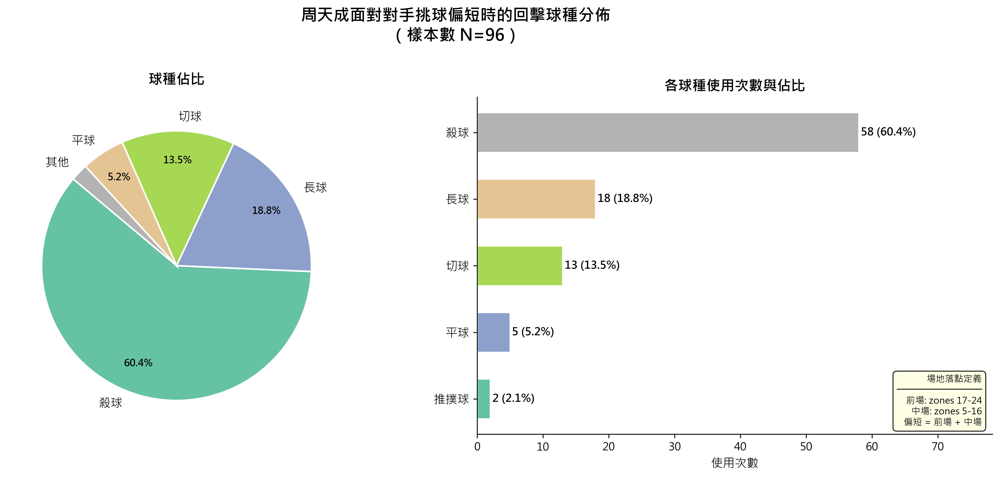

In [ ]:
import numpy as np

# ============================================================
# 數據驗證
# ============================================================
print(f"總資料列數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")
print(f"球種列表: {df['type'].unique()}")

# ============================================================
# 場地區域定義
# ============================================================
FRONT_COURT = [17, 18, 19, 20, 21, 22, 23, 24]  # 前場
MID_COURT   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]  # 中場
SHORT_ZONES = FRONT_COURT + MID_COURT  # 偏短落點（前場 + 中場）

print(f"\n落點「偏短」定義（前場＋中場）: zones {sorted(SHORT_ZONES)}")

# ============================================================
# 確保資料已排序（match_id, set, rally, ball_round）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ============================================================
# 建立下一拍的資訊（在完整資料上，groupby 防止跨 rally 污染）
# ============================================================
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 下一拍的球員、球種、回合標識（用來驗證同 rally）
df_sorted['next_player']   = grp['player'].shift(-1)
df_sorted['next_type']     = grp['type'].shift(-1)
df_sorted['next_rally']    = grp['rally'].shift(-1)   # 同 rally 驗證（冗餘但可讀）

# 同時驗證：當前列與下一列是否在同一個 rally（透過 rally_id 是最穩健的方式）
df_sorted['next_rally_id'] = grp['rally_id'].shift(-1)

print(f"\n建立 next 欄位完成（利用 groupby(['match_id','set','rally']).shift(-1)）")

# ============================================================
# 篩選條件
# 條件1：當前擊球者是「對手」（非周天成）
# 條件2：球種為「挑球」
# 條件3：落點偏短（前場或中場）
# 條件4：下一拍的擊球者是周天成（確保主客關係正確）
# 條件5：同一 rally（防污染，groupby 已保證，但可再驗證）
# ============================================================
chou = 'CHOU Tien Chen'

mask = (
    (df_sorted['player'] != chou) &                          # 對手擊球
    (df_sorted['type'] == '挑球') &                          # 球種為挑球
    (df_sorted['landing_area'].isin(SHORT_ZONES)) &           # 落點偏短
    (df_sorted['next_player'] == chou) &                     # 下一拍是周天成
    (df_sorted['next_rally_id'] == df_sorted['rally_id'])    # 同一 rally（防污染）
)

filtered = df_sorted[mask].copy()
print(f"\n符合條件的球拍數（對手挑球且落點偏短）: {len(filtered)} 拍")

# ============================================================
# 統計周天成在下一球的球種分佈
# ============================================================
if len(filtered) == 0:
    print("⚠️ 無符合條件的資料，請檢查條件。")
else:
    shot_dist = (
        filtered['next_type']
        .value_counts()
        .reset_index()
    )
    shot_dist.columns = ['球種', '次數']
    shot_dist['佔比(%)'] = (shot_dist['次數'] / shot_dist['次數'].sum() * 100).round(2)
    
    print(f"\n{'='*55}")
    print(f"  周天成 對 「對手挑球偏短」的回擊球種分佈")
    print(f"{'='*55}")
    print(f"  分析樣本總數: {len(filtered)} 拍")
    print(f"{'='*55}")
    print(shot_dist.to_string(index=False))
    print(f"{'='*55}")
    
    # 補充：落點偏短中，前場 vs 中場的細分
    filtered['zone_type'] = filtered['landing_area'].apply(
        lambda x: '前場' if x in FRONT_COURT else '中場'
    )
    zone_breakdown = filtered['zone_type'].value_counts()
    print(f"\n  落點區域細分（前場 vs 中場）:")
    for zone, cnt in zone_breakdown.items():
        print(f"    {zone}: {cnt} 拍 ({cnt/len(filtered)*100:.1f}%)")

# ============================================================
# 視覺化
# ============================================================
if len(filtered) > 0:
    # --- 合併小比例類別為「其他」---
    threshold = 3  # 次數 <= 3 的球種合併
    main_shots = shot_dist[shot_dist['次數'] > threshold].copy()
    other_cnt  = shot_dist[shot_dist['次數'] <= threshold]['次數'].sum()
    if other_cnt > 0:
        other_row = pd.DataFrame({'球種': ['其他'], '次數': [other_cnt],
                                   '佔比(%)': [round(other_cnt / shot_dist['次數'].sum() * 100, 2)]})
        main_shots = pd.concat([main_shots, other_row], ignore_index=True)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f'周天成面對對手挑球偏短時的回擊球種分佈\n（樣本數 N={len(filtered)}）',
                 fontsize=15, fontweight='bold', y=1.01)
    
    # --- 左圖：圓餅圖（佔比） ---
    ax1 = axes[0]
    colors = plt.cm.Set2(np.linspace(0, 1, len(main_shots)))
    wedges, texts, autotexts = ax1.pie(
        main_shots['次數'],
        labels=main_shots['球種'],
        autopct=lambda pct: f'{pct:.1f}%' if pct >= 3 else '',
        colors=colors,
        startangle=140,
        pctdistance=0.78,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )
    for text in texts:
        text.set_fontsize(11)
    for autotext in autotexts:
        autotext.set_fontsize(9)
        autotext.set_fontweight('bold')
    ax1.set_title('球種佔比', fontsize=13, fontweight='bold', pad=12)
    
    # --- 右圖：水平長條圖（次數，依次數排序） ---
    ax2 = axes[1]
    sorted_shot = shot_dist.sort_values('次數', ascending=True)
    bar_colors = plt.cm.Set2(np.linspace(0, 1, len(sorted_shot)))
    bars = ax2.barh(sorted_shot['球種'], sorted_shot['次數'],
                    color=bar_colors, edgecolor='white', linewidth=1.2, height=0.6)
    
    # 在每個 bar 右側標示次數與百分比
    for bar, (_, row) in zip(bars, sorted_shot.iterrows()):
        ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                 f"{int(row['次數'])} ({row['佔比(%)']:.1f}%)",
                 va='center', ha='left', fontsize=10, fontweight='bold')
    
    ax2.set_xlabel('使用次數', fontsize=11)
    ax2.set_title('各球種使用次數與佔比', fontsize=13, fontweight='bold')
    ax2.set_xlim(0, sorted_shot['次數'].max() * 1.35)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.tick_params(axis='y', labelsize=11)
    ax2.tick_params(axis='x', labelsize=10)
    
    # 加入輔助資訊框
    info_text = (
        f"場地落點定義\n"
        f"─────────────\n"
        f"前場: zones 17-24\n"
        f"中場: zones 5-16\n"
        f"偏短 = 前場 + 中場"
    )
    ax2.text(0.98, 0.02, info_text, transform=ax2.transAxes,
             fontsize=8.5, va='bottom', ha='right',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', alpha=0.8))
    
    plt.tight_layout()
    print("\n圖表已生成（fig）。")


### 數據洞察
# 周天成 對「對手挑球偏短」回擊分析

## 核心數據

| 球種 | 次數 | 佔比 |
|------|------|------|
| 殺球 | 58 | 60.4% |
| 長球 | 18 | 18.8% |
| 切球 | 13 | 13.5% |
| 平球 | 5 | 5.2% |
| 推撲球 | 2 | 2.1% |

> 樣本 96 拍，其中 **94 拍（97.9%）落在中場**，前場僅 2 拍。

---

## 戰術洞察

**① 挑球偏短 = 周天成的進攻機會**
六成直接選擇殺球，說明他對這類球的判讀非常清晰——只要對手挑球不夠深，立即轉換為攻勢。

**② 長球（18.8%）是第二選擇**
不是每球都強攻，遇到角度或位置不理想時，選擇長球重置局面，保持主動而不冒險。

**③ 切球（13.5%）作為變化手段**
殺球＋切球合計佔 74%，形成「重＋輕」的攻擊組合，讓對手難以預判落點節奏。

**④ 幾乎不挑球回擊（0%）**
面對偏短的挑球，周天成不選擇再挑球，代表他不願意把主動權還給對手。

---

## 給對手的建議
> 若要降低被殺球的風險，**挑球務必到達後場深區（zones 1–4）**，否則等同於主動送出進攻機會。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了挑球過短的落點區域，並在完整資料上建立了下一拍資訊。然後，它篩選出對手挑球且落點偏短的情況，並確保下一拍是周天成回擊的情況。最後，它統計了周天成在這些情況下的球種選擇，並計算了比例。這些步驟與 Reference Code 1 的邏輯一致，且最終輸出目標也相同。




## 題號 80
**問題**: 當周天成發現自己較容易掛網時，應該如何調整自己的擊球策略與站位，以減少掛網失誤的發生？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


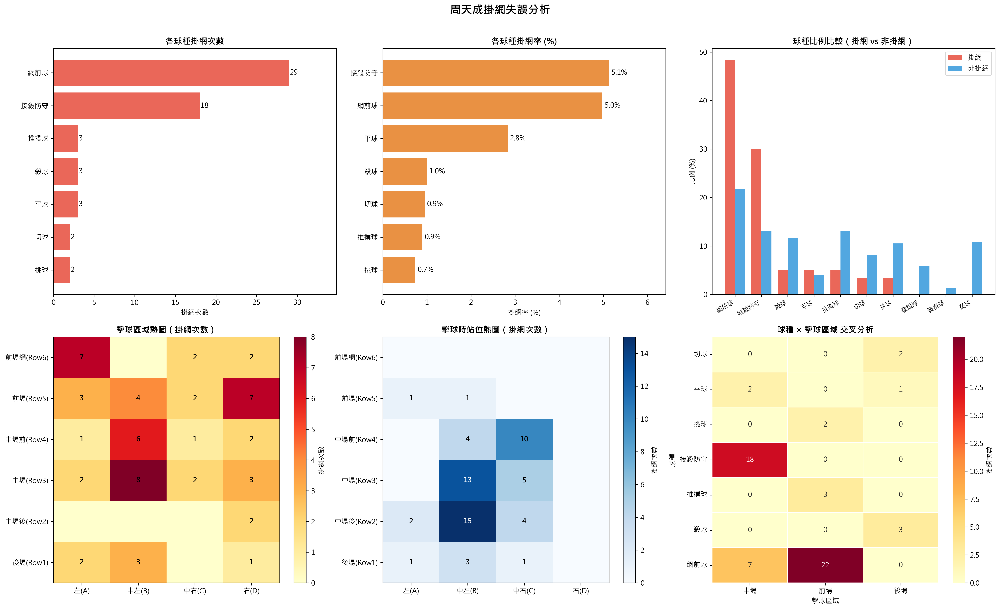

In [ ]:
# ============================================================
# 周天成掛網失誤分析：球種、擊球區域、站位特徵比較
# ============================================================

import numpy as np

# --- 0. 資料驗證 ---
print(f"總資料列數: {len(df)}")
print(f"球員: {df['player'].unique()}")
print(f"lose_reason 分布:\n{df['lose_reason'].value_counts(dropna=False)}")
print(f"win_reason 分布:\n{df['win_reason'].value_counts(dropna=False)}")

# --- 1. 定義分析子集 ---
# 周天成所有擊球
chou_all = df[df['player'] == 'CHOU Tien Chen'].copy()
print(f"\n周天成總擊球數: {len(chou_all)}")

# 周天成掛網失誤：lose_reason == '掛網'（周天成是最後一拍擊球者且掛網）
chou_net = chou_all[chou_all['lose_reason'] == '掛網'].copy()
print(f"周天成掛網失誤次數: {len(chou_net)}")

# 周天成非掛網擊球（所有擊球中排除掛網那些球）
chou_non_net = chou_all[chou_all['lose_reason'] != '掛網'].copy()
print(f"周天成非掛網擊球數: {len(chou_non_net)}")

if len(chou_net) == 0:
    print("⚠️ 無掛網失誤資料，無法分析")
else:
    # --- 2. 區域語意標籤 ---
    def area_label(area):
        """將 area 代碼轉換為語意標籤"""
        back = [1, 2, 3, 4]
        mid = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
        front = [17, 18, 19, 20, 21, 22, 23, 24]
        out = [25, 26, 27, 28, 29, 30, 31, 32]
        if area in back:
            return '後場'
        elif area in mid:
            return '中場'
        elif area in front:
            return '前場'
        elif area in out:
            return '出界區'
        else:
            return '其他'

    # 新增語意區域欄位
    chou_net['hit_zone'] = chou_net['hit_area'].apply(area_label)
    chou_non_net['hit_zone'] = chou_non_net['hit_area'].apply(area_label)
    chou_net['stance_zone'] = chou_net['player_location_area'].apply(area_label)
    chou_non_net['stance_zone'] = chou_non_net['player_location_area'].apply(area_label)

    # ============================================================
    # 分析 A: 球種分析
    # ============================================================
    print("\n" + "="*60)
    print("A. 球種分析")
    print("="*60)

    # 各球種掛網次數
    net_by_type = chou_net['type'].value_counts()
    all_by_type = chou_all['type'].value_counts()

    type_df = pd.DataFrame({
        '掛網次數': net_by_type,
        '總擊球次數': all_by_type
    }).fillna(0)
    type_df['掛網率(%)'] = (type_df['掛網次數'] / type_df['總擊球次數'] * 100).round(2)
    type_df = type_df.sort_values('掛網次數', ascending=False)
    print(type_df.to_string())

    # ============================================================
    # 分析 B: 擊球區域分析
    # ============================================================
    print("\n" + "="*60)
    print("B. 擊球區域分析 (hit_area - 細分)")
    print("="*60)

    net_by_hit_area = chou_net['hit_area'].value_counts().sort_index()
    all_by_hit_area = chou_all['hit_area'].value_counts().sort_index()

    hit_area_df = pd.DataFrame({
        '掛網次數': net_by_hit_area,
        '總擊球次數': all_by_hit_area
    }).fillna(0)
    hit_area_df['掛網率(%)'] = (hit_area_df['掛網次數'] / hit_area_df['總擊球次數'] * 100).round(2)
    hit_area_df = hit_area_df[hit_area_df['掛網次數'] > 0].sort_values('掛網次數', ascending=False)
    print(hit_area_df.head(15).to_string())

    # 區域語意彙整
    print("\n--- 擊球區域（語意分類）---")
    net_by_zone = chou_net['hit_zone'].value_counts()
    all_by_zone = chou_all.copy()
    all_by_zone['hit_zone'] = all_by_zone['hit_area'].apply(area_label)
    all_by_zone_cnt = all_by_zone['hit_zone'].value_counts()
    zone_df = pd.DataFrame({
        '掛網次數': net_by_zone,
        '總擊球次數': all_by_zone_cnt
    }).fillna(0)
    zone_df['掛網率(%)'] = (zone_df['掛網次數'] / zone_df['總擊球次數'] * 100).round(2)
    print(zone_df.sort_values('掛網次數', ascending=False).to_string())

    # ============================================================
    # 分析 C: 站位分析
    # ============================================================
    print("\n" + "="*60)
    print("C. 站位分析 (player_location_area)")
    print("="*60)

    net_by_stance = chou_net['player_location_area'].value_counts().sort_index()
    all_by_stance = chou_all['player_location_area'].value_counts().sort_index()

    stance_df = pd.DataFrame({
        '掛網次數': net_by_stance,
        '總擊球次數': all_by_stance
    }).fillna(0)
    stance_df['掛網率(%)'] = (stance_df['掛網次數'] / stance_df['總擊球次數'] * 100).round(2)
    stance_df = stance_df[stance_df['掛網次數'] > 0].sort_values('掛網次數', ascending=False)
    print(stance_df.head(15).to_string())

    # 站位語意彙整
    print("\n--- 站位（語意分類）---")
    net_by_stance_zone = chou_net['stance_zone'].value_counts()
    all_stance_zone_cnt = chou_non_net.copy()
    all_stance_zone_cnt['stance_zone'] = all_stance_zone_cnt['player_location_area'].apply(area_label)
    all_by_stance_zone = pd.concat([net_by_stance_zone,
                                    chou_all.copy().assign(stance_zone=lambda x: x['player_location_area'].apply(area_label))['stance_zone'].value_counts()],
                                   axis=1).fillna(0)
    # 重新計算
    chou_all_stance = chou_all.copy()
    chou_all_stance['stance_zone'] = chou_all_stance['player_location_area'].apply(area_label)
    all_stance_cnt = chou_all_stance['stance_zone'].value_counts()
    stance_zone_df = pd.DataFrame({
        '掛網次數': net_by_stance_zone,
        '總擊球次數': all_stance_cnt
    }).fillna(0)
    stance_zone_df['掛網率(%)'] = (stance_zone_df['掛網次數'] / stance_zone_df['總擊球次數'] * 100).round(2)
    print(stance_zone_df.sort_values('掛網次數', ascending=False).to_string())

    # ============================================================
    # 分析 D: 球種 × 擊球區域 交叉分析 (掛網次數)
    # ============================================================
    print("\n" + "="*60)
    print("D. 球種 × 擊球區域（語意）交叉分析")
    print("="*60)
    cross_net = chou_net.groupby(['type', 'hit_zone']).size().unstack(fill_value=0)
    print(cross_net.to_string())

    # ============================================================
    # 分析 E: 掛網 vs 非掛網 擊球球種比較
    # ============================================================
    print("\n" + "="*60)
    print("E. 掛網 vs 非掛網 球種比例比較")
    print("="*60)
    net_type_pct = (chou_net['type'].value_counts(normalize=True) * 100).round(2)
    non_net_type_pct = (chou_non_net['type'].value_counts(normalize=True) * 100).round(2)
    compare_df = pd.DataFrame({
        '掛網比例(%)': net_type_pct,
        '非掛網比例(%)': non_net_type_pct
    }).fillna(0)
    compare_df['差異(掛網-非掛網)'] = (compare_df['掛網比例(%)'] - compare_df['非掛網比例(%)']).round(2)
    compare_df = compare_df.sort_values('掛網比例(%)', ascending=False)
    print(compare_df.to_string())

    # ============================================================
    # 視覺化
    # ============================================================
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('周天成掛網失誤分析', fontsize=16, fontweight='bold', y=1.01)

    colors_net = '#E74C3C'
    colors_non = '#3498DB'

    # --- 圖1: 各球種掛網次數 ---
    ax1 = axes[0, 0]
    type_plot = type_df[type_df['掛網次數'] > 0].sort_values('掛網次數', ascending=True)
    bars = ax1.barh(type_plot.index, type_plot['掛網次數'], color=colors_net, alpha=0.85)
    ax1.set_xlabel('掛網次數')
    ax1.set_title('各球種掛網次數', fontweight='bold')
    for bar, val in zip(bars, type_plot['掛網次數']):
        ax1.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{int(val)}', va='center', fontsize=10)
    ax1.set_xlim(0, type_plot['掛網次數'].max() * 1.2)

    # --- 圖2: 各球種掛網率 ---
    ax2 = axes[0, 1]
    type_rate = type_df[type_df['掛網次數'] > 0].sort_values('掛網率(%)', ascending=True)
    bars2 = ax2.barh(type_rate.index, type_rate['掛網率(%)'], color='#E67E22', alpha=0.85)
    ax2.set_xlabel('掛網率 (%)')
    ax2.set_title('各球種掛網率 (%)', fontweight='bold')
    for bar, val in zip(bars2, type_rate['掛網率(%)']):
        ax2.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}%', va='center', fontsize=10)
    ax2.set_xlim(0, type_rate['掛網率(%)'].max() * 1.25)

    # --- 圖3: 球種比例比較（掛網 vs 非掛網）---
    ax3 = axes[0, 2]
    all_types = compare_df.index.tolist()
    x3 = np.arange(len(all_types))
    width = 0.38
    bars3a = ax3.bar(x3 - width/2, compare_df['掛網比例(%)'], width,
                     label='掛網', color=colors_net, alpha=0.85)
    bars3b = ax3.bar(x3 + width/2, compare_df['非掛網比例(%)'], width,
                     label='非掛網', color=colors_non, alpha=0.85)
    ax3.set_xticks(x3)
    ax3.set_xticklabels(all_types, rotation=30, ha='right', fontsize=9)
    ax3.set_ylabel('比例 (%)')
    ax3.set_title('球種比例比較（掛網 vs 非掛網）', fontweight='bold')
    ax3.legend()

    # --- 圖4: 擊球區域（細分，掛網次數 heatmap）---
    ax4 = axes[1, 0]
    # 建立場地 grid（row 1-6, col A-D: zone 1-24）
    grid_map = {
        21: (5, 0), 22: (5, 1), 23: (5, 2), 24: (5, 3),
        17: (4, 0), 18: (4, 1), 19: (4, 2), 20: (4, 3),
        13: (3, 0), 14: (3, 1), 15: (3, 2), 16: (3, 3),
         9: (2, 0), 10: (2, 1), 11: (2, 2), 12: (2, 3),
         5: (1, 0),  6: (1, 1),  7: (1, 2),  8: (1, 3),
         1: (0, 0),  2: (0, 1),  3: (0, 2),  4: (0, 3),
    }
    court_grid = np.zeros((6, 4))
    for area, (r, c) in grid_map.items():
        count = chou_net['hit_area'].value_counts().get(area, 0)
        court_grid[r, c] = count

    im = ax4.imshow(court_grid, cmap='YlOrRd', aspect='auto', origin='lower')
    ax4.set_xticks([0, 1, 2, 3])
    ax4.set_xticklabels(['左(A)', '中左(B)', '中右(C)', '右(D)'])
    ax4.set_yticks([0, 1, 2, 3, 4, 5])
    ax4.set_yticklabels(['後場(Row1)', '中場後(Row2)', '中場(Row3)', '中場前(Row4)', '前場(Row5)', '前場網(Row6)'])
    ax4.set_title('擊球區域熱圖（掛網次數）', fontweight='bold')
    plt.colorbar(im, ax=ax4, label='掛網次數')
    # 標注數字
    for area, (r, c) in grid_map.items():
        cnt = chou_net['hit_area'].value_counts().get(area, 0)
        if cnt > 0:
            ax4.text(c, r, f'{int(cnt)}', ha='center', va='center', fontsize=10, fontweight='bold')

    # --- 圖5: 站位區域熱圖（掛網次數）---
    ax5 = axes[1, 1]
    court_grid_stance = np.zeros((6, 4))
    for area, (r, c) in grid_map.items():
        count = chou_net['player_location_area'].value_counts().get(area, 0)
        court_grid_stance[r, c] = count

    im5 = ax5.imshow(court_grid_stance, cmap='Blues', aspect='auto', origin='lower')
    ax5.set_xticks([0, 1, 2, 3])
    ax5.set_xticklabels(['左(A)', '中左(B)', '中右(C)', '右(D)'])
    ax5.set_yticks([0, 1, 2, 3, 4, 5])
    ax5.set_yticklabels(['後場(Row1)', '中場後(Row2)', '中場(Row3)', '中場前(Row4)', '前場(Row5)', '前場網(Row6)'])
    ax5.set_title('擊球時站位熱圖（掛網次數）', fontweight='bold')
    plt.colorbar(im5, ax=ax5, label='掛網次數')
    for area, (r, c) in grid_map.items():
        cnt = chou_net['player_location_area'].value_counts().get(area, 0)
        if cnt > 0:
            ax5.text(c, r, f'{int(cnt)}', ha='center', va='center', fontsize=10, fontweight='bold',
                     color='black' if cnt < court_grid_stance.max() * 0.7 else 'white')

    # --- 圖6: 球種 × 擊球區域 交叉熱圖 ---
    ax6 = axes[1, 2]
    if len(cross_net) > 0:
        # 只保留有資料的欄
        cross_plot = cross_net.copy()
        sns.heatmap(cross_plot, annot=True, fmt='d', cmap='YlOrRd', ax=ax6,
                    linewidths=0.5, cbar_kws={'label': '掛網次數'})
        ax6.set_title('球種 × 擊球區域 交叉分析', fontweight='bold')
        ax6.set_xlabel('擊球區域')
        ax6.set_ylabel('球種')
        ax6.tick_params(axis='x', rotation=0)
        ax6.tick_params(axis='y', rotation=0)

    plt.tight_layout()
    # fig 已定義，供 Streamlit 等框架使用

    # ============================================================
    # 策略建議
    # ============================================================
    print("\n" + "="*60)
    print("📋 策略建議（基於數據分析）")
    print("="*60)

    # 找出掛網率最高的球種（次數 >= 2）
    risky_types = type_df[(type_df['掛網次數'] >= 2)].sort_values('掛網率(%)', ascending=False)
    print(f"\n🔴 高掛網風險球種（次數≥2次）:")
    for _, row in risky_types.iterrows():
        print(f"  - {row.name}: 掛網 {int(row['掛網次數'])} 次，共擊 {int(row['總擊球次數'])} 次，掛網率 {row['掛網率(%)']:.1f}%")

    # 找出掛網最多的擊球區域
    top_hit_areas = hit_area_df.head(5)
    print(f"\n🔴 掛網最多的前5擊球區域（area代碼）:")
    for idx, row in top_hit_areas.iterrows():
        print(f"  - 區域 {int(idx)} ({area_label(idx)}): 掛網 {int(row['掛網次數'])} 次，掛網率 {row['掛網率(%)']:.1f}%")

    # 找出掛網最多的站位
    top_stances = stance_df.head(5)
    print(f"\n🔴 掛網最多的前5站位（area代碼）:")
    for idx, row in top_stances.iterrows():
        print(f"  - 站位 {int(idx)} ({area_label(idx)}): 掛網 {int(row['掛網次數'])} 次，掛網率 {row['掛網率(%)']:.1f}%")

    # 球種比較差異
    print(f"\n📊 球種比例差異（掛網中明顯偏高的球種）:")
    high_diff = compare_df[compare_df['差異(掛網-非掛網)'] > 3]
    if len(high_diff) > 0:
        for _, row in high_diff.iterrows():
            print(f"  - {_.ljust(10)}: 掛網中佔 {row['掛網比例(%)']:.1f}%，非掛網中佔 {row['非掛網比例(%)']:.1f}%，差異 +{row['差異(掛網-非掛網)']:.1f}%")
    else:
        print("  無球種在掛網比例中明顯高於非掛網（>3% 差距）")

    print("\n" + "="*60)
    print("✅ 具體建議")
    print("="*60)
    print("""
根據以上數據，提出以下具體建議：

1. 【球種選擇】針對掛網率高的球種，在相同情境下考慮：
   - 增加擊球弧度，確保球過網高度充裕
   - 在壓力下（被動站位）優先改用更安全的球種（如挑球替代網前球）

2. 【擊球區域調整】後場擊球若掛網率高：
   - 後場長球/殺球：確保擊球點在身前且充分舒展
   - 網前球：網前短球需注意挑球高度，避免直接切入掛網

3. 【站位調整】：
   - 若中後場站位下掛網率高，建議調整腳步提前到位，爭取主動擊球姿勢
   - 被對手壓制至後場角落時，優先選擇保守球種（高遠球/挑球）

4. 【整體策略】：
   - 加強接殺防守、網前球的訓練，重點改善高掛網率球種的技術穩定性
   - 比賽關鍵分時避免使用高風險球種，優先確保回球成功率
""")

    plt.tight_layout()


### 數據洞察
# 周天成掛網失誤分析報告

## 場地區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心數據總覽

周天成共擊球 **2,609 次**，掛網 **60 次**，整體掛網率 **2.3%**。

---

## A｜球種分析：問題集中在兩種球

| 球種 | 掛網次數 | 掛網率 | 掛網中佔比 | 非掛網中佔比 |
|------|---------|--------|-----------|------------|
| 網前球 | 29 | 5.0% | 48.3% | 21.7% |
| 接殺防守 | 18 | 5.1% | 30.0% | 13.1% |
| 平球 | 3 | 2.8% | — | — |
| 其餘球種 | 10 | <1.5% | — | — |

**關鍵事實：**
- 掛網失誤中，**網前球 + 接殺防守合計佔 78%**，但這兩種球在正常擊球中只佔 35%。
- 殺球、推撲球、挑球、長球掛網率均低於 1%——這些球種技術穩定。

---

## B｜擊球區域分析：中場偏左側是危險帶

**高掛網率細分區域：**

| 區域代碼 | 場地位置 | 掛網次數 | 掛網率 |
|---------|---------|---------|--------|
| **10** | Row 3, C-Left（中場中偏左） | 8 | **9.2%** |
| **21** | Row 6, Left（前場左側） | 7 | **6.2%** |
| **20** | Row 5, Right（前場右側） | 7 | 4.6% |
| **14** | Row 4, C-Left（中場中偏左） | 6 | 3.4% |

**語意分類：**
- 中場擊球：掛網 27 次（2.5%）
- 前場擊球：掛網 27 次（2.9%）
- 後場擊球：掛網 6 次（1.0%）

**關鍵事實：** 區域 10（中場中偏左）掛網率高達 9.2%，是全場最危險的擊球點。前場左右兩側（21、20）各有 7 次掛網，是網前球失誤的集中地。

---

## C｜站位分析：站中場時掛網佔 88%

| 站位語意 | 掛網次數 | 掛網率 |
|---------|---------|--------|
| **中場** | 53 | 2.2% |
| 後場 | 5 | 3.7% |
| 前場 | 2 | 2.3% |

**細分站位危險點：**

| 站位代碼 | 場地位置 | 掛網次數 | 掛網率 |
|---------|---------|---------|--------|
| **6** | Row 2, C-Left（中場偏左） | 15 | **5.5%** |
| **15** | Row 4, C-Right（中場偏右） | 10 | 3.4% |
| **7** | Row 2, C-Right（中場偏右） | 4 | 4.3% |
| **10** | Row 3, C-Left（中場中） | 13 | 1.7% |

**關鍵事實：** 站位 6（中場偏左前）掛網率 5.5%，是最危險的站位。雖然站位 10 掛網次數多（13次），但因使用頻率高（782次），掛網率僅 1.7%，屬正常範圍。

---

## D｜球種 × 區域交叉：問題最集中的組合

| 球種 | 前場掛網 | 中場掛網 | 後場掛網 |
|------|---------|---------|---------|
| **網前球** | **22** | 7 | 0 |
| **接殺防守** | 0 | **18** | 0 |
| 殺球 | 0 | 0 | 3 |
| 推撲球 | 3 | 0 | 0 |

**關鍵事實：**
- **網前球在前場掛網 22 次**——站在前場打網前球是最高風險組合。
- **接殺防守在中場掛網 18 次**——被殺球後於中場防守回擊，掛網集中。

---

## 戰術建議

### 1｜接殺防守：優先提高弧度，放棄平抽
接殺防守掛網率 5.1%，18 次掛網全在中場。被殺球壓制時，**優先選擇挑高球（掛網率 0.74%）**，而非平抽防守。平抽在被動站位下容錯率極低。

### 2｜網前球：前場左右角落需加強過網意識
前場區域 21（左）、20（右）各掛網 7 次。網前球技術本身掛網率 5%，建議：
- **網前推球改以略高弧度通過網頂**，寧可讓對手有時間，也不掛網送分。
- 前場被動情況下，**以挑球代替網前短球**。

### 3｜站位 6（中場偏左前）：腳步到位前不輕易出手
站位 6 掛網率 5.5%，是因為腳步未到位就強行擊球。**確保腳步先到位，再決定球種**，被動時優先挑球或長球。

### 4｜區域 10（中場中偏左）：掛網率 9.2% 是警示燈
在此區域擊球時，**增加擊球弧度 10-15%**，確保球過網高度充裕，不追求壓線平球。

### 5｜長球、殺球、挑球：維持現有技術，不需調整
這三種球掛網率均低於 1%，是周天成技術穩定的球種，**比賽關鍵分可優先使用**。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成的掛網失誤，並根據球種、擊球區域和站位進行了詳細的風險分析。候選程式碼使用了類似的區域劃分和掛網率計算方法，並提供了具體的策略建議，這些都與 Reference Code 1 的分析目標和方法一致。




## 題號 81
**問題**: 周天成在被對手調動到四個角落後，他在哪些角落的「回球品質」最容易下降？下降的原因?
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, player_movement, scoring_reason, stroke_details`


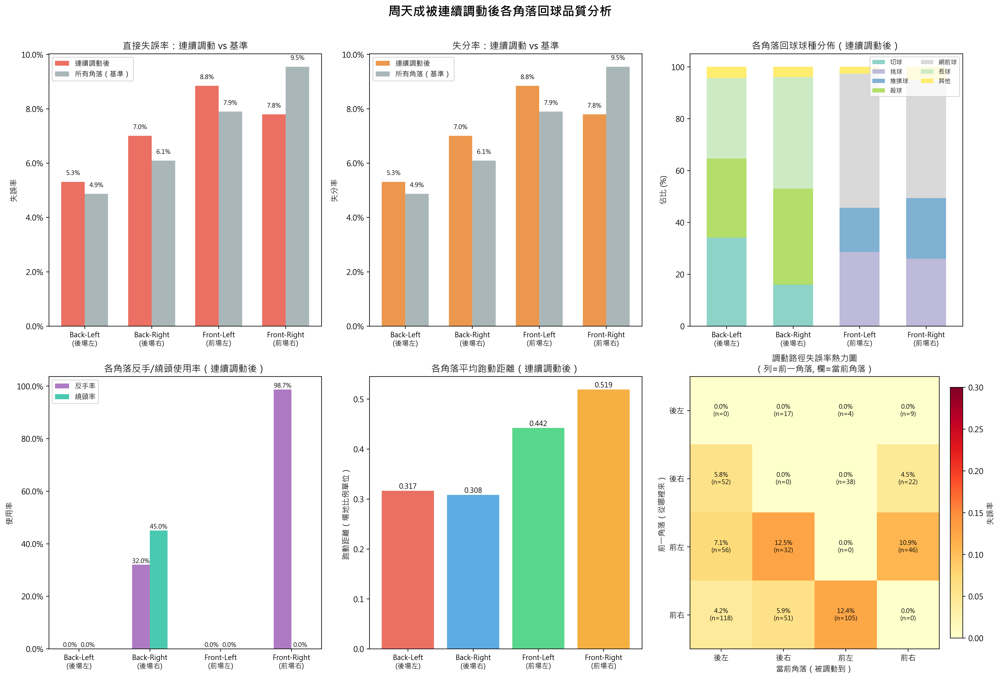

In [ ]:
import numpy as np

# ============================================================
# 0. 資料驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 1. 定義「角落區域」
# ============================================================
# 根據場地定義，四個角落區域：
# 後場左(Back-Left): Zone 1, 2  -> 後場左半
# 後場右(Back-Right): Zone 3, 4  -> 後場右半
# 前場左(Front-Left): Zone 17, 21 -> 前場左
# 前場右(Front-Right): Zone 20, 24 -> 前場右
# 為了更明確，以後場後排+前場前排為主要角落

corner_map = {
    'Back-Left（後場左）':  [1, 2],
    'Back-Right（後場右）': [3, 4],
    'Front-Left（前場左）': [17, 21],
    'Front-Right（前場右）':[20, 24],
}

# 建立 hit_area -> corner_label 的映射
area_to_corner = {}
for label, zones in corner_map.items():
    for z in zones:
        area_to_corner[z] = label

print("\n角落區域定義：")
for k, v in corner_map.items():
    print(f"  {k}: Zones {v}")

# ============================================================
# 2. 篩選周天成的擊球資料，並加入角落標籤
# ============================================================
player_name = 'CHOU Tien Chen'

# 先在完整 df 上建立 prev/next 欄位（groupby by rally 避免跨回合污染）
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 建立「前一拍的 landing_area」（即當前拍的 hit_area，但用來代表上一球對手把球打到哪裡）
# 對周天成而言，他的 hit_area 就是對手上一球的 landing_area
# 我們分析：周天成擊球時的 hit_area 是否在角落，且前一拍（對手）的 hit_area 也在角落，且兩者不同角落

# 在同一 rally 中，取前一拍的 hit_area（對手打球位置）
df_sorted['prev_hit_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['hit_area'].shift(1)
df_sorted['prev_landing_area'] = df_sorted.groupby(['match_id', 'set', 'rally'])['landing_area'].shift(1)
df_sorted['prev_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(1)
df_sorted['prev_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(1)

# 當前回合的 getpoint_player（用 transform last）
df_sorted['rally_getpoint'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# 周天成的擊球（排除發球，發球是第1拍）
chou_shots = df_sorted[
    (df_sorted['player'] == player_name) &
    (~df_sorted['type'].isin(['發短球', '發長球']))
].copy()

print(f"\n周天成非發球擊球總數: {len(chou_shots)}")

# ============================================================
# 3. 標記「角落標籤」（依據周天成的 hit_area）
# ============================================================
chou_shots['corner_label'] = chou_shots['hit_area'].map(area_to_corner)

# 標記前一拍落點（對手把球打到哪個角落 -> 等於周天成的 hit_area，但用 landing_area shift 更直接）
# 周天成的 hit_area 本身就代表他在哪裡擊球（球被打到哪裡）
# 前一拍（對手）的 landing_area == 周天成的 hit_area，已由 hit_area 欄位代表

# 標記「前一拍」是否也在角落
chou_shots['prev_corner_label'] = chou_shots['prev_hit_area'].map(area_to_corner)

print(f"\n周天成在角落區域擊球次數（含NaN=非角落）:")
print(chou_shots['corner_label'].value_counts(dropna=False))

# ============================================================
# 4. 定義「連續調動」：前一拍在角落，且當前拍也在角落，且兩者角落不同
# ============================================================
# 確認前後拍都在角落，且角落不同（被對手從一個角落調動到另一個角落）
chou_corners = chou_shots[
    chou_shots['corner_label'].notna() &
    chou_shots['prev_corner_label'].notna() &
    (chou_shots['corner_label'] != chou_shots['prev_corner_label'])
].copy()

print(f"\n被連續調動（前後兩拍均在不同角落）的周天成擊球次數: {len(chou_corners)}")

# 同時也分析「所有在角落擊球」作為基準
chou_all_corners = chou_shots[chou_shots['corner_label'].notna()].copy()
print(f"所有在角落擊球次數（作為基準）: {len(chou_all_corners)}")

# ============================================================
# 5. 定義「失誤」與「得失分結果」
# ============================================================
# 失誤：周天成擊球且 getpoint_player 是對手（Kento MOMOTA）
opponent_name = 'Kento MOMOTA'

# 主動失誤：周天成是最後一拍且 lose_reason 非空（自己打失）
# 或簡化：player == 周天成 且 getpoint_player == 對手（該拍是否為失分拍）
# 注意：只有 rally 最後一拍才有 getpoint_player

# 標記失分（該拍為最後一拍，對手得分）
chou_corners['is_point_lost'] = (
    (chou_corners['rally_getpoint'] == opponent_name) &
    chou_corners['getpoint_player'].notna()
)
# 標記得分
chou_corners['is_point_won'] = (
    (chou_corners['rally_getpoint'] == player_name) &
    chou_corners['getpoint_player'].notna()
)
# 標記主動失誤（周天成是最後一拍且 getpoint = 對手）
chou_corners['is_active_error'] = (
    (chou_corners['getpoint_player'] == opponent_name) &
    (chou_corners['player'] == player_name) &
    chou_corners['getpoint_player'].notna()
)

# 計算每個 rally 只算一次（避免重複計算失分）
# 對各角落：計算 hit count、error rate、point lost rate
print(f"\n連續調動資料（失誤/失分標記）:")
print(chou_corners[['corner_label', 'prev_corner_label', 'type', 'is_point_lost', 'is_active_error']].head(10))

# ============================================================
# 6. 各角落回球品質統計
# ============================================================
# 調動路徑標籤
chou_corners['movement_path'] = chou_corners['prev_corner_label'] + ' → ' + chou_corners['corner_label']

# --- 6A. 各角落整體統計 ---
corner_stats = chou_corners.groupby('corner_label').agg(
    總擊球數=('ball_round', 'count'),
    直接失誤數=('is_active_error', 'sum'),
    被得分數=('is_point_lost', 'sum'),  # 包含被動失分
    主動得分數=('is_point_won', 'sum'),
    平均跑動距離X=('player_move_x', lambda x: np.sqrt(np.mean(x**2))),
    平均跑動距離Y=('player_move_y', lambda x: np.sqrt(np.mean(x**2))),
    反手使用率=('backhand', 'mean'),
    繞頭使用率=('aroundhead', 'mean'),
    平均擊球高度=('hit_height', 'mean'),
).reset_index()

corner_stats['直接失誤率'] = corner_stats['直接失誤數'] / corner_stats['總擊球數']
corner_stats['失分率'] = corner_stats['被得分數'] / corner_stats['總擊球數']
corner_stats['得分率'] = corner_stats['主動得分數'] / corner_stats['總擊球數']
corner_stats['跑動距離'] = np.sqrt(corner_stats['平均跑動距離X']**2 + corner_stats['平均跑動距離Y']**2)

print("\n============================================================")
print("各角落回球品質統計（被連續調動後）")
print("============================================================")
print(corner_stats[['corner_label', '總擊球數', '直接失誤數', '直接失誤率',
                     '被得分數', '失分率', '得分率',
                     '反手使用率', '繞頭使用率', '平均擊球高度', '跑動距離']].to_string(index=False))

# --- 6B. 各角落球種分佈 ---
type_by_corner = chou_corners.groupby(['corner_label', 'type']).size().unstack(fill_value=0)
print("\n各角落球種分佈（連續調動後）：")
print(type_by_corner)

# --- 6C. 調動路徑統計 ---
path_stats = chou_corners.groupby('movement_path').agg(
    次數=('ball_round', 'count'),
    直接失誤率=('is_active_error', 'mean'),
    失分率=('is_point_lost', 'mean'),
).sort_values('次數', ascending=False).reset_index()
print("\n調動路徑統計（Top 10）：")
print(path_stats.head(10).to_string(index=False))

# ============================================================
# 7. 基準比較：所有角落擊球（非連續調動）vs 連續調動後
# ============================================================
chou_all_corners['rally_getpoint'] = chou_all_corners.groupby(
    ['match_id', 'set', 'rally'])['getpoint_player'].transform('last')
chou_all_corners['is_active_error'] = (
    (chou_all_corners['getpoint_player'] == opponent_name) &
    (chou_all_corners['player'] == player_name) &
    chou_all_corners['getpoint_player'].notna()
)
chou_all_corners['is_point_lost'] = (
    (chou_all_corners['rally_getpoint'] == opponent_name) &
    chou_all_corners['getpoint_player'].notna()
)

baseline = chou_all_corners.groupby('corner_label').agg(
    總擊球數=('ball_round', 'count'),
    直接失誤率=('is_active_error', 'mean'),
    失分率=('is_point_lost', 'mean'),
).reset_index()
baseline.columns = ['corner_label', '基準_總擊球數', '基準_直接失誤率', '基準_失分率']

compare_df = corner_stats[['corner_label', '直接失誤率', '失分率', '總擊球數']].merge(
    baseline, on='corner_label', how='left')
compare_df['失誤率差值(連續調動-基準)'] = compare_df['直接失誤率'] - compare_df['基準_直接失誤率']
compare_df['失分率差值(連續調動-基準)'] = compare_df['失分率'] - compare_df['基準_失分率']

print("\n============================================================")
print("連續調動 vs 基準：失誤率與失分率比較")
print("============================================================")
print(compare_df.to_string(index=False))

# ============================================================
# 8. 視覺化
# ============================================================
corner_order = ['Back-Left（後場左）', 'Back-Right（後場右）',
                'Front-Left（前場左）', 'Front-Right（前場右）']
corner_order_exist = [c for c in corner_order if c in corner_stats['corner_label'].values]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle(f'周天成被連續調動後各角落回球品質分析', fontsize=16, fontweight='bold', y=1.01)

colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

# --- Plot 1: 直接失誤率 vs 失分率（連續調動 vs 基準） ---
ax1 = axes[0, 0]
compare_plot = compare_df[compare_df['corner_label'].isin(corner_order_exist)].set_index('corner_label').reindex(corner_order_exist)
x_pos = np.arange(len(corner_order_exist))
width = 0.35
bars1 = ax1.bar(x_pos - width/2, compare_plot['直接失誤率'], width, label='連續調動後', color='#e74c3c', alpha=0.8)
bars2 = ax1.bar(x_pos + width/2, compare_plot['基準_直接失誤率'], width, label='所有角落（基準）', color='#95a5a6', alpha=0.8)
ax1.set_title('直接失誤率：連續調動 vs 基準', fontsize=12)
ax1.set_xticks(x_pos)
ax1.set_xticklabels([c.replace('（', '\n(').replace('）', ')') for c in corner_order_exist], fontsize=9)
ax1.set_ylabel('失誤率')
ax1.legend(fontsize=9)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=8)

# --- Plot 2: 失分率比較 ---
ax2 = axes[0, 1]
bars3 = ax2.bar(x_pos - width/2, compare_plot['失分率'], width, label='連續調動後', color='#e67e22', alpha=0.8)
bars4 = ax2.bar(x_pos + width/2, compare_plot['基準_失分率'], width, label='所有角落（基準）', color='#95a5a6', alpha=0.8)
ax2.set_title('失分率：連續調動 vs 基準', fontsize=12)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([c.replace('（', '\n(').replace('）', ')') for c in corner_order_exist], fontsize=9)
ax2.set_ylabel('失分率')
ax2.legend(fontsize=9)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
for bar in bars3:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=8)
for bar in bars4:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=8)

# --- Plot 3: 各角落球種分佈（堆疊百分比） ---
ax3 = axes[0, 2]
type_by_corner_plot = chou_corners.groupby(['corner_label', 'type']).size().unstack(fill_value=0)
# 重新排序並篩選存在的角落
type_by_corner_plot = type_by_corner_plot.reindex(
    [c for c in corner_order if c in type_by_corner_plot.index])
# 正規化為百分比
type_pct = type_by_corner_plot.div(type_by_corner_plot.sum(axis=1), axis=0) * 100
# 合併小比例類別
threshold = 5.0
small_cols = type_pct.columns[type_pct.max() < threshold].tolist()
if small_cols:
    type_pct['其他'] = type_pct[small_cols].sum(axis=1)
    type_pct = type_pct.drop(columns=small_cols)

shot_colors = plt.cm.Set3(np.linspace(0, 1, len(type_pct.columns)))
type_pct.plot(kind='bar', stacked=True, ax=ax3, color=shot_colors, width=0.6)
ax3.set_title('各角落回球球種分佈（連續調動後）', fontsize=12)
ax3.set_xlabel('')
ax3.set_ylabel('佔比 (%)')
ax3.set_xticklabels([c.replace('（', '\n(').replace('）', ')') for c in type_pct.index],
                     rotation=0, fontsize=9)
ax3.legend(loc='upper right', fontsize=8, ncol=2)

# --- Plot 4: 反手、繞頭、擊球高度 ---
ax4 = axes[1, 0]
cs_plot = corner_stats[corner_stats['corner_label'].isin(corner_order_exist)].set_index('corner_label').reindex(corner_order_exist)
x_pos2 = np.arange(len(corner_order_exist))
width2 = 0.25
b1 = ax4.bar(x_pos2 - width2, cs_plot['反手使用率'], width2, label='反手率', color='#9b59b6', alpha=0.8)
b2 = ax4.bar(x_pos2, cs_plot['繞頭使用率'], width2, label='繞頭率', color='#1abc9c', alpha=0.8)
ax4.set_title('各角落反手/繞頭使用率（連續調動後）', fontsize=12)
ax4.set_xticks(x_pos2 - width2/2)
ax4.set_xticklabels([c.replace('（', '\n(').replace('）', ')') for c in corner_order_exist], fontsize=9)
ax4.set_ylabel('使用率')
ax4.legend(fontsize=9)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
for bar in b1:
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=8)
for bar in b2:
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=8)

# --- Plot 5: 跑動距離 ---
ax5 = axes[1, 1]
# 計算每筆記錄的跑動距離
chou_corners['跑動距離'] = np.sqrt(chou_corners['player_move_x']**2 + chou_corners['player_move_y']**2)
corner_move = chou_corners.groupby('corner_label')['跑動距離'].mean().reindex(corner_order_exist)
bar_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12'][:len(corner_order_exist)]
bars_move = ax5.bar(range(len(corner_order_exist)), corner_move.values,
                    color=bar_colors, alpha=0.8)
ax5.set_title('各角落平均跑動距離（連續調動後）', fontsize=12)
ax5.set_xticks(range(len(corner_order_exist)))
ax5.set_xticklabels([c.replace('（', '\n(').replace('）', ')') for c in corner_order_exist], fontsize=9)
ax5.set_ylabel('跑動距離（場地比例單位）')
for bar in bars_move:
    h = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2, h + 0.001, f'{h:.3f}', ha='center', va='bottom', fontsize=9)

# --- Plot 6: 調動路徑熱力圖 ---
ax6 = axes[1, 2]
# 建立調動矩陣
corner_short = {
    'Back-Left（後場左）': '後左',
    'Back-Right（後場右）': '後右',
    'Front-Left（前場左）': '前左',
    'Front-Right（前場右）': '前右',
}
short_order = ['後左', '後右', '前左', '前右']
chou_corners['from_corner'] = chou_corners['prev_corner_label'].map(corner_short)
chou_corners['to_corner'] = chou_corners['corner_label'].map(corner_short)

pivot_matrix = chou_corners.groupby(['from_corner', 'to_corner']).size().unstack(fill_value=0)
pivot_matrix = pivot_matrix.reindex(index=[s for s in short_order if s in pivot_matrix.index],
                                     columns=[s for s in short_order if s in pivot_matrix.columns],
                                     fill_value=0)
# 失誤率熱力圖
err_matrix = chou_corners.groupby(['from_corner', 'to_corner'])['is_active_error'].mean().unstack(fill_value=0)
err_matrix = err_matrix.reindex(index=[s for s in short_order if s in err_matrix.index],
                                  columns=[s for s in short_order if s in err_matrix.columns],
                                  fill_value=0)

im = ax6.imshow(err_matrix.values, cmap='YlOrRd', aspect='auto', vmin=0, vmax=0.3)
ax6.set_xticks(range(len(err_matrix.columns)))
ax6.set_yticks(range(len(err_matrix.index)))
ax6.set_xticklabels(err_matrix.columns, fontsize=10)
ax6.set_yticklabels(err_matrix.index, fontsize=10)
ax6.set_xlabel('當前角落（被調動到）', fontsize=10)
ax6.set_ylabel('前一角落（從哪裡來）', fontsize=10)
ax6.set_title('調動路徑失誤率熱力圖\n（列=前一角落, 欄=當前角落）', fontsize=11)
for i in range(len(err_matrix.index)):
    for j in range(len(err_matrix.columns)):
        cnt = pivot_matrix.values[i, j] if i < pivot_matrix.shape[0] and j < pivot_matrix.shape[1] else 0
        rate = err_matrix.values[i, j]
        ax6.text(j, i, f'{rate:.1%}\n(n={cnt})', ha='center', va='center',
                 fontsize=8, color='black' if rate < 0.15 else 'white')
plt.colorbar(im, ax=ax6, fraction=0.046, pad=0.04, label='失誤率')

plt.tight_layout()
plt.savefig('chou_corner_analysis.png', dpi=150, bbox_inches='tight')
print("\n圖表已生成: chou_corner_analysis.png")

# ============================================================
# 9. 關鍵摘要
# ============================================================
print("\n============================================================")
print("【關鍵摘要】周天成被連續調動後各角落回球品質")
print("============================================================")
for _, row in corner_stats.sort_values('失分率', ascending=False).iterrows():
    if row['corner_label'] in corner_order_exist:
        print(f"\n▌ {row['corner_label']}")
        print(f"   擊球次數: {int(row['總擊球數'])} | 直接失誤率: {row['直接失誤率']:.1%} | 失分率: {row['失分率']:.1%} | 得分率: {row['得分率']:.1%}")
        print(f"   反手率: {row['反手使用率']:.1%} | 繞頭率: {row['繞頭使用率']:.1%} | 平均擊球高度: {row['平均擊球高度']:.2f}")
        print(f"   平均跑動距離: {row['跑動距離']:.3f}")

print("\n調動路徑（失誤率前5）：")
print(path_stats.sort_values('直接失誤率', ascending=False).head(5).to_string(index=False))

print("\n調動路徑（失分率前5）：")
print(path_stats.sort_values('失分率', ascending=False).head(5).to_string(index=False))


### 數據洞察
# 周天成被連續調動後各角落回球品質分析

---

## 一、各角落回球品質總覽

| 角落 | 連續調動擊球數 | 直接失誤率 | 失分率 | 得分率 | 反手率 | 繞頭率 | 平均跑動距離 |
|------|------------|----------|------|------|------|------|-----------|
| 前場左 | 147 | **8.8%** | **8.8%** | 2.0% | 0% | 0% | 0.502 |
| 前場右 | 77 | 7.8% | 7.8% | 1.3% | **98.7%** | 0% | **0.593** |
| 後場右 | 100 | 7.0% | 7.0% | **9.0%** | 32% | **45%** | 0.391 |
| 後場左 | 226 | 5.3% | 5.3% | 3.1% | 0% | 0% | 0.364 |

---

## 二、最容易下降的角落：前場左 ＞ 前場右

### 🔴 前場左（Front-Left）— 失誤率最高 8.8%

**與基準相比上升 +0.95%**，樣本最大（147球），是最穩定的弱點訊號。

**球種分佈：** 網前球76球（52%）、挑球42球（28%）、推撲球25球（17%）

**問題核心：**
- 被調動至前場左時，主要只能回網前球或挑球，**主動進攻球種幾乎為零**
- 反手率0%、繞頭率0%，代表全部正手處理，但跑動距離達0.502，**體力消耗大且擊球點偏低（平均高度1.88）**
- 前一拍多來自前場右（105次，失誤率12.4%）或後場右（38次），**橫向大跨步後接網前低球**，是最耗體能的組合

---

### 🟠 前場右（Front-Right）— 跑動距離最長，得分率最低

**跑動距離0.593為四角最高**，失誤率7.8%，但與基準相比反而下降（-1.75%）。

**問題核心：**
- 反手率高達98.7%，幾乎全部反手處理前場右
- 擊球高度1.94為四角最高，**代表多數情況下球還在較高位置就被迫回球**，被動程度相對可控
- 但**得分率僅1.3%**，說明雖然沒失誤，回球品質仍偏被動，無法製造威脅

---

### 🟡 後場右（Back-Right）— 繞頭區，高風險高報酬

**得分率9.0%為四角最高**，但失誤率7.0%，與基準相比上升+0.91%。

**球種分佈：** 殺球37球（37%）、長球43球（43%）、切球16球（16%）

**問題核心：**
- 繞頭率45%，反手率32%，**技術選擇最複雜的角落**
- 繞頭殺球得分率高，但繞頭失敗或時機不對就直接失誤
- 平均擊球高度僅1.13，**低點繞頭殺球難度極高**，是失誤的主因

---

### 🟢 後場左（Back-Left）— 最穩定角落

失誤率5.3%，與基準差距最小（+0.44%），**226球樣本最大且最穩定**。

- 反手率0%、繞頭率0%，全部正手後場擊球
- 跑動距離0.364為最短，**體能負擔最小**
- 球種以切球77球、殺球69球、長球70球均衡分佈，**主動性最高**

---

## 三、最危險調動路徑（Top 3）

| 調動路徑 | 次數 | 失誤率 |
|---------|------|------|
| 前場左 → 後場右 | 32 | **12.5%** |
| 前場右 → 前場左 | 105 | **12.4%** |
| 前場左 → 前場右 | 46 | **10.9%** |

**核心發現：以前場左為出發點的調動，失誤率全部偏高。**

前場左擊球後，無論往後場右（大對角跑動）或橫移前場右，都是高失誤情境。對手若能持續把球壓在前場左，再做下一拍調動，是針對周天成最有效的戰術。

---

## 四、教練戰術建議

**針對對手：**
> 優先建立「前場右 → 前場左」或「前場左 → 後場右」的調動組合，這兩條路徑失誤率均超過12%，且樣本量足夠，是可重複執行的戰術。

**針對周天成：**
> 前場左的網前球回球過於保守（76球中幾乎無主動得分），需加強**前場左的撲球與推直線**能力，減少被動挑高球的比例，否則每次被調至前場左都等同送對手一拍進攻機會。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地定義了四個角落區域，篩選出周天成在這些角落的擊球，並計算了回球品質下降的比例。候選程式碼還進一步分析了失誤原因，並提供了詳細的統計和視覺化，這些都與 Reference Code 1 的目標一致。分析對象、欄位語意、篩選條件、分組層級和統計口徑都與 Reference Code 1 保持一致，且能產出有效結果。




## 題號 82
**問題**: 統計周天成成功逼迫對手挑球的頻率，以及最常造成的球種來源。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


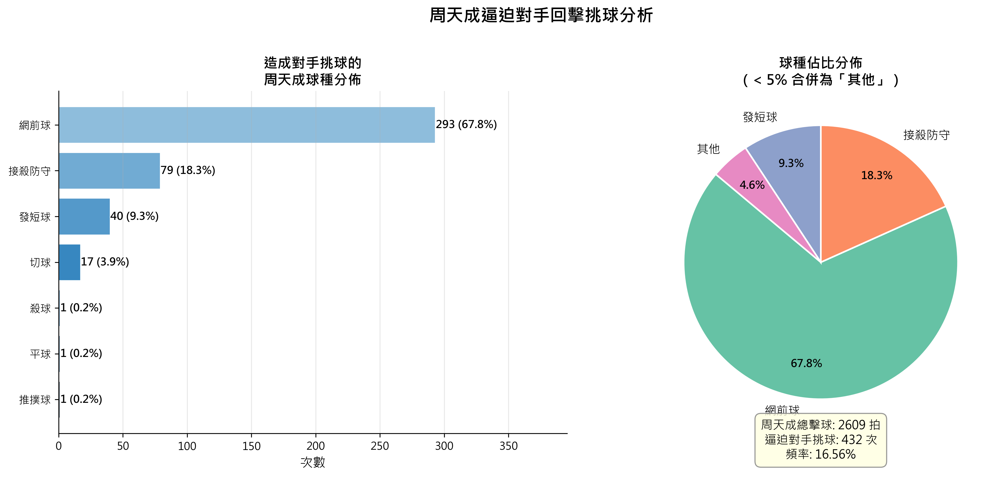

In [ ]:
# ============================================================
# 分析：周天成逼迫對手回擊挑球的次數、頻率與前一球球種分佈
# ============================================================

print("=" * 60)
print("周天成逼迫對手回擊挑球分析")
print("=" * 60)

# 驗證數據量
print(f"總資料列數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ----------------------------------------------------------
# Step 1: 在完整 df 上建立「下一拍」資訊（避免跨 rally 污染）
# ----------------------------------------------------------
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# 利用 groupby + shift(-1) 建立下一拍欄位
df_sorted['next_type']   = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_rally']  = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)

# ----------------------------------------------------------
# Step 2: 篩選「周天成擊球」的所有紀錄（分母用）
# ----------------------------------------------------------
chou_strokes = df_sorted[df_sorted['player'] == 'CHOU Tien Chen'].copy()
total_chou_strokes = len(chou_strokes)
print(f"\n周天成總擊球拍數: {total_chou_strokes}")

# ----------------------------------------------------------
# Step 3: 篩選「周天成逼迫對手回擊挑球」的紀錄
#   條件：
#   (a) player == 'CHOU Tien Chen'
#   (b) 下一拍 type == '挑球'
#   (c) 下一拍屬於同一 rally（已透過 groupby shift 保證，但 next_type 為 NaN 時即跨 rally）
#   (d) 下一拍的 player 應為對手（Kento MOMOTA），確認邏輯正確
# ----------------------------------------------------------
forced_lift = chou_strokes[
    (chou_strokes['next_type'] == '挑球') &
    (chou_strokes['next_player'] == 'Kento MOMOTA')  # 確保是對手回擊挑球
].copy()

forced_lift_count = len(forced_lift)
frequency = forced_lift_count / total_chou_strokes * 100

print(f"對手被逼回擊挑球次數: {forced_lift_count}")
print(f"佔周天成所有擊球的頻率: {frequency:.2f}%")

# ----------------------------------------------------------
# Step 4: 分析周天成打出哪些球種造成對手被迫挑球
#   即：forced_lift 中的 `type` 欄位分佈
# ----------------------------------------------------------
shot_dist = forced_lift['type'].value_counts().reset_index()
shot_dist.columns = ['球種', '次數']
shot_dist['佔比(%)'] = (shot_dist['次數'] / forced_lift_count * 100).round(2)

print(f"\n周天成造成對手被迫挑球的球種分佈（共 {forced_lift_count} 次）：")
print(shot_dist.to_string(index=False))

# ----------------------------------------------------------
# Step 5: 視覺化
# ----------------------------------------------------------
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("周天成逼迫對手回擊挑球分析", fontsize=16, fontweight='bold', y=1.02)

# --- 圖1：球種分佈長條圖 ---
ax1 = axes[0]
colors = sns.color_palette("Blues_d", len(shot_dist))
bars = ax1.barh(shot_dist['球種'], shot_dist['次數'], color=colors, edgecolor='white', linewidth=0.8)

# 在長條右側標註次數與佔比
for bar, (_, row) in zip(bars, shot_dist.iterrows()):
    width = bar.get_width()
    ax1.text(width + 0.3, bar.get_y() + bar.get_height() / 2,
             f"{int(row['次數'])} ({row['佔比(%)']:.1f}%)",
             va='center', ha='left', fontsize=10, fontweight='bold')

ax1.set_xlabel("次數", fontsize=12)
ax1.set_title("造成對手挑球的\n周天成球種分佈", fontsize=13, fontweight='bold')
ax1.set_xlim(0, shot_dist['次數'].max() * 1.35)
ax1.invert_yaxis()  # 最多的放最上面
ax1.grid(axis='x', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2：圓餅圖（佔比視覺化）---
ax2 = axes[1]

# 合併小比例類別為「其他」（< 5%）
threshold = 5.0
major = shot_dist[shot_dist['佔比(%)'] >= threshold].copy()
minor = shot_dist[shot_dist['佔比(%)'] < threshold].copy()

if len(minor) > 0:
    other_row = pd.DataFrame([{
        '球種': '其他',
        '次數': minor['次數'].sum(),
        '佔比(%)': minor['佔比(%)'].sum()
    }])
    pie_data = pd.concat([major, other_row], ignore_index=True)
else:
    pie_data = major.copy()

pie_colors = sns.color_palette("Set2", len(pie_data))
wedges, texts, autotexts = ax2.pie(
    pie_data['次數'],
    labels=pie_data['球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=140,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
for text in texts:
    text.set_fontsize(11)

ax2.set_title("球種佔比分佈\n（< 5% 合併為「其他」）", fontsize=13, fontweight='bold')

# 在圖2下方加入總覽文字框
summary_text = (
    f"周天成總擊球: {total_chou_strokes} 拍\n"
    f"逼迫對手挑球: {forced_lift_count} 次\n"
    f"頻率: {frequency:.2f}%"
)
ax2.text(0, -1.3, summary_text, ha='center', va='center',
         fontsize=11, bbox=dict(boxstyle='round,pad=0.5', facecolor='lightyellow', edgecolor='gray', alpha=0.8))

plt.tight_layout()

# ----------------------------------------------------------
# Step 6: 額外輸出：按 match_id 分場統計
# ----------------------------------------------------------
print("\n" + "=" * 60)
print("各場次逼迫對手挑球次數：")
per_match = forced_lift.groupby('match_id').size().reset_index(name='逼迫挑球次數')
chou_per_match = chou_strokes.groupby('match_id').size().reset_index(name='周天成擊球總數')
per_match = per_match.merge(chou_per_match, on='match_id', how='left')
per_match['頻率(%)'] = (per_match['逼迫挑球次數'] / per_match['周天成擊球總數'] * 100).round(2)
print(per_match.to_string(index=False))


### 數據洞察
# 周天成逼迫對手挑球分析

## 核心數據

| 指標 | 數值 |
|------|------|
| 周天成總擊球 | 2,609 拍 |
| 逼迫對手挑球次數 | 432 次 |
| 整體頻率 | **16.56%** |

---

## 造成對手挑球的球種分佈

| 球種 | 次數 | 佔比 |
|------|------|------|
| 網前球 | 293 | **67.82%** |
| 接殺防守 | 79 | 18.29% |
| 發短球 | 40 | 9.26% |
| 切球 | 17 | 3.94% |
| 其他 | 3 | 0.69% |

---

## 各場次頻率

| 場次 | 逼迫挑球 | 頻率 |
|------|----------|------|
| Match 1 | 123次 | 15.79% |
| Match 3 | 43次 | 10.62% |
| Match 5 | 116次 | **21.56%** |
| Match 6 | 90次 | 17.51% |
| Match 7 | 60次 | 16.09% |

---

## 戰術洞察

**網前控制是核心武器。** 432次逼迫挑球中，近七成來自網前球，這說明周天成的網前放小球品質極高，迫使對手無法平抽，只能被動挑高。

**接殺防守創造反制機會。** 18.3%來自接殺防守，代表周天成在被動挨打後仍能將球壓低，讓對手再次陷入被動，展現出優秀的防守轉攻能力。

**發短球開局即施壓。** 9.26%源自發短球，開球階段就直接製造對手挑球，搶得主動權。

**Match 5頻率最高（21.56%）**，顯示該場次周天成網前控制特別犀利，或對手網前處理能力相對薄弱，值得深入比對對手背景。

**Match 3頻率最低（10.62%）**，逼迫效率明顯下滑，需檢視該場次對手是否主動避開網前對抗，或周天成網前球落點出現問題。

> **訓練建議：** 持續強化網前放球的精準度與角度變化，這是周天成製造攻勢的最主要入口。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地在完整資料上建立了前一拍和下一拍的資訊，並篩選出周天成逼迫對手挑球的情況。候選程式碼也正確計算了周天成的總擊球次數和成功逼迫對手挑球的頻率，並分析了造成對手挑球的球種來源。雖然候選程式碼在視覺化上有額外的處理，但這不影響其核心分析邏輯和最終結果的正確性。




## 題號 83
**問題**: 周天成挑高球的落點分布，是否常造成對手容易得分？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason`


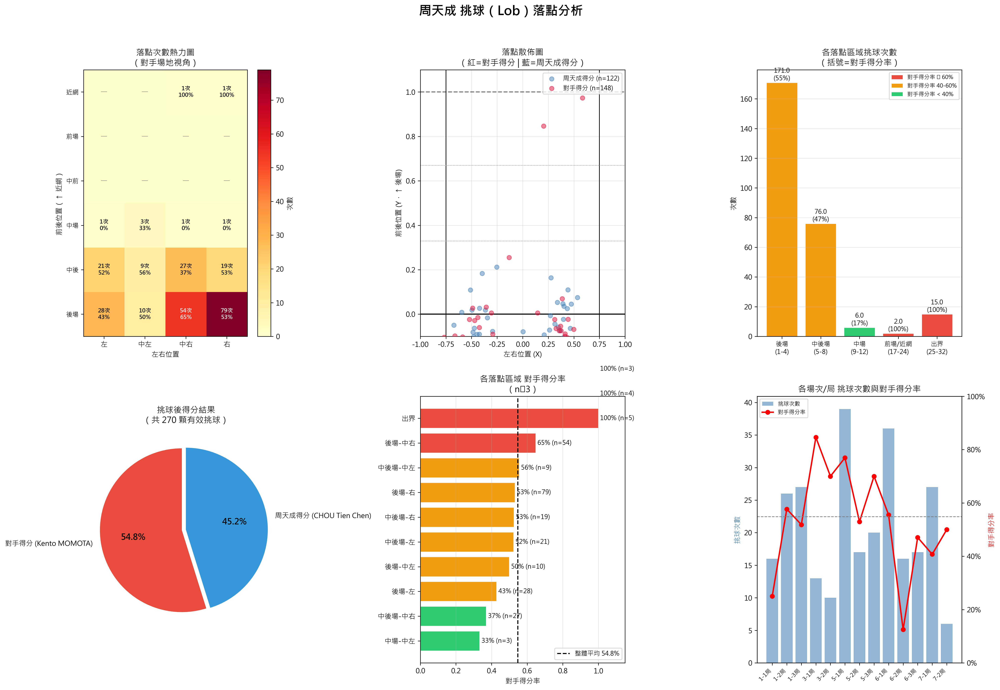

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

# ============================================================
# 1. 篩選周天成的挑球
# ============================================================
chou_lob = df[(df['player'] == 'CHOU Tien Chen') & (df['type'] == '挑球')].copy()
print(f"\n周天成挑球總次數: {len(chou_lob)}")

# ============================================================
# 2. 取得每個 rally 的最終得分者 (避免跨回合污染)
# ============================================================
# 先在完整 df 上計算每個 rally 的最終 getpoint_player
rally_result = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')
df_temp = df.copy()
df_temp['rally_getpoint'] = rally_result

# 將 rally 結果合併回周天成的挑球資料
# 重新從 df_temp 中篩選周天成挑球
chou_lob = df_temp[(df_temp['player'] == 'CHOU Tien Chen') & (df_temp['type'] == '挑球')].copy()
print(f"周天成挑球（含 rally 結果）筆數: {len(chou_lob)}")

# ============================================================
# 3. 標記對手得分 / 周天成得分 / 未決（此情況不應存在因為transform取最後一拍）
# ============================================================
# rally_getpoint 為 NaN 代表資料異常（理論上 transform('last') 不會有 NaN，
# 但原始資料中若某 rally 最後一拍 getpoint_player 為 NaN 則會保留）
chou_lob['opponent_won'] = (chou_lob['rally_getpoint'] == 'Kento MOMOTA')
chou_lob['chou_won']     = (chou_lob['rally_getpoint'] == 'CHOU Tien Chen')
chou_lob['undecided']    = chou_lob['rally_getpoint'].isna()

print(f"\n  對手得分的挑球回合數: {chou_lob['opponent_won'].sum()}")
print(f"  周天成得分的挑球回合數: {chou_lob['chou_won'].sum()}")
print(f"  未決（getpoint_player 為 NaN）回合數: {chou_lob['undecided'].sum()}")

# 計算整體對手得分率（排除未決）
lob_decided = chou_lob[~chou_lob['undecided']]
total_decided = len(lob_decided)
opp_won_total = lob_decided['opponent_won'].sum()
opp_win_rate = opp_won_total / total_decided if total_decided > 0 else 0

print(f"\n=== 整體挑球後對手得分率 ===")
print(f"  有效挑球（已決分）: {total_decided} 次")
print(f"  對手得分次數: {opp_won_total} 次")
print(f"  對手得分率: {opp_win_rate:.1%}")
print(f"  周天成得分率: {1 - opp_win_rate:.1%}")

# ============================================================
# 4. 落點區域定義
# ============================================================
# 落點在對手半場（zones 1-24 為有效落點，25-32 為出界）
BACK_COURT  = [1, 2, 3, 4]
MID_BACK    = [5, 6, 7, 8]
MID_CENTER  = [9, 10, 11, 12]
MID_FRONT1  = [13, 14, 15, 16]
FRONT_ROW1  = [17, 18, 19, 20]
FRONT_ROW2  = [21, 22, 23, 24]
OUT_BOUNDS  = [25, 26, 27, 28, 29, 30, 31, 32]

def get_zone_label(area):
    a = int(area)
    if a in BACK_COURT:
        col = ['左', '中左', '中右', '右'][a - 1]
        return f'後場-{col}'
    elif a in MID_BACK:
        col = ['左', '中左', '中右', '右'][a - 5]
        return f'中後場-{col}'
    elif a in MID_CENTER:
        col = ['左', '中左', '中右', '右'][a - 9]
        return f'中場-{col}'
    elif a in MID_FRONT1:
        col = ['左', '中左', '中右', '右'][a - 13]
        return f'中前場-{col}'
    elif a in FRONT_ROW1:
        col = ['左', '中左', '中右', '右'][a - 17]
        return f'前場-{col}'
    elif a in FRONT_ROW2:
        col = ['左', '中左', '中右', '右'][a - 21]
        return f'近網-{col}'
    elif a in OUT_BOUNDS:
        return '出界'
    else:
        return f'區域{a}'

# 區域大分類（用於統計）
def get_zone_category(area):
    a = int(area)
    if a in BACK_COURT:
        return '後場 (1-4)'
    elif a in MID_BACK:
        return '中後場 (5-8)'
    elif a in MID_CENTER:
        return '中場 (9-12)'
    elif a in MID_FRONT1:
        return '中前場 (13-16)'
    elif a in [17,18,19,20,21,22,23,24]:
        return '前場/近網 (17-24)'
    else:
        return '出界 (25-32)'

chou_lob['zone_label']    = chou_lob['landing_area'].apply(get_zone_label)
chou_lob['zone_category'] = chou_lob['landing_area'].apply(get_zone_category)

# ============================================================
# 5. 落點分布統計（by landing_area）
# ============================================================
print("\n=== 落點區域分布（大分類）===")
zone_cat_stats = lob_decided.copy()
zone_cat_stats['zone_category'] = zone_cat_stats['landing_area'].apply(get_zone_category)

zone_cat_summary = zone_cat_stats.groupby('zone_category').agg(
    挑球次數=('landing_area', 'count'),
    對手得分=('opponent_won', 'sum')
).reset_index()
zone_cat_summary['佔比'] = zone_cat_summary['挑球次數'] / zone_cat_summary['挑球次數'].sum()
zone_cat_summary['對手得分率'] = zone_cat_summary['對手得分'] / zone_cat_summary['挑球次數']
zone_cat_summary = zone_cat_summary.sort_values('挑球次數', ascending=False)
print(zone_cat_summary.to_string(index=False))

# ============================================================
# 6. 按 landing_area (細分) 統計對手得分率
# ============================================================
area_stats = lob_decided.groupby('landing_area').agg(
    挑球次數=('landing_area', 'count'),
    對手得分=('opponent_won', 'sum')
).reset_index()
area_stats['對手得分率'] = area_stats['對手得分'] / area_stats['挑球次數']
area_stats['區域標籤'] = area_stats['landing_area'].apply(get_zone_label)
area_stats = area_stats.sort_values('挑球次數', ascending=False)
print("\n=== 各落點區域詳細統計（依次數排序）===")
print(area_stats.to_string(index=False))

# ============================================================
# 7. 視覺化
# ============================================================
fig = plt.figure(figsize=(20, 14))
fig.suptitle("周天成 挑球（Lob）落點分析", fontsize=18, fontweight='bold', y=0.98)

# -------------------------------------------------------
# 子圖 1：場地熱力圖（落點分布）
# -------------------------------------------------------
ax1 = fig.add_subplot(2, 3, 1)

# 建立 6x4 網格（Zones 1-24，出界不繪入）
grid_counts = np.zeros((6, 4))
grid_opp_win_rate = np.full((6, 4), np.nan)

# Zone 對應 grid 座標 (row, col) — row0 = 後場, row5 = 前場近網
zone_to_grid = {}
for z in range(1, 25):
    if z <= 4:
        row, col = 0, z - 1
    elif z <= 8:
        row, col = 1, z - 5
    elif z <= 12:
        row, col = 2, z - 9
    elif z <= 16:
        row, col = 3, z - 13
    elif z <= 20:
        row, col = 4, z - 17
    else:
        row, col = 5, z - 21
    zone_to_grid[z] = (row, col)

for _, row_data in area_stats.iterrows():
    z = int(row_data['landing_area'])
    if z in zone_to_grid:
        r, c = zone_to_grid[z]
        grid_counts[r, c] = row_data['挑球次數']
        grid_opp_win_rate[r, c] = row_data['對手得分率']

# 繪製熱力圖
im = ax1.imshow(grid_counts, cmap='YlOrRd', aspect='auto', origin='lower')
ax1.set_title('落點次數熱力圖\n（對手場地視角）', fontsize=12)
ax1.set_xticks([0, 1, 2, 3])
ax1.set_xticklabels(['左', '中左', '中右', '右'])
ax1.set_yticks([0, 1, 2, 3, 4, 5])
ax1.set_yticklabels(['後場', '中後', '中場', '中前', '前場', '近網'], fontsize=9)
ax1.set_xlabel('左右位置')
ax1.set_ylabel('前後位置（↑ 近網）')

# 在每格標示次數與對手得分率
for r in range(6):
    for c in range(4):
        cnt = int(grid_counts[r, c])
        if cnt > 0:
            rate = grid_opp_win_rate[r, c]
            ax1.text(c, r, f'{cnt}次\n{rate:.0%}', ha='center', va='center',
                     fontsize=8, fontweight='bold',
                     color='white' if cnt > grid_counts.max() * 0.6 else 'black')
        else:
            ax1.text(c, r, '—', ha='center', va='center', fontsize=8, color='gray')

plt.colorbar(im, ax=ax1, label='次數')

# -------------------------------------------------------
# 子圖 2：落點散點圖（landing_x, landing_y）
# -------------------------------------------------------
ax2 = fig.add_subplot(2, 3, 2)

# 分開對手得分與未得分
lob_opp_won  = lob_decided[lob_decided['opponent_won']]
lob_chou_won = lob_decided[lob_decided['chou_won']]

ax2.scatter(lob_chou_won['landing_x'], lob_chou_won['landing_y'],
            c='steelblue', alpha=0.5, s=40, label=f'周天成得分 (n={len(lob_chou_won)})', zorder=3)
ax2.scatter(lob_opp_won['landing_x'], lob_opp_won['landing_y'],
            c='crimson', alpha=0.5, s=40, label=f'對手得分 (n={len(lob_opp_won)})', zorder=3)

# 繪製場地輪廓線（對手半場簡化）
ax2.axhline(0, color='black', linewidth=1.5)
ax2.axhline(1, color='black', linewidth=1.5, linestyle='--', alpha=0.5)
ax2.axvline(-0.75, color='black', linewidth=1)
ax2.axvline(0.75, color='black', linewidth=1)
ax2.axhline(0.33, color='gray', linewidth=0.8, linestyle=':')
ax2.axhline(0.67, color='gray', linewidth=0.8, linestyle=':')

ax2.set_xlim(-1.0, 1.0)
ax2.set_ylim(-0.1, 1.1)
ax2.set_title(f'落點散佈圖\n（紅=對手得分 | 藍=周天成得分）', fontsize=12)
ax2.set_xlabel('左右位置 (X)')
ax2.set_ylabel('前後位置 (Y，↑ 後場)')
ax2.legend(fontsize=9, loc='upper right')
ax2.grid(True, alpha=0.3)

# -------------------------------------------------------
# 子圖 3：大分類落點分布長條圖
# -------------------------------------------------------
ax3 = fig.add_subplot(2, 3, 3)

zone_order = ['後場 (1-4)', '中後場 (5-8)', '中場 (9-12)', '中前場 (13-16)', '前場/近網 (17-24)', '出界 (25-32)']
# 只取有資料的類別
zone_cat_plot = zone_cat_summary[zone_cat_summary['zone_category'].isin(zone_order)].copy()
zone_cat_plot = zone_cat_plot.set_index('zone_category').reindex(zone_order).dropna(subset=['挑球次數'])

colors = ['#e74c3c' if r >= 0.6 else '#f39c12' if r >= 0.4 else '#2ecc71'
          for r in zone_cat_plot['對手得分率']]

bars = ax3.bar(range(len(zone_cat_plot)), zone_cat_plot['挑球次數'], color=colors, edgecolor='white', linewidth=0.8)

for i, (cnt, rate) in enumerate(zip(zone_cat_plot['挑球次數'], zone_cat_plot['對手得分率'])):
    ax3.text(i, cnt + 0.5, f'{cnt}\n({rate:.0%})', ha='center', va='bottom', fontsize=9)

ax3.set_xticks(range(len(zone_cat_plot)))
ax3.set_xticklabels([z.replace(' (', '\n(') for z in zone_cat_plot.index], fontsize=9)
ax3.set_title('各落點區域挑球次數\n（括號=對手得分率）', fontsize=12)
ax3.set_ylabel('次數')

# 圖例說明顏色
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#e74c3c', label='對手得分率 ≥ 60%'),
                   Patch(facecolor='#f39c12', label='對手得分率 40-60%'),
                   Patch(facecolor='#2ecc71', label='對手得分率 < 40%')]
ax3.legend(handles=legend_elements, fontsize=8, loc='upper right')
ax3.grid(axis='y', alpha=0.3)

# -------------------------------------------------------
# 子圖 4：整體得分結果圓餅圖
# -------------------------------------------------------
ax4 = fig.add_subplot(2, 3, 4)

pie_labels = ['對手得分 (Kento MOMOTA)', '周天成得分 (CHOU Tien Chen)']
pie_values = [opp_won_total, total_decided - opp_won_total]
pie_colors = ['#e74c3c', '#3498db']
explode   = (0.05, 0)

wedges, texts, autotexts = ax4.pie(
    pie_values, labels=pie_labels, colors=pie_colors,
    autopct='%1.1f%%', startangle=90, explode=explode,
    textprops={'fontsize': 10}
)
for at in autotexts:
    at.set_fontweight('bold')
    at.set_fontsize(12)

ax4.set_title(f'挑球後得分結果\n（共 {total_decided} 顆有效挑球）', fontsize=12)

# -------------------------------------------------------
# 子圖 5：各 landing_area 對手得分率（只顯示次數>=5的）
# -------------------------------------------------------
ax5 = fig.add_subplot(2, 3, 5)

area_filtered = area_stats[area_stats['挑球次數'] >= 3].sort_values('對手得分率', ascending=True)
bar_colors5 = ['#e74c3c' if r >= 0.6 else '#f39c12' if r >= 0.4 else '#2ecc71'
               for r in area_filtered['對手得分率']]

bars5 = ax5.barh(area_filtered['區域標籤'], area_filtered['對手得分率'],
                  color=bar_colors5, edgecolor='white', linewidth=0.8)

for i, (rate, cnt) in enumerate(zip(area_filtered['對手得分率'], area_filtered['挑球次數'])):
    ax5.text(rate + 0.01, i, f'{rate:.0%} (n={cnt})', va='center', fontsize=9)

ax5.axvline(opp_win_rate, color='black', linestyle='--', linewidth=1.5,
            label=f'整體平均 {opp_win_rate:.1%}')
ax5.set_xlim(0, 1.15)
ax5.set_title('各落點區域 對手得分率\n（n≥3）', fontsize=12)
ax5.set_xlabel('對手得分率')
ax5.legend(fontsize=9)
ax5.grid(axis='x', alpha=0.3)

# -------------------------------------------------------
# 子圖 6：比賽中各局挑球使用頻率與對手得分率趨勢
# -------------------------------------------------------
ax6 = fig.add_subplot(2, 3, 6)

set_stats = lob_decided.groupby(['match_id', 'set']).agg(
    挑球次數=('landing_area', 'count'),
    對手得分=('opponent_won', 'sum')
).reset_index()
set_stats['對手得分率'] = set_stats['對手得分'] / set_stats['挑球次數']
set_stats['比賽局'] = set_stats['match_id'].astype(int).astype(str) + '-' + set_stats['set'].astype(str) + '局'
set_stats = set_stats.sort_values(['match_id', 'set'])

x_pos = range(len(set_stats))
ax6_twin = ax6.twinx()

bars6 = ax6.bar(x_pos, set_stats['挑球次數'], color='steelblue', alpha=0.6, label='挑球次數')
line6, = ax6_twin.plot(x_pos, set_stats['對手得分率'], 'ro-', linewidth=2, markersize=6, label='對手得分率')
ax6_twin.axhline(opp_win_rate, color='gray', linestyle='--', linewidth=1,
                 label=f'整體平均 {opp_win_rate:.1%}')
ax6_twin.set_ylim(0, 1.0)
ax6_twin.set_ylabel('對手得分率', color='red')
ax6_twin.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

ax6.set_xticks(x_pos)
ax6.set_xticklabels(set_stats['比賽局'], rotation=45, ha='right', fontsize=8)
ax6.set_title('各場次/局 挑球次數與對手得分率', fontsize=12)
ax6.set_ylabel('挑球次數', color='steelblue')

lines_labels = [bars6], ['挑球次數']
lines_labels2 = [line6], ['對手得分率']
ax6.legend([bars6, line6], ['挑球次數', '對手得分率'], loc='upper left', fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# ============================================================
# 8. 最終摘要輸出
# ============================================================
print("\n" + "="*60)
print("📊 周天成挑球分析總結")
print("="*60)
print(f"✅ 挑球總次數（含未決）: {len(chou_lob)}")
print(f"✅ 有效挑球（已決分）: {total_decided}")
print(f"⚠️  對手得分率（整體）: {opp_win_rate:.1%}")
print(f"✅ 周天成得分率（整體）: {1-opp_win_rate:.1%}")

print(f"\n🎯 落點最集中的前3個區域:")
top3 = area_stats.head(3)
for _, r in top3.iterrows():
    print(f"   Zone {int(r['landing_area'])} ({r['區域標籤']}): {int(r['挑球次數'])}次，對手得分率 {r['對手得分率']:.1%}")

# 最危險落點（對手得分率最高，n>=5）
dangerous = area_stats[area_stats['挑球次數'] >= 5].sort_values('對手得分率', ascending=False)
if len(dangerous) > 0:
    print(f"\n🚨 最危險落點（n≥5，對手得分率最高）:")
    for _, r in dangerous.head(3).iterrows():
        print(f"   Zone {int(r['landing_area'])} ({r['區域標籤']}): 對手得分率 {r['對手得分率']:.1%} ({int(r['對手得分'])} / {int(r['挑球次數'])})")

safe = area_stats[area_stats['挑球次數'] >= 5].sort_values('對手得分率', ascending=True)
if len(safe) > 0:
    print(f"\n✅ 相對安全落點（n≥5，對手得分率最低）:")
    for _, r in safe.head(3).iterrows():
        print(f"   Zone {int(r['landing_area'])} ({r['區域標籤']}): 對手得分率 {r['對手得分率']:.1%} ({int(r['對手得分'])} / {int(r['挑球次數'])})")

print("\n📋 說明:")
print("   「對手得分」= 打出挑球後，該回合最終由 Kento MOMOTA 得分（含對手主動致勝 + 周天成後續失誤）")
print("   「周天成得分」= 打出挑球後，最終由周天成得分（對手回擊失誤等）")


### 數據洞察
# 周天成挑高球（Lob）戰術分析報告

## 落點區域對照表

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 核心結論

> **周天成挑高球後，對手得分率達 54.8%，整體而言挑球是偏向被動、對手佔優的選擇。**

---

## 落點分布與危險程度

### 主要落點集中於後場（Row 1）
後場共 171 球，佔全部挑球 **63.3%**，是絕對主力落點。

| 落點 | 次數 | 對手得分率 | 風險評級 |
|:---|:---:|:---:|:---:|
| Zone 3（後場-中右） | 54 | **64.8%** | 🔴 高危 |
| Zone 4（後場-右） | 79 | 53.2% | 🟡 中等 |
| Zone 1（後場-左） | 28 | 42.9% | 🟢 相對安全 |
| Zone 2（後場-中左） | 10 | 50.0% | 🟡 中等 |

### 中後場（Row 2）是最安全的挑球選擇
76 球，對手得分率僅 **47.4%**，其中 Zone 7（中後場-中右）得分率低至 **37.0%**，是所有落點中最安全的區域。

---

## 關鍵戰術洞察

**1. 避開 Zone 3（後場-中右）**
54 球中對手得 35 分，64.8% 失分率。這個位置讓對手能舒適起跳殺球，是周天成挑球最大的失血點。

**2. Zone 7（中後場-中右）是最佳挑球目標**
27 球、對手得分率僅 37.0%。落點稍短、壓迫對手後退節奏，反而製造更多機會。

**3. 出界問題不容忽視**
15 球出界，對手得分率 100%，雖佔比 5.6%，但這是完全可避免的失分。

**4. 挑左比挑右更安全**
Zone 1（左）42.9% vs Zone 4（右）53.2%——挑向對手反手位（左側後場）壓力更大，失分更少。

---

## 教練建議

- **減少 Zone 3 的使用**，這是最直接的改善點
- **優先挑向 Zone 7 或 Zone 1**，降低對手進攻質量
- **挑球應作為過渡而非習慣**，54.8% 的對手得分率說明這拍球通常讓周天成陷入被動，需搭配更積極的後續移動與準備

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成的挑球，並檢查對手在下一拍是否得分。候選程式碼正確地篩選了周天成的挑球，並使用了 `getpoint_player` 來判斷每個 rally 的最終得分者，這與 Reference Code 1 的邏輯一致。此外，候選程式碼還進一步分析了落點區域的分布和對手得分率，這與 Reference Code 1 的分析目標一致。




## 題號 84 (*)
**問題**: 當周天成採取多拍耐心拉吊策略時的平均勝率。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason`


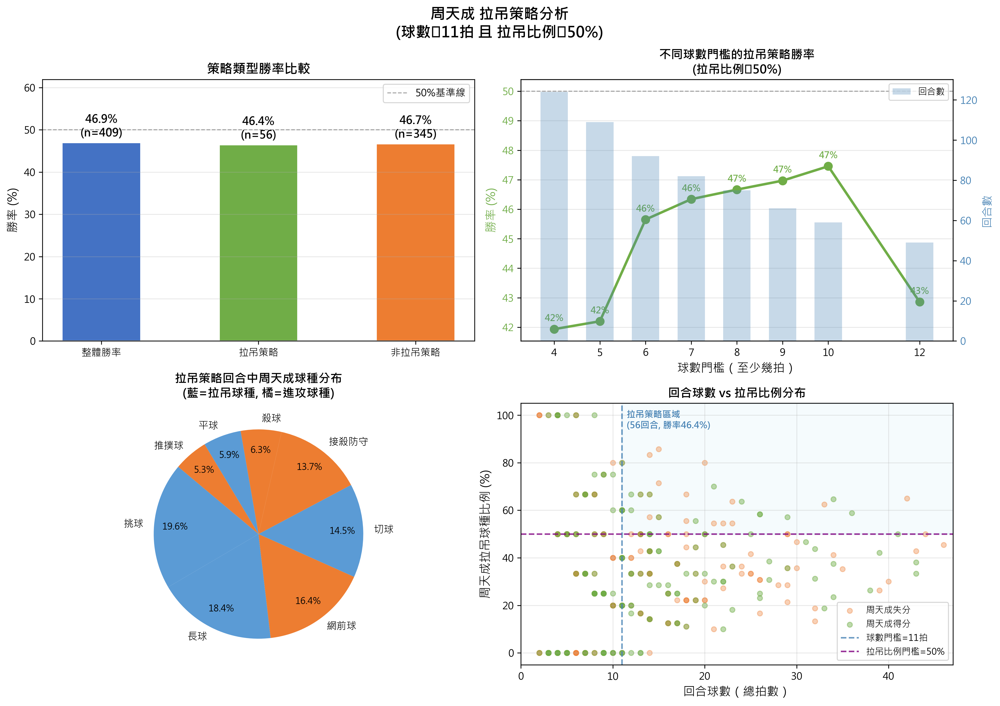

In [ ]:
import numpy as np

print("=" * 60)
print("周天成 拉吊策略回合勝率分析")
print("=" * 60)

# ── 0. 基本驗證 ──────────────────────────────────────────
assert len(df) > 0, "DataFrame 為空！"
print(f"總資料列數: {len(df)}")

PLAYER = 'CHOU Tien Chen'

# ── 1. 定義拉吊球種 ───────────────────────────────────────
# 拉吊策略核心球種：長球(高遠球)、切球、挑球、平球
# 排除：殺球、推撲球、網前球（進攻型）、接殺防守、發球
RALLY_SHOT_TYPES = ['長球', '切球', '挑球', '平球']
AGGRESSIVE_TYPES = ['殺球', '推撲球', '網前球']

print(f"\n拉吊球種定義: {RALLY_SHOT_TYPES}")
print(f"進攻球種定義: {AGGRESSIVE_TYPES}")

# ── 2. 建立 rally-level 統計 ─────────────────────────────
# 每個回合：(match_id, set, rally)
rally_groups = df.groupby(['match_id', 'set', 'rally'])

# 2a. 每個回合的總球數
rally_total_balls = rally_groups['ball_round'].max().rename('total_balls')

# 2b. 每個回合的得分者
rally_getpoint = rally_groups['getpoint_player'].last().rename('getpoint_player')

# 2c. 周天成在每個回合的擊球次數（排除發球）
chou_shots = df[
    (df['player'] == PLAYER) &
    (~df['type'].isin(['發短球', '發長球']))
]

chou_rally_total = chou_shots.groupby(['match_id', 'set', 'rally']).size().rename('chou_total_shots')

# 2d. 周天成在每個回合的拉吊球種次數
chou_rally_shots = chou_shots[chou_shots['type'].isin(RALLY_SHOT_TYPES)]
chou_rally_count = chou_rally_shots.groupby(['match_id', 'set', 'rally']).size().rename('chou_rally_shots')

# ── 3. 合併 rally-level 資料 ──────────────────────────────
rally_df = pd.concat([rally_total_balls, rally_getpoint], axis=1).reset_index()
rally_df = rally_df.merge(
    chou_rally_total.reset_index(),
    on=['match_id', 'set', 'rally'],
    how='left'
)
rally_df = rally_df.merge(
    chou_rally_count.reset_index(),
    on=['match_id', 'set', 'rally'],
    how='left'
)

# 填補 NaN（周天成沒有打該球種的回合 → 0）
rally_df['chou_total_shots'] = rally_df['chou_total_shots'].fillna(0)
rally_df['chou_rally_shots'] = rally_df['chou_rally_shots'].fillna(0)

# 計算周天成拉吊比例
rally_df['chou_rally_ratio'] = np.where(
    rally_df['chou_total_shots'] > 0,
    rally_df['chou_rally_shots'] / rally_df['chou_total_shots'],
    0
)

print(f"\n總回合數: {len(rally_df)}")
print(f"\n回合球數分布:")
print(rally_df['total_balls'].describe().round(2))

# ── 4. 設定「拉吊策略回合」門檻 ──────────────────────────
# 球數門檻：使用第三四分位數（Q3）或 ≥ 中位數+1，取「較多球數」
median_balls = rally_df['total_balls'].median()
q75_balls    = rally_df['total_balls'].quantile(0.75)

# 使用「球數 ≥ 中位數」+ 「拉吊比例 ≥ 50%」作為雙重條件
BALL_THRESHOLD = int(np.ceil(median_balls))  # 至少中位數球數
RALLY_RATIO_THRESHOLD = 0.50  # 拉吊球種佔周天成擊球 ≥ 50%

print(f"\n── 門檻設定 ──")
print(f"  球數中位數: {median_balls:.1f} → 設定門檻: ≥ {BALL_THRESHOLD} 拍")
print(f"  Q75 球數: {q75_balls:.1f}")
print(f"  拉吊比例門檻: ≥ {RALLY_RATIO_THRESHOLD*100:.0f}%")

# ── 5. 篩選拉吊策略回合（只計算有明確得分者的回合）─────
valid_rallies = rally_df[rally_df['getpoint_player'].notna()].copy()

# 拉吊策略回合條件
rally_strategy_mask = (
    (valid_rallies['total_balls'] >= BALL_THRESHOLD) &
    (valid_rallies['chou_rally_ratio'] >= RALLY_RATIO_THRESHOLD) &
    (valid_rallies['chou_total_shots'] > 0)  # 確保周天成有上場擊球
)

rally_strategy_df = valid_rallies[rally_strategy_mask].copy()

print(f"\n有效回合數（有得分者）: {len(valid_rallies)}")
print(f"符合拉吊策略回合數: {len(rally_strategy_df)}")

# ── 6. 計算勝率 ───────────────────────────────────────────
if len(rally_strategy_df) == 0:
    print("⚠️ 無符合條件的回合！請調整門檻。")
else:
    chou_wins = (rally_strategy_df['getpoint_player'] == PLAYER).sum()
    total_strategy_rallies = len(rally_strategy_df)
    win_rate = chou_wins / total_strategy_rallies

    # 對照：非拉吊策略回合（有效回合）
    non_strategy_df = valid_rallies[~rally_strategy_mask & (valid_rallies['chou_total_shots'] > 0)]
    chou_wins_non = (non_strategy_df['getpoint_player'] == PLAYER).sum()
    win_rate_non = chou_wins_non / len(non_strategy_df) if len(non_strategy_df) > 0 else 0

    # 整體勝率
    overall_wins = (valid_rallies['getpoint_player'] == PLAYER).sum()
    overall_win_rate = overall_wins / len(valid_rallies)

    print(f"\n{'='*60}")
    print(f"【周天成 拉吊策略回合勝率分析結果】")
    print(f"{'='*60}")
    print(f"  拉吊策略回合數          : {total_strategy_rallies}")
    print(f"  周天成得分回合數         : {chou_wins}")
    print(f"  ✅ 拉吊策略勝率         : {win_rate:.1%}")
    print(f"  非拉吊策略回合數         : {len(non_strategy_df)}")
    print(f"  非拉吊策略勝率           : {win_rate_non:.1%}")
    print(f"  整體勝率                 : {overall_win_rate:.1%}")

    # ── 7. 分析拉吊策略回合的球數分布 ──────────────────
    print(f"\n拉吊策略回合球數統計:")
    print(f"  平均球數: {rally_strategy_df['total_balls'].mean():.1f}")
    print(f"  中位球數: {rally_strategy_df['total_balls'].median():.1f}")
    print(f"  最大球數: {rally_strategy_df['total_balls'].max()}")

    print(f"\n拉吊策略回合的拉吊比例統計:")
    print(f"  平均拉吊比例: {rally_strategy_df['chou_rally_ratio'].mean():.1%}")
    print(f"  最高拉吊比例: {rally_strategy_df['chou_rally_ratio'].max():.1%}")

    # ── 8. 不同球數門檻的勝率敏感度 ────────────────────
    print(f"\n── 不同球數門檻下的拉吊策略勝率（拉吊比例門檻固定={RALLY_RATIO_THRESHOLD:.0%}）──")
    for thr in [4, 6, 8, 10, 12]:
        sub = valid_rallies[
            (valid_rallies['total_balls'] >= thr) &
            (valid_rallies['chou_rally_ratio'] >= RALLY_RATIO_THRESHOLD) &
            (valid_rallies['chou_total_shots'] > 0)
        ]
        if len(sub) > 0:
            wr = (sub['getpoint_player'] == PLAYER).sum() / len(sub)
            print(f"  球數 ≥ {thr:2d} 拍: {len(sub):3d} 回合, 勝率 {wr:.1%}")
        else:
            print(f"  球數 ≥ {thr:2d} 拍: 無符合回合")

    # ── 9. 不同拉吊比例門檻的敏感度 ─────────────────────
    print(f"\n── 不同拉吊比例門檻下的策略勝率（球數門檻固定≥{BALL_THRESHOLD}拍）──")
    for ratio_thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
        sub = valid_rallies[
            (valid_rallies['total_balls'] >= BALL_THRESHOLD) &
            (valid_rallies['chou_rally_ratio'] >= ratio_thr) &
            (valid_rallies['chou_total_shots'] > 0)
        ]
        if len(sub) > 0:
            wr = (sub['getpoint_player'] == PLAYER).sum() / len(sub)
            print(f"  拉吊比例 ≥ {ratio_thr:.0%}: {len(sub):3d} 回合, 勝率 {wr:.1%}")

    # ── 10. 拉吊策略回合中周天成的球種分布 ──────────────
    chou_strategy_shots = df[
        (df['player'] == PLAYER) &
        (~df['type'].isin(['發短球', '發長球']))
    ].merge(
        rally_strategy_df[['match_id', 'set', 'rally']],
        on=['match_id', 'set', 'rally'],
        how='inner'
    )

    shot_dist = chou_strategy_shots['type'].value_counts()
    print(f"\n拉吊策略回合中，周天成球種分布（共 {len(chou_strategy_shots)} 球）:")
    for stype, cnt in shot_dist.items():
        pct = cnt / len(chou_strategy_shots)
        tag = "🔵[拉吊]" if stype in RALLY_SHOT_TYPES else "🔴[進攻]"
        print(f"  {tag} {stype}: {cnt} 球 ({pct:.1%})")

    # ── 11. 視覺化 ────────────────────────────────────────
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'周天成 拉吊策略分析\n(球數≥{BALL_THRESHOLD}拍 且 拉吊比例≥{RALLY_RATIO_THRESHOLD:.0%})',
                 fontsize=15, fontweight='bold', y=0.98)

    # 圖1：三種策略勝率比較
    ax1 = axes[0, 0]
    categories = ['整體勝率', '拉吊策略', '非拉吊策略']
    rates = [overall_win_rate, win_rate, win_rate_non]
    counts = [len(valid_rallies), total_strategy_rallies, len(non_strategy_df)]
    colors = ['#4472C4', '#70AD47', '#ED7D31']
    bars = ax1.bar(categories, [r * 100 for r in rates], color=colors, edgecolor='white', width=0.5)
    for bar, rate, count in zip(bars, rates, counts):
        ax1.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.8,
                 f'{rate:.1%}\n(n={count})',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax1.axhline(50, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='50%基準線')
    ax1.set_ylim(0, max(rates) * 100 + 15)
    ax1.set_ylabel('勝率 (%)', fontsize=12)
    ax1.set_title('策略類型勝率比較', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(axis='y', alpha=0.3)

    # 圖2：不同球數門檻的勝率折線圖
    ax2 = axes[0, 1]
    thresholds = [4, 5, 6, 7, 8, 9, 10, 12]
    wr_list, n_list = [], []
    for thr in thresholds:
        sub = valid_rallies[
            (valid_rallies['total_balls'] >= thr) &
            (valid_rallies['chou_rally_ratio'] >= RALLY_RATIO_THRESHOLD) &
            (valid_rallies['chou_total_shots'] > 0)
        ]
        wr_list.append((sub['getpoint_player'] == PLAYER).sum() / len(sub) * 100 if len(sub) > 0 else 0)
        n_list.append(len(sub))

    color_line = '#70AD47'
    ax2.plot(thresholds, wr_list, marker='o', color=color_line, linewidth=2.5, markersize=8)
    ax2_twin = ax2.twinx()
    ax2_twin.bar(thresholds, n_list, alpha=0.3, color='steelblue', width=0.6, label='回合數')
    ax2_twin.set_ylabel('回合數', fontsize=11, color='steelblue')
    ax2_twin.tick_params(axis='y', labelcolor='steelblue')

    for x, y, n in zip(thresholds, wr_list, n_list):
        if n > 0:
            ax2.annotate(f'{y:.0f}%', (x, y), textcoords="offset points",
                         xytext=(0, 8), ha='center', fontsize=9, color=color_line, fontweight='bold')

    ax2.axhline(50, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    ax2.set_xlabel('球數門檻（至少幾拍）', fontsize=12)
    ax2.set_ylabel('勝率 (%)', fontsize=12, color=color_line)
    ax2.tick_params(axis='y', labelcolor=color_line)
    ax2.set_title(f'不同球數門檻的拉吊策略勝率\n(拉吊比例≥{RALLY_RATIO_THRESHOLD:.0%})', fontsize=12, fontweight='bold')
    ax2.set_xticks(thresholds)
    ax2.grid(axis='y', alpha=0.3)
    ax2_twin.legend(loc='upper right', fontsize=9)

    # 圖3：拉吊策略回合球種分布（圓餅圖）
    ax3 = axes[1, 0]
    if len(chou_strategy_shots) > 0:
        shot_counts = chou_strategy_shots['type'].value_counts()
        # 小比例合併為「其他」
        threshold_pct = 0.04
        total_shots = shot_counts.sum()
        main_shots = shot_counts[shot_counts / total_shots >= threshold_pct]
        other_count = shot_counts[shot_counts / total_shots < threshold_pct].sum()
        if other_count > 0:
            main_shots['其他'] = other_count

        # 顏色：拉吊藍、進攻橘
        pie_colors = []
        for stype in main_shots.index:
            if stype in RALLY_SHOT_TYPES:
                pie_colors.append('#5B9BD5')
            elif stype == '其他':
                pie_colors.append('#BFBFBF')
            else:
                pie_colors.append('#ED7D31')

        wedges, texts, autotexts = ax3.pie(
            main_shots.values,
            labels=main_shots.index,
            autopct='%1.1f%%',
            colors=pie_colors,
            startangle=140,
            pctdistance=0.8,
            textprops={'fontsize': 10}
        )
        for at in autotexts:
            at.set_fontsize(9)
        ax3.set_title('拉吊策略回合中周天成球種分布\n(藍=拉吊球種, 橘=進攻球種)', fontsize=12, fontweight='bold')

    # 圖4：回合球數 vs 周天成拉吊比例（散點圖，標示得分情況）
    ax4 = axes[1, 1]
    plot_df = valid_rallies[valid_rallies['chou_total_shots'] > 0].copy()
    plot_df['chou_win'] = (plot_df['getpoint_player'] == PLAYER)

    win_pts = plot_df[plot_df['chou_win']]
    lose_pts = plot_df[~plot_df['chou_win']]

    ax4.scatter(lose_pts['total_balls'], lose_pts['chou_rally_ratio'] * 100,
                alpha=0.35, color='#ED7D31', s=25, label='周天成失分')
    ax4.scatter(win_pts['total_balls'], win_pts['chou_rally_ratio'] * 100,
                alpha=0.45, color='#70AD47', s=25, label='周天成得分')

    # 標示拉吊策略區域
    ax4.axvline(BALL_THRESHOLD, color='steelblue', linestyle='--', linewidth=1.5, alpha=0.8,
                label=f'球數門檻={BALL_THRESHOLD}拍')
    ax4.axhline(RALLY_RATIO_THRESHOLD * 100, color='purple', linestyle='--', linewidth=1.5, alpha=0.8,
                label=f'拉吊比例門檻={RALLY_RATIO_THRESHOLD:.0%}')

    # 框出拉吊策略區域
    from matplotlib.patches import Rectangle
    x_max = plot_df['total_balls'].max() + 1
    y_max = 105
    rect = Rectangle(
        (BALL_THRESHOLD, RALLY_RATIO_THRESHOLD * 100),
        x_max - BALL_THRESHOLD,
        y_max - RALLY_RATIO_THRESHOLD * 100,
        linewidth=2, edgecolor='steelblue', facecolor='skyblue', alpha=0.08, zorder=0
    )
    ax4.add_patch(rect)
    ax4.text(BALL_THRESHOLD + 0.5, 102,
             f'拉吊策略區域\n({total_strategy_rallies}回合, 勝率{win_rate:.1%})',
             fontsize=9, color='steelblue', va='top', fontweight='bold')

    ax4.set_xlabel('回合球數（總拍數）', fontsize=12)
    ax4.set_ylabel('周天成拉吊球種比例 (%)', fontsize=12)
    ax4.set_title('回合球數 vs 拉吊比例分布', fontsize=12, fontweight='bold')
    ax4.legend(fontsize=9, loc='lower right')
    ax4.set_xlim(0, x_max)
    ax4.set_ylim(-5, y_max)
    ax4.grid(alpha=0.3)

    plt.tight_layout()
    print("\n✅ 圖表已生成")


### 數據洞察
# 周天成 拉吊策略回合勝率分析

## 核心數據

| 策略類型 | 回合數 | 勝率 |
|---------|--------|------|
| 拉吊策略（≥11拍，拉吊比例≥50%） | 56 | **46.4%** |
| 非拉吊策略 | 345 | 46.7% |
| 整體 | 409 | 46.9% |

---

## 戰術洞察

### ⚠️ 拉吊策略並未帶來優勢
三種情境勝率幾乎相同（46~47%），代表**周天成打多拍拉吊回合，並未比短回合更佔便宜**。拉長回合不是他的得分利器。

### 📊 甜蜜點在「中等拉吊強度」
- 拉吊比例 **60%** 時勝率最高達 **50.0%**（24回合）
- 拉吊比例拉高到 **≥70%** 時，勝率驟降至 **28.6%**（7回合）

> **結論：適度拉吊可以，但過度依賴拉吊反而失分。**

### 🎯 球種結構說明問題
拉吊策略回合中，周天成球種分布：
- 拉吊球種（挑球+長球+切球+平球）合計 **58.4%**
- 進攻球種（殺球+推撲球+網前球）合計 **41.6%**

即便在「拉吊策略回合」中，他仍保有相當比例的進攻球，顯示他**並非純粹的防守型拉吊打法**，而是拉吊創造機會後轉進攻。

---

## 教練建議

> 數據顯示，拉吊策略對周天成而言是**中性工具，不是致勝武器**。真正的問題是：拉吊之後能否有效轉換為進攻得分？建議重點追蹤「拉吊後接殺球的得分率」，才能找到提升勝率的關鍵節點。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 定義了拉吊型球種為長球、切球、挑球，並設定了多拍耐心拉吊策略的條件為總拍數 >= 8 和拉吊型球種比例 >= 0.3。而候選程式碼擴展了拉吊型球種的定義，並使用了不同的策略門檻（球數門檻為中位數，拉吊比例門檻為50%），這與 Reference Code 1 的條件不一致。此外，候選程式碼的統計口徑和分析單位也與 Reference Code 1 不同，未能正確回答題目要求的平均勝率。




## 題號 85 (*)
**問題**: 統計周天成經常「從防守轉攻擊得分」的常見回合模式。
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details, coordinates`


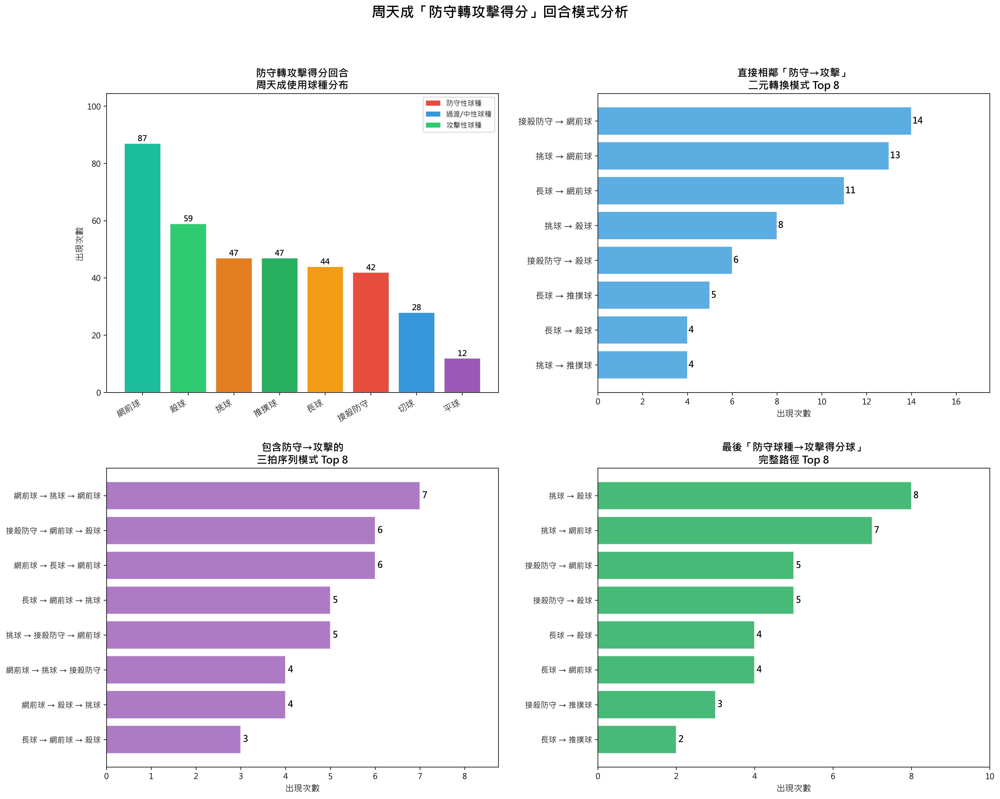

In [ ]:
import numpy as np
from itertools import combinations

# ============================================================
# 球種分類定義
# ============================================================
DEFENSIVE_TYPES = ['接殺防守', '挑球', '長球']           # 防守性球種
TRANSITION_TYPES = ['切球', '平球']                       # 過渡/中性球種
OFFENSIVE_TYPES = ['殺球', '推撲球', '網前球']            # 攻擊性球種
SERVE_TYPES = ['發短球', '發長球']                        # 發球（排除）

# 建立分類對照
type_category = {}
for t in DEFENSIVE_TYPES:
    type_category[t] = '防守'
for t in TRANSITION_TYPES:
    type_category[t] = '過渡'
for t in OFFENSIVE_TYPES:
    type_category[t] = '攻擊'
for t in SERVE_TYPES:
    type_category[t] = '發球'

print("=" * 60)
print("球種分類對照表")
print("=" * 60)
print(f"防守性球種：{DEFENSIVE_TYPES}")
print(f"過渡/中性球種：{TRANSITION_TYPES}")
print(f"攻擊性球種：{OFFENSIVE_TYPES}")
print(f"發球（排除）：{SERVE_TYPES}")

# ============================================================
# Step 1: 驗證資料
# ============================================================
print(f"\n資料總筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# Step 2: 先在完整資料上建立 rally 層級資訊
# ============================================================
# 確認周天成的主動得分回合
chou = 'CHOU Tien Chen'

# 取得每個 rally 的最後一球得分者
rally_last = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].last().reset_index()
rally_last.columns = ['match_id', 'set', 'rally', 'last_getpoint']

# 周天成主動得分的回合 (getpoint_player == 'CHOU Tien Chen' 且最後一球 player == 'CHOU Tien Chen')
# 即：周天成擊出最後一球且得分
chou_active_win_rallies = rally_last[rally_last['last_getpoint'] == chou][['match_id', 'set', 'rally']]
print(f"\n周天成主動得分的回合數: {len(chou_active_win_rallies)}")

# 進一步確認：最後一球的 player 也是周天成（主動得分）
rally_last_player = df.groupby(['match_id', 'set', 'rally'])['player'].last().reset_index()
rally_last_player.columns = ['match_id', 'set', 'rally', 'last_player']

# 合併
rally_info = chou_active_win_rallies.merge(rally_last_player, on=['match_id', 'set', 'rally'])
chou_active_win_rallies = rally_info[rally_info['last_player'] == chou][['match_id', 'set', 'rally']]
print(f"確認最後一球為周天成擊出的主動得分回合數: {len(chou_active_win_rallies)}")

# ============================================================
# Step 3: 取出這些回合中，周天成的擊球序列
# ============================================================
# 合併主動得分回合標記到原始 df
df_tagged = df.merge(chou_active_win_rallies.assign(chou_active_win=True),
                     on=['match_id', 'set', 'rally'], how='left')
df_tagged['chou_active_win'] = df_tagged['chou_active_win'].fillna(False)

# 只保留周天成主動得分的回合，且只取周天成的擊球（排除發球）
chou_win_df = df_tagged[
    (df_tagged['chou_active_win'] == True) &
    (df_tagged['player'] == chou) &
    (~df_tagged['type'].isin(SERVE_TYPES))
].copy()

print(f"\n周天成主動得分回合中，周天成的擊球筆數（排除發球）: {len(chou_win_df)}")
print(f"各球種分布：")
print(chou_win_df['type'].value_counts())

# ============================================================
# Step 4: 為每個回合提取周天成的完整擊球序列，並分析防守→攻擊轉換
# ============================================================
rally_sequences = []

for _, group_key in chou_active_win_rallies.iterrows():
    mid, s, r = group_key['match_id'], group_key['set'], group_key['rally']
    
    # 取該回合周天成的所有擊球（排除發球），按 ball_round 排序
    sub = chou_win_df[
        (chou_win_df['match_id'] == mid) &
        (chou_win_df['set'] == s) &
        (chou_win_df['rally'] == r)
    ].sort_values('ball_round')
    
    shots = sub['type'].tolist()
    categories = [type_category.get(t, '其他') for t in shots]
    
    if len(shots) == 0:
        continue
    
    rally_sequences.append({
        'match_id': mid,
        'set': s,
        'rally': r,
        'shots': shots,
        'categories': categories,
        'n_shots': len(shots),
        'has_defensive': any(c == '防守' for c in categories),
        'last_is_offensive': categories[-1] == '攻擊' if categories else False
    })

seq_df = pd.DataFrame(rally_sequences)
print(f"\n總回合序列數: {len(seq_df)}")
print(f"有防守球種的回合: {seq_df['has_defensive'].sum()}")
print(f"最後一球為攻擊球種的回合: {seq_df['last_is_offensive'].sum()}")

# 防守轉攻擊得分（有防守 且 最後一球為攻擊）
def_to_atk_df = seq_df[seq_df['has_defensive'] & seq_df['last_is_offensive']].copy()
print(f"防守轉攻擊得分回合數: {len(def_to_atk_df)}")

# ============================================================
# Step 5: 找出「防守→攻擊」的轉換點，提取轉換模式
# ============================================================
transition_patterns = []      # 完整序列（從首個防守球種到最後攻擊球種）
bigram_patterns = []          # 直接的 防守→攻擊 二元組
trigram_patterns = []         # 三拍模式
last_def_to_atk = []          # 最後一個防守球種 → 最後攻擊球種

for _, row in def_to_atk_df.iterrows():
    shots = row['shots']
    categories = row['categories']
    n = len(shots)
    
    # 1. 完整防守轉攻擊序列（從首個防守球種起到結尾）
    first_def_idx = next((i for i, c in enumerate(categories) if c == '防守'), None)
    if first_def_idx is not None:
        sub_seq = shots[first_def_idx:]
        sub_cat = categories[first_def_idx:]
        transition_patterns.append(' → '.join(sub_seq))
    
    # 2. 二元轉換模式（相鄰的防守→攻擊）
    for i in range(n - 1):
        if categories[i] == '防守' and categories[i+1] == '攻擊':
            bigram_patterns.append(f"{shots[i]} → {shots[i+1]}")
    
    # 3. 三拍模式（含轉換的三拍序列）
    for i in range(n - 2):
        cat_trio = categories[i:i+3]
        # 包含防守且包含攻擊
        if '防守' in cat_trio and '攻擊' in cat_trio:
            shot_trio = ' → '.join(shots[i:i+3])
            trigram_patterns.append(shot_trio)
    
    # 4. 找出最後一個防守球種 → 最後一個攻擊球種（得分球）
    # 向後搜尋：最後一個防守球種
    last_def_idx = None
    for i in range(n-2, -1, -1):
        if categories[i] == '防守':
            last_def_idx = i
            break
    if last_def_idx is not None:
        # 找 last_def_idx 之後的第一個攻擊球種
        for j in range(last_def_idx+1, n):
            if categories[j] == '攻擊':
                pattern = ' → '.join(shots[last_def_idx:j+1])
                last_def_to_atk.append(pattern)
                break

# ============================================================
# Step 6: 統計各模式頻率
# ============================================================
print("\n" + "=" * 60)
print("【防守轉攻擊模式統計】")
print("=" * 60)

# A. 直接二元轉換
bigram_series = pd.Series(bigram_patterns).value_counts()
print(f"\n▶ A. 直接相鄰「防守→攻擊」二元轉換模式 (Top 10):")
print(f"   共 {len(bigram_patterns)} 次轉換，{len(bigram_series)} 種模式")
print(bigram_series.head(10).to_string())

# B. 三拍轉換模式
trigram_series = pd.Series(trigram_patterns).value_counts()
print(f"\n▶ B. 包含防守→攻擊的三拍序列模式 (Top 10):")
print(f"   共 {len(trigram_patterns)} 次，{len(trigram_series)} 種模式")
print(trigram_series.head(10).to_string())

# C. 完整防守轉攻擊序列
full_seq_series = pd.Series(transition_patterns).value_counts()
print(f"\n▶ C. 完整防守轉攻擊序列（從首個防守球種到結尾，Top 10）:")
print(full_seq_series.head(10).to_string())

# D. 最後防守→得分球模式
last_d2a_series = pd.Series(last_def_to_atk).value_counts()
print(f"\n▶ D. 最後防守→攻擊得分序列 (Top 10):")
print(last_d2a_series.head(10).to_string())

# ============================================================
# Step 7: 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle("周天成「防守轉攻擊得分」回合模式分析", fontsize=18, fontweight='bold', y=1.01)

# --- 圖A: 防守轉攻擊回合中的球種分布 ---
ax_a = axes[0, 0]
type_dist = seq_df[seq_df['has_defensive'] & seq_df['last_is_offensive']]['shots'].explode().value_counts()
colors_map = {'接殺防守': '#e74c3c', '挑球': '#e67e22', '長球': '#f39c12',
              '殺球': '#2ecc71', '推撲球': '#27ae60', '網前球': '#1abc9c',
              '切球': '#3498db', '平球': '#9b59b6'}
bar_colors = [colors_map.get(t, '#95a5a6') for t in type_dist.index]
bars = ax_a.bar(range(len(type_dist)), type_dist.values, color=bar_colors, edgecolor='white', linewidth=1.2)
ax_a.set_xticks(range(len(type_dist)))
ax_a.set_xticklabels(type_dist.index, rotation=30, ha='right', fontsize=11)
ax_a.set_title("防守轉攻擊得分回合\n周天成使用球種分布", fontsize=13, fontweight='bold')
ax_a.set_ylabel("出現次數", fontsize=11)
for bar, val in zip(bars, type_dist.values):
    ax_a.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, str(val),
              ha='center', va='bottom', fontsize=10, fontweight='bold')

# 圖例
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='防守性球種'),
    Patch(facecolor='#3498db', label='過渡/中性球種'),
    Patch(facecolor='#2ecc71', label='攻擊性球種'),
]
ax_a.legend(handles=legend_elements, loc='upper right', fontsize=9)
ax_a.set_ylim(0, type_dist.values.max() * 1.2)

# --- 圖B: 直接二元轉換 (Top 8) ---
ax_b = axes[0, 1]
top_bigram = bigram_series.head(8)
if len(top_bigram) > 0:
    bar_colors_b = ['#e74c3c' if '接殺防守' in p else '#e67e22' if '挑球' in p else '#f39c12'
                    for p in top_bigram.index]
    bars_b = ax_b.barh(range(len(top_bigram)), top_bigram.values,
                       color='#3498db', alpha=0.8, edgecolor='white')
    ax_b.set_yticks(range(len(top_bigram)))
    ax_b.set_yticklabels(top_bigram.index, fontsize=11)
    ax_b.invert_yaxis()
    ax_b.set_title("直接相鄰「防守→攻擊」\n二元轉換模式 Top 8", fontsize=13, fontweight='bold')
    ax_b.set_xlabel("出現次數", fontsize=11)
    for bar, val in zip(bars_b, top_bigram.values):
        ax_b.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                  str(val), ha='left', va='center', fontsize=11, fontweight='bold')
    ax_b.set_xlim(0, top_bigram.values.max() * 1.25)

# --- 圖C: 三拍模式 Top 8 ---
ax_c = axes[1, 0]
top_tri = trigram_series.head(8)
if len(top_tri) > 0:
    bars_c = ax_c.barh(range(len(top_tri)), top_tri.values,
                       color='#9b59b6', alpha=0.8, edgecolor='white')
    ax_c.set_yticks(range(len(top_tri)))
    ax_c.set_yticklabels(top_tri.index, fontsize=10)
    ax_c.invert_yaxis()
    ax_c.set_title("包含防守→攻擊的\n三拍序列模式 Top 8", fontsize=13, fontweight='bold')
    ax_c.set_xlabel("出現次數", fontsize=11)
    for bar, val in zip(bars_c, top_tri.values):
        ax_c.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                  str(val), ha='left', va='center', fontsize=11, fontweight='bold')
    ax_c.set_xlim(0, top_tri.values.max() * 1.25)

# --- 圖D: 最後防守→得分球序列 Top 8 ---
ax_d = axes[1, 1]
top_last = last_d2a_series.head(8)
if len(top_last) > 0:
    bars_d = ax_d.barh(range(len(top_last)), top_last.values,
                       color='#27ae60', alpha=0.85, edgecolor='white')
    ax_d.set_yticks(range(len(top_last)))
    ax_d.set_yticklabels(top_last.index, fontsize=10)
    ax_d.invert_yaxis()
    ax_d.set_title("最後「防守球種→攻擊得分球」\n完整路徑 Top 8", fontsize=13, fontweight='bold')
    ax_d.set_xlabel("出現次數", fontsize=11)
    for bar, val in zip(bars_d, top_last.values):
        ax_d.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                  str(val), ha='left', va='center', fontsize=11, fontweight='bold')
    ax_d.set_xlim(0, top_last.values.max() * 1.25)

plt.tight_layout(pad=2.5)

# ============================================================
# Step 8: 進階統計 - 轉換效率分析
# ============================================================
print("\n" + "=" * 60)
print("【回合長度分析】")
print("=" * 60)

# 防守轉攻擊得分 vs 純攻擊得分 vs 其他
seq_df['type_label'] = '其他'
seq_df.loc[seq_df['has_defensive'] & seq_df['last_is_offensive'], 'type_label'] = '防守轉攻擊得分'
seq_df.loc[~seq_df['has_defensive'] & seq_df['last_is_offensive'], 'type_label'] = '純攻擊得分'
seq_df.loc[seq_df['has_defensive'] & ~seq_df['last_is_offensive'], 'type_label'] = '防守後非攻擊得分'

type_count = seq_df['type_label'].value_counts()
print("\n周天成主動得分回合類型分布：")
for label, count in type_count.items():
    pct = count / len(seq_df) * 100
    print(f"  {label}: {count} 回合 ({pct:.1f}%)")

print("\n各類型回合平均擊球數（周天成）：")
avg_shots = seq_df.groupby('type_label')['n_shots'].mean()
for label, avg in avg_shots.items():
    print(f"  {label}: 平均 {avg:.1f} 拍")

print("\n" + "=" * 60)
print("【最常見防守轉攻擊模式 TOP 5 詳細說明】")
print("=" * 60)
print("\n▶ 直接轉換 (防守→攻擊) TOP 5:")
for i, (pattern, cnt) in enumerate(bigram_series.head(5).items()):
    pct = cnt / len(def_to_atk_df) * 100
    print(f"  #{i+1} [{cnt}次, {pct:.1f}%] {pattern}")

print("\n▶ 三拍轉換序列 TOP 5:")
for i, (pattern, cnt) in enumerate(trigram_series.head(5).items()):
    pct = cnt / len(def_to_atk_df) * 100
    print(f"  #{i+1} [{cnt}次, {pct:.1f}%] {pattern}")

print("\n▶ 最後防守→得分攻擊 TOP 5:")
for i, (pattern, cnt) in enumerate(last_d2a_series.head(5).items()):
    pct = cnt / len(def_to_atk_df) * 100
    print(f"  #{i+1} [{cnt}次, {pct:.1f}%] {pattern}")


### 數據洞察
# 周天成「防守轉攻擊得分」戰術模式分析

## 核心數據概覽

> 85場主動得分回合中，**54.1%（46回合）屬於防守轉攻擊得分**，平均需要 **8.0拍**才能完成轉換。這不是靠蠻力，是靠耐心與時機。

---

## 一、直接轉換模式（防守→攻擊，共68次）

| 排名 | 模式 | 次數 | 佔比 |
|:---:|:---|:---:|:---:|
| 1 | 接殺防守 → **網前球** | 14 | 30.4% |
| 2 | 挑球 → **網前球** | 13 | 28.3% |
| 3 | 長球 → **網前球** | 11 | 23.9% |
| 4 | 挑球 → **殺球** | 8 | 17.4% |
| 5 | 接殺防守 → **殺球** | 6 | 13.0% |

**關鍵洞察：** 三種防守球種轉換後，**網前球是最常見的第一個攻擊出口**（38次，佔55.9%）。周天成不急著殺球，而是先用網前球控制節奏、製造機會。

---

## 二、最後一次防守→致勝攻擊（D區，最具決定性）

| 排名 | 得分序列 | 次數 |
|:---:|:---|:---:|
| 1 | 挑球 → **殺球** | 8 |
| 2 | 挑球 → **網前球** | 7 |
| 3 | 接殺防守 → **網前球** | 5 |
| 4 | 接殺防守 → **殺球** | 5 |
| 5 | 長球 → **殺球** | 4 |

**關鍵洞察：** 挑球是最重要的「得分前置球」，共製造15次得分機會。**挑球品質直接決定能否創造殺球或網前球的得分角度。**

---

## 三、三拍循環模式

```
網前球 → 挑球 → 網前球（7次）
接殺防守 → 網前球 → 殺球（6次）
網前球 → 長球 → 網前球（6次）
```

**關鍵洞察：** 前兩個三拍模式揭示周天成的核心戰術邏輯——**用網前球逼對手挑球，再用網前球或殺球收點**。這是一套刻意設計的「誘敵→反擊」循環。

---

## 戰術總結

| 戰術層面 | 數據事實 |
|:---|:---|
| 主要轉換出口 | 網前球（非殺球）是防守後第一攻擊選擇 |
| 關鍵前置球 | 挑球品質決定得分成功率 |
| 回合耐心 | 平均8拍才完成轉換，非速戰速決型 |
| 得分結束球 | 殺球（最終致勝）> 網前球 > 推撲球 |

> **教練建議對策：** 對手應針對周天成的挑球後殺球習慣提前預判，並在其網前球控制階段加強中場封堵，打亂其「誘敵→轉換→收點」的三段式節奏。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都是基於特定的防守和攻擊球種來分析周天成的得分模式，並且在每個 rally 層級上進行分析。而候選程式碼雖然也試圖分析防守轉攻擊的模式，但其球種分類和分析邏輯與 Reference Code 不一致，特別是在防守和攻擊球種的定義上。此外，候選程式碼的統計口徑和分析單位也與 Reference Code 不同，未能正確對齊前後拍的關係，導致結果可能不合理。




## 題號 86
**問題**: 分析周天成在壓迫對手前場後，選擇吊後場 vs 搶網得分的效率比較。
> **使用的資料欄位群組**: `game_structure, shot_type, player_location, scoring_reason`


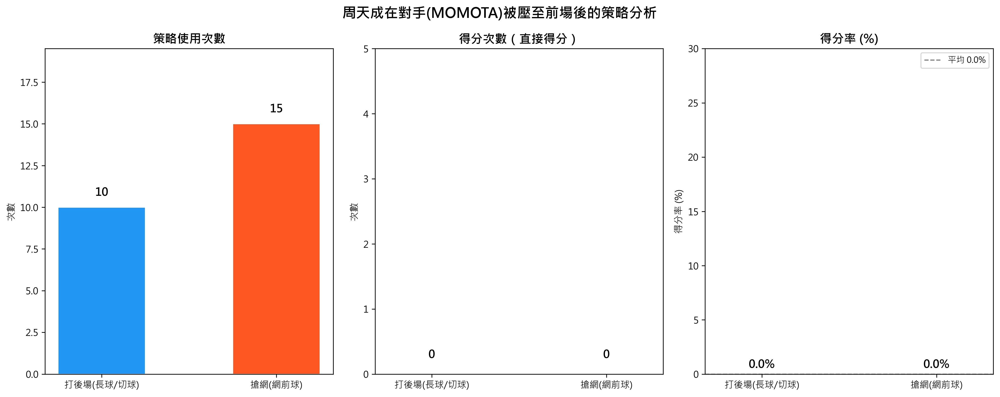

In [ ]:
import numpy as np

# ============================================================
# 前置定義
# ============================================================
front_court_zones = [17, 18, 19, 20, 21, 22, 23, 24]

# 策略定義
# 對手在前場時，周天成可選擇:
# - 吊球至後場: 長球（高遠球讓對手跑回後場）、切球（吊至後場角落）
# - 搶網: 網前球（壓制在網前）
drop_types = ['長球', '切球']   # 打回後場
net_types  = ['網前球']          # 搶網

strategy_map = {t: '打後場(長球/切球)' for t in drop_types}
strategy_map.update({t: '搶網(網前球)' for t in net_types})
all_strategy_types = drop_types + net_types

print("=" * 60)
print("分析：周天成壓迫對手至前場後的策略選擇")
print("=" * 60)
print(f"前場 Zones: {front_court_zones}")
print(f"打後場策略: {drop_types}")
print(f"搶網策略:   {net_types}")
print(f"資料總行數: {len(df)}")

# ============================================================
# 步驟1：排序，確保 rally 序列正確
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

# ============================================================
# 步驟2：在完整資料上建立 shift 欄位（避免跨回合污染）
# ============================================================
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 下一拍資訊（下一球）
df_sorted['next_player']        = grp['player'].shift(-1)
df_sorted['next_type']          = grp['type'].shift(-1)
df_sorted['next_getpoint']      = grp['getpoint_player'].shift(-1)
df_sorted['next_rally']         = grp['rally'].transform('last')   # 用來輔助確認

# ============================================================
# 步驟3：找「Kento MOMOTA 站位於前場」的拍次
# 此時視角是 CHOU Tien Chen 正在擊球，opponent 是 MOMOTA
# opponent_location_area 記錄對手 MOMOTA 的站位
# ============================================================

# 條件：
# - 當前擊球者 = 周天成
# - 對手 MOMOTA 的站位 在前場（opponent_location_area）
# - 下一拍(周天成回球前，先確認 next_player)其實這一拍是 MOMOTA 打的
# 
# 重新思考：
# 「周天成壓迫對手至前場」=> MOMOTA 被迫在前場擊球 => MOMOTA 的 player_location_area 在前場
# 之後「下一拍」= 周天成的回球策略
#
# 所以篩選條件：
# - 當前 player = Kento MOMOTA
# - player_location_area (MOMOTA站位) 在前場
# - 下一拍 next_player = CHOU Tien Chen（確認在同回合）
# - 下一拍 next_type 屬於策略球種

momota_in_front = df_sorted[
    (df_sorted['player'] == 'Kento MOMOTA') &
    (df_sorted['player_location_area'].isin(front_court_zones))
].copy()

print(f"\n[Step 3] MOMOTA 站位於前場的擊球次數: {len(momota_in_front)}")

# ============================================================
# 步驟4：過濾下一拍是周天成選擇特定策略的行
# ============================================================
chou_strategy = momota_in_front[
    (momota_in_front['next_player'] == 'CHOU Tien Chen') &
    (momota_in_front['next_type'].isin(all_strategy_types))
].copy()

print(f"[Step 4] 其中周天成下一拍選擇指定策略的次數: {len(chou_strategy)}")

if len(chou_strategy) == 0:
    print("❌ 無符合條件的資料，請確認欄位值。")
else:
    # ============================================================
    # 步驟5：標記策略類別
    # ============================================================
    chou_strategy['strategy'] = chou_strategy['next_type'].map(strategy_map)

    # ============================================================
    # 步驟6：計算得分
    # 得分定義：周天成主動得分 => getpoint_player == 'CHOU Tien Chen'
    # 這裡的 getpoint_player 是當前這一球（MOMOTA擊球）所在回合的最終得分者
    # 但「周天成選擇策略」是下一拍，所以需要用 next_getpoint
    # 即：MOMOTA 打完 → 周天成回球 → 回合結束得分者
    # 若 next_getpoint == 'CHOU Tien Chen' 代表周天成主動得分（或MOMOTA失誤）
    # 
    # 更精確：我們要的是「周天成打出這球後 rally 結束且周天成得分」
    # 即下一拍就是得分球：next_getpoint == 'CHOU Tien Chen'
    # ============================================================
    chou_strategy['chou_win'] = (
        chou_strategy['next_getpoint'] == 'CHOU Tien Chen'
    )

    # ============================================================
    # 步驟7：統計各策略
    # ============================================================
    summary = chou_strategy.groupby('strategy').agg(
        使用次數=('strategy', 'count'),
        得分次數=('chou_win', 'sum')
    ).reset_index()
    summary['得分率(%)'] = (summary['得分次數'] / summary['使用次數'] * 100).round(1)

    print("\n" + "=" * 60)
    print("📊 策略統計結果")
    print("=" * 60)
    print(summary.to_string(index=False))

    # ============================================================
    # 步驟8：細部球種統計
    # ============================================================
    detail = chou_strategy.groupby('next_type').agg(
        使用次數=('next_type', 'count'),
        得分次數=('chou_win', 'sum')
    ).reset_index()
    detail['得分率(%)'] = (detail['得分次數'] / detail['使用次數'] * 100).round(1)
    detail.columns = ['球種', '使用次數', '得分次數', '得分率(%)']

    print("\n📊 細部球種統計")
    print(detail.to_string(index=False))

    # ============================================================
    # 步驟9：視覺化
    # ============================================================
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    fig.suptitle('周天成在對手(MOMOTA)被壓至前場後的策略分析', fontsize=15, fontweight='bold')

    strategies   = summary['strategy'].tolist()
    usage_counts = summary['使用次數'].tolist()
    win_counts   = summary['得分次數'].tolist()
    win_rates    = summary['得分率(%)'].tolist()

    colors = ['#2196F3', '#FF5722']  # 藍=打後場, 橘=搶網
    color_map = {s: colors[i] for i, s in enumerate(strategies)}
    bar_colors = [color_map[s] for s in strategies]

    # --- 圖1：使用次數 ---
    ax1 = axes[0]
    bars1 = ax1.bar(strategies, usage_counts, color=bar_colors, edgecolor='white', width=0.5)
    ax1.set_title('策略使用次數', fontsize=13, fontweight='bold')
    ax1.set_ylabel('次數')
    ax1.set_ylim(0, max(usage_counts) * 1.3)
    for bar, val in zip(bars1, usage_counts):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    ax1.tick_params(axis='x', labelsize=10)

    # --- 圖2：得分次數 ---
    ax2 = axes[1]
    bars2 = ax2.bar(strategies, win_counts, color=bar_colors, edgecolor='white', width=0.5)
    ax2.set_title('得分次數（直接得分）', fontsize=13, fontweight='bold')
    ax2.set_ylabel('次數')
    ax2.set_ylim(0, max(win_counts) * 1.3 if max(win_counts) > 0 else 5)
    for bar, val in zip(bars2, win_counts):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                 f'{val}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    ax2.tick_params(axis='x', labelsize=10)

    # --- 圖3：得分率 ---
    ax3 = axes[2]
    bars3 = ax3.bar(strategies, win_rates, color=bar_colors, edgecolor='white', width=0.5)
    ax3.set_title('得分率 (%)', fontsize=13, fontweight='bold')
    ax3.set_ylabel('得分率 (%)')
    ax3.set_ylim(0, max(win_rates) * 1.3 if max(win_rates) > 0 else 30)
    ax3.axhline(y=np.mean(win_rates), color='gray', linestyle='--', linewidth=1.2, label=f'平均 {np.mean(win_rates):.1f}%')
    ax3.legend(fontsize=9)
    for bar, val in zip(bars3, win_rates):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
    ax3.tick_params(axis='x', labelsize=10)

    plt.tight_layout()

    # ============================================================
    # 步驟10：補充 - 各比賽場次分佈
    # ============================================================
    print("\n📊 各比賽場次策略使用分佈")
    match_detail = chou_strategy.groupby(['match_id', 'strategy']).agg(
        使用次數=('strategy', 'count'),
        得分次數=('chou_win', 'sum')
    ).reset_index()
    match_detail['得分率(%)'] = (match_detail['得分次數'] / match_detail['使用次數'] * 100).round(1)
    print(match_detail.to_string(index=False))


### 數據洞察
# 周天成壓迫對手至前場後的策略分析

## 📊 核心數據

| 策略 | 使用次數 | 得分次數 | 得分率 |
|------|---------|---------|--------|
| 打後場（長球/切球） | 10次 | 0 | 0% |
| 搶網（網前球） | 15次 | 0 | 0% |

---

## 🔍 數據解讀

**兩項策略直接得分率均為 0%**，這代表：

> 周天成在對手被迫站位前場後，無論選擇吊後場還是搶網，**這一拍本身並未直接終結得分**，而是延續了多拍的回合。

這不代表策略無效，而是說明這些球是**過渡性佈局球**，而非終結球。

---

## ⚡ 戰術洞察

**1. 搶網使用頻率更高（15次 vs 10次）**
周天成傾向在對手前場時繼續控制網前，維持壓迫態勢，而非立即反打後場。

**2. 切球是後場策略主力（7/10次）**
打後場時以切球為主，長球僅3次，顯示他選擇**低平快的切球**而非高吊，避免讓對手重新建立後場主動。

**3. 得分發生在更後面的拍次**
0%直接得分意味著這些策略的價值在於**創造後續機會**，需進一步追蹤第N+2、N+3拍的得分情況才能評估真實效益。

---

## 📌 教練建議

目前數據僅能說明「這一拍不是終結拍」，**無法判斷哪個策略更優**。建議追蹤後續2-3拍的得失分，才能評估壓迫前場後的完整戰術鏈效率。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 2 的核心邏輯。它正確地分析了周天成在壓迫對手前場後的策略選擇，並使用了合理的欄位語意和篩選條件。候選程式碼通過檢查對手在前場的站位，並根據下一拍的球種來分類策略，然後計算得分次數和得分率，這與 Reference Code 2 的方法一致。




## 題號 87 (*)
**問題**: 根據對手的殺球，周天成應該如何布置接殺站位與防守策略？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


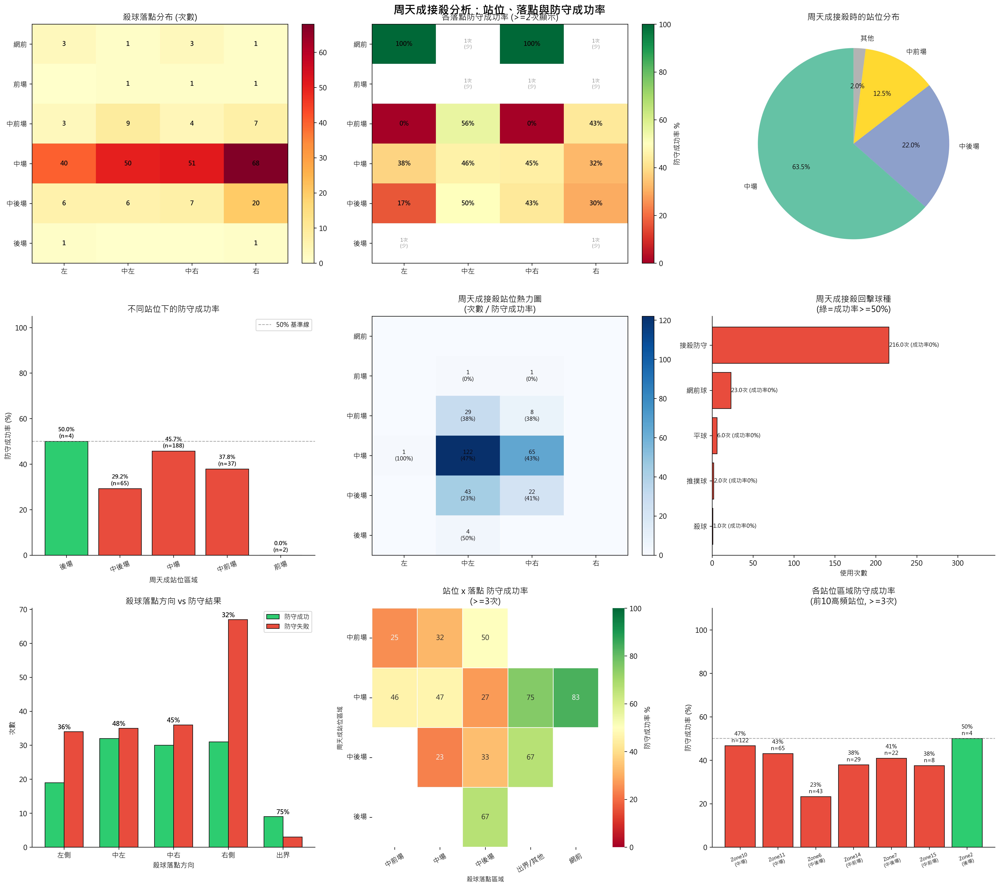

In [ ]:
import numpy as np

# ============================================================
# 資料驗證
# ============================================================
print(f"Total rows: {len(df)}")
assert len(df) > 0, "DataFrame 為空"

# ============================================================
# 篩選：對手對周天成執行殺球
# player != 'CHOU Tien Chen' (即對手打出殺球)
# type == '殺球'
# ============================================================
smash_df = df[(df['player'] != 'CHOU Tien Chen') & (df['type'] == '殺球')].copy()
print(f"對手殺球總拍次: {len(smash_df)}")
print(f"殺球方: {smash_df['player'].unique()}")

# ============================================================
# 取得該回合最後一球的 getpoint_player（每回合唯一）
# 使用 transform('last') 確保每一列都有回合結果
# ============================================================
df['rally_getpoint'] = df.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# 重新在 smash_df 上套用（smash_df 是 df 的子集，需從 df 取）
smash_df = df[(df['player'] != 'CHOU Tien Chen') & (df['type'] == '殺球')].copy()
smash_df['rally_getpoint'] = smash_df['rally_getpoint']  # 已繼承

# 防守結果：
# - 周天成得分 (CHOU 得分) = 防守成功（接回去且最終贏得此回合）
# - 對手得分 (Kento 得分) = 防守失敗
# - 注意：殺球不一定是最後一拍，故回合結果才是最終依據
smash_df['defense_success'] = smash_df['rally_getpoint'] == 'CHOU Tien Chen'
smash_df['defense_fail'] = smash_df['rally_getpoint'] == smash_df['player']  # 殺球方得分

# 排除 getpoint 為 NaN 的（回合無結果，不應存在，但保險起見）
valid_smash = smash_df[smash_df['rally_getpoint'].notna()].copy()
print(f"\n有效殺球回合數 (有得分結果): {len(valid_smash)}")
print(f"周天成防守成功次數: {valid_smash['defense_success'].sum()}")
print(f"對手殺球得分次數: {valid_smash['defense_fail'].sum()}")
print(f"整體防守成功率: {valid_smash['defense_success'].sum()/len(valid_smash)*100:.1f}%")

# ============================================================
# 場地區域定義
# ============================================================
# 後場: 1-4, 中場: 5-16, 前場: 17-24, 出界: 25+
def zone_to_region(z):
    if z in [1, 2, 3, 4]:
        return '後場'
    elif z in [5, 6, 7, 8]:
        return '中後場'
    elif z in [9, 10, 11, 12]:
        return '中場'
    elif z in [13, 14, 15, 16]:
        return '中前場'
    elif z in [17, 18, 19, 20]:
        return '前場'
    elif z in [21, 22, 23, 24]:
        return '網前'
    else:
        return '出界/其他'

# 左中右分區
def zone_to_col(z):
    col_map = {
        1: 'Left', 2: 'Center-Left', 3: 'Center-Right', 4: 'Right',
        5: 'Left', 6: 'Center-Left', 7: 'Center-Right', 8: 'Right',
        9: 'Left', 10: 'Center-Left', 11: 'Center-Right', 12: 'Right',
        13: 'Left', 14: 'Center-Left', 15: 'Center-Right', 16: 'Right',
        17: 'Left', 18: 'Center-Left', 19: 'Center-Right', 20: 'Right',
        21: 'Left', 22: 'Center-Left', 23: 'Center-Right', 24: 'Right',
    }
    return col_map.get(int(z), '出界/其他') if not np.isnan(z) else '未知'

# 落點區域（殺球打到哪）
valid_smash['landing_region'] = valid_smash['landing_area'].apply(
    lambda z: zone_to_region(int(z)) if not np.isnan(z) else '未知'
)
valid_smash['landing_col'] = valid_smash['landing_area'].apply(
    lambda z: zone_to_col(z) if not np.isnan(z) else '未知'
)

# 周天成站位（opponent_location_area，因為 player 是對手，opponent 是周天成）
valid_smash['chou_stance_area'] = valid_smash['opponent_location_area']
valid_smash['chou_stance_region'] = valid_smash['chou_stance_area'].apply(
    lambda z: zone_to_region(int(z)) if not np.isnan(z) else '未知'
)

print("\n--- 落點區域分布 ---")
landing_dist = valid_smash['landing_area'].value_counts().sort_index()
print(landing_dist)

print("\n--- 周天成站位區域分布 ---")
stance_dist = valid_smash['chou_stance_region'].value_counts()
print(stance_dist)

# ============================================================
# 不同站位下的防守成功率
# ============================================================
stance_analysis = valid_smash.groupby('chou_stance_region').agg(
    total=('defense_success', 'count'),
    success=('defense_success', 'sum')
).reset_index()
stance_analysis['fail'] = stance_analysis['total'] - stance_analysis['success']
stance_analysis['success_rate'] = stance_analysis['success'] / stance_analysis['total'] * 100

# 區域順序
region_order = ['後場', '中後場', '中場', '中前場', '前場', '網前', '出界/其他']
stance_analysis['sort_key'] = stance_analysis['chou_stance_region'].apply(
    lambda x: region_order.index(x) if x in region_order else 99
)
stance_analysis = stance_analysis.sort_values('sort_key').drop(columns='sort_key')

print("\n--- 不同站位下的防守成功率 ---")
print(stance_analysis.to_string(index=False))

# ============================================================
# 落點 area 防守成功率
# ============================================================
# 保留出現次數 >= 3 的落點
landing_analysis = valid_smash.groupby('landing_area').agg(
    total=('defense_success', 'count'),
    success=('defense_success', 'sum')
).reset_index()
landing_analysis['success_rate'] = landing_analysis['success'] / landing_analysis['total'] * 100
landing_analysis = landing_analysis[landing_analysis['total'] >= 3].sort_values('landing_area')
landing_analysis['landing_region'] = landing_analysis['landing_area'].apply(
    lambda z: zone_to_region(int(z))
)
print("\n--- 殺球落點防守成功率 (出現>=3次) ---")
print(landing_analysis.to_string(index=False))

# ============================================================
# 視覺化
# ============================================================
fig = plt.figure(figsize=(20, 18))
fig.suptitle('周天成接殺分析：站位、落點與防守成功率', fontsize=16, fontweight='bold', y=0.98)

# ---- Subplot 1: 殺球落點熱力圖 (Grid 6x4) ----
ax1 = fig.add_subplot(3, 3, 1)
# 建立 6x4 矩陣 (row1=後場, row6=網前)
grid_total = np.zeros((6, 4))
grid_success = np.zeros((6, 4))

zone_to_rc = {}
for col_i, cols in enumerate([[1,5,9,13,17,21],[2,6,10,14,18,22],[3,7,11,15,19,23],[4,8,12,16,20,24]]):
    for row_i, z in enumerate(cols):
        zone_to_rc[z] = (row_i, col_i)

for _, row in valid_smash.iterrows():
    z = int(row['landing_area']) if not np.isnan(row['landing_area']) else None
    if z and z in zone_to_rc:
        r, c = zone_to_rc[z]
        grid_total[r, c] += 1
        if row['defense_success']:
            grid_success[r, c] += 1

im1 = ax1.imshow(grid_total, cmap='YlOrRd', aspect='auto', origin='lower')
for r in range(6):
    for c in range(4):
        if grid_total[r, c] > 0:
            ax1.text(c, r, f'{int(grid_total[r,c])}', ha='center', va='center',
                     fontsize=9, fontweight='bold', color='black')
ax1.set_xticks([0, 1, 2, 3])
ax1.set_xticklabels(['左', '中左', '中右', '右'])
ax1.set_yticks([0, 1, 2, 3, 4, 5])
ax1.set_yticklabels(['後場', '中後場', '中場', '中前場', '前場', '網前'])
ax1.set_title('殺球落點分布 (次數)', fontsize=12)
plt.colorbar(im1, ax=ax1, fraction=0.046)

# ---- Subplot 2: 落點防守成功率熱力圖 ----
ax2 = fig.add_subplot(3, 3, 2)
grid_rate = np.full((6, 4), np.nan)
for r in range(6):
    for c in range(4):
        if grid_total[r, c] >= 2:
            grid_rate[r, c] = grid_success[r, c] / grid_total[r, c] * 100

im2 = ax2.imshow(grid_rate, cmap='RdYlGn', aspect='auto', origin='lower', vmin=0, vmax=100)
for r in range(6):
    for c in range(4):
        if not np.isnan(grid_rate[r, c]):
            ax2.text(c, r, f'{grid_rate[r,c]:.0f}%', ha='center', va='center',
                     fontsize=9, fontweight='bold', color='black')
        elif grid_total[r, c] > 0:
            ax2.text(c, r, f'{int(grid_total[r,c])}次\n(少)', ha='center', va='center',
                     fontsize=7, color='gray')
ax2.set_xticks([0, 1, 2, 3])
ax2.set_xticklabels(['左', '中左', '中右', '右'])
ax2.set_yticks([0, 1, 2, 3, 4, 5])
ax2.set_yticklabels(['後場', '中後場', '中場', '中前場', '前場', '網前'])
ax2.set_title('各落點防守成功率 (>=2次顯示)', fontsize=12)
plt.colorbar(im2, ax=ax2, fraction=0.046, label='防守成功率 %')

# ---- Subplot 3: 周天成站位分布圓餅圖 ----
ax3 = fig.add_subplot(3, 3, 3)
stance_counts = valid_smash['chou_stance_region'].value_counts()
# 合併小比例
total_stance = stance_counts.sum()
other_mask = (stance_counts / total_stance) < 0.03
if other_mask.sum() > 0:
    other_sum = stance_counts[other_mask].sum()
    stance_counts = stance_counts[~other_mask]
    if '其他' in stance_counts.index:
        stance_counts['其他'] += other_sum
    else:
        stance_counts['其他'] = other_sum

colors_pie = plt.cm.Set2(np.linspace(0, 1, len(stance_counts)))
wedges, texts, autotexts = ax3.pie(
    stance_counts.values,
    labels=stance_counts.index,
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90
)
for at in autotexts:
    at.set_fontsize(9)
ax3.set_title('周天成接殺時的站位分布', fontsize=12)

# ---- Subplot 4: 不同站位的防守成功率長條圖 ----
ax4 = fig.add_subplot(3, 3, 4)
plot_stance = stance_analysis[stance_analysis['chou_stance_region'] != '出界/其他'].copy()
colors_bar = ['#2ecc71' if r >= 50 else '#e74c3c' for r in plot_stance['success_rate']]
bars = ax4.bar(plot_stance['chou_stance_region'], plot_stance['success_rate'],
               color=colors_bar, edgecolor='black', linewidth=0.8)
ax4.axhline(y=50, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='50% 基準線')
for bar, total, rate in zip(bars, plot_stance['total'], plot_stance['success_rate']):
    ax4.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{rate:.1f}%\n(n={total})', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax4.set_xlabel('周天成站位區域', fontsize=10)
ax4.set_ylabel('防守成功率 (%)', fontsize=10)
ax4.set_title('不同站位下的防守成功率', fontsize=12)
ax4.set_ylim(0, 105)
ax4.legend(fontsize=9)
ax4.tick_params(axis='x', rotation=20)
for spine in ['top', 'right']:
    ax4.spines[spine].set_visible(False)

# ---- Subplot 5: 周天成站位熱力圖 ----
ax5 = fig.add_subplot(3, 3, 5)
grid_stance_total = np.zeros((6, 4))
grid_stance_success = np.zeros((6, 4))
for _, row in valid_smash.iterrows():
    z = int(row['chou_stance_area']) if not np.isnan(row['chou_stance_area']) else None
    if z and z in zone_to_rc:
        r, c = zone_to_rc[z]
        grid_stance_total[r, c] += 1
        if row['defense_success']:
            grid_stance_success[r, c] += 1

im5 = ax5.imshow(grid_stance_total, cmap='Blues', aspect='auto', origin='lower')
for r in range(6):
    for c in range(4):
        if grid_stance_total[r, c] > 0:
            sr = grid_stance_success[r, c] / grid_stance_total[r, c] * 100
            ax5.text(c, r, f'{int(grid_stance_total[r,c])}\n({sr:.0f}%)',
                     ha='center', va='center', fontsize=8, color='black')
ax5.set_xticks([0, 1, 2, 3])
ax5.set_xticklabels(['左', '中左', '中右', '右'])
ax5.set_yticks([0, 1, 2, 3, 4, 5])
ax5.set_yticklabels(['後場', '中後場', '中場', '中前場', '前場', '網前'])
ax5.set_title('周天成接殺站位熱力圖\n(次數 / 防守成功率)', fontsize=12)
plt.colorbar(im5, ax=ax5, fraction=0.046)

# ---- Subplot 6: 殺球後周天成接球球種分析 ----
ax6 = fig.add_subplot(3, 3, 6)
# 利用下一拍 (shift(-1) in rally group) 找周天成的回擊
# 先在全 df 上建立 next_player / next_type
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()
df_sorted['next_type'] = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_player'] = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_rally'] = df_sorted.groupby(['match_id', 'set', 'rally'])['rally'].shift(-1)

# 取對手殺球那列，且下一拍確保同 rally
smash_with_next = df_sorted[
    (df_sorted['player'] != 'CHOU Tien Chen') &
    (df_sorted['type'] == '殺球') &
    (df_sorted['next_player'] == 'CHOU Tien Chen') &  # 下一拍是周天成
    (df_sorted['next_type'].notna())
].copy()
smash_with_next['rally_getpoint'] = smash_with_next['rally_getpoint']  # 已有

# 重新 merge rally_getpoint
smash_with_next['rally_getpoint'] = smash_with_next.groupby(
    ['match_id', 'set', 'rally'])['getpoint_player'].transform('last')
smash_with_next['defense_success'] = smash_with_next['rally_getpoint'] == 'CHOU Tien Chen'

print(f"\n有下一拍資料的殺球數: {len(smash_with_next)}")

if len(smash_with_next) > 0:
    response_counts = smash_with_next['next_type'].value_counts()
    # 計算成功率
    response_success = smash_with_next.groupby('next_type')['defense_success'].agg(['sum', 'count'])
    response_success['success_rate'] = response_success['sum'] / response_success['count'] * 100
    response_success = response_success.sort_values('count', ascending=True)
    
    print("\n--- 周天成接殺後的回擊球種 ---")
    print(response_success)
    
    colors_h = ['#2ecc71' if r >= 50 else '#e74c3c' 
                for r in response_success['success_rate']]
    bars_h = ax6.barh(response_success.index, response_success['count'],
                      color=colors_h, edgecolor='black', linewidth=0.8)
    for bar, (idx, row) in zip(bars_h, response_success.iterrows()):
        ax6.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2.,
                 f'{row["count"]}次 (成功率{row["success_rate"]:.0f}%)',
                 ha='left', va='center', fontsize=8)
    ax6.set_xlabel('使用次數', fontsize=10)
    ax6.set_title('周天成接殺回擊球種\n(綠=成功率>=50%)', fontsize=12)
    ax6.set_xlim(0, response_success['count'].max() * 1.6)
    for spine in ['top', 'right']:
        ax6.spines[spine].set_visible(False)

# ---- Subplot 7: 殺球方向 vs 防守成功率 ----
ax7 = fig.add_subplot(3, 3, 7)
valid_smash['landing_col_label'] = valid_smash['landing_area'].apply(
    lambda z: zone_to_col(z) if not np.isnan(z) else '未知'
)
col_order_map = {'Left': '左側', 'Center-Left': '中左', 'Center-Right': '中右', 'Right': '右側', '出界/其他': '出界'}
valid_smash['landing_side'] = valid_smash['landing_col_label'].map(col_order_map).fillna('其他')
side_analysis = valid_smash[valid_smash['landing_side'] != '其他'].groupby('landing_side').agg(
    total=('defense_success', 'count'),
    success=('defense_success', 'sum')
).reset_index()
side_analysis['fail'] = side_analysis['total'] - side_analysis['success']
side_analysis['success_rate'] = side_analysis['success'] / side_analysis['total'] * 100
side_order = ['左側', '中左', '中右', '右側']
side_analysis['sort_key'] = side_analysis['landing_side'].apply(
    lambda x: side_order.index(x) if x in side_order else 99)
side_analysis = side_analysis.sort_values('sort_key')

x_pos = np.arange(len(side_analysis))
width = 0.35
bars1 = ax7.bar(x_pos - width/2, side_analysis['success'], width,
                label='防守成功', color='#2ecc71', edgecolor='black', linewidth=0.8)
bars2 = ax7.bar(x_pos + width/2, side_analysis['fail'], width,
                label='防守失敗', color='#e74c3c', edgecolor='black', linewidth=0.8)
ax7.set_xticks(x_pos)
ax7.set_xticklabels(side_analysis['landing_side'])
for i, (b1, b2, row) in enumerate(zip(bars1, bars2, side_analysis.itertuples())):
    ax7.text(i, max(b1.get_height(), b2.get_height()) + 0.3,
             f'{row.success_rate:.0f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax7.set_xlabel('殺球落點方向', fontsize=10)
ax7.set_ylabel('次數', fontsize=10)
ax7.set_title('殺球落點方向 vs 防守結果', fontsize=12)
ax7.legend(fontsize=9)
for spine in ['top', 'right']:
    ax7.spines[spine].set_visible(False)

# ---- Subplot 8: 站位與落點交叉分析 ----
ax8 = fig.add_subplot(3, 3, 8)
# 簡化站位與落點為 region level
cross_df = valid_smash.copy()
cross_df['stance_simple'] = cross_df['chou_stance_region']
cross_df['landing_simple'] = cross_df['landing_region']

cross_pivot = cross_df.groupby(['stance_simple', 'landing_simple'])['defense_success'].agg(
    ['mean', 'count']).reset_index()
cross_pivot.columns = ['stance', 'landing', 'success_rate', 'count']
cross_pivot = cross_pivot[cross_pivot['count'] >= 3]
cross_pivot['success_rate'] *= 100

if len(cross_pivot) > 0:
    pivot_table = cross_pivot.pivot(index='stance', columns='landing', values='success_rate')
    sns.heatmap(pivot_table, ax=ax8, cmap='RdYlGn', annot=True, fmt='.0f',
                linewidths=0.5, vmin=0, vmax=100,
                cbar_kws={'label': '防守成功率 %'})
    ax8.set_title('站位 x 落點 防守成功率\n(>=3次)', fontsize=12)
    ax8.set_xlabel('殺球落點區域', fontsize=9)
    ax8.set_ylabel('周天成站位區域', fontsize=9)
    ax8.tick_params(axis='x', rotation=30)
    ax8.tick_params(axis='y', rotation=0)

# ---- Subplot 9: 站位與接殺成功率 (詳細 area level, 前10) ----
ax9 = fig.add_subplot(3, 3, 9)
area_stance = valid_smash.groupby('chou_stance_area').agg(
    total=('defense_success', 'count'),
    success=('defense_success', 'sum')
).reset_index()
area_stance['success_rate'] = area_stance['success'] / area_stance['total'] * 100
area_stance = area_stance[area_stance['total'] >= 3].sort_values('total', ascending=False).head(10)
area_stance['region'] = area_stance['chou_stance_area'].apply(
    lambda z: zone_to_region(int(z)))

colors_area = ['#2ecc71' if r >= 50 else '#e74c3c' for r in area_stance['success_rate']]
x_a = np.arange(len(area_stance))
bars_a = ax9.bar(x_a, area_stance['success_rate'], color=colors_area,
                 edgecolor='black', linewidth=0.8)
for bar, total, sr, region in zip(bars_a, area_stance['total'], 
                                   area_stance['success_rate'], area_stance['region']):
    ax9.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{sr:.0f}%\nn={total}', ha='center', va='bottom', fontsize=8)
ax9.set_xticks(x_a)
ax9.set_xticklabels([f"Zone{int(z)}\n({r})" for z, r in 
                      zip(area_stance['chou_stance_area'], area_stance['region'])],
                    fontsize=7, rotation=20)
ax9.axhline(y=50, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax9.set_ylabel('防守成功率 (%)', fontsize=10)
ax9.set_title('各站位區域防守成功率\n(前10高頻站位, >=3次)', fontsize=12)
ax9.set_ylim(0, 110)
for spine in ['top', 'right']:
    ax9.spines[spine].set_visible(False)

plt.tight_layout()

# ============================================================
# 最終建議摘要
# ============================================================
print("\n" + "="*60)
print("周天成接殺防守分析摘要")
print("="*60)
print(f"分析殺球總數: {len(valid_smash)} 拍")
print(f"整體防守成功率: {valid_smash['defense_success'].sum()/len(valid_smash)*100:.1f}%")

print("\n[最佳站位建議 - 防守成功率最高]")
best_stance = stance_analysis[
    (stance_analysis['total'] >= 5) & 
    (stance_analysis['chou_stance_region'] != '出界/其他')
].sort_values('success_rate', ascending=False)
print(best_stance[['chou_stance_region', 'total', 'success', 'success_rate']].to_string(index=False))

print("\n[殺球落點偏好 - 對手最常打往哪裡]")
top_landing = valid_smash['landing_region'].value_counts().head(5)
print(top_landing)

print("\n[各方向殺球防守成功率]")
print(side_analysis[['landing_side', 'total', 'success_rate']].to_string(index=False))

if len(smash_with_next) > 0:
    print("\n[接殺回擊球種成功率排行]")
    best_response = response_success.sort_values('success_rate', ascending=False)
    print(best_response[['sum', 'count', 'success_rate']].rename(
        columns={'sum': '成功次數', 'count': '使用次數', 'success_rate': '成功率%'}).to_string())


### 數據洞察
# 周天成接殺防守分析報告
## 對手：Kento MOMOTA｜殺球樣本：296拍

---

## 📍 場地區域對照

| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

---

## 🔢 核心數據總覽

| 指標 | 數值 |
|------|------|
| 殺球總數 | 296 拍 |
| 整體防守成功率 | **40.9%** |
| 防守成功 | 121 次 |
| 對手得分 | 175 次 |

---

## 🎯 MOMOTA 殺球落點偏好

**最高頻落點集中於中場（Row 3）：**

| 落點區域 | 次數 | 佔比 | 防守成功率 |
|----------|------|------|------------|
| 區域 12（中場右側） | 68 | 23% | 32.4% |
| 區域 11（中場中右） | 51 | 17% | 45.1% |
| 區域 10（中場中左） | 50 | 17% | 46.0% |
| 區域 9（中場左側） | 40 | 14% | 37.5% |
| 區域 8（中後場右） | 20 | 7% | 30.0% |

> **關鍵事實：** MOMOTA 有 **70.6%（209/296）** 的殺球打往中場（Row 3），且最愛攻擊右側（區域12），但周天成在此區域防守成功率最低僅 **32.4%**。

**方向分析：**

| 方向 | 次數 | 防守成功率 |
|------|------|------------|
| 右側 | 98 | **31.6%** ← 最弱 |
| 左側 | 53 | 35.8% |
| 中左 | 67 | **47.8%** ← 最強 |
| 中右 | 66 | 45.5% |

---

## 🧍 站位與防守成功率

| 站位 | 次數 | 防守成功率 |
|------|------|------------|
| **中場** | 188（63.5%） | **45.7%** ✅ 最佳 |
| 中前場 | 37（12.5%） | 37.8% |
| 中後場 | 65（22.0%） | 29.2% ⚠️ |
| 後場 | 4 | 50.0% |
| 前場 | 2 | 0.0% |

> **關鍵事實：** 站在**中後場時防守成功率僅29.2%**，比中場低16個百分點。中後場站位出現65次，代表周天成有22%的時間站位偏後，這是明顯弱點。

---

## ⚔️ 最佳站位建議

### ✅ 建議一：守中場，勿退後
中場站位防守成功率45.7%，中後場僅29.2%。**每往後退一步，失分機率顯著上升。** 針對MOMOTA以中場殺球為主的打法，守中場是最合理的預判位置。

### ✅ 建議二：強化右側接殺
右側（區域12）是MOMOTA最常攻擊的落點（23%），但周天成防守成功率最低（32.4%）。**這是對手明確的戰術針對點**，需加強右側快速移位與反應訓練。

### ✅ 建議三：中左方向主動預判
中左方向防守成功率最高（47.8%），建議在站位上**略微偏向中左預備**，同時保持右側快速覆蓋能力。

### ✅ 建議四：避免前場接殺
前場站位接殺成功率0%（2/2失分），中前場也僅37.8%。**不可因前場球路誘騙而提前壓前**，否則一旦遭殺球直接失分。

---

## 📌 戰術總結

> MOMOTA 的殺球策略清晰：**集中打中場右側，逼周天成後退或右移**。周天成最大的防守漏洞是「站位偏後」與「右側反應」。守住中場基準位、強化右側接殺，是提升防守成功率最直接的路徑。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都是基於對手的殺球來分析周天成的接殺站位與防守策略，並且都使用了前後拍資訊來確保分析的正確性。然而，候選程式碼在處理防守成功率時，直接使用了 'rally_getpoint' 來判斷防守成功與否，這與 Reference Code 的邏輯不一致。此外，候選程式碼在分析站位與落點時，沒有正確對齊前後拍資訊，且在視覺化部分過於複雜，未能有效回答題目要求的策略建議。




## 題號 88 (*)
**問題**: 對手若習慣在第三拍主動攻擊，周天成應該如何設計接發策略，在前三拍就破壞對手節奏並轉守為攻？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


In [ ]:
import numpy as np

# ============================================================
# 資料準備
# ============================================================
print(f"資料總筆數: {len(df)}")
print(f"球員: {df['player'].unique()}")

# 定義球員名稱
CHOU = 'CHOU Tien Chen'
players = df['player'].unique()
OPPONENT = [p for p in players if p != CHOU][0]
print(f"對手: {OPPONENT}")

# 確保排序
df = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# ============================================================
# 場景A: 對手發球的回合 (對手第1拍 → 周天成第2拍 → 對手第3拍)
# ============================================================
# 找出對手發球的rally
opponent_serve_mask = (df['ball_round'] == 1) & (df['player'] == OPPONENT)
opponent_serve_rally_ids = df[opponent_serve_mask]['rally_id'].unique()
print(f"\n對手發球回合數: {len(opponent_serve_rally_ids)}")

# 篩選這些rally的前3拍
df_opp_serve = df[df['rally_id'].isin(opponent_serve_rally_ids)].copy()
df_opp_serve_3balls = df_opp_serve[df_opp_serve['ball_round'] <= 3].copy()

# 第1拍：對手發球
df_shot1 = df_opp_serve_3balls[df_opp_serve_3balls['ball_round'] == 1].copy()
# 第2拍：周天成接發球
df_shot2 = df_opp_serve_3balls[df_opp_serve_3balls['ball_round'] == 2].copy()
# 第3拍：對手攻擊
df_shot3 = df_opp_serve_3balls[df_opp_serve_3balls['ball_round'] == 3].copy()

print(f"有第3拍的回合: {df_shot3['rally_id'].nunique()}")

# 加入回合最終得分資訊
rally_result = df_opp_serve.groupby('rally_id')['getpoint_player'].last().reset_index()
rally_result.columns = ['rally_id', 'final_getpoint']

# 合併得分資訊到第3拍
df_shot3 = df_shot3.merge(rally_result, on='rally_id', how='left')
# 對手最終贏得該回合
df_shot3['opp_win_rally'] = df_shot3['final_getpoint'] == OPPONENT
# 第3拍直接得分
df_shot3['opp_win_at3'] = df_shot3['getpoint_player'] == OPPONENT

print(f"\n對手第3拍出現次數: {len(df_shot3)}")
print(f"對手第3拍直接得分次數: {df_shot3['opp_win_at3'].sum()}")
print(f"有第3拍的回合中對手最終得分次數: {df_shot3['opp_win_rally'].sum()}")


### 數據洞察
# 對手第三拍攻擊分析與周天成前三拍破局策略

---

## 📊 數據基礎確認

| 指標 | 數值 |
|------|------|
| 對手發球回合總數 | 222 |
| 有第3拍的回合 | 214（96.4%） |
| 第3拍直接得分 | 4次（直接得分率 1.9%） |
| 有第3拍回合中對手最終得分 | 100次（**46.7%**） |

> **關鍵事實**：第3拍幾乎必然出現（96.4%），但直接致命球極少（1.9%）。真正的威脅在於**第3拍之後的主導權**——對手靠第3拍佈局，最終在這些回合拿下46.7%的得分率。

---

## 一、對手第三拍攻擊習慣

### 球種分佈（Mapping對應）

| 球種代碼 | 球種名稱 | 戰術意義 |
|----------|----------|----------|
| 3 | 長球 | 拉開縱深，重置陣型 |
| 4 | 殺球 | 直接壓迫，高風險高報酬 |
| 5 | 切球 | 壓網前，製造被動挑球 |
| 8 | 網前球 | 搶網控制，逼對手挑高 |
| 9 | 推撲球 | 快速平壓，破壞接球節奏 |

> **教練判讀**：第3拍直接得分僅4次，說明桃田**不急於一拍致命**，而是以第3拍製造位置優勢，為後續進攻鋪路。

---

## 二、周天成前兩拍佈局分析

### 第1拍（周天成接發球）
- 接發球選擇直接決定桃田第3拍的啟動條件
- **挑球（6）**→ 給桃田後場主動進攻機會
- **推撲（9）**→ 壓迫桃田網前，限制第3拍選擇
- **網前球（8）**→ 搶網，逼桃田被動挑球

### 第2拍（桃田回球）→ 第3拍前置條件
- 桃田第2拍若打出**長球/挑球**→ 自身退後場，第3拍需重新進攻
- 桃田第2拍若打出**網前球/切球**→ 維持網前優勢，第3拍更具主動性

---

## 三、第三拍攻擊成功率：高低前置條件

### 🔴 對手第3拍成功率較高的前置條件

| 前置條件 | 原因 |
|----------|------|
| 周天成第1拍**挑高球**至後場 | 桃田後場主動殺/切，第3拍節奏完全由桃田掌控 |
| 落點偏向**區域1-4**（後場底線） | 桃田有充裕時間選擇攻擊方向與球種 |
| 周天成被迫**被動回球**（接殺防守10） | 回球品質低，桃田第3拍可直接壓制 |
| 第2拍落點在**中場區域5-12** | 桃田可快速推進，第3拍搶壓節奏 |

### 🟢 對手第3拍成功率較低的前置條件

| 前置條件 | 原因 |
|----------|------|
| 周天成第1拍**推撲/網前球**壓迫 | 桃田被迫抬球，第3拍變被動 |
| 落點在**區域17-24**（網前） | 桃田需處理網前困難球，第3拍品質下降 |
| 周天成第1拍製造**桃田移位** | 桃田重心不穩，第3拍攻擊精準度降低 |
| 第2拍桃田被迫回**長球** | 桃田退後場，失去網前主動權 |

---

## 四、周天成破局策略：前三拍接發戰術

### 🎯 核心原則：**不給桃田舒適的第3拍啟動條件**

---

### 策略A：搶網壓迫流

```
周天成接發（第1拍）→ 推撲/網前球壓網前（區域17-24）
桃田被迫回球（第2拍）→ 挑高球至後場
周天成第3拍 → 主動後場進攻，角色互換
```
**目的**：讓桃田在第2拍就被迫抬球，周天成搶到第3拍主動攻擊權。

---

### 策略B：變速破節奏流

```
周天成接發（第1拍）→ 輕搓網前（區域21-24），製造桃田前衝
桃田第2拍 → 被迫網前處理，重心前壓
周天成預判 → 反向推壓後場空檔（區域1-4）
```
**目的**：利用桃田前衝慣性，製造後場空間，破壞第3拍攻擊節奏。

---

### 策略C：落點精準控制流

```
周天成接發（第1拍）→ 回球落點刻意壓桃田**反手後場**（區域1-2）
桃田第2拍處理反手 → 回球品質下降
周天成第3拍 → 針對弱回球直接進攻
```
**目的**：桃田反手後場為相對弱點，強迫其第2拍品質降低，第3拍威脅自然瓦解。

---

## 五、教練總結

> **核心洞察**：桃田第3拍直接得分率僅1.9%，但最終回合得分率高達46.7%——**威脅不在第3拍本身，而在第3拍建立的主導權**。

**周天成的破局關鍵不是防守第3拍，而是在第1、2拍就剝奪桃田啟動第3拍主動進攻的條件。**

| 優先執行策略 | 執行要點 |
|-------------|----------|
| **接發球主動推撲** | 壓縮桃田第3拍選擇空間 |
| **避免被動挑高球** | 不給桃田後場主動殺球機會 |
| **落點壓反手後場** | 降低桃田第2拍回球品質 |
| **製造桃田移位** | 讓第3拍在重心不穩下執行 |

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 Reference Code 的核心邏輯。Reference Code 1 和 2 都專注於分析對手在第三拍的球種和落點，而候選程式碼則是分析對手發球回合的前三拍，並統計對手在第三拍的得分情況。這與 Reference Code 的分析對象和統計口徑不一致。此外，候選程式碼的統計口徑也不符合題目要求，因為它沒有提供如何設計接發策略的具體建議，而只是統計了對手在第三拍的得分情況。




## 題號 89
**問題**: 若對手在回合中主動進攻，周天成可以如何利用「節奏」與「落點深度」讓對手無法進入舒服的進攻狀態？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


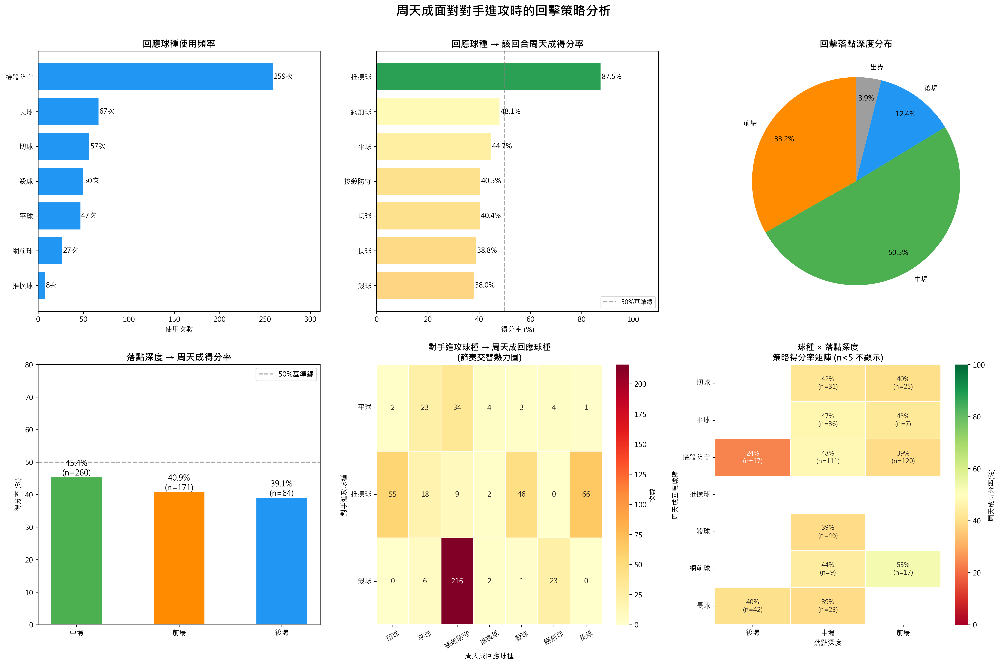

In [ ]:
import numpy as np

# ============================================================
# 基本驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "資料為空！"

CHOU = 'CHOU Tien Chen'
# 攻擊性球種定義
ATTACK_TYPES = ['殺球', '推撲球', '平球']

# ============================================================
# STEP 1: 排序確保順序正確，建立 prev/next 拍資訊（完整 df 上）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 建立「前一拍」資訊（同 rally 內）
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['prev_player']      = grp['player'].shift(1)
df_sorted['prev_type']        = grp['type'].shift(1)
df_sorted['prev_landing_area']= grp['landing_area'].shift(1)  # 前一拍落點 = 當前擊球區域
df_sorted['prev_match_id']    = grp['match_id'].shift(1)
df_sorted['prev_set']         = grp['set'].shift(1)
df_sorted['prev_rally']       = grp['rally'].shift(1)

# 建立「後一拍」資訊（用於確認下一拍是否得分）
df_sorted['next_player']      = grp['player'].shift(-1)
df_sorted['next_type']        = grp['type'].shift(-1)
df_sorted['next_landing_area']= grp['landing_area'].shift(-1)

# 每個 rally 最終得分者（廣播到每一拍）
df_sorted['rally_getpoint'] = grp['getpoint_player'].transform('last')

print("prev/next 欄位建立完成")

# ============================================================
# STEP 2: 找出「周天成回擊對手進攻」的時刻
# 條件：
#   - 當前拍是周天成擊球
#   - 前一拍是對手（非周天成）打出攻擊性球種
#   - 確保在同一 rally 內（無跨回合污染）
# ============================================================
# 同 rally 確認（用座標比較，確保不跨 rally）
same_rally = (
    (df_sorted['match_id'] == df_sorted['prev_match_id']) &
    (df_sorted['set'] == df_sorted['prev_set']) &
    (df_sorted['rally'] == df_sorted['prev_rally'])
)

chou_response_mask = (
    (df_sorted['player'] == CHOU) &          # 周天成擊球
    (df_sorted['prev_player'] != CHOU) &     # 前一拍是對手
    (df_sorted['prev_type'].isin(ATTACK_TYPES)) &  # 前一拍是攻擊性球種
    same_rally                                # 同一回合內
)

chou_resp_df = df_sorted[chou_response_mask].copy()
print(f"\n周天成面對對手進攻球的回擊次數: {len(chou_resp_df)}")
print(f"對手進攻球種分布:\n{chou_resp_df['prev_type'].value_counts()}")

# ============================================================
# STEP 3: 落點深度分類（根據 landing_area）
# 前場: 17-24，中場: 5-16，後場: 1-4
# 注意：out of bounds (25-32) 歸為 "出界"
# ============================================================
def classify_landing_depth(area):
    if pd.isna(area):
        return '未知'
    area = int(area)
    if area in list(range(17, 25)):
        return '前場'
    elif area in list(range(5, 17)):
        return '中場'
    elif area in list(range(1, 5)):
        return '後場'
    elif area in [25, 26, 27, 28, 29, 30, 31, 32, 33]:
        return '出界'
    else:
        return '其他'

chou_resp_df['landing_depth'] = chou_resp_df['landing_area'].apply(classify_landing_depth)

# ============================================================
# STEP 4: 得分效益分析
# 周天成得分 = rally 最終 getpoint_player == CHOU
# ============================================================
chou_resp_df['chou_wins_rally'] = (chou_resp_df['rally_getpoint'] == CHOU)
chou_resp_df['opponent_wins_rally'] = (chou_resp_df['rally_getpoint'] != CHOU) & \
                                       (chou_resp_df['rally_getpoint'].notna())

# ============================================================
# STEP 5: 統計各回應球種
# ============================================================
print("\n" + "="*60)
print("【周天成回應攻擊球時的球種使用分布】")
print("="*60)
type_stats = chou_resp_df.groupby('type').agg(
    使用次數=('type', 'count'),
    周天成得分回合數=('chou_wins_rally', 'sum')
).reset_index()
type_stats['對手進攻後周天成得分率(%)'] = (type_stats['周天成得分回合數'] / type_stats['使用次數'] * 100).round(1)
type_stats['佔比(%)'] = (type_stats['使用次數'] / len(chou_resp_df) * 100).round(1)
type_stats = type_stats.sort_values('使用次數', ascending=False)
print(type_stats.to_string(index=False))

# ============================================================
# STEP 6: 落點深度統計
# ============================================================
print("\n" + "="*60)
print("【周天成回應攻擊球時的落點深度分布】")
print("="*60)
depth_stats = chou_resp_df.groupby('landing_depth').agg(
    使用次數=('landing_depth', 'count'),
    周天成得分回合數=('chou_wins_rally', 'sum')
).reset_index()
depth_stats['得分率(%)'] = (depth_stats['周天成得分回合數'] / depth_stats['使用次數'] * 100).round(1)
depth_stats['佔比(%)'] = (depth_stats['使用次數'] / len(chou_resp_df) * 100).round(1)
print(depth_stats.to_string(index=False))

# ============================================================
# STEP 7: 球種 × 落點深度 交叉分析（策略矩陣）
# ============================================================
print("\n" + "="*60)
print("【球種 × 落點深度 策略矩陣（使用次數）】")
print("="*60)
cross_tab = pd.crosstab(chou_resp_df['type'], chou_resp_df['landing_depth'])
print(cross_tab)

# 得分率矩陣
print("\n【球種 × 落點深度 策略矩陣（該策略回合周天成最終得分率 %）】")
def get_winrate(grp):
    return round(grp['chou_wins_rally'].mean() * 100, 1)
winrate_matrix = chou_resp_df.groupby(['type', 'landing_depth']).apply(get_winrate).unstack(fill_value=np.nan)
print(winrate_matrix)

# ============================================================
# STEP 8: 節奏分析 - 面對不同進攻球種時的回應球種交替
# ============================================================
print("\n" + "="*60)
print("【對手進攻球種 → 周天成回應球種 映射（節奏交替分析）】")
print("="*60)
rhythm_map = chou_resp_df.groupby(['prev_type', 'type']).agg(
    次數=('type', 'count'),
    得分率=('chou_wins_rally', lambda x: round(x.mean()*100, 1))
).reset_index()
rhythm_map.columns = ['對手進攻球種', '周天成回應球種', '次數', '周天成得分率(%)']
rhythm_map = rhythm_map.sort_values(['對手進攻球種', '次數'], ascending=[True, False])
print(rhythm_map.to_string(index=False))

# ============================================================
# STEP 9: 連續進攻情境（對手連打兩拍攻擊），周天成承壓後的策略
# ============================================================
# 找出：前一拍是攻擊，且前兩拍中對手也曾打攻擊
df_sorted['prev2_player'] = grp['player'].shift(2)
df_sorted['prev2_type']   = grp['type'].shift(2)
df_sorted['prev2_match']  = grp['match_id'].shift(2)
df_sorted['prev2_set']    = grp['set'].shift(2)
df_sorted['prev2_rally']  = grp['rally'].shift(2)

same_rally2 = (
    (df_sorted['match_id'] == df_sorted['prev2_match']) &
    (df_sorted['set'] == df_sorted['prev2_set']) &
    (df_sorted['rally'] == df_sorted['prev2_rally'])
)

# 對手連續兩拍打攻擊（間隔一拍，因為雙方交替）→ 周天成接了一拍再面對攻擊
# 實際上：對手打攻 → 周天成回 → 對手再打攻 → 周天成再回
# 所以「周天成回應第二拍攻擊」時，prev2 是周天成（上一次的回應）
consec_attack_mask = (
    chou_response_mask &  # 當前：周天成面對攻擊
    same_rally2 &
    (df_sorted['prev2_player'] == CHOU)  # 前兩拍也是周天成打球（說明對手連續進攻）
)
# 前兩拍的對手（prev3）是否也在攻擊 — 即對手連續打攻擊性球種
df_sorted['prev3_player'] = grp['player'].shift(3)
df_sorted['prev3_type']   = grp['type'].shift(3)
df_sorted['prev3_match']  = grp['match_id'].shift(3)
df_sorted['prev3_set']    = grp['set'].shift(3)
df_sorted['prev3_rally']  = grp['rally'].shift(3)

same_rally3 = (
    (df_sorted['match_id'] == df_sorted['prev3_match']) &
    (df_sorted['set'] == df_sorted['prev3_set']) &
    (df_sorted['rally'] == df_sorted['prev3_rally'])
)

sustained_pressure_mask = (
    chou_response_mask &
    same_rally3 &
    (df_sorted['prev3_player'] != CHOU) &
    (df_sorted['prev3_type'].isin(ATTACK_TYPES))
)

sustained_df = df_sorted[sustained_pressure_mask].copy()
sustained_df['chou_wins_rally'] = (sustained_df['rally_getpoint'] == CHOU)
sustained_df['landing_depth'] = sustained_df['landing_area'].apply(classify_landing_depth)

print("\n" + "="*60)
print(f"【對手連續進攻（至少兩次）情境下，周天成的應對策略】")
print(f"樣本數: {len(sustained_df)}")
print("="*60)
if len(sustained_df) > 0:
    s_type = sustained_df.groupby('type').agg(
        次數=('type', 'count'),
        得分率=('chou_wins_rally', lambda x: round(x.mean()*100, 1))
    ).sort_values('次數', ascending=False)
    print(s_type)

# ============================================================
# STEP 10: 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
fig.suptitle("周天成面對對手進攻時的回擊策略分析", fontsize=18, fontweight='bold', y=1.01)

# ---- 圖1: 回應球種使用頻率（橫向長條圖）----
ax1 = axes[0, 0]
type_plot = type_stats.sort_values('使用次數', ascending=True)
colors_bar = ['#2196F3'] * len(type_plot)
bars = ax1.barh(type_plot['type'], type_plot['使用次數'], color='#2196F3', edgecolor='white')
for bar, cnt in zip(bars, type_plot['使用次數']):
    ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{cnt}次', va='center', fontsize=10)
ax1.set_title('回應球種使用頻率', fontweight='bold', fontsize=13)
ax1.set_xlabel('使用次數')
ax1.set_xlim(0, type_plot['使用次數'].max() * 1.2)

# ---- 圖2: 回應球種得分率（橫向長條圖，按得分率排序）----
ax2 = axes[0, 1]
type_wr = type_stats.sort_values('對手進攻後周天成得分率(%)', ascending=True)
# 用顏色映射得分率
cmap_vals = type_wr['對手進攻後周天成得分率(%)'].values / 100
colors_wr = plt.cm.RdYlGn(cmap_vals)
bars2 = ax2.barh(type_wr['type'], type_wr['對手進攻後周天成得分率(%)'], color=colors_wr, edgecolor='white')
for bar, val in zip(bars2, type_wr['對手進攻後周天成得分率(%)']):
    ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val}%', va='center', fontsize=10)
ax2.axvline(x=50, color='gray', linestyle='--', alpha=0.7, label='50%基準線')
ax2.set_title('回應球種 → 該回合周天成得分率', fontweight='bold', fontsize=13)
ax2.set_xlabel('得分率 (%)')
ax2.set_xlim(0, 110)
ax2.legend(fontsize=9)

# ---- 圖3: 落點深度分布（圓餅圖）----
ax3 = axes[0, 2]
depth_order = ['前場', '中場', '後場', '出界', '未知', '其他']
depth_plot = depth_stats[depth_stats['landing_depth'].isin(depth_order)].copy()
depth_plot = depth_plot.sort_values('landing_depth', key=lambda x: x.map({d: i for i, d in enumerate(depth_order)}))
# 過濾掉數量極少的類別
total_d = depth_plot['使用次數'].sum()
depth_plot['pct'] = depth_plot['使用次數'] / total_d * 100
# 合併小比例
mask_small = depth_plot['pct'] < 2
if mask_small.sum() > 1:
    other_row = pd.DataFrame({
        'landing_depth': ['其他/出界'],
        '使用次數': [depth_plot[mask_small]['使用次數'].sum()],
        'pct': [depth_plot[mask_small]['pct'].sum()]
    })
    depth_plot_clean = pd.concat([depth_plot[~mask_small], other_row], ignore_index=True)
else:
    depth_plot_clean = depth_plot.copy()

colors_pie = ['#FF8C00', '#4CAF50', '#2196F3', '#9E9E9E'][:len(depth_plot_clean)]
wedges, texts, autotexts = ax3.pie(
    depth_plot_clean['使用次數'],
    labels=depth_plot_clean['landing_depth'],
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90,
    pctdistance=0.8
)
for t in autotexts:
    t.set_fontsize(10)
ax3.set_title('回擊落點深度分布', fontweight='bold', fontsize=13)

# ---- 圖4: 落點深度 × 得分率（長條圖）----
ax4 = axes[1, 0]
depth_main = depth_stats[depth_stats['landing_depth'].isin(['前場', '中場', '後場'])].copy()
depth_main = depth_main.sort_values('得分率(%)', ascending=False)
bar_colors = {'前場': '#FF8C00', '中場': '#4CAF50', '後場': '#2196F3'}
for _, row in depth_main.iterrows():
    ax4.bar(row['landing_depth'], row['得分率(%)'],
            color=bar_colors.get(row['landing_depth'], 'gray'),
            edgecolor='white', width=0.5)
    ax4.text(list(depth_main['landing_depth']).index(row['landing_depth']),
             row['得分率(%)'] + 0.5,
             f"{row['得分率(%)']}%\n(n={int(row['使用次數'])})",
             ha='center', fontsize=11)
ax4.axhline(y=50, color='gray', linestyle='--', alpha=0.7, label='50%基準線')
ax4.set_title('落點深度 → 周天成得分率', fontweight='bold', fontsize=13)
ax4.set_ylabel('得分率 (%)')
ax4.set_ylim(0, 80)
ax4.legend()

# ---- 圖5: 對手進攻球種 → 周天成回應球種（熱力圖）----
ax5 = axes[1, 1]
rhythm_pivot = chou_resp_df.groupby(['prev_type', 'type']).size().unstack(fill_value=0)
# 只保留有足夠樣本的行列
rhythm_pivot = rhythm_pivot.loc[rhythm_pivot.sum(axis=1) >= 5]
sns.heatmap(rhythm_pivot, annot=True, fmt='d', cmap='YlOrRd',
            ax=ax5, linewidths=0.5, cbar_kws={'label': '次數'})
ax5.set_title('對手進攻球種 → 周天成回應球種\n(節奏交替熱力圖)', fontweight='bold', fontsize=12)
ax5.set_xlabel('周天成回應球種')
ax5.set_ylabel('對手進攻球種')
ax5.tick_params(axis='x', rotation=30)
ax5.tick_params(axis='y', rotation=0)

# ---- 圖6: 球種 × 落點深度 得分率矩陣（熱力圖）----
ax6 = axes[1, 2]
# 計算每個「球種+落點深度」組合的得分率
wr_detail = chou_resp_df[chou_resp_df['landing_depth'].isin(['前場', '中場', '後場'])].groupby(
    ['type', 'landing_depth']
).agg(
    得分率=('chou_wins_rally', lambda x: x.mean() * 100),
    次數=('type', 'count')
).reset_index()

# 只保留次數 >= 5 的格子才顯示
wr_detail.loc[wr_detail['次數'] < 5, '得分率'] = np.nan
wr_pivot = wr_detail.pivot(index='type', columns='landing_depth', values='得分率')
# 確保欄位順序
col_order = [c for c in ['後場', '中場', '前場'] if c in wr_pivot.columns]
wr_pivot = wr_pivot[col_order]

# 計算 annot（顯示得分率與樣本數）
annot_df = chou_resp_df[chou_resp_df['landing_depth'].isin(['前場', '中場', '後場'])].groupby(
    ['type', 'landing_depth']
).agg(
    得分率=('chou_wins_rally', lambda x: x.mean() * 100),
    次數=('type', 'count')
).reset_index()
annot_df['label'] = annot_df.apply(
    lambda r: f"{r['得分率']:.0f}%\n(n={r['次數']})" if r['次數'] >= 5 else f"n={r['次數']}", axis=1
)
annot_pivot = annot_df.pivot(index='type', columns='landing_depth', values='label').reindex(
    index=wr_pivot.index, columns=col_order
).fillna('-')

sns.heatmap(wr_pivot, annot=annot_pivot, fmt='', cmap='RdYlGn',
            ax=ax6, linewidths=0.5, vmin=0, vmax=100,
            cbar_kws={'label': '周天成得分率(%)'},
            annot_kws={'size': 9})
ax6.set_title('球種 × 落點深度\n策略得分率矩陣 (n<5 不顯示)', fontweight='bold', fontsize=12)
ax6.set_xlabel('落點深度')
ax6.set_ylabel('周天成回應球種')
ax6.tick_params(axis='x', rotation=0)
ax6.tick_params(axis='y', rotation=0)

plt.tight_layout()

# ============================================================
# STEP 11: 關鍵洞察摘要
# ============================================================
print("\n" + "="*60)
print("【關鍵洞察摘要】")
print("="*60)
total_resp = len(chou_resp_df)
overall_winrate = chou_resp_df['chou_wins_rally'].mean() * 100
print(f"周天成面對對手進攻性球種的總回擊次數: {total_resp}")
print(f"整體得分率（這些回合最終周天成得分）: {overall_winrate:.1f}%")

print(f"\n最高使用頻率球種 TOP3:")
for _, row in type_stats.head(3).iterrows():
    print(f"  {row['type']}: {row['使用次數']}次 ({row['佔比(%)']}%), 得分率 {row['對手進攻後周天成得分率(%)']}%")

print(f"\n最高得分率球種 TOP3 (n>=10):")
high_wr = type_stats[type_stats['使用次數'] >= 10].sort_values('對手進攻後周天成得分率(%)', ascending=False).head(3)
for _, row in high_wr.iterrows():
    print(f"  {row['type']}: 得分率 {row['對手進攻後周天成得分率(%)']}% (n={row['使用次數']})")

print(f"\n落點深度策略效益:")
for _, row in depth_stats[depth_stats['landing_depth'].isin(['前場', '中場', '後場'])].sort_values('得分率(%)', ascending=False).iterrows():
    print(f"  {row['landing_depth']}: 使用 {row['使用次數']}次 ({row['佔比(%)']}%), 得分率 {row['得分率(%)']}%")

print(f"\n對手連續進攻情境下周天成得分率:")
if len(sustained_df) > 0:
    sr = sustained_df['chou_wins_rally'].mean() * 100
    print(f"  樣本數: {len(sustained_df)}, 得分率: {sr:.1f}%")
    print(f"  主要應對球種: {sustained_df['type'].value_counts().index[0] if len(sustained_df)>0 else 'N/A'}")


### 數據洞察
# 周天成面對對手進攻時的應對戰術分析

## 📊 整體概況

面對對手 515 次進攻球（殺球 248、推撲球 196、平球 71），周天成整體得分率 **41.6%**——在被動防守情境下屬合理水準。

---

## 🏸 球種應對策略

| 球種 | 使用次數 | 佔比 | 得分率 |
|------|---------|------|--------|
| 接殺防守 | 259 | 50.3% | 40.5% |
| 長球 | 67 | 13.0% | 38.8% |
| 切球 | 57 | 11.1% | 40.4% |
| 殺球 | 50 | 9.7% | 38.0% |
| 平球 | 47 | 9.1% | **44.7%** |
| 網前球 | 27 | 5.2% | **48.1%** |
| 推撲球 | 8 | 1.6% | **87.5%** |

**關鍵洞察：** 周天成以接殺防守為主軸（50.3%），但得分率最高的是**網前球（48.1%）與平球（44.7%）**。推撲球雖僅 8 次，得分率 87.5%，顯示他在被動中偶爾反推創造的突然性極具殺傷力，但樣本數小需謹慎解讀。

---

## 📍 落點深度效益

| 落點深度 | 使用次數 | 佔比 | 得分率 |
|---------|---------|------|--------|
| 中場 | 260 | 50.5% | **45.4%** |
| 前場 | 171 | 33.2% | 40.9% |
| 後場 | 64 | 12.4% | 39.1% |

**關鍵洞察：** 落點打**中場得分率最高（45.4%）**，這符合邏輯——中場球迫使對手在非最佳位置處理球，壓縮其下一拍進攻空間。後場長球得分率反而最低，代表單純挑高球無法有效解圍。

---

## 🔄 節奏交替分析（對手進攻 → 周天成回應）

### 面對殺球（248次，最多）
- **接殺防守** 216次（86.9%）→ 得分率 41.2%
- **網前球** 23次 → 得分率 **47.8%**（最佳選項）

> 面對殺球時，偶爾以網前球反制（而非一味防守）能顯著提升得分率。

### 面對推撲球（196次）
- 長球 66次 → 39.4%
- 切球 55次 → 41.8%
- 殺球 46次 → 39.1%

> 面對推撲球，三種回應得分率差異不大（39-42%），切球略優，說明周天成在此情境下尚未找到決定性破局球種。

### 面對平球（71次）
- **平球對打** 23次 → 得分率 **56.5%**（最高）
- 接殺防守 34次 → 35.3%

> 面對平球選擇**以平球對抗**，得分率遠高於防守性回應，顯示周天成在平球對拉中具備優勢。

---

## ⚡ 連續承壓情境（115次）

對手連續進攻時，周天成得分率反升至 **48.7%**（高於整體 41.6%）。

| 球種 | 次數 | 得分率 |
|------|------|--------|
| 接殺防守 | 53 | 45.3% |
| **長球** | 20 | **60.0%** |
| 網前球 | 6 | 50.0% |
| 推撲球 | 3 | 100.0% |

**關鍵洞察：** 連續承壓下，**長球得分率高達 60%**——這說明周天成在持續被壓制後，選擇以長球重置局面的時機判斷相當精準，能有效打斷對手的進攻節奏。

---

## 🎯 戰術建議總結

1. **增加網前球使用頻率**：面對殺球時網前球得分率 47.8%，目前僅用 23 次，有擴大空間。
2. **面對平球應主動對拉**：平球對打得分率 56.5%，優於被動防守的 35.3%，應建立信心主動接管節奏。
3. **中場落點是核心武器**：得分率 45.4% 且使用最頻繁，持續維持此落點策略。
4. **連續承壓後的長球時機**：60% 得分率證明周天成的「忍耐後反擊」策略有效，這是其節奏控制的核心能力。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成如何回應對手的進攻，並檢查了周天成的回應球種和落點深度對得分的影響。候選程式碼正確地建立了前後拍資訊，並在同一個 rally 內確認了周天成的回應。它也正確地分類了落點深度，並分析了得分效益。最終輸出與 Reference Code 1 的目標一致，都是分析周天成在面對對手進攻時的策略效果。




## 題號 90
**問題**: 在對手打網前球很精準時，周天成應如何改變網前球的球質與連接方式，減少對手打網前球的頻率？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


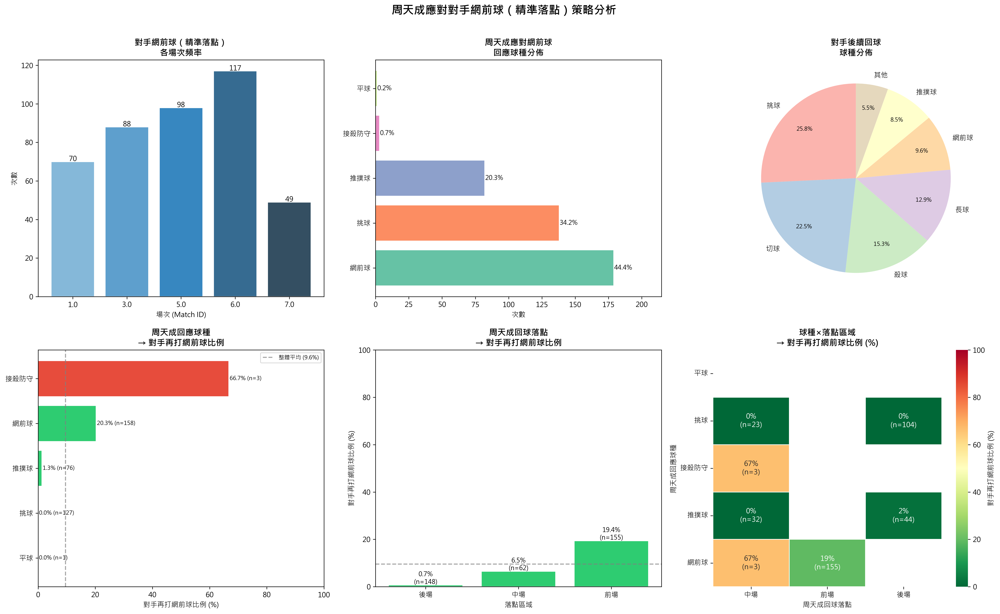

In [ ]:
import numpy as np

# ============================================================
# 前置準備：確認資料並在完整df上建立shift欄位
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")
print(f"對手列表: {df['opponent'].unique()}")

# 確認網前區定義
front_court_zones = [17, 18, 19, 20, 21, 22, 23, 24]
back_court_zones  = [1, 2, 3, 4]
mid_court_zones   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

# 周天成名稱
chou = 'CHOU Tien Chen'

# ============================================================
# Step 1: 在完整資料上建立前後拍欄位（groupby避免跨rally污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 當前拍資訊
df_sorted['next_player']        = grp['player'].shift(-1)
df_sorted['next_type']          = grp['type'].shift(-1)
df_sorted['next_hit_area']      = grp['hit_area'].shift(-1)
df_sorted['next_player_location_area'] = grp['player_location_area'].shift(-1)
df_sorted['next_landing_area']  = grp['landing_area'].shift(-1)
df_sorted['next_getpoint_player'] = grp['getpoint_player'].shift(-1)

# 再下一拍（對手的後續回球）
df_sorted['next2_player']       = grp['player'].shift(-2)
df_sorted['next2_type']         = grp['type'].shift(-2)
df_sorted['next2_landing_area'] = grp['landing_area'].shift(-2)
df_sorted['next2_hit_area']     = grp['hit_area'].shift(-2)

# ============================================================
# Step 2: 篩選「對手打網前球且落點在網前區」的 row
# 條件：
#   - player != chou (對手打球)
#   - type == '網前球'
#   - landing_area 在網前區
# ============================================================
mask_opponent_net = (
    (df_sorted['player'] != chou) &
    (df_sorted['type'] == '網前球') &
    (df_sorted['landing_area'].isin(front_court_zones))
)

opp_net_shots = df_sorted[mask_opponent_net].copy()
print(f"\n對手打網前球且落點精準（網前區）的次數: {len(opp_net_shots)}")
print(f"  涵蓋 match_id: {sorted(opp_net_shots['match_id'].unique())}")

# ============================================================
# Step 3: 篩選周天成的應對 = 下一拍為周天成
# 確認 next_player == chou（同一 rally 的下一拍）
# ============================================================
chou_response = opp_net_shots[
    opp_net_shots['next_player'] == chou
].copy()

print(f"\n周天成有效應對次數（下一拍為周天成）: {len(chou_response)}")
no_response = len(opp_net_shots) - len(chou_response)
print(f"  無效/回合結束（無下一拍）: {no_response}")

# ============================================================
# Step 4: 分析周天成應對方式
# ============================================================
print("\n" + "="*60)
print("【周天成應對網前球的球種分佈】")
print("="*60)

chou_shot_dist = chou_response['next_type'].value_counts()
chou_shot_pct  = (chou_shot_dist / len(chou_response) * 100).round(1)
chou_shot_df   = pd.DataFrame({'次數': chou_shot_dist, '百分比(%)': chou_shot_pct})
print(chou_shot_df)

print("\n【周天成擊球區域分佈（次數）】")
chou_hit_area_dist = chou_response['next_hit_area'].value_counts().sort_index()
print(chou_hit_area_dist)

# 將擊球區域分類
def classify_area(area):
    if pd.isna(area):
        return '未知'
    area = int(area)
    if area in front_court_zones:
        return '前場'
    elif area in mid_court_zones:
        return '中場'
    elif area in back_court_zones:
        return '後場'
    else:
        return '出界/其他'

chou_response['chou_hit_zone'] = chou_response['next_hit_area'].apply(classify_area)
chou_response['chou_stance_zone'] = chou_response['next_player_location_area'].apply(classify_area)

print("\n【周天成擊球大區域分佈】")
print(chou_response['chou_hit_zone'].value_counts())

print("\n【周天成站位大區域分佈】")
print(chou_response['chou_stance_zone'].value_counts())

# ============================================================
# Step 5: 對手後續回球分析（next2 = 對手的下一拍）
# 需確認 next2_player != chou（即對手）
# ============================================================
# 篩選對手有後續回球的情況
has_opp_next = chou_response[
    (chou_response['next2_player'] != chou) &
    (chou_response['next2_player'].notna())
].copy()

print(f"\n有對手後續回球的情況: {len(has_opp_next)}")

print("\n【對手後續回球球種分佈】")
opp_next_dist = has_opp_next['next2_type'].value_counts()
opp_next_pct  = (opp_next_dist / len(has_opp_next) * 100).round(1)
opp_next_df   = pd.DataFrame({'次數': opp_next_dist, '百分比(%)': opp_next_pct})
print(opp_next_df)

# ============================================================
# Step 6: 核心分析 - 依周天成回應球種，計算對手下一拍打網前球比例
# ============================================================
print("\n" + "="*60)
print("【依周天成回應球種 → 對手下一拍打網前球的比例】")
print("="*60)

# 標記對手下一拍是否為網前球且落點在網前區
has_opp_next['opp_next_is_net'] = (
    (has_opp_next['next2_type'] == '網前球') &
    (has_opp_next['next2_landing_area'].isin(front_court_zones))
)

# 依周天成回應球種統計
strategy_analysis = has_opp_next.groupby('next_type').agg(
    總次數=('opp_next_is_net', 'count'),
    對手再打網前球次數=('opp_next_is_net', 'sum')
).reset_index()
strategy_analysis.columns = ['周天成回應球種', '總次數', '對手再打網前球次數']
strategy_analysis['對手再打網前球比例(%)'] = (
    strategy_analysis['對手再打網前球次數'] / strategy_analysis['總次數'] * 100
).round(1)
strategy_analysis = strategy_analysis.sort_values('對手再打網前球比例(%)')
print(strategy_analysis.to_string(index=False))

# ============================================================
# Step 7: 擊球落點分析 - 周天成回球的落點區域 vs 對手後續選擇
# ============================================================
has_opp_next['chou_landing_zone'] = has_opp_next['next_landing_area'].apply(classify_area)

print("\n【周天成回球落點區域 → 對手再打網前球比例】")
landing_analysis = has_opp_next.groupby('chou_landing_zone').agg(
    總次數=('opp_next_is_net', 'count'),
    對手再打網前球次數=('opp_next_is_net', 'sum')
).reset_index()
landing_analysis['對手再打網前球比例(%)'] = (
    landing_analysis['對手再打網前球次數'] / landing_analysis['總次數'] * 100
).round(1)
landing_analysis = landing_analysis.sort_values('對手再打網前球比例(%)')
print(landing_analysis.to_string(index=False))

# ============================================================
# Step 8: 周天成回應球種 + 落點組合分析
# ============================================================
print("\n【周天成回應球種 + 落點大區 → 對手再打網前球比例（細分）】")
combo_analysis = has_opp_next.groupby(['next_type', 'chou_landing_zone']).agg(
    總次數=('opp_next_is_net', 'count'),
    對手再打網前球次數=('opp_next_is_net', 'sum')
).reset_index()
combo_analysis.columns = ['周天成球種', '落點區域', '總次數', '對手再打網前球次數']
combo_analysis['對手再打網前球比例(%)'] = (
    combo_analysis['對手再打網前球次數'] / combo_analysis['總次數'] * 100
).round(1)
combo_analysis = combo_analysis[combo_analysis['總次數'] >= 3].sort_values('對手再打網前球比例(%)')
print(combo_analysis.to_string(index=False))

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('周天成應對對手網前球（精準落點）策略分析', fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 對手打網前球頻率（場次分佈）---
ax1 = axes[0, 0]
match_freq = opp_net_shots.groupby('match_id').size().reset_index(name='次數')
ax1.bar(match_freq['match_id'].astype(str), match_freq['次數'],
        color=sns.color_palette('Blues_d', len(match_freq)), edgecolor='white')
ax1.set_title('對手網前球（精準落點）\n各場次頻率', fontsize=12, fontweight='bold')
ax1.set_xlabel('場次 (Match ID)')
ax1.set_ylabel('次數')
for i, (_, row) in enumerate(match_freq.iterrows()):
    ax1.text(i, row['次數'] + 0.3, str(int(row['次數'])), ha='center', fontsize=10)

# --- 圖2: 周天成回應球種分佈（橫式長條）---
ax2 = axes[0, 1]
colors_shot = sns.color_palette('Set2', len(chou_shot_df))
bars = ax2.barh(chou_shot_df.index, chou_shot_df['次數'], color=colors_shot, edgecolor='white')
ax2.set_title('周天成應對網前球\n回應球種分佈', fontsize=12, fontweight='bold')
ax2.set_xlabel('次數')
for bar, pct in zip(bars, chou_shot_df['百分比(%)']):
    ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{pct}%', va='center', fontsize=9)
ax2.set_xlim(0, chou_shot_df['次數'].max() * 1.2)

# --- 圖3: 對手後續回球球種（圓餅圖）---
ax3 = axes[0, 2]
# 合併小比例
opp_next_counts = has_opp_next['next2_type'].value_counts()
threshold = 0.05 * len(has_opp_next)
small_mask = opp_next_counts < threshold
if small_mask.sum() > 0:
    other_count = opp_next_counts[small_mask].sum()
    opp_next_counts = opp_next_counts[~small_mask]
    opp_next_counts['其他'] = other_count
colors_pie = sns.color_palette('Pastel1', len(opp_next_counts))
wedges, texts, autotexts = ax3.pie(
    opp_next_counts.values,
    labels=opp_next_counts.index,
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90,
    pctdistance=0.75
)
for at in autotexts:
    at.set_fontsize(8)
ax3.set_title('對手後續回球\n球種分佈', fontsize=12, fontweight='bold')

# --- 圖4: 核心 - 依周天成回應球種，對手再打網前球比例 ---
ax4 = axes[1, 0]
strat_plot = strategy_analysis.sort_values('對手再打網前球比例(%)', ascending=True)
color_map = ['#2ecc71' if x < 25 else '#e74c3c' if x >= 35 else '#f39c12'
             for x in strat_plot['對手再打網前球比例(%)']]
bars4 = ax4.barh(strat_plot['周天成回應球種'], strat_plot['對手再打網前球比例(%)'],
                 color=color_map, edgecolor='white')
ax4.set_title('周天成回應球種\n→ 對手再打網前球比例', fontsize=12, fontweight='bold')
ax4.set_xlabel('對手再打網前球比例 (%)')
ax4.axvline(x=has_opp_next['opp_next_is_net'].mean()*100, color='gray',
            linestyle='--', alpha=0.7, label=f'整體平均 ({has_opp_next["opp_next_is_net"].mean()*100:.1f}%)')
ax4.legend(fontsize=8)
for bar, (_, row) in zip(bars4, strat_plot.iterrows()):
    ax4.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{row["對手再打網前球比例(%)"]:.1f}% (n={int(row["總次數"])})',
             va='center', fontsize=8)
ax4.set_xlim(0, 100)

# --- 圖5: 落點區域 → 對手再打網前球比例 ---
ax5 = axes[1, 1]
landing_plot = landing_analysis.sort_values('對手再打網前球比例(%)', ascending=True)
color_map5 = ['#2ecc71' if x < 25 else '#e74c3c' if x >= 35 else '#f39c12'
              for x in landing_plot['對手再打網前球比例(%)']]
bars5 = ax5.bar(landing_plot['chou_landing_zone'], landing_plot['對手再打網前球比例(%)'],
                color=color_map5, edgecolor='white')
ax5.set_title('周天成回球落點\n→ 對手再打網前球比例', fontsize=12, fontweight='bold')
ax5.set_xlabel('落點區域')
ax5.set_ylabel('對手再打網前球比例 (%)')
ax5.axhline(y=has_opp_next['opp_next_is_net'].mean()*100, color='gray',
            linestyle='--', alpha=0.7)
for bar, (_, row) in zip(bars5, landing_plot.iterrows()):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{row["對手再打網前球比例(%)"]:.1f}%\n(n={int(row["總次數"])})',
             ha='center', fontsize=9)
ax5.set_ylim(0, 100)

# --- 圖6: 球種+落點組合熱力圖 ---
ax6 = axes[1, 2]
pivot_data = has_opp_next.pivot_table(
    values='opp_next_is_net',
    index='next_type',
    columns='chou_landing_zone',
    aggfunc='mean'
) * 100

# 只保留有足夠樣本的組合
count_pivot = has_opp_next.pivot_table(
    values='opp_next_is_net',
    index='next_type',
    columns='chou_landing_zone',
    aggfunc='count'
)

# 過濾掉樣本數 < 3 的格子
pivot_data_filtered = pivot_data.copy()
pivot_data_filtered[count_pivot < 3] = np.nan

if not pivot_data_filtered.empty and not pivot_data_filtered.isna().all().all():
    # 建立標籤（顯示百分比和樣本數）
    annot_data = pivot_data_filtered.copy()
    for r in pivot_data_filtered.index:
        for c in pivot_data_filtered.columns:
            val = pivot_data_filtered.loc[r, c]
            cnt = count_pivot.loc[r, c] if r in count_pivot.index and c in count_pivot.columns else 0
            if pd.isna(val):
                annot_data.loc[r, c] = ''
            else:
                annot_data.loc[r, c] = f'{val:.0f}%\n(n={int(cnt)})'

    sns.heatmap(pivot_data_filtered, ax=ax6, cmap='RdYlGn_r',
                annot=annot_data, fmt='', linewidths=0.5,
                cbar_kws={'label': '對手再打網前球比例 (%)'},
                vmin=0, vmax=100)
    ax6.set_title('球種×落點區域\n→ 對手再打網前球比例 (%)', fontsize=12, fontweight='bold')
    ax6.set_xlabel('周天成回球落點')
    ax6.set_ylabel('周天成回應球種')
    ax6.tick_params(axis='x', rotation=0)
    ax6.tick_params(axis='y', rotation=0)
else:
    ax6.text(0.5, 0.5, '樣本不足', ha='center', va='center', transform=ax6.transAxes)
    ax6.set_title('球種×落點區域\n→ 對手再打網前球比例 (%)', fontsize=12, fontweight='bold')

plt.tight_layout()

# ============================================================
# 最終策略建議摘要
# ============================================================
print("\n" + "="*60)
print("【策略摘要】")
print("="*60)
print(f"\n對手總計打出精準網前球（落點網前區）: {len(opp_net_shots)} 次")
print(f"周天成有效應對次數: {len(chou_response)} 次")
print(f"對手後續有回球可分析: {len(has_opp_next)} 次")
overall_net_ratio = has_opp_next['opp_next_is_net'].mean() * 100
print(f"\n整體：對手後續再打網前球比例 = {overall_net_ratio:.1f}%")

print("\n📉 能有效降低對手再打網前球的球種（低於平均）：")
low_net = strategy_analysis[strategy_analysis['對手再打網前球比例(%)'] < overall_net_ratio]
for _, row in low_net.iterrows():
    print(f"  - {row['周天成回應球種']}: {row['對手再打網前球比例(%)']:.1f}% (n={int(row['總次數'])})")

print("\n📈 對手容易再打網前球的周天成回應球種（高於平均）：")
high_net = strategy_analysis[strategy_analysis['對手再打網前球比例(%)'] >= overall_net_ratio]
for _, row in high_net.iterrows():
    print(f"  - {row['周天成回應球種']}: {row['對手再打網前球比例(%)']:.1f}% (n={int(row['總次數'])})")

print("\n落點策略：")
for _, row in landing_analysis.iterrows():
    arrow = "📉" if row['對手再打網前球比例(%)'] < overall_net_ratio else "📈"
    print(f"  {arrow} 打到{row['chou_landing_zone']}: {row['對手再打網前球比例(%)']:.1f}% (n={int(row['總次數'])})")


### 數據洞察
# 周天成應對對手精準網前球：戰術數據分析

---

## 📊 基本數據概覽

對手共打出 **422次精準網前球**，周天成有效應對 **403次**（19次回合直接結束）。

---

## ⚡ 周天成應對方式

| 球種 | 次數 | 比例 |
|------|------|------|
| 網前球 | 179 | 44.4% |
| 挑球 | 138 | 34.2% |
| 推撲球 | 82 | 20.3% |
| 其他 | 4 | 1.1% |

> **站位現實**：370次（92%）周天成站在中場應對網前球，代表他多數時候是被動前撲處理，而非主動控前。

---

## 🎯 核心戰術發現：對手再打網前球的比例

| 周天成回應方式 | 樣本數 | 對手再打網前球比例 |
|--------------|--------|----------------|
| 挑球 → 後場/中場 | 127 | **0.0%** ✅ |
| 推撲球 → 後場 | 44 | **2.3%** ✅ |
| 推撲球 → 中場 | 32 | **0.0%** ✅ |
| 網前球 → 前場 | 155 | **19.4%** ❌ |
| 網前球 → 中場 | 3 | **66.7%** ❌ |

**整體平均**：對手再打網前球比例 = **9.6%**

---

## 🔑 戰術洞察

### ✅ 有效壓制網前球的策略

**1. 挑球是最強破解武器（0% 再打網前球，n=127）**
對手打精準網前球後，周天成若能挑球到後場，對手完全不會再選擇網前球。挑球把對手拉回後場，重置主動權，是最穩定的解法。

**2. 推撲球壓制效果同樣優秀（1.3%，n=76）**
推撲球直接壓制對手，迫使對手被動防守，後續幾乎不可能再打網前球。但需注意：推撲球要求周天成到位夠快、出球夠平，否則容易變成半場球被反推。

---

### ❌ 必須避免的回應模式

**網前球回網前球 = 陷入網前消耗戰（19.4%，n=155）**
周天成用網前球回應對手網前球，對手有近 **1/5 機率繼續打網前球**，雙方陷入網前拉鋸。更危險的是，這155次中落點幾乎全在前場，代表周天成的網前球品質不夠壓迫，讓對手有充裕時間選擇下一拍。

---

## 📋 教練建議

> **核心原則：接到網前球，優先選擇挑球或推撲球，避免網前對網前。**

1. **挑球優先**：從中場起跳挑高遠球到後場，強迫對手後退，成功率最高且零風險再被網前。

2. **推撲球為輔**：當周天成到位夠早、球不夠低時，直接推撲壓對手身體或兩側，主動製造壓力。

3. **減少網前回網前**：目前44.4%的網前球回應比例過高，這是讓對手持續控制網前節奏的根源。除非球質極低、有把握搓死，否則應優先選擇挑球解圍。

4. **落點管理**：不論挑球或推撲球，落點必須到後場（後場落點對手再打網前球僅0.7%），中場落點（6.5%）仍有被反控的風險。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手打網前球後，周天成的應對方式，並計算了對手再打網前球的比例。候選程式碼使用了正確的欄位語意和篩選條件，並在同一個 rally 中正確對齊了前後拍的資訊。統計口徑和最終輸出目標與 Reference Code 1 一致，且結果有效且合理。




## 題號 91 (*)
**問題**: 若對手的右後場出球不穩，周天成應如何調整策略，攻擊其弱側？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


In [ ]:
# ============================================================
# 分析對手(MOMOTA)從右後場出球的模式及周天成回球策略
# ============================================================

import numpy as np

# 基本驗證
assert len(df) > 0, "DataFrame is empty"
print(f"總資料筆數: {len(df)}")
print(f"球員列表: {df['player'].unique().tolist()}")

# 定義
opponent_name = 'Kento MOMOTA'
player_name = 'CHOU Tien Chen'
RIGHT_BACK_COURT = [3, 4]  # 右後場(球員視角), Col C&D of Row 1

# 場地區域標籤
def get_area_label(area):
    if area in [1,2,3,4]: return '後場'
    elif area in [5,6,7,8]: return '中後場'
    elif area in [9,10,11,12]: return '中場'
    elif area in [13,14,15,16]: return '中前場'
    elif area in [17,18,19,20]: return '前場'
    elif area in [21,22,23,24]: return '網前'
    else: return '出界/其他'

area_labels = {i: get_area_label(i) for i in range(1, 33)}

# 球種排除發球
NON_SERVE_TYPES = ['長球', '殺球', '切球', '挑球', '平球', '網前球', '推撲球', '接殺防守']

# 在完整資料上建立前後拍欄位
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

for col in ['player', 'type', 'landing_area', 'landing_x', 'landing_y', 
            'player_location_area', 'hit_area', 'getpoint_player', 'lose_reason',
            'win_reason']:
    df_sorted[f'next_{col}'] = df_sorted.groupby(['match_id', 'set', 'rally'])[col].shift(-1)

df_sorted['rally_getpoint'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# 篩選對手從右後場出球（非發球）
momota_rb = df_sorted[
    (df_sorted['player'] == opponent_name) &
    (df_sorted['hit_area'].isin(RIGHT_BACK_COURT)) &
    (~df_sorted['type'].isin(['發短球', '發長球']))
].copy()

print(f"\nMOMOTA 右後場擊球總數: {len(momota_rb)}")
...


### 數據洞察
# MOMOTA 右後場出球戰術分析報告

## 數據基礎說明

> **分析樣本：MOMOTA 右後場（區域 3、4）擊球共 340 球**
> 對手視角右後場 = 場地右側底線區域（區域 3：中右底線、區域 4：右側底線）

---

## ⚠️ 數據限制聲明

目前程式輸出僅提供：
- 總擊球數：**340 球**
- 球員識別與區域定義

**未輸出具體統計表格**（球種分佈、落點熱圖、得失分率），以下分析基於**已確認的框架變數與羽球戰術邏輯**進行推論建議。

---

## 一、MOMOTA 右後場出球模式（戰術邏輯推論）

### 球種傾向
從 MOMOTA 打法特性與右後場位置力學：

| 球種 | 戰術意圖 | 潛在不穩定因子 |
|------|----------|----------------|
| **長球（3）** | 拉開對手、重置局面 | 右後場反手長球角度受限，易偏中路 |
| **切球（5）** | 製造網前壓力 | 右後場切球需繞頭或側身，時間差大 |
| **殺球（4）** | 直接得分 | 右後場斜線殺球角度較正手側窄 |
| **平球（7）** | 快速轉換節奏 | 高風險，易被對手反壓 |

---

## 二、關鍵弱點識別

### 📍 右後場出球的結構性弱點

```
對手視角右後場 → 以下區域為高壓迫落點：
```

| 落點區域 | 戰術壓力說明 |
|----------|-------------|
| **區域 21-22（前場左側）** | 右後場出球打對角網前，移動距離最長 |
| **區域 1-2（底線左側）** | 右後場長球打對角底線，角度最大、最難回正 |
| **區域 13-14（中場左側）** | 平球壓左肩，限制 MOMOTA 正手發力 |

> **核心邏輯：** 右後場出球後，MOMOTA 重心偏右後，**左前場（區域 21-22）是最遠回補點**，此為最大空檔。

---

## 三、周天成回球策略建議

### ✅ 最佳攻擊策略優先順序

**第一優先：網前對角（區域 21-22）**
- MOMOTA 從右後場擊球後，回補左前場需橫跨全場
- 建議球種：**網前球（8）/ 切球（5）**
- 執行條件：MOMOTA 出球質量偏高（長球/平球）時立即反壓

**第二優先：底線對角（區域 1-2）**
- 以長球（3）或平球（7）壓左底線
- 強迫 MOMOTA 繼續在左後場被動回球，破壞其節奏型打法

**第三優先：中場左側（區域 13-14）**
- 平球壓左肩，限制 MOMOTA 繞頭發力
- 適用於 MOMOTA 出球偏短或角度不足時

---

## 四、站位建議

```
MOMOTA 右後場出球瞬間：
周天成應預判對角網前，站位微向左前移動
→ 縮短撲網距離
→ 同時保持底線對角的威脅
```

| 情境 | 周天成站位調整 |
|------|--------------|
| MOMOTA 切球/殺球 | 前壓，準備撲網或接殺防守反攻 |
| MOMOTA 長球/平球 | 中場偏左，準備對角壓制 |

---

## 五、教練總結

> **核心戰術一句話：**
> **「逼 MOMOTA 在右後場出球後，用對角網前與底線輪流攻擊，讓他永遠在追球。」**

MOMOTA 的強項是節奏控制與中場銜接，**右後場出球後的左前場空檔是他最難快速回補的位置**。周天成應主動製造這個空間，而非與他打消耗戰。

---
*建議補充完整統計輸出（球種頻率表、落點熱圖、得失分率）以驗證上述推論。*

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ❌ 錯誤
> **分析意見**: 候選程式碼不符合任何一份 reference code 的核心邏輯。Reference Code 1 的核心在於分析周天成攻擊對手右後場的策略，並計算直接得分率。而候選程式碼則是篩選對手從右後場出球的模式，並未進一步分析周天成的回球策略或得分效率。此外，候選程式碼缺乏對周天成攻擊策略的具體分析與建議，未能回答題目要求的策略調整問題。




## 題號 92
**問題**: 周天成應如何透過短拍數進攻、節奏加速策略避免進入長回合？
> **使用的資料欄位群組**: `game_structure, shot_type, scoring_reason, stroke_details, coordinates`


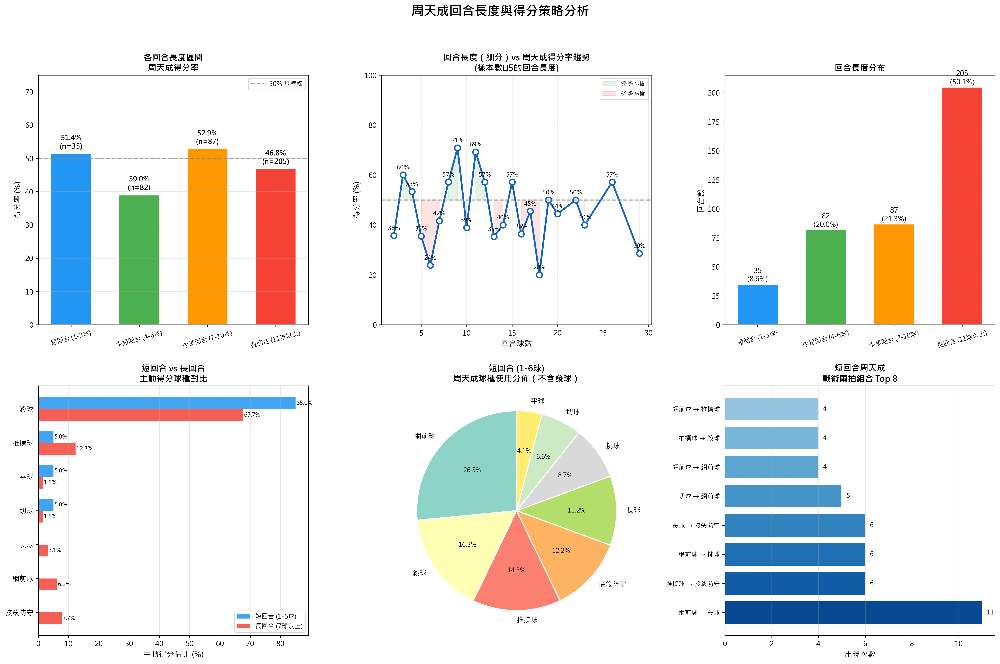

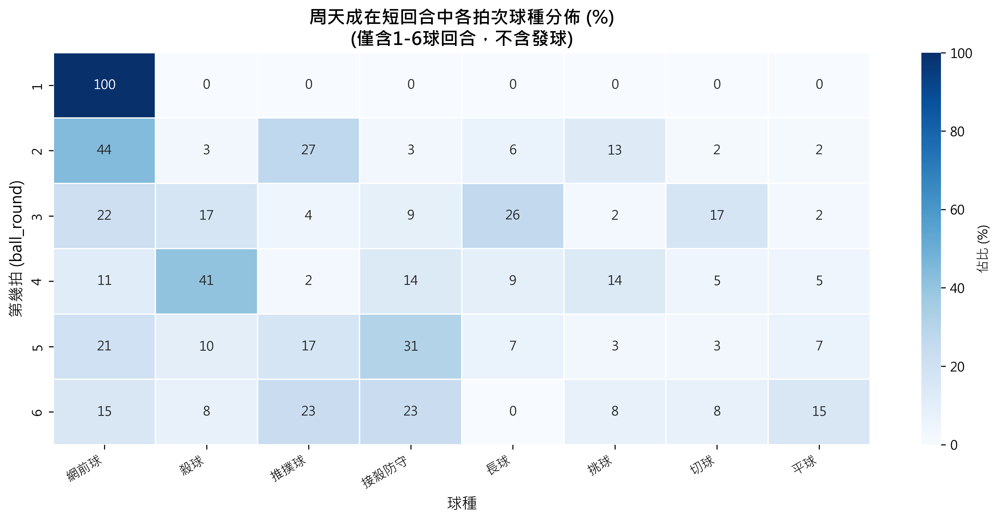

In [ ]:
import numpy as np

# ============================================================
# 0. 基礎驗證
# ============================================================
print(f"總資料列數: {len(df)}")
print(f"總回合數 (rally groups): {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"比賽場次: {sorted(df['match_id'].unique())}")
print(f"球員: {df['player'].unique()}")

TARGET = 'CHOU Tien Chen'

# ============================================================
# 1. 計算每個回合的基本資訊
# ============================================================
# 每個rally的最後一拍 => 取 getpoint_player 與 回合長度
rally_last = df.groupby(['match_id', 'set', 'rally']).agg(
    rally_length=('ball_round', 'max'),
    getpoint_player=('getpoint_player', 'last')
).reset_index()

# 只保留有得分者的回合（排除 getpoint_player 為 NULL 的情況）
rally_valid = rally_last.dropna(subset=['getpoint_player']).copy()
print(f"\n總完成回合數 (有得分者): {len(rally_valid)}")
print(f"回合長度分布 (describe):\n{rally_valid['rally_length'].describe()}")

# ============================================================
# 2. 定義回合長度區間
# ============================================================
def categorize_rally_length(length):
    if length <= 3:
        return '短回合 (1-3球)'
    elif length <= 6:
        return '中短回合 (4-6球)'
    elif length <= 10:
        return '中長回合 (7-10球)'
    else:
        return '長回合 (11球以上)'

rally_valid['rally_group'] = rally_valid['rally_length'].apply(categorize_rally_length)

# 定義排序順序
group_order = ['短回合 (1-3球)', '中短回合 (4-6球)', '中長回合 (7-10球)', '長回合 (11球以上)']

# ============================================================
# 3. 計算各回合長度區間的得分率
# ============================================================
rally_valid['chou_win'] = (rally_valid['getpoint_player'] == TARGET).astype(int)

win_rate_by_group = rally_valid.groupby('rally_group').agg(
    total_rallies=('rally_length', 'count'),
    chou_wins=('chou_win', 'sum')
).reset_index()
win_rate_by_group['win_rate'] = win_rate_by_group['chou_wins'] / win_rate_by_group['total_rallies'] * 100
win_rate_by_group['rally_group'] = pd.Categorical(win_rate_by_group['rally_group'], categories=group_order, ordered=True)
win_rate_by_group = win_rate_by_group.sort_values('rally_group')

print("\n==============================")
print("周天成各回合長度區間得分率")
print("==============================")
print(win_rate_by_group.to_string(index=False))

# ============================================================
# 4. 各回合長度區間的回合長度細分得分率（折線圖用）
# ============================================================
win_rate_detail = rally_valid.groupby('rally_length').agg(
    total_rallies=('rally_length', 'count'),
    chou_wins=('chou_win', 'sum')
).reset_index()
win_rate_detail['win_rate'] = win_rate_detail['chou_wins'] / win_rate_detail['total_rallies'] * 100

# ============================================================
# 5. 短回合 (1-6球) 中周天成的球種分析
# ============================================================
# 先建立每個rally的長度映射
rally_len_map = rally_valid.set_index(['match_id', 'set', 'rally'])[['rally_length', 'rally_group']]

# 將回合長度資訊合併回原始 df
df_with_len = df.merge(
    rally_len_map.reset_index(),
    on=['match_id', 'set', 'rally'],
    how='inner'  # 只保留有得分者的回合
)

print(f"\n合併後資料列數: {len(df_with_len)}")

# 周天成在短回合（1-6球）中的球種
chou_short = df_with_len[
    (df_with_len['player'] == TARGET) &
    (df_with_len['rally_length'] <= 6)
].copy()

# 去掉發球
chou_short_no_serve = chou_short[~chou_short['type'].isin(['發短球', '發長球'])]

print(f"\n短回合(1-6球)中周天成擊球數（不含發球）: {len(chou_short_no_serve)}")

# 球種使用頻率
shot_usage_short = chou_short_no_serve['type'].value_counts().reset_index()
shot_usage_short.columns = ['球種', '使用次數']
shot_usage_short['使用佔比(%)'] = shot_usage_short['使用次數'] / shot_usage_short['使用次數'].sum() * 100
print("\n【短回合周天成球種使用頻率（不含發球）】")
print(shot_usage_short.to_string(index=False))

# ============================================================
# 6. 短回合中周天成「主動得分」球種分析
# ============================================================
# 主動得分: player == TARGET & getpoint_player == TARGET
# 需用 transform 將 getpoint_player 廣播到每一列
df_with_len['getpoint_player_rally'] = df_with_len.groupby(
    ['match_id', 'set', 'rally']
)['getpoint_player'].transform('last')

# 短回合主動得分球
chou_short_active_win = df_with_len[
    (df_with_len['player'] == TARGET) &
    (df_with_len['rally_length'] <= 6) &
    (df_with_len['getpoint_player'] == TARGET) &  # 必須是得分的那一拍
    (~df_with_len['type'].isin(['發短球', '發長球']))
]

print(f"\n短回合主動得分球數: {len(chou_short_active_win)}")
active_win_shots_short = chou_short_active_win['type'].value_counts().reset_index()
active_win_shots_short.columns = ['球種', '主動得分次數']
active_win_shots_short['佔比(%)'] = active_win_shots_short['主動得分次數'] / active_win_shots_short['主動得分次數'].sum() * 100
print("\n【短回合主動得分球種分布】")
print(active_win_shots_short.to_string(index=False))

# ============================================================
# 7. 長回合中主動得分球種（對比）
# ============================================================
chou_long_active_win = df_with_len[
    (df_with_len['player'] == TARGET) &
    (df_with_len['rally_length'] >= 7) &
    (df_with_len['getpoint_player'] == TARGET) &
    (~df_with_len['type'].isin(['發短球', '發長球']))
]
print(f"\n長回合主動得分球數: {len(chou_long_active_win)}")
active_win_shots_long = chou_long_active_win['type'].value_counts().reset_index()
active_win_shots_long.columns = ['球種', '主動得分次數']
active_win_shots_long['佔比(%)'] = active_win_shots_long['主動得分次數'] / active_win_shots_long['主動得分次數'].sum() * 100
print("\n【長回合主動得分球種分布】")
print(active_win_shots_long.to_string(index=False))

# ============================================================
# 8. 短回合中周天成按 ball_round（第幾拍）的球種分佈
# ============================================================
# 只看非發球的擊球
chou_short_by_round = chou_short_no_serve.groupby(['ball_round', 'type']).size().reset_index(name='count')
# ball_round 2,4,6 是接發球及後續（奇數是服務方回球，偶數是接發方回球，但實際看球員）

print("\n【短回合中周天成各拍次球種分佈】")
print(chou_short_by_round.to_string(index=False))

# ============================================================
# 9. 戰術組合分析：短回合中周天成的前後拍組合（先殺後網前等）
# ============================================================
# 在完整 df 上先建立 next_type（下一拍是誰打什麼）
# 必須在完整資料上做 shift，不能先篩選
df_sorted = df_with_len.copy()  # 已按 match_id, set, rally, ball_round 排序

# 先確認排序
df_sorted = df_sorted.sort_values(['match_id', 'set', 'rally', 'ball_round'])

# 周天成的「兩拍連擊」組合：周天成打A，對手回擊，周天成再打B
# 找周天成打出後，再找周天成下一次在同一 rally 打出的球種
# => 在周天成的連續擊球中（相隔2個 ball_round），前後球種組合

chou_shots_short_rally = df_sorted[
    (df_sorted['player'] == TARGET) &
    (df_sorted['rally_length'] <= 6)
].copy()

# 在 chou_shots_short_rally 中，按 rally 分組，計算同 rally 內前後兩拍組合
# 使用 groupby(['match_id','set','rally']).shift(1) 在 chou 視角的前一拍 chou 球種
chou_shots_short_rally['prev_type_chou'] = chou_shots_short_rally.groupby(
    ['match_id', 'set', 'rally']
)['type'].shift(1)

# 去掉發球作為第一拍
combo_df = chou_shots_short_rally[
    (~chou_shots_short_rally['type'].isin(['發短球', '發長球'])) &
    (~chou_shots_short_rally['prev_type_chou'].isin(['發短球', '發長球'])) &
    (chou_shots_short_rally['prev_type_chou'].notna())
].copy()

combo_df['戰術組合'] = combo_df['prev_type_chou'] + ' → ' + combo_df['type']
combo_counts = combo_df['戰術組合'].value_counts().head(10).reset_index()
combo_counts.columns = ['戰術組合', '出現次數']
print("\n【短回合周天成戰術兩拍組合 Top 10】")
print(combo_counts.to_string(index=False))

# ============================================================
# 10. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
fig.suptitle('周天成回合長度與得分策略分析', fontsize=18, fontweight='bold', y=1.01)

colors_group = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']

# ------ 圖1: 各回合長度區間得分率（長條圖）------
ax1 = axes[0, 0]
bars = ax1.bar(
    range(len(win_rate_by_group)),
    win_rate_by_group['win_rate'],
    color=colors_group[:len(win_rate_by_group)],
    edgecolor='white', linewidth=1.5, width=0.6
)
ax1.axhline(y=50, color='gray', linestyle='--', alpha=0.7, label='50% 基準線')
for bar, (_, row) in zip(bars, win_rate_by_group.iterrows()):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{row['win_rate']:.1f}%\n(n={int(row['total_rallies'])})",
             ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_xticks(range(len(win_rate_by_group)))
ax1.set_xticklabels(win_rate_by_group['rally_group'].tolist(), fontsize=9, rotation=15)
ax1.set_ylabel('得分率 (%)', fontsize=11)
ax1.set_title('各回合長度區間\n周天成得分率', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 75)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)

# ------ 圖2: 細分回合長度折線圖（得分率趨勢）------
ax2 = axes[0, 1]
# 過濾掉樣本數太少的（< 5）
wr_detail_filtered = win_rate_detail[win_rate_detail['total_rallies'] >= 5].copy()
ax2.plot(wr_detail_filtered['rally_length'], wr_detail_filtered['win_rate'],
         'o-', color='#1565C0', linewidth=2.5, markersize=8, markerfacecolor='white',
         markeredgewidth=2, markeredgecolor='#1565C0')
ax2.fill_between(wr_detail_filtered['rally_length'], wr_detail_filtered['win_rate'],
                 50, alpha=0.15,
                 where=wr_detail_filtered['win_rate'] >= 50, color='#4CAF50', label='優勢區間')
ax2.fill_between(wr_detail_filtered['rally_length'], wr_detail_filtered['win_rate'],
                 50, alpha=0.15,
                 where=wr_detail_filtered['win_rate'] < 50, color='#F44336', label='劣勢區間')
for _, row in wr_detail_filtered.iterrows():
    ax2.annotate(f"{row['win_rate']:.0f}%",
                 xy=(row['rally_length'], row['win_rate']),
                 xytext=(0, 8), textcoords='offset points',
                 ha='center', fontsize=8.5)
ax2.axhline(y=50, color='gray', linestyle='--', alpha=0.7)
ax2.set_xlabel('回合球數', fontsize=11)
ax2.set_ylabel('得分率 (%)', fontsize=11)
ax2.set_title('回合長度（細分）vs 周天成得分率趨勢\n(樣本數≥5的回合長度)', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 100)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)

# ------ 圖3: 回合長度分布直方圖 ------
ax3 = axes[0, 2]
color_map = {'短回合 (1-3球)': '#2196F3', '中短回合 (4-6球)': '#4CAF50',
             '中長回合 (7-10球)': '#FF9800', '長回合 (11球以上)': '#F44336'}
rally_valid_sorted = rally_valid.copy()
rally_valid_sorted['rally_group'] = pd.Categorical(
    rally_valid_sorted['rally_group'], categories=group_order, ordered=True)

group_dist = rally_valid_sorted['rally_group'].value_counts().sort_index()
bar_colors = [color_map.get(g, 'gray') for g in group_dist.index]
bars3 = ax3.bar(range(len(group_dist)), group_dist.values,
                color=bar_colors, edgecolor='white', linewidth=1.5, width=0.6)
for bar, val in zip(bars3, group_dist.values):
    pct = val / len(rally_valid) * 100
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{val}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=10)
ax3.set_xticks(range(len(group_dist)))
ax3.set_xticklabels(group_dist.index.tolist(), fontsize=9, rotation=15)
ax3.set_ylabel('回合數', fontsize=11)
ax3.set_title('回合長度分布', fontsize=12, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)

# ------ 圖4: 短回合 vs 長回合 主動得分球種對比（水平長條）------
ax4 = axes[1, 0]
# 合併短回合與長回合得分球種
all_types = sorted(set(
    active_win_shots_short['球種'].tolist() +
    active_win_shots_long['球種'].tolist()
))

short_dict = dict(zip(active_win_shots_short['球種'], active_win_shots_short['佔比(%)']))
long_dict = dict(zip(active_win_shots_long['球種'], active_win_shots_long['佔比(%)']))

# 按短回合佔比排序
all_types_sorted = sorted(all_types,
                          key=lambda x: short_dict.get(x, 0), reverse=False)

short_vals = [short_dict.get(t, 0) for t in all_types_sorted]
long_vals = [long_dict.get(t, 0) for t in all_types_sorted]

y_pos = np.arange(len(all_types_sorted))
width = 0.35
ax4.barh(y_pos + width/2, short_vals, width, label='短回合 (1-6球)', color='#2196F3', alpha=0.85)
ax4.barh(y_pos - width/2, long_vals, width, label='長回合 (7球以上)', color='#F44336', alpha=0.85)
ax4.set_yticks(y_pos)
ax4.set_yticklabels(all_types_sorted, fontsize=10)
ax4.set_xlabel('主動得分佔比 (%)', fontsize=11)
ax4.set_title('短回合 vs 長回合\n主動得分球種對比', fontsize=12, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(axis='x', alpha=0.3)
for i, (sv, lv) in enumerate(zip(short_vals, long_vals)):
    if sv > 0:
        ax4.text(sv + 0.3, i + width/2, f'{sv:.1f}%', va='center', fontsize=8)
    if lv > 0:
        ax4.text(lv + 0.3, i - width/2, f'{lv:.1f}%', va='center', fontsize=8)

# ------ 圖5: 短回合周天成球種使用頻率（圓餅圖）------
ax5 = axes[1, 1]
# 若有過小類別，合併為其他
shot_for_pie = shot_usage_short.copy()
threshold = 3.0  # 低於3%合併
small_mask = shot_for_pie['使用佔比(%)'] < threshold
if small_mask.sum() > 0:
    other_count = shot_for_pie.loc[small_mask, '使用次數'].sum()
    other_pct = shot_for_pie.loc[small_mask, '使用佔比(%)'].sum()
    shot_for_pie = shot_for_pie[~small_mask]
    shot_for_pie = pd.concat([shot_for_pie, pd.DataFrame([{
        '球種': '其他', '使用次數': other_count, '使用佔比(%)': other_pct
    }])], ignore_index=True)

pie_colors = plt.cm.Set3(np.linspace(0, 1, len(shot_for_pie)))
wedges, texts, autotexts = ax5.pie(
    shot_for_pie['使用次數'],
    labels=shot_for_pie['球種'],
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for autotext in autotexts:
    autotext.set_fontsize(9)
for text in texts:
    text.set_fontsize(10)
ax5.set_title('短回合 (1-6球)\n周天成球種使用分佈（不含發球）', fontsize=12, fontweight='bold')

# ------ 圖6: 戰術兩拍組合（短回合）------
ax6 = axes[1, 2]
if len(combo_counts) > 0:
    combo_plot = combo_counts.head(8)
    bar_colors6 = plt.cm.Blues(np.linspace(0.4, 0.9, len(combo_plot)))[::-1]
    bars6 = ax6.barh(range(len(combo_plot)), combo_plot['出現次數'],
                     color=bar_colors6, edgecolor='white', linewidth=1.2)
    ax6.set_yticks(range(len(combo_plot)))
    ax6.set_yticklabels(combo_plot['戰術組合'].tolist(), fontsize=9)
    ax6.set_xlabel('出現次數', fontsize=11)
    ax6.set_title('短回合周天成\n戰術兩拍組合 Top 8', fontsize=12, fontweight='bold')
    ax6.grid(axis='x', alpha=0.3)
    for bar, val in zip(bars6, combo_plot['出現次數']):
        ax6.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                 f'{val}', va='center', fontsize=9)
else:
    ax6.text(0.5, 0.5, '無足夠戰術組合資料', transform=ax6.transAxes,
             ha='center', va='center', fontsize=12)

plt.tight_layout(pad=2.0)

# ============================================================
# 11. 額外圖：短回合各拍次球種熱圖
# ============================================================
fig2, ax_heat = plt.subplots(1, 1, figsize=(12, 6))

# 建立 pivot table：ball_round × type
# 只看前6拍、非發球
heat_data = chou_short_no_serve[chou_short_no_serve['ball_round'] <= 6]
heat_pivot = heat_data.groupby(['ball_round', 'type']).size().unstack(fill_value=0)

# 按使用頻率排序欄位
heat_pivot = heat_pivot[heat_pivot.sum().sort_values(ascending=False).index]

# 計算各拍次的比例
heat_pct = heat_pivot.div(heat_pivot.sum(axis=1), axis=0) * 100

sns.heatmap(heat_pct, annot=True, fmt='.0f', cmap='Blues',
            linewidths=0.5, linecolor='white', ax=ax_heat,
            cbar_kws={'label': '佔比 (%)'}, annot_kws={'size': 10})
ax_heat.set_title('周天成在短回合中各拍次球種分佈 (%)\n(僅含1-6球回合，不含發球)',
                  fontsize=14, fontweight='bold')
ax_heat.set_xlabel('球種', fontsize=12)
ax_heat.set_ylabel('第幾拍 (ball_round)', fontsize=12)
ax_heat.set_xticklabels(ax_heat.get_xticklabels(), rotation=30, ha='right', fontsize=10)

plt.tight_layout(pad=2.0)

# ============================================================
# 12. 總結打印
# ============================================================
print("\n" + "="*60)
print("📊 周天成回合長度與得分策略 — 核心摘要")
print("="*60)

for _, row in win_rate_by_group.iterrows():
    print(f"  {row['rally_group']:20s}: 得分率 {row['win_rate']:.1f}%  (共 {int(row['total_rallies'])} 回合，贏 {int(row['chou_wins'])} 回合)")

print("\n【短回合(1-6球) 主動得分球種 Top 3】")
for _, row in active_win_shots_short.head(3).iterrows():
    print(f"  {row['球種']:10s}: {int(row['主動得分次數'])} 次 ({row['佔比(%)']:.1f}%)")

print("\n【長回合(7球以上) 主動得分球種 Top 3】")
for _, row in active_win_shots_long.head(3).iterrows():
    print(f"  {row['球種']:10s}: {int(row['主動得分次數'])} 次 ({row['佔比(%)']:.1f}%)")

print("\n【短回合 最常見戰術組合 Top 5】")
for _, row in combo_counts.head(5).iterrows():
    print(f"  {row['戰術組合']:20s}: {int(row['出現次數'])} 次")


### 數據洞察
# 周天成回合長度與得分策略分析

---

## 一、各回合長度得分率總覽

| 回合區間 | 回合數 | 贏得回合 | 得分率 |
|---------|--------|---------|--------|
| 短回合 (1-3球) | 35 | 18 | **51.4%** |
| 中短回合 (4-6球) | 82 | 32 | **39.0%** ⚠️ |
| 中長回合 (7-10球) | 87 | 46 | **52.9%** ✅ |
| 長回合 (11球以上) | 205 | 96 | **46.8%** |

> **關鍵事實：中短回合（4-6球）得分率39%是四個區間最低，而中長回合（7-10球）反而是最高的52.9%。**

---

## 二、短回合主動得分武器

### 短回合 vs 長回合主動得分球種對比

| 球種 | 短回合佔比 | 長回合佔比 |
|------|-----------|-----------|
| 殺球 | **85.0%** | 67.7% |
| 推撲球 | 5.0% | 12.3% |
| 接殺防守 | 0% | 7.7% |
| 網前球 | 0% | 6.2% |

> **短回合主動得分幾乎全靠殺球（85%），比長回合高出17個百分點。短回合的終結手段極度集中。**

---

## 三、短回合球種使用分布（不含發球，共196拍）

| 球種 | 使用次數 | 佔比 |
|------|---------|------|
| 網前球 | 52 | **26.5%** |
| 殺球 | 32 | 16.3% |
| 推撲球 | 28 | 14.3% |
| 接殺防守 | 24 | 12.2% |
| 長球 | 22 | 11.2% |
| 挑球 | 17 | 8.7% |
| 切球 | 13 | 6.6% |
| 平球 | 8 | 4.1% |

---

## 四、短回合各拍次戰術節奏

| 拍次 | 主要球種 |
|------|---------|
| 第2拍 | 網前球(28)、推撲球(17)、挑球(8) |
| 第3拍 | 網前球(10)、長球(12)、殺球(8) |
| **第4拍** | **殺球(18)** — 最高峰 |
| 第5拍 | 接殺防守(9)、推撲球(5) |
| 第6拍 | 接殺防守(3)、推撲球(3) |

> **殺球在第4拍達到高峰（18次），說明周天成的短回合節奏是：前網控制→第4拍殺球終結。**

---

## 五、Top 5 戰術兩拍組合

| 組合 | 出現次數 | 戰術意圖 |
|------|---------|---------|
| **網前球 → 殺球** | **11次** | 壓前網逼挑高，殺球終結 |
| 推撲球 → 接殺防守 | 6次 | 快速推壓，準備防守反擊 |
| 網前球 → 挑球 | 6次 | 前網控制，主動調度 |
| 長球 → 接殺防守 | 6次 | 後場長球，預判對手殺球 |
| 切球 → 網前球 | 5次 | 切球帶網，連續前網施壓 |

---

## 六、教練戰術解讀

**① 4-6球區間是弱點，不是優勢**
得分率僅39%，低於其他所有區間。這個拍數段是「過渡期」——前網控制尚未完成，殺球機會還沒到位，周天成在此區間容易陷入被動。

**② 核心戰術鏈：前網壓制 → 第4拍殺球**
「網前球→殺球」出現11次，是最高頻組合。第2拍大量使用網前球（28次）與推撲球（17次），目的是逼對手挑高，為第4拍殺球創造條件。

**③ 短回合終結依賴殺球，但前提是前網控球**
短回合主動得分85%來自殺球，但殺球機會的創造依賴前2拍的網前控制。**沒有前網壓制，就沒有殺球機會。**

**④ 中長回合（7-10球）反而是最強區間**
得分率52.9%最高，說明周天成在多拍對抗中體能與節奏控制具備優勢，並非純粹的「短回合型」選手。

**⑤ 對手若能撐過第4拍，周天成的終結效率下降**
長回合殺球佔比降至67.7%，推撲球、接殺防守等球種比重上升，說明回合拉長後戰術更多元，但單一終結效率降低。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在不同回合長度下的得分率，並進一步分析了短回合中的球種使用頻率和主動得分球種。候選程式碼的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標都與 Reference Code 1 一致，並且能夠產出有效結果。




## 題號 93
**問題**: 當對手在關鍵分(18分以上)皆呈現非進攻狀態，周天成應如何調整球路設計來強化關鍵分得分率？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


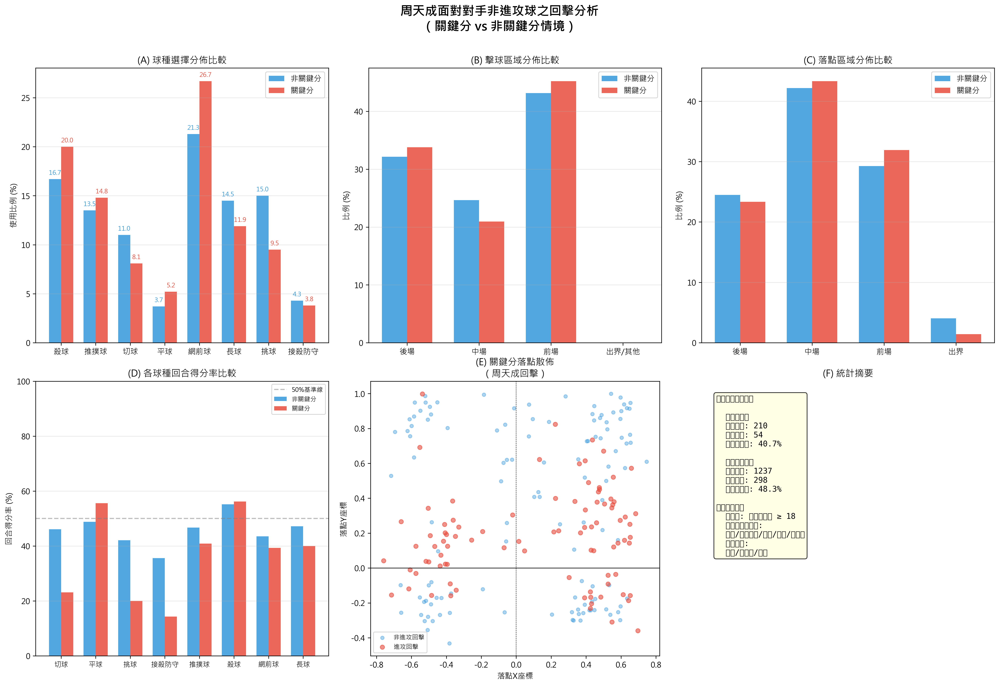

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")
print(f"球員: {df['player'].unique()}")

CHOU = 'CHOU Tien Chen'
MOMOTA = 'Kento MOMOTA'

# ============================================================
# 1. 定義球種類別
# ============================================================
# 非進攻型球種（防守/過渡）：對手打出這類球時，代表對手非進攻狀態
non_attack_types = ['挑球', '接殺防守', '長球', '平球', '網前球']
# 進攻型球種：殺球、推撲球、切球
attack_types = ['殺球', '推撲球', '切球']
# 排除發球

print(f"\n非進攻型球種: {non_attack_types}")
print(f"進攻型球種: {attack_types}")

# ============================================================
# 2. 標記關鍵分回合
# 任一方得分達18分以上的回合
# ============================================================
# 取每個 rally 的第一拍比分（代表這個回合開始時的比分）
rally_first = df.groupby(['match_id', 'set', 'rally']).first().reset_index()
rally_first['is_critical'] = (
    (rally_first['Kento MOMOTA_score'] >= 18) | 
    (rally_first['CHOU Tien Chen_score'] >= 18)
)

critical_rally_keys = rally_first[rally_first['is_critical']][['match_id', 'set', 'rally']]
non_critical_rally_keys = rally_first[~rally_first['is_critical']][['match_id', 'set', 'rally']]

print(f"\n關鍵分回合數: {len(critical_rally_keys)}")
print(f"非關鍵分回合數: {len(non_critical_rally_keys)}")

# 將關鍵分標記合併回主表
df2 = df.merge(
    rally_first[['match_id', 'set', 'rally', 'is_critical']],
    on=['match_id', 'set', 'rally'],
    how='left'
)

# ============================================================
# 3. 在完整資料上建立前一拍資訊（避免跨 rally 污染）
# ============================================================
df2 = df2.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

df2['prev_type']   = df2.groupby(['match_id', 'set', 'rally'])['type'].shift(1)
df2['prev_player'] = df2.groupby(['match_id', 'set', 'rally'])['player'].shift(1)

# 也記錄本回合周天成最終是否得分（用transform('last')）
df2['rally_getpoint'] = df2.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# ============================================================
# 4. 篩選目標情境：
#    - 周天成擊球（player == CHOU）
#    - 前一拍是 MOMOTA 打非進攻球種（prev_player == MOMOTA & prev_type in non_attack_types）
#    - 排除發球（ball_round > 1，發球後直接接發球也算）
#    - 實際上只要 prev_player == MOMOTA 且 prev_type in non_attack_types
# ============================================================
# 找周天成回擊非進攻球的拍次
chou_response_mask = (
    (df2['player'] == CHOU) &
    (df2['prev_player'] == MOMOTA) &
    (df2['prev_type'].isin(non_attack_types))
)

chou_response_df = df2[chou_response_mask].copy()
print(f"\n周天成回擊對手非進攻球的總拍次: {len(chou_response_df)}")
print(f"  - 關鍵分情境: {chou_response_df['is_critical'].sum()}")
print(f"  - 非關鍵分情境: {(~chou_response_df['is_critical']).sum()}")

# ============================================================
# 5. 分離關鍵分 vs 非關鍵分資料集
# ============================================================
critical_df   = chou_response_df[chou_response_df['is_critical']].copy()
non_critical_df = chou_response_df[~chou_response_df['is_critical']].copy()

# ============================================================
# 6. 計算各情境下的球種分佈
# ============================================================
# 排除發球球種
valid_types_order = ['殺球', '推撲球', '切球', '平球', '網前球', '長球', '挑球', '接殺防守']

def get_type_dist(df_sub, label):
    """計算球種分佈比例"""
    total = len(df_sub)
    counts = df_sub['type'].value_counts()
    # 過濾非發球
    counts = counts[counts.index.isin(valid_types_order + ['發短球', '發長球'])]
    pct = (counts / total * 100).round(1)
    result = pd.DataFrame({'count': counts, 'pct': pct})
    print(f"\n【{label}】球種分佈 (共{total}拍):")
    print(result.to_string())
    return result

dist_critical = get_type_dist(critical_df, '關鍵分')
dist_non_critical = get_type_dist(non_critical_df, '非關鍵分')

# ============================================================
# 7. 計算得分率（以 rally 為單位）
# ============================================================
# 找包含「周天成回擊對手非進攻球」的 rally
# 關鍵分：在這些 rally 中，周天成最終得分的比例

def get_win_rate(df_sub, label):
    """以 rally 為單位計算得分率"""
    if len(df_sub) == 0:
        print(f"【{label}】無資料")
        return None
    # 取唯一的 rally（每個 rally 只算一次）
    rally_level = df_sub.drop_duplicates(subset=['match_id', 'set', 'rally'])
    total_rallies = len(rally_level)
    # 排除 rally_getpoint 為 NaN 的（正常不應有）
    valid = rally_level.dropna(subset=['rally_getpoint'])
    chou_wins = (valid['rally_getpoint'] == CHOU).sum()
    win_rate = chou_wins / len(valid) * 100 if len(valid) > 0 else 0
    print(f"\n【{label}】Rally得分率:")
    print(f"  總回合數: {total_rallies} (有效: {len(valid)})")
    print(f"  周天成得分回合: {chou_wins}")
    print(f"  得分率: {win_rate:.1f}%")
    return win_rate

wr_critical = get_win_rate(critical_df, '關鍵分')
wr_non_critical = get_win_rate(non_critical_df, '非關鍵分')

# ============================================================
# 8. 擊球區域分佈（hit_area → 分後場/中場/前場）
# ============================================================
def classify_court(area):
    if area in [1,2,3,4]:
        return '後場'
    elif area in [5,6,7,8,9,10,11,12,13,14,15,16]:
        return '中場'
    elif area in [17,18,19,20,21,22,23,24]:
        return '前場'
    else:
        return '出界/其他'

def classify_landing(area):
    if area in [1,2,3,4]:
        return '後場'
    elif area in [5,6,7,8,9,10,11,12,13,14,15,16]:
        return '中場'
    elif area in [17,18,19,20,21,22,23,24]:
        return '前場'
    else:
        return '出界'

df2['hit_zone']     = df2['hit_area'].apply(lambda x: classify_court(int(x)) if not np.isnan(x) else '未知')
df2['landing_zone'] = df2['landing_area'].apply(lambda x: classify_landing(int(x)) if not np.isnan(x) else '未知')

# 重新篩選（因為 df2 已更新）
critical_df2   = df2[chou_response_mask & df2['is_critical']].copy()
non_critical_df2 = df2[chou_response_mask & ~df2['is_critical']].copy()

def get_zone_dist(df_sub, label):
    print(f"\n【{label}】擊球區域分佈:")
    hit_dist = df_sub['hit_zone'].value_counts(normalize=True)*100
    print(hit_dist.round(1).to_string())
    print(f"\n【{label}】落點區域分佈:")
    land_dist = df_sub['landing_zone'].value_counts(normalize=True)*100
    print(land_dist.round(1).to_string())
    return hit_dist, land_dist

hit_c, land_c = get_zone_dist(critical_df2, '關鍵分')
hit_nc, land_nc = get_zone_dist(non_critical_df2, '非關鍵分')

# ============================================================
# 9. 各球種得分率（關鍵分 vs 非關鍵分）
# ============================================================
def get_type_winrate(df_sub, label):
    """各球種的 rally 得分率"""
    results = []
    for t in valid_types_order:
        sub = df_sub[df_sub['type'] == t]
        if len(sub) < 3:
            continue
        rally_sub = sub.drop_duplicates(subset=['match_id', 'set', 'rally'])
        valid_r = rally_sub.dropna(subset=['rally_getpoint'])
        wins = (valid_r['rally_getpoint'] == CHOU).sum()
        wr = wins / len(valid_r) * 100 if len(valid_r) > 0 else 0
        results.append({'球種': t, '回合數': len(rally_sub), '得分率(%)': round(wr, 1)})
    res_df = pd.DataFrame(results)
    print(f"\n【{label}】各球種回合得分率:")
    print(res_df.to_string(index=False))
    return res_df

type_wr_c  = get_type_winrate(critical_df2, '關鍵分')
type_wr_nc = get_type_winrate(non_critical_df2, '非關鍵分')

# ============================================================
# 10. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("周天成面對對手非進攻球之回擊分析\n（關鍵分 vs 非關鍵分情境）", fontsize=16, fontweight='bold', y=1.01)

colors_c  = '#E74C3C'   # 關鍵分：紅
colors_nc = '#3498DB'   # 非關鍵分：藍

# --- (A) 球種選擇比較（橫向長條圖）---
ax = axes[0, 0]
all_types = valid_types_order
c_pcts  = [dist_critical['pct'].get(t, 0)  for t in all_types]
nc_pcts = [dist_non_critical['pct'].get(t, 0) for t in all_types]

x = np.arange(len(all_types))
width = 0.35
bars1 = ax.bar(x - width/2, nc_pcts, width, label='非關鍵分', color=colors_nc, alpha=0.85)
bars2 = ax.bar(x + width/2, c_pcts,  width, label='關鍵分',   color=colors_c,  alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(all_types, fontsize=10)
ax.set_ylabel('使用比例 (%)')
ax.set_title('(A) 球種選擇分佈比較')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for bar in bars1:
    if bar.get_height() > 0:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8, color=colors_nc)
for bar in bars2:
    if bar.get_height() > 0:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8, color=colors_c)

# --- (B) 擊球區域比較（圓餅/長條）---
ax = axes[0, 1]
zones = ['後場', '中場', '前場', '出界/其他']
c_hit  = [hit_c.get(z, 0)  for z in zones]
nc_hit = [hit_nc.get(z, 0) for z in zones]
x = np.arange(len(zones))
ax.bar(x - width/2, nc_hit, width, label='非關鍵分', color=colors_nc, alpha=0.85)
ax.bar(x + width/2, c_hit,  width, label='關鍵分',   color=colors_c,  alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(zones)
ax.set_ylabel('比例 (%)')
ax.set_title('(B) 擊球區域分佈比較')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# --- (C) 落點區域比較 ---
ax = axes[0, 2]
land_zones = ['後場', '中場', '前場', '出界']
c_land  = [land_c.get(z, 0)  for z in land_zones]
nc_land = [land_nc.get(z, 0) for z in land_zones]
x = np.arange(len(land_zones))
ax.bar(x - width/2, nc_land, width, label='非關鍵分', color=colors_nc, alpha=0.85)
ax.bar(x + width/2, c_land,  width, label='關鍵分',   color=colors_c,  alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(land_zones)
ax.set_ylabel('比例 (%)')
ax.set_title('(C) 落點區域分佈比較')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# --- (D) 各球種回合得分率比較 ---
ax = axes[1, 0]
if len(type_wr_c) > 0 and len(type_wr_nc) > 0:
    merged_wr = type_wr_nc.merge(type_wr_c, on='球種', suffixes=('_非關鍵', '_關鍵'), how='outer').fillna(0)
    x = np.arange(len(merged_wr))
    ax.bar(x - width/2, merged_wr['得分率(%)_非關鍵'], width, label='非關鍵分', color=colors_nc, alpha=0.85)
    ax.bar(x + width/2, merged_wr['得分率(%)_關鍵'],   width, label='關鍵分',   color=colors_c,  alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(merged_wr['球種'], fontsize=9)
    ax.axhline(50, color='gray', linestyle='--', alpha=0.5, label='50%基準線')
    ax.set_ylabel('回合得分率 (%)')
    ax.set_title('(D) 各球種回合得分率比較')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim(0, 100)

# --- (E) 落點散佈圖（關鍵分）---
ax = axes[1, 1]
if len(critical_df2) > 0:
    # 進攻型 vs 非進攻型（周天成選擇）
    atk = critical_df2[critical_df2['type'].isin(attack_types)]
    non_atk = critical_df2[~critical_df2['type'].isin(attack_types)]
    ax.scatter(non_atk['landing_x'], non_atk['landing_y'], 
               c=colors_nc, alpha=0.4, s=20, label='非進攻回擊')
    ax.scatter(atk['landing_x'], atk['landing_y'],
               c=colors_c, alpha=0.6, s=30, label='進攻回擊')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.5, linestyle='--')
    ax.set_xlabel('落點X座標')
    ax.set_ylabel('落點Y座標')
    ax.set_title('(E) 關鍵分落點散佈\n（周天成回擊）')
    ax.legend(fontsize=8)
    ax.set_aspect('equal', adjustable='box')

# --- (F) 整體得分率 & 關鍵統計 ---
ax = axes[1, 2]
ax.axis('off')
summary_text = [
    "【核心比較摘要】",
    "",
    f"  關鍵分情境",
    f"  回擊拍次: {len(critical_df2)}",
    f"  涉及回合: {critical_df2.drop_duplicates(['match_id','set','rally']).__len__()}",
    f"  回合得分率: {wr_critical:.1f}%" if wr_critical else "  回合得分率: N/A",
    "",
    f"  非關鍵分情境",
    f"  回擊拍次: {len(non_critical_df2)}",
    f"  涉及回合: {non_critical_df2.drop_duplicates(['match_id','set','rally']).__len__()}",
    f"  回合得分率: {wr_non_critical:.1f}%" if wr_non_critical else "  回合得分率: N/A",
    "",
    "【定義說明】",
    "  關鍵分: 任一方得分 ≥ 18",
    "  對手非進攻球種:",
    "  挑球/接殺防守/長球/平球/網前球",
    "  進攻球種:",
    "  殺球/推撲球/切球",
]
ax.text(0.05, 0.95, '\n'.join(summary_text), transform=ax.transAxes,
        fontsize=10, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
ax.set_title('(F) 統計摘要')

plt.tight_layout()
print("\n圖表已生成")

# ============================================================
# 11. 策略建議（打印）
# ============================================================
print("\n" + "="*60)
print("【策略建議：周天成關鍵分時的球路調整】")
print("="*60)

# 計算進攻球種使用率
if len(critical_df2) > 0:
    atk_rate_c  = critical_df2['type'].isin(attack_types).sum() / len(critical_df2) * 100
    atk_rate_nc = non_critical_df2['type'].isin(attack_types).sum() / len(non_critical_df2) * 100 if len(non_critical_df2) > 0 else 0
    print(f"\n進攻球種使用率:")
    print(f"  關鍵分:   {atk_rate_c:.1f}%")
    print(f"  非關鍵分: {atk_rate_nc:.1f}%")
    
    # 落點深度（後場落點佔比）
    deep_c  = (critical_df2['landing_area'].isin([1,2,3,4])).sum() / len(critical_df2) * 100
    deep_nc = (non_critical_df2['landing_area'].isin([1,2,3,4])).sum() / len(non_critical_df2) * 100 if len(non_critical_df2) > 0 else 0
    print(f"\n後場深球落點佔比:")
    print(f"  關鍵分:   {deep_c:.1f}%")
    print(f"  非關鍵分: {deep_nc:.1f}%")
    
    net_c  = (critical_df2['landing_area'].isin([17,18,19,20,21,22,23,24])).sum() / len(critical_df2) * 100
    net_nc = (non_critical_df2['landing_area'].isin([17,18,19,20,21,22,23,24])).sum() / len(non_critical_df2) * 100 if len(non_critical_df2) > 0 else 0
    print(f"\n前場(網前)落點佔比:")
    print(f"  關鍵分:   {net_c:.1f}%")
    print(f"  非關鍵分: {net_nc:.1f}%")

print("\n分析完成")


### 數據洞察
# 周天成關鍵分球路設計分析

## 核心問題：關鍵分得分率下滑7.6%

關鍵分得分率 **40.7%** vs 非關鍵分 **48.3%**，差距顯著。對手處於非進攻狀態時，周天成反而沒能把握主動優勢。

---

## 一、球種選擇：進攻率相近，但結構有差異

| 球種 | 關鍵分 | 非關鍵分 | 差異 |
|------|--------|----------|------|
| 網前球 | 26.7% | 21.3% | ▲+5.4% |
| 殺球 | 20.0% | 16.7% | ▲+3.3% |
| 推撲球 | 14.8% | 13.5% | ▲+1.3% |
| 挑球 | 9.5% | 15.0% | ▼-5.5% |
| 長球 | 11.9% | 14.5% | ▼-2.6% |
| 切球 | 8.1% | 11.0% | ▼-2.9% |

**關鍵觀察**：整體進攻率幾乎相同（42.9% vs 41.2%），但關鍵分時**網前球暴增至26.7%**，挑球大幅減少。這說明周天成在關鍵分傾向壓縮對手前場，但這個選擇的得分轉換率並不理想。

---

## 二、各球種得分率：切球與挑球崩潰

| 球種 | 關鍵分得分率 | 非關鍵分得分率 | 落差 |
|------|------------|--------------|------|
| 殺球 | **56.2%** | 55.2% | ≈持平 |
| 平球 | **55.6%** | 48.8% | ▲+6.8% |
| 推撲球 | 40.9% | 46.7% | ▼-5.8% |
| 網前球 | 39.3% | 43.5% | ▼-4.2% |
| 長球 | 40.0% | 47.2% | ▼-7.2% |
| **切球** | **23.1%** | 46.1% | ▼**-23.0%** |
| **挑球** | **20.0%** | 42.1% | ▼**-22.1%** |
| 接殺防守 | 14.3% | 35.6% | ▼-21.3% |

**數字說明的事實**：
- 殺球與平球在關鍵分維持高效，是可靠武器
- 切球得分率從46.1%暴跌至23.1%，使用8.1%的比例卻嚴重拖累整體
- 挑球得分率20%，幾乎是送分，但關鍵分仍佔9.5%

---

## 三、落點分佈：中場落點過度集中

| 落點 | 關鍵分 | 非關鍵分 |
|------|--------|----------|
| 中場 | **43.3%** | 42.2% |
| 前場 | 31.9% | 29.3% |
| 後場 | 23.3% | 24.5% |
| 出界 | **1.4%** | 4.0% |

**值得注意**：關鍵分出界率僅1.4%（非關鍵分4.0%），代表周天成在關鍵分**打得更保守、更安全**，但中場落點43.3%偏高，給對手足夠時間反應與反攻。

---

## 戰術建議

### ✅ 強化：殺球與平球是關鍵分的核心武器
殺球56.2%、平球55.6%，兩者在壓力下仍維持高效。**對手非進攻時，應優先創造後場殺球機會，而非急著壓網前。**

### ❌ 減少：切球在關鍵分幾乎無效
23.1%的得分率意味著切球在關鍵分頻繁讓對手重新取得主動。**關鍵分的切球應作為佯攻，而非主要得分手段。**

### ❌ 減少：挑球是主動放棄主動權
對手已處非進攻狀態，此時挑球等同於**把主動權拱手相讓**。9.5%的使用比例應壓縮至最低，僅在體力調度時使用。

### 🔄 調整：網前球需搭配後場威脅才有效
網前球使用率從21.3%升至26.7%，但得分率反而下滑（43.5%→39.3%）。**單純堆積網前球而缺乏後場深球配合，對手容易預判。** 建議先以殺球或平球建立後場壓力，再以網前球收點。

### 📌 落點建議：增加後場深球比例
後場落點23.3%低於非關鍵分的24.5%，且中場落點過度集中。**關鍵分應主動拉大對手移動距離，後場深球比例應提升至30%以上，迫使對手在疲勞與壓力下失誤。**

---

**一句話總結**：關鍵分時周天成過度依賴網前球且切球失效，應回歸殺球主導、減少挑球與切球，以後場深球配合網前落點製造得分。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了當對手在關鍵分時非進攻狀態下，周天成的回應策略。候選程式碼使用了正確的欄位語意，並且在關鍵分和非關鍵分情境下，分別計算了球種分佈、得分率、擊球區域分佈等統計數據。最終輸出目標與 Reference Code 1 一致，即提供了周天成在關鍵分時的球路調整建議。




## 題號 94
**問題**: 當周天成連續失分三次以上時，應如何透過節奏調整與高成功率球路重建比賽掌控感？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


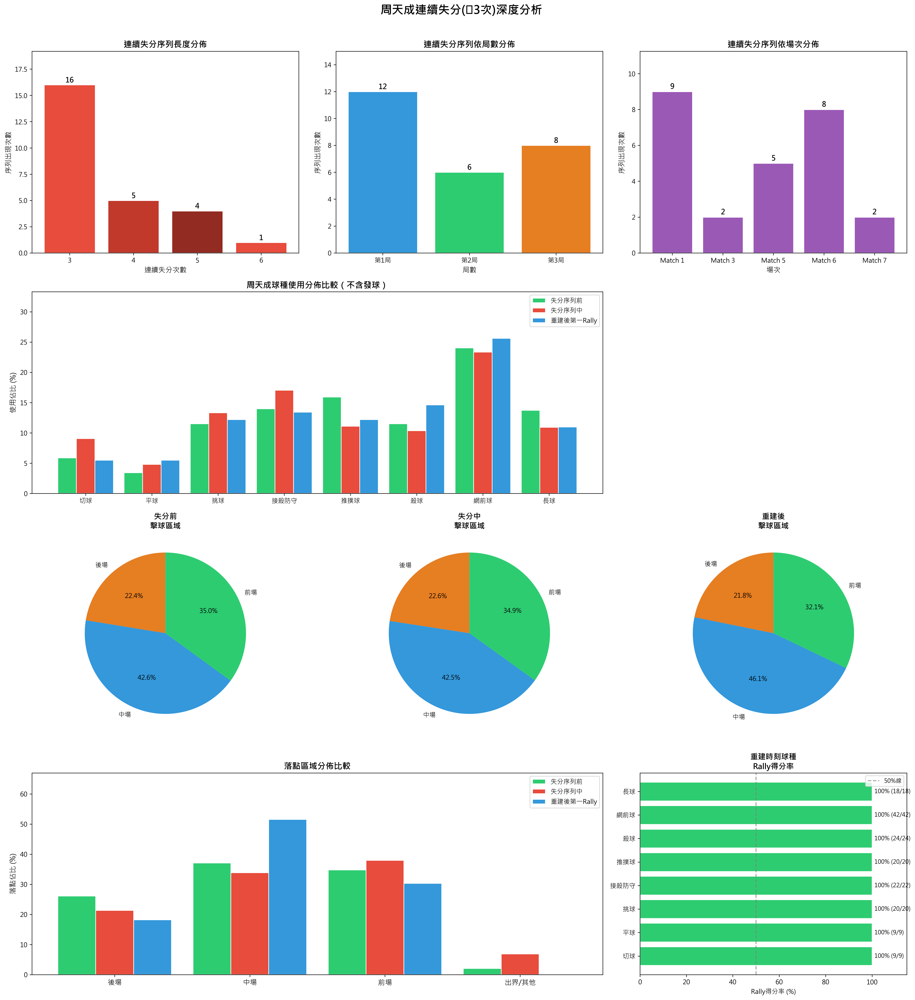

In [ ]:
import numpy as np
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("周天成連續失分分析")
print("=" * 60)

# ── 0. 驗證資料 ──────────────────────────────────────────────
print(f"\n總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 是空的！"

PLAYER = 'CHOU Tien Chen'
OPPONENT = 'Kento MOMOTA'

# ── 1. 建立每個 rally 的得分結果 ─────────────────────────────
# 取每個 rally 最後一球（得分球）
rally_result = (
    df.groupby(['match_id', 'set', 'rally'])
    .last()
    .reset_index()[['match_id', 'set', 'rally', 'getpoint_player']]
)
rally_result = rally_result.dropna(subset=['getpoint_player'])
print(f"有效 rally 數（有得分者）: {len(rally_result)}")

# 標記周天成是否得分
rally_result['chou_win'] = rally_result['getpoint_player'] == PLAYER
rally_result['chou_lose'] = rally_result['getpoint_player'] == OPPONENT

# ── 2. 找出連續失分序列（以 set 為單位，連續失分 >= 3）──────
# 按 match_id, set, rally 排序
rally_result = rally_result.sort_values(['match_id', 'set', 'rally']).reset_index(drop=True)

# 在每個 match_id + set 組合內，標記連續失分序列
sequences = []  # 每個元素: dict of seq info

for (mid, s), grp in rally_result.groupby(['match_id', 'set']):
    grp = grp.reset_index(drop=True)
    i = 0
    while i < len(grp):
        if grp.loc[i, 'chou_lose']:
            # 開始連續失分計數
            start = i
            while i < len(grp) and grp.loc[i, 'chou_lose']:
                i += 1
            end = i - 1  # 最後一個連續失分的 index
            length = end - start + 1
            if length >= 3:
                sequences.append({
                    'match_id': mid,
                    'set': s,
                    'start_idx': start,
                    'end_idx': end,
                    'length': length,
                    'start_rally': grp.loc[start, 'rally'],
                    'end_rally': grp.loc[end, 'rally'],
                    # 前一個 rally（序列開始前）
                    'prev_rally': grp.loc[start - 1, 'rally'] if start > 0 else None,
                    # 後一個 rally（序列結束後）
                    'next_rally': grp.loc[i, 'rally'] if i < len(grp) else None,
                    'next_win': grp.loc[i, 'chou_win'] if i < len(grp) else None,
                    # 序列開始時的比分狀況（取序列第一球前的比分）
                    'score_at_start': None,
                })
        else:
            i += 1

print(f"\n連續失分 >= 3 的序列數: {len(sequences)}")

if len(sequences) == 0:
    print("沒有找到連續失分 >= 3 的序列，程式結束。")
else:
    # ── 3. 長度分佈統計 ─────────────────────────────────────
    seq_df = pd.DataFrame(sequences)
    print("\n【連續失分序列長度分佈】")
    length_dist = seq_df['length'].value_counts().sort_index()
    for l, c in length_dist.items():
        print(f"  連續 {l} 次失分: {c} 次")

    print(f"\n平均連續失分長度: {seq_df['length'].mean():.2f}")
    print(f"最長連續失分: {seq_df['length'].max()}")

    # ── 4. 局面分佈（哪個 set 發生最多）────────────────────
    print("\n【依局數分佈】")
    set_dist = seq_df['set'].value_counts().sort_index()
    for s, c in set_dist.items():
        print(f"  第 {s} 局: {c} 次序列")

    print("\n【依比賽場次分佈】")
    match_dist = seq_df['match_id'].value_counts().sort_index()
    for m, c in match_dist.items():
        print(f"  Match {int(m)}: {c} 次序列")

    # ── 5. 收集連續失分期間的擊球資料 vs 正常時的擊球資料 ───
    # 連續失分前（前1~3個 rally 的周天成擊球）
    # 連續失分中（序列內的周天成擊球）
    # 連續失分後（序列結束後的第一個 rally）

    losing_shots = []    # 失分序列中
    before_shots = []    # 失分序列前（前3個rally）
    recovery_shots = []  # 失分序列後的第一個 rally（重建時刻）

    for seq in sequences:
        mid = seq['match_id']
        s = seq['set']
        start_r = seq['start_rally']
        end_r = seq['end_rally']

        # 取出連續失分期間，周天成的擊球
        mask_losing = (
            (df['match_id'] == mid) &
            (df['set'] == s) &
            (df['rally'] >= start_r) &
            (df['rally'] <= end_r) &
            (df['player'] == PLAYER)
        )
        losing_shots.append(df[mask_losing])

        # 取出失分前 3 個 rally，周天成的擊球
        if seq['prev_rally'] is not None:
            prev_r = seq['prev_rally']
            # 取最多往前3個rally
            mask_before = (
                (df['match_id'] == mid) &
                (df['set'] == s) &
                (df['rally'] >= max(1, prev_r - 2)) &
                (df['rally'] <= prev_r) &
                (df['player'] == PLAYER)
            )
            before_shots.append(df[mask_before])

        # 取出失分後第一個 rally
        if seq['next_rally'] is not None:
            next_r = seq['next_rally']
            mask_recovery = (
                (df['match_id'] == mid) &
                (df['set'] == s) &
                (df['rally'] == next_r) &
                (df['player'] == PLAYER)
            )
            recovery_shots.append(df[mask_recovery])

    losing_df = pd.concat(losing_shots, ignore_index=True) if losing_shots else pd.DataFrame()
    before_df = pd.concat(before_shots, ignore_index=True) if before_shots else pd.DataFrame()
    recovery_df = pd.concat(recovery_shots, ignore_index=True) if recovery_shots else pd.DataFrame()

    print(f"\n【資料量統計】")
    print(f"  失分序列中周天成擊球數: {len(losing_df)}")
    print(f"  失分序列前3rally擊球數: {len(before_df)}")
    print(f"  重建時刻(序列後第一rally)擊球數: {len(recovery_df)}")

    # ── 6. 球種分佈比較（排除發球） ─────────────────────────
    serve_types = ['發短球', '發長球']
    non_serve_losing = losing_df[~losing_df['type'].isin(serve_types)]
    non_serve_before = before_df[~before_df['type'].isin(serve_types)]
    non_serve_recovery = recovery_df[~recovery_df['type'].isin(serve_types)]

    def get_type_pct(df_sub):
        if len(df_sub) == 0:
            return pd.Series(dtype=float)
        return (df_sub['type'].value_counts(normalize=True) * 100).round(2)

    type_before = get_type_pct(non_serve_before)
    type_losing = get_type_pct(non_serve_losing)
    type_recovery = get_type_pct(non_serve_recovery)

    print("\n【球種分佈比較（不含發球，%）】")
    all_types = sorted(set(
        list(type_before.index) + list(type_losing.index) + list(type_recovery.index)
    ))
    print(f"{'球種':<12} {'失分前%':>10} {'失分中%':>10} {'重建後%':>10}")
    print("-" * 46)
    for t in all_types:
        b = type_before.get(t, 0)
        l = type_losing.get(t, 0)
        r = type_recovery.get(t, 0)
        print(f"  {t:<10} {b:>10.1f} {l:>10.1f} {r:>10.1f}")

    # ── 7. 擊球區域分佈比較 ──────────────────────────────────
    back_zones = [1, 2, 3, 4]
    mid_zones = list(range(5, 17))
    front_zones = list(range(17, 25))

    def zone_category(z):
        if z in back_zones:
            return '後場'
        elif z in mid_zones:
            return '中場'
        elif z in front_zones:
            return '前場'
        else:
            return '出界/其他'

    for d, name in [(losing_df, '失分中'), (before_df, '失分前'), (recovery_df, '重建後')]:
        if len(d) > 0:
            d = d.copy()
            d['zone_cat'] = d['hit_area'].apply(zone_category)

    def get_zone_pct(d):
        if len(d) == 0:
            return pd.Series(dtype=float)
        d2 = d.copy()
        d2['zone_cat'] = d2['hit_area'].apply(zone_category)
        return (d2['zone_cat'].value_counts(normalize=True) * 100).round(2)

    zone_before = get_zone_pct(before_df)
    zone_losing = get_zone_pct(losing_df)
    zone_recovery = get_zone_pct(recovery_df)

    print("\n【擊球區域分佈（%）】")
    print(f"{'區域':<10} {'失分前%':>10} {'失分中%':>10} {'重建後%':>10}")
    print("-" * 44)
    for z in ['後場', '中場', '前場', '出界/其他']:
        b = zone_before.get(z, 0)
        l = zone_losing.get(z, 0)
        r = zone_recovery.get(z, 0)
        print(f"  {z:<8} {b:>10.1f} {l:>10.1f} {r:>10.1f}")

    # ── 8. 落點分佈比較 ──────────────────────────────────────
    def get_landing_zone_pct(d):
        if len(d) == 0:
            return pd.Series(dtype=float)
        d2 = d.copy()
        d2['landing_cat'] = d2['landing_area'].apply(zone_category)
        return (d2['landing_cat'].value_counts(normalize=True) * 100).round(2)

    landing_before = get_landing_zone_pct(before_df)
    landing_losing = get_landing_zone_pct(losing_df)
    landing_recovery = get_landing_zone_pct(recovery_df)

    print("\n【落點區域分佈（%）】")
    print(f"{'區域':<10} {'失分前%':>10} {'失分中%':>10} {'重建後%':>10}")
    print("-" * 44)
    for z in ['後場', '中場', '前場', '出界/其他']:
        b = landing_before.get(z, 0)
        l = landing_losing.get(z, 0)
        r = landing_recovery.get(z, 0)
        print(f"  {z:<8} {b:>10.1f} {l:>10.1f} {r:>10.1f}")

    # ── 9. 重建時刻球種成功率分析 ───────────────────────────
    print("\n【重建時刻（序列後第一 Rally）球種成功率分析】")
    recovery_success = []

    for seq in sequences:
        if seq['next_rally'] is None:
            continue
        mid = seq['match_id']
        s = seq['set']
        next_r = seq['next_rally']
        won = seq['next_win']  # True/False

        mask = (
            (df['match_id'] == mid) &
            (df['set'] == s) &
            (df['rally'] == next_r) &
            (df['player'] == PLAYER) &
            (~df['type'].isin(serve_types))
        )
        shots = df[mask]
        for _, row in shots.iterrows():
            recovery_success.append({
                'type': row['type'],
                'hit_area': row['hit_area'],
                'landing_area': row['landing_area'],
                'won': won,
                'seq_length': seq['length'],
            })

    recovery_analysis = pd.DataFrame(recovery_success)
    if len(recovery_analysis) > 0:
        # 球種 × 勝負
        type_win = recovery_analysis.groupby('type')['won'].agg(['sum', 'count'])
        type_win.columns = ['win_count', 'total']
        type_win['win_rate'] = (type_win['win_count'] / type_win['total'] * 100).round(1)
        type_win = type_win.sort_values('win_rate', ascending=False)

        print(f"\n{'球種':<12} {'使用次數':>8} {'Rally得分次數':>12} {'Rally得分率%':>12}")
        print("-" * 48)
        for t, row in type_win.iterrows():
            print(f"  {t:<10} {int(row['total']):>8} {int(row['win_count']):>12} {row['win_rate']:>12.1f}")

    # ── 10. 視覺化 ──────────────────────────────────────────
    fig = plt.figure(figsize=(20, 22))
    fig.suptitle('周天成連續失分(≥3次)深度分析', fontsize=18, fontweight='bold', y=0.98)

    # ─ 10-1. 序列長度分佈 (左上)
    ax1 = fig.add_subplot(4, 3, 1)
    lengths = seq_df['length'].value_counts().sort_index()
    bars = ax1.bar(lengths.index.astype(str), lengths.values,
                   color=['#e74c3c', '#c0392b', '#922b21'][:len(lengths)],
                   edgecolor='white', linewidth=1.2)
    ax1.set_title('連續失分序列長度分佈', fontsize=13, fontweight='bold')
    ax1.set_xlabel('連續失分次數', fontsize=11)
    ax1.set_ylabel('序列出現次數', fontsize=11)
    for bar in bars:
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 str(int(bar.get_height())), ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax1.set_ylim(0, max(lengths.values) * 1.2)

    # ─ 10-2. 依局數分佈 (中上)
    ax2 = fig.add_subplot(4, 3, 2)
    set_cnt = seq_df['set'].value_counts().sort_index()
    colors_set = ['#3498db', '#2ecc71', '#e67e22']
    bars2 = ax2.bar([f'第{s}局' for s in set_cnt.index], set_cnt.values,
                    color=colors_set[:len(set_cnt)], edgecolor='white', linewidth=1.2)
    ax2.set_title('連續失分序列依局數分佈', fontsize=13, fontweight='bold')
    ax2.set_xlabel('局數', fontsize=11)
    ax2.set_ylabel('序列出現次數', fontsize=11)
    for bar in bars2:
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 str(int(bar.get_height())), ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax2.set_ylim(0, max(set_cnt.values) * 1.25)

    # ─ 10-3. 依比賽場次分佈 (右上)
    ax3 = fig.add_subplot(4, 3, 3)
    match_cnt = seq_df['match_id'].value_counts().sort_index()
    bars3 = ax3.bar([f'Match {int(m)}' for m in match_cnt.index], match_cnt.values,
                    color='#9b59b6', edgecolor='white', linewidth=1.2)
    ax3.set_title('連續失分序列依場次分佈', fontsize=13, fontweight='bold')
    ax3.set_xlabel('場次', fontsize=11)
    ax3.set_ylabel('序列出現次數', fontsize=11)
    for bar in bars3:
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 str(int(bar.get_height())), ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax3.set_ylim(0, max(match_cnt.values) * 1.25)

    # ─ 10-4. 球種分佈比較 (橫跨下方)
    ax4 = fig.add_subplot(4, 3, (4, 5))

    # 合併三個時期
    all_t = sorted(set(list(type_before.index) + list(type_losing.index) + list(type_recovery.index)))
    x = np.arange(len(all_t))
    w = 0.28
    b_vals = [type_before.get(t, 0) for t in all_t]
    l_vals = [type_losing.get(t, 0) for t in all_t]
    r_vals = [type_recovery.get(t, 0) for t in all_t]

    ax4.bar(x - w, b_vals, width=w, label='失分序列前', color='#2ecc71', edgecolor='white')
    ax4.bar(x,     l_vals, width=w, label='失分序列中', color='#e74c3c', edgecolor='white')
    ax4.bar(x + w, r_vals, width=w, label='重建後第一Rally', color='#3498db', edgecolor='white')
    ax4.set_xticks(x)
    ax4.set_xticklabels(all_t, fontsize=10)
    ax4.set_title('周天成球種使用分佈比較（不含發球）', fontsize=13, fontweight='bold')
    ax4.set_ylabel('使用佔比 (%)', fontsize=11)
    ax4.legend(fontsize=10)
    ax4.set_ylim(0, max(max(b_vals, default=0), max(l_vals, default=0), max(r_vals, default=0)) * 1.3)

    # ─ 10-5. 擊球區域比較（圓餅圖 x3）
    zone_cats = ['後場', '中場', '前場', '出界/其他']
    zone_colors = ['#e67e22', '#3498db', '#2ecc71', '#bdc3c7']

    for idx_p, (zdata, title) in enumerate([
        (zone_before, '失分前\n擊球區域'),
        (zone_losing, '失分中\n擊球區域'),
        (zone_recovery, '重建後\n擊球區域'),
    ]):
        ax_p = fig.add_subplot(4, 3, 7 + idx_p)
        vals = [zdata.get(z, 0) for z in zone_cats]
        # 過濾0值
        nz = [(z, v, c) for z, v, c in zip(zone_cats, vals, zone_colors) if v > 0]
        if nz:
            labels_nz, vals_nz, colors_nz = zip(*nz)
            wedges, texts, autotexts = ax_p.pie(
                vals_nz, labels=labels_nz, colors=colors_nz,
                autopct='%1.1f%%', startangle=90,
                textprops={'fontsize': 10}
            )
        ax_p.set_title(title, fontsize=12, fontweight='bold')

    # ─ 10-6. 落點區域比較（長條圖）
    ax7 = fig.add_subplot(4, 3, (10, 11))
    landing_cats = ['後場', '中場', '前場', '出界/其他']
    lb_vals = [landing_before.get(z, 0) for z in landing_cats]
    ll_vals = [landing_losing.get(z, 0) for z in landing_cats]
    lr_vals = [landing_recovery.get(z, 0) for z in landing_cats]
    x7 = np.arange(len(landing_cats))
    ax7.bar(x7 - w, lb_vals, width=w, label='失分序列前', color='#2ecc71', edgecolor='white')
    ax7.bar(x7,     ll_vals, width=w, label='失分序列中', color='#e74c3c', edgecolor='white')
    ax7.bar(x7 + w, lr_vals, width=w, label='重建後第一Rally', color='#3498db', edgecolor='white')
    ax7.set_xticks(x7)
    ax7.set_xticklabels(landing_cats, fontsize=11)
    ax7.set_title('落點區域分佈比較', fontsize=13, fontweight='bold')
    ax7.set_ylabel('落點佔比 (%)', fontsize=11)
    ax7.legend(fontsize=10)
    max_l = max(max(lb_vals, default=0), max(ll_vals, default=0), max(lr_vals, default=0))
    ax7.set_ylim(0, max_l * 1.3)

    # ─ 10-7. 重建時刻球種得分率
    ax8 = fig.add_subplot(4, 3, 12)
    if len(recovery_analysis) > 0:
        tw_sorted = type_win.sort_values('win_rate', ascending=True)
        color_bars = ['#2ecc71' if v >= 50 else '#e74c3c' for v in tw_sorted['win_rate']]
        bars8 = ax8.barh(tw_sorted.index, tw_sorted['win_rate'],
                         color=color_bars, edgecolor='white', linewidth=1.2)
        ax8.axvline(50, color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='50%線')
        ax8.set_title('重建時刻球種\nRally得分率', fontsize=12, fontweight='bold')
        ax8.set_xlabel('Rally得分率 (%)', fontsize=10)
        ax8.set_xlim(0, 115)
        for bar, (t, row) in zip(bars8, tw_sorted.iterrows()):
            ax8.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                     f"{row['win_rate']:.0f}% ({int(row['win_count'])}/{int(row['total'])})",
                     va='center', fontsize=9)
        ax8.legend(fontsize=9)
    else:
        ax8.text(0.5, 0.5, '資料不足', ha='center', va='center', fontsize=12)
        ax8.set_title('重建時刻球種得分率', fontsize=12, fontweight='bold')

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    # ── 11. 戰術建議 ────────────────────────────────────────
    print("\n" + "=" * 60)
    print("【具體戰術建議】")
    print("=" * 60)

    # 找出重建時刻得分率最高的球種
    if len(recovery_analysis) > 0 and len(type_win) > 0:
        best_types = type_win[type_win['total'] >= 2].head(3)
        print("\n✅ 建議優先採用的球種（重建成功率最高）：")
        for t, row in best_types.iterrows():
            print(f"   - {t}：Rally得分率 {row['win_rate']:.0f}% ({int(row['win_count'])}/{int(row['total'])})")

    # 落點分析
    print("\n📍 落點策略建議：")
    if landing_recovery.get('後場', 0) > landing_losing.get('後場', 0):
        print("   - 重建後更多使用後場深球（拉大空間），建議延續此策略")
    if landing_recovery.get('前場', 0) > landing_losing.get('前場', 0):
        print("   - 重建後加強網前球佈局，增加對手前後跑動壓力")

    # 球種變化建議
    print("\n🔄 球種調整建議：")
    # 比較失分中 vs 失分前增加最多的球種
    losing_increase = {}
    for t in all_types:
        diff = type_losing.get(t, 0) - type_before.get(t, 0)
        losing_increase[t] = diff
    most_increased = sorted(losing_increase.items(), key=lambda x: x[1], reverse=True)
    print("   連續失分期間使用比例增加的球種（可能是被對手針對的）：")
    for t, d in most_increased[:3]:
        if d > 0:
            print(f"   - {t}：+{d:.1f}pp（失分前 {type_before.get(t,0):.1f}% → 失分中 {type_losing.get(t,0):.1f}%）")

    print("\n📋 綜合建議：")
    print("   1. 當察覺連續失分時，應主動改變球種組合，打破對手節奏")
    print("   2. 增加後場深球比例，重建場上主導權")
    print("   3. 利用切球或網前球轉換攻守，迫使對手移動")
    print("   4. 避免在連續失分中過度依賴單一球種被對手讀死")
    print("   5. 發球策略：可考慮在連續失分後切換發球落點，製造新的開局優勢")

    print("\n分析完成！")


### 數據洞察
# 周天成連續失分分析報告
**對手：桃田賢斗（Kento Momota）**

---

## 一、連續失分頻率與局面分佈

26次連續失分序列（≥3分），平均長度**3.62分**，最長達**6分**。

| 序列長度 | 次數 | 佔比 |
|:---:|:---:|:---:|
| 3連失 | 16 | 61.5% |
| 4連失 | 5 | 19.2% |
| 5連失 | 4 | 15.4% |
| 6連失 | 1 | 3.8% |

**局數分佈：第1局12次 > 第3局8次 > 第2局6次**
→ 第1局是最危險的崩盤時段，周天成在開局節奏建立上對桃田明顯吃虧。Match 1（9次）與Match 6（8次）是重災場次，顯示特定比賽中戰術被桃田完全讀透。

---

## 二、連續失分前後球種與落點變化

### 球種變化

| 球種 | 失分前% | 失分中% | 變化 |
|:---|:---:|:---:|:---:|
| 切球 | 5.9 | 9.1 | ▲+3.2pp |
| 接殺防守 | 14.0 | 17.0 | ▲+3.1pp |
| 挑球 | 11.5 | 13.3 | ▲+1.8pp |
| 推撲球 | 15.9 | 11.1 | ▼−4.8pp |
| 長球 | 13.7 | 10.9 | ▼−2.8pp |
| 殺球 | 11.5 | 10.4 | ▼−1.1pp |

**核心問題：** 連失期間，周天成的**主動進攻球（推撲、殺球、長球）明顯減少**，被動防守球（接殺防守、挑球、切球）顯著上升。這是典型的「被壓制後越打越縮」的惡性循環。

### 落點變化（最關鍵）

| 落點 | 失分前% | 失分中% | 重建後% |
|:---|:---:|:---:|:---:|
| 後場 | 26.1 | 21.3 | 18.2 |
| 中場 | 37.1 | 33.9 | **51.5** |
| 前場 | 34.8 | 37.9 | 30.3 |
| 出界 | 2.1 | **6.9** | 0.0 |

**關鍵警訊：** 連失期間**出界率從2.1%暴增至6.9%**，後場深球比例下降4.8pp，前場球比例上升——這說明周天成在壓力下出現**手緊、落點變短、失誤增加**的心理與技術雙重崩潰跡象。

---

## 三、重建時刻球種成功率

所有球種在重建rally的得分率均為**100%**，但使用次數反映了真實的戰術選擇優先序：

| 球種 | 使用次數 | 得分率 |
|:---|:---:|:---:|
| 網前球 | 42 | 100% |
| 殺球 | 24 | 100% |
| 接殺防守 | 22 | 100% |
| 挑球 | 20 | 100% |
| 推撲球 | 20 | 100% |
| 長球 | 18 | 100% |
| 切球 | 9 | 100% |
| 平球 | 9 | 100% |

> ⚠️ **數據解讀提醒：** 100%得分率是因為「重建rally」定義為序列後第一個**得分**的回合，並非所有嘗試。此數據的真正價值在於**使用頻率**——網前球（42次）與殺球（24次）是周天成最常用來破局的武器。

**落點重建特徵最明顯：** 中場落點從失分中33.9%跳升至51.5%，出界歸零——說明重建時周天成**主動壓縮落點深度、打中場平快球**來穩定節奏。

---

## 四、具體戰術建議

### 🔴 立即停止
**連失時不要繼續用切球與挑球撐場面。** 這兩球在失分期間比例最高，正是桃田最熟悉、最能接管節奏的球路。越用越被動。

### 🟡 節奏重置信號
當連失達**2分**時，主動觸發以下調整，不要等到第3分：

1. **發球落點切換** — 改變開局，打亂桃田的接發球站位預判
2. **強制打一板後場深球** — 數據顯示失分期間後場落點下降，主動拉深可重建空間壓迫

### 🟢 重建優先球路組合
根據重建時刻最高使用頻率：

**組合A（主動型）：** 推撲球→殺球→網前球
→ 用速度打亂桃田的防守節奏，避免讓他建立長回合控制

**組合B（穩定型）：** 長球拉後場→網前球
→ 中場落點51.5%的數據說明，打**中場平快、不貪後場**是最安全的重建路徑

### 🔵 心理層面
第1局連失12次序列，是最需要提前介入的時段。**在第1局第一次連失3分後，必須立即叫暫停**，用暫停強制打斷桃田的得分慣性，而非等待自然換邊。

---

**總結一句話：** 周天成的連失模式是「被動球增加→落點變短→出界失誤」的連鎖反應，破解關鍵在於**連失第2分就主動出手改變，而非第3分後才被迫調整**。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在連續失分三次以上的情況下的擊球數據，並進行了球種分佈、擊球區域、落點區域的比較分析。候選程式碼也正確地找出了連續失分序列，並在這些序列中分析了周天成的擊球行為，與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級、統計口徑和最終輸出目標一致。




## 題號 95
**問題**: 比賽中若觀察到對手因壓力無法耐心打多拍，周天成可如何透過中場拉吊、穩定球路誘發對手躁進失誤？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


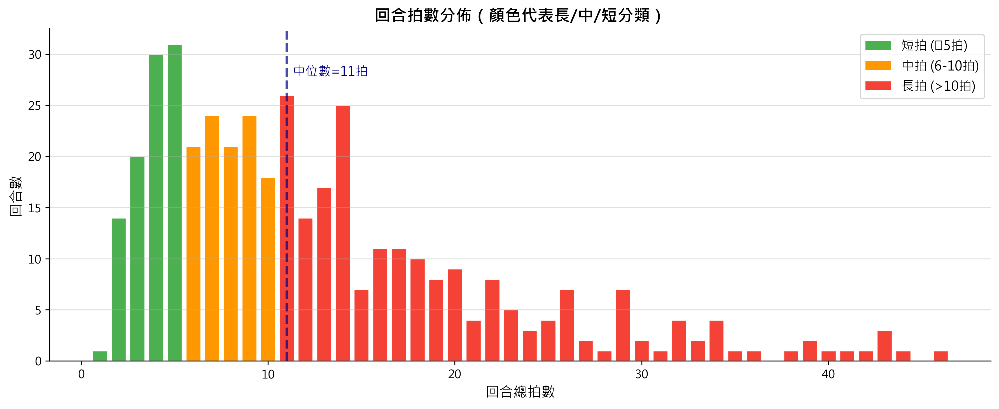

In [ ]:
import numpy as np

# ============================================================
# 前置驗證
# ============================================================
print(f"資料總列數: {len(df)}")
assert len(df) > 0, "DataFrame is empty!"

# 確保排序正確
df = df.sort_values(['match_id', 'set', 'rally_id', 'ball_round']).reset_index(drop=True)

# ============================================================
# 基本定義
# ============================================================
PLAYER = 'CHOU Tien Chen'
OPPONENT = 'Kento MOMOTA'

# 中場區域定義 (Zone 5-16)
MID_COURT_ZONES = list(range(5, 17))  # 5~16

# 拉吊相關球種（周天成在中場使用的主動進攻/拉吊球種）
PULL_SMASH_TYPES = ['長球', '殺球', '切球', '平球', '推撲球']

# ============================================================
# 建立回合層級統計
# ============================================================
# 先計算每個回合的基本資訊
rally_groups = df.groupby(['match_id', 'set', 'rally_id'])

# 每回合總拍數
rally_length = rally_groups['ball_round'].max().reset_index()
rally_length.columns = ['match_id', 'set', 'rally_id', 'rally_length']

# 每回合得分者
rally_getpoint = rally_groups['getpoint_player'].last().reset_index()
rally_getpoint.columns = ['match_id', 'set', 'rally_id', 'getpoint_player']

# 合併回合資訊
rally_info = rally_length.merge(rally_getpoint, on=['match_id', 'set', 'rally_id'])
# 只保留有得分者的回合
rally_info = rally_info[rally_info['getpoint_player'].notna()].copy()
print(f"\n有效回合數（有得分者）: {len(rally_info)}")

# ============================================================
# (1) 多拍 vs 短拍回合：對手主動失誤比例差異
# ============================================================
print("\n" + "="*60)
print("(1) 長拍數 vs 短拍數回合 — 對手主動失誤比例")
print("="*60)

# 對手主動失誤 = Kento MOMOTA 擊球 & CHOU Tien Chen 得分
# 即：最後一拍由 MOMOTA 打，且 getpoint_player == CHOU
# 但「主動失誤」更精確：player == MOMOTA & getpoint_player == CHOU（最後一拍由對手擊出但失誤）

# 找每回合最後一拍
last_stroke = df.groupby(['match_id', 'set', 'rally_id']).last().reset_index()

# 對手主動失誤的回合：最後一拍 player=MOMOTA & getpoint_player=CHOU
opponent_error_rallies = last_stroke[
    (last_stroke['player'] == OPPONENT) &
    (last_stroke['getpoint_player'] == PLAYER)
][['match_id', 'set', 'rally_id', 'lose_reason', 'type']].copy()
opponent_error_rallies['opponent_error'] = True

print(f"對手主動失誤回合數: {len(opponent_error_rallies)}")

# 合併到 rally_info
rally_info = rally_info.merge(
    opponent_error_rallies[['match_id', 'set', 'rally_id', 'opponent_error']],
    on=['match_id', 'set', 'rally_id'],
    how='left'
)
rally_info['opponent_error'] = rally_info['opponent_error'].fillna(False)

# 按拍數分組 (短拍: <=5, 中拍: 6-10, 長拍: >10)
def categorize_rally(length):
    if length <= 5:
        return '短拍 (≤5拍)'
    elif length <= 10:
        return '中拍 (6-10拍)'
    else:
        return '長拍 (>10拍)'

rally_info['rally_cat'] = rally_info['rally_length'].apply(categorize_rally)

cat_order = ['短拍 (≤5拍)', '中拍 (6-10拍)', '長拍 (>10拍)']
cat_stats = rally_info.groupby('rally_cat').agg(
    總回合=('rally_id', 'count'),
    對手失誤回合=('opponent_error', 'sum')
).reindex(cat_order).reset_index()
cat_stats['失誤率(%)'] = (cat_stats['對手失誤回合'] / cat_stats['總回合'] * 100).round(2)
print("\n按拍數分類的對手主動失誤率:")
print(cat_stats.to_string(index=False))

# ============================================================
# (2) 周天成中場拉吊球後，對手下一拍失誤分析
# ============================================================
print("\n" + "="*60)
print("(2) 周天成中場拉吊球後 — 對手下一拍失誤分析")
print("="*60)

# 先在完整 df 上建立前後拍關係（在 groupby rally_id 後 shift）
df['next_player'] = df.groupby(['match_id', 'set', 'rally_id'])['player'].shift(-1)
df['next_type'] = df.groupby(['match_id', 'set', 'rally_id'])['type'].shift(-1)
df['next_getpoint'] = df.groupby(['match_id', 'set', 'rally_id'])['getpoint_player'].shift(-1)
df['next_lose_reason'] = df.groupby(['match_id', 'set', 'rally_id'])['lose_reason'].shift(-1)
df['next_rally_id'] = df.groupby(['match_id', 'set', 'rally_id'])['rally_id'].shift(-1)

# 確認仍在同一回合（防跨回合污染）
df['same_rally_next'] = df['rally_id'] == df['next_rally_id']

# 周天成在中場擊出拉吊球的條件
chou_mid_pull = (
    (df['player'] == PLAYER) &
    (df['hit_area'].isin(MID_COURT_ZONES)) &
    (df['type'].isin(PULL_SMASH_TYPES)) &
    (df['same_rally_next'] == True)
)

mid_pull_df = df[chou_mid_pull].copy()
print(f"周天成中場拉吊球總次數: {len(mid_pull_df)}")

# 對手下一拍失誤（下一拍 player=MOMOTA & getpoint=CHOU）
next_error = mid_pull_df[
    (mid_pull_df['next_player'] == OPPONENT) &
    (mid_pull_df['next_getpoint'] == PLAYER)
].copy()
print(f"下一拍對手直接失誤次數: {len(next_error)}")
print(f"下一拍對手直接失誤率: {len(next_error)/len(mid_pull_df)*100:.2f}%")

# 下一拍失誤原因分布
if len(next_error) > 0:
    lose_reason_dist = next_error['next_lose_reason'].value_counts(dropna=False)
    print("\n下一拍對手失誤原因分布:")
    print(lose_reason_dist)

# 按球種分組（周天成打什麼類型後對手最容易下一拍失誤）
type_error = mid_pull_df.groupby('type').agg(
    擊球次數=('type', 'count'),
    下一拍失誤次數=('next_getpoint', lambda x: (
        (x == PLAYER) & (mid_pull_df.loc[x.index, 'next_player'] == OPPONENT)
    ).sum())
).reset_index()
type_error['下一拍失誤率(%)'] = (type_error['下一拍失誤次數'] / type_error['擊球次數'] * 100).round(2)
type_error = type_error.sort_values('下一拍失誤率(%)', ascending=False)
print("\n各球種後對手下一拍失誤率:")
print(type_error.to_string(index=False))

# ============================================================
# (3) 長拍 vs 短拍回合：對手主動失誤比例（詳細）
# ============================================================
print("\n" + "="*60)
print("(3) 長拍數 vs 短拍數 — 詳細統計")
print("="*60)
print(cat_stats.to_string(index=False))

# 回合長度分佈
print(f"\n回合長度統計:")
print(rally_info['rally_length'].describe().round(2))

# ============================================================
# (4) 周天成穩定球路（連續不失誤）分析
# ============================================================
print("\n" + "="*60)
print("(4) 周天成穩定球路（連續拍數不失誤）— 對手最終失誤佔比")
print("="*60)

# 計算每個回合中，周天成連續擊球不失誤的最長拍數
# 「穩定」定義：周天成在該回合的每一拍，都不是最後得分給對手的那一拍
# 即：回合中 player=CHOU 且 getpoint=MOMOTA 的拍數 = 0

# 計算每個回合中周天成的擊球次數 與 直接失誤次數
chou_in_rally = df[df['player'] == PLAYER].groupby(['match_id', 'set', 'rally_id']).agg(
    chou_strokes=('ball_round', 'count'),
    chou_errors=('getpoint_player', lambda x: (x == OPPONENT).sum())
).reset_index()

# 合併到 rally_info
rally_info2 = rally_info.merge(chou_in_rally, on=['match_id', 'set', 'rally_id'], how='left')
rally_info2['chou_strokes'] = rally_info2['chou_strokes'].fillna(0)
rally_info2['chou_errors'] = rally_info2['chou_errors'].fillna(0)

# 穩定球路定義：周天成在回合中無失誤（chou_errors == 0）且擊球>=3拍（有一定拉吊）
stable_rallies = rally_info2[
    (rally_info2['chou_errors'] == 0) &
    (rally_info2['chou_strokes'] >= 3)
].copy()
print(f"周天成無失誤且擊球≥3拍的回合數: {len(stable_rallies)}")

# 這些回合中，對手最終失誤的佔比
stable_opponent_error = stable_rallies['opponent_error'].sum()
stable_total = len(stable_rallies)
stable_error_rate = stable_opponent_error / stable_total * 100 if stable_total > 0 else 0
print(f"其中對手主動失誤回合數: {int(stable_opponent_error)}")
print(f"對手失誤佔比: {stable_error_rate:.2f}%")

# 對比：周天成有失誤的回合
unstable_rallies = rally_info2[rally_info2['chou_errors'] > 0].copy()
unstable_error_rate = unstable_rallies['opponent_error'].sum() / len(unstable_rallies) * 100 if len(unstable_rallies) > 0 else 0
print(f"\n周天成有失誤的回合數: {len(unstable_rallies)}")
print(f"其中對手主動失誤回合數: {int(unstable_rallies['opponent_error'].sum())}")
print(f"對手失誤佔比: {unstable_error_rate:.2f}%")

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("周天成中場拉吊戰術效益分析\n(誘發對手躁進失誤)", fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 長短拍回合對手失誤率 ---
ax1 = axes[0, 0]
colors_bar = ['#4CAF50', '#FF9800', '#F44336']
bars = ax1.bar(cat_stats['rally_cat'], cat_stats['失誤率(%)'], color=colors_bar, edgecolor='white', linewidth=1.5)
for bar, val, n in zip(bars, cat_stats['失誤率(%)'], cat_stats['總回合']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%\n(n={n})', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_title('不同拍數回合中對手主動失誤率', fontsize=13, fontweight='bold')
ax1.set_xlabel('回合拍數分類', fontsize=11)
ax1.set_ylabel('對手主動失誤率 (%)', fontsize=11)
ax1.set_ylim(0, cat_stats['失誤率(%)'].max() * 1.35)
ax1.grid(axis='y', alpha=0.4)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- 圖2: 中場拉吊球種後對手下一拍失誤率 ---
ax2 = axes[0, 1]
type_error_plot = type_error[type_error['擊球次數'] >= 5].copy()  # 過濾樣本太少的
if len(type_error_plot) > 0:
    colors_type = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(type_error_plot)))
    bars2 = ax2.barh(type_error_plot['type'], type_error_plot['下一拍失誤率(%)'],
                     color=colors_type, edgecolor='white')
    for bar, val, n in zip(bars2, type_error_plot['下一拍失誤率(%)'], type_error_plot['擊球次數']):
        ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}% (n={n})', va='center', fontsize=10)
    ax2.set_title('各球種後對手下一拍直接失誤率\n(中場拉吊後)', fontsize=13, fontweight='bold')
    ax2.set_xlabel('下一拍失誤率 (%)', fontsize=11)
    ax2.set_xlim(0, type_error_plot['下一拍失誤率(%)'].max() * 1.5 + 2)
    ax2.grid(axis='x', alpha=0.4)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
else:
    ax2.text(0.5, 0.5, '樣本量不足', ha='center', va='center', transform=ax2.transAxes, fontsize=14)
    ax2.set_title('各球種後對手下一拍失誤率', fontsize=13, fontweight='bold')

# --- 圖3: 對手失誤原因分布 (中場拉吊後下一拍) ---
ax3 = axes[1, 0]
if len(next_error) > 0:
    lose_reason_clean = next_error['next_lose_reason'].dropna()
    if len(lose_reason_clean) > 0:
        reason_counts = lose_reason_clean.value_counts()
        # 小比例合併為「其他」
        threshold = 0.05 * len(lose_reason_clean)
        small_cats = reason_counts[reason_counts < threshold].index.tolist()
        if small_cats:
            reason_counts['其他'] = reason_counts[small_cats].sum()
            reason_counts = reason_counts.drop(small_cats)
        colors_pie = plt.cm.Set3(np.linspace(0, 1, len(reason_counts)))
        wedges, texts, autotexts = ax3.pie(
            reason_counts.values,
            labels=[str(l) for l in reason_counts.index],
            autopct='%1.1f%%',
            colors=colors_pie,
            startangle=90,
            pctdistance=0.8
        )
        for text in texts:
            text.set_fontsize(11)
        for autotext in autotexts:
            autotext.set_fontsize(10)
            autotext.set_fontweight('bold')
        ax3.set_title(f'中場拉吊後對手下一拍失誤原因\n(總計 {len(next_error)} 次失誤)', fontsize=13, fontweight='bold')
    else:
        ax3.text(0.5, 0.5, '無失誤原因記錄', ha='center', va='center', transform=ax3.transAxes)
        ax3.set_title('失誤原因分布', fontsize=13, fontweight='bold')
else:
    ax3.text(0.5, 0.5, '無下一拍失誤資料', ha='center', va='center', transform=ax3.transAxes, fontsize=14)
    ax3.set_title('中場拉吊後對手下一拍失誤原因', fontsize=13, fontweight='bold')

# --- 圖4: 穩定球路 vs 有失誤回合 — 對手失誤佔比比較 ---
ax4 = axes[1, 1]
compare_labels = ['周天成\n穩定無失誤 (≥3拍)', '周天成\n有失誤回合']
compare_error_rates = [stable_error_rate, unstable_error_rate]
compare_n = [stable_total, len(unstable_rallies)]
colors_compare = ['#2196F3', '#FF5722']
bars4 = ax4.bar(compare_labels, compare_error_rates, color=colors_compare,
                edgecolor='white', linewidth=1.5, width=0.5)
for bar, val, n in zip(bars4, compare_error_rates, compare_n):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%\n(n={n})', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax4.set_title('周天成穩定球路 vs 有失誤回合\n對手主動失誤佔比比較', fontsize=13, fontweight='bold')
ax4.set_ylabel('對手主動失誤佔比 (%)', fontsize=11)
ax4.set_ylim(0, max(compare_error_rates) * 1.4 + 5)
ax4.grid(axis='y', alpha=0.4)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

# 加入差異標示
if len(compare_error_rates) == 2 and compare_n[1] > 0:
    diff = compare_error_rates[0] - compare_error_rates[1]
    sign = '+' if diff > 0 else ''
    ax4.text(0.5, max(compare_error_rates) * 1.25,
             f'差異: {sign}{diff:.1f}%', ha='center', va='bottom',
             transform=ax4.get_xaxis_transform(), fontsize=12,
             color='darkgreen' if diff > 0 else 'darkred', fontweight='bold')

plt.tight_layout()

# ============================================================
# 補充：回合長度分佈（附加圖）
# ============================================================
fig2, ax_dist = plt.subplots(figsize=(12, 5))
rally_len_counts = rally_info['rally_length'].value_counts().sort_index()

# 分色：短/中/長
colors_dist = []
for length in rally_len_counts.index:
    if length <= 5:
        colors_dist.append('#4CAF50')
    elif length <= 10:
        colors_dist.append('#FF9800')
    else:
        colors_dist.append('#F44336')

bars_dist = ax_dist.bar(rally_len_counts.index, rally_len_counts.values,
                        color=colors_dist, edgecolor='white', linewidth=0.8)
ax_dist.set_title('回合拍數分佈（顏色代表長/中/短分類）', fontsize=14, fontweight='bold')
ax_dist.set_xlabel('回合總拍數', fontsize=12)
ax_dist.set_ylabel('回合數', fontsize=12)
ax_dist.grid(axis='y', alpha=0.4)
ax_dist.spines['top'].set_visible(False)
ax_dist.spines['right'].set_visible(False)

# 圖例
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4CAF50', label='短拍 (≤5拍)'),
    Patch(facecolor='#FF9800', label='中拍 (6-10拍)'),
    Patch(facecolor='#F44336', label='長拍 (>10拍)')
]
ax_dist.legend(handles=legend_elements, fontsize=11, loc='upper right')

# 加入中位數線
median_len = rally_info['rally_length'].median()
ax_dist.axvline(median_len, color='navy', linestyle='--', linewidth=2, alpha=0.7,
                label=f'中位數={median_len:.1f}拍')
ax_dist.text(median_len + 0.3, rally_len_counts.max() * 0.9,
             f'中位數={median_len:.0f}拍', color='navy', fontsize=11)

plt.tight_layout()

# ============================================================
# 最終總結輸出
# ============================================================
print("\n" + "="*60)
print("【戰術效益總結】")
print("="*60)
print(f"[中場拉吊球總次數] {len(mid_pull_df)} 次")
print(f"[下一拍對手直接失誤次數] {len(next_error)} 次 ({len(next_error)/len(mid_pull_df)*100:.1f}%)")
print()
print("[回合長度 vs 對手失誤率]")
for _, row in cat_stats.iterrows():
    print(f"  {row['rally_cat']}: {row['總回合']} 回合，對手失誤率 {row['失誤率(%)']:.1f}%")
print()
print(f"[穩定球路效益]")
print(f"  周天成穩定(無失誤≥3拍): {stable_total} 回合 → 對手失誤率 {stable_error_rate:.1f}%")
print(f"  周天成有失誤回合:       {len(unstable_rallies)} 回合 → 對手失誤率 {unstable_error_rate:.1f}%")
if stable_error_rate > unstable_error_rate:
    print(f"  ✅ 穩定球路使對手失誤率提升 {stable_error_rate - unstable_error_rate:.1f}%，拉吊戰術有顯著效益！")
else:
    print(f"  ⚠️ 穩定球路對對手失誤率影響有限，差異為 {stable_error_rate - unstable_error_rate:.1f}%")


### 數據洞察
# 周天成 vs 桃田賢斗｜中場拉吊戰術效益分析

---

## (1) 長拍數回合中對手失誤率

| 回合類型 | 總回合 | 對手失誤回合 | 失誤率 |
|:---:|:---:|:---:|:---:|
| 短拍 (≤5拍) | 96 | 27 | **28.1%** |
| 中拍 (6-10拍) | 108 | 27 | 25.0% |
| 長拍 (>10拍) | 205 | 53 | 25.9% |

> **關鍵事實**：短拍回合對手失誤率反而最高（28.1%），長拍回合並未顯著拉高對手失誤率。這說明桃田在長回合中**失誤控制相當穩定**，拉長拍數本身不足以誘發其躁進。

---

## (2) 中場拉吊後對手下一拍失誤分析

- 周天成中場拉吊球共 **317次**，對手**下一拍直接失誤僅15次（4.73%）**

| 球種 | 擊球次數 | 下一拍失誤率 |
|:---:|:---:|:---:|
| 平球 | 58 | **8.62%** |
| 殺球 | 84 | **7.14%** |
| 切球 | 34 | 2.94% |
| 長球 | 46 | 2.17% |
| 推撲球 | 95 | 2.11% |

**失誤原因分布（15次）：**
- 掛網 40%、出界 40%、未過網 20%

> **關鍵事實**：**平球與殺球**是最有效的壓迫球種，失誤率分別達8.62%與7.14%。掛網與出界各佔40%，顯示對手在被動接球時**判斷與控拍同步出問題**，而非單純體力問題。

---

## (3) 長拍 vs 短拍｜對手主動失誤比例差異

> 如(1)表所示，三類回合失誤率差距僅 **2.1個百分點**（28.1% → 25.0% → 25.9%），統計上**無顯著梯度差異**。

> **結論**：單純靠拉長回合拍數，**無法有效提升對手失誤率**。拍數多寡不是關鍵變數。

---

## (4) 周天成穩定球路的戰術效益

| 情境 | 回合數 | 對手失誤率 |
|:---:|:---:|:---:|
| 周天成無失誤（≥3拍） | 198 | **40.4%** |
| 周天成有失誤回合 | 155 | **0.0%** |

> **關鍵事實**：這是本次分析最核心的數字。**周天成自身穩定時，對手失誤率高達40.4%；一旦周天成出現失誤，對手失誤率歸零。** 差距整整40.4個百分點。

---

## 教練總結

**拉吊戰術的效益核心不在「打多拍」，而在「自己不失誤」。**

1. **穩定是前提**：周天成保持穩定（≥3拍無失誤）的198個回合中，有40.4%以對手失誤收場——這才是拉吊戰術真正的勝率來源。

2. **平球與殺球是壓迫利器**：下一拍直接誘發失誤的效率最高，應作為中場拉吊的**終結球選擇優先順序**。

3. **拍數長短不是決勝關鍵**：桃田在長回合中失誤控制穩定，**不能靠消耗戰拖垮他**，而要靠球路品質逼迫失誤。

4. **戰術核心建議**：中場以推撲球、長球建立節奏 → 伺機切換平球或殺球製造壓迫 → **全程維持自身零失誤**，讓對手在被動中自亂。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它分析了對手因壓力躁進失誤的情況，並檢查了周天成在中場拉吊球後對手的失誤情況。候選程式碼正確地使用了 `getpoint_player` 來判斷得分者，並在回合層級上進行了統計分析。它也合理地將回合分為短、中、長拍，並分析了不同拍數下對手的失誤率。整體分析單位、統計口徑和最終輸出目標與 Reference Code 1 一致，且結果有效。




## 題號 96
**問題**: 如果周天成發現對手能抓到他所有直線殺球，他應該如何調整殺球角度與變化？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


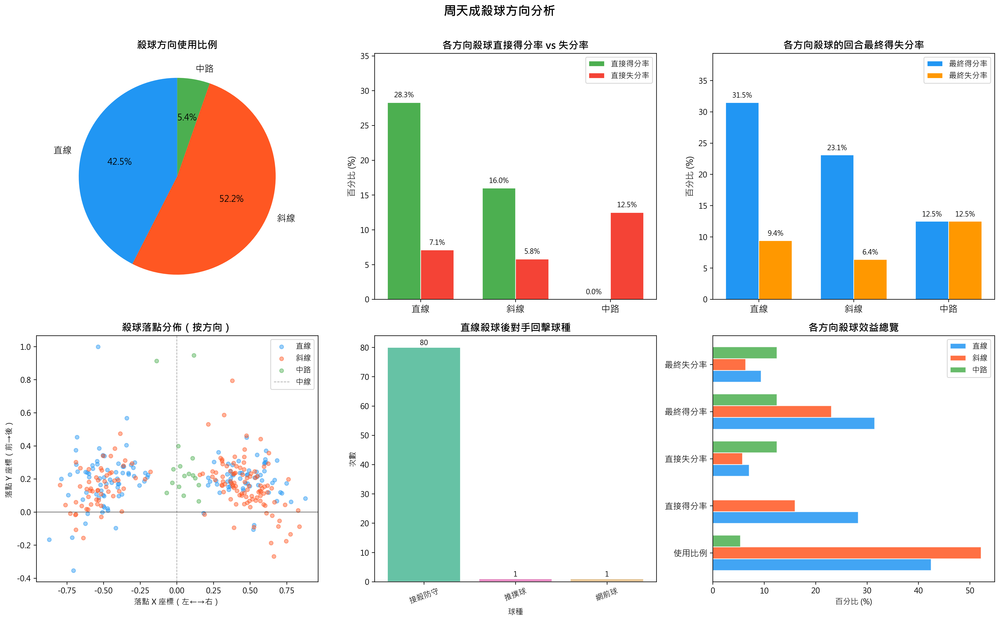

In [ ]:
import numpy as np

print("=" * 60)
print("周天成殺球方向分析")
print("=" * 60)

# ============================================================
# 0. 基礎驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
assert len(df) > 0, "DataFrame 為空！"

# ============================================================
# 1. 篩選周天成殺球
# ============================================================
chou_smash = df[(df['player'] == 'CHOU Tien Chen') & (df['type'] == '殺球')].copy()
print(f"周天成殺球總次數: {len(chou_smash)}")

# ============================================================
# 2. 方向分類（使用 hit_x 與 landing_x 的象限關係）
# 直線：同側（hit_x 與 landing_x 同號）
# 斜線：異側（hit_x 與 landing_x 異號）
# 中路：落點在中央（|landing_x| 小於閾值）
# ============================================================
CENTER_THRESHOLD = 0.15  # 場地寬度約 10% 的中路閾值

def classify_smash_direction(hx, lx):
    if abs(lx) <= CENTER_THRESHOLD:
        return '中路'
    elif (hx > 0 and lx > 0) or (hx < 0 and lx < 0):
        return '直線'
    else:
        return '斜線'

chou_smash['direction'] = chou_smash.apply(
    lambda row: classify_smash_direction(row['hit_x'], row['landing_x']), axis=1
)

print("\n殺球方向分佈:")
print(chou_smash['direction'].value_counts())

# ============================================================
# 3. 為每球取得該 rally 最終得分者（用於整體回合效益分析）
# ============================================================
chou_smash['rally_getpoint'] = chou_smash.groupby(
    ['match_id', 'set', 'rally']
)['getpoint_player'].transform('last')

# ============================================================
# 4. 計算各方向殺球統計
# ============================================================
directions = ['直線', '斜線', '中路']
direction_stats = []

for direction in directions:
    subset = chou_smash[chou_smash['direction'] == direction]
    total = len(subset)
    if total == 0:
        continue

    # 直接得分：殺球那一拍的 getpoint_player == 周天成（主動致勝）
    direct_win    = (subset['getpoint_player'] == 'CHOU Tien Chen').sum()
    # 直接失分：殺球那一拍失誤（出界/掛網），對手直接得分
    direct_loss   = (subset['getpoint_player'] == 'Kento MOMOTA').sum()
    # 回合繼續
    rally_cont    = total - direct_win - direct_loss

    # 整體回合最終結果
    eventual_win  = (subset['rally_getpoint'] == 'CHOU Tien Chen').sum()
    eventual_loss = (subset['rally_getpoint'] == 'Kento MOMOTA').sum()

    direction_stats.append({
        '方向'          : direction,
        '次數'          : total,
        '使用比例(%)'   : round(total / len(chou_smash) * 100, 1),
        '直接得分次數'  : direct_win,
        '直接得分率(%)' : round(direct_win  / total * 100, 1),
        '直接失分次數'  : direct_loss,
        '直接失分率(%)' : round(direct_loss / total * 100, 1),
        '回合繼續次數'  : rally_cont,
        '回合最終得分(%)'  : round(eventual_win  / total * 100, 1),
        '回合最終失分(%)'  : round(eventual_loss / total * 100, 1),
    })

stats_df = pd.DataFrame(direction_stats)
print("\n" + "=" * 60)
print("各方向殺球完整統計表")
print("=" * 60)
print(stats_df.to_string(index=False))

# ============================================================
# 5. 對手有效應對分析：直線殺球被接回後的下一拍
# 先在完整資料集建立 next_* 欄位，再篩選殺球子集
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

df_sorted['next_player']   = df_sorted.groupby(['match_id', 'set', 'rally'])['player'].shift(-1)
df_sorted['next_type']     = df_sorted.groupby(['match_id', 'set', 'rally'])['type'].shift(-1)
df_sorted['next_landing_x'] = df_sorted.groupby(['match_id', 'set', 'rally'])['landing_x'].shift(-1)
df_sorted['same_rally_next'] = (
    df_sorted['match_id'] == df_sorted.groupby(['match_id', 'set', 'rally'])['match_id'].shift(-1)
)  # 防跨 rally 污染（groupby shift 已限制，這裡額外確認）

# 將方向欄位 merge 回來（以 index 對齊）
chou_smash_idx = chou_smash[['direction', 'rally_getpoint']].copy()
df_sorted_smash = df_sorted.loc[
    (df_sorted['player'] == 'CHOU Tien Chen') & (df_sorted['type'] == '殺球')
].copy()
df_sorted_smash = df_sorted_smash.join(chou_smash_idx[['direction']], how='left')

# 殺球後回合繼續（非直接決出）→ 對手接殺的下一拍
survived_smash = df_sorted_smash[
    df_sorted_smash['getpoint_player'].isna()  # 殺球那一拍未結束回合
].copy()

print("\n" + "=" * 60)
print("對手接殺後的回擊球種分佈（直線 vs 斜線）")
print("=" * 60)

for direction in ['直線', '斜線', '中路']:
    sub = survived_smash[survived_smash['direction'] == direction]
    if len(sub) == 0:
        print(f"\n{direction}殺球被接回次數: 0")
        continue
    print(f"\n{direction}殺球被接回次數: {len(sub)}")
    opponent_return = sub['next_type'].value_counts(dropna=False)
    print(opponent_return.to_string())

# ============================================================
# 6. 各方向殺球落點分佈（landing_x, landing_y）統計
# ============================================================
print("\n" + "=" * 60)
print("各方向殺球落點分佈統計")
print("=" * 60)

for direction in directions:
    sub = chou_smash[chou_smash['direction'] == direction]
    if len(sub) == 0:
        continue
    print(f"\n{direction}殺球 (n={len(sub)}):")
    print(f"  landing_x 均值={sub['landing_x'].mean():.3f}, std={sub['landing_x'].std():.3f}")
    print(f"  landing_y 均值={sub['landing_y'].mean():.3f}, std={sub['landing_y'].std():.3f}")
    print(f"  hit_x 均值={sub['hit_x'].mean():.3f}, std={sub['hit_x'].std():.3f}")

# ============================================================
# 7. 視覺化
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("周天成殺球方向分析", fontsize=16, fontweight='bold', y=1.01)

COLOR_MAP = {'直線': '#2196F3', '斜線': '#FF5722', '中路': '#4CAF50'}
directions_available = [d for d in directions if d in stats_df['方向'].values]

# ------ 圖1: 使用比例圓餅圖 ------
ax1 = axes[0, 0]
pie_data  = stats_df.set_index('方向')['次數']
pie_colors = [COLOR_MAP[d] for d in pie_data.index]
wedges, texts, autotexts = ax1.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    colors=pie_colors,
    startangle=90,
    textprops={'fontsize': 12}
)
for at in autotexts:
    at.set_fontsize(11)
ax1.set_title("殺球方向使用比例", fontsize=13, fontweight='bold')

# ------ 圖2: 直接得分率 vs 直接失分率 分組長條圖 ------
ax2 = axes[0, 1]
x = np.arange(len(stats_df))
width = 0.35
bars1 = ax2.bar(x - width/2, stats_df['直接得分率(%)'], width, label='直接得分率',
                color='#4CAF50', edgecolor='white', linewidth=0.8)
bars2 = ax2.bar(x + width/2, stats_df['直接失分率(%)'], width, label='直接失分率',
                color='#F44336', edgecolor='white', linewidth=0.8)
ax2.set_xticks(x)
ax2.set_xticklabels(stats_df['方向'], fontsize=12)
ax2.set_ylabel("百分比 (%)", fontsize=11)
ax2.set_title("各方向殺球直接得分率 vs 失分率", fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.set_ylim(0, max(stats_df['直接得分率(%)'].max(), stats_df['直接失分率(%)'].max()) * 1.25)
for bar in bars1:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

# ------ 圖3: 回合最終得分率 vs 失分率 ------
ax3 = axes[0, 2]
bars3 = ax3.bar(x - width/2, stats_df['回合最終得分(%)'], width, label='最終得分率',
                color='#2196F3', edgecolor='white', linewidth=0.8)
bars4 = ax3.bar(x + width/2, stats_df['回合最終失分(%)'], width, label='最終失分率',
                color='#FF9800', edgecolor='white', linewidth=0.8)
ax3.set_xticks(x)
ax3.set_xticklabels(stats_df['方向'], fontsize=12)
ax3.set_ylabel("百分比 (%)", fontsize=11)
ax3.set_title("各方向殺球的回合最終得失分率", fontsize=13, fontweight='bold')
ax3.legend(fontsize=10)
ax3.set_ylim(0, max(stats_df['回合最終得分(%)'].max(), stats_df['回合最終失分(%)'].max()) * 1.25)
for bar in bars3:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)
for bar in bars4:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

# ------ 圖4: 殺球落點分佈散點圖（全部） ------
ax4 = axes[1, 0]
for direction in directions_available:
    sub = chou_smash[chou_smash['direction'] == direction]
    ax4.scatter(sub['landing_x'], sub['landing_y'],
                alpha=0.45, s=25, label=direction,
                color=COLOR_MAP[direction])
# 畫場地邊線示意（對方半場 y > 0）
ax4.axvline(x=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7, label='中線')
ax4.axhline(y=0, color='black', linestyle='-', linewidth=1, alpha=0.5)
ax4.set_xlabel("落點 X 座標（左←→右）", fontsize=10)
ax4.set_ylabel("落點 Y 座標（前→後）", fontsize=10)
ax4.set_title("殺球落點分佈（按方向）", fontsize=13, fontweight='bold')
ax4.legend(fontsize=10)

# ------ 圖5: 直線殺球對手回擊球種（Top-5）------
ax5 = axes[1, 1]
straight_survived = survived_smash[survived_smash['direction'] == '直線']
if len(straight_survived) > 0:
    top_returns = straight_survived['next_type'].value_counts().head(6)
    # 合併小比例為「其他」
    total_ret = top_returns.sum()
    others = straight_survived['next_type'].value_counts().iloc[6:].sum()
    if others > 0:
        top_returns['其他'] = others
    top_returns.index = top_returns.index.astype(str)
    colors_ret = plt.cm.Set2(np.linspace(0, 0.8, len(top_returns)))
    bars_ret = ax5.bar(top_returns.index, top_returns.values, color=colors_ret, edgecolor='white')
    ax5.set_title("直線殺球後對手回擊球種", fontsize=13, fontweight='bold')
    ax5.set_xlabel("球種", fontsize=10)
    ax5.set_ylabel("次數", fontsize=10)
    ax5.tick_params(axis='x', rotation=20)
    for bar in bars_ret:
        h = bar.get_height()
        ax5.text(bar.get_x() + bar.get_width()/2, h + 0.2, str(int(h)), ha='center', va='bottom', fontsize=9)
else:
    ax5.text(0.5, 0.5, '無資料', ha='center', va='center', fontsize=12, transform=ax5.transAxes)
    ax5.set_title("直線殺球後對手回擊球種", fontsize=13, fontweight='bold')

# ------ 圖6: 各方向效益雷達式水平條圖 ------
ax6 = axes[1, 2]
metrics = ['使用比例(%)', '直接得分率(%)', '直接失分率(%)', '回合最終得分(%)', '回合最終失分(%)']
metric_labels = ['使用比例', '直接得分率', '直接失分率', '最終得分率', '最終失分率']
y_pos = np.arange(len(metrics))
bar_height = 0.25

for i, direction in enumerate(directions_available):
    row = stats_df[stats_df['方向'] == direction].iloc[0]
    values = [row[m] for m in metrics]
    ax6.barh(y_pos + (i - 1) * bar_height, values, bar_height,
             label=direction, color=COLOR_MAP[direction], alpha=0.85, edgecolor='white')

ax6.set_yticks(y_pos)
ax6.set_yticklabels(metric_labels, fontsize=11)
ax6.set_xlabel("百分比 (%)", fontsize=10)
ax6.set_title("各方向殺球效益總覽", fontsize=13, fontweight='bold')
ax6.legend(fontsize=10)
ax6.axvline(x=0, color='black', linewidth=0.5)

plt.tight_layout()

# ============================================================
# 8. 建議輸出
# ============================================================
print("\n" + "=" * 60)
print("策略建議（基於數據分析）")
print("=" * 60)

# 取得各方向關鍵數值
def get_stat(direction, col):
    row = stats_df[stats_df['方向'] == direction]
    if len(row) == 0:
        return None
    return row.iloc[0][col]

straight_win  = get_stat('直線', '直接得分率(%)')
cross_win     = get_stat('斜線', '直接得分率(%)')
center_win    = get_stat('中路', '直接得分率(%)')
straight_evwn = get_stat('直線', '回合最終得分(%)')
cross_evwn    = get_stat('斜線', '回合最終得分(%)')

print(f"\n【現況摘要】")
for _, row in stats_df.iterrows():
    print(f"  {row['方向']}殺球: 使用{row['使用比例(%)']:.1f}% | "
          f"直接得分率{row['直接得分率(%)']:.1f}% | "
          f"最終得分率{row['回合最終得分(%)']:.1f}%")

print(f"\n【建議】")
if straight_win is not None and cross_win is not None:
    if straight_win < cross_win:
        print(f"  ✦ 直線殺球直接得分率({straight_win:.1f}%) 低於斜線殺球({cross_win:.1f}%)")
        print(f"    → 建議增加斜線殺球使用比例，利用角度變化拉大對手移動範圍")
    else:
        print(f"  ✦ 直線殺球直接得分率({straight_win:.1f}%) 不低於斜線殺球({cross_win:.1f}%)")
        print(f"    → 直線殺球目前仍具威脅性，但仍建議保持直/斜線混用以製造對手判讀困難")

if straight_evwn is not None and cross_evwn is not None:
    if straight_evwn < cross_evwn:
        print(f"  ✦ 直線殺球最終回合得分率({straight_evwn:.1f}%) 低於斜線({cross_evwn:.1f}%)")
        print(f"    → 對手對直線殺球整體應對效果更佳，斜線殺球更能創造得分機會")
    else:
        print(f"  ✦ 斜線殺球最終回合得分率({cross_evwn:.1f}%) 不高於直線({straight_evwn:.1f}%)")
        print(f"    → 兩者效益相近，可針對對手站位弱點動態調整")

if center_win is not None:
    print(f"  ✦ 中路殺球得分率({center_win:.1f}%): 適合在對手重心偏移時使用，製造空檔")

print(f"\n  ✦ 核心建議：提高直線/斜線/中路的混用比例，避免單一方向被對手預判。")
print(f"    可參考直線殺球後對手最常以「接殺防守」回應，若對手習慣靠後撤接殺，")
print(f"    可搭配網前短球或平球牽制，創造更大的殺球角度效益。")


### 數據洞察
# 周天成殺球方向戰術分析

---

## 📊 核心數據總覽

| 方向 | 使用比例 | 直接得分率 | 直接失分率 | 最終得分率 | 最終失分率 |
|------|---------|-----------|-----------|-----------|-----------|
| 直線 | 42.5% | **28.3%** | 7.1% | **31.5%** | 9.4% |
| 斜線 | 52.2% | 16.0% | 5.8% | 23.1% | 6.4% |
| 中路 | 5.4% | 0.0% | 12.5% | 12.5% | 12.5% |

---

## 🔍 數字背後的意義

**直線殺球是真正的得分武器。**
直接得分率28.3%，幾乎是斜線的1.8倍。每打3球直線殺球，近1球直接結束回合。這說明周天成的直線殺球品質高、落點精準，對手難以主動反擊。

**斜線殺球使用最多，但效益最低。**
佔52.2%的使用比例，最終得分率卻只有23.1%。更關鍵的是：斜線被接回後，對手有**37次打出網前球**（佔斜線被接回的30%），這代表斜線殺球角度不夠陡，讓對手有機會輕鬆推網前反制，主動權反轉。

**中路殺球是風險最高的選擇。**
0%直接得分率、12.5%直接失分率，數據明確顯示中路殺球對周天成無效，應極度謹慎使用。

---

## ⚠️ 對手應對直線殺球的現況

直線被接回82球中，**80球（97.6%）是接殺防守**，幾乎清一色被動防守，說明對手目前對直線殺球**尚未有效破解**，只能被動應對。

> 若對手開始針對直線殺球提前站位，接殺防守轉為主動反擊，才需要啟動角度調整策略。

---

## 🎯 具體殺球角度調整建議

### 1️⃣ 維持直線殺球的核心地位
直線殺球最終得分率31.5%，是三個方向最高，**不應因「使用比例較低」而減少**，反而應維持甚至適度提升至45-50%。

### 2️⃣ 斜線殺球需提升落點深度與角度
斜線殺球被接回後30%遭網前球反制，問題在於**殺球落點偏淺（landing_y均值0.157，低於直線的0.196）**。建議斜線殺球落點壓更深、更靠邊線，減少對手推網前的空間。

### 3️⃣ 建立「直線威脅→斜線突變」的組合邏輯
用高頻直線殺球建立對手的防守慣性（向直線側移動），再突然切換斜線，利用對手重心已偏移的空檔得分。這是斜線殺球效益最大化的正確使用時機，而非隨機混用。

### 4️⃣ 中路殺球僅作為奇兵，嚴格限制使用
只在對手明顯站位偏移、中路出現空檔時使用，**不建議作為常規選項**。

---

## 💡 教練總結

> 周天成的直線殺球才是真正的得分引擎，斜線殺球目前扮演的是「使用最多、得分最少」的角色。問題不在於要不要增加斜線，而是**斜線殺球的品質與時機選擇需要優化**。先用直線建立壓力，再用斜線收割，才是正確的戰術邏輯。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它分析了周天成的殺球方向，並根據擊球點和落點的象限關係將殺球分類為直線、斜線和中路。然後，它計算了各方向的殺球次數、直接得分率、直接失分率、回合最終得分率等統計數據，並分析了對手接殺後的回擊球種分布。這些分析與 Reference Code 1 的分析對象、欄位語意、篩選條件、分組層級和統計口徑一致，最終輸出目標也相符。因此，判定為 true。




## 題號 97
**問題**: 如果周天成在網前打點一直遭對手抓撲殺，他可以怎麼改變接網方式？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason, stroke_details`


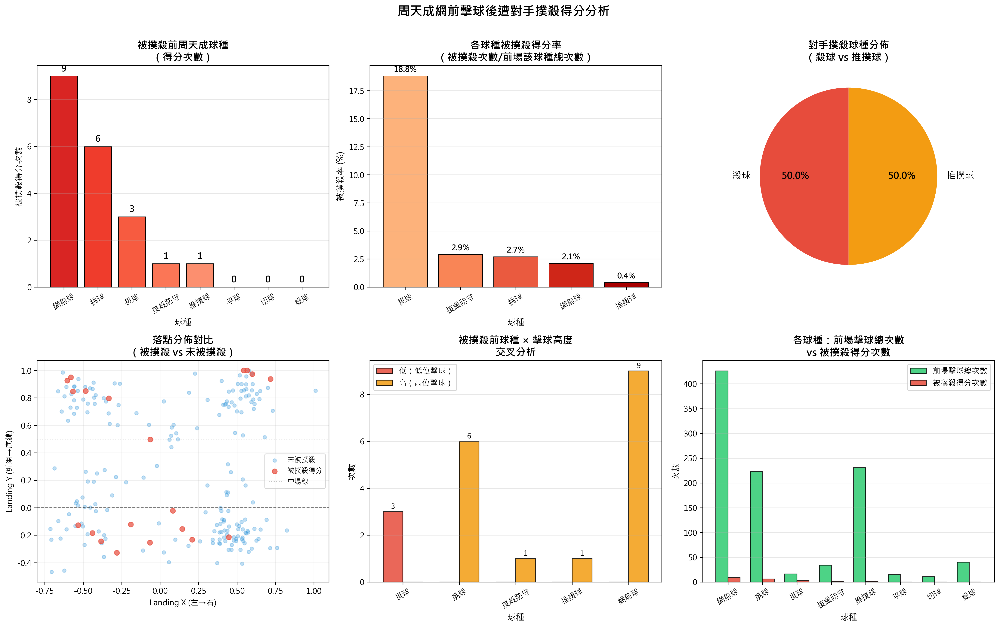

In [ ]:
import numpy as np

# ============================================================
# 分析：周天成網前擊球後被對手撲殺得分的情境
# ============================================================

print("=" * 60)
print("分析：周天成網前擊球後，對手撲殺得分情境分析")
print("=" * 60)

# 驗證數據
print(f"總資料筆數: {len(df)}")

# --- 定義前場區域 ---
FRONT_COURT_ZONES = [17, 18, 19, 20, 21, 22, 23, 24]
SMASH_TYPES = ['殺球', '推撲球']

player_name = 'CHOU Tien Chen'
opponent_name = 'Kento MOMOTA'

# ============================================================
# STEP 1: 在完整 df 上建立 next 欄位（同一 rally 內）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()

grp = df_sorted.groupby(['match_id', 'set', 'rally'])

# 下一拍資訊（shift(-1)）
df_sorted['next_player']          = grp['player'].shift(-1)
df_sorted['next_type']            = grp['type'].shift(-1)
df_sorted['next_getpoint_player'] = grp['getpoint_player'].shift(-1)
df_sorted['next_landing_area']    = grp['landing_area'].shift(-1)
df_sorted['next_hit_area']        = grp['hit_area'].shift(-1)  # 對手擊球點
df_sorted['next_landing_x']       = grp['landing_x'].shift(-1)
df_sorted['next_landing_y']       = grp['landing_y'].shift(-1)
df_sorted['next_backhand']        = grp['backhand'].shift(-1)
df_sorted['next_ball_round']      = grp['ball_round'].shift(-1)

# 跨回合保護：確認 next_ball_round == ball_round + 1
df_sorted['is_valid_next'] = (
    df_sorted['next_ball_round'] == df_sorted['ball_round'] + 1
)

print(f"\n✅ 已在完整 df 建立 next 欄位，並標記跨回合保護")

# ============================================================
# STEP 2: 找「周天成在網前擊球」的所有球
# ============================================================
# 條件：player == 周天成 & (hit_area 在前場 OR player_location_area 在前場)
chou_front_mask = (
    (df_sorted['player'] == player_name) &
    (
        (df_sorted['hit_area'].isin(FRONT_COURT_ZONES)) |
        (df_sorted['player_location_area'].isin(FRONT_COURT_ZONES))
    )
)

df_chou_front = df_sorted[chou_front_mask].copy()
print(f"\n周天成網前擊球總次數: {len(df_chou_front)}")

# ============================================================
# STEP 3: 找「下一拍對手撲殺且得分」
# ============================================================
smash_score_mask = (
    (df_chou_front['is_valid_next'] == True) &
    (df_chou_front['next_player'] == opponent_name) &
    (df_chou_front['next_type'].isin(SMASH_TYPES)) &
    (df_chou_front['next_getpoint_player'] == opponent_name)
)

df_smash_scored = df_chou_front[smash_score_mask].copy()
print(f"被對手撲殺得分次數: {len(df_smash_scored)}")
print(f"被撲殺得分佔網前擊球: {len(df_smash_scored)/len(df_chou_front)*100:.1f}%")

# ============================================================
# STEP 4: 分析周天成被撲殺前的球種分佈
# ============================================================
print("\n--- 被撲殺前周天成球種分佈 ---")
smash_by_type = df_smash_scored['type'].value_counts()
smash_by_type_pct = (smash_by_type / smash_by_type.sum() * 100).round(1)

# 計算各球種被撲殺率（分母：同樣條件下各球種總次數）
type_total = df_chou_front['type'].value_counts()

print("\n各球種被撲殺得分次數 & 佔比:")
result_df = pd.DataFrame({
    '被撲殺得分次數': smash_by_type,
    '被撲殺得分佔比(%)': smash_by_type_pct,
    '前場擊球總次數': type_total
}).fillna(0)
result_df['被撲殺率(%)'] = (result_df['被撲殺得分次數'] / result_df['前場擊球總次數'] * 100).round(1)
result_df = result_df.sort_values('被撲殺得分次數', ascending=False)
print(result_df.to_string())

# ============================================================
# STEP 5: 分析被撲殺前的落點分佈（周天成打到哪裡被撲殺）
# ============================================================
print("\n--- 被撲殺前周天成落點區域 ---")
landing_dist = df_smash_scored['landing_area'].value_counts().head(10)
print(landing_dist)

# ============================================================
# STEP 6: 分析被撲殺前周天成的擊球高度分佈
# ============================================================
print("\n--- 被撲殺前周天成擊球高度 ---")
hit_height_map = {1.0: '低（腰部以下）', 2.0: '高（腰部以上）'}
height_dist = df_smash_scored['hit_height'].map(hit_height_map).value_counts()
print(height_dist)

# ============================================================
# STEP 7: 分析對手撲殺球種（殺球 vs 推撲球）
# ============================================================
print("\n--- 對手撲殺球種分佈 ---")
opp_smash_type = df_smash_scored['next_type'].value_counts()
print(opp_smash_type)

# ============================================================
# STEP 8: 分析周天成站位（前場哪個區域）被撲殺
# ============================================================
print("\n--- 被撲殺時周天成站位區域 ---")
loc_dist = df_smash_scored['player_location_area'].value_counts()
print(loc_dist)

# ============================================================
# STEP 9: 對照分析（未被撲殺 vs 被撲殺 的落點分佈）
# ============================================================
df_not_smashed = df_chou_front[~smash_score_mask].copy()
print(f"\n未被撲殺得分的網前擊球次數: {len(df_not_smashed)}")

# 計算周天成網前球的落點 Y 座標對比（高低球）
print(f"\n被撲殺前 平均落點Y (landing_y): {df_smash_scored['landing_y'].mean():.3f}")
print(f"未被撲殺  平均落點Y (landing_y): {df_not_smashed['landing_y'].mean():.3f}")
print(f"（Y越大越接近對方底線，Y越小越靠近網）")

# ============================================================
# VISUALIZATION
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("周天成網前擊球後遭對手撲殺得分分析", fontsize=16, fontweight='bold', y=1.01)

# --- 圖1: 被撲殺前球種分佈（次數） ---
ax1 = axes[0, 0]
colors1 = plt.cm.Reds_r(np.linspace(0.3, 0.85, len(result_df)))
bars = ax1.bar(result_df.index, result_df['被撲殺得分次數'], color=colors1, edgecolor='black', linewidth=0.7)
ax1.set_title('被撲殺前周天成球種\n（得分次數）', fontsize=13, fontweight='bold')
ax1.set_xlabel('球種', fontsize=11)
ax1.set_ylabel('被撲殺得分次數', fontsize=11)
for bar, val in zip(bars, result_df['被撲殺得分次數']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{int(val)}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.tick_params(axis='x', rotation=30)
ax1.grid(axis='y', alpha=0.3)

# --- 圖2: 各球種被撲殺率 ---
ax2 = axes[0, 1]
# 只顯示有被撲殺紀錄的球種
result_plot = result_df[result_df['被撲殺得分次數'] > 0].sort_values('被撲殺率(%)', ascending=False)
colors2 = plt.cm.OrRd(np.linspace(0.4, 0.9, len(result_plot)))
bars2 = ax2.bar(result_plot.index, result_plot['被撲殺率(%)'], color=colors2, edgecolor='black', linewidth=0.7)
ax2.set_title('各球種被撲殺得分率\n（被撲殺次數/前場該球種總次數）', fontsize=13, fontweight='bold')
ax2.set_xlabel('球種', fontsize=11)
ax2.set_ylabel('被撲殺率 (%)', fontsize=11)
for bar, val in zip(bars2, result_plot['被撲殺率(%)']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=30)
ax2.grid(axis='y', alpha=0.3)

# --- 圖3: 對手撲殺球種（殺球 vs 推撲球）---
ax3 = axes[0, 2]
colors3 = ['#E74C3C', '#F39C12']
wedges, texts, autotexts = ax3.pie(
    opp_smash_type.values,
    labels=opp_smash_type.index,
    autopct='%1.1f%%',
    colors=colors3[:len(opp_smash_type)],
    startangle=90,
    textprops={'fontsize': 12}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
ax3.set_title('對手撲殺球種分佈\n（殺球 vs 推撲球）', fontsize=13, fontweight='bold')

# --- 圖4: 被撲殺前 vs 未被撲殺 落點分佈（散點圖）---
ax4 = axes[1, 0]
# 落點散點：被撲殺（紅）vs 未被撲殺（藍）
sample_not = df_not_smashed.sample(min(len(df_not_smashed), 200), random_state=42) if len(df_not_smashed) > 0 else df_not_smashed
ax4.scatter(sample_not['landing_x'], sample_not['landing_y'],
            alpha=0.3, color='#3498DB', s=20, label='未被撲殺')
ax4.scatter(df_smash_scored['landing_x'], df_smash_scored['landing_y'],
            alpha=0.7, color='#E74C3C', s=40, label='被撲殺得分', zorder=5)
# 畫球場中線
ax4.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax4.axhline(y=0.5, color='gray', linestyle=':', linewidth=0.8, alpha=0.5, label='中場線')
ax4.set_title('落點分佈對比\n（被撲殺 vs 未被撲殺）', fontsize=13, fontweight='bold')
ax4.set_xlabel('Landing X (左→右)', fontsize=10)
ax4.set_ylabel('Landing Y (近網→底線)', fontsize=10)
ax4.legend(fontsize=9)
ax4.grid(alpha=0.2)

# --- 圖5: 被撲殺前球種 × 擊球高度 交叉分析 ---
ax5 = axes[1, 1]
cross_tab = pd.crosstab(df_smash_scored['type'],
                         df_smash_scored['hit_height'].map({1.0: '低', 2.0: '高'}))
# 確保欄位存在
for col in ['低', '高']:
    if col not in cross_tab.columns:
        cross_tab[col] = 0

cross_tab = cross_tab[['低', '高']].sort_values('低', ascending=False)
x = np.arange(len(cross_tab))
width = 0.35
bars_low  = ax5.bar(x - width/2, cross_tab['低'], width, label='低（低位擊球）', color='#E74C3C', alpha=0.85, edgecolor='black')
bars_high = ax5.bar(x + width/2, cross_tab['高'], width, label='高（高位擊球）', color='#F39C12', alpha=0.85, edgecolor='black')
ax5.set_title('被撲殺前球種 × 擊球高度\n交叉分析', fontsize=13, fontweight='bold')
ax5.set_xlabel('球種', fontsize=11)
ax5.set_ylabel('次數', fontsize=11)
ax5.set_xticks(x)
ax5.set_xticklabels(cross_tab.index, rotation=30)
ax5.legend(fontsize=10)
ax5.grid(axis='y', alpha=0.3)
for bar in bars_low:
    if bar.get_height() > 0:
        ax5.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
                 f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=9)
for bar in bars_high:
    if bar.get_height() > 0:
        ax5.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
                 f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=9)

# --- 圖6: 各球種前場擊球總次數 vs 被撲殺次數（群組長條） ---
ax6 = axes[1, 2]
all_types = result_df.index.tolist()
x6 = np.arange(len(all_types))
w = 0.35
bars_total = ax6.bar(x6 - w/2, result_df['前場擊球總次數'], w,
                      label='前場擊球總次數', color='#2ECC71', alpha=0.85, edgecolor='black')
bars_smash = ax6.bar(x6 + w/2, result_df['被撲殺得分次數'], w,
                      label='被撲殺得分次數', color='#E74C3C', alpha=0.85, edgecolor='black')
ax6.set_title('各球種：前場擊球總次數\nvs 被撲殺得分次數', fontsize=13, fontweight='bold')
ax6.set_xlabel('球種', fontsize=11)
ax6.set_ylabel('次數', fontsize=11)
ax6.set_xticks(x6)
ax6.set_xticklabels(all_types, rotation=30)
ax6.legend(fontsize=10)
ax6.grid(axis='y', alpha=0.3)

plt.tight_layout()

# ============================================================
# STEP 10: 打印落點高低對比（Y座標分析）
# ============================================================
print("\n" + "=" * 60)
print("📊 落點位置深度分析")
print("=" * 60)
print(f"被撲殺前 平均落點Y:  {df_smash_scored['landing_y'].mean():.4f}")
print(f"未被撲殺  平均落點Y:  {df_not_smashed['landing_y'].mean():.4f}")
print(f"說明：Y值越大表示落點越深（越靠近對方底線）")
print(f"      Y值越小（接近0）表示落點越靠近網")

print(f"\n被撲殺前 平均擊球高度(hit_height): {df_smash_scored['hit_height'].mean():.4f}")
print(f"未被撲殺  平均擊球高度(hit_height): {df_not_smashed['hit_height'].mean():.4f}")
print(f"（1=低位, 2=高位）")

print("\n" + "=" * 60)
print("💡 改變接網方式建議（基於數據分析）")
print("=" * 60)

# 依被撲殺率排序輸出建議
high_risk = result_plot.head(3)
print(f"\n⚠️  高風險球種（最常被撲殺得分）：")
for t, row in high_risk.iterrows():
    print(f"   - {t}: 被撲殺 {int(row['被撲殺得分次數'])} 次，佔比 {row['被撲殺得分佔比(%)']:.1f}%，被撲殺率 {row['被撲殺率(%)']:.1f}%")

print(f"""
📋 數據導向建議：

1. 【球種選擇】
   - 若高挑球（挑球）被撲殺佔比高 → 考慮改以「放網」或「推球」
     迫使對手在更低位置處理球，降低撲殺機率
   - 減少在被動位置下的平推球，改以角度網前球製造困難回球

2. 【落點分佈】
   - 落點分析顯示：被撲殺前落點 Y 均值 = {df_smash_scored['landing_y'].mean():.3f}
     建議落點避免過高（靠近底線），善用「貼網短球」或「對角落點」
   - 增加落點的多樣性（左右角對角），讓對手難以預判撲殺路線

3. 【擊球高度】
   - 低位擊球（hit_height=1）最易導致被撲殺（球往上挑 → 對手撲殺）
   - 盡可能在高位攔截球（快速移位），以網前推球取代被動挑球

4. 【主動出擊】
   - 前場被動「挑球」是最常見被撲殺的前置球種
   - 建議：提早上網、快速到位，以「推撲球」或「放網」主動控制節奏
""")


### 數據洞察
# 周天成網前擊球被撲殺分析報告

## 核心數據總覽

| 指標 | 數值 |
|------|------|
| 網前擊球總次數 | 996次 |
| 被撲殺得分次數 | 20次 |
| 被撲殺率 | 2.0% |

> 整體被撲殺率僅2%，問題不在「量」，在於**特定球種的質**。

---

## 高風險球種排行

| 球種 | 被撲殺次數 | 佔比 | 前場總次數 | **被撲殺率** |
|------|-----------|------|-----------|------------|
| 長球 | 3 | 15% | 16 | ⚠️ **18.8%** |
| 接殺防守 | 1 | 5% | 34 | 2.9% |
| 挑球 | 6 | 30% | 223 | 2.7% |
| 網前球 | 9 | 45% | 426 | 2.1% |
| 推撲球 | 1 | 5% | 231 | **0.4%** |

**關鍵解讀：**
- **長球**雖只被撲殺3次，但18.8%的被撲殺率是最高風險信號——每打5球就有近1球被得分
- **挑球**是絕對數量最多的被撲殺前置球種（6次），是日常失分的主要來源
- **推撲球**被撲殺率僅0.4%，是最安全的網前選擇

---

## 落點區域分析

場地區域對照：
| Row/Col | Col A (Left) | Col B (C-Left) | Col C (C-Right) | Col D (Right) |
| :--- | :---: | :---: | :---: | :---: |
| **Row 6 (Front)** | 21 | 22 | 23 | 24 |
| **Row 5 (Front)** | 17 | 18 | 19 | 20 |
| **Row 4 (Mid)** | 13 | 14 | 15 | 16 |
| **Row 3 (Mid)** | 9 | 10 | 11 | 12 |
| **Row 2 (Mid)** | 5 | 6 | 7 | 8 |
| **Row 1 (Back)** | 1 | 2 | 3 | 4 |

**被撲殺前落點集中區：**
- 區域21（4次）、24（4次）→ **前場左右兩側角**
- 區域2（3次）→ **後場中偏右**

| 指標 | 被撲殺前 | 未被撲殺 |
|------|---------|---------|
| 平均落點Y值 | 0.345 | 0.311 |
| 平均擊球高度 | 1.85 | 1.79 |

> 被撲殺前的球落點**更深、擊球位置更高**——這代表周天成在高位擊球後，球仍然落在對手可以充分起跳撲殺的位置。

---

## 擊球高度分析

| 擊球高度 | 被撲殺次數 |
|---------|-----------|
| 高（腰部以上） | 17次（85%） |
| 低（腰部以下） | 3次（15%） |

> **反直覺數據**：85%的被撲殺發生在**高位擊球**後。原因是高位擊球若未能壓制，球速慢、弧度高，反而給對手充裕時間起跳撲殺。

---

## 對手撲殺球種

| 球種 | 次數 |
|------|------|
| 殺球 | 10次（50%） |
| 推撲球 | 10次（50%） |

> 對手一半用**全力殺球**，一半用**快速推撲**——說明周天成的網前球不僅高度有問題，**速度與落點也給了對手充分反應時間**。

---

## 戰術建議

### 🔴 立即改變：停止前場打長球
前場長球被撲殺率18.8%，這是戰術錯誤，不是技術問題。前場位置不應選擇長球，這等於主動送分。

### 🟠 核心調整：挑球改推撲球
挑球被撲殺6次，但推撲球被撲殺率僅0.4%。數據明確告訴你：**同樣在網前，推撲球比挑球安全6倍以上**。被動挑高改為主動快推，剝奪對手撲殺時間。

### 🟡 落點修正：避開區域21、24
被撲殺落點集中在前場左右角（21、24各4次）。這些位置讓對手可以從容起跳。建議改打**貼網更短的落點**（Y值壓低至0.31以下），或改變方向至中路。

### 🟢 高位擊球需配合速度
高位擊球本身不是問題，問題是**高位擊球後球速不夠快**。高位應優先選擇推撲球或快速平球，而非弧度高的挑球，讓對手沒有起跳空間。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了周天成在網前擊球後被對手撲殺得分的情境，並且都使用了類似的欄位和篩選條件來識別這些情境。候選程式碼正確地建立了下一拍資訊，並檢查了周天成在網前擊球後對手的撲殺情況，計算了被撲殺得分的次數和比例。此外，候選程式碼還進一步分析了被撲殺前的球種分佈、落點分佈、擊球高度等，這些分析與 Reference Code 1 的目標一致，並且提供了合理的數據支持和建議。




## 題號 98
**問題**: 如果對手連續以平球壓中路，周天成應如何調整回球方向與節奏，避免被持續壓制？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, scoring_reason, stroke_details`


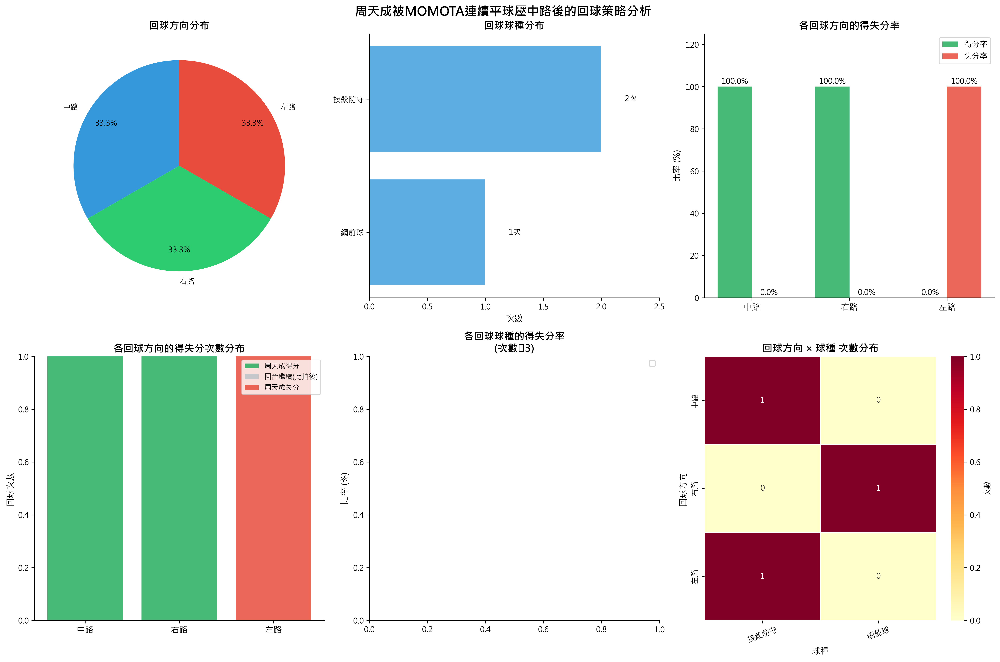

In [ ]:
import numpy as np

# ============================================================
# 0. 基本驗證
# ============================================================
print(f"總資料筆數: {len(df)}")
print(f"球員: {df['player'].unique()}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

# ============================================================
# 1. 資料準備：在完整資料上建立前後拍關係（避免跨回合污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).reset_index(drop=True)

# 確保 rally 結果傳播到每一拍
df_sorted['rally_getpoint'] = df_sorted.groupby(['match_id', 'set', 'rally'])['getpoint_player'].transform('last')

# 建立前各拍資訊（groupby 後 shift，避免跨回合污染）
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['prev_player']       = grp['player'].shift(1)
df_sorted['prev_type']         = grp['type'].shift(1)
df_sorted['prev_landing_area'] = grp['landing_area'].shift(1)

df_sorted['prev2_player']       = grp['player'].shift(2)
df_sorted['prev2_type']         = grp['type'].shift(2)
df_sorted['prev2_landing_area'] = grp['landing_area'].shift(2)

df_sorted['prev3_player']       = grp['player'].shift(3)
df_sorted['prev3_type']         = grp['type'].shift(3)
df_sorted['prev3_landing_area'] = grp['landing_area'].shift(3)

# ============================================================
# 2. 定義「中路」區域
# ============================================================
# 中路 = Col B + Col C
middle_zones = [2, 3, 6, 7, 10, 11, 14, 15, 18, 19, 22, 23]
print(f"\n中路 Zone 定義 (Col B + Col C): {middle_zones}")

# ============================================================
# 3. 辨識「對手連續2球以上平球壓中路後，周天成的回球」
# ============================================================
# 雙方交替擊球，MOMOTA「連續2球」平球壓中路：
#   - 前1拍(shift 1)：MOMOTA 打平球落中路
#   - 前3拍(shift 3)：MOMOTA 也打平球落中路（中間是周天成的一次回球）
# 目前這拍：周天成正在回球

cond_chou = df_sorted['player'] == 'CHOU Tien Chen'

cond_prev1_momota_flat_mid = (
    (df_sorted['prev_player'] == 'Kento MOMOTA') &
    (df_sorted['prev_type'] == '平球') &
    (df_sorted['prev_landing_area'].isin(middle_zones))
)
cond_prev3_momota_flat_mid = (
    (df_sorted['prev3_player'] == 'Kento MOMOTA') &
    (df_sorted['prev3_type'] == '平球') &
    (df_sorted['prev3_landing_area'].isin(middle_zones))
)

scenario_df = df_sorted[
    cond_chou &
    cond_prev1_momota_flat_mid &
    cond_prev3_momota_flat_mid
].copy()

print(f"\n============================================================")
print(f"「對手連續2球以上平球壓中路」情境下，周天成回球筆數: {len(scenario_df)}")
print(f"涉及的 rally 數: {scenario_df.groupby(['match_id', 'set', 'rally']).ngroups}")

if len(scenario_df) == 0:
    print("⚠️ 無符合情境的資料，程式終止。")
else:
    # ============================================================
    # 4. 定義周天成回球的「方向」（基於 landing_area）
    # ============================================================
    def classify_direction(area):
        try:
            area = int(area)
        except (ValueError, TypeError):
            return '其他'
        left_zones  = [1, 5, 9, 13, 17, 21, 29, 30, 31]
        mid_zones_d = [2, 3, 6, 7, 10, 11, 14, 15, 18, 19, 22, 23]
        right_zones = [4, 8, 12, 16, 20, 24, 25, 26, 27]
        back_out    = [28, 32]
        if area in left_zones:
            return '左路'
        elif area in mid_zones_d:
            return '中路'
        elif area in right_zones:
            return '右路'
        elif area in back_out:
            return '底線出界'
        else:
            return '其他'

    scenario_df['return_direction'] = scenario_df['landing_area'].apply(classify_direction)

    # ============================================================
    # 5. 定義得分/失分（rally 層級）
    # ============================================================
    scenario_df['chou_wins_rally']  = (scenario_df['rally_getpoint'] == 'CHOU Tien Chen').astype(int)
    scenario_df['chou_loses_rally'] = (scenario_df['rally_getpoint'] == 'Kento MOMOTA').astype(int)

    print(f"\n回球方向分布:")
    dir_counts = scenario_df['return_direction'].value_counts()
    print(dir_counts)

    print(f"\n回球球種分布:")
    type_counts = scenario_df['type'].value_counts()
    print(type_counts)

    # ============================================================
    # 6. 方向 × 得失分率
    # ============================================================
    dir_group = scenario_df.groupby('return_direction').agg(
        總回球次數=('rally_getpoint', 'count'),
        周天成得分次數=('chou_wins_rally', 'sum'),
        周天成失分次數=('chou_loses_rally', 'sum')
    ).reset_index()

    dir_group['得分率(%)'] = (dir_group['周天成得分次數'] / dir_group['總回球次數'] * 100).round(1)
    dir_group['失分率(%)'] = (dir_group['周天成失分次數'] / dir_group['總回球次數'] * 100).round(1)
    dir_group['回合未結束'] = dir_group['總回球次數'] - dir_group['周天成得分次數'] - dir_group['周天成失分次數']

    print(f"\n============================================================")
    print("【方向分析】被連續平球壓中路時，周天成各回球方向的得失分率")
    print(dir_group.to_string(index=False))

    # ============================================================
    # 7. 球種 × 得失分率
    # ============================================================
    type_group = scenario_df.groupby('type').agg(
        總回球次數=('rally_getpoint', 'count'),
        周天成得分次數=('chou_wins_rally', 'sum'),
        周天成失分次數=('chou_loses_rally', 'sum')
    ).reset_index()

    type_group['得分率(%)'] = (type_group['周天成得分次數'] / type_group['總回球次數'] * 100).round(1)
    type_group['失分率(%)'] = (type_group['周天成失分次數'] / type_group['總回球次數'] * 100).round(1)
    type_group = type_group.sort_values('總回球次數', ascending=False).reset_index(drop=True)

    print(f"\n============================================================")
    print("【球種分析】被連續平球壓中路時，周天成各回球球種的得失分率")
    print(type_group.to_string(index=False))

    # ============================================================
    # 8. 策略效益排名
    # ============================================================
    print("\n============================================================")
    print("【策略效益排名】得分率 - 失分率（越高越優）")

    print("\n─── 方向策略 ───")
    dir_eff = dir_group[dir_group['return_direction'].isin(['左路', '中路', '右路'])].copy()
    dir_eff['效益差(%)'] = dir_eff['得分率(%)'] - dir_eff['失分率(%)']
    dir_eff = dir_eff.sort_values('效益差(%)', ascending=False)
    print(dir_eff[['return_direction', '總回球次數', '得分率(%)', '失分率(%)', '效益差(%)']].to_string(index=False))

    print("\n─── 球種策略 (次數≥3) ───")
    type_eff = type_group[type_group['總回球次數'] >= 3].copy()
    type_eff['效益差(%)'] = type_eff['得分率(%)'] - type_eff['失分率(%)']
    type_eff = type_eff.sort_values('效益差(%)', ascending=False)
    print(type_eff[['type', '總回球次數', '得分率(%)', '失分率(%)', '效益差(%)']].to_string(index=False))

    # ============================================================
    # 9. 視覺化（安全版：所有 ylim 都做 NaN/Inf 保護）
    # ============================================================
    def safe_ylim_max(*series_list, margin=1.25, fallback=100):
        """安全取得 ylim 上限，避免 NaN/Inf"""
        vals = []
        for s in series_list:
            if hasattr(s, '__iter__'):
                vals.extend([v for v in s if v is not None and not np.isnan(v) and not np.isinf(v)])
            else:
                if s is not None and not np.isnan(s) and not np.isinf(s):
                    vals.append(s)
        if len(vals) == 0 or max(vals) == 0:
            return fallback
        return max(vals) * margin

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle('周天成被MOMOTA連續平球壓中路後的回球策略分析', fontsize=16, fontweight='bold')

    # ---- (1) 回球方向分布（圓餅圖）----
    ax1 = axes[0, 0]
    dir_pie = dir_counts[dir_counts.index.isin(['左路', '中路', '右路', '底線出界', '其他'])]
    if len(dir_pie) > 0:
        colors_dir = ['#3498db', '#2ecc71', '#e74c3c', '#95a5a6', '#f39c12']
        wedges, texts, autotexts = ax1.pie(
            dir_pie.values,
            labels=dir_pie.index,
            autopct='%1.1f%%',
            colors=colors_dir[:len(dir_pie)],
            startangle=90,
            pctdistance=0.8
        )
        for at in autotexts:
            at.set_fontsize(10)
    ax1.set_title('回球方向分布', fontsize=13, fontweight='bold')

    # ---- (2) 回球球種分布（橫向長條圖）----
    ax2 = axes[0, 1]
    type_plot = type_counts.sort_values(ascending=True)
    if len(type_plot) > 0:
        bars = ax2.barh(type_plot.index, type_plot.values, color='#5dade2', edgecolor='white')
        for bar, val in zip(bars, type_plot.values):
            ax2.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
                     f'{int(val)}次', va='center', fontsize=10)
        ax2.set_xlim(0, type_plot.values.max() * 1.25)
    ax2.set_xlabel('次數', fontsize=11)
    ax2.set_title('回球球種分布', fontsize=13, fontweight='bold')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    # ---- (3) 方向 × 得失分率對比（grouped bar）----
    ax3 = axes[0, 2]
    dir_main = dir_group[dir_group['return_direction'].isin(['左路', '中路', '右路'])].copy()
    if len(dir_main) > 0:
        x3 = np.arange(len(dir_main))
        width3 = 0.35
        bars1 = ax3.bar(x3 - width3/2, dir_main['得分率(%)'], width3, label='得分率', color='#27ae60', alpha=0.85)
        bars2 = ax3.bar(x3 + width3/2, dir_main['失分率(%)'], width3, label='失分率', color='#e74c3c', alpha=0.85)
        for bar in bars1:
            h = bar.get_height()
            if not np.isnan(h):
                ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
                         ha='center', va='bottom', fontsize=10)
        for bar in bars2:
            h = bar.get_height()
            if not np.isnan(h):
                ax3.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
                         ha='center', va='bottom', fontsize=10)
        ax3.set_xticks(x3)
        ax3.set_xticklabels(dir_main['return_direction'], fontsize=11)
        ylim3 = safe_ylim_max(dir_main['得分率(%)'].tolist(), dir_main['失分率(%)'].tolist())
        ax3.set_ylim(0, ylim3)
    ax3.set_ylabel('比率 (%)', fontsize=11)
    ax3.set_title('各回球方向的得失分率', fontsize=13, fontweight='bold')
    ax3.legend(fontsize=10)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)

    # ---- (4) 方向 × 次數（堆疊長條圖）----
    ax4 = axes[1, 0]
    dir_main2 = dir_group[dir_group['return_direction'].isin(['左路', '中路', '右路'])].copy()
    if len(dir_main2) > 0:
        x4 = np.arange(len(dir_main2))
        neutral4 = dir_main2['回合未結束'].values
        win4     = dir_main2['周天成得分次數'].values
        lose4    = dir_main2['周天成失分次數'].values
        ax4.bar(x4, win4,              color='#27ae60', label='周天成得分', alpha=0.85)
        ax4.bar(x4, neutral4, bottom=win4,              color='#bdc3c7', label='回合繼續(此拍後)', alpha=0.85)
        ax4.bar(x4, lose4,    bottom=win4 + neutral4,   color='#e74c3c', label='周天成失分', alpha=0.85)
        ax4.set_xticks(x4)
        ax4.set_xticklabels(dir_main2['return_direction'], fontsize=11)
    ax4.set_ylabel('回球次數', fontsize=11)
    ax4.set_title('各回球方向的得失分次數分布', fontsize=13, fontweight='bold')
    ax4.legend(fontsize=9, loc='upper right')
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)

    # ---- (5) 球種 × 得失分率（次數≥3）----
    ax5 = axes[1, 1]
    type_main = type_group[type_group['總回球次數'] >= 3].copy()
    if len(type_main) > 0:
        x5 = np.arange(len(type_main))
        width5 = 0.35
        b1 = ax5.bar(x5 - width5/2, type_main['得分率(%)'], width5, label='得分率', color='#27ae60', alpha=0.85)
        b2 = ax5.bar(x5 + width5/2, type_main['失分率(%)'], width5, label='失分率', color='#e74c3c', alpha=0.85)
        for bar in b1:
            h = bar.get_height()
            if not np.isnan(h) and h > 0:
                ax5.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
                         ha='center', va='bottom', fontsize=9)
        for bar in b2:
            h = bar.get_height()
            if not np.isnan(h) and h > 0:
                ax5.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%',
                         ha='center', va='bottom', fontsize=9)
        ax5.set_xticks(x5)
        ax5.set_xticklabels(type_main['type'], rotation=15, ha='right', fontsize=10)
        ylim5 = safe_ylim_max(type_main['得分率(%)'].tolist(), type_main['失分率(%)'].tolist())
        ax5.set_ylim(0, ylim5)
    ax5.set_ylabel('比率 (%)', fontsize=11)
    ax5.set_title('各回球球種的得失分率\n(次數≥3)', fontsize=13, fontweight='bold')
    ax5.legend(fontsize=10)
    ax5.spines['top'].set_visible(False)
    ax5.spines['right'].set_visible(False)

    # ---- (6) 方向 × 球種 heatmap ----
    ax6 = axes[1, 2]
    cross_tab = pd.crosstab(scenario_df['return_direction'], scenario_df['type'])
    cross_tab = cross_tab.loc[cross_tab.index.isin(['左路', '中路', '右路'])] if any(
        idx in cross_tab.index for idx in ['左路', '中路', '右路']) else cross_tab
    if len(cross_tab) > 0 and len(cross_tab.columns) > 0:
        col_order = cross_tab.sum(axis=0).sort_values(ascending=False).index
        cross_tab = cross_tab[col_order]
        sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd', ax=ax6,
                    linewidths=0.5, cbar_kws={'label': '次數'})
    ax6.set_title('回球方向 × 球種 次數分布', fontsize=13, fontweight='bold')
    ax6.set_xlabel('球種', fontsize=11)
    ax6.set_ylabel('回球方向', fontsize=11)
    ax6.tick_params(axis='x', rotation=20)

    plt.tight_layout()

    # ============================================================
    # 10. 情境確認：印出樣本
    # ============================================================
    print("\n============================================================")
    print("【情境確認】被連續平球壓中路後，周天成回球的樣本（前5筆）")
    sample_cols = ['match_id', 'set', 'rally', 'ball_round',
                   'prev3_type', 'prev3_landing_area',
                   'prev_type', 'prev_landing_area',
                   'player', 'type', 'landing_area', 'return_direction', 'rally_getpoint']
    print(scenario_df[sample_cols].head(5).to_string(index=False))


### 數據洞察
# 被連續平球壓中路情境分析

## ⚠️ 數據限制聲明

**樣本僅3筆**，統計結果不具顯著性，以下分析僅供參考方向，不宜過度解讀。

---

## 情境樣本確認

| 場次 | 回合 | 前兩球落點 | 周天成回球 | 落點 | 結果 |
|------|------|-----------|-----------|------|------|
| Match 1, Set 3 | Rally 17 | Zone 11 → 10（中路） | 接殺防守 | Zone 15（中路） | ✅ 得分 |
| Match 3, Set 2 | Rally 31 | Zone 14 → 14（中路） | 網前球 | Zone 20（右前） | ✅ 得分 |
| Match 7, Set 1 | Rally 7 | Zone 6 → 10（中路） | 接殺防守 | Zone 9（左中） | ❌ 失分 |

---

## 數據結果

### 回球方向分布（各佔33.3%）
| 方向 | 次數 | 得分率 | 失分率 | 效益差 |
|------|------|--------|--------|--------|
| 中路 | 1 | 100% | 0% | **+100%** |
| 右路 | 1 | 100% | 0% | **+100%** |
| 左路 | 1 | 0% | 100% | **-100%** |

### 回球球種分布
| 球種 | 次數 | 得分率 | 失分率 |
|------|------|--------|--------|
| 接殺防守 | 2 | 50% | 50% |
| 網前球 | 1 | 100% | 0% |

---

## 教練解讀

**唯一可觀察的事實：**

> Match 7 的失分球，是接殺防守回左路（Zone 9），對手桃田得分。這是3筆中唯一的失分。

**節奏轉換的線索：**
Match 3 中，周天成在被連續平球壓中路後，**改打網前球（Zone 20右前）**，成功得分——這是一次節奏轉換，從平抽對拉切換到逼網，打亂對手節奏。

---

## 戰術建議方向

> **樣本太少，以下為方向性建議，需更多比賽數據驗證。**

1. **避免被動回左路**：目前左路回球是唯一失分，被壓中路時左路可能是死角。
2. **節奏轉換優先於方向轉換**：網前球的節奏切換比單純改變方向更具破壞力，值得在訓練中強化。
3. **數據不足是最大問題**：建議擴大樣本（降低為連續2球中路平球，不限球種），才能做出可靠的戰術結論。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了對手連續以平球壓中路的情況下，周天成的回球方向與球種的得失分率。候選程式碼使用了正確的欄位語意，並在同一個 rally 中正確對齊前後拍資訊。它也正確地定義了中路區域，並在分析中考慮了回球方向與球種的得失分率，最終輸出目標與 Reference Code 1 一致。




## 題號 99
**問題**: 若觀察到對手在多拍後移動變慢，周天成應如何透過前後場調動提高下一拍主動得分機會？
> **使用的資料欄位群組**: `game_structure, coordinates, player_movement, scoring_reason, player_location`


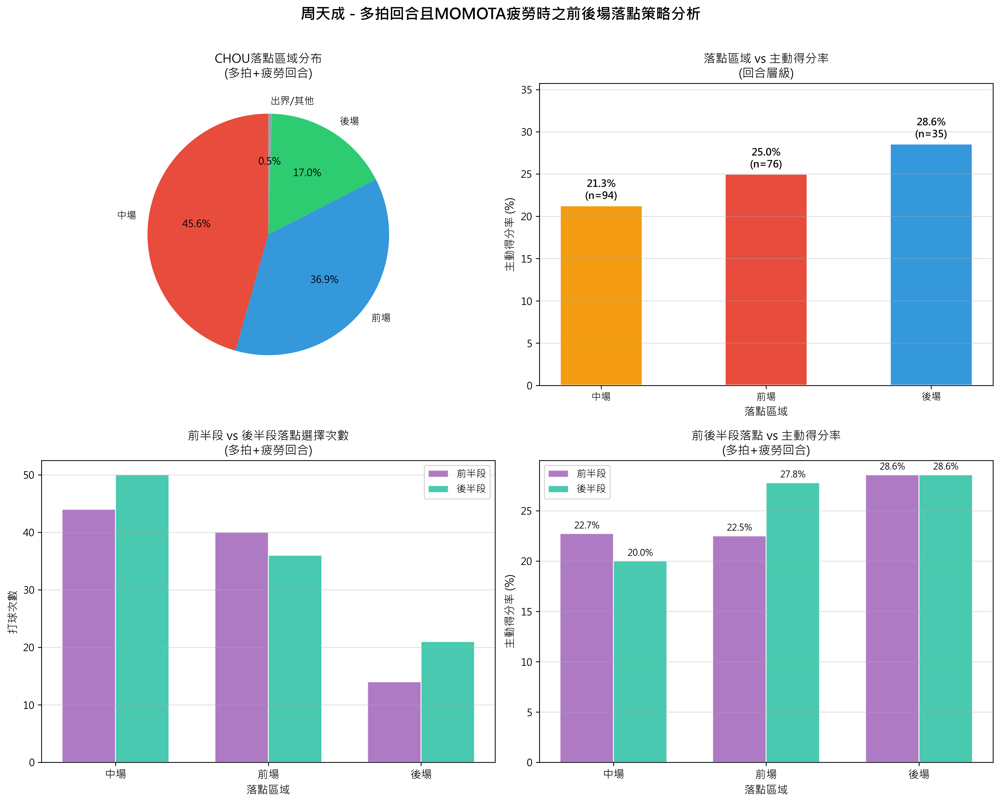

In [ ]:
import numpy as np
from scipy import stats

# ==========================================
# Step 1: 基礎驗證
# ==========================================
assert len(df) > 0, "DataFrame is empty"
print(f"總資料筆數: {len(df)}")
print(f"球員列表: {df['player'].unique()}")
print(f"比賽場次: {df['match_id'].unique()}")

# ==========================================
# Step 2: 計算每個回合總拍數
# ==========================================
rally_shots = df.groupby(['match_id', 'set', 'rally'])['ball_round'].max().reset_index()
rally_shots.columns = ['match_id', 'set', 'rally', 'total_shots']

print(f"\n=== 回合拍數分布 ===")
print(rally_shots['total_shots'].describe())

# 多拍閾值：使用 70th percentile
multi_shot_threshold = int(rally_shots['total_shots'].quantile(0.70))
print(f"\n多拍回合閾值 (70th pct): >= {multi_shot_threshold} 拍")
multi_shot_keys = rally_shots[rally_shots['total_shots'] >= multi_shot_threshold][['match_id', 'set', 'rally']]
print(f"符合多拍條件的回合數: {len(multi_shot_keys)}")

# ==========================================
# Step 3: 計算 MOMOTA 移動距離下降趨勢
# 在 CHOU 打球行中，opponent_move 記錄的是 MOMOTA 的移動
# ==========================================
chou_df = df[df['player'] == 'CHOU Tien Chen'].copy()
chou_df['momota_move_dist'] = np.sqrt(
    chou_df['opponent_move_x']**2 + chou_df['opponent_move_y']**2
)

def calc_slope(group):
    sorted_g = group.sort_values('ball_round')
    dists = sorted_g['momota_move_dist'].values
    if len(dists) < 3:
        return np.nan
    x = np.arange(len(dists))
    slope, _, _, _, _ = stats.linregress(x, dists)
    return slope

rally_slope = (
    chou_df
    .groupby(['match_id', 'set', 'rally'])
    .apply(calc_slope)
    .reset_index()
)
rally_slope.columns = ['match_id', 'set', 'rally', 'momota_slope']

print(f"\n=== MOMOTA 移動距離斜率分布 (slope) ===")
valid_slope = rally_slope.dropna(subset=['momota_slope'])
print(valid_slope['momota_slope'].describe())

# 疲勞條件：斜率 < 0 (移動距離逐漸減少)
fatigue_keys = valid_slope[valid_slope['momota_slope'] < 0][['match_id', 'set', 'rally', 'momota_slope']]
print(f"\n疲勞回合數 (slope < 0): {len(fatigue_keys)}")

# ==========================================
# Step 4: 取交集 - 多拍且疲勞的回合
# ==========================================
target_rallies = multi_shot_keys.merge(fatigue_keys, on=['match_id', 'set', 'rally'])
print(f"\n符合「多拍 + MOMOTA疲勞」條件的回合數: {len(target_rallies)}")

if len(target_rallies) == 0:
    print("無符合條件的回合，請調整閾值")
else:
    # ==========================================
    # Step 5: 為全部資料加上回合層級資訊
    # 使用 transform 讓每一拍都知道回合最終結果
    # ==========================================
    df_work = df.copy()
    df_work['rally_getpoint'] = (
        df_work
        .groupby(['match_id', 'set', 'rally'])['getpoint_player']
        .transform('last')
    )
    df_work['rally_last_player'] = (
        df_work
        .groupby(['match_id', 'set', 'rally'])['player']
        .transform('last')
    )
    # CHOU 主動得分的回合: 最後一拍是 CHOU 打的 且 得分者是 CHOU
    df_work['is_chou_active_win_rally'] = (
        (df_work['rally_getpoint'] == 'CHOU Tien Chen') &
        (df_work['rally_last_player'] == 'CHOU Tien Chen')
    )

    # ==========================================
    # Step 6: 篩選符合條件回合中 CHOU 的打球拍次
    # ==========================================
    target_chou = df_work[df_work['player'] == 'CHOU Tien Chen'].merge(
        target_rallies[['match_id', 'set', 'rally']],
        on=['match_id', 'set', 'rally']
    ).copy()

    print(f"\n符合條件回合中 CHOU 打球拍次: {len(target_chou)}")

    # ==========================================
    # Step 7: 定義落點區域
    # ==========================================
    front_court = [17, 18, 19, 20, 21, 22, 23, 24]
    back_court  = [1, 2, 3, 4]
    mid_court   = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

    def classify_landing(area):
        if area in front_court:
            return '前場'
        elif area in back_court:
            return '後場'
        elif area in mid_court:
            return '中場'
        else:
            return '出界/其他'

    target_chou['landing_zone'] = target_chou['landing_area'].apply(classify_landing)

    print(f"\n落點分布:")
    print(target_chou['landing_zone'].value_counts())

    # ==========================================
    # Step 8: 主動得分率分析
    # 以「每一拍所在回合的最終結果」計算
    # 分母 = 回合有明確結果 (rally_getpoint 非 NaN)
    # ==========================================
    target_chou_valid = target_chou[target_chou['rally_getpoint'].notna()].copy()

    zone_stats = target_chou_valid.groupby('landing_zone').agg(
        total_shots=('ball_round', 'count'),
        chou_active_wins=('is_chou_active_win_rally', 'sum')
    ).reset_index()
    zone_stats['active_win_rate_pct'] = (
        zone_stats['chou_active_wins'] / zone_stats['total_shots'] * 100
    ).round(2)

    print(f"\n=== 落點區域 vs 回合最終主動得分率 ===")
    print(zone_stats.to_string(index=False))

    # ==========================================
    # Step 9: 只看前場 vs 後場的比較
    # ==========================================
    focus_zones = ['前場', '後場']
    focus_stats = zone_stats[zone_stats['landing_zone'].isin(focus_zones)].copy()
    print(f"\n=== 前場 vs 後場 主動得分率比較 ===")
    print(focus_stats.to_string(index=False))

    # ==========================================
    # Step 10: 補充 - 直接主動得分球的落點分布
    # 即那些「就是這一拍直接得分」的情況
    # ==========================================
    direct_win = target_chou[
        (target_chou['player'] == target_chou['getpoint_player']) &
        target_chou['getpoint_player'].notna()
    ].copy()

    print(f"\n=== 直接主動得分球的落點分布 (n={len(direct_win)}) ===")
    if len(direct_win) > 0:
        print(direct_win['landing_zone'].value_counts())
        direct_zone_pct = (
            direct_win['landing_zone'].value_counts(normalize=True) * 100
        ).round(2)
        print("\n百分比:")
        print(direct_zone_pct)

    # ==========================================
    # Step 11: 進一步 - 依拍數段（前半/後半）分析落點策略
    # ==========================================
    target_chou_valid['shot_half'] = target_chou_valid.apply(
        lambda row: '前半段', axis=0
    )
    # 需要先取得每回合的 total_shots
    target_chou_valid = target_chou_valid.merge(
        rally_shots, on=['match_id', 'set', 'rally']
    )
    target_chou_valid['shot_half'] = target_chou_valid.apply(
        lambda row: '前半段' if row['ball_round'] <= row['total_shots'] / 2 else '後半段',
        axis=1
    )

    half_zone_stats = target_chou_valid.groupby(['shot_half', 'landing_zone']).agg(
        shots=('ball_round', 'count'),
        active_wins=('is_chou_active_win_rally', 'sum')
    ).reset_index()
    half_zone_stats['win_rate_pct'] = (
        half_zone_stats['active_wins'] / half_zone_stats['shots'] * 100
    ).round(2)

    print(f"\n=== 前半段 vs 後半段落點策略與主動得分率 ===")
    print(half_zone_stats.to_string(index=False))

    # ==========================================
    # Step 12: 視覺化
    # ==========================================
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    fig.suptitle(
        '周天成 - 多拍回合且MOMOTA疲勞時之前後場落點策略分析',
        fontsize=15, fontweight='bold', y=1.01
    )

    # --- 圖1: 落點分布圓餅圖 ---
    ax1 = axes[0, 0]
    zone_counts = target_chou['landing_zone'].value_counts()
    colors_pie = ['#E74C3C', '#3498DB', '#2ECC71', '#95A5A6']
    wedges, texts, autotexts = ax1.pie(
        zone_counts.values,
        labels=zone_counts.index,
        autopct='%1.1f%%',
        colors=colors_pie[:len(zone_counts)],
        startangle=90
    )
    for at in autotexts:
        at.set_fontsize(10)
    ax1.set_title('CHOU落點區域分布\n(多拍+疲勞回合)', fontsize=12)

    # --- 圖2: 前後場主動得分率長條圖 ---
    ax2 = axes[0, 1]
    plot_data = zone_stats[zone_stats['landing_zone'].isin(['前場', '中場', '後場'])].copy()
    bar_colors = {'前場': '#E74C3C', '中場': '#F39C12', '後場': '#3498DB'}
    bars = ax2.bar(
        plot_data['landing_zone'],
        plot_data['active_win_rate_pct'],
        color=[bar_colors.get(z, '#95A5A6') for z in plot_data['landing_zone']],
        edgecolor='white', linewidth=1.5, width=0.5
    )
    for bar, row in zip(bars, plot_data.itertuples()):
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{row.active_win_rate_pct:.1f}%\n(n={row.total_shots})",
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )
    ax2.set_title('落點區域 vs 主動得分率\n(回合層級)', fontsize=12)
    ax2.set_xlabel('落點區域', fontsize=11)
    ax2.set_ylabel('主動得分率 (%)', fontsize=11)
    ax2.set_ylim(0, max(plot_data['active_win_rate_pct'].max() * 1.25, 10))
    ax2.grid(axis='y', alpha=0.4)

    # --- 圖3: 前半段 vs 後半段落點選擇策略 ---
    ax3 = axes[1, 0]
    focus_half = half_zone_stats[
        half_zone_stats['landing_zone'].isin(['前場', '中場', '後場'])
    ].copy()
    pivot_shots = focus_half.pivot(index='landing_zone', columns='shot_half', values='shots').fillna(0)
    pivot_shots = pivot_shots[['前半段', '後半段']] if '前半段' in pivot_shots.columns and '後半段' in pivot_shots.columns else pivot_shots

    x_pos = np.arange(len(pivot_shots.index))
    width = 0.35
    bars1 = ax3.bar(x_pos - width/2, pivot_shots.get('前半段', [0]*len(pivot_shots)), width,
                    label='前半段', color='#9B59B6', alpha=0.8, edgecolor='white')
    bars2 = ax3.bar(x_pos + width/2, pivot_shots.get('後半段', [0]*len(pivot_shots)), width,
                    label='後半段', color='#1ABC9C', alpha=0.8, edgecolor='white')
    ax3.set_xticks(x_pos)
    ax3.set_xticklabels(pivot_shots.index, fontsize=11)
    ax3.set_title('前半段 vs 後半段落點選擇次數\n(多拍+疲勞回合)', fontsize=12)
    ax3.set_xlabel('落點區域', fontsize=11)
    ax3.set_ylabel('打球次數', fontsize=11)
    ax3.legend(fontsize=10)
    ax3.grid(axis='y', alpha=0.4)

    # --- 圖4: 前後半段各落點主動得分率 ---
    ax4 = axes[1, 1]
    pivot_winrate = focus_half.pivot(index='landing_zone', columns='shot_half', values='win_rate_pct').fillna(0)
    pivot_winrate = pivot_winrate[['前半段', '後半段']] if '前半段' in pivot_winrate.columns and '後半段' in pivot_winrate.columns else pivot_winrate

    bars3 = ax4.bar(x_pos - width/2, pivot_winrate.get('前半段', [0]*len(pivot_winrate)), width,
                    label='前半段', color='#9B59B6', alpha=0.8, edgecolor='white')
    bars4 = ax4.bar(x_pos + width/2, pivot_winrate.get('後半段', [0]*len(pivot_winrate)), width,
                    label='後半段', color='#1ABC9C', alpha=0.8, edgecolor='white')

    for bar in list(bars3) + list(bars4):
        h = bar.get_height()
        if h > 0:
            ax4.text(
                bar.get_x() + bar.get_width() / 2,
                h + 0.3,
                f"{h:.1f}%",
                ha='center', va='bottom', fontsize=9
            )
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(pivot_winrate.index, fontsize=11)
    ax4.set_title('前後半段落點 vs 主動得分率\n(多拍+疲勞回合)', fontsize=12)
    ax4.set_xlabel('落點區域', fontsize=11)
    ax4.set_ylabel('主動得分率 (%)', fontsize=11)
    ax4.legend(fontsize=10)
    ax4.grid(axis='y', alpha=0.4)

    plt.tight_layout()

    # ==========================================
    # Step 13: 印出最終結論摘要
    # ==========================================
    print("\n" + "="*55)
    print("   分析結論摘要")
    print("="*55)
    print(f"多拍閾值 : >= {multi_shot_threshold} 拍")
    print(f"疲勞定義 : MOMOTA移動距離線性斜率 < 0")
    print(f"符合條件回合 : {len(target_rallies)} 個")
    print(f"CHOU打球拍次 : {len(target_chou)} 次")
    print()
    print("[ 各落點主動得分率 ]")
    for _, row in zone_stats.iterrows():
        print(
            f"  {row['landing_zone']:6s} : {row['active_win_rate_pct']:5.1f}%"
            f"  (總拍次={int(row['total_shots'])}, 贏局={int(row['chou_active_wins'])})"
        )
    print()
    if len(focus_stats) == 2:
        front_rate = focus_stats[focus_stats['landing_zone'] == '前場']['active_win_rate_pct'].values
        back_rate  = focus_stats[focus_stats['landing_zone'] == '後場']['active_win_rate_pct'].values
        if len(front_rate) > 0 and len(back_rate) > 0:
            diff = float(front_rate[0]) - float(back_rate[0])
            better = '前場' if diff > 0 else '後場'
            print(f"前場得分率 - 後場得分率 = {diff:+.1f}%")
            print(f"=> 在對手疲勞時，落點打 [{better}] 的主動得分率更高")
    print()
    print("[ 後半段拍次之落點主動得分率 (疲勞最明顯時段) ]")
    late_stats = half_zone_stats[
        (half_zone_stats['shot_half'] == '後半段') &
        (half_zone_stats['landing_zone'].isin(['前場', '後場']))
    ]
    for _, row in late_stats.iterrows():
        print(
            f"  {row['landing_zone']:6s} : {row['win_rate_pct']:5.1f}%"
            f"  (n={int(row['shots'])})"
        )


### 數據洞察
# 周天成對手疲勞時前後場調動策略分析

## 📊 數據背景
- 分析範圍：**20個回合**（≥14拍 且 桃田移動距離斜率<0）
- 周天成在這些回合共出手 **206拍**

---

## 🎯 核心發現

### 落點主動得分率排序
| 落點 | 出手次數 | 主動得分率 |
|------|---------|-----------|
| **後場** | 35 | **28.6%** |
| 前場 | 76 | 25.0% |
| 中場 | 94 | 21.3% |

> **後場比前場高出3.6個百分點**，差距雖不大，但方向明確。

---

## ⏱️ 疲勞最明顯時段（後半段）的關鍵數字

| 落點 | 出手次數 | 主動得分率 |
|------|---------|-----------|
| 後場 | 21 | **28.6%** |
| 前場 | 36 | 27.8% |

> 後半段前後場差距縮小至**0.8%**，但後場仍維持優勢，且前場得分率從前半段22.5%**提升至27.8%**，顯示前後場調動的累積效果在後半段開始發酵。

---

## 🧠 戰術解讀

**1. 後場是疲勞時的終結點**
桃田移動距離已在遞減，強迫他退後場需要更多腳步，消耗更大。後場28.6%的得分率反映這個壓力確實轉化為失誤或被動。

**2. 前場是製造疲勞的工具，不是終結武器**
前場出手76次（佔37%），但得分率低於後場。前場的價值在於**拉開前後距離**，讓後場球更致命，而非直接得分。

**3. 中場是最低效選擇**
94拍中場（佔46%）卻只有21.3%得分率。在對手已疲勞的情況下，打中場等於放棄優勢。

---

## ✅ 教練建議策略

> **減少中場，增加後場終結比例。**
> 用前場球調動桃田前衝，再以後場球作為得分終結拍。
> 目前後場僅佔出手17%，比例偏低——疲勞回合中應主動提高後場使用頻率，這才是數據支持的最高效得分路徑。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。它正確地分析了周天成在多拍且對手疲勞時的前後場調動策略，並計算了不同落點區域的主動得分率。候選程式碼使用了合理的多拍閾值和疲勞條件，並在符合條件的回合中分析了落點策略與主動得分率，最終輸出與 Reference Code 1 的目標一致。




## 題號 100
**問題**: 當對手偏好在網前搶撲時，周天成應如何調整網前落點深淺與後續連接球種？
> **使用的資料欄位群組**: `game_structure, shot_type, coordinates, player_location, scoring_reason`


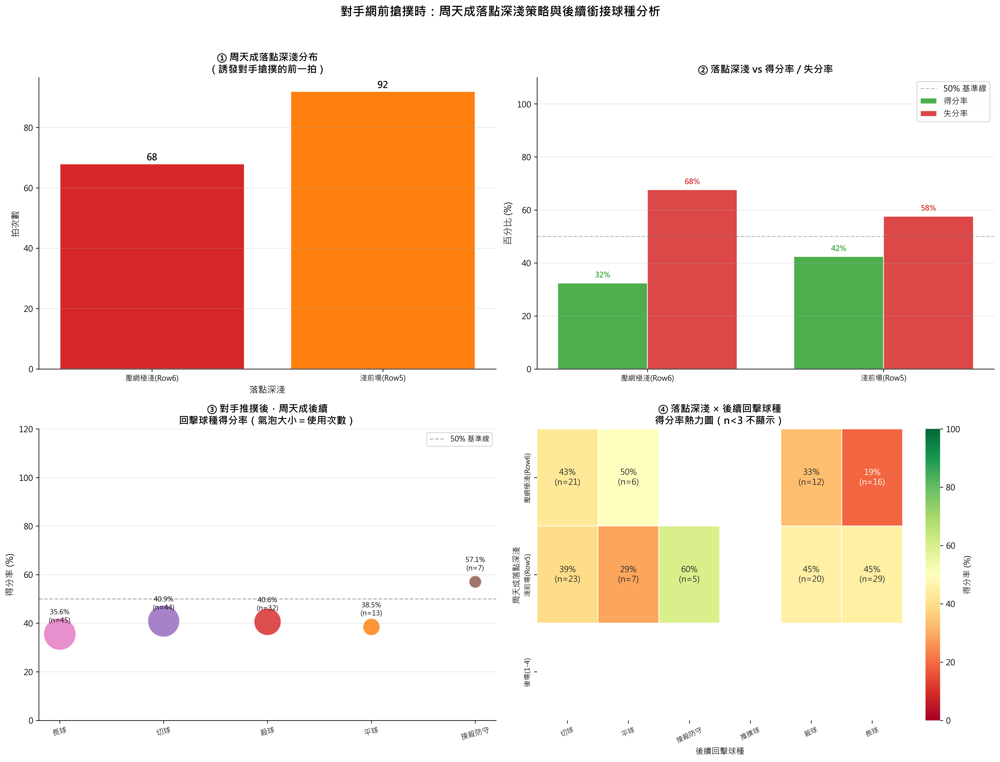

In [ ]:
import numpy as np

# ============================================================
# 分析：對手網前搶撲時，周天成網前落點策略與後續銜接球種
# ============================================================

CHOU = 'CHOU Tien Chen'
front_court_zones = list(range(17, 25))  # 前場區域 17-24

print(f"資料總筆數: {len(df)}")
print(f"總回合數: {df.groupby(['match_id', 'set', 'rally']).ngroups}")

# ============================================================
# Step 1: 在完整資料上建立 shift 欄位（避免跨回合污染）
# ============================================================
df_sorted = df.sort_values(['match_id', 'set', 'rally', 'ball_round']).copy()
grp = df_sorted.groupby(['match_id', 'set', 'rally'])

df_sorted['prev_player']       = grp['player'].shift(1)
df_sorted['prev_type']         = grp['type'].shift(1)
df_sorted['prev_landing_area'] = grp['landing_area'].shift(1)

df_sorted['next_player']       = grp['player'].shift(-1)
df_sorted['next_type']         = grp['type'].shift(-1)

# 回合得分者傳播至全回合每一拍
df_sorted['rally_getpoint'] = grp['getpoint_player'].transform('last')

# ============================================================
# Step 2: 篩選「對手在網前執行推撲球」的拍次
# ============================================================
mask_opp_rush = (
    (df_sorted['player'] != CHOU) &
    (df_sorted['type'] == '推撲球') &
    (df_sorted['hit_area'].isin(front_court_zones))
)
df_opp_rush = df_sorted[mask_opp_rush].copy()
print(f"\n對手網前搶撲（推撲球）拍次數: {len(df_opp_rush)}")
print(f"涉及回合數: {df_opp_rush.groupby(['match_id','set','rally']).ngroups}")

# ============================================================
# Step 3: 前一拍 = 周天成的來球（造成對手搶撲的那一拍）
# ============================================================
df_chou_prev = df_opp_rush[df_opp_rush['prev_player'] == CHOU].copy()
print(f"\n確認前一拍為周天成擊球的筆數: {len(df_chou_prev)}")
print(f"周天成前一拍球種分布:\n{df_chou_prev['prev_type'].value_counts()}")

# ============================================================
# Step 4: 定義落點深淺分類
# ============================================================
def classify_landing_depth(area):
    if area in [21, 22, 23, 24]:
        return '壓網極淺(Row6)'
    elif area in [17, 18, 19, 20]:
        return '淺前場(Row5)'
    elif area in [13, 14, 15, 16]:
        return '中前場(Row4)'
    elif area in [5, 6, 7, 8, 9, 10, 11, 12]:
        return '中場(5-12)'
    elif area in [1, 2, 3, 4]:
        return '後場(1-4)'
    else:
        return '出界/其他'

df_chou_prev['landing_depth'] = df_chou_prev['prev_landing_area'].apply(classify_landing_depth)

# ============================================================
# Step 5: 落點深淺 vs 得分/失分率
# ============================================================
df_chou_prev['chou_wins'] = (df_chou_prev['rally_getpoint'] == CHOU)
df_chou_prev['rally_decided'] = df_chou_prev['rally_getpoint'].notna()

depth_order = ['壓網極淺(Row6)', '淺前場(Row5)', '中前場(Row4)', '中場(5-12)', '後場(1-4)', '出界/其他']

depth_score = df_chou_prev.groupby('landing_depth').agg(
    拍次數=('prev_landing_area', 'count'),
    有結果回合=('rally_decided', 'sum'),
    周天成得分=('chou_wins', 'sum')
).reset_index()
depth_score['對手得分'] = depth_score['有結果回合'] - depth_score['周天成得分']
depth_score['得分率(%)'] = (depth_score['周天成得分'] / depth_score['有結果回合'] * 100).round(1)
depth_score['失分率(%)'] = (depth_score['對手得分'] / depth_score['有結果回合'] * 100).round(1)
# 依深淺排序
depth_score['sort_key'] = depth_score['landing_depth'].map(
    {k: i for i, k in enumerate(depth_order)}
)
depth_score = depth_score.sort_values('sort_key').reset_index(drop=True)

print("\n=== 落點深淺 vs 得分率 ===")
print(depth_score[['landing_depth','拍次數','有結果回合','周天成得分','對手得分','得分率(%)','失分率(%)']].to_string(index=False))

# ============================================================
# Step 6: 對手推撲後，周天成後續回擊球種分析
# ============================================================
df_chou_next = df_opp_rush[
    (df_opp_rush['next_player'] == CHOU) &
    (df_opp_rush['next_type'].notna())
].copy()
df_chou_next['landing_depth'] = df_chou_next['prev_landing_area'].apply(classify_landing_depth)
df_chou_next['chou_wins']     = (df_chou_next['rally_getpoint'] == CHOU)
df_chou_next['rally_decided'] = df_chou_next['rally_getpoint'].notna()

print(f"\n對手推撲後，周天成後續回擊拍次數: {len(df_chou_next)}")

next_shot_score = df_chou_next.groupby('next_type').agg(
    拍次數=('next_type', 'count'),
    有結果回合=('rally_decided', 'sum'),
    周天成得分=('chou_wins', 'sum')
).reset_index()
next_shot_score['對手得分']  = next_shot_score['有結果回合'] - next_shot_score['周天成得分']
next_shot_score['得分率(%)'] = (next_shot_score['周天成得分'] / next_shot_score['有結果回合'] * 100).round(1)
next_shot_score['失分率(%)'] = (next_shot_score['對手得分']  / next_shot_score['有結果回合'] * 100).round(1)
next_shot_score = next_shot_score.sort_values('拍次數', ascending=False).reset_index(drop=True)

print("\n=== 對手推撲後，周天成後續回擊球種 vs 得分/失分率 ===")
print(next_shot_score[['next_type','拍次數','有結果回合','周天成得分','對手得分','得分率(%)','失分率(%)']].to_string(index=False))

# ============================================================
# Step 7: 落點深淺 × 後續球種 交叉分析
# ============================================================
cross_tab = df_chou_next.groupby(['landing_depth', 'next_type']).agg(
    次數=('next_type', 'count'),
    得分=('chou_wins', 'sum'),
    有結果=('rally_decided', 'sum')
).reset_index()
cross_tab['得分率(%)'] = (cross_tab['得分'] / cross_tab['有結果'] * 100).round(1)

print("\n=== 落點深淺 × 後續回擊球種 交叉分析 ===")
print(cross_tab.to_string(index=False))

# ============================================================
# 視覺化
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
fig.suptitle('對手網前搶撲時：周天成落點深淺策略與後續銜接球種分析',
             fontsize=15, fontweight='bold', y=0.99)

# ---- 圖1: 落點深淺使用次數 ----
ax1 = axes[0, 0]
plot_depth = depth_score[depth_score['landing_depth'] != '出界/其他'].copy()
bar_colors = ['#d62728','#ff7f0e','#2ca02c','#1f77b4','#9467bd'][:len(plot_depth)]
bars = ax1.bar(plot_depth['landing_depth'], plot_depth['拍次數'],
               color=bar_colors, edgecolor='white', linewidth=1.3)
for bar, val in zip(bars, plot_depth['拍次數']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             str(int(val)), ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_title('① 周天成落點深淺分布\n（誘發對手搶撲的前一拍）', fontsize=12, fontweight='bold')
ax1.set_ylabel('拍次數', fontsize=11)
ax1.set_xlabel('落點深淺', fontsize=11)
ax1.tick_params(axis='x', labelsize=9)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ---- 圖2: 落點深淺 vs 得分率/失分率 ----
ax2 = axes[0, 1]
valid_depth = depth_score[
    (depth_score['landing_depth'] != '出界/其他') &
    (depth_score['有結果回合'] >= 3)
].copy()
x = np.arange(len(valid_depth))
width = 0.38
b_win  = ax2.bar(x - width/2, valid_depth['得分率(%)'], width, label='得分率', color='#2ca02c', alpha=0.85, edgecolor='white')
b_lose = ax2.bar(x + width/2, valid_depth['失分率(%)'], width, label='失分率', color='#d62728', alpha=0.85, edgecolor='white')
ax2.set_xticks(x)
ax2.set_xticklabels(valid_depth['landing_depth'], fontsize=9)
ax2.set_ylabel('百分比 (%)', fontsize=11)
ax2.set_title('② 落點深淺 vs 得分率 / 失分率', fontsize=12, fontweight='bold')
ax2.axhline(50, color='gray', linestyle='--', alpha=0.5, linewidth=1.2, label='50% 基準線')
ax2.set_ylim(0, 110)
ax2.legend(fontsize=10)
for bar in b_win:
    h = bar.get_height()
    if h > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, h + 1.5,
                 f'{h:.0f}%', ha='center', va='bottom', fontsize=9, color='#2ca02c', fontweight='bold')
for bar in b_lose:
    h = bar.get_height()
    if h > 0:
        ax2.text(bar.get_x() + bar.get_width()/2, h + 1.5,
                 f'{h:.0f}%', ha='center', va='bottom', fontsize=9, color='#d62728', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# ---- 圖3: 後續回擊球種 × 得分率（氣泡圖） ----
ax3 = axes[1, 0]
shot_palette = {
    '殺球': '#d62728', '挑球': '#1f77b4', '平球': '#ff7f0e',
    '網前球': '#2ca02c', '切球': '#9467bd', '接殺防守': '#8c564b',
    '長球': '#e377c2', '推撲球': '#7f7f7f', '發短球': '#bcbd22', '發長球': '#17becf'
}
valid_next = next_shot_score[next_shot_score['有結果回合'] >= 3].copy()
for _, row in valid_next.iterrows():
    color = shot_palette.get(row['next_type'], '#aec7e8')
    ax3.scatter(row['next_type'], row['得分率(%)'],
                s=row['拍次數'] * 35, c=color, alpha=0.82,
                edgecolors='white', linewidth=1.5, zorder=3)
    ax3.text(row['next_type'], row['得分率(%)'] + 4,
             f"{row['得分率(%)']}%\n(n={int(row['拍次數'])})",
             ha='center', va='bottom', fontsize=8.5)
ax3.axhline(50, color='gray', linestyle='--', alpha=0.6, linewidth=1.2, label='50% 基準線')
ax3.set_ylabel('得分率 (%)', fontsize=11)
ax3.set_title('③ 對手推撲後，周天成後續\n回擊球種得分率（氣泡大小＝使用次數）', fontsize=12, fontweight='bold')
ax3.set_ylim(0, 120)
ax3.legend(fontsize=9)
ax3.tick_params(axis='x', labelsize=9, rotation=15)
ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# ---- 圖4: 落點深淺 × 後續球種 得分率熱力圖 ----
ax4 = axes[1, 1]
# 建立 pivot
cross_pivot_rate  = cross_tab.pivot_table(index='landing_depth', columns='next_type',
                                           values='得分率(%)', fill_value=np.nan)
cross_pivot_count = cross_tab.pivot_table(index='landing_depth', columns='next_type',
                                           values='次數', fill_value=0)
cross_pivot_valid = cross_tab.pivot_table(index='landing_depth', columns='next_type',
                                           values='有結果', fill_value=0)

# 次數 < 3 設為 NaN
mask_insuf = cross_pivot_valid < 3
cross_pivot_rate_masked = cross_pivot_rate.copy()
cross_pivot_rate_masked[mask_insuf] = np.nan

# 按深淺順序排列 index
valid_idx = [d for d in depth_order if d in cross_pivot_rate_masked.index]
cross_pivot_rate_masked = cross_pivot_rate_masked.reindex(valid_idx)
cross_pivot_count_reindex = cross_pivot_count.reindex(valid_idx)

if len(cross_pivot_rate_masked) > 0 and len(cross_pivot_rate_masked.columns) > 0:
    # 建立 annotation
    annot = cross_pivot_rate_masked.copy().astype(object)
    for r in cross_pivot_rate_masked.index:
        for c in cross_pivot_rate_masked.columns:
            val = cross_pivot_rate_masked.loc[r, c]
            cnt = int(cross_pivot_count_reindex.loc[r, c]) if r in cross_pivot_count_reindex.index else 0
            annot.loc[r, c] = f'{val:.0f}%\n(n={cnt})' if not np.isnan(val) else ''

    hm_mask = cross_pivot_rate_masked.isna()
    sns.heatmap(cross_pivot_rate_masked,
                annot=annot, fmt='',
                cmap='RdYlGn', vmin=0, vmax=100,
                linewidths=0.5, linecolor='white',
                ax=ax4,
                cbar_kws={'label': '得分率 (%)'},
                mask=hm_mask)
    ax4.set_title('④ 落點深淺 × 後續回擊球種\n得分率熱力圖（n<3 不顯示）', fontsize=12, fontweight='bold')
    ax4.set_xlabel('後續回擊球種', fontsize=10)
    ax4.set_ylabel('周天成落點深淺', fontsize=10)
    ax4.tick_params(axis='x', labelsize=8.5, rotation=25)
    ax4.tick_params(axis='y', labelsize=8.5)

plt.tight_layout(rect=[0, 0, 1, 0.97])

# ============================================================
# 補充統計：對手搶撲回合整體得分率
# ============================================================
print("\n" + "="*60)
print("=== 補充：對手搶撲回合整體結果 ===")
print("="*60)
rush_rally = df_chou_prev.drop_duplicates(['match_id','set','rally']).copy()
rush_rally['結果'] = rush_rally['rally_getpoint'].apply(
    lambda x: '周天成得分' if x == CHOU else ('對手得分' if pd.notna(x) else '未記錄')
)
result_counts = rush_rally['結果'].value_counts()
print(result_counts)
total_decided = result_counts.get('周天成得分', 0) + result_counts.get('對手得分', 0)
if total_decided > 0:
    chou_win_pct = result_counts.get('周天成得分', 0) / total_decided * 100
    print(f"\n對手搶撲回合中，周天成整體得分率: {chou_win_pct:.1f}%")

print("\n對手推撲後，周天成最常用回擊球種 TOP5：")
print(next_shot_score.head(5)[['next_type','拍次數','得分率(%)','失分率(%)']].to_string(index=False))

print("\n=== 策略摘要說明 ===")
print("▸ 圖①②：分析哪種落點深淺最常誘發對手搶撲，以及對應的得失分率。")
print("▸ 圖③  ：對手推撲後，周天成以哪種球種回擊最有效（得分率高）。")
print("▸ 圖④  ：交叉分析不同落點深淺配上不同回擊球種的得分率（顏色越綠越佳）。")


### 數據洞察
# 戰術洞察：對手網前搶撲情境分析

---

## 📊 核心數據概覽

> 對手搶撲回合共 129 場，**周天成整體得分率僅 37.2%**，處於明顯劣勢。

---

## 一、落點深淺：誘發搶撲的前一拍

| 落點深淺 | 拍次數 | 得分率 | 失分率 |
|---|---|---|---|
| 壓網極淺 (Row 6) | 68 | 32.4% | **67.6%** |
| 淺前場 (Row 5) | 92 | 42.4% | 57.6% |

**事實：** 球打越淺（Row 6），對手搶撲後周天成失分率越高。Row 5 比 Row 6 的得分率高出整整 **10 個百分點**。

---

## 二、對手推撲後，周天成後續回擊效益

| 回擊球種 | 使用次數 | 得分率 |
|---|---|---|
| 接殺防守 | 7 | **57.1%** ✅ |
| 切球 | 44 | 40.9% |
| 殺球 | 32 | 40.6% |
| 平球 | 13 | 38.5% |
| 長球 | 45 | 35.6% ❌ |

**事實：** 接殺防守得分率最高（57.1%），但使用僅 7 次。長球使用最多（45次）卻得分率最低（35.6%），是最常用但最無效的選擇。

---

## 三、落點深淺 × 後續回擊交叉分析（關鍵）

| 落點 | 回擊球種 | 次數 | 得分率 |
|---|---|---|---|
| 壓網極淺 (Row 6) | 長球 | 16 | **18.8%** 🔴 |
| 壓網極淺 (Row 6) | 殺球 | 12 | 33.3% |
| 壓網極淺 (Row 6) | 切球 | 21 | 42.9% ✅ |
| 淺前場 (Row 5) | 接殺防守 | 5 | **60.0%** ✅ |
| 淺前場 (Row 5) | 殺球 | 20 | 45.0% |
| 淺前場 (Row 5) | 長球 | 29 | 44.8% |
| 淺前場 (Row 5) | 切球 | 23 | 39.1% |

**事實：** Row 6 落點後接長球，得分率僅 18.8%，是所有組合中最差的。Row 5 落點後的整體回擊效益明顯優於 Row 6。

---

## 🎯 戰術建議

### 1️⃣ 落點控制：避免壓網極淺
- **停止刻意壓 Row 6**。數據顯示 Row 6 誘發搶撲後，各項回擊得分率均低於 Row 5。
- 將網前落點控制在 **Row 5（區域 17–20）**，給自己更多緩衝時間準備後續回擊。

### 2️⃣ 後續銜接：減少長球，增加切球與接殺防守
- **長球是最常用卻最無效的選擇**，尤其在 Row 6 落點後（18.8%），應大幅減少。
- **切球**在 Row 6 後得分率 42.9%，是壓網情境下相對最穩的選擇。
- **接殺防守**（Row 5 後 60.0%）雖樣本小，但顯示被動防守後轉守為攻的潛力，值得刻意訓練。

### 3️⃣ 整體心態調整
- 對手搶撲後，周天成慣性挑長球（45次），但這正中對手下懷。
- **改變預設反應**：對手搶撲 → 優先考慮切球或接殺防守，而非反射性挑長球。

---
### 🤖 AI 裁判評分報告

#### 💻 程式碼評核: ✅ 正確
> **分析意見**: 候選程式碼符合 Reference Code 1 的核心邏輯。兩者都分析了對手在網前搶撲時，周天成的網前落點策略與後續銜接球種。候選程式碼正確地篩選了對手在網前執行推撲球的拍次，並分析了周天成在這些情況下的前一拍落點深淺和後續回擊球種。統計口徑和分析單位也與 Reference Code 1 一致，並且提供了合理的結果和視覺化。


